In [286]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())
else:
    print("No GPU detected.")

PyTorch Version: 2.10.0+cu128
CUDA Available: True
GPU Name: Tesla T4
Number of GPUs: 2


In [287]:
!nvidia-smi

Sun Sep  6 14:57:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [288]:
# Step 0.3 — Reproducibility Configuration

import os
import random
import numpy as np
import torch

SEED = 42

# Reproducibility settings
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

torch.use_deterministic_algorithms(
    True,
    warn_only=True
)

print("Reproducibility configuration applied.")
print("Seed:", SEED)

Reproducibility configuration applied.
Seed: 42


In [289]:
import os

INPUT_DIR = "/kaggle/input/datasets/marakibsarker/banglamuse"

print("Available Kaggle datasets:\n")

for item in os.listdir(INPUT_DIR):
    print("•", item)

Available Kaggle datasets:

• Voice_folder
• Text_folder.xlsx


In [290]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    level = dirname.replace('/kaggle/input', '').count(os.sep)
    indent = '    ' * level
    
    print(f"{indent}{os.path.basename(dirname)}/")
    
    for filename in filenames[:10]:
        print(f"{indent}    {filename}")
    
    if len(filenames) > 10:
        print(f"{indent}    ... ({len(filenames)} files total)")

input/
    datasets/
        marakibsarker/
            banglamuse/
                Text_folder.xlsx
                Voice_folder/
                    f2_voice_folder/
                        0589_f2.mp3
                        0960_f2.mp3
                        0188_f2.mp3
                        0333_f2.mp3
                        0228_f2.mp3
                        0715_f2.mp3
                        0250_f2.mp3
                        0935_f2.mp3
                        0335_f2.mp3
                        0267_f2.mp3
                        ... (1000 files total)
                    f1_voice_folder/
                        0760_f1.mp3
                        0918_f1.mp3
                        0206_f1.mp3
                        0334_f1.mp3
                        0480_f1.mp3
                        0098_f1.mp3
                        0385_f1.mp3
                        0168_f1.mp3
                        0546_f1.mp3
                        0188_f1.mp3
                        ... 

In [291]:
from collections import Counter
from pathlib import Path

extension_counts = Counter()

for path in Path("/kaggle/input").rglob("*"):
    if path.is_file():
        extension = path.suffix.lower()
        extension_counts[extension] += 1

print("File types found:\n")

for extension, count in extension_counts.most_common():
    print(f"{extension or '[no extension]'}: {count}")

File types found:

.mp3: 4733
.ogg: 2
.xlsx: 1


In [292]:
from pathlib import Path

tabular_files = []

for path in Path("/kaggle/input").rglob("*"):
    if path.suffix.lower() in [".csv", ".xlsx", ".xls"]:
        tabular_files.append(path)

print("CSV / Excel files found:\n")

for path in tabular_files:
    print(path)

CSV / Excel files found:

/kaggle/input/datasets/marakibsarker/banglamuse/Text_folder.xlsx


In [293]:
from pathlib import Path

audio_extensions = [".mp3", ".wav", ".flac", ".m4a", ".ogg"]

audio_files = [
    path
    for path in Path("/kaggle/input").rglob("*")
    if path.suffix.lower() in audio_extensions
]

print("Total audio files found:", len(audio_files))

print("\nFirst 10 audio files:")
for path in audio_files[:10]:
    print(path)

Total audio files found: 4735

First 10 audio files:
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0589_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0960_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0188_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0333_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0228_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0715_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0250_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0935_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0335_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0267_f2.mp3


In [294]:
import torch
import pandas as pd
import numpy as np
import sklearn
import librosa
import matplotlib
import soundfile

print("Environment Check")
print("-" * 40)

print("PyTorch:     ", torch.__version__)
print("Pandas:      ", pd.__version__)
print("NumPy:       ", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Librosa:     ", librosa.__version__)
print("Matplotlib:  ", matplotlib.__version__)

print("-" * 40)
print("Environment ready.")

Environment Check
----------------------------------------
PyTorch:      2.10.0+cu128
Pandas:       2.3.3
NumPy:        2.0.2
Scikit-learn: 1.6.1
Librosa:      0.11.0
Matplotlib:   3.10.0
----------------------------------------
Environment ready.


In [295]:
import os

PROJECT_ROOT = "/kaggle/working/bangla_multimodal_thesis"

folders = [
    "processed_data",
    "embeddings",
    "models",
    "results",
    "figures"
]

os.makedirs(PROJECT_ROOT, exist_ok=True)

for folder in folders:
    os.makedirs(os.path.join(PROJECT_ROOT, folder), exist_ok=True)

print("Project folders created successfully!\n")

for folder in folders:
    print(os.path.join(PROJECT_ROOT, folder))

Project folders created successfully!

/kaggle/working/bangla_multimodal_thesis/processed_data
/kaggle/working/bangla_multimodal_thesis/embeddings
/kaggle/working/bangla_multimodal_thesis/models
/kaggle/working/bangla_multimodal_thesis/results
/kaggle/working/bangla_multimodal_thesis/figures


In [296]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

# Find the Excel text file
excel_files = list(INPUT_ROOT.rglob("Text_folder.xlsx"))

# Find the audio folder
voice_folders = [
    p for p in INPUT_ROOT.rglob("Voice_folder")
    if p.is_dir()
]

print("Excel file(s) found:")
for p in excel_files:
    print(" ->", p)

print("\nVoice folder(s) found:")
for p in voice_folders:
    print(" ->", p)

Excel file(s) found:
 -> /kaggle/input/datasets/marakibsarker/banglamuse/Text_folder.xlsx

Voice folder(s) found:
 -> /kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder


In [297]:
if len(excel_files) == 0:
    raise FileNotFoundError("Text_folder.xlsx was not found.")

if len(voice_folders) == 0:
    raise FileNotFoundError("Voice_folder was not found.")

TEXT_FILE = excel_files[0]
VOICE_DIR = voice_folders[0]
BANGLAMUSE_DIR = TEXT_FILE.parent

print("BanglaMUSE directory:")
print(BANGLAMUSE_DIR)

print("\nText file:")
print(TEXT_FILE)

print("\nVoice directory:")
print(VOICE_DIR)

BanglaMUSE directory:
/kaggle/input/datasets/marakibsarker/banglamuse

Text file:
/kaggle/input/datasets/marakibsarker/banglamuse/Text_folder.xlsx

Voice directory:
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder


In [298]:
audio_extensions = {".mp3", ".wav", ".flac", ".ogg", ".m4a"}

audio_files = [
    p for p in VOICE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in audio_extensions
]

print("Total audio files found:", len(audio_files))

print("\nFirst 10 audio files:")
for p in audio_files[:10]:
    print(p)

Total audio files found: 4735

First 10 audio files:
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0589_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0960_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0188_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0333_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0228_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0715_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0250_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0935_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0335_f2.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f2_voice_folder/0267_f2.mp3


In [299]:
print("Contents inside Voice_folder:\n")

for item in VOICE_DIR.iterdir():
    if item.is_dir():
        count = sum(
            1 for p in item.rglob("*")
            if p.is_file() and p.suffix.lower() in audio_extensions
        )
        print(f"Folder: {item.name}")
        print(f"Audio files: {count}")
        print("-" * 40)
    else:
        print("File:", item.name)

Contents inside Voice_folder:

Folder: f2_voice_folder
Audio files: 1000
----------------------------------------
Folder: f1_voice_folder
Audio files: 1000
----------------------------------------
Folder: m1_voice_folder
Audio files: 1735
----------------------------------------
Folder: m2_voice_folder
Audio files: 1000
----------------------------------------


In [300]:
import pandas as pd

text_df = pd.read_excel(TEXT_FILE)

print("Dataset shape:", text_df.shape)

print("\nColumn names:")
print(text_df.columns.tolist())

print("\nFirst 10 rows:")
display(text_df.head(10))

Dataset shape: (1000, 4)

Column names:
['sentence_id', 'text\t', 'sentiment ', 'Unnamed: 3']

First 10 rows:


,sentence_id,text\t,sentiment,Unnamed: 3
0,si_0001,\nসুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,NaN
1,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,NaN
2,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,NaN
3,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,NaN
4,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive,NaN
5,si_0006,অনুকূল পরিস্থিতি থাকলে কাজটা সহজে সম্পন্ন হবে।,Positive,NaN
6,si_0007,অনুপ্রেরণার ভঙ্গিতে মন পায় দীপ্ত স্বচ্ছতা।,Positive,NaN
7,si_0008,অনেক উৎসাহ ও উদ্দীপনা নিয়ে নানুবাড়ি যাচ্ছি।,Positive,NaN
8,si_0009,অন্তর্দীপের আলোয় পথচলা হয় অনুপ্রাণিত।,Positive,NaN
9,si_0010,"অভিনন্দন, তোমার সাফল্য সত্যিই অনুকরণীয়।",Positive,NaN


In [301]:
print("=" * 60)
print("BANGLAMUSE TEXT DATA SUMMARY")
print("=" * 60)

print("\nNumber of rows:", len(text_df))
print("Number of columns:", len(text_df.columns))

print("\nColumn names:")
for col in text_df.columns:
    print(" -", col)

print("\nMissing values:")
print(text_df.isnull().sum())

print("\nDuplicate rows:")
print(text_df.duplicated().sum())

print("\nData types:")
print(text_df.dtypes)

BANGLAMUSE TEXT DATA SUMMARY

Number of rows: 1000
Number of columns: 4

Column names:
 - sentence_id
 - text	
 - sentiment 
 - Unnamed: 3

Missing values:
sentence_id      0
text\t           0
sentiment        0
Unnamed: 3     992
dtype: int64

Duplicate rows:
0

Data types:
sentence_id    object
text\t         object
sentiment      object
Unnamed: 3     object
dtype: object


In [302]:
# Make a clean copy
df = text_df.copy()

# --------------------------------------------------
# 1. Clean column names
# --------------------------------------------------
df.columns = (
    df.columns
      .astype(str)
      .str.strip()          # removes spaces/tabs/newlines around column names
)

print("Column names after cleaning:")
print(df.columns.tolist())

Column names after cleaning:
['sentence_id', 'text', 'sentiment', 'Unnamed: 3']


In [303]:
# Remove automatically generated empty Excel columns
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

print("Dataset shape after removing empty columns:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head(10))

Dataset shape after removing empty columns: (1000, 3)
Columns: ['sentence_id', 'text', 'sentiment']


,sentence_id,text,sentiment
0,si_0001,\nসুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive
1,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive
2,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive
3,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive
4,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive
5,si_0006,অনুকূল পরিস্থিতি থাকলে কাজটা সহজে সম্পন্ন হবে।,Positive
6,si_0007,অনুপ্রেরণার ভঙ্গিতে মন পায় দীপ্ত স্বচ্ছতা।,Positive
7,si_0008,অনেক উৎসাহ ও উদ্দীপনা নিয়ে নানুবাড়ি যাচ্ছি।,Positive
8,si_0009,অন্তর্দীপের আলোয় পথচলা হয় অনুপ্রাণিত।,Positive
9,si_0010,"অভিনন্দন, তোমার সাফল্য সত্যিই অনুকরণীয়।",Positive


In [304]:
print("Sentiment distribution:")
print(df["sentiment"].value_counts())

print("\nPercentage distribution:")
print(
    df["sentiment"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
)

Sentiment distribution:
sentiment
Positive     500
Negative     500
Name: count, dtype: int64

Percentage distribution:
sentiment
Positive     50.0
Negative     50.0
Name: proportion, dtype: float64


In [305]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
sentence_id    0
text           0
sentiment      0
dtype: int64


In [306]:
print("Duplicate sentence IDs:")
print(df["sentence_id"].duplicated().sum())

print("\nDuplicate text samples:")
print(df["text"].duplicated().sum())

Duplicate sentence IDs:
0

Duplicate text samples:
0


In [307]:
print("First 10 IDs:")
print(df["sentence_id"].head(10).tolist())

print("\nLast 10 IDs:")
print(df["sentence_id"].tail(10).tolist())

First 10 IDs:
['si_0001', 'si_0002', 'si_0003', 'si_0004', 'si_0005', 'si_0006', 'si_0007', 'si_0008', 'si_0009', 'si_0010']

Last 10 IDs:
['si_0991', 'si_0992', 'si_0993', 'si_0994', 'si_0995', 'si_0996', 'si_0997', 'si_0998', 'si_0999', 'si_1000']


In [308]:
df["sentence_number"] = (
    df["sentence_id"]
      .str.extract(r"(\d+)", expand=False)
      .astype(int)
)

display(df.head())

print("\nSentence number range:")
print("Minimum:", df["sentence_number"].min())
print("Maximum:", df["sentence_number"].max())

,sentence_id,text,sentiment,sentence_number
0,si_0001,\nসুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1
1,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,2
2,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,3
3,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,4
4,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive,5



Sentence number range:
Minimum: 1
Maximum: 1000


In [309]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate sentence IDs:", df["sentence_id"].duplicated().sum())
print("Duplicate texts:", df["text"].duplicated().sum())

print("\nSentence number range:")
print(df["sentence_number"].min(), "to", df["sentence_number"].max())

display(df.head())

Shape: (1000, 4)

Columns: ['sentence_id', 'text', 'sentiment', 'sentence_number']

Sentiment distribution:
sentiment
Positive     500
Negative     500
Name: count, dtype: int64

Missing values:
sentence_id        0
text               0
sentiment          0
sentence_number    0
dtype: int64

Duplicate sentence IDs: 0
Duplicate texts: 0

Sentence number range:
1 to 1000


,sentence_id,text,sentiment,sentence_number
0,si_0001,\nসুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1
1,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,2
2,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,3
3,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,4
4,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive,5


In [310]:
df["text"] = df["text"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip()
df["sentence_id"] = df["sentence_id"].astype(str).str.strip()

display(df.head())

,sentence_id,text,sentiment,sentence_number
0,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1
1,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,2
2,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,3
3,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,4
4,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive,5


In [311]:
from pathlib import Path

print("VOICE DIRECTORY:")
print(VOICE_DIR)

print("\nContents inside Voice_folder:")
print("-" * 60)

for item in sorted(VOICE_DIR.iterdir()):
    if item.is_dir():
        print("FOLDER:", item.name)
    else:
        print("FILE:", item.name)

VOICE DIRECTORY:
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder

Contents inside Voice_folder:
------------------------------------------------------------
FOLDER: f1_voice_folder
FOLDER: f2_voice_folder
FOLDER: m1_voice_folder
FOLDER: m2_voice_folder


In [312]:
audio_extensions = {".mp3", ".wav", ".flac", ".ogg", ".m4a"}

print("AUDIO COUNT BY FOLDER")
print("=" * 60)

total_audio = 0

for folder in sorted(VOICE_DIR.iterdir()):
    if folder.is_dir():

        files = [
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in audio_extensions
        ]

        print(f"{folder.name}: {len(files)} audio files")
        total_audio += len(files)

print("-" * 60)
print("Total audio files:", total_audio)

AUDIO COUNT BY FOLDER
f1_voice_folder: 1000 audio files
f2_voice_folder: 1000 audio files
m1_voice_folder: 1735 audio files
m2_voice_folder: 1000 audio files
------------------------------------------------------------
Total audio files: 4735


In [313]:
print("SAMPLE AUDIO FILENAMES")
print("=" * 70)

for folder in sorted(VOICE_DIR.iterdir()):
    if folder.is_dir():

        files = sorted([
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in audio_extensions
        ])

        print(f"\nFolder: {folder.name}")
        print("-" * 40)

        print("First 5 files:")
        for p in files[:5]:
            print(" ", p.name)

        print("\nLast 5 files:")
        for p in files[-5:]:
            print(" ", p.name)

SAMPLE AUDIO FILENAMES

Folder: f1_voice_folder
----------------------------------------
First 5 files:
  0001_f1.mp3
  0002_f1.mp3
  0003_f1.mp3
  0004_f1.mp3
  0005_f1.mp3

Last 5 files:
  0996_f1.mp3
  0997_f1.mp3
  0998_f1.mp3
  0999_f1.mp3
  1000_f1.mp3

Folder: f2_voice_folder
----------------------------------------
First 5 files:
  0001_f2.mp3
  0002_f2.mp3
  0003_f2.mp3
  0004_f2.mp3
  0005_f2.mp3

Last 5 files:
  0996_f2.mp3
  0997_f2.mp3
  0998_f2.mp3
  0999_f2.mp3
  1000_f2.mp3

Folder: m1_voice_folder
----------------------------------------
First 5 files:
  0001_m1.mp3
  0002_m1.mp3
  0003_m1(1).mp3
  0003_m1.mp3
  0004_m1(1).mp3

Last 5 files:
  0996_m1.mp3
  0997_m1.mp3
  0998_m1.mp3
  0999_m1.mp3
  1000_m1.mp3

Folder: m2_voice_folder
----------------------------------------
First 5 files:
  0001_m2.mp3
  0002_m2.mp3
  0003_m2.mp3
  0004_m2.mp3
  0005_m2.mp3

Last 5 files:
  1000_m2.mp3
  590_m2.mp3
  591_m2.mp3
  810_m2.mp3
  895_m2.mp3


In [314]:
all_audio_files = sorted([
    p for p in VOICE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in audio_extensions
])

print("Total audio:", len(all_audio_files))

print("\nFirst 20 complete paths:")
for p in all_audio_files[:20]:
    print(p)

Total audio: 4735

First 20 complete paths:
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0001_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0002_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0003_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0004_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0005_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0006_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0007_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0008_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0009_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_voice_folder/0010_f1.mp3
/kaggle/input/datasets/marakibsarker/banglamuse/Voice_folder/f1_vo

In [315]:
import re

print("Filename pattern inspection")
print("=" * 60)

for p in all_audio_files[:20]:
    numbers = re.findall(r"\d+", p.stem)

    print(
        "Folder:", p.parent.name,
        "| Filename:", p.name,
        "| Numbers found:", numbers
    )

Filename pattern inspection
Folder: f1_voice_folder | Filename: 0001_f1.mp3 | Numbers found: ['0001', '1']
Folder: f1_voice_folder | Filename: 0002_f1.mp3 | Numbers found: ['0002', '1']
Folder: f1_voice_folder | Filename: 0003_f1.mp3 | Numbers found: ['0003', '1']
Folder: f1_voice_folder | Filename: 0004_f1.mp3 | Numbers found: ['0004', '1']
Folder: f1_voice_folder | Filename: 0005_f1.mp3 | Numbers found: ['0005', '1']
Folder: f1_voice_folder | Filename: 0006_f1.mp3 | Numbers found: ['0006', '1']
Folder: f1_voice_folder | Filename: 0007_f1.mp3 | Numbers found: ['0007', '1']
Folder: f1_voice_folder | Filename: 0008_f1.mp3 | Numbers found: ['0008', '1']
Folder: f1_voice_folder | Filename: 0009_f1.mp3 | Numbers found: ['0009', '1']
Folder: f1_voice_folder | Filename: 0010_f1.mp3 | Numbers found: ['0010', '1']
Folder: f1_voice_folder | Filename: 0011_f1.mp3 | Numbers found: ['0011', '1']
Folder: f1_voice_folder | Filename: 0012_f1.mp3 | Numbers found: ['0012', '1']
Folder: f1_voice_folder 

In [316]:
# Step 2G — Build an audio metadata table

import re
import pandas as pd
from pathlib import Path

speaker_folder_map = {
    "f1_voice_folder": "f1",
    "f2_voice_folder": "f2",
    "m1_voice_folder": "m1",
    "m2_voice_folder": "m2"
}

audio_records = []

for folder_name, speaker in speaker_folder_map.items():

    folder_path = VOICE_DIR / folder_name

    for path in folder_path.glob("*.mp3"):

        filename = path.name

        # Extract the first 4-digit sentence number
        match = re.match(r"^(\d{4})_", filename)

        if match:
            sentence_number = int(match.group(1))
        else:
            sentence_number = None

        # Detect files such as 0003_m1(1).mp3
        is_numbered_copy = bool(
            re.search(r"\(\d+\)", path.stem)
        )

        audio_records.append({
            "speaker": speaker,
            "folder": folder_name,
            "filename": filename,
            "audio_path": str(path),
            "sentence_number": sentence_number,
            "is_numbered_copy": is_numbered_copy
        })

audio_df = pd.DataFrame(audio_records)

print("Audio metadata shape:", audio_df.shape)

display(audio_df.head(10))

Audio metadata shape: (4733, 6)


,speaker,folder,filename,audio_path,sentence_number,is_numbered_copy
0,f1,f1_voice_folder,0760_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,760.0,False
1,f1,f1_voice_folder,0918_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,918.0,False
2,f1,f1_voice_folder,0206_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,206.0,False
3,f1,f1_voice_folder,0334_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,334.0,False
4,f1,f1_voice_folder,0480_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,480.0,False
5,f1,f1_voice_folder,0098_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,98.0,False
6,f1,f1_voice_folder,0385_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,385.0,False
7,f1,f1_voice_folder,0168_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,168.0,False
8,f1,f1_voice_folder,0546_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,546.0,False
9,f1,f1_voice_folder,0188_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,188.0,False


In [317]:
print("Files where sentence number could NOT be extracted:")
print(audio_df["sentence_number"].isna().sum())

if audio_df["sentence_number"].isna().sum() > 0:
    display(
        audio_df[
            audio_df["sentence_number"].isna()
        ]
    )

Files where sentence number could NOT be extracted:
5


,speaker,folder,filename,audio_path,sentence_number,is_numbered_copy
3257,m1,m1_voice_folder,00100_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,NaN,False
4038,m2,m2_voice_folder,590_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,NaN,False
4082,m2,m2_voice_folder,591_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,NaN,False
4087,m2,m2_voice_folder,810_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,NaN,False
4547,m2,m2_voice_folder,895_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,NaN,False


In [318]:
speaker_summary = (
    audio_df
    .groupby("speaker")
    .agg(
        total_files=("filename", "count"),
        unique_sentences=("sentence_number", "nunique"),
        numbered_copies=("is_numbered_copy", "sum")
    )
)

display(speaker_summary)

,total_files,unique_sentences,numbered_copies
speaker,,,
f1,998,998,0
f2,1000,1000,0
m1,1735,998,736
m2,1000,996,0


In [319]:
expected_ids = set(range(1, 1001))

for speaker in ["f1", "f2", "m1", "m2"]:

    actual_ids = set(
        audio_df.loc[
            audio_df["speaker"] == speaker,
            "sentence_number"
        ].dropna().astype(int)
    )

    missing = sorted(expected_ids - actual_ids)
    unexpected = sorted(actual_ids - expected_ids)

    print(f"\nSpeaker: {speaker}")
    print("Unique sentence IDs:", len(actual_ids))
    print("Missing IDs:", len(missing))
    print("Unexpected IDs:", len(unexpected))

    if missing:
        print("First missing IDs:", missing[:20])

    if unexpected:
        print("Unexpected IDs:", unexpected[:20])


Speaker: f1
Unique sentence IDs: 998
Missing IDs: 2
Unexpected IDs: 0
First missing IDs: [747, 859]

Speaker: f2
Unique sentence IDs: 1000
Missing IDs: 0
Unexpected IDs: 0

Speaker: m1
Unique sentence IDs: 998
Missing IDs: 2
Unexpected IDs: 0
First missing IDs: [174, 942]

Speaker: m2
Unique sentence IDs: 996
Missing IDs: 4
Unexpected IDs: 0
First missing IDs: [590, 591, 810, 895]


In [320]:
recording_counts = (
    audio_df
    .groupby(["speaker", "sentence_number"])
    .size()
    .reset_index(name="recording_count")
)

print("Distribution of recording counts per sentence:\n")

for speaker in ["f1", "f2", "m1", "m2"]:

    print(f"Speaker: {speaker}")

    counts = (
        recording_counts[
            recording_counts["speaker"] == speaker
        ]["recording_count"]
        .value_counts()
        .sort_index()
    )

    print(counts)
    print("-" * 40)

Distribution of recording counts per sentence:

Speaker: f1
recording_count
1    998
Name: count, dtype: int64
----------------------------------------
Speaker: f2
recording_count
1    1000
Name: count, dtype: int64
----------------------------------------
Speaker: m1
recording_count
1    701
2      1
3    200
4     49
5     47
Name: count, dtype: int64
----------------------------------------
Speaker: m2
recording_count
1    996
Name: count, dtype: int64
----------------------------------------


In [321]:
m1_duplicate_ids = recording_counts[
    (recording_counts["speaker"] == "m1") &
    (recording_counts["recording_count"] > 1)
]["sentence_number"].tolist()

print("Number of m1 sentence IDs with multiple files:",
      len(m1_duplicate_ids))

print("\nFirst 20 duplicate sentence IDs:")
print(m1_duplicate_ids[:20])

Number of m1 sentence IDs with multiple files: 297

First 20 duplicate sentence IDs:
[3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0]


In [322]:
sample_duplicate_ids = m1_duplicate_ids[:10]

display(
    audio_df[
        (audio_df["speaker"] == "m1") &
        (audio_df["sentence_number"].isin(sample_duplicate_ids))
    ]
    .sort_values(["sentence_number", "filename"])
)

,speaker,folder,filename,audio_path,sentence_number,is_numbered_copy
3006,m1,m1_voice_folder,0003_m1(1).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.0,True
2838,m1,m1_voice_folder,0003_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.0,False
2139,m1,m1_voice_folder,0004_m1(1).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,4.0,True
2164,m1,m1_voice_folder,0004_m1(2).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,4.0,True
2818,m1,m1_voice_folder,0004_m1(3).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,4.0,True
2940,m1,m1_voice_folder,0004_m1(4).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,4.0,True
2536,m1,m1_voice_folder,0004_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,4.0,False
2967,m1,m1_voice_folder,0005_m1(1).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,5.0,True
3481,m1,m1_voice_folder,0005_m1(2).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,5.0,True
2921,m1,m1_voice_folder,0005_m1(3).mp3,/kaggle/input/datasets/marakibsarker/banglamus...,5.0,True


In [323]:
m1_df = audio_df[audio_df["speaker"] == "m1"].copy()

m1_originals = m1_df[
    ~m1_df["is_numbered_copy"]
]

print("Total m1 files:", len(m1_df))
print("Original/non-numbered m1 files:", len(m1_originals))
print(
    "Unique sentence IDs among originals:",
    m1_originals["sentence_number"].nunique()
)

Total m1 files: 1735
Original/non-numbered m1 files: 999
Unique sentence IDs among originals: 998


In [324]:
sentence_number

219

In [325]:
print("Total m1 files:", len(m1_df))
print("Original/non-numbered m1 files:", len(m1_originals))
print(
    "Unique sentence IDs among originals:",
    m1_originals["sentence_number"].nunique()
)

Total m1 files: 1735
Original/non-numbered m1 files: 999
Unique sentence IDs among originals: 998


In [326]:
#Step 2N — Rebuild the metadata parser properly

import re
import pandas as pd
from pathlib import Path

speaker_folder_map = {
    "f1_voice_folder": "f1",
    "f2_voice_folder": "f2",
    "m1_voice_folder": "m1",
    "m2_voice_folder": "m2"
}

audio_extensions = {".mp3", ".wav", ".flac", ".ogg", ".m4a"}

audio_records = []

for folder_name, speaker in speaker_folder_map.items():
    
    folder_path = VOICE_DIR / folder_name

    # Use rglob and case-insensitive extension checking
    files = [
        p for p in folder_path.rglob("*")
        if p.is_file() and p.suffix.lower() in audio_extensions
    ]

    for path in files:
        
        filename = path.name
        stem = path.stem

        # Get everything before the first underscore
        # Examples:
        # 0001_f1 -> 0001
        # 590_m2  -> 590
        # 00100_m1 -> 00100
        first_part = stem.split("_")[0]

        if first_part.isdigit():
            sentence_number = int(first_part)
        else:
            sentence_number = None

        # Detect (1), (2), (3), etc.
        copy_match = re.search(r"\((\d+)\)", stem)

        if copy_match:
            copy_number = int(copy_match.group(1))
            is_numbered_copy = True
        else:
            copy_number = 0
            is_numbered_copy = False

        audio_records.append({
            "speaker": speaker,
            "folder": folder_name,
            "filename": filename,
            "extension": path.suffix,
            "audio_path": str(path),
            "sentence_number": sentence_number,
            "is_numbered_copy": is_numbered_copy,
            "copy_number": copy_number
        })

audio_df = pd.DataFrame(audio_records)

print("Total audio files:", len(audio_df))
display(audio_df.head())

Total audio files: 4735


,speaker,folder,filename,extension,audio_path,sentence_number,is_numbered_copy,copy_number
0,f1,f1_voice_folder,0760_f1.mp3,.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,760,False,0
1,f1,f1_voice_folder,0918_f1.mp3,.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,918,False,0
2,f1,f1_voice_folder,0206_f1.mp3,.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,206,False,0
3,f1,f1_voice_folder,0334_f1.mp3,.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,334,False,0
4,f1,f1_voice_folder,0480_f1.mp3,.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,480,False,0


In [327]:
# Step 2O — Check whether all filenames can now be parsed

print("Unparsed filenames:")
print(audio_df["sentence_number"].isna().sum())

if audio_df["sentence_number"].isna().sum() > 0:
    display(
        audio_df[
            audio_df["sentence_number"].isna()
        ][
            ["speaker", "filename", "extension", "audio_path"]
        ]
    )

Unparsed filenames:
0


In [328]:
invalid_ids = audio_df[
    (audio_df["sentence_number"] < 1) |
    (audio_df["sentence_number"] > 1000)
]

print("Files with sentence IDs outside 1–1000:",
      len(invalid_ids))

display(invalid_ids)

Files with sentence IDs outside 1–1000: 0


,speaker,folder,filename,extension,audio_path,sentence_number,is_numbered_copy,copy_number


In [329]:
coverage_summary = (
    audio_df
    .groupby("speaker")
    .agg(
        total_files=("filename", "count"),
        unique_sentence_ids=("sentence_number", "nunique"),
        numbered_copies=("is_numbered_copy", "sum")
    )
)

display(coverage_summary)

,total_files,unique_sentence_ids,numbered_copies
speaker,,,
f1,1000,1000,0
f2,1000,1000,0
m1,1735,998,736
m2,1000,1000,0


In [330]:
expected_ids = set(range(1, 1001))

for speaker in ["f1", "f2", "m1", "m2"]:
    
    speaker_ids = set(
        audio_df.loc[
            audio_df["speaker"] == speaker,
            "sentence_number"
        ]
        .dropna()
        .astype(int)
    )

    missing = sorted(expected_ids - speaker_ids)

    print(f"{speaker}:")
    print("  Unique IDs:", len(speaker_ids))
    print("  Missing IDs:", len(missing))
    
    if missing:
        print("  Missing:", missing)

f1:
  Unique IDs: 1000
  Missing IDs: 0
f2:
  Unique IDs: 1000
  Missing IDs: 0
m1:
  Unique IDs: 998
  Missing IDs: 2
  Missing: [174, 942]
m2:
  Unique IDs: 1000
  Missing IDs: 0


In [331]:
# Step 2R — Investigate the remaining missing IDs

for target_id in [174, 747, 859, 942]:
    
    print("\n" + "=" * 70)
    print("SEARCHING FOR POSSIBLE FILES RELATED TO ID:", target_id)
    print("=" * 70)

    target_str = str(target_id)

    matches = audio_df[
        audio_df["filename"]
        .str.contains(target_str, regex=False)
    ]

    if len(matches) > 0:
        display(
            matches[
                [
                    "speaker",
                    "filename",
                    "sentence_number",
                    "copy_number"
                ]
            ]
        )
    else:
        print("No obvious filename match found.")


SEARCHING FOR POSSIBLE FILES RELATED TO ID: 174


,speaker,filename,sentence_number,copy_number
208,f1,0174_f1.mp3,174,0
1842,f2,0174_f2.mp3,174,0
3867,m2,0174_m2.mp3,174,0



SEARCHING FOR POSSIBLE FILES RELATED TO ID: 747


,speaker,filename,sentence_number,copy_number
739,f1,0747_f1.ogg,747,0
1324,f2,0747_f2.mp3,747,0
2730,m1,0747_m1.mp3,747,0
4505,m2,0747_m2.mp3,747,0



SEARCHING FOR POSSIBLE FILES RELATED TO ID: 859


,speaker,filename,sentence_number,copy_number
148,f1,0859_f1.ogg,859,0
1689,f2,0859_f2.mp3,859,0
3211,m1,0859_m1.mp3,859,0
4660,m2,0859_m2.mp3,859,0



SEARCHING FOR POSSIBLE FILES RELATED TO ID: 942


,speaker,filename,sentence_number,copy_number
65,f1,0942_f1.mp3,942,0
1691,f2,0942_f2.mp3,942,0
3817,m2,0942_m2.mp3,942,0


In [332]:
f1_files = audio_df[
    audio_df["speaker"] == "f1"
]

print("f1 extension distribution:")
print(f1_files["extension"].value_counts(dropna=False))

print("\nFiles whose extension is not exactly '.mp3':")

display(
    f1_files[
        f1_files["extension"] != ".mp3"
    ][
        ["filename", "extension", "sentence_number"]
    ]
)

f1 extension distribution:
extension
.mp3    998
.ogg      2
Name: count, dtype: int64

Files whose extension is not exactly '.mp3':


,filename,extension,sentence_number
148,0859_f1.ogg,.ogg,859
739,0747_f1.ogg,.ogg,747


In [333]:
original_summary = (
    audio_df[
        audio_df["is_numbered_copy"] == False
    ]
    .groupby("speaker")
    .agg(
        original_files=("filename", "count"),
        unique_sentence_ids=("sentence_number", "nunique")
    )
)

display(original_summary)

,original_files,unique_sentence_ids
speaker,,
f1,1000,1000
f2,1000,1000
m1,999,998
m2,1000,1000


In [334]:
m1_all = audio_df[
    audio_df["speaker"] == "m1"
].copy()

m1_original = m1_all[
    m1_all["is_numbered_copy"] == False
].copy()

original_m1_ids = set(
    m1_original["sentence_number"]
    .dropna()
    .astype(int)
)

missing_original_m1 = sorted(
    expected_ids - original_m1_ids
)

print(
    "Number of sentence IDs without a normal m1 file:",
    len(missing_original_m1)
)

print("IDs:")
print(missing_original_m1)

Number of sentence IDs without a normal m1 file: 2
IDs:
[174, 942]


In [335]:
for sentence_id in missing_original_m1:
    
    print("\nSentence ID:", sentence_id)

    display(
        m1_all[
            m1_all["sentence_number"] == sentence_id
        ][
            [
                "filename",
                "is_numbered_copy",
                "copy_number",
                "audio_path"
            ]
        ]
    )


Sentence ID: 174


,filename,is_numbered_copy,copy_number,audio_path



Sentence ID: 942


,filename,is_numbered_copy,copy_number,audio_path


In [336]:
# Keep only m1 files that are NOT numbered copies such as (1), (2), etc.
m1_original = audio_df[
    (audio_df["speaker"] == "m1") &
    (audio_df["is_numbered_copy"] == False)
].copy()

# Count how many "original" files exist for each sentence ID
m1_original_counts = (
    m1_original
    .groupby("sentence_number")
    .size()
    .reset_index(name="original_file_count")
)

# Find sentence IDs having more than one apparent original file
duplicate_original_ids = m1_original_counts[
    m1_original_counts["original_file_count"] > 1
]

print("Sentence IDs with multiple non-numbered m1 files:")
display(duplicate_original_ids)

Sentence IDs with multiple non-numbered m1 files:


,sentence_number,original_file_count
99,100,2


In [337]:
duplicated_ids = duplicate_original_ids["sentence_number"].tolist()

for sid in duplicated_ids:
    print(f"\nSentence ID: {int(sid)}")

    display(
        m1_original[
            m1_original["sentence_number"] == sid
        ][
            [
                "filename",
                "extension",
                "audio_path"
            ]
        ]
    )


Sentence ID: 100


,filename,extension,audio_path
2894,0100_m1.mp3,.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
3259,00100_m1.mp3,.mp3,/kaggle/input/datasets/marakibsarker/banglamus...


In [338]:
import os

duplicate_details = m1_original[
    m1_original["sentence_number"].isin(duplicated_ids)
].copy()

duplicate_details["file_size_kb"] = (
    duplicate_details["audio_path"]
    .apply(lambda x: os.path.getsize(x) / 1024)
)

display(
    duplicate_details[
        [
            "sentence_number",
            "filename",
            "file_size_kb"
        ]
    ]
)

,sentence_number,filename,file_size_kb
2894,100,0100_m1.mp3,202.039062
3259,100,00100_m1.mp3,202.039062


In [339]:
import librosa

def get_audio_duration(path):
    return librosa.get_duration(path=path)

duplicate_details["duration_seconds"] = (
    duplicate_details["audio_path"]
    .apply(get_audio_duration)
)

display(
    duplicate_details[
        [
            "sentence_number",
            "filename",
            "file_size_kb",
            "duration_seconds"
        ]
    ]
)

,sentence_number,filename,file_size_kb,duration_seconds
2894,100,0100_m1.mp3,202.039062,5.176644
3259,100,00100_m1.mp3,202.039062,5.176644


In [340]:
import hashlib

def file_md5(path, chunk_size=8192):
    md5 = hashlib.md5()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            md5.update(chunk)

    return md5.hexdigest()


sentence_100_files = m1_original[
    m1_original["sentence_number"] == 100
].copy()

sentence_100_files["md5_hash"] = (
    sentence_100_files["audio_path"]
    .apply(file_md5)
)

display(
    sentence_100_files[
        [
            "filename",
            "audio_path",
            "md5_hash"
        ]
    ]
)

,filename,audio_path,md5_hash
2894,0100_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,db3bde1db9eb984bfca73a716a45054e
3259,00100_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,db3bde1db9eb984bfca73a716a45054e


In [341]:
print("Searching raw m1 filenames for possible malformed IDs...\n")

for keyword in ["174", "942"]:

    print("=" * 60)
    print("Searching:", keyword)

    matches = [
        p.name
        for p in (VOICE_DIR / "m1_voice_folder").rglob("*")
        if p.is_file() and keyword in p.name
    ]

    if matches:
        for filename in matches:
            print(filename)
    else:
        print("No matching filename found.")

Searching raw m1 filenames for possible malformed IDs...

Searching: 174
No matching filename found.
Searching: 942
No matching filename found.


In [342]:
clean_audio = audio_df.copy()

# ---------------------------------------------------------
# Step 1: Remove numbered alternate copies from m1
# Example:
# 0004_m1(1).mp3
# 0004_m1(2).mp3
# ---------------------------------------------------------

clean_audio = clean_audio[
    ~(
        (clean_audio["speaker"] == "m1") &
        (clean_audio["is_numbered_copy"] == True)
    )
].copy()

print("After excluding numbered m1 alternatives:")
print(clean_audio["speaker"].value_counts())

After excluding numbered m1 alternatives:
speaker
f1    1000
f2    1000
m2    1000
m1     999
Name: count, dtype: int64


In [343]:
def prefix_length(filename):
    """
    Returns the number of characters before the first underscore.

    Examples:
    0100_m1.mp3  -> 4
    00100_m1.mp3 -> 5
    590_m2.mp3   -> 3
    """
    return len(filename.split("_")[0])


clean_audio["prefix_length"] = (
    clean_audio["filename"]
    .apply(prefix_length)
)

In [344]:
clean_audio["canonical_priority"] = (
    clean_audio["prefix_length"] != 4
).astype(int)

In [345]:
clean_audio = (
    clean_audio
    .sort_values(
        by=[
            "speaker",
            "sentence_number",
            "canonical_priority",
            "filename"
        ]
    )
    .drop_duplicates(
        subset=["speaker", "sentence_number"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("After selecting one recording per speaker/sentence:\n")

print(clean_audio["speaker"].value_counts())

print(
    "\nDuplicate speaker-sentence pairs:",
    clean_audio.duplicated(
        subset=["speaker", "sentence_number"]
    ).sum()
)

After selecting one recording per speaker/sentence:

speaker
f1    1000
f2    1000
m2    1000
m1     998
Name: count, dtype: int64

Duplicate speaker-sentence pairs: 0


In [346]:
display(
    clean_audio[
        (clean_audio["speaker"] == "m1") &
        (clean_audio["sentence_number"] == 100)
    ][
        [
            "speaker",
            "sentence_number",
            "filename",
            "audio_path"
        ]
    ]
)

,speaker,sentence_number,filename,audio_path
2099,m1,100,0100_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...


In [347]:
speaker_count_per_sentence = (
    clean_audio
    .groupby("sentence_number")["speaker"]
    .nunique()
)

print("Distribution of number of speakers per sentence:")
print(
    speaker_count_per_sentence
    .value_counts()
    .sort_index()
)

Distribution of number of speakers per sentence:
speaker
3      2
4    998
Name: count, dtype: int64


In [348]:
incomplete_sentences = (
    speaker_count_per_sentence[
        speaker_count_per_sentence < 4
    ]
    .index
    .tolist()
)

print("Incomplete sentence IDs:")
print(incomplete_sentences)

Incomplete sentence IDs:
[174, 942]


In [349]:
complete_sentence_ids = (
    speaker_count_per_sentence[
        speaker_count_per_sentence == 4
    ]
    .index
)

balanced_audio_df = (
    clean_audio[
        clean_audio["sentence_number"]
        .isin(complete_sentence_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

print("Balanced audio dataset shape:",
      balanced_audio_df.shape)

print("\nSpeaker distribution:")
print(
    balanced_audio_df["speaker"]
    .value_counts()
    .sort_index()
)

print(
    "\nUnique sentences:",
    balanced_audio_df["sentence_number"].nunique()
)

Balanced audio dataset shape: (3992, 10)

Speaker distribution:
speaker
f1    998
f2    998
m1    998
m2    998
Name: count, dtype: int64

Unique sentences: 998


In [350]:
# Step 3G — Join audio with Bangla text and sentiment


master_df = balanced_audio_df.merge(
    df[
        [
            "sentence_number",
            "sentence_id",
            "text",
            "sentiment"
        ]
    ],
    on="sentence_number",
    how="left",
    validate="many_to_one"
)

# Arrange columns neatly
master_df = master_df[
    [
        "sentence_id",
        "sentence_number",
        "text",
        "sentiment",
        "speaker",
        "filename",
        "audio_path"
    ]
]

# Sort for readability
master_df = (
    master_df
    .sort_values(
        ["sentence_number", "speaker"]
    )
    .reset_index(drop=True)
)

display(master_df.head(12))

,sentence_id,sentence_number,text,sentiment,speaker,filename,audio_path
0,si_0001,1,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,f1,0001_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
1,si_0001,1,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,f2,0001_f2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
2,si_0001,1,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,m1,0001_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
3,si_0001,1,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,m2,0001_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
4,si_0002,2,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,f1,0002_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
5,si_0002,2,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,f2,0002_f2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
6,si_0002,2,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,m1,0002_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
7,si_0002,2,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,m2,0002_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
8,si_0003,3,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,f1,0003_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...
9,si_0003,3,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,f2,0003_f2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...


In [351]:
from pathlib import Path

print("=" * 70)
print("FINAL MULTIMODAL DATASET INTEGRITY CHECK")
print("=" * 70)

print("\n1. Dataset shape:")
print(master_df.shape)

print("\n2. Unique sentences:")
print(master_df["sentence_number"].nunique())

print("\n3. Speaker distribution:")
print(
    master_df["speaker"]
    .value_counts()
    .sort_index()
)

print("\n4. Sentiment distribution:")
print(
    master_df["sentiment"]
    .value_counts()
)

print("\n5. Unique sentences by sentiment:")
print(
    master_df[
        ["sentence_number", "sentiment"]
    ]
    .drop_duplicates()
    ["sentiment"]
    .value_counts()
)

print("\n6. Missing values:")
print(master_df.isnull().sum())

print("\n7. Duplicate speaker-sentence pairs:")
print(
    master_df
    .duplicated(
        subset=["speaker", "sentence_number"]
    )
    .sum()
)

print("\n8. Missing physical audio files:")
missing_audio = (
    ~master_df["audio_path"]
    .apply(lambda x: Path(x).exists())
)

print(missing_audio.sum())

print("\n9. Number of speakers per sentence:")
print(
    master_df
    .groupby("sentence_number")["speaker"]
    .nunique()
    .value_counts()
)

print("\n10. Removed incomplete sentence IDs:")
print(sorted(set(range(1,1001)) -
             set(master_df["sentence_number"])))

print("=" * 70)

FINAL MULTIMODAL DATASET INTEGRITY CHECK

1. Dataset shape:
(3992, 7)

2. Unique sentences:
998

3. Speaker distribution:
speaker
f1    998
f2    998
m1    998
m2    998
Name: count, dtype: int64

4. Sentiment distribution:
sentiment
Positive    1996
Negative    1996
Name: count, dtype: int64

5. Unique sentences by sentiment:
sentiment
Positive    499
Negative    499
Name: count, dtype: int64

6. Missing values:
sentence_id        0
sentence_number    0
text               0
sentiment          0
speaker            0
filename           0
audio_path         0
dtype: int64

7. Duplicate speaker-sentence pairs:
0

8. Missing physical audio files:
0

9. Number of speakers per sentence:
speaker
4    998
Name: count, dtype: int64

10. Removed incomplete sentence IDs:
[174, 942]


In [352]:
label_map = {
    "Negative": 0,
    "Positive": 1
}

master_df["label"] = (
    master_df["sentiment"]
    .map(label_map)
)

print(master_df["label"].value_counts())

display(
    master_df[
        [
            "sentence_id",
            "text",
            "sentiment",
            "label",
            "speaker"
        ]
    ].head(10)
)

label
1    1996
0    1996
Name: count, dtype: int64


,sentence_id,text,sentiment,label,speaker
0,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1,f1
1,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1,f2
2,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1,m1
3,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1,m2
4,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,1,f1
5,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,1,f2
6,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,1,m1
7,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,1,m2
8,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,1,f1
9,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,1,f2


In [353]:
from pathlib import Path

PROCESSED_DIR = Path(
    "/kaggle/working/bangla_multimodal_thesis/processed_data"
)

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MASTER_PATH = (
    PROCESSED_DIR /
    "banglamuse_clean_master_3992.csv"
)

master_df.to_csv(
    MASTER_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved master dataset:")
print(MASTER_PATH)

print(
    "\nFile exists:",
    MASTER_PATH.exists()
)

print(
    "File size:",
    round(MASTER_PATH.stat().st_size / 1024, 2),
    "KB"
)

Saved master dataset:
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_clean_master_3992.csv

File exists: True
File size: 903.71 KB


**Step 4 — Leakage-Free Train / Validation / Test Split**

In [354]:
sentence_df = (
    master_df[
        [
            "sentence_number",
            "sentence_id",
            "sentiment",
            "label"
        ]
    ]
    .drop_duplicates(subset=["sentence_number"])
    .sort_values("sentence_number")
    .reset_index(drop=True)
)

print("Sentence-level dataset shape:", sentence_df.shape)

print("\nSentiment distribution:")
print(sentence_df["sentiment"].value_counts())

display(sentence_df.head())

Sentence-level dataset shape: (998, 4)

Sentiment distribution:
sentiment
Positive    499
Negative    499
Name: count, dtype: int64


,sentence_number,sentence_id,sentiment,label
0,1,si_0001,Positive,1
1,2,si_0002,Positive,1
2,3,si_0003,Positive,1
3,4,si_0004,Positive,1
4,5,si_0005,Positive,1


In [355]:
from sklearn.model_selection import train_test_split

In [356]:
RANDOM_STATE = 42

train_sentences, temp_sentences = train_test_split(
    sentence_df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=sentence_df["label"]
)

print("Training sentences:", len(train_sentences))
print("Temporary sentences:", len(temp_sentences))

Training sentences: 798
Temporary sentences: 200


In [357]:
val_sentences, test_sentences = train_test_split(
    temp_sentences,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_sentences["label"]
)

print("Train:", len(train_sentences))
print("Validation:", len(val_sentences))
print("Test:", len(test_sentences))

Train: 798
Validation: 100
Test: 100


In [358]:
def show_sentence_distribution(name, dataframe):
    print(f"\n{name}")
    print("-" * 40)

    print("Number of sentences:", len(dataframe))

    print("\nSentiment counts:")
    print(
        dataframe["sentiment"]
        .value_counts()
    )

    print("\nSentiment percentage:")
    print(
        dataframe["sentiment"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


show_sentence_distribution(
    "TRAIN",
    train_sentences
)

show_sentence_distribution(
    "VALIDATION",
    val_sentences
)

show_sentence_distribution(
    "TEST",
    test_sentences
)


TRAIN
----------------------------------------
Number of sentences: 798

Sentiment counts:
sentiment
Positive    399
Negative    399
Name: count, dtype: int64

Sentiment percentage:
sentiment
Positive    50.0
Negative    50.0
Name: proportion, dtype: float64

VALIDATION
----------------------------------------
Number of sentences: 100

Sentiment counts:
sentiment
Negative    50
Positive    50
Name: count, dtype: int64

Sentiment percentage:
sentiment
Negative    50.0
Positive    50.0
Name: proportion, dtype: float64

TEST
----------------------------------------
Number of sentences: 100

Sentiment counts:
sentiment
Positive    50
Negative    50
Name: count, dtype: int64

Sentiment percentage:
sentiment
Positive    50.0
Negative    50.0
Name: proportion, dtype: float64


In [359]:
train_ids = set(
    train_sentences["sentence_number"]
)

val_ids = set(
    val_sentences["sentence_number"]
)

test_ids = set(
    test_sentences["sentence_number"]
)


train_val_overlap = train_ids.intersection(val_ids)
train_test_overlap = train_ids.intersection(test_ids)
val_test_overlap = val_ids.intersection(test_ids)


print(
    "Train ↔ Validation overlap:",
    len(train_val_overlap)
)

print(
    "Train ↔ Test overlap:",
    len(train_test_overlap)
)

print(
    "Validation ↔ Test overlap:",
    len(val_test_overlap)
)

Train ↔ Validation overlap: 0
Train ↔ Test overlap: 0
Validation ↔ Test overlap: 0


In [360]:
split_map = {}

for sid in train_ids:
    split_map[sid] = "train"

for sid in val_ids:
    split_map[sid] = "validation"

for sid in test_ids:
    split_map[sid] = "test"


master_df["split"] = (
    master_df["sentence_number"]
    .map(split_map)
)

print(master_df["split"].value_counts())

split
train         3192
test           400
validation     400
Name: count, dtype: int64


In [361]:
train_df = (
    master_df[
        master_df["split"] == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    master_df[
        master_df["split"] == "validation"
    ]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    master_df[
        master_df["split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)


print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (3192, 9)
Validation shape: (400, 9)
Test shape: (400, 9)


In [362]:
for split_name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print("\n" + "=" * 50)
    print(split_name)
    print("=" * 50)

    print(
        split_df["speaker"]
        .value_counts()
        .sort_index()
    )


TRAIN
speaker
f1    798
f2    798
m1    798
m2    798
Name: count, dtype: int64

VALIDATION
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64

TEST
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64


In [363]:
for split_name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print("\n" + "=" * 50)
    print(split_name)
    print("=" * 50)

    print(
        split_df["sentiment"]
        .value_counts()
    )


TRAIN
sentiment
Positive    1596
Negative    1596
Name: count, dtype: int64

VALIDATION
sentiment
Positive    200
Negative    200
Name: count, dtype: int64

TEST
sentiment
Positive    200
Negative    200
Name: count, dtype: int64


In [364]:
# Step 4J — Final leakage audit

print("=" * 70)
print("LEAKAGE-FREE SPLIT INTEGRITY CHECK")
print("=" * 70)

print("\n1. Multimodal rows:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print(
    "Total:",
    len(train_df) + len(val_df) + len(test_df)
)

print("\n2. Unique sentences:")
print(
    "Train:",
    train_df["sentence_number"].nunique()
)
print(
    "Validation:",
    val_df["sentence_number"].nunique()
)
print(
    "Test:",
    test_df["sentence_number"].nunique()
)

print("\n3. Sentence overlap:")
print(
    "Train ↔ Validation:",
    len(train_ids & val_ids)
)
print(
    "Train ↔ Test:",
    len(train_ids & test_ids)
)
print(
    "Validation ↔ Test:",
    len(val_ids & test_ids)
)

print("\n4. Sentiment distribution:")

for name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{name}:")
    print(
        split_df["sentiment"]
        .value_counts()
    )

print("\n5. Speaker distribution:")

for name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{name}:")
    print(
        split_df["speaker"]
        .value_counts()
        .sort_index()
    )

print("\n6. Missing split labels:")
print(master_df["split"].isnull().sum())

print("\n7. Total rows preserved:")
print(len(master_df) == 3992)

print("=" * 70)

LEAKAGE-FREE SPLIT INTEGRITY CHECK

1. Multimodal rows:
Train: 3192
Validation: 400
Test: 400
Total: 3992

2. Unique sentences:
Train: 798
Validation: 100
Test: 100

3. Sentence overlap:
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

4. Sentiment distribution:

Train:
sentiment
Positive    1596
Negative    1596
Name: count, dtype: int64

Validation:
sentiment
Positive    200
Negative    200
Name: count, dtype: int64

Test:
sentiment
Positive    200
Negative    200
Name: count, dtype: int64

5. Speaker distribution:

Train:
speaker
f1    798
f2    798
m1    798
m2    798
Name: count, dtype: int64

Validation:
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64

Test:
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64

6. Missing split labels:
0

7. Total rows preserved:
True


In [365]:
SPLIT_MASTER_PATH = (
    PROCESSED_DIR /
    "banglamuse_master_with_splits.csv"
)

TRAIN_PATH = (
    PROCESSED_DIR /
    "banglamuse_train.csv"
)

VAL_PATH = (
    PROCESSED_DIR /
    "banglamuse_validation.csv"
)

TEST_PATH = (
    PROCESSED_DIR /
    "banglamuse_test.csv"
)


master_df.to_csv(
    SPLIT_MASTER_PATH,
    index=False,
    encoding="utf-8-sig"
)

train_df.to_csv(
    TRAIN_PATH,
    index=False,
    encoding="utf-8-sig"
)

val_df.to_csv(
    VAL_PATH,
    index=False,
    encoding="utf-8-sig"
)

test_df.to_csv(
    TEST_PATH,
    index=False,
    encoding="utf-8-sig"
)


print("Saved:")
print(SPLIT_MASTER_PATH)
print(TRAIN_PATH)
print(VAL_PATH)
print(TEST_PATH)

Saved:
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_master_with_splits.csv
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_train.csv
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_validation.csv
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_test.csv


**Step 5 — Exploratory Data Analysis (EDA)**

In [366]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display

FIGURE_DIR = Path(
    "/kaggle/working/bangla_multimodal_thesis/figures"
)

RESULT_DIR = Path(
    "/kaggle/working/bangla_multimodal_thesis/results"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURE_DIR)
print("Result directory:", RESULT_DIR)

Figure directory: /kaggle/working/bangla_multimodal_thesis/figures
Result directory: /kaggle/working/bangla_multimodal_thesis/results


In [367]:
text_eda_df = (
    master_df[
        [
            "sentence_number",
            "sentence_id",
            "text",
            "sentiment",
            "label",
            "split"
        ]
    ]
    .drop_duplicates(subset=["sentence_number"])
    .reset_index(drop=True)
)

print("Unique sentence dataset shape:", text_eda_df.shape)

display(text_eda_df.head())

Unique sentence dataset shape: (998, 6)


,sentence_number,sentence_id,text,sentiment,label,split
0,1,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1,train
1,2,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,1,train
2,3,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,1,train
3,4,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,1,test
4,5,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive,1,train


In [368]:
text_eda_df["word_count"] = (
    text_eda_df["text"]
    .astype(str)
    .str.split()
    .str.len()
)

text_eda_df["character_count"] = (
    text_eda_df["text"]
    .astype(str)
    .str.len()
)

display(
    text_eda_df[
        [
            "sentence_id",
            "text",
            "sentiment",
            "word_count",
            "character_count"
        ]
    ].head(10)
)

,sentence_id,text,sentiment,word_count,character_count
0,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,7,42
1,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,6,34
2,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,7,43
3,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,6,42
4,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive,6,43
5,si_0006,অনুকূল পরিস্থিতি থাকলে কাজটা সহজে সম্পন্ন হবে।,Positive,7,46
6,si_0007,অনুপ্রেরণার ভঙ্গিতে মন পায় দীপ্ত স্বচ্ছতা।,Positive,6,42
7,si_0008,অনেক উৎসাহ ও উদ্দীপনা নিয়ে নানুবাড়ি যাচ্ছি।,Positive,7,45
8,si_0009,অন্তর্দীপের আলোয় পথচলা হয় অনুপ্রাণিত।,Positive,5,37
9,si_0010,"অভিনন্দন, তোমার সাফল্য সত্যিই অনুকরণীয়।",Positive,5,40


In [369]:
print("=" * 65)
print("TEXT DATASET DESCRIPTIVE STATISTICS")
print("=" * 65)

print("\nTotal unique sentences:")
print(len(text_eda_df))

print("\nSentiment distribution:")
print(text_eda_df["sentiment"].value_counts())

print("\nWord-count statistics:")
print(
    text_eda_df["word_count"]
    .describe()
    .round(2)
)

print("\nCharacter-count statistics:")
print(
    text_eda_df["character_count"]
    .describe()
    .round(2)
)

print("\nWord count by sentiment:")
print(
    text_eda_df
    .groupby("sentiment")["word_count"]
    .agg(
        ["count", "mean", "std", "min", "median", "max"]
    )
    .round(2)
)

TEXT DATASET DESCRIPTIVE STATISTICS

Total unique sentences:
998

Sentiment distribution:
sentiment
Positive    499
Negative    499
Name: count, dtype: int64

Word-count statistics:
count    998.00
mean       6.25
std        1.06
min        4.00
25%        6.00
50%        6.00
75%        7.00
max       12.00
Name: word_count, dtype: float64

Character-count statistics:
count    998.00
mean      38.14
std        6.89
min       22.00
25%       34.00
50%       37.00
75%       41.00
max       79.00
Name: character_count, dtype: float64

Word count by sentiment:
           count  mean   std  min  median  max
sentiment                                     
Negative     499  6.10  1.11    4     6.0   12
Positive     499  6.39  0.98    4     6.0   11


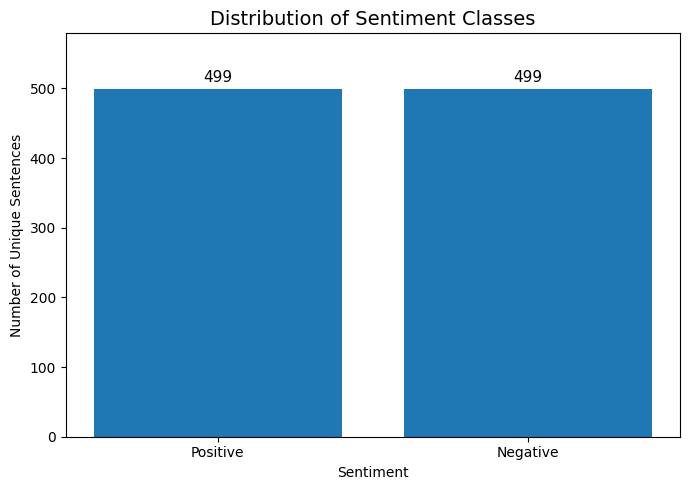

Saved: /kaggle/working/bangla_multimodal_thesis/figures/sentiment_class_distribution.png


In [370]:
sentiment_counts = (
    text_eda_df["sentiment"]
    .value_counts()
    .reindex(["Positive", "Negative"])
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

plt.title(
    "Distribution of Sentiment Classes",
    fontsize=14
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Unique Sentences")

plt.ylim(
    0,
    sentiment_counts.max() + 80
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 10,
        str(int(height)),
        ha="center",
        fontsize=11
    )

plt.tight_layout()

sentiment_fig_path = (
    FIGURE_DIR /
    "sentiment_class_distribution.png"
)

plt.savefig(
    sentiment_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", sentiment_fig_path)

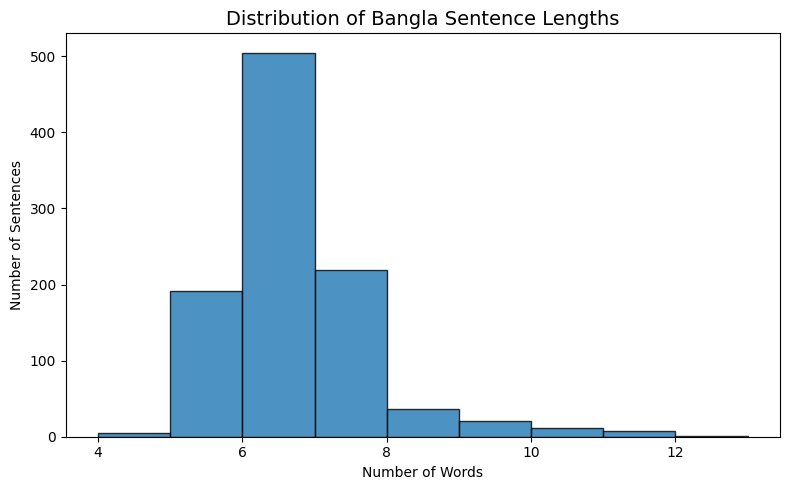

Saved: /kaggle/working/bangla_multimodal_thesis/figures/sentence_word_length_distribution.png


In [371]:
plt.figure(figsize=(8, 5))

plt.hist(
    text_eda_df["word_count"],
    bins=range(
        int(text_eda_df["word_count"].min()),
        int(text_eda_df["word_count"].max()) + 2
    ),
    edgecolor="black",
    alpha=0.8
)

plt.title(
    "Distribution of Bangla Sentence Lengths",
    fontsize=14
)

plt.xlabel("Number of Words")
plt.ylabel("Number of Sentences")

plt.tight_layout()

word_length_fig_path = (
    FIGURE_DIR /
    "sentence_word_length_distribution.png"
)

plt.savefig(
    word_length_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", word_length_fig_path)

/tmp/ipykernel_58/4204185061.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


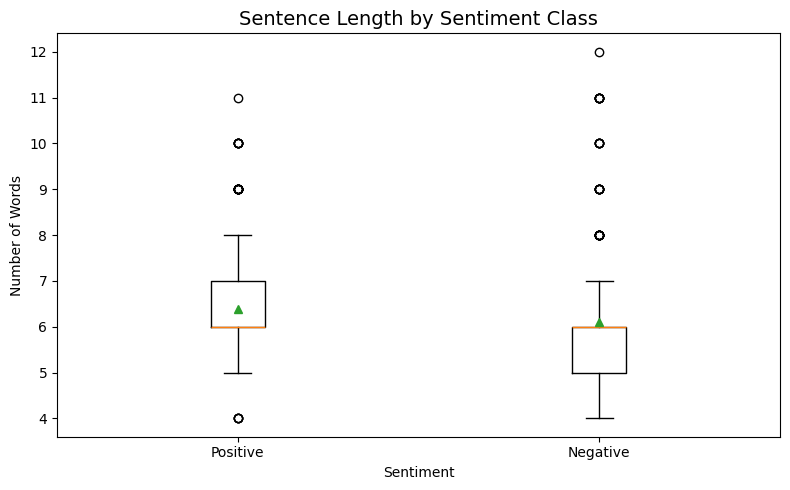

Saved: /kaggle/working/bangla_multimodal_thesis/figures/sentence_length_by_sentiment.png


In [372]:
positive_lengths = text_eda_df.loc[
    text_eda_df["sentiment"] == "Positive",
    "word_count"
]

negative_lengths = text_eda_df.loc[
    text_eda_df["sentiment"] == "Negative",
    "word_count"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [positive_lengths, negative_lengths],
    labels=["Positive", "Negative"],
    showmeans=True
)

plt.title(
    "Sentence Length by Sentiment Class",
    fontsize=14
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.tight_layout()

boxplot_path = (
    FIGURE_DIR /
    "sentence_length_by_sentiment.png"
)

plt.savefig(
    boxplot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", boxplot_path)

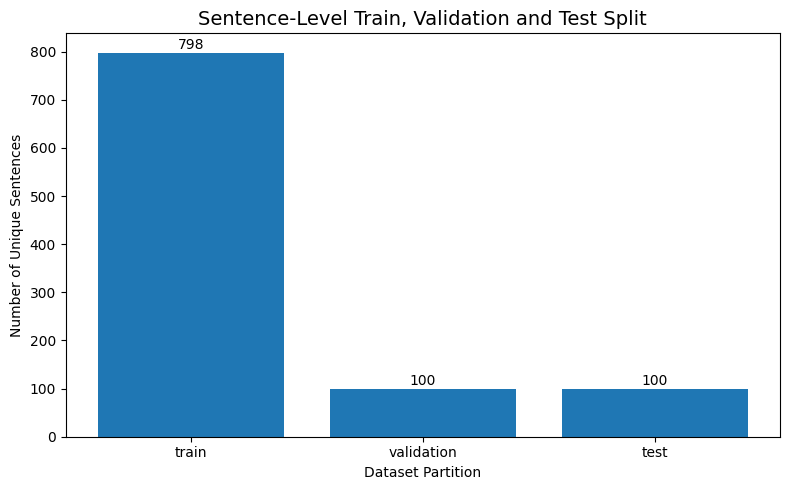

Saved: /kaggle/working/bangla_multimodal_thesis/figures/dataset_split_distribution.png


In [373]:
split_sentence_counts = (
    text_eda_df["split"]
    .value_counts()
    .reindex(
        ["train", "validation", "test"]
    )
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    split_sentence_counts.index,
    split_sentence_counts.values
)

plt.title(
    "Sentence-Level Train, Validation and Test Split",
    fontsize=14
)

plt.xlabel("Dataset Partition")
plt.ylabel("Number of Unique Sentences")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 8,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()

split_fig_path = (
    FIGURE_DIR /
    "dataset_split_distribution.png"
)

plt.savefig(
    split_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", split_fig_path)

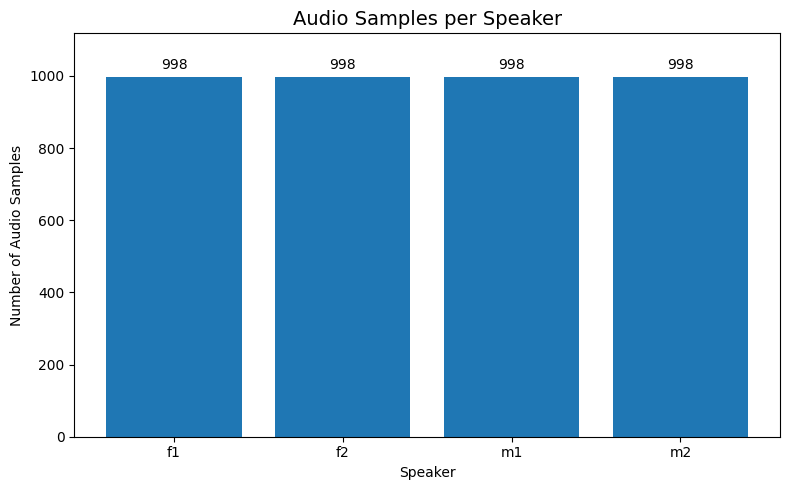

Saved: /kaggle/working/bangla_multimodal_thesis/figures/speaker_distribution.png


In [374]:
speaker_counts = (
    master_df["speaker"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    speaker_counts.index,
    speaker_counts.values
)

plt.title(
    "Audio Samples per Speaker",
    fontsize=14
)

plt.xlabel("Speaker")
plt.ylabel("Number of Audio Samples")

plt.ylim(
    0,
    speaker_counts.max() + 120
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 20,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()

speaker_fig_path = (
    FIGURE_DIR /
    "speaker_distribution.png"
)

plt.savefig(
    speaker_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", speaker_fig_path)

In [375]:
from tqdm.auto import tqdm

tqdm.pandas()

def get_duration(path):
    try:
        return librosa.get_duration(path=path)
    except Exception as e:
        return np.nan


master_df["audio_duration"] = (
    master_df["audio_path"]
    .progress_apply(get_duration)
)

  0%|          | 0/3992 [00:00<?, ?it/s]

In [376]:
print("Missing duration values:")
print(master_df["audio_duration"].isnull().sum())

print("\nAudio duration statistics:")
print(
    master_df["audio_duration"]
    .describe()
    .round(3)
)

Missing duration values:
0

Audio duration statistics:
count    3992.000
mean        3.678
std         0.876
min         1.882
25%         3.000
50%         3.503
75%         4.267
max         8.314
Name: audio_duration, dtype: float64


In [377]:
print("Shortest 10 recordings:")

display(
    master_df[
        [
            "sentence_id",
            "speaker",
            "filename",
            "audio_duration"
        ]
    ]
    .sort_values("audio_duration")
    .head(10)
)

Shortest 10 recordings:


,sentence_id,speaker,filename,audio_duration
2484,si_0623,f1,0623_f1.mp3,1.882381
2468,si_0619,f1,0619_f1.mp3,1.960816
732,si_0185,f1,0185_f1.mp3,2.013129
217,si_0055,f2,0055_f2.mp3,2.016000
3604,si_0903,f1,0903_f1.mp3,2.077812
900,si_0227,f1,0227_f1.mp3,2.091565
2684,si_0673,f1,0673_f1.mp3,2.117687
216,si_0055,f1,0055_f1.mp3,2.117687
648,si_0163,f1,0163_f1.mp3,2.117687
1268,si_0319,f1,0319_f1.mp3,2.117687


In [378]:
print("Longest 10 recordings:")

display(
    master_df[
        [
            "sentence_id",
            "speaker",
            "filename",
            "audio_duration"
        ]
    ]
    .sort_values(
        "audio_duration",
        ascending=False
    )
    .head(10)
)

Longest 10 recordings:


,sentence_id,speaker,filename,audio_duration
3706,si_0928,m1,0928_m1.mp3,8.314036
179,si_0045,m2,0045_m2.mp3,7.735760
2078,si_0521,m1,0521_m1.mp3,7.581973
335,si_0084,m2,0084_m2.mp3,7.300385
3726,si_0933,m1,0933_m1.mp3,7.032925
3930,si_0985,m1,0985_m1.mp3,7.006780
178,si_0045,m1,0045_m1.mp3,7.006780
1483,si_0372,m2,0372_m2.mp3,6.865011
3975,si_0996,m2,0996_m2.mp3,6.792449
334,si_0084,m1,0084_m1.mp3,6.771474


**Step 5L — Audio duration by speaker**

In [379]:
speaker_duration_stats = (
    master_df
    .groupby("speaker")["audio_duration"]
    .agg(
        [
            "count",
            "mean",
            "std",
            "min",
            "median",
            "max"
        ]
    )
    .round(3)
)

display(speaker_duration_stats)

,count,mean,std,min,median,max
speaker,,,,,,
f1,998,3.165,0.701,1.882,3.033,6.558
f2,998,3.120,0.434,2.016,3.060,6.168
m1,998,4.197,0.712,2.667,4.157,8.314
m2,998,4.229,0.859,2.279,4.246,7.736


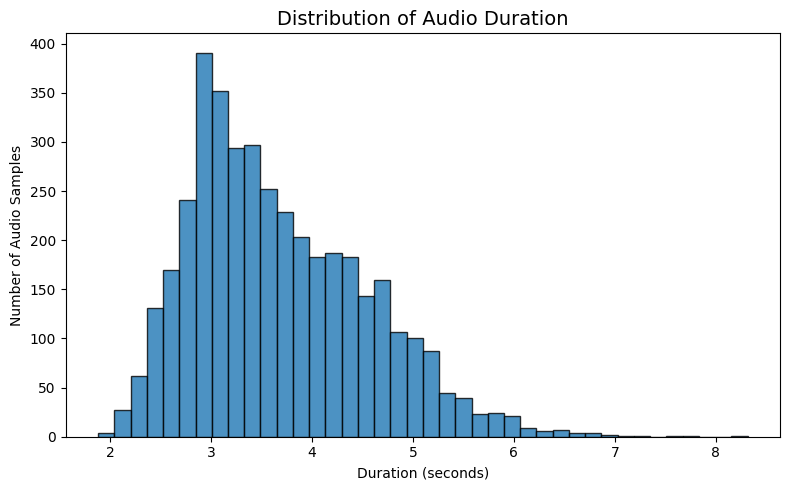

Saved: /kaggle/working/bangla_multimodal_thesis/figures/audio_duration_distribution.png


In [380]:
# Step 5M — Plot overall audio-duration distribution

plt.figure(figsize=(8, 5))

plt.hist(
    master_df["audio_duration"],
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.title(
    "Distribution of Audio Duration",
    fontsize=14
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Audio Samples")

plt.tight_layout()

duration_fig_path = (
    FIGURE_DIR /
    "audio_duration_distribution.png"
)

plt.savefig(
    duration_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", duration_fig_path)

/tmp/ipykernel_58/1611462749.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


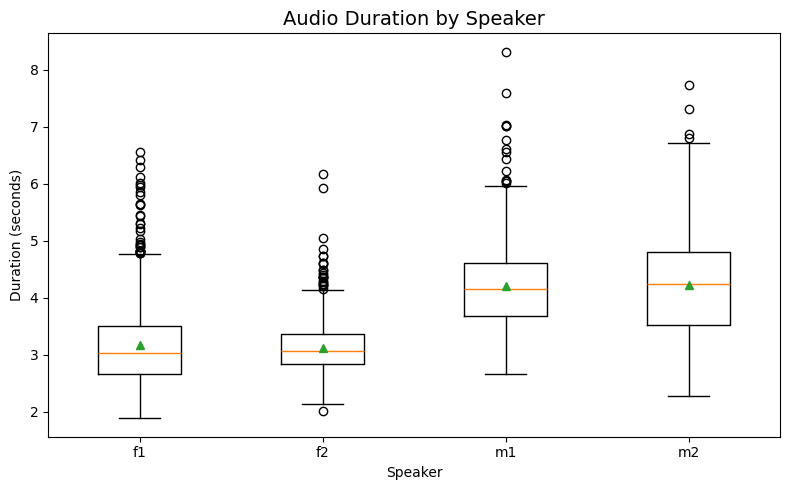

Saved: /kaggle/working/bangla_multimodal_thesis/figures/audio_duration_by_speaker.png


In [381]:
speaker_order = ["f1", "f2", "m1", "m2"]

duration_groups = [
    master_df.loc[
        master_df["speaker"] == speaker,
        "audio_duration"
    ]
    for speaker in speaker_order
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    duration_groups,
    labels=speaker_order,
    showmeans=True
)

plt.title(
    "Audio Duration by Speaker",
    fontsize=14
)

plt.xlabel("Speaker")
plt.ylabel("Duration (seconds)")

plt.tight_layout()

speaker_duration_fig_path = (
    FIGURE_DIR /
    "audio_duration_by_speaker.png"
)

plt.savefig(
    speaker_duration_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", speaker_duration_fig_path)

In [382]:
MASTER_DURATION_PATH = (
    PROCESSED_DIR /
    "banglamuse_master_with_splits_and_duration.csv"
)

master_df.to_csv(
    MASTER_DURATION_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(MASTER_DURATION_PATH)

Saved:
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_master_with_splits_and_duration.csv


In [383]:
positive_example = (
    master_df[
        master_df["sentiment"] == "Positive"
    ]
    .sample(
        1,
        random_state=42
    )
    .iloc[0]
)

negative_example = (
    master_df[
        master_df["sentiment"] == "Negative"
    ]
    .sample(
        1,
        random_state=42
    )
    .iloc[0]
)


print("POSITIVE EXAMPLE")
print("-" * 50)
print("Sentence ID:", positive_example["sentence_id"])
print("Speaker:", positive_example["speaker"])
print("Text:", positive_example["text"])
print("Audio:", positive_example["filename"])

print("\nNEGATIVE EXAMPLE")
print("-" * 50)
print("Sentence ID:", negative_example["sentence_id"])
print("Speaker:", negative_example["speaker"])
print("Text:", negative_example["text"])
print("Audio:", negative_example["filename"])

POSITIVE EXAMPLE
--------------------------------------------------
Sentence ID: si_0224
Speaker: f2
Text: তোমার ব্যাখ্যাটা আজ বেশ সহানুভূতিশীল ছিল।
Audio: 0224_f2.mp3

NEGATIVE EXAMPLE
--------------------------------------------------
Sentence ID: si_0723
Speaker: f2
Text: পরিবারের ভেতরে আজ গভীর উদ্বেগ ছড়িয়েছে।
Audio: 0723_f2.mp3


In [384]:
audio_path = positive_example["audio_path"]

y, sr = librosa.load(
    audio_path,
    sr=None,
    mono=True
)

print("Sampling rate:", sr)
print("Number of samples:", len(y))
print(
    "Duration:",
    round(len(y) / sr, 3),
    "seconds"
)

Sampling rate: 48000
Number of samples: 156672
Duration: 3.264 seconds


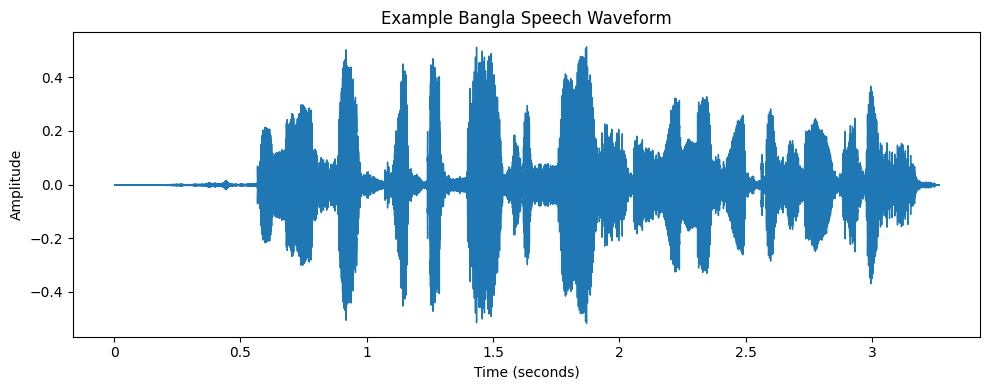

Saved: /kaggle/working/bangla_multimodal_thesis/figures/example_audio_waveform.png


In [385]:
plt.figure(figsize=(10, 4))

librosa.display.waveshow(
    y,
    sr=sr
)

plt.title(
    "Example Bangla Speech Waveform"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()

waveform_path = (
    FIGURE_DIR /
    "example_audio_waveform.png"
)

plt.savefig(
    waveform_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", waveform_path)

In [386]:
mel_spectrogram = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

log_mel = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

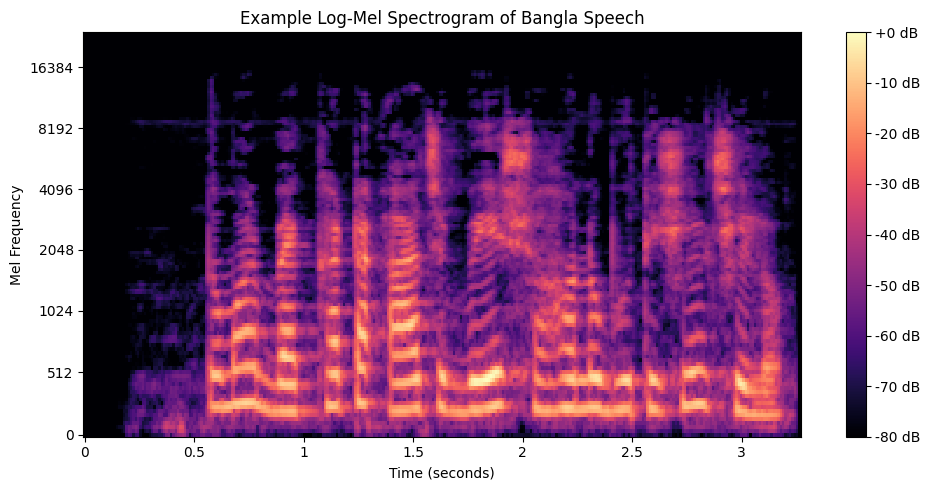

Saved: /kaggle/working/bangla_multimodal_thesis/figures/example_log_mel_spectrogram.png


In [387]:
plt.figure(figsize=(10, 5))

librosa.display.specshow(
    log_mel,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(
    format="%+2.0f dB"
)

plt.title(
    "Example Log-Mel Spectrogram of Bangla Speech"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mel Frequency")

plt.tight_layout()

spectrogram_path = (
    FIGURE_DIR /
    "example_log_mel_spectrogram.png"
)

plt.savefig(
    spectrogram_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", spectrogram_path)

In [388]:
sample_rate_records = []

for speaker in ["f1", "f2", "m1", "m2"]:

    samples = (
        master_df[
            master_df["speaker"] == speaker
        ]
        .sample(
            n=min(25, len(
                master_df[
                    master_df["speaker"] == speaker
                ]
            )),
            random_state=42
        )
    )

    for _, row in samples.iterrows():

        try:
            y_temp, sr_temp = librosa.load(
                row["audio_path"],
                sr=None,
                mono=True
            )

            sample_rate_records.append({
                "speaker": speaker,
                "sample_rate": sr_temp
            })

        except Exception as e:
            print(
                "Error:",
                row["filename"],
                e
            )

sample_rate_df = pd.DataFrame(
    sample_rate_records
)

print("Observed sample rates:")

print(
    sample_rate_df
    .groupby(
        ["speaker", "sample_rate"]
    )
    .size()
)

Observed sample rates:
speaker  sample_rate
f1       16000           9
         44100          16
f2       48000          25
m1       44100          25
m2       44100          25
dtype: int64


In [389]:
text_stats = (
    text_eda_df[
        [
            "word_count",
            "character_count"
        ]
    ]
    .describe()
)

audio_stats = (
    master_df[
        [
            "audio_duration"
        ]
    ]
    .describe()
)

text_stats.to_csv(
    RESULT_DIR /
    "text_descriptive_statistics.csv"
)

speaker_duration_stats.to_csv(
    RESULT_DIR /
    "speaker_audio_duration_statistics.csv"
)

audio_stats.to_csv(
    RESULT_DIR /
    "audio_descriptive_statistics.csv"
)

print("EDA statistics saved successfully.")

EDA statistics saved successfully.


In [390]:
print("=" * 70)
print("EDA SUMMARY")
print("=" * 70)

print("\nUnique sentences:")
print(len(text_eda_df))

print("\nPositive / Negative:")
print(
    text_eda_df["sentiment"]
    .value_counts()
)

print("\nWord count:")
print(
    "Mean =",
    round(
        text_eda_df["word_count"].mean(),
        2
    )
)

print(
    "Min =",
    text_eda_df["word_count"].min()
)

print(
    "Max =",
    text_eda_df["word_count"].max()
)

print("\nTotal audio samples:")
print(len(master_df))

print("\nAudio duration:")
print(
    "Mean =",
    round(
        master_df["audio_duration"].mean(),
        3
    ),
    "seconds"
)

print(
    "Min =",
    round(
        master_df["audio_duration"].min(),
        3
    ),
    "seconds"
)

print(
    "Max =",
    round(
        master_df["audio_duration"].max(),
        3
    ),
    "seconds"
)

print("\nSpeaker counts:")
print(
    master_df["speaker"]
    .value_counts()
    .sort_index()
)

print("\nMissing audio durations:")
print(
    master_df["audio_duration"]
    .isnull()
    .sum()
)

print("\nGenerated figures:")

for file in sorted(
    FIGURE_DIR.glob("*.png")
):
    print(" -", file.name)

print("=" * 70)

EDA SUMMARY

Unique sentences:
998

Positive / Negative:
sentiment
Positive    499
Negative    499
Name: count, dtype: int64

Word count:
Mean = 6.25
Min = 4
Max = 12

Total audio samples:
3992

Audio duration:
Mean = 3.678 seconds
Min = 1.882 seconds
Max = 8.314 seconds

Speaker counts:
speaker
f1    998
f2    998
m1    998
m2    998
Name: count, dtype: int64

Missing audio durations:
0

Generated figures:
 - audio_duration_by_speaker.png
 - audio_duration_distribution.png
 - banglabert_token_length_distribution.png
 - dataset_split_distribution.png
 - example_audio_waveform.png
 - example_log_mel_spectrogram.png
 - sentence_length_by_sentiment.png
 - sentence_word_length_distribution.png
 - sentiment_class_distribution.png
 - speaker_distribution.png


In [391]:
from tqdm.auto import tqdm
import librosa
import pandas as pd
import numpy as np

sample_rates = []

for path in tqdm(
    master_df["audio_path"],
    desc="Checking sample rates"
):
    try:
        sr = librosa.get_samplerate(path)
        sample_rates.append(sr)
    except Exception as e:
        print("Error reading:", path)
        print(e)
        sample_rates.append(np.nan)

master_df["original_sample_rate"] = sample_rates

print("\nMissing sample-rate values:")
print(master_df["original_sample_rate"].isna().sum())

Checking sample rates:   0%|          | 0/3992 [00:00<?, ?it/s]


Missing sample-rate values:
0


In [392]:
print("=" * 70)
print("FULL SAMPLE RATE DISTRIBUTION")
print("=" * 70)

print(
    master_df["original_sample_rate"]
    .value_counts()
    .sort_index()
)

print("\nSample rate by speaker:")
print(
    master_df
    .groupby(
        ["speaker", "original_sample_rate"]
    )
    .size()
)

print("=" * 70)

FULL SAMPLE RATE DISTRIBUTION
original_sample_rate
16000     243
44100    2741
48000    1008
Name: count, dtype: int64

Sample rate by speaker:
speaker  original_sample_rate
f1       16000                   243
         44100                   745
         48000                    10
f2       48000                   998
m1       44100                   998
m2       44100                   998
dtype: int64


In [393]:
sample_rate_sentiment = pd.crosstab(
    master_df["original_sample_rate"],
    master_df["sentiment"]
)

print("Sample Rate × Sentiment")
display(sample_rate_sentiment)

Sample Rate × Sentiment


sentiment,Negative,Positive
original_sample_rate,,
16000,243,0
44100,1249,1492
48000,504,504


In [394]:
sample_rate_sentiment_pct = pd.crosstab(
    master_df["original_sample_rate"],
    master_df["sentiment"],
    normalize="index"
) * 100

display(
    sample_rate_sentiment_pct.round(2)
)

sentiment,Negative,Positive
original_sample_rate,,
16000,100.00,0.00
44100,45.57,54.43
48000,50.00,50.00


**Step 5X — Save this information**

In [395]:
master_df.to_csv(
    PROCESSED_DIR /
    "banglamuse_master_with_audio_metadata.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Updated audio metadata saved.")

Updated audio metadata saved.


In [396]:
f1_sr_sentiment = pd.crosstab(
    master_df.loc[
        master_df["speaker"] == "f1",
        "original_sample_rate"
    ],
    master_df.loc[
        master_df["speaker"] == "f1",
        "sentiment"
    ]
)

print("f1: Sample Rate × Sentiment")
display(f1_sr_sentiment)

f1: Sample Rate × Sentiment


sentiment,Negative,Positive
original_sample_rate,,
16000,243,0
44100,251,494
48000,5,5


In [397]:
f1_16k = master_df[
    (master_df["speaker"] == "f1") &
    (master_df["original_sample_rate"] == 16000)
].copy()

print("Number of f1 16 kHz samples:", len(f1_16k))

print(
    "Sentence-number range:",
    f1_16k["sentence_number"].min(),
    "to",
    f1_16k["sentence_number"].max()
)

print("\nFirst 30 sentence IDs:")
print(
    sorted(
        f1_16k["sentence_number"].tolist()
    )[:30]
)

print("\nLast 30 sentence IDs:")
print(
    sorted(
        f1_16k["sentence_number"].tolist()
    )[-30:]
)

Number of f1 16 kHz samples: 243
Sentence-number range: 726 to 996

First 30 sentence IDs:
[726, 727, 728, 729, 730, 731, 732, 733, 734, 735, 736, 737, 738, 739, 740, 741, 742, 743, 744, 745, 746, 747, 748, 749, 750, 751, 752, 753, 754, 755]

Last 30 sentence IDs:
[966, 967, 968, 969, 970, 971, 972, 973, 974, 975, 976, 977, 978, 979, 980, 981, 982, 983, 984, 985, 986, 987, 988, 989, 990, 991, 992, 993, 994, 996]


In [398]:
ids_16k = sorted(
    f1_16k["sentence_number"]
    .astype(int)
    .tolist()
)

gaps = [
    (a, b)
    for a, b in zip(ids_16k[:-1], ids_16k[1:])
    if b - a > 1
]

print("Number of gaps:", len(gaps))
print("First gaps:", gaps[:20])

Number of gaps: 4
First gaps: [(775, 801), (939, 941), (941, 943), (994, 996)]


In [399]:
split_sr_table = pd.crosstab(
    master_df["split"],
    master_df["original_sample_rate"]
)

print("Split × Original Sample Rate")
display(split_sr_table)

Split × Original Sample Rate


original_sample_rate,16000,44100,48000
split,,,
test,31,266,103
train,190,2197,805
validation,22,278,100


In [400]:
f1_split_sr = pd.crosstab(
    master_df.loc[
        master_df["speaker"] == "f1",
        "split"
    ],
    master_df.loc[
        master_df["speaker"] == "f1",
        "original_sample_rate"
    ]
)

print("f1: Split × Original Sample Rate")
display(f1_split_sr)

f1: Split × Original Sample Rate


original_sample_rate,16000,44100,48000
split,,,
test,31,66,3
train,190,601,7
validation,22,78,0


In [401]:
MASTER_AUDIO_METADATA_PATH = (
    PROCESSED_DIR /
    "banglamuse_master_with_audio_metadata.csv"
)

master_df.to_csv(
    MASTER_AUDIO_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Updated audio metadata saved:")
print(MASTER_AUDIO_METADATA_PATH)

Updated audio metadata saved:
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_master_with_audio_metadata.csv


In [402]:
sample_rate_summary = (
    master_df
    .groupby(
        ["speaker", "original_sample_rate"]
    )
    .size()
    .reset_index(name="count")
)

sample_rate_summary.to_csv(
    RESULT_DIR /
    "sample_rate_by_speaker.csv",
    index=False
)

sample_rate_sentiment.to_csv(
    RESULT_DIR /
    "sample_rate_by_sentiment.csv"
)

print("Sampling-rate audit tables saved.")

Sampling-rate audit tables saved.


In [403]:
label_id_summary = (
    text_eda_df
    .groupby("sentiment")["sentence_number"]
    .agg(["min", "max", "count"])
)

display(label_id_summary)

,min,max,count
sentiment,,,
Negative,501,1000,499
Positive,1,500,499


In [404]:
MASTER_AUDIO_METADATA_PATH = (
    PROCESSED_DIR /
    "banglamuse_master_with_audio_metadata.csv"
)

master_df.to_csv(
    MASTER_AUDIO_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Updated audio metadata saved:")
print(MASTER_AUDIO_METADATA_PATH)

Updated audio metadata saved:
/kaggle/working/bangla_multimodal_thesis/processed_data/banglamuse_master_with_audio_metadata.csv


In [405]:
sample_rate_summary = (
    master_df
    .groupby(
        ["speaker", "original_sample_rate"]
    )
    .size()
    .reset_index(name="count")
)

sample_rate_summary.to_csv(
    RESULT_DIR / "sample_rate_by_speaker.csv",
    index=False
)

sample_rate_sentiment.to_csv(
    RESULT_DIR / "sample_rate_by_sentiment.csv"
)

print("Sampling-rate audit tables saved successfully.")

Sampling-rate audit tables saved successfully.


**Step 6A — Prepare the sentence-level train/validation/test data**

In [406]:
# Create one unique text sample per sentence
text_model_df = (
    master_df[
        [
            "sentence_number",
            "sentence_id",
            "text",
            "sentiment",
            "label",
            "split"
        ]
    ]
    .drop_duplicates(subset=["sentence_number"])
    .reset_index(drop=True)
)

print("Total unique text samples:", len(text_model_df))

print("\nSplit distribution:")
print(text_model_df["split"].value_counts())

print("\nLabel distribution:")
print(text_model_df["sentiment"].value_counts())

display(text_model_df.head())

Total unique text samples: 998

Split distribution:
split
train         798
test          100
validation    100
Name: count, dtype: int64

Label distribution:
sentiment
Positive    499
Negative    499
Name: count, dtype: int64


,sentence_number,sentence_id,text,sentiment,label,split
0,1,si_0001,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive,1,train
1,2,si_0002,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive,1,train
2,3,si_0003,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive,1,train
3,4,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,1,test
4,5,si_0005,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive,1,train


**Step 6B — Create separate text datasets**

In [407]:
text_train_df = (
    text_model_df[
        text_model_df["split"] == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

text_val_df = (
    text_model_df[
        text_model_df["split"] == "validation"
    ]
    .copy()
    .reset_index(drop=True)
)

text_test_df = (
    text_model_df[
        text_model_df["split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

print("Train:", text_train_df.shape)
print("Validation:", text_val_df.shape)
print("Test:", text_test_df.shape)

Train: (798, 6)
Validation: (100, 6)
Test: (100, 6)


**Step 6C — Install the BanglaBERT normalizer**

In [408]:
!pip install -q git+https://github.com/csebuetnlp/normalizer

  Preparing metadata (setup.py) ... done


In [409]:
from normalizer import normalize

print("Normalizer imported successfully.")

Normalizer imported successfully.


**Step 6D — Test normalization on one Bangla sentence**

In [410]:
sample_text = text_train_df.loc[0, "text"]

normalized_sample = normalize(sample_text)

print("Original:")
print(sample_text)

print("\nNormalized:")
print(normalized_sample)

Original:
সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।

Normalized:
সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।


**Step 6E — Normalize all text samples**

In [411]:
from tqdm.auto import tqdm

tqdm.pandas()

text_train_df["normalized_text"] = (
    text_train_df["text"]
    .progress_apply(normalize)
)

text_val_df["normalized_text"] = (
    text_val_df["text"]
    .progress_apply(normalize)
)

text_test_df["normalized_text"] = (
    text_test_df["text"]
    .progress_apply(normalize)
)

  0%|          | 0/798 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

In [412]:
print("Missing normalized text:")

print(
    "Train:",
    text_train_df["normalized_text"].isnull().sum()
)

print(
    "Validation:",
    text_val_df["normalized_text"].isnull().sum()
)

print(
    "Test:",
    text_test_df["normalized_text"].isnull().sum()
)

display(
    text_train_df[
        ["text", "normalized_text", "sentiment"]
    ].head()
)

Missing normalized text:
Train: 0
Validation: 0
Test: 0


,text,normalized_text,sentiment
0,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।,Positive
1,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,আমার পোষা কুকুরটি আমার সেরা বন্ধু!,Positive
2,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,আমি নিশ্চিতকরণ দিচ্ছি যে সবকিছু ঠিকঠাক হবে।,Positive
3,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,অধ্যবসায়ের ছন্দে উন্মোচিত হয় সফলতার দিগন্ত।,Positive
4,অনুকূল পরিস্থিতি থাকলে কাজটা সহজে সম্পন্ন হবে।,অনুকূল পরিস্থিতি থাকলে কাজটা সহজে সম্পন্ন হবে।,Positive


**Step 6F — Check whether normalization created empty strings**

In [413]:
for name, dataframe in [
    ("Train", text_train_df),
    ("Validation", text_val_df),
    ("Test", text_test_df)
]:
    
    empty_count = (
        dataframe["normalized_text"]
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )
    
    print(f"{name} empty normalized texts: {empty_count}")

Train empty normalized texts: 0
Validation empty normalized texts: 0
Test empty normalized texts: 0


**Step 6G — Load BanglaBERT tokenizer only**

In [414]:
from transformers import AutoTokenizer

MODEL_NAME = "csebuetnlp/banglabert"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer loaded successfully.")
print("Tokenizer class:", tokenizer.__class__.__name__)
print("Vocabulary size:", tokenizer.vocab_size)

Tokenizer loaded successfully.
Tokenizer class: BertTokenizer
Vocabulary size: 32000


**Step 6H — Test tokenization**

In [415]:
sample = text_train_df.loc[0, "normalized_text"]

tokens = tokenizer.tokenize(sample)

encoded = tokenizer(
    sample,
    truncation=True,
    padding=False
)

print("Text:")
print(sample)

print("\nTokens:")
print(tokens)

print("\nNumber of tokens:")
print(len(tokens))

print("\nInput IDs:")
print(encoded["input_ids"])

Text:
সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ।

Tokens:
['সুন্দর', 'চলচ্চিত্রে', 'দেখা', 'যায়', 'জীবনের', 'উষ্ণ', 'রঙ', '।']

Number of tokens:
8

Input IDs:
[2, 1839, 10602, 1189, 965, 2314, 8596, 2809, 205, 3]


**Step 6I — Analyze token lengths before choosing max length**

In [416]:
def get_token_length(text):
    return len(
        tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

text_train_df["token_length"] = (
    text_train_df["normalized_text"]
    .progress_apply(get_token_length)
)

text_val_df["token_length"] = (
    text_val_df["normalized_text"]
    .progress_apply(get_token_length)
)

text_test_df["token_length"] = (
    text_test_df["normalized_text"]
    .progress_apply(get_token_length)
)

  0%|          | 0/798 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

In [417]:
all_token_lengths = pd.concat([
    text_train_df["token_length"],
    text_val_df["token_length"],
    text_test_df["token_length"]
])

print("Token length statistics:")
print(all_token_lengths.describe())

print("\nPercentiles:")
print(
    all_token_lengths.quantile(
        [0.90, 0.95, 0.99, 1.00]
    )
)

Token length statistics:
count    998.000000
mean      10.294589
std        1.375160
min        7.000000
25%        9.000000
50%       10.000000
75%       11.000000
max       19.000000
Name: token_length, dtype: float64

Percentiles:
0.90    12.0
0.95    13.0
0.99    15.0
1.00    19.0
Name: token_length, dtype: float64


**Step 6J — Plot token-length distribution**

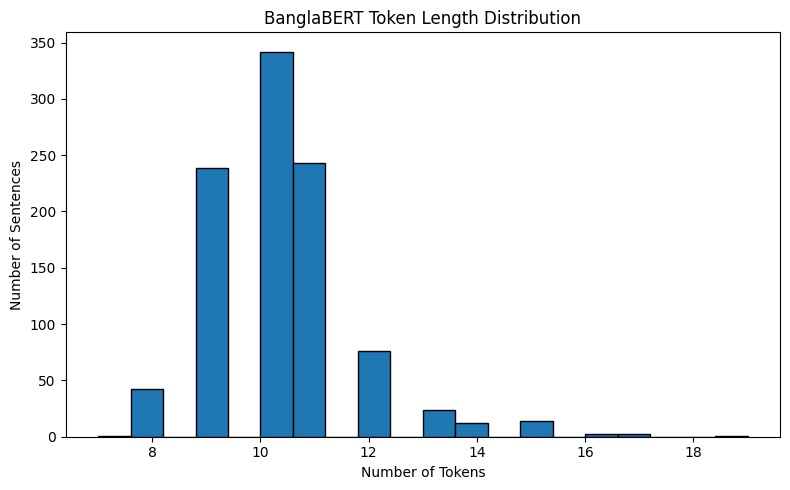

Saved: /kaggle/working/bangla_multimodal_thesis/figures/banglabert_token_length_distribution.png


In [418]:
plt.figure(figsize=(8, 5))

plt.hist(
    all_token_lengths,
    bins=20,
    edgecolor="black"
)

plt.title(
    "BanglaBERT Token Length Distribution"
)

plt.xlabel("Number of Tokens")
plt.ylabel("Number of Sentences")

plt.tight_layout()

token_length_fig = (
    FIGURE_DIR /
    "banglabert_token_length_distribution.png"
)

plt.savefig(
    token_length_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", token_length_fig)

**Step 6K — Save normalized text splits**

In [419]:
TEXT_TRAIN_PATH = (
    PROCESSED_DIR /
    "text_train_normalized.csv"
)

TEXT_VAL_PATH = (
    PROCESSED_DIR /
    "text_validation_normalized.csv"
)

TEXT_TEST_PATH = (
    PROCESSED_DIR /
    "text_test_normalized.csv"
)

text_train_df.to_csv(
    TEXT_TRAIN_PATH,
    index=False,
    encoding="utf-8-sig"
)

text_val_df.to_csv(
    TEXT_VAL_PATH,
    index=False,
    encoding="utf-8-sig"
)

text_test_df.to_csv(
    TEXT_TEST_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Normalized text datasets saved.")

Normalized text datasets saved.


**Step 6K.1 — Set reproducibility seed**

In [420]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

print(
    "Device:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

Random seed set to: 42
Device: Tesla T4


**Step 6K.2 — Define maximum sequence length**

In [421]:
MAX_LENGTH = 24

print("Maximum token length selected:", MAX_LENGTH)
print(
    "Observed maximum dataset token length:",
    int(all_token_lengths.max())
)

Maximum token length selected: 24
Observed maximum dataset token length: 19


**Step 6K.3 — Define the PyTorch Dataset class**

In [422]:
from torch.utils.data import Dataset

class BanglaTextDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        max_length=24
    ):

        self.texts = (
            dataframe["normalized_text"]
            .astype(str)
            .tolist()
        )

        self.labels = (
            dataframe["label"]
            .astype(int)
            .tolist()
        )

        # Keep sentence IDs internally,
        # but DO NOT send them to DataCollator
        self.sentence_ids = (
            dataframe["sentence_id"]
            .astype(str)
            .tolist()
        )

        self.tokenizer = tokenizer
        self.max_length = max_length


    def __len__(self):
        return len(self.texts)


    def __getitem__(self, idx):

        text = self.texts[idx]
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            truncation=True,
            max_length=self.max_length,
            padding=False
        )

        return {
            "input_ids": encoding["input_ids"],
            "attention_mask": encoding["attention_mask"],
            "labels": label
        }

**Step 6K.4 — Create the three Dataset objects**

In [423]:
train_dataset = BanglaTextDataset(
    text_train_df,
    tokenizer,
    MAX_LENGTH
)

val_dataset = BanglaTextDataset(
    text_val_df,
    tokenizer,
    MAX_LENGTH
)

test_dataset = BanglaTextDataset(
    text_test_df,
    tokenizer,
    MAX_LENGTH
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 798
Validation dataset: 100
Test dataset: 100


**Step 6K.5 — Inspect one individual sample**

In [424]:
sample = train_dataset[0]


print("\nInput IDs:")
print(sample["input_ids"])

print("\nAttention Mask:")
print(sample["attention_mask"])

print("\nLabel:")
print(sample["labels"])

print("\nInput length:")
print(len(sample["input_ids"]))


Input IDs:
[2, 1839, 10602, 1189, 965, 2314, 8596, 2809, 205, 3]

Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Label:
1

Input length:
10


**Step 6K.6 — Decode the tokenized sentence**

In [425]:
decoded_text = tokenizer.decode(
    sample["input_ids"],
    skip_special_tokens=True
)

print("Decoded text:")
print(decoded_text)

Decoded text:
সুন্দর চলচ্চিত্রে দেখা যায় জীবনের উষ্ণ রঙ ।


**Step 6K.7 — Use dynamic padding**

In [426]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

print("Dynamic padding collator created.")

Dynamic padding collator created.


**Step 6K.8 — Create DataLoaders**

In [427]:
import torch

from torch.utils.data import (
    Dataset,
    DataLoader,
    TensorDataset
)

BATCH_SIZE = 16


generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

**6K.9 — Inspect one training batch**

In [428]:
batch = next(iter(train_loader))

print("Batch keys:")
print(batch.keys())

print("\nInput IDs shape:")
print(batch["input_ids"].shape)

print("\nAttention mask shape:")
print(batch["attention_mask"].shape)

print("\nLabels shape:")
print(batch["labels"].shape)

print("\nLabels:")
print(batch["labels"])

Batch keys:
KeysView({'input_ids': tensor([[    2,  5173,  1763,   997, 11106,  3490,  1189,  1092,   205,     3,
             0,     0],
        [    2,   809,   997,  2623, 11106, 15214,  8311,   878,  1097,   205,
             3,     0],
        [    2,  2660,  1771,  1105,   997,  1014, 10018, 16054,  9916,   205,
             3,     0],
        [    2,  5826,  5556,   800,   997,  1103,  5595,  8839, 15917,   955,
           205,     3],
        [    2,   997, 10257,  3881, 16597,   800,  1014, 17940,  9916,   205,
             3,     0],
        [    2,   826,  3482,   800,   997,  3724, 20858,   955,   205,     3,
             0,     0],
        [    2,  1188, 16407,   949,  6032, 21577,   905,  2561,  2093,   205,
             3,     0],
        [    2,  1115,   997,  1103,  5890,  9931,    16,  1172,  1055,  6063,
           205,     3],
        [    2,  5173, 13221,  1105,   997,  3724,  5834,   955,   205,     3,
             0,     0],
        [    2,  2602,  1021, 31133, 1

**Step 6K.10 — Verify padding**

In [429]:
print("First sample input IDs:")
print(batch["input_ids"][0])

print("\nFirst sample attention mask:")
print(batch["attention_mask"][0])

First sample input IDs:
tensor([    2,  5173,  1763,   997, 11106,  3490,  1189,  1092,   205,     3,
            0,     0])

First sample attention mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0])


**Step 6K.11 — Confirm label balance in the actual training dataset**

In [430]:
train_labels = [
    train_dataset[i]["labels"]
    for i in range(len(train_dataset))
]

unique_labels, label_counts = np.unique(
    train_labels,
    return_counts=True
)

print("Training label distribution:")

for label, count in zip(
    unique_labels,
    label_counts
):
    sentiment = (
        "Negative"
        if label == 0
        else "Positive"
    )

    print(
        f"{label} ({sentiment}): {count}"
    )

Training label distribution:
0 (Negative): 399
1 (Positive): 399


**Step 6L — Load BanglaBERT for Binary Sentiment Classification**

**Step 6L.1 — Define label mappings**

In [431]:
id2label = {
    0: "Negative",
    1: "Positive"
}

label2id = {
    "Negative": 0,
    "Positive": 1
}

print("ID → Label:", id2label)
print("Label → ID:", label2id)

ID → Label: {0: 'Negative', 1: 'Positive'}
Label → ID: {'Negative': 0, 'Positive': 1}


**Step 6L.2 — Set the device**

In [432]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Using device: cuda
GPU: Tesla T4


**Step 6L.3 — Clear unused GPU memory**

In [433]:
import gc

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("GPU cache cleared.")

GPU cache cleared.


**Step 6L.4 — Load BanglaBERT classification model**

In [434]:
# Reset random state immediately before model initialization

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Seed reset before BanglaBERT initialization.")

Seed reset before BanglaBERT initialization.


In [435]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

model = model.to(device)

print("BanglaBERT classification model loaded successfully.")
print("Model class:", model.__class__.__name__)

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

BanglaBERT classification model loaded successfully.
Model class: ElectraForSequenceClassification


**Step 6L.5 — Inspect the model architecture**

In [436]:
print(model)

ElectraForSequenceClassification(
  (electra): ElectraModel(
    (embeddings): ElectraEmbeddings(
      (word_embeddings): Embedding(32000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): ElectraEncoder(
      (layer): ModuleList(
        (0-11): 12 x ElectraLayer(
          (attention): ElectraAttention(
            (self): ElectraSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): ElectraSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): L

**Step 6L.6 — Count parameters**

In [437]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = (
    total_params - trainable_params
)

print("Total parameters:")
print(f"{total_params:,}")

print("\nTrainable parameters:")
print(f"{trainable_params:,}")

print("\nNon-trainable parameters:")
print(f"{non_trainable_params:,}")

print(
    "\nPercentage trainable:"
)

print(
    f"{100 * trainable_params / total_params:.2f}%"
)

Total parameters:
110,618,882

Trainable parameters:
110,618,882

Non-trainable parameters:
0

Percentage trainable:
100.00%


**Step 6L.7 — Inspect the model configuration**

In [438]:
print("Number of labels:")
print(model.config.num_labels)

print("\nID → Label:")
print(model.config.id2label)

print("\nLabel → ID:")
print(model.config.label2id)

print("\nHidden size:")
print(model.config.hidden_size)

Number of labels:
2

ID → Label:
{0: 'Negative', 1: 'Positive'}

Label → ID:
{'Negative': 0, 'Positive': 1}

Hidden size:
768


**Step 6L.8 — Move one batch to GPU**

In [439]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)

attention_mask = (
    batch["attention_mask"]
    .to(device)
)

labels = (
    batch["labels"]
    .to(device)
)

print("Input IDs device:")
print(input_ids.device)

print("\nAttention mask device:")
print(attention_mask.device)

print("\nLabels device:")
print(labels.device)

Input IDs device:
cuda:0

Attention mask device:
cuda:0

Labels device:
cuda:0


**Step 6L.9 — Perform one forward pass**

In [440]:
model.eval()

with torch.no_grad():

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

print("Forward pass successful.")

Forward pass successful.


**Step 6L.10 — Inspect loss and logits**

In [441]:
print("Loss:")
print(outputs.loss.item())

print("\nLogits shape:")
print(outputs.logits.shape)

print("\nFirst 5 logits:")
print(
    outputs.logits[:5]
)

Loss:
0.6971362829208374

Logits shape:
torch.Size([16, 2])

First 5 logits:
tensor([[ 0.0234,  0.0106],
        [-0.0251,  0.0253],
        [-0.0561,  0.0117],
        [-0.0093,  0.0037],
        [-0.0485,  0.0249]], device='cuda:0')


**Step 6L.11 — Convert logits to probabilities**

In [442]:
probabilities = torch.softmax(
    outputs.logits,
    dim=1
)

print("First 5 probabilities:")
print(
    probabilities[:5]
)

First 5 probabilities:
tensor([[0.5032, 0.4968],
        [0.4874, 0.5126],
        [0.4831, 0.5169],
        [0.4967, 0.5033],
        [0.4816, 0.5184]], device='cuda:0')


**6L.12 — Generate predictions**

In [443]:
predictions = torch.argmax(
    probabilities,
    dim=1
)

print("Predicted labels:")
print(predictions)

print("\nTrue labels:")
print(labels)

Predicted labels:
tensor([0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], device='cuda:0')

True labels:
tensor([1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0], device='cuda:0')


**Step 6L.13 — Inspect one human-readable prediction**

In [444]:
example_index = 0

predicted_id = (
    predictions[example_index]
    .item()
)

true_id = (
    labels[example_index]
    .item()
)

print("Predicted:")
print(id2label[predicted_id])

print("\nActual:")
print(id2label[true_id])

print("\nConfidence:")
print(
    round(
        probabilities[
            example_index,
            predicted_id
        ].item(),
        4
    )
)

Predicted:
Negative

Actual:
Positive

Confidence:
0.5032


**6L.14 — Check GPU memory******

In [445]:
if torch.cuda.is_available():

    allocated = (
        torch.cuda.memory_allocated(0)
        / 1024**3
    )

    reserved = (
        torch.cuda.memory_reserved(0)
        / 1024**3
    )

    total = (
        torch.cuda.get_device_properties(0)
        .total_memory
        / 1024**3
    )

    print(
        f"GPU allocated: {allocated:.2f} GB"
    )

    print(
        f"GPU reserved:  {reserved:.2f} GB"
    )

    print(
        f"GPU total:     {total:.2f} GB"
    )

GPU allocated: 0.45 GB
GPU reserved:  0.50 GB
GPU total:     14.56 GB


**Step 6M — Configure BanglaBERT Fine-Tuning**

**Step 6M.1 — Import evaluation metrics \\
Step 6M.2 — Define one reusable metric function**

In [446]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Evaluation metrics imported successfully.")


def calculate_metrics(y_true, y_pred):
    
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision_macro = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro
    }

Evaluation metrics imported successfully.


**Step 6M.3 — Configure optimizer**

In [447]:
from torch.optim import AdamW

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Optimizer configured.")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

Optimizer configured.
Learning rate: 2e-05
Weight decay: 0.01


**Step 6M.4 — Configure epochs and scheduler**

In [448]:
import math

MAX_EPOCHS = 10

total_training_steps = (
    len(train_loader) * MAX_EPOCHS
)

warmup_steps = int(
    0.10 * total_training_steps
)

print("Training batches per epoch:", len(train_loader))
print("Maximum epochs:", MAX_EPOCHS)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Training batches per epoch: 50
Maximum epochs: 10
Total training steps: 500
Warmup steps: 50


**Step 6M.5 — Create learning-rate scheduler**

In [449]:
from transformers import get_linear_schedule_with_warmup

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Learning-rate scheduler created.")

Learning-rate scheduler created.


**Step 6M.6 — Configure early stopping**

In [450]:
EARLY_STOPPING_PATIENCE = 3

best_val_f1 = -1.0
epochs_without_improvement = 0

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

Early stopping patience: 3


**Step 6M.7 — Create checkpoint directory**

In [451]:
from pathlib import Path

PROJECT_ROOT = Path(PROJECT_ROOT)

MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_TEXT_MODEL_PATH = (
    MODEL_DIR / "banglabert_text_best.pt"
)

print("Best-model path:")
print(BEST_TEXT_MODEL_PATH)

Best-model path:
/kaggle/working/bangla_multimodal_thesis/models/banglabert_text_best.pt


**6M.8 — Define the training function**

In [452]:
from tqdm.auto import tqdm

def train_one_epoch(
    model,
    dataloader,
    optimizer,
    scheduler,
    device
):
    
    model.train()

    total_loss = 0.0

    all_predictions = []
    all_labels = []

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for batch in progress_bar:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update parameters
        optimizer.step()

        # Update learning rate
        scheduler.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_predictions.extend(
            predictions
            .detach()
            .cpu()
            .numpy()
        )

        all_labels.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = (
        total_loss /
        len(dataloader)
    )

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    return average_loss, metrics

**Step 6M.9 — Understand what this training function does & Step 6M.10 — Define validation function**

In [453]:
def evaluate_model(
    model,
    dataloader,
    device
):

    model.eval()

    total_loss = 0.0

    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for batch in tqdm(
            dataloader,
            desc="Validation",
            leave=False
        ):

            input_ids = (
                batch["input_ids"]
                .to(device)
            )

            attention_mask = (
                batch["attention_mask"]
                .to(device)
            )

            labels = (
                batch["labels"]
                .to(device)
            )

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += (
                outputs.loss.item()
            )

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_predictions.extend(
                predictions
                .cpu()
                .numpy()
            )

            all_labels.extend(
                labels
                .cpu()
                .numpy()
            )

            all_probabilities.extend(
                probabilities
                .cpu()
                .numpy()
            )

    average_loss = (
        total_loss /
        len(dataloader)
    )

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    return (
        average_loss,
        metrics,
        np.array(all_predictions),
        np.array(all_labels),
        np.array(all_probabilities)
    )

**Step 6M.11 — Test validation function BEFORE training**

In [454]:
initial_val_loss, initial_val_metrics, _, _, _ = (
    evaluate_model(
        model,
        val_loader,
        device
    )
)

print("=" * 60)
print("INITIAL UNTRAINED VALIDATION PERFORMANCE")
print("=" * 60)

print(
    "Validation Loss:",
    round(initial_val_loss, 4)
)

print(
    "Accuracy:",
    round(
        initial_val_metrics["accuracy"],
        4
    )
)

print(
    "Macro Precision:",
    round(
        initial_val_metrics["precision_macro"],
        4
    )
)

print(
    "Macro Recall:",
    round(
        initial_val_metrics["recall_macro"],
        4
    )
)

print(
    "Macro F1:",
    round(
        initial_val_metrics["f1_macro"],
        4
    )
)

Validation:   0%|          | 0/7 [00:00<?, ?it/s]

INITIAL UNTRAINED VALIDATION PERFORMANCE
Validation Loss: 0.6986
Accuracy: 0.5
Macro Precision: 0.5
Macro Recall: 0.5
Macro F1: 0.38


**Step 6N — Fine-tune BanglaBERT**

**Step 6N.1 — Initialize training history**

In [455]:
training_history = []

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

print("Training state initialized.")

Training state initialized.


**Step 6N.2 — Run the epoch-by-epoch training loop**

In [456]:
import time

print("=" * 85)
print("BANGLABERT TEXT-ONLY BASELINE TRAINING")
print("=" * 85)

training_start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):

    print(f"\n{'=' * 85}")
    print(f"EPOCH {epoch}/{MAX_EPOCHS}")
    print(f"{'=' * 85}")

    epoch_start_time = time.time()

    # --------------------------------------------------
    # TRAIN
    # --------------------------------------------------
    train_loss, train_metrics = train_one_epoch(
        model=model,
        dataloader=train_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        device=device
    )

    # --------------------------------------------------
    # VALIDATE
    # --------------------------------------------------
    (
        val_loss,
        val_metrics,
        val_predictions,
        val_labels,
        val_probabilities
    ) = evaluate_model(
        model=model,
        dataloader=val_loader,
        device=device
    )

    epoch_time = time.time() - epoch_start_time

    current_val_f1 = val_metrics["f1_macro"]

    # --------------------------------------------------
    # CHECK FOR BEST MODEL
    # --------------------------------------------------
    if current_val_f1 > best_val_f1:

        best_val_f1 = current_val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            BEST_TEXT_MODEL_PATH
        )

        status = "BEST MODEL SAVED"

    else:

        epochs_without_improvement += 1
        status = (
            f"No improvement "
            f"({epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE})"
        )

    # --------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------
    training_history.append({
        "epoch": epoch,

        "train_loss": train_loss,
        "train_accuracy": train_metrics["accuracy"],
        "train_precision_macro": train_metrics["precision_macro"],
        "train_recall_macro": train_metrics["recall_macro"],
        "train_f1_macro": train_metrics["f1_macro"],

        "val_loss": val_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_precision_macro": val_metrics["precision_macro"],
        "val_recall_macro": val_metrics["recall_macro"],
        "val_f1_macro": val_metrics["f1_macro"],

        "epoch_time_seconds": epoch_time
    })

    # --------------------------------------------------
    # PRINT EPOCH RESULTS
    # --------------------------------------------------
    print("\nTRAINING RESULTS")
    print("-" * 45)

    print(
        f"Loss:            {train_loss:.4f}"
    )

    print(
        f"Accuracy:        "
        f"{train_metrics['accuracy']:.4f}"
    )

    print(
        f"Macro F1:        "
        f"{train_metrics['f1_macro']:.4f}"
    )

    print("\nVALIDATION RESULTS")
    print("-" * 45)

    print(
        f"Loss:            {val_loss:.4f}"
    )

    print(
        f"Accuracy:        "
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        f"Macro Precision: "
        f"{val_metrics['precision_macro']:.4f}"
    )

    print(
        f"Macro Recall:    "
        f"{val_metrics['recall_macro']:.4f}"
    )

    print(
        f"Macro F1:        "
        f"{val_metrics['f1_macro']:.4f}"
    )

    print("\nSTATUS")
    print("-" * 45)

    print(status)

    print(
        f"Best validation F1 so far: "
        f"{best_val_f1:.4f}"
    )

    print(
        f"Epoch time: "
        f"{epoch_time:.1f} seconds"
    )

    # --------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------
    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print("\n" + "=" * 85)
        print(
            f"EARLY STOPPING TRIGGERED "
            f"AFTER EPOCH {epoch}"
        )
        print("=" * 85)

        break


total_training_time = (
    time.time() - training_start_time
)

print("\n" + "=" * 85)
print("TRAINING COMPLETE")
print("=" * 85)

print("Best epoch:", best_epoch)

print(
    "Best validation Macro F1:",
    round(best_val_f1, 4)
)

print(
    "Total training time:",
    round(total_training_time / 60, 2),
    "minutes"
)

print(
    "Best model saved at:",
    BEST_TEXT_MODEL_PATH
)

BANGLABERT TEXT-ONLY BASELINE TRAINING

EPOCH 1/10


Training:   0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:897.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Validation:   0%|          | 0/7 [00:00<?, ?it/s]


TRAINING RESULTS
---------------------------------------------
Loss:            0.6236
Accuracy:        0.7519
Macro F1:        0.7519

VALIDATION RESULTS
---------------------------------------------
Loss:            0.3158
Accuracy:        0.9900
Macro Precision: 0.9902
Macro Recall:    0.9900
Macro F1:        0.9900

STATUS
---------------------------------------------
BEST MODEL SAVED
Best validation F1 so far: 0.9900
Epoch time: 5.3 seconds

EPOCH 2/10


Training:   0%|          | 0/50 [00:00<?, ?it/s]

... (7 outputs left out)


TRAINING RESULTS
---------------------------------------------
Loss:            0.0130
Accuracy:        0.9987
Macro F1:        0.9987

VALIDATION RESULTS
---------------------------------------------
Loss:            0.0832
Accuracy:        0.9800
Macro Precision: 0.9808
Macro Recall:    0.9800
Macro F1:        0.9800

STATUS
---------------------------------------------
No improvement (2/3)
Best validation F1 so far: 1.0000
Epoch time: 5.0 seconds

EPOCH 5/10


Training:   0%|          | 0/50 [00:00<?, ?it/s]

Validation:   0%|          | 0/7 [00:00<?, ?it/s]


TRAINING RESULTS
---------------------------------------------
Loss:            0.0050
Accuracy:        1.0000
Macro F1:        1.0000

VALIDATION RESULTS
---------------------------------------------
Loss:            0.0025
Accuracy:        1.0000
Macro Precision: 1.0000
Macro Recall:    1.0000
Macro F1:        1.0000

STATUS
---------------------------------------------
No improvement (3/3)
Best validation F1 so far: 1.0000
Epoch time: 4.9 seconds

EARLY STOPPING TRIGGERED AFTER EPOCH 5

TRAINING COMPLETE
Best epoch: 2
Best validation Macro F1: 1.0
Total training time: 0.44 minutes
Best model saved at: /kaggle/working/bangla_multimodal_thesis/models/banglabert_text_best.pt


**Step 6N.3 — Convert the history to a table**

In [457]:
history_df = pd.DataFrame(
    training_history
)

display(
    history_df[
        [
            "epoch",
            "train_loss",
            "train_accuracy",
            "train_f1_macro",
            "val_loss",
            "val_accuracy",
            "val_f1_macro",
            "epoch_time_seconds"
        ]
    ].round(4)
)

,epoch,train_loss,train_accuracy,train_f1_macro,val_loss,val_accuracy,val_f1_macro,epoch_time_seconds
0,1,0.6236,0.7519,0.7519,0.3158,0.99,0.99,5.3059
1,2,0.1149,0.9975,0.9975,0.0143,1.00,1.00,4.8929
2,3,0.0191,0.9987,0.9987,0.0057,1.00,1.00,4.9573
3,4,0.0130,0.9987,0.9987,0.0832,0.98,0.98,5.0451
4,5,0.0050,1.0000,1.0000,0.0025,1.00,1.00,4.9312


**Step 6N.4 — Save training history**

In [458]:
TEXT_HISTORY_PATH = (
    RESULT_DIR /
    "banglabert_text_training_history.csv"
)

history_df.to_csv(
    TEXT_HISTORY_PATH,
    index=False
)

print("Training history saved:")
print(TEXT_HISTORY_PATH)

Training history saved:
/kaggle/working/bangla_multimodal_thesis/results/banglabert_text_training_history.csv


**Step 6N.5 — Final text leakage/sanity audit**

In [459]:
train_texts = set(
    text_train_df["normalized_text"]
    .astype(str)
    .str.strip()
)

val_texts = set(
    text_val_df["normalized_text"]
    .astype(str)
    .str.strip()
)

test_texts = set(
    text_test_df["normalized_text"]
    .astype(str)
    .str.strip()
)

print("Train ↔ Validation text overlap:",
      len(train_texts & val_texts))

print("Train ↔ Test text overlap:",
      len(train_texts & test_texts))

print("Validation ↔ Test text overlap:",
      len(val_texts & test_texts)
     )

Train ↔ Validation text overlap: 0
Train ↔ Test text overlap: 0
Validation ↔ Test text overlap: 0


In [460]:
combined_text_df = pd.concat(
    [
        text_train_df.assign(source_split="train"),
        text_val_df.assign(source_split="validation"),
        text_test_df.assign(source_split="test")
    ],
    ignore_index=True
)

normalized_duplicates = combined_text_df[
    combined_text_df.duplicated(
        subset=["normalized_text"],
        keep=False
    )
].sort_values("normalized_text")

print(
    "Rows involved in duplicated normalized texts:",
    len(normalized_duplicates)
)

if len(normalized_duplicates) > 0:
    display(
        normalized_duplicates[
            [
                "sentence_id",
                "normalized_text",
                "sentiment",
                "source_split"
            ]
        ]
    )

Rows involved in duplicated normalized texts: 0


In [461]:
print("Validation labels:")
print(
    text_val_df["sentiment"]
    .value_counts()
)

print("\nValidation numeric labels:")
print(
    text_val_df["label"]
    .value_counts()
    .sort_index()
)

Validation labels:
sentiment
Positive    50
Negative    50
Name: count, dtype: int64

Validation numeric labels:
label
0    50
1    50
Name: count, dtype: int64


**Step 6N.6 — Run a simple TF-IDF baseline**

In [462]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

tfidf_baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            min_df=1
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

tfidf_baseline.fit(
    text_train_df["normalized_text"],
    text_train_df["label"]
)

val_tfidf_pred = tfidf_baseline.predict(
    text_val_df["normalized_text"]
)

tfidf_val_accuracy = accuracy_score(
    text_val_df["label"],
    val_tfidf_pred
)

tfidf_val_f1 = f1_score(
    text_val_df["label"],
    val_tfidf_pred,
    average="macro"
)

print("=" * 60)
print("TF-IDF + LOGISTIC REGRESSION VALIDATION BASELINE")
print("=" * 60)

print(
    "Validation Accuracy:",
    round(tfidf_val_accuracy, 4)
)

print(
    "Validation Macro F1:",
    round(tfidf_val_f1, 4)
)

TF-IDF + LOGISTIC REGRESSION VALIDATION BASELINE
Validation Accuracy: 0.94
Validation Macro F1: 0.94


**Step 6N.7 — Verify the saved best checkpoint**

In [463]:
print("Best checkpoint:")
print(BEST_TEXT_MODEL_PATH)

print(
    "\nCheckpoint exists:",
    BEST_TEXT_MODEL_PATH.exists()
)

print(
    "Checkpoint size:",
    round(
        BEST_TEXT_MODEL_PATH.stat().st_size /
        (1024 ** 2),
        2
    ),
    "MB"
)

Best checkpoint:
/kaggle/working/bangla_multimodal_thesis/models/banglabert_text_best.pt

Checkpoint exists: True
Checkpoint size: 422.06 MB


**Step 6O.1 — Load the best checkpoint**

In [464]:
best_state_dict = torch.load(
    BEST_TEXT_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    best_state_dict
)

model = model.to(device)
model.eval()

print("Best BanglaBERT checkpoint loaded successfully.")
print("Best epoch:", best_epoch)
print("Best validation Macro F1:", best_val_f1)

Best BanglaBERT checkpoint loaded successfully.
Best epoch: 2
Best validation Macro F1: 1.0


**Step 6O.2 — Evaluate the locked model on the test set**

In [465]:
(
    test_loss,
    test_metrics,
    test_predictions,
    test_labels,
    test_probabilities
) = evaluate_model(
    model=model,
    dataloader=test_loader,
    device=device
)

print("=" * 70)
print("FINAL TEXT-ONLY BANGLABERT TEST PERFORMANCE")
print("=" * 70)

print(
    f"Test Loss:       {test_loss:.4f}"
)

print(
    f"Accuracy:        "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Macro Precision: "
    f"{test_metrics['precision_macro']:.4f}"
)

print(
    f"Macro Recall:    "
    f"{test_metrics['recall_macro']:.4f}"
)

print(
    f"Macro F1:        "
    f"{test_metrics['f1_macro']:.4f}"
)

print("=" * 70)

Validation:   0%|          | 0/7 [00:00<?, ?it/s]

FINAL TEXT-ONLY BANGLABERT TEST PERFORMANCE
Test Loss:       0.2602
Accuracy:        0.9600
Macro Precision: 0.9630
Macro Recall:    0.9600
Macro F1:        0.9599


**Step 6O.3 — Add weighted metrics**

In [466]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

weighted_precision = precision_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

print("Weighted Precision:",
      round(weighted_precision, 4))

print("Weighted Recall:",
      round(weighted_recall, 4))

print("Weighted F1:",
      round(weighted_f1, 4))

Weighted Precision: 0.963
Weighted Recall: 0.96
Weighted F1: 0.9599


**Step 6O.4 — Classification report**

In [467]:
from sklearn.metrics import classification_report

report = classification_report(
    test_labels,
    test_predictions,
    target_names=[
        "Negative",
        "Positive"
    ],
    digits=4
)

print("=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(report)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     1.0000    0.9200    0.9583        50
    Positive     0.9259    1.0000    0.9615        50

    accuracy                         0.9600       100
   macro avg     0.9630    0.9600    0.9599       100
weighted avg     0.9630    0.9600    0.9599       100



**Step 6O.5 — Confusion matrix & Step 6O.6 — Plot thesis-ready confusion matrix **

Confusion Matrix:
[[46  4]
 [ 0 50]]


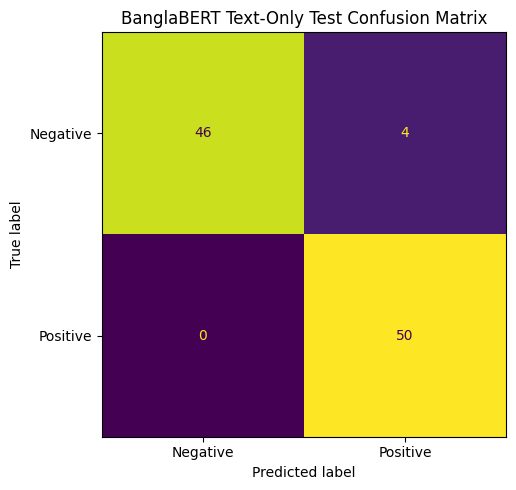

Saved:
/kaggle/working/bangla_multimodal_thesis/figures/banglabert_text_test_confusion_matrix.png


In [468]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("Confusion Matrix:")
print(cm)


from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(6, 5)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Negative",
        "Positive"
    ]
)

display_cm.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title(
    "BanglaBERT Text-Only Test Confusion Matrix"
)

plt.tight_layout()

TEXT_CM_PATH = (
    FIGURE_DIR /
    "banglabert_text_test_confusion_matrix.png"
)

plt.savefig(
    TEXT_CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(TEXT_CM_PATH)

**Step 6O.7 — Calculate ROC-AUC & Step 6O.8 — Plot ROC curve**

ROC-AUC: 0.9812


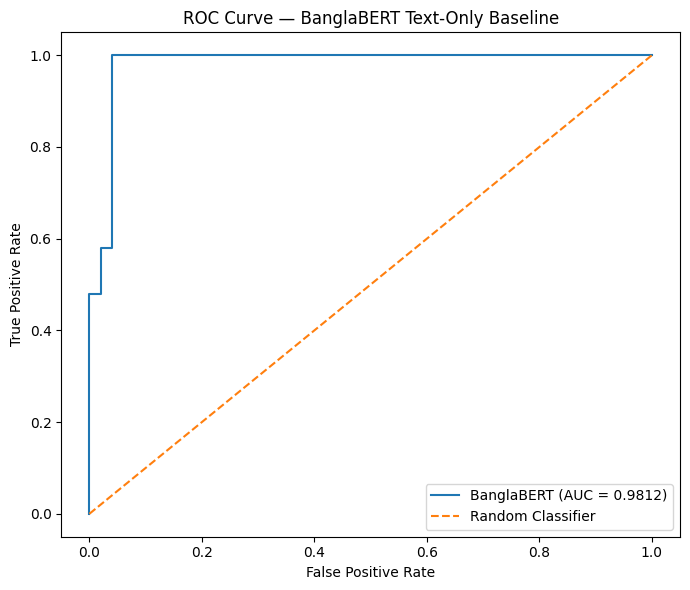

Saved:
/kaggle/working/bangla_multimodal_thesis/figures/banglabert_text_test_roc_curve.png


In [469]:
from sklearn.metrics import roc_auc_score

positive_probabilities = (
    test_probabilities[:, 1]
)

roc_auc = roc_auc_score(
    test_labels,
    positive_probabilities
)

print(
    "ROC-AUC:",
    round(roc_auc, 4)
)


from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    test_labels,
    positive_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"BanglaBERT (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — BanglaBERT Text-Only Baseline"
)

plt.legend()

plt.tight_layout()

TEXT_ROC_PATH = (
    FIGURE_DIR /
    "banglabert_text_test_roc_curve.png"
)

plt.savefig(
    TEXT_ROC_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(TEXT_ROC_PATH)

In [470]:
# Step 6O.9 — Build the test prediction table

text_test_results = (
    text_test_df[
        [
            "sentence_number",
            "sentence_id",
            "text",
            "normalized_text",
            "sentiment",
            "label"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

text_test_results["predicted_label"] = (
    test_predictions
)

text_test_results["predicted_sentiment"] = (
    text_test_results["predicted_label"]
    .map(id2label)
)

text_test_results["prob_negative"] = (
    test_probabilities[:, 0]
)

text_test_results["prob_positive"] = (
    test_probabilities[:, 1]
)

text_test_results["confidence"] = (
    test_probabilities.max(axis=1)
)

text_test_results["correct"] = (
    text_test_results["label"]
    ==
    text_test_results["predicted_label"]
)

display(
    text_test_results.head(10)
)



# Step 6O.10 — Inspect misclassified examples

text_errors = (
    text_test_results[
        text_test_results["correct"] == False
    ]
    .copy()
    .sort_values(
        "confidence",
        ascending=False
    )
)

print(
    "Number of misclassified test sentences:",
    len(text_errors)
)

if len(text_errors) > 0:

    display(
        text_errors[
            [
                "sentence_id",
                "text",
                "sentiment",
                "predicted_sentiment",
                "prob_negative",
                "prob_positive",
                "confidence"
            ]
        ]
    )

else:

    print(
        "No misclassified test examples."
    )


# Step 6O.11 — Inspect the least-confident correct predictions


lowest_confidence = (
    text_test_results
    .sort_values(
        "confidence",
        ascending=True
    )
    .head(10)
)

display(
    lowest_confidence[
        [
            "sentence_id",
            "text",
            "sentiment",
            "predicted_sentiment",
            "confidence",
            "prob_negative",
            "prob_positive"
        ]
    ]
)


# Step 6O.12 — Compare TF-IDF vs BanglaBERT

tfidf_test_pred = tfidf_baseline.predict(
    text_test_df["normalized_text"]
)

tfidf_test_accuracy = accuracy_score(
    text_test_df["label"],
    tfidf_test_pred
)

tfidf_test_f1 = f1_score(
    text_test_df["label"],
    tfidf_test_pred,
    average="macro"
)

print("=" * 60)
print("TF-IDF + LOGISTIC REGRESSION TEST PERFORMANCE")
print("=" * 60)

print(
    "Test Accuracy:",
    round(tfidf_test_accuracy, 4)
)

print(
    "Test Macro F1:",
    round(tfidf_test_f1, 4)
)


# Step 6O.13 — Save test predictions

TEXT_TEST_RESULTS_PATH = (
    RESULT_DIR /
    "banglabert_text_test_predictions.csv"
)

text_test_results.to_csv(
    TEXT_TEST_RESULTS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Test predictions saved:")
print(TEXT_TEST_RESULTS_PATH)


# Step 6O.14 — Save final text baseline metrics

text_baseline_metrics = pd.DataFrame([
    {
        "model": "BanglaBERT",
        "modality": "Text",
        "test_loss": test_loss,
        "accuracy": test_metrics["accuracy"],
        "precision_macro":
            test_metrics["precision_macro"],
        "recall_macro":
            test_metrics["recall_macro"],
        "f1_macro":
            test_metrics["f1_macro"],
        "precision_weighted":
            weighted_precision,
        "recall_weighted":
            weighted_recall,
        "f1_weighted":
            weighted_f1,
        "roc_auc":
            roc_auc,
        "best_epoch":
            best_epoch
    }
])

TEXT_METRICS_PATH = (
    RESULT_DIR /
    "banglabert_text_test_metrics.csv"
)

text_baseline_metrics.to_csv(
    TEXT_METRICS_PATH,
    index=False
)

display(text_baseline_metrics)

print("\nSaved:")
print(TEXT_METRICS_PATH)

,sentence_number,sentence_id,text,normalized_text,sentiment,label,predicted_label,predicted_sentiment,prob_negative,prob_positive,confidence,correct
0,4,si_0004,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,Positive,1,1,Positive,0.014776,0.985224,0.985224,True
1,13,si_0013,"আকাশ বলে—উঠে দাঁড়াও, আলো সামনে।","আকাশ বলে - উঠে দাঁড়াও, আলো সামনে।",Positive,1,1,Positive,0.014832,0.985168,0.985168,True
2,19,si_0019,আজ ক্লাসের আলোচনা বেশ প্রশংসনীয় ছিল।,আজ ক্লাসের আলোচনা বেশ প্রশংসনীয় ছিল।,Positive,1,1,Positive,0.013692,0.986308,0.986308,True
3,33,si_0033,আজ তোমার কাজে দারুণ ফোকাস দেখলাম।,আজ তোমার কাজে দারুণ ফোকাস দেখলাম।,Positive,1,1,Positive,0.013605,0.986395,0.986395,True
4,35,si_0035,আজ তোমার পোশাকটা বেশ লাগছিল।,আজ তোমার পোশাকটা বেশ লাগছিল।,Positive,1,1,Positive,0.013423,0.986577,0.986577,True
5,37,si_0037,আজ তোমার মধ্যে দারুণ আত্মবিশ্বাস লক্ষ্য করলাম।,আজ তোমার মধ্যে দারুণ আত্মবিশ্বাস লক্ষ্য করলাম।,Positive,1,1,Positive,0.013782,0.986218,0.986218,True
6,44,si_0044,আজ বন্ধুদের মধ্যে চমৎকার একতা দেখলাম।,আজ বন্ধুদের মধ্যে চমৎকার একতা দেখলাম।,Positive,1,1,Positive,0.013602,0.986398,0.986398,True
7,90,si_0090,আমি তোকে পড়াটা বুঝিয়ে দিতে পারব।,আমি তোকে পড়াটা বুঝিয়ে দিতে পারব।,Positive,1,1,Positive,0.014609,0.985391,0.985391,True
8,93,si_0093,আলোকিত মনেই স্পর্শ পাওয়া যায় লক্ষ্যকে।,আলোকিত মনেই স্পর্শ পাওয়া যায় লক্ষ্যকে।,Positive,1,1,Positive,0.014117,0.985883,0.985883,True
9,99,si_0099,উদ্দীপক কথোপকথন মনকে করে প্রসারিত।,উদ্দীপক কথোপকথন মনকে করে প্রসারিত।,Positive,1,1,Positive,0.013771,0.986230,0.986230,True


Number of misclassified test sentences: 4


,sentence_id,text,sentiment,predicted_sentiment,prob_negative,prob_positive,confidence
62,si_0652,তার কথায় গভীর তাচ্ছল্য ছিল।,Negative,Positive,0.013756,0.986244,0.986244
97,si_0993,তোমার চেষ্টা আজ সত্যিই খুব অবিচল মনে হলো।,Negative,Positive,0.013866,0.986134,0.986134
69,si_0764,প্রকৃতির নদীটা ছিল খুব নিস্তরঙ্গ।,Negative,Positive,0.017782,0.982218,0.982218
78,si_0844,বন্ধুর মুখটা আজ খুব ঠান্ডা দেখাচ্ছিল।,Negative,Positive,0.132787,0.867213,0.867213


,sentence_id,text,sentiment,predicted_sentiment,confidence,prob_negative,prob_positive
78,si_0844,বন্ধুর মুখটা আজ খুব ঠান্ডা দেখাচ্ছিল।,Negative,Positive,0.867213,0.132787,0.867213
71,si_0774,প্রকৃতির বাতাসটা আজ বেশ শুষ্ক লাগছিল।,Negative,Negative,0.893431,0.893431,0.106569
64,si_0689,দোকানের আচরণটা বেশ রূক্ষ মনে হলো।,Negative,Negative,0.943044,0.943044,0.056956
96,si_0989,তুমি আজ ভীষণ দায়িত্বহীনতার পরিচয় দেখিয়েছো।,Negative,Negative,0.973349,0.973349,0.026651
70,si_0771,প্রকৃতির বাতাস আজ বেশ শুষ্ক লাগছিল।,Negative,Negative,0.980188,0.980188,0.019812
59,si_0592,আজ ক্লাসে পুরোটা সময়ই যেন টানটান উত্তেজনায় ভরে...,Negative,Negative,0.980563,0.980563,0.019437
69,si_0764,প্রকৃতির নদীটা ছিল খুব নিস্তরঙ্গ।,Negative,Positive,0.982218,0.017782,0.982218
45,si_0463,সে খুব সতর্কভাবে কাজটা করল।,Positive,Positive,0.983482,0.016518,0.983482
76,si_0829,বন্ধুর অভিমানটা আজ খুব গভীর লাগলো।,Negative,Negative,0.983925,0.983925,0.016075
21,si_0243,তোমার সীমা তুমি নিজেই ঠিক করো।,Positive,Positive,0.984136,0.015864,0.984136


TF-IDF + LOGISTIC REGRESSION TEST PERFORMANCE
Test Accuracy: 0.93
Test Macro F1: 0.9298
Test predictions saved:
/kaggle/working/bangla_multimodal_thesis/results/banglabert_text_test_predictions.csv


,model,modality,test_loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc,best_epoch
0,BanglaBERT,Text,0.260232,0.96,0.962963,0.96,0.959936,0.962963,0.96,0.959936,0.9812,2



Saved:
/kaggle/working/bangla_multimodal_thesis/results/banglabert_text_test_metrics.csv


**Step 7A.1 — Prepare and verify the audio modeling DataFrame**

In [471]:
audio_model_df = master_df[
    [
        "sentence_number",
        "sentence_id",
        "sentiment",
        "label",
        "speaker",
        "filename",
        "audio_path",
        "split",
        "audio_duration",
        "original_sample_rate"
    ]
].copy()

print("=" * 70)
print("AUDIO MODEL DATASET CHECK")
print("=" * 70)

print("\nTotal audio samples:")
print(len(audio_model_df))

print("\nDataset shape:")
print(audio_model_df.shape)

print("\nSplit distribution:")
print(
    audio_model_df["split"]
    .value_counts()
)

print("\nSpeaker distribution:")
print(
    audio_model_df["speaker"]
    .value_counts()
    .sort_index()
)

print("\nSentiment distribution:")
print(
    audio_model_df["sentiment"]
    .value_counts()
)

print("\nMissing values:")
print(
    audio_model_df.isnull().sum()
)

print("=" * 70)

display(audio_model_df.head())

AUDIO MODEL DATASET CHECK

Total audio samples:
3992

Dataset shape:
(3992, 10)

Split distribution:
split
train         3192
test           400
validation     400
Name: count, dtype: int64

Speaker distribution:
speaker
f1    998
f2    998
m1    998
m2    998
Name: count, dtype: int64

Sentiment distribution:
sentiment
Positive    1996
Negative    1996
Name: count, dtype: int64

Missing values:
sentence_number         0
sentence_id             0
sentiment               0
label                   0
speaker                 0
filename                0
audio_path              0
split                   0
audio_duration          0
original_sample_rate    0
dtype: int64


,sentence_number,sentence_id,sentiment,label,speaker,filename,audio_path,split,audio_duration,original_sample_rate
0,1,si_0001,Positive,1,f1,0001_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,train,4.397833,48000
1,1,si_0001,Positive,1,f2,0001_f2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,train,3.552000,48000
2,1,si_0001,Positive,1,m1,0001_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,train,4.078571,44100
3,1,si_0001,Positive,1,m2,0001_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,train,4.760703,44100
4,2,si_0002,Positive,1,f1,0002_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,train,3.897833,48000


**Step 7A.2 — Create audio Train / Validation / Test DataFrames**

In [472]:
audio_train_df = (
    audio_model_df[
        audio_model_df["split"] == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

audio_val_df = (
    audio_model_df[
        audio_model_df["split"] == "validation"
    ]
    .copy()
    .reset_index(drop=True)
)

audio_test_df = (
    audio_model_df[
        audio_model_df["split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

print("=" * 70)
print("AUDIO SPLIT DATAFRAMES")
print("=" * 70)

print("Train shape:", audio_train_df.shape)
print("Validation shape:", audio_val_df.shape)
print("Test shape:", audio_test_df.shape)

print("\nUnique sentences per split:")
print(
    "Train:",
    audio_train_df["sentence_number"].nunique()
)

print(
    "Validation:",
    audio_val_df["sentence_number"].nunique()
)

print(
    "Test:",
    audio_test_df["sentence_number"].nunique()
)

print("\nSpeaker counts — Train:")
print(
    audio_train_df["speaker"]
    .value_counts()
    .sort_index()
)

print("\nSpeaker counts — Validation:")
print(
    audio_val_df["speaker"]
    .value_counts()
    .sort_index()
)

print("\nSpeaker counts — Test:")
print(
    audio_test_df["speaker"]
    .value_counts()
    .sort_index()
)

AUDIO SPLIT DATAFRAMES
Train shape: (3192, 10)
Validation shape: (400, 10)
Test shape: (400, 10)

Unique sentences per split:
Train: 798
Validation: 100
Test: 100

Speaker counts — Train:
speaker
f1    798
f2    798
m1    798
m2    798
Name: count, dtype: int64

Speaker counts — Validation:
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64

Speaker counts — Test:
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64


**Step 7A.3 — Verify zero sentence-level leakage**

In [473]:
train_sentence_ids = set(
    audio_train_df["sentence_number"]
)

val_sentence_ids = set(
    audio_val_df["sentence_number"]
)

test_sentence_ids = set(
    audio_test_df["sentence_number"]
)

train_val_overlap = (
    train_sentence_ids &
    val_sentence_ids
)

train_test_overlap = (
    train_sentence_ids &
    test_sentence_ids
)

val_test_overlap = (
    val_sentence_ids &
    test_sentence_ids
)

print("=" * 70)
print("AUDIO SENTENCE-LEVEL LEAKAGE CHECK")
print("=" * 70)

print(
    "Train ↔ Validation overlap:",
    len(train_val_overlap)
)

print(
    "Train ↔ Test overlap:",
    len(train_test_overlap)
)

print(
    "Validation ↔ Test overlap:",
    len(val_test_overlap)
)

print("\nUnique sentence totals:")
print("Train:", len(train_sentence_ids))
print("Validation:", len(val_sentence_ids))
print("Test:", len(test_sentence_ids))

print(
    "\nTotal unique sentences across all splits:",
    len(
        train_sentence_ids |
        val_sentence_ids |
        test_sentence_ids
    )
)

AUDIO SENTENCE-LEVEL LEAKAGE CHECK
Train ↔ Validation overlap: 0
Train ↔ Test overlap: 0
Validation ↔ Test overlap: 0

Unique sentence totals:
Train: 798
Validation: 100
Test: 100

Total unique sentences across all splits: 998


**Step 7A.4 — Define the standardized 16 kHz audio loader**

In [474]:
import librosa
import numpy as np

TARGET_SAMPLE_RATE = 16000

def load_audio_16k(audio_path):
    """
    Load an audio file as mono and resample it to 16 kHz.

    Parameters
    ----------
    audio_path : str
        Path to the audio file.

    Returns
    -------
    waveform : np.ndarray
        Mono float32 waveform at 16 kHz.
    """

    waveform, sr = librosa.load(
        audio_path,
        sr=TARGET_SAMPLE_RATE,
        mono=True
    )

    waveform = waveform.astype(np.float32)

    return waveform

In [475]:
print("Target sample rate:", TARGET_SAMPLE_RATE)
print("Audio loader created successfully.")

Target sample rate: 16000
Audio loader created successfully.


**Step 7A.5 — Test the 16 kHz loader on all four speakers**

In [476]:
print("=" * 80)
print("16 kHz AUDIO LOADER CHECK — ALL SPEAKERS")
print("=" * 80)

for speaker in ["f1", "f2", "m1", "m2"]:

    example_row = (
        audio_train_df[
            audio_train_df["speaker"] == speaker
        ]
        .iloc[0]
    )

    waveform = load_audio_16k(
        example_row["audio_path"]
    )

    loaded_duration = (
        len(waveform) /
        TARGET_SAMPLE_RATE
    )

    print(f"\nSpeaker: {speaker}")
    print("-" * 40)

    print(
        "Filename:",
        example_row["filename"]
    )

    print(
        "Original sample rate:",
        example_row["original_sample_rate"],
        "Hz"
    )

    print(
        "Loaded sample rate:",
        TARGET_SAMPLE_RATE,
        "Hz"
    )

    print(
        "Waveform samples:",
        len(waveform)
    )

    print(
        "Loaded duration:",
        round(loaded_duration, 3),
        "seconds"
    )

    print(
        "Waveform dtype:",
        waveform.dtype
    )

16 kHz AUDIO LOADER CHECK — ALL SPEAKERS

Speaker: f1
----------------------------------------
Filename: 0001_f1.mp3
Original sample rate: 48000 Hz
Loaded sample rate: 16000 Hz
Waveform samples: 70366
Loaded duration: 4.398 seconds
Waveform dtype: float32

Speaker: f2
----------------------------------------
Filename: 0001_f2.mp3
Original sample rate: 48000 Hz
Loaded sample rate: 16000 Hz
Waveform samples: 56832
Loaded duration: 3.552 seconds
Waveform dtype: float32

Speaker: m1
----------------------------------------
Filename: 0001_m1.mp3
Original sample rate: 44100 Hz
Loaded sample rate: 16000 Hz
Waveform samples: 65202
Loaded duration: 4.075 seconds
Waveform dtype: float32

Speaker: m2
----------------------------------------
Filename: 0001_m2.mp3
Original sample rate: 44100 Hz
Loaded sample rate: 16000 Hz
Waveform samples: 76172
Loaded duration: 4.761 seconds
Waveform dtype: float32


**Step 7A.6 — Inspect waveform amplitude and basic quality**

In [477]:
example_row = audio_train_df.iloc[0]

example_waveform = load_audio_16k(
    example_row["audio_path"]
)

example_duration = (
    len(example_waveform) /
    TARGET_SAMPLE_RATE
)

example_rms = float(
    np.sqrt(
        np.mean(
            example_waveform ** 2
        )
    )
)

print("=" * 70)
print("AUDIO WAVEFORM QUALITY CHECK")
print("=" * 70)

print(
    "Filename:",
    example_row["filename"]
)

print(
    "Speaker:",
    example_row["speaker"]
)

print(
    "Sentiment:",
    example_row["sentiment"]
)

print(
    "Original sample rate:",
    example_row["original_sample_rate"],
    "Hz"
)

print(
    "Model sample rate:",
    TARGET_SAMPLE_RATE,
    "Hz"
)

print(
    "Waveform shape:",
    example_waveform.shape
)

print(
    "Duration:",
    round(example_duration, 3),
    "seconds"
)

print(
    "Minimum amplitude:",
    round(
        float(example_waveform.min()),
        6
    )
)

print(
    "Maximum amplitude:",
    round(
        float(example_waveform.max()),
        6
    )
)

print(
    "Mean amplitude:",
    round(
        float(example_waveform.mean()),
        6
    )
)

print(
    "RMS amplitude:",
    round(
        example_rms,
        6
    )
)

AUDIO WAVEFORM QUALITY CHECK
Filename: 0001_f1.mp3
Speaker: f1
Sentiment: Positive
Original sample rate: 48000 Hz
Model sample rate: 16000 Hz
Waveform shape: (70366,)
Duration: 4.398 seconds
Minimum amplitude: -0.290747
Maximum amplitude: 0.284631
Mean amplitude: -5.4e-05
RMS amplitude: 0.052438


**Step 7A.7 — Check for silent or near-silent recordings**

In [478]:
def audio_rms(waveform):
    return float(
        np.sqrt(
            np.mean(
                waveform ** 2
            )
        )
    )


quality_sample = (
    audio_train_df
    .sample(
        n=min(
            200,
            len(audio_train_df)
        ),
        random_state=SEED
    )
    .copy()
)

audio_quality_records = []

for _, row in quality_sample.iterrows():

    waveform = load_audio_16k(
        row["audio_path"]
    )

    audio_quality_records.append({
        "sentence_id": row["sentence_id"],
        "speaker": row["speaker"],
        "filename": row["filename"],
        "sentiment": row["sentiment"],
        "rms": audio_rms(waveform),
        "duration_sec": (
            len(waveform) /
            TARGET_SAMPLE_RATE
        )
    })

quality_df = pd.DataFrame(
    audio_quality_records
)

print("=" * 70)
print("AUDIO QUALITY SAMPLE — RMS CHECK")
print("=" * 70)

print("\nRMS statistics:")
print(
    quality_df["rms"]
    .describe()
    .round(6)
)

near_silent_df = quality_df[
    quality_df["rms"] < 0.001
]

print(
    "\nNumber of near-silent recordings:",
    len(near_silent_df)
)

if len(near_silent_df) > 0:
    display(near_silent_df)
else:
    print(
        "No near-silent recordings detected "
        "in the sampled files."
    )

AUDIO QUALITY SAMPLE — RMS CHECK

RMS statistics:
count    200.000000
mean       0.067705
std        0.039048
min        0.004640
25%        0.030914
50%        0.075416
75%        0.096776
max        0.171333
Name: rms, dtype: float64

Number of near-silent recordings: 0
No near-silent recordings detected in the sampled files.


**Step 7A.8 — Verify duration is preserved after resampling**

In [479]:
print("=" * 80)
print("DURATION CONSISTENCY CHECK AFTER 16 kHz RESAMPLING")
print("=" * 80)

duration_check_rows = []

for i in range(10):

    row = audio_train_df.iloc[i]

    waveform = load_audio_16k(
        row["audio_path"]
    )

    loaded_duration = (
        len(waveform) /
        TARGET_SAMPLE_RATE
    )

    original_duration = float(
        row["audio_duration"]
    )

    difference = abs(
        original_duration -
        loaded_duration
    )

    duration_check_rows.append({
        "filename": row["filename"],
        "speaker": row["speaker"],
        "original_duration": original_duration,
        "resampled_duration": loaded_duration,
        "absolute_difference": difference
    })

duration_check_df = pd.DataFrame(
    duration_check_rows
)

display(
    duration_check_df.round(6)
)

print("\nMaximum duration difference:")

print(
    round(
        duration_check_df[
            "absolute_difference"
        ].max(),
        6
    ),
    "seconds"
)

DURATION CONSISTENCY CHECK AFTER 16 kHz RESAMPLING


,filename,speaker,original_duration,resampled_duration,absolute_difference
0,0001_f1.mp3,f1,4.397833,4.397875,0.000042
1,0001_f2.mp3,f2,3.552000,3.552000,0.000000
2,0001_m1.mp3,m1,4.078571,4.075125,0.003446
3,0001_m2.mp3,m2,4.760703,4.760750,0.000047
4,0002_f1.mp3,f1,3.897833,3.897875,0.000042
5,0002_f2.mp3,f2,3.384000,3.384000,0.000000
6,0002_m1.mp3,m1,4.784467,4.780438,0.004030
7,0002_m2.mp3,m2,3.948005,3.948062,0.000058
8,0003_f1.mp3,f1,5.297833,5.297875,0.000042
9,0003_f2.mp3,f2,3.888000,3.888000,0.000000



Maximum duration difference:
0.00403 seconds


**Step 7B.1 — Clear GPU and load the frozen XLS-R speech encoder**

In [480]:
import gc
import torch

# Remove the previous text model objects from memory
for variable_name in [
    "model",
    "optimizer",
    "scheduler",
    "best_state_dict"
]:
    globals().pop(variable_name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("=" * 70)
print("GPU MEMORY CLEARED")
print("=" * 70)

if torch.cuda.is_available():
    print(
        "Allocated GPU memory:",
        round(
            torch.cuda.memory_allocated() / (1024 ** 3),
            3
        ),
        "GB"
    )

    print(
        "Reserved GPU memory:",
        round(
            torch.cuda.memory_reserved() / (1024 ** 3),
            3
        ),
        "GB"
    )

GPU MEMORY CLEARED
Allocated GPU memory: 0.063 GB
Reserved GPU memory: 0.064 GB


In [481]:
from transformers import (
    AutoFeatureExtractor,
    AutoModel
)

AUDIO_ENCODER_NAME = (
    "facebook/wav2vec2-xls-r-300m"
)

print("=" * 70)
print("LOADING XLS-R 300M SPEECH ENCODER")
print("=" * 70)

audio_feature_extractor = (
    AutoFeatureExtractor.from_pretrained(
        AUDIO_ENCODER_NAME
    )
)

audio_encoder = AutoModel.from_pretrained(
    AUDIO_ENCODER_NAME
)

audio_encoder = audio_encoder.to(device)

# We are using XLS-R only as a feature extractor
audio_encoder.eval()

# Freeze every XLS-R parameter
for parameter in audio_encoder.parameters():
    parameter.requires_grad = False

print("\nModel loaded successfully.")

print(
    "Model class:",
    audio_encoder.__class__.__name__
)

print(
    "Feature extractor:",
    audio_feature_extractor.__class__.__name__
)

print(
    "Expected sampling rate:",
    audio_feature_extractor.sampling_rate
)

print(
    "Hidden size:",
    audio_encoder.config.hidden_size
)

print(
    "Number of encoder layers:",
    audio_encoder.config.num_hidden_layers
)

total_parameters = sum(
    p.numel()
    for p in audio_encoder.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in audio_encoder.parameters()
    if p.requires_grad
)

print(
    "Total parameters:",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)

if torch.cuda.is_available():

    print(
        "\nGPU allocated:",
        round(
            torch.cuda.memory_allocated()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

    print(
        "GPU reserved:",
        round(
            torch.cuda.memory_reserved()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

LOADING XLS-R 300M SPEECH ENCODER


preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Model loaded successfully.
Model class: Wav2Vec2Model
Feature extractor: Wav2Vec2FeatureExtractor
Expected sampling rate: 16000
Hidden size: 1024
Number of encoder layers: 24
Total parameters: 315,438,720
Trainable parameters: 0

GPU allocated: 1.24 GB
GPU reserved: 1.24 GB


**Step 7B.2 — Pass ONE Bangla recording through XLS-R**

In [482]:
# Select one training audio sample
example_audio_row = audio_train_df.iloc[0]

example_audio = load_audio_16k(
    example_audio_row["audio_path"]
)

print("=" * 70)
print("SINGLE AUDIO → XLS-R TEST")
print("=" * 70)

print("Filename:", example_audio_row["filename"])
print("Speaker:", example_audio_row["speaker"])
print("Sentiment:", example_audio_row["sentiment"])

print(
    "Audio duration:",
    round(
        len(example_audio) / TARGET_SAMPLE_RATE,
        3
    ),
    "seconds"
)

print(
    "Raw waveform shape:",
    example_audio.shape
)

SINGLE AUDIO → XLS-R TEST
Filename: 0001_f1.mp3
Speaker: f1
Sentiment: Positive
Audio duration: 4.398 seconds
Raw waveform shape: (70366,)


In [483]:
# Prepare waveform using the official XLS-R feature extractor
audio_inputs = audio_feature_extractor(
    example_audio,
    sampling_rate=TARGET_SAMPLE_RATE,
    return_tensors="pt"
)

print("\nFeature extractor output keys:")
print(audio_inputs.keys())

print(
    "Input values shape:",
    audio_inputs["input_values"].shape
)


Feature extractor output keys:
KeysView({'input_values': tensor([[0.0010, 0.0006, 0.0004,  ..., 0.0005, 0.0008, 0.0010]]), 'attention_mask': tensor([[1, 1, 1,  ..., 1, 1, 1]], dtype=torch.int32)})
Input values shape: torch.Size([1, 70366])


In [484]:
input_values = (
    audio_inputs["input_values"]
    .to(device)
)

attention_mask = None

if "attention_mask" in audio_inputs:
    attention_mask = (
        audio_inputs["attention_mask"]
        .to(device)
    )

with torch.inference_mode():

    outputs = audio_encoder(
        input_values=input_values,
        attention_mask=attention_mask
    )

hidden_states = outputs.last_hidden_state

print("\n" + "=" * 70)
print("XLS-R OUTPUT")
print("=" * 70)

print(
    "Hidden-state shape:",
    hidden_states.shape
)

print(
    "Hidden-state dtype:",
    hidden_states.dtype
)

print(
    "Hidden dimension:",
    hidden_states.shape[-1]
)


XLS-R OUTPUT
Hidden-state shape: torch.Size([1, 219, 1024])
Hidden-state dtype: torch.float32
Hidden dimension: 1024


In [485]:
speech_embedding = (
    hidden_states
    .mean(dim=1)
)

print("=" * 70)
print("POOLED SPEECH EMBEDDING")
print("=" * 70)

print(
    "Before pooling:",
    hidden_states.shape
)

print(
    "After mean pooling:",
    speech_embedding.shape
)

print(
    "Embedding dtype:",
    speech_embedding.dtype
)

print(
    "Embedding mean:",
    round(
        float(speech_embedding.mean().item()),
        6
    )
)

print(
    "Embedding std:",
    round(
        float(speech_embedding.std().item()),
        6
    )
)

POOLED SPEECH EMBEDDING
Before pooling: torch.Size([1, 219, 1024])
After mean pooling: torch.Size([1, 1024])
Embedding dtype: torch.float32
Embedding mean: 0.000203
Embedding std: 0.178382


**Step 7C.1 — Test batched XLS-R extraction on 4 recordings**

In [486]:
# Select 4 training recordings with different durations
batch_test_df = (
    audio_train_df
    .sort_values("audio_duration")
    .iloc[
        np.linspace(
            0,
            len(audio_train_df) - 1,
            4,
            dtype=int
        )
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    batch_test_df[
        [
            "filename",
            "speaker",
            "sentiment",
            "audio_duration"
        ]
    ]
)

batch_waveforms = []

for audio_path in batch_test_df["audio_path"]:

    waveform = load_audio_16k(
        audio_path
    )

    batch_waveforms.append(
        waveform
    )

print(
    "Number of waveforms:",
    len(batch_waveforms)
)

print(
    "Waveform lengths:",
    [len(x) for x in batch_waveforms]
)

,filename,speaker,sentiment,audio_duration
0,0623_f1.mp3,f1,Negative,1.882381
1,0955_f2.mp3,f2,Negative,3.144000
2,0195_m1.mp3,m1,Positive,3.973968
3,0045_m2.mp3,m2,Positive,7.735760


Number of waveforms: 4
Waveform lengths: [30094, 50304, 63530, 123773]


**Step 7C.2 — Pad the batch correctly**

In [487]:
batch_inputs = audio_feature_extractor(
    batch_waveforms,
    sampling_rate=TARGET_SAMPLE_RATE,
    padding=True,
    return_attention_mask=True,
    return_tensors="pt"
)

print("=" * 70)
print("BATCHED AUDIO INPUT")
print("=" * 70)

print(
    "Input values shape:",
    batch_inputs["input_values"].shape
)

print(
    "Attention mask shape:",
    batch_inputs["attention_mask"].shape
)

BATCHED AUDIO INPUT
Input values shape: torch.Size([4, 123773])
Attention mask shape: torch.Size([4, 123773])


**Step 7C.3 — Pass the batch through XLS-R**

In [488]:
batch_input_values = (
    batch_inputs["input_values"]
    .to(device)
)

batch_attention_mask = (
    batch_inputs["attention_mask"]
    .to(device)
)

with torch.inference_mode():

    batch_outputs = audio_encoder(
        input_values=batch_input_values,
        attention_mask=batch_attention_mask
    )

batch_hidden_states = (
    batch_outputs.last_hidden_state
)

print("=" * 70)
print("BATCHED XLS-R OUTPUT")
print("=" * 70)

print(
    "Hidden-state shape:",
    batch_hidden_states.shape
)

BATCHED XLS-R OUTPUT
Hidden-state shape: torch.Size([4, 386, 1024])


**Step 7C.4 — Perform masked mean pooling**

In [489]:
feature_attention_mask = (
    audio_encoder
    ._get_feature_vector_attention_mask(
        batch_hidden_states.shape[1],
        batch_attention_mask
    )
)

print(
    "Feature attention mask shape:",
    feature_attention_mask.shape
)


expanded_mask = (
    feature_attention_mask
    .unsqueeze(-1)
    .to(batch_hidden_states.dtype)
)

masked_hidden_states = (
    batch_hidden_states *
    expanded_mask
)

batch_embeddings = (
    masked_hidden_states.sum(dim=1)
    /
    expanded_mask.sum(dim=1).clamp(min=1e-9)
)

print("=" * 70)
print("MASKED POOLED AUDIO EMBEDDINGS")
print("=" * 70)

print(
    "Embedding matrix shape:",
    batch_embeddings.shape
)

print(
    "Embedding dtype:",
    batch_embeddings.dtype
)

print(
    "Embedding mean:",
    round(
        float(batch_embeddings.mean()),
        6
    )
)

print(
    "Embedding std:",
    round(
        float(batch_embeddings.std()),
        6
    )
)

Feature attention mask shape: torch.Size([4, 386])
MASKED POOLED AUDIO EMBEDDINGS
Embedding matrix shape: torch.Size([4, 1024])
Embedding dtype: torch.float32
Embedding mean: 0.000403
Embedding std: 0.174253


**Step 7C.5 — Check GPU memory**

In [490]:
if torch.cuda.is_available():

    print("=" * 70)
    print("GPU MEMORY AFTER BATCH TEST")
    print("=" * 70)

    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

    print(
        "Reserved:",
        round(
            torch.cuda.memory_reserved()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

    print(
        "Peak allocated:",
        round(
            torch.cuda.max_memory_allocated()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

GPU MEMORY AFTER BATCH TEST
Allocated: 1.26 GB
Reserved: 2.22 GB
Peak allocated: 2.14 GB


**Step 7C.6 — Stress-test Batch Size 8**

In [491]:
import gc
import torch

for variable_name in [
    "batch_outputs",
    "batch_hidden_states",
    "batch_embeddings",
    "batch_input_values",
    "batch_attention_mask",
    "batch_inputs",
    "expanded_mask",
    "masked_hidden_states",
    "feature_attention_mask"
]:
    globals().pop(variable_name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("Temporary batch memory cleared.")

Temporary batch memory cleared.


**Step 7C.6.1 — Select the 8 longest training recordings**

In [492]:
stress_test_df = (
    audio_train_df
    .sort_values(
        "audio_duration",
        ascending=False
    )
    .head(8)
    .copy()
    .reset_index(drop=True)
)

display(
    stress_test_df[
        [
            "filename",
            "speaker",
            "sentiment",
            "audio_duration"
        ]
    ]
)

,filename,speaker,sentiment,audio_duration
0,0045_m2.mp3,m2,Positive,7.735760
1,0933_m1.mp3,m1,Negative,7.032925
2,0045_m1.mp3,m1,Positive,7.006780
3,0985_m1.mp3,m1,Negative,7.006780
4,0372_m2.mp3,m2,Positive,6.865011
5,0996_m2.mp3,m2,Negative,6.792449
6,0276_m2.mp3,m2,Positive,6.719887
7,0057_m2.mp3,m2,Positive,6.589274


**Step 7C.6.2 — Load the eight waveforms**

In [493]:
stress_waveforms = []

for audio_path in stress_test_df["audio_path"]:

    waveform = load_audio_16k(
        audio_path
    )

    stress_waveforms.append(
        waveform
    )

print(
    "Number of recordings:",
    len(stress_waveforms)
)

print(
    "Durations:"
)

for waveform in stress_waveforms:
    print(
        round(
            len(waveform) /
            TARGET_SAMPLE_RATE,
            3
        ),
        "seconds"
    )

Number of recordings: 8
Durations:
7.736 seconds
7.027 seconds
7.001 seconds
7.001 seconds
6.865 seconds
6.793 seconds
6.72 seconds
6.589 seconds


**Step 7C.6.3 — Prepare the padded batch**

In [494]:
stress_inputs = audio_feature_extractor(
    stress_waveforms,
    sampling_rate=TARGET_SAMPLE_RATE,
    padding=True,
    return_attention_mask=True,
    return_tensors="pt"
)

print(
    "Input values shape:",
    stress_inputs["input_values"].shape
)

print(
    "Attention mask shape:",
    stress_inputs["attention_mask"].shape
)

Input values shape: torch.Size([8, 123773])
Attention mask shape: torch.Size([8, 123773])


In [495]:
# Step 7C.6.4 — Run XLS-R

stress_input_values = (
    stress_inputs["input_values"]
    .to(device)
)

stress_attention_mask = (
    stress_inputs["attention_mask"]
    .to(device)
)

with torch.inference_mode():

    stress_outputs = audio_encoder(
        input_values=stress_input_values,
        attention_mask=stress_attention_mask
    )

stress_hidden_states = (
    stress_outputs.last_hidden_state
)

print(
    "Hidden-state shape:",
    stress_hidden_states.shape
)



# Step 7C.6.5 — Masked mean pooling

stress_feature_mask = (
    audio_encoder
    ._get_feature_vector_attention_mask(
        stress_hidden_states.shape[1],
        stress_attention_mask
    )
)

stress_expanded_mask = (
    stress_feature_mask
    .unsqueeze(-1)
    .to(stress_hidden_states.dtype)
)

stress_embeddings = (
    (
        stress_hidden_states *
        stress_expanded_mask
    ).sum(dim=1)
    /
    stress_expanded_mask
    .sum(dim=1)
    .clamp(min=1e-9)
)

print(
    "Feature mask shape:",
    stress_feature_mask.shape
)

print(
    "Final embedding shape:",
    stress_embeddings.shape
)



# Step 7C.6.6 — Check peak GPU memory

if torch.cuda.is_available():

    print("=" * 70)
    print("BATCH SIZE 8 STRESS TEST")
    print("=" * 70)

    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

    print(
        "Reserved:",
        round(
            torch.cuda.memory_reserved()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

    print(
        "Peak allocated:",
        round(
            torch.cuda.max_memory_allocated()
            / (1024 ** 3),
            2
        ),
        "GB"
    )

Hidden-state shape: torch.Size([8, 386, 1024])
Feature mask shape: torch.Size([8, 386])
Final embedding shape: torch.Size([8, 1024])
BATCH SIZE 8 STRESS TEST
Allocated: 1.27 GB
Reserved: 2.4 GB
Peak allocated: 2.38 GB


**Step 7D.1 — Clean the stress-test tensors to Step 7D.4 — Immediately save the train embeddings**

In [496]:
# Step 7D.1 — Clean the stress-test tensors

import gc

for variable_name in [
    "stress_inputs",
    "stress_input_values",
    "stress_attention_mask",
    "stress_outputs",
    "stress_hidden_states",
    "stress_feature_mask",
    "stress_expanded_mask",
    "stress_embeddings",
    "stress_waveforms"
]:
    globals().pop(variable_name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("Stress-test memory cleared.")


# Step 7D.2 — Define the full embedding extraction function

from tqdm.auto import tqdm

AUDIO_BATCH_SIZE = 8


def extract_xlsr_embeddings(
    dataframe,
    audio_encoder,
    feature_extractor,
    device,
    batch_size=8
):
    """
    Extract one 1024-dimensional XLS-R embedding
    for every audio recording.

    Processing:
        audio
          ↓
        mono + 16 kHz
          ↓
        XLS-R
          ↓
        masked mean pooling
          ↓
        1024-dimensional embedding
    """

    audio_encoder.eval()

    all_embeddings = []

    num_samples = len(dataframe)

    for start_idx in tqdm(
        range(0, num_samples, batch_size),
        desc="Extracting XLS-R embeddings"
    ):

        end_idx = min(
            start_idx + batch_size,
            num_samples
        )

        batch_df = dataframe.iloc[
            start_idx:end_idx
        ]

        # -----------------------------------------
        # LOAD AUDIO
        # -----------------------------------------

        waveforms = [
            load_audio_16k(path)
            for path in batch_df["audio_path"]
        ]

        # -----------------------------------------
        # FEATURE EXTRACTION + PADDING
        # -----------------------------------------

        inputs = feature_extractor(
            waveforms,
            sampling_rate=TARGET_SAMPLE_RATE,
            padding=True,
            return_attention_mask=True,
            return_tensors="pt"
        )

        input_values = (
            inputs["input_values"]
            .to(device)
        )

        attention_mask = (
            inputs["attention_mask"]
            .to(device)
        )

        # -----------------------------------------
        # XLS-R FORWARD PASS
        # -----------------------------------------

        with torch.inference_mode():

            outputs = audio_encoder(
                input_values=input_values,
                attention_mask=attention_mask
            )

        hidden_states = (
            outputs.last_hidden_state
        )

        # -----------------------------------------
        # CONVERT RAW ATTENTION MASK
        # TO XLS-R FEATURE-LEVEL MASK
        # -----------------------------------------

        feature_mask = (
            audio_encoder
            ._get_feature_vector_attention_mask(
                hidden_states.shape[1],
                attention_mask
            )
        )

        expanded_mask = (
            feature_mask
            .unsqueeze(-1)
            .to(hidden_states.dtype)
        )

        # -----------------------------------------
        # MASKED MEAN POOLING
        # -----------------------------------------

        embeddings = (
            (
                hidden_states *
                expanded_mask
            ).sum(dim=1)
            /
            expanded_mask
            .sum(dim=1)
            .clamp(min=1e-9)
        )

        # Convert immediately to CPU NumPy
        embeddings = (
            embeddings
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        all_embeddings.append(
            embeddings
        )

        # Explicitly clear batch tensors
        del (
            waveforms,
            inputs,
            input_values,
            attention_mask,
            outputs,
            hidden_states,
            feature_mask,
            expanded_mask,
            embeddings
        )

    final_embeddings = np.concatenate(
        all_embeddings,
        axis=0
    )

    return final_embeddings


# Step 7D.3 — Extract TRAIN embeddings


print("=" * 70)
print("EXTRACTING TRAIN AUDIO EMBEDDINGS")
print("=" * 70)

train_audio_embeddings = extract_xlsr_embeddings(
    dataframe=audio_train_df,
    audio_encoder=audio_encoder,
    feature_extractor=audio_feature_extractor,
    device=device,
    batch_size=AUDIO_BATCH_SIZE
)

print("\nExtraction complete.")

print(
    "Train embedding shape:",
    train_audio_embeddings.shape
)

print(
    "dtype:",
    train_audio_embeddings.dtype
)

print(
    "Mean:",
    round(
        float(train_audio_embeddings.mean()),
        6
    )
)

print(
    "Std:",
    round(
        float(train_audio_embeddings.std()),
        6
    )
)

print(
    "NaN values:",
    np.isnan(
        train_audio_embeddings
    ).sum()
)

print(
    "Infinite values:",
    np.isinf(
        train_audio_embeddings
    ).sum()
)


# Step 7D.4 — Immediately save the train embeddings

EMBEDDING_DIR = (
    PROJECT_ROOT /
    "embeddings"
)

EMBEDDING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_AUDIO_EMBEDDING_PATH = (
    EMBEDDING_DIR /
    "xlsr_train_embeddings.npy"
)

np.save(
    TRAIN_AUDIO_EMBEDDING_PATH,
    train_audio_embeddings
)

print("=" * 70)
print("TRAIN EMBEDDINGS SAVED")
print("=" * 70)

print(
    "Path:",
    TRAIN_AUDIO_EMBEDDING_PATH
)

print(
    "Shape:",
    train_audio_embeddings.shape
)

print(
    "File size:",
    round(
        TRAIN_AUDIO_EMBEDDING_PATH
        .stat()
        .st_size
        / (1024 ** 2),
        2
    ),
    "MB"
)



# Also save the metadata corresponding to the rows:

TRAIN_AUDIO_METADATA_PATH = (
    EMBEDDING_DIR /
    "xlsr_train_metadata.csv"
)

audio_train_df.to_csv(
    TRAIN_AUDIO_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Metadata saved:",
    TRAIN_AUDIO_METADATA_PATH
)

Stress-test memory cleared.
EXTRACTING TRAIN AUDIO EMBEDDINGS


Extracting XLS-R embeddings:   0%|          | 0/399 [00:00<?, ?it/s]


Extraction complete.
Train embedding shape: (3192, 1024)
dtype: float32
Mean: 0.000253
Std: 0.174436
NaN values: 0
Infinite values: 0
TRAIN EMBEDDINGS SAVED
Path: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_train_embeddings.npy
Shape: (3192, 1024)
File size: 12.47 MB
Metadata saved: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_train_metadata.csv


**Step 7D.5 — Extract and Save Validation Embeddings & Step 7D.6 — Save Validation Embeddings Immediately**

In [497]:
print("=" * 70)
print("EXTRACTING VALIDATION AUDIO EMBEDDINGS")
print("=" * 70)

val_audio_embeddings = extract_xlsr_embeddings(
    dataframe=audio_val_df,
    audio_encoder=audio_encoder,
    feature_extractor=audio_feature_extractor,
    device=device,
    batch_size=AUDIO_BATCH_SIZE
)

print("\nExtraction complete.")

print(
    "Validation embedding shape:",
    val_audio_embeddings.shape
)

print(
    "dtype:",
    val_audio_embeddings.dtype
)

print(
    "Mean:",
    round(
        float(val_audio_embeddings.mean()),
        6
    )
)

print(
    "Std:",
    round(
        float(val_audio_embeddings.std()),
        6
    )
)

print(
    "NaN values:",
    np.isnan(
        val_audio_embeddings
    ).sum()
)

print(
    "Infinite values:",
    np.isinf(
        val_audio_embeddings
    ).sum()
)



# Step 7D.6 — Save Validation Embeddings Immediately


VAL_AUDIO_EMBEDDING_PATH = (
    EMBEDDING_DIR /
    "xlsr_validation_embeddings.npy"
)

np.save(
    VAL_AUDIO_EMBEDDING_PATH,
    val_audio_embeddings
)

VAL_AUDIO_METADATA_PATH = (
    EMBEDDING_DIR /
    "xlsr_validation_metadata.csv"
)

audio_val_df.to_csv(
    VAL_AUDIO_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 70)
print("VALIDATION EMBEDDINGS SAVED")
print("=" * 70)

print(
    "Embedding path:",
    VAL_AUDIO_EMBEDDING_PATH
)

print(
    "Shape:",
    val_audio_embeddings.shape
)

print(
    "File size:",
    round(
        VAL_AUDIO_EMBEDDING_PATH
        .stat()
        .st_size
        / (1024 ** 2),
        2
    ),
    "MB"
)

print(
    "Metadata path:",
    VAL_AUDIO_METADATA_PATH
)

EXTRACTING VALIDATION AUDIO EMBEDDINGS


Extracting XLS-R embeddings:   0%|          | 0/50 [00:00<?, ?it/s]


Extraction complete.
Validation embedding shape: (400, 1024)
dtype: float32
Mean: 0.000258
Std: 0.17419
NaN values: 0
Infinite values: 0
VALIDATION EMBEDDINGS SAVED
Embedding path: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_validation_embeddings.npy
Shape: (400, 1024)
File size: 1.56 MB
Metadata path: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_validation_metadata.csv


**Step 7D.7 — Extract and Save TEST Embeddings**

In [498]:
print("=" * 70)
print("EXTRACTING TEST AUDIO EMBEDDINGS")
print("=" * 70)

test_audio_embeddings = extract_xlsr_embeddings(
    dataframe=audio_test_df,
    audio_encoder=audio_encoder,
    feature_extractor=audio_feature_extractor,
    device=device,
    batch_size=AUDIO_BATCH_SIZE
)

print("\nExtraction complete.")

print(
    "Test embedding shape:",
    test_audio_embeddings.shape
)

print(
    "dtype:",
    test_audio_embeddings.dtype
)

print(
    "Mean:",
    round(
        float(test_audio_embeddings.mean()),
        6
    )
)

print(
    "Std:",
    round(
        float(test_audio_embeddings.std()),
        6
    )
)

print(
    "NaN values:",
    np.isnan(
        test_audio_embeddings
    ).sum()
)

print(
    "Infinite values:",
    np.isinf(
        test_audio_embeddings
    ).sum()
)



TEST_AUDIO_EMBEDDING_PATH = (
    EMBEDDING_DIR /
    "xlsr_test_embeddings.npy"
)

np.save(
    TEST_AUDIO_EMBEDDING_PATH,
    test_audio_embeddings
)

TEST_AUDIO_METADATA_PATH = (
    EMBEDDING_DIR /
    "xlsr_test_metadata.csv"
)

audio_test_df.to_csv(
    TEST_AUDIO_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 70)
print("TEST EMBEDDINGS SAVED")
print("=" * 70)

print(
    "Embedding path:",
    TEST_AUDIO_EMBEDDING_PATH
)

print(
    "Shape:",
    test_audio_embeddings.shape
)

print(
    "File size:",
    round(
        TEST_AUDIO_EMBEDDING_PATH
        .stat()
        .st_size
        / (1024 ** 2),
        2
    ),
    "MB"
)

print(
    "Metadata path:",
    TEST_AUDIO_METADATA_PATH
)

EXTRACTING TEST AUDIO EMBEDDINGS


Extracting XLS-R embeddings:   0%|          | 0/50 [00:00<?, ?it/s]


Extraction complete.
Test embedding shape: (400, 1024)
dtype: float32
Mean: 0.000258
Std: 0.174399
NaN values: 0
Infinite values: 0
TEST EMBEDDINGS SAVED
Embedding path: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_test_embeddings.npy
Shape: (400, 1024)
File size: 1.56 MB
Metadata path: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_test_metadata.csv


**Step 7D.8 — Full embedding integrity check**

In [499]:
# ============================================================
# STEP 7D.8 — FULL XLS-R EMBEDDING INTEGRITY CHECK
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Reload embeddings FROM DISK
# ------------------------------------------------------------

train_emb_check = np.load(
    TRAIN_AUDIO_EMBEDDING_PATH
)

val_emb_check = np.load(
    VAL_AUDIO_EMBEDDING_PATH
)

test_emb_check = np.load(
    TEST_AUDIO_EMBEDDING_PATH
)


# ------------------------------------------------------------
# 2. Reload corresponding metadata FROM DISK
# ------------------------------------------------------------

train_meta_check = pd.read_csv(
    TRAIN_AUDIO_METADATA_PATH
)

val_meta_check = pd.read_csv(
    VAL_AUDIO_METADATA_PATH
)

test_meta_check = pd.read_csv(
    TEST_AUDIO_METADATA_PATH
)


# ------------------------------------------------------------
# 3. Print shapes
# ------------------------------------------------------------

print("=" * 75)
print("XLS-R EMBEDDING INTEGRITY CHECK")
print("=" * 75)

print("\nEmbedding shapes:")

print(
    "Train:",
    train_emb_check.shape
)

print(
    "Validation:",
    val_emb_check.shape
)

print(
    "Test:",
    test_emb_check.shape
)


# ------------------------------------------------------------
# 4. Metadata row counts
# ------------------------------------------------------------

print("\nMetadata rows:")

print(
    "Train:",
    len(train_meta_check)
)

print(
    "Validation:",
    len(val_meta_check)
)

print(
    "Test:",
    len(test_meta_check)
)


# ------------------------------------------------------------
# 5. Confirm embedding ↔ metadata row alignment
# ------------------------------------------------------------

print("\nEmbedding ↔ metadata length match:")

print(
    "Train:",
    len(train_emb_check)
    == len(train_meta_check)
)

print(
    "Validation:",
    len(val_emb_check)
    == len(val_meta_check)
)

print(
    "Test:",
    len(test_emb_check)
    == len(test_meta_check)
)


# ------------------------------------------------------------
# 6. Check numerical integrity
# ------------------------------------------------------------

print("\nNaN values:")

print(
    "Train:",
    np.isnan(train_emb_check).sum()
)

print(
    "Validation:",
    np.isnan(val_emb_check).sum()
)

print(
    "Test:",
    np.isnan(test_emb_check).sum()
)


print("\nInfinite values:")

print(
    "Train:",
    np.isinf(train_emb_check).sum()
)

print(
    "Validation:",
    np.isinf(val_emb_check).sum()
)

print(
    "Test:",
    np.isinf(test_emb_check).sum()
)


# ------------------------------------------------------------
# 7. Confirm labels remain balanced
# ------------------------------------------------------------

print("\nLabel distribution:")

print("\nTrain:")
print(
    train_meta_check["label"]
    .value_counts()
    .sort_index()
)

print("\nValidation:")
print(
    val_meta_check["label"]
    .value_counts()
    .sort_index()
)

print("\nTest:")
print(
    test_meta_check["label"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 8. Check speaker distribution
# ------------------------------------------------------------

print("\nSpeaker distribution:")

print("\nTrain:")
print(
    train_meta_check["speaker"]
    .value_counts()
    .sort_index()
)

print("\nValidation:")
print(
    val_meta_check["speaker"]
    .value_counts()
    .sort_index()
)

print("\nTest:")
print(
    test_meta_check["speaker"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 9. Verify metadata order against original DataFrames
# ------------------------------------------------------------

train_order_match = (
    train_meta_check["filename"].astype(str).tolist()
    ==
    audio_train_df["filename"].astype(str).tolist()
)

val_order_match = (
    val_meta_check["filename"].astype(str).tolist()
    ==
    audio_val_df["filename"].astype(str).tolist()
)

test_order_match = (
    test_meta_check["filename"].astype(str).tolist()
    ==
    audio_test_df["filename"].astype(str).tolist()
)

print("\nMetadata row-order match:")

print(
    "Train:",
    train_order_match
)

print(
    "Validation:",
    val_order_match
)

print(
    "Test:",
    test_order_match
)


# ------------------------------------------------------------
# 10. Total embeddings
# ------------------------------------------------------------

total_embeddings = (
    len(train_emb_check)
    + len(val_emb_check)
    + len(test_emb_check)
)

print("\nTotal extracted recordings:")
print(total_embeddings)

print("\nExpected total:")
print(3992)


# ------------------------------------------------------------
# 11. Final pass/fail
# ------------------------------------------------------------

all_checks_passed = (
    train_emb_check.shape == (3192, 1024)
    and val_emb_check.shape == (400, 1024)
    and test_emb_check.shape == (400, 1024)

    and total_embeddings == 3992

    and np.isnan(train_emb_check).sum() == 0
    and np.isnan(val_emb_check).sum() == 0
    and np.isnan(test_emb_check).sum() == 0

    and np.isinf(train_emb_check).sum() == 0
    and np.isinf(val_emb_check).sum() == 0
    and np.isinf(test_emb_check).sum() == 0

    and train_order_match
    and val_order_match
    and test_order_match
)

print("\n" + "=" * 75)

if all_checks_passed:

    print(
        "FINAL STATUS: ALL XLS-R EMBEDDING CHECKS PASSED"
    )

else:

    print(
        "FINAL STATUS: CHECK FAILED — DO NOT CONTINUE"
    )

print("=" * 75)

XLS-R EMBEDDING INTEGRITY CHECK

Embedding shapes:
Train: (3192, 1024)
Validation: (400, 1024)
Test: (400, 1024)

Metadata rows:
Train: 3192
Validation: 400
Test: 400

Embedding ↔ metadata length match:
Train: True
Validation: True
Test: True

NaN values:
Train: 0
Validation: 0
Test: 0

Infinite values:
Train: 0
Validation: 0
Test: 0

Label distribution:

Train:
label
0    1596
1    1596
Name: count, dtype: int64

Validation:
label
0    200
1    200
Name: count, dtype: int64

Test:
label
0    200
1    200
Name: count, dtype: int64

Speaker distribution:

Train:
speaker
f1    798
f2    798
m1    798
m2    798
Name: count, dtype: int64

Validation:
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64

Test:
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64

Metadata row-order match:
Train: True
Validation: True
Test: True

Total extracted recordings:
3992

Expected total:
3992

FINAL STATUS: ALL XLS-R EMBEDDING CHECKS PASSED


**Step 7E.1 — Release XLS-R and Prepare Audio Classification Data**

In [500]:
# 1. Remove XLS-R from GPU

import gc
import torch

# Remove the large XLS-R model and temporary objects
for variable_name in [
    "audio_encoder",
    "audio_feature_extractor",
    "example_audio",
    "audio_inputs",
    "input_values",
    "attention_mask",
    "outputs",
    "hidden_states",
    "speech_embedding"
]:
    globals().pop(variable_name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("=" * 70)
print("XLS-R RELEASED FROM GPU")
print("=" * 70)

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated() / (1024 ** 3),
            3
        ),
        "GB"
    )

    print(
        "GPU reserved:",
        round(
            torch.cuda.memory_reserved() / (1024 ** 3),
            3
        ),
        "GB"
    )




# 2. Use the embeddings reloaded from disk

X_audio_train = train_emb_check.astype(np.float32)
X_audio_val = val_emb_check.astype(np.float32)
X_audio_test = test_emb_check.astype(np.float32)

y_audio_train = (
    train_meta_check["label"]
    .to_numpy(dtype=np.int64)
)

y_audio_val = (
    val_meta_check["label"]
    .to_numpy(dtype=np.int64)
)

y_audio_test = (
    test_meta_check["label"]
    .to_numpy(dtype=np.int64)
)


# 3. Check the classifier inputs

print("=" * 70)
print("AUDIO CLASSIFICATION DATA")
print("=" * 70)

print("\nFeatures:")
print("Train:", X_audio_train.shape)
print("Validation:", X_audio_val.shape)
print("Test:", X_audio_test.shape)

print("\nLabels:")
print("Train:", y_audio_train.shape)
print("Validation:", y_audio_val.shape)
print("Test:", y_audio_test.shape)

print("\nFeature dtype:")
print(X_audio_train.dtype)

print("\nLabel dtype:")
print(y_audio_train.dtype)

print("\nTraining label counts:")

unique_labels, label_counts = np.unique(
    y_audio_train,
    return_counts=True
)

for label, count in zip(
    unique_labels,
    label_counts
):
    print(
        f"{id2label[label]} ({label}): {count}"
    )



# 4. Verify each embedding has variation


embedding_std_per_sample = (
    X_audio_train.std(axis=1)
)

print("\nPer-recording embedding STD:")

print(
    pd.Series(
        embedding_std_per_sample
    ).describe().round(6)
)

print(
    "\nNear-constant embeddings:",
    np.sum(
        embedding_std_per_sample < 1e-6
    )
)

XLS-R RELEASED FROM GPU
GPU allocated: 0.063 GB
GPU reserved: 0.066 GB
AUDIO CLASSIFICATION DATA

Features:
Train: (3192, 1024)
Validation: (400, 1024)
Test: (400, 1024)

Labels:
Train: (3192,)
Validation: (400,)
Test: (400,)

Feature dtype:
float32

Label dtype:
int64

Training label counts:
Negative (0): 1596
Positive (1): 1596

Per-recording embedding STD:
count    3192.000000
mean        0.174331
std         0.006038
min         0.152726
25%         0.170721
50%         0.175149
75%         0.178724
max         0.186873
dtype: float64

Near-constant embeddings: 0


**Step 7E.2 — Build the Audio Dataset, DataLoaders, and Classifier to Step 7E.2.7 — Run one forward pass**

In [501]:
# Step 7E.2.1 — Create PyTorch datasets

from torch.utils.data import TensorDataset, DataLoader

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(
    X_audio_train,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_audio_val,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_audio_test,
    dtype=torch.float32
)


y_train_tensor = torch.tensor(
    y_audio_train,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_audio_val,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_audio_test,
    dtype=torch.long
)


# Create datasets
audio_train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

audio_val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

audio_test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)


print("Audio datasets created.")

print(
    "Train:",
    len(audio_train_dataset)
)

print(
    "Validation:",
    len(audio_val_dataset)
)

print(
    "Test:",
    len(audio_test_dataset)
)


# Step 7E.2.2 — Create reproducible DataLoaders

AUDIO_CLASSIFIER_BATCH_SIZE = 64

# Separate seeded generator for audio training
audio_generator = torch.Generator()
audio_generator.manual_seed(SEED)


audio_train_loader = DataLoader(
    audio_train_dataset,
    batch_size=AUDIO_CLASSIFIER_BATCH_SIZE,
    shuffle=True,
    generator=audio_generator
)

audio_val_loader = DataLoader(
    audio_val_dataset,
    batch_size=AUDIO_CLASSIFIER_BATCH_SIZE,
    shuffle=False
)

audio_test_loader = DataLoader(
    audio_test_dataset,
    batch_size=AUDIO_CLASSIFIER_BATCH_SIZE,
    shuffle=False
)


print("=" * 70)
print("AUDIO DATALOADERS")
print("=" * 70)

print(
    "Train batches:",
    len(audio_train_loader)
)

print(
    "Validation batches:",
    len(audio_val_loader)
)

print(
    "Test batches:",
    len(audio_test_loader)
)

print(
    "Batch size:",
    AUDIO_CLASSIFIER_BATCH_SIZE
)


# Step 7E.2.3 — Inspect one batch

example_features, example_labels = next(
    iter(audio_train_loader)
)

print("=" * 70)
print("AUDIO BATCH CHECK")
print("=" * 70)

print(
    "Feature batch shape:",
    example_features.shape
)

print(
    "Label batch shape:",
    example_labels.shape
)

print(
    "Feature dtype:",
    example_features.dtype
)

print(
    "Label dtype:",
    example_labels.dtype
)

print(
    "First 10 labels:",
    example_labels[:10].tolist()
)


# Step 7E.2.4 — Define the Audio-Only classifier

import torch.nn as nn


class AudioSentimentClassifier(nn.Module):

    def __init__(
        self,
        input_dim=1024,
        hidden_dim=256,
        num_classes=2,
        dropout=0.30
    ):

        super().__init__()

        self.network = nn.Sequential(

            # Normalize XLS-R representation
            nn.LayerNorm(
                input_dim
            ),

            # Project speech embedding
            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.ReLU(),

            # Regularization
            nn.Dropout(
                dropout
            ),

            # Binary sentiment output
            nn.Linear(
                hidden_dim,
                num_classes
            )
        )


    def forward(self, x):

        return self.network(x)



# Step 7E.2.5 — Reset seed and initialize the model

import random

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


audio_classifier = AudioSentimentClassifier(
    input_dim=1024,
    hidden_dim=256,
    num_classes=2,
    dropout=0.30
)

audio_classifier = audio_classifier.to(
    device
)

print(
    "Audio classifier created successfully."
)



# Step 7E.2.6 — Check parameter count

audio_total_params = sum(
    p.numel()
    for p in audio_classifier.parameters()
)

audio_trainable_params = sum(
    p.numel()
    for p in audio_classifier.parameters()
    if p.requires_grad
)

print("=" * 70)
print("AUDIO CLASSIFIER PARAMETERS")
print("=" * 70)

print(
    "Total parameters:",
    f"{audio_total_params:,}"
)

print(
    "Trainable parameters:",
    f"{audio_trainable_params:,}"
)

print(
    "Trainable percentage:",
    round(
        100 *
        audio_trainable_params /
        audio_total_params,
        2
    ),
    "%"
)


# Step 7E.2.7 — Run one forward pass

audio_classifier.eval()

batch_features, batch_labels = next(
    iter(audio_val_loader)
)

batch_features = batch_features.to(
    device
)

batch_labels = batch_labels.to(
    device
)

with torch.inference_mode():

    logits = audio_classifier(
        batch_features
    )

print("=" * 70)
print("AUDIO CLASSIFIER FORWARD PASS")
print("=" * 70)

print(
    "Input shape:",
    batch_features.shape
)

print(
    "Logits shape:",
    logits.shape
)

print(
    "Labels shape:",
    batch_labels.shape
)

print(
    "\nFirst 3 logits:"
)

print(
    logits[:3]
)

Audio datasets created.
Train: 3192
Validation: 400
Test: 400
AUDIO DATALOADERS
Train batches: 50
Validation batches: 7
Test batches: 7
Batch size: 64
AUDIO BATCH CHECK
Feature batch shape: torch.Size([64, 1024])
Label batch shape: torch.Size([64])
Feature dtype: torch.float32
Label dtype: torch.int64
First 10 labels: [1, 1, 1, 1, 1, 1, 0, 0, 1, 0]
Audio classifier created successfully.
AUDIO CLASSIFIER PARAMETERS
Total parameters: 264,962
Trainable parameters: 264,962
Trainable percentage: 100.0 %
AUDIO CLASSIFIER FORWARD PASS
Input shape: torch.Size([64, 1024])
Logits shape: torch.Size([64, 2])
Labels shape: torch.Size([64])

First 3 logits:
tensor([[0.1135, 0.1460],
        [0.1106, 0.2129],
        [0.1000, 0.1934]], device='cuda:0')


**Step 7E.3 — Configure Audio-Only Training**
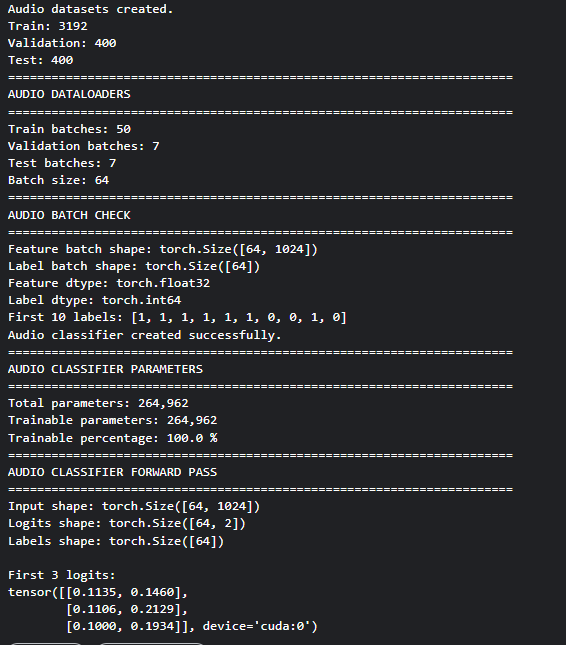

In [502]:
# Step 7E.3.1 — Reset the training DataLoader


# ============================================================
# RESET AUDIO TRAIN DATALOADER BEFORE REAL TRAINING
# ============================================================

audio_generator = torch.Generator()
audio_generator.manual_seed(SEED)

audio_train_loader = DataLoader(
    audio_train_dataset,
    batch_size=AUDIO_CLASSIFIER_BATCH_SIZE,
    shuffle=True,
    generator=audio_generator
)

print("Audio training DataLoader reset.")
print("Seed:", SEED)
print("Training batches:", len(audio_train_loader))


# Use standard Cross-Entropy Loss:


criterion = nn.CrossEntropyLoss()

print("Loss function:")
print(criterion)




# Step 7E.3.3 — Define optimizer and training settings

AUDIO_LEARNING_RATE = 1e-3
AUDIO_WEIGHT_DECAY = 1e-4

AUDIO_MAX_EPOCHS = 30
AUDIO_EARLY_STOPPING_PATIENCE = 5

audio_optimizer = torch.optim.AdamW(
    audio_classifier.parameters(),
    lr=AUDIO_LEARNING_RATE,
    weight_decay=AUDIO_WEIGHT_DECAY
)

print("=" * 70)
print("AUDIO TRAINING CONFIGURATION")
print("=" * 70)

print("Learning rate:", AUDIO_LEARNING_RATE)
print("Weight decay:", AUDIO_WEIGHT_DECAY)
print("Maximum epochs:", AUDIO_MAX_EPOCHS)
print(
    "Early stopping patience:",
    AUDIO_EARLY_STOPPING_PATIENCE
)
print(
    "Model selection metric: Validation Macro-F1"
)


# Step 7E.3.4 — Define audio metric function

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


def calculate_audio_metrics(
    y_true,
    y_pred
):

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }



# Step 7E.3.5 — Define validation function

def evaluate_audio_classifier(
    model,
    dataloader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0

    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.inference_mode():

        for features, labels in dataloader:

            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)

            loss = criterion(
                logits,
                labels
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            total_loss += loss.item()

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    average_loss = (
        total_loss /
        len(dataloader)
    )

    metrics = calculate_audio_metrics(
        all_labels,
        all_predictions
    )

    return (
        average_loss,
        metrics,
        np.array(all_predictions),
        np.array(all_labels),
        np.array(all_probabilities)
    )



# Step 7E.3.6 — Define checkpoint location

BEST_AUDIO_MODEL_PATH = (
    PROJECT_ROOT /
    "models" /
    "xlsr_audio_classifier_best.pt"
)

best_audio_val_f1 = -1.0
best_audio_epoch = 0
audio_epochs_without_improvement = 0

print(
    "Best audio model will be saved to:"
)

print(
    BEST_AUDIO_MODEL_PATH
)



# Step 7E.3.7 — Evaluate the untrained audio classifier

(
    initial_audio_val_loss,
    initial_audio_val_metrics,
    _,
    _,
    _
) = evaluate_audio_classifier(
    model=audio_classifier,
    dataloader=audio_val_loader,
    criterion=criterion,
    device=device
)

print("=" * 70)
print("INITIAL UNTRAINED AUDIO VALIDATION PERFORMANCE")
print("=" * 70)

print(
    "Validation Loss:",
    round(
        initial_audio_val_loss,
        4
    )
)

print(
    "Accuracy:",
    round(
        initial_audio_val_metrics[
            "accuracy"
        ],
        4
    )
)

print(
    "Macro Precision:",
    round(
        initial_audio_val_metrics[
            "precision_macro"
        ],
        4
    )
)

print(
    "Macro Recall:",
    round(
        initial_audio_val_metrics[
            "recall_macro"
        ],
        4
    )
)

print(
    "Macro F1:",
    round(
        initial_audio_val_metrics[
            "f1_macro"
        ],
        4
    )
)

Audio training DataLoader reset.
Seed: 42
Training batches: 50
Loss function:
CrossEntropyLoss()
AUDIO TRAINING CONFIGURATION
Learning rate: 0.001
Weight decay: 0.0001
Maximum epochs: 30
Early stopping patience: 5
Model selection metric: Validation Macro-F1
Best audio model will be saved to:
/kaggle/working/bangla_multimodal_thesis/models/xlsr_audio_classifier_best.pt
INITIAL UNTRAINED AUDIO VALIDATION PERFORMANCE
Validation Loss: 0.6899
Accuracy: 0.5625
Macro Precision: 0.6565
Macro Recall: 0.5625
Macro F1: 0.4852


**Step 7E.4 — Train the Audio-Only XLS-R Classifier**

In [503]:
# Step 7E.4.1 — Define one training epoch

from tqdm.auto import tqdm


def train_audio_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0

    all_predictions = []
    all_labels = []

    progress_bar = tqdm(
        dataloader,
        desc="Audio Training",
        leave=False
    )

    for features, labels in progress_bar:

        features = features.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(features)

        # Loss
        loss = criterion(
            logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Small safety measure
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update classifier weights
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = (
        total_loss /
        len(dataloader)
    )

    metrics = calculate_audio_metrics(
        all_labels,
        all_predictions
    )

    return average_loss, metrics



# Step 7E.4.2 — Initialize training history

audio_training_history = []

best_audio_val_f1 = -1.0
best_audio_val_loss = float("inf")

best_audio_epoch = 0

audio_epochs_without_improvement = 0

print("Audio training state initialized.")


# Step 7E.4.3 — Train epoch by epoch

import time

print("=" * 85)
print("XLS-R AUDIO-ONLY SENTIMENT CLASSIFIER TRAINING")
print("=" * 85)

audio_training_start = time.time()


for epoch in range(
    1,
    AUDIO_MAX_EPOCHS + 1
):

    print("\n" + "=" * 85)
    print(
        f"EPOCH {epoch}/{AUDIO_MAX_EPOCHS}"
    )
    print("=" * 85)

    epoch_start = time.time()

    # ==================================================
    # TRAIN
    # ==================================================

    train_loss, train_metrics = (
        train_audio_one_epoch(
            model=audio_classifier,
            dataloader=audio_train_loader,
            criterion=criterion,
            optimizer=audio_optimizer,
            device=device
        )
    )

    # ==================================================
    # VALIDATE
    # ==================================================

    (
        val_loss,
        val_metrics,
        val_predictions,
        val_labels,
        val_probabilities
    ) = evaluate_audio_classifier(
        model=audio_classifier,
        dataloader=audio_val_loader,
        criterion=criterion,
        device=device
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    current_val_f1 = (
        val_metrics["f1_macro"]
    )

    # ==================================================
    # MODEL SELECTION
    #
    # Primary:
    #   Validation Macro-F1
    #
    # Tie-break:
    #   Lower validation loss
    # ==================================================

    f1_improved = (
        current_val_f1 >
        best_audio_val_f1 + 1e-8
    )

    f1_tied = (
        abs(
            current_val_f1 -
            best_audio_val_f1
        ) <= 1e-8
    )

    loss_improved_on_tie = (
        f1_tied
        and
        val_loss < best_audio_val_loss
    )

    if (
        f1_improved
        or
        loss_improved_on_tie
    ):

        best_audio_val_f1 = (
            current_val_f1
        )

        best_audio_val_loss = (
            val_loss
        )

        best_audio_epoch = epoch

        audio_epochs_without_improvement = 0

        torch.save(
            audio_classifier.state_dict(),
            BEST_AUDIO_MODEL_PATH
        )

        if f1_improved:
            status = "BEST MODEL SAVED — F1 improved"
        else:
            status = (
                "BEST MODEL SAVED — "
                "same F1, lower validation loss"
            )

    else:

        audio_epochs_without_improvement += 1

        status = (
            "No improvement "
            f"({audio_epochs_without_improvement}/"
            f"{AUDIO_EARLY_STOPPING_PATIENCE})"
        )

    # ==================================================
    # SAVE HISTORY
    # ==================================================

    audio_training_history.append({

        "epoch": epoch,

        "train_loss": train_loss,
        "train_accuracy":
            train_metrics["accuracy"],
        "train_precision_macro":
            train_metrics["precision_macro"],
        "train_recall_macro":
            train_metrics["recall_macro"],
        "train_f1_macro":
            train_metrics["f1_macro"],

        "val_loss": val_loss,
        "val_accuracy":
            val_metrics["accuracy"],
        "val_precision_macro":
            val_metrics["precision_macro"],
        "val_recall_macro":
            val_metrics["recall_macro"],
        "val_f1_macro":
            val_metrics["f1_macro"],

        "epoch_time_seconds":
            epoch_time
    })

    # ==================================================
    # DISPLAY RESULTS
    # ==================================================

    print("\nTRAINING RESULTS")
    print("-" * 45)

    print(
        f"Loss:            "
        f"{train_loss:.4f}"
    )

    print(
        f"Accuracy:        "
        f"{train_metrics['accuracy']:.4f}"
    )

    print(
        f"Macro F1:        "
        f"{train_metrics['f1_macro']:.4f}"
    )


    print("\nVALIDATION RESULTS")
    print("-" * 45)

    print(
        f"Loss:            "
        f"{val_loss:.4f}"
    )

    print(
        f"Accuracy:        "
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        f"Macro Precision: "
        f"{val_metrics['precision_macro']:.4f}"
    )

    print(
        f"Macro Recall:    "
        f"{val_metrics['recall_macro']:.4f}"
    )

    print(
        f"Macro F1:        "
        f"{val_metrics['f1_macro']:.4f}"
    )


    print("\nSTATUS")
    print("-" * 45)

    print(status)

    print(
        "Best validation Macro-F1:",
        round(
            best_audio_val_f1,
            4
        )
    )

    print(
        "Best validation loss:",
        round(
            best_audio_val_loss,
            4
        )
    )

    print(
        "Best epoch:",
        best_audio_epoch
    )

    print(
        "Epoch time:",
        round(
            epoch_time,
            2
        ),
        "seconds"
    )

    # ==================================================
    # EARLY STOPPING
    # ==================================================

    if (
        audio_epochs_without_improvement
        >= AUDIO_EARLY_STOPPING_PATIENCE
    ):

        print("\n" + "=" * 85)

        print(
            "EARLY STOPPING TRIGGERED "
            f"AFTER EPOCH {epoch}"
        )

        print("=" * 85)

        break


audio_total_training_time = (
    time.time() -
    audio_training_start
)


print("\n" + "=" * 85)
print("AUDIO TRAINING COMPLETE")
print("=" * 85)

print(
    "Best epoch:",
    best_audio_epoch
)

print(
    "Best validation Macro-F1:",
    round(
        best_audio_val_f1,
        4
    )
)

print(
    "Best validation loss:",
    round(
        best_audio_val_loss,
        4
    )
)

print(
    "Total training time:",
    round(
        audio_total_training_time,
        2
    ),
    "seconds"
)

print(
    "Best checkpoint:",
    BEST_AUDIO_MODEL_PATH
)



# Step 7E.4.4 — Display the training history

audio_history_df = pd.DataFrame(
    audio_training_history
)

display(
    audio_history_df[
        [
            "epoch",
            "train_loss",
            "train_accuracy",
            "train_f1_macro",
            "val_loss",
            "val_accuracy",
            "val_f1_macro",
            "epoch_time_seconds"
        ]
    ].round(4)
)




# Step 7E.4.5 — Save training history

AUDIO_HISTORY_PATH = (
    PROJECT_ROOT /
    "results" /
    "xlsr_audio_training_history.csv"
)

audio_history_df.to_csv(
    AUDIO_HISTORY_PATH,
    index=False
)

print(
    "Audio training history saved:"
)

print(
    AUDIO_HISTORY_PATH
)

Audio training state initialized.
XLS-R AUDIO-ONLY SENTIMENT CLASSIFIER TRAINING

EPOCH 1/30


Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]


TRAINING RESULTS
---------------------------------------------
Loss:            0.7236
Accuracy:        0.5661
Macro F1:        0.5650

VALIDATION RESULTS
---------------------------------------------
Loss:            0.6270
Accuracy:        0.6150
Macro Precision: 0.6332
Macro Recall:    0.6150
Macro F1:        0.6014

STATUS
---------------------------------------------
BEST MODEL SAVED — F1 improved
Best validation Macro-F1: 0.6014
Best validation loss: 0.627
Best epoch: 1
Epoch time: 0.27 seconds

EPOCH 2/30


Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]


TRAINING RESULTS
---------------------------------------------
Loss:            0.6267
Accuracy:        0.6476
Macro F1:        0.6473

VALIDATION RESULTS
---------------------------------------------
Loss:            0.6809
Accuracy:        0.6275
Macro Precision: 0.6590
Macro Recall:    0.6275
Macro F1:        0.6081

STATUS
---------------------------------------------
BEST MODEL SAVED — F1 improved
Best validation Macro-F1: 0.6081
Best validation loss: 0.6809
Best epoch: 2
Epoch time: 0.24 seconds

EPOCH 3/30


Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]

... (53 outputs left out)

Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]


TRAINING RESULTS
---------------------------------------------
Loss:            0.3109
Accuracy:        0.8694
Macro F1:        0.8694

VALIDATION RESULTS
---------------------------------------------
Loss:            0.2517
Accuracy:        0.8925
Macro Precision: 0.8930
Macro Recall:    0.8925
Macro F1:        0.8925

STATUS
---------------------------------------------
BEST MODEL SAVED — F1 improved
Best validation Macro-F1: 0.8925
Best validation loss: 0.2517
Best epoch: 30
Epoch time: 0.25 seconds

AUDIO TRAINING COMPLETE
Best epoch: 30
Best validation Macro-F1: 0.8925
Best validation loss: 0.2517
Total training time: 7.61 seconds
Best checkpoint: /kaggle/working/bangla_multimodal_thesis/models/xlsr_audio_classifier_best.pt


,epoch,train_loss,train_accuracy,train_f1_macro,val_loss,val_accuracy,val_f1_macro,epoch_time_seconds
0,1,0.7236,0.5661,0.5650,0.6270,0.6150,0.6014,0.2652
1,2,0.6267,0.6476,0.6473,0.6809,0.6275,0.6081,0.2398
2,3,0.6060,0.6613,0.6613,0.5901,0.6525,0.6278,0.2460
3,4,0.5856,0.6732,0.6730,0.5747,0.6700,0.6679,0.2689
4,5,0.6062,0.6629,0.6628,0.5693,0.6700,0.6673,0.2396
5,6,0.5612,0.6798,0.6795,0.5658,0.6625,0.6569,0.2443
6,7,0.5385,0.7137,0.7135,0.5115,0.7200,0.7152,0.2406
7,8,0.5272,0.7206,0.7202,0.5034,0.7275,0.7275,0.2475
8,9,0.5029,0.7481,0.7481,0.4714,0.7700,0.7692,0.2594
9,10,0.4821,0.7553,0.7553,0.4373,0.7775,0.7775,0.2531


Audio training history saved:
/kaggle/working/bangla_multimodal_thesis/results/xlsr_audio_training_history.csv


**Step 7E.5 — Final Locked Test Evaluation of the Audio-Only Model**

Best audio checkpoint loaded successfully.
Best epoch: 30
Best validation Macro-F1: 0.8924670680395871
Best validation loss: 0.25174124113151003
FINAL AUDIO-ONLY TEST PERFORMANCE
Test Loss: 0.3054
Accuracy: 0.8925
Macro Precision: 0.8942
Macro Recall: 0.8925
Macro F1: 0.8924
Weighted Precision: 0.8942
Weighted Recall: 0.8925
Weighted F1: 0.8924
AUDIO TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.8685    0.9250    0.8959       200
    Positive     0.9198    0.8600    0.8889       200

    accuracy                         0.8925       400
   macro avg     0.8942    0.8925    0.8924       400
weighted avg     0.8942    0.8925    0.8924       400

Audio Confusion Matrix:
[[185  15]
 [ 28 172]]


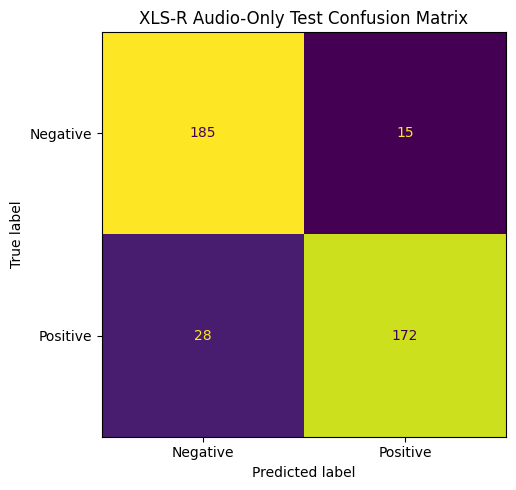

Saved: /kaggle/working/bangla_multimodal_thesis/figures/xlsr_audio_test_confusion_matrix.png
Audio ROC-AUC: 0.9642


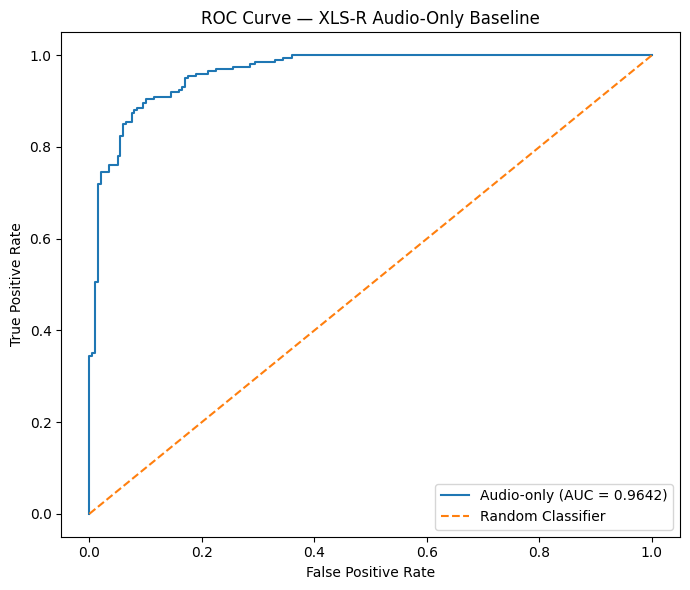

Saved: /kaggle/working/bangla_multimodal_thesis/figures/xlsr_audio_test_roc_curve.png


,sentence_number,sentence_id,sentiment,label,speaker,filename,audio_path,audio_duration,original_sample_rate,predicted_label,predicted_sentiment,prob_negative,prob_positive,confidence,correct
0,4,si_0004,Positive,1,f1,0004_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.777833,48000,0,Negative,0.835045,0.164955,0.835045,False
1,4,si_0004,Positive,1,f2,0004_f2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.480000,48000,1,Positive,0.094292,0.905708,0.905708,True
2,4,si_0004,Positive,1,m1,0004_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,4.000136,44100,1,Positive,0.018426,0.981574,0.981574,True
3,4,si_0004,Positive,1,m2,0004_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,5.007415,44100,1,Positive,0.083471,0.916529,0.916529,True
4,13,si_0013,Positive,1,f1,0013_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.660227,44100,1,Positive,0.323672,0.676328,0.676328,True
5,13,si_0013,Positive,1,f2,0013_f2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.264000,48000,1,Positive,0.071563,0.928437,0.928437,True
6,13,si_0013,Positive,1,m1,0013_m1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.869410,44100,1,Positive,0.041998,0.958002,0.958002,True
7,13,si_0013,Positive,1,m2,0013_m2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,3.831905,44100,1,Positive,0.132405,0.867595,0.867595,True
8,19,si_0019,Positive,1,f1,0019_f1.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,4.156984,44100,1,Positive,0.373005,0.626995,0.626995,True
9,19,si_0019,Positive,1,f2,0019_f2.mp3,/kaggle/input/datasets/marakibsarker/banglamus...,2.448000,48000,1,Positive,0.251272,0.748728,0.748728,True


Number of misclassified test recordings: 43


,sentence_id,speaker,filename,sentiment,predicted_sentiment,prob_negative,prob_positive,confidence
208,si_0550,f1,0550_f1.mp3,Negative,Positive,0.107729,0.892271,0.892271
395,si_0997,m2,0997_m2.mp3,Negative,Positive,0.110881,0.889119,0.889119
100,si_0286,f1,0286_f1.mp3,Positive,Negative,0.842884,0.157116,0.842884
0,si_0004,f1,0004_f1.mp3,Positive,Negative,0.835045,0.164955,0.835045
197,si_0483,f2,0483_f2.mp3,Positive,Negative,0.826175,0.173825,0.826175
387,si_0989,m2,0989_m2.mp3,Negative,Positive,0.193902,0.806098,0.806098
144,si_0398,f1,0398_f1.mp3,Positive,Negative,0.796674,0.203325,0.796674
198,si_0483,m1,0483_m1.mp3,Positive,Negative,0.783076,0.216924,0.783076
156,si_0414,f1,0414_f1.mp3,Positive,Negative,0.760188,0.239812,0.760188
65,si_0193,f2,0193_f2.mp3,Positive,Negative,0.741948,0.258052,0.741948


,speaker,n_samples,accuracy,precision_macro,recall_macro,f1_macro
0,f1,100,0.81,0.8111,0.81,0.8098
1,f2,100,0.86,0.8695,0.86,0.8591
2,m1,100,0.93,0.9343,0.93,0.9298
3,m2,100,0.97,0.9717,0.97,0.9700


,model,modality,test_loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc,best_epoch
0,XLS-R Audio Classifier,Audio,0.30541,0.8925,0.894165,0.8925,0.892386,0.894165,0.8925,0.892386,0.9642,30


Saved predictions: /kaggle/working/bangla_multimodal_thesis/results/xlsr_audio_test_predictions.csv
Saved metrics: /kaggle/working/bangla_multimodal_thesis/results/xlsr_audio_test_metrics.csv


In [504]:
# Step 7E.5.1 — Load the best saved audio checkpoint

best_audio_state_dict = torch.load(
    BEST_AUDIO_MODEL_PATH,
    map_location=device
)

audio_classifier.load_state_dict(
    best_audio_state_dict
)

audio_classifier = audio_classifier.to(device)
audio_classifier.eval()

print("Best audio checkpoint loaded successfully.")
print("Best epoch:", best_audio_epoch)
print("Best validation Macro-F1:", best_audio_val_f1)
print("Best validation loss:", best_audio_val_loss)



# Step 7E.5.2 — Evaluate on the untouched audio test set
(
    audio_test_loss,
    audio_test_metrics,
    audio_test_predictions,
    audio_test_labels,
    audio_test_probabilities
) = evaluate_audio_classifier(
    model=audio_classifier,
    dataloader=audio_test_loader,
    criterion=criterion,
    device=device
)

print("=" * 70)
print("FINAL AUDIO-ONLY TEST PERFORMANCE")
print("=" * 70)

print("Test Loss:", round(audio_test_loss, 4))
print("Accuracy:", round(audio_test_metrics["accuracy"], 4))
print("Macro Precision:", round(audio_test_metrics["precision_macro"], 4))
print("Macro Recall:", round(audio_test_metrics["recall_macro"], 4))
print("Macro F1:", round(audio_test_metrics["f1_macro"], 4))



# Step 7E.5.3 — Calculate weighted metrics

from sklearn.metrics import precision_score, recall_score, f1_score

audio_weighted_precision = precision_score(
    audio_test_labels,
    audio_test_predictions,
    average="weighted",
    zero_division=0
)

audio_weighted_recall = recall_score(
    audio_test_labels,
    audio_test_predictions,
    average="weighted",
    zero_division=0
)

audio_weighted_f1 = f1_score(
    audio_test_labels,
    audio_test_predictions,
    average="weighted",
    zero_division=0
)

print("Weighted Precision:", round(audio_weighted_precision, 4))
print("Weighted Recall:", round(audio_weighted_recall, 4))
print("Weighted F1:", round(audio_weighted_f1, 4))



# Step 7E.5.4 — Classification report

from sklearn.metrics import classification_report

audio_report = classification_report(
    audio_test_labels,
    audio_test_predictions,
    target_names=["Negative", "Positive"],
    digits=4
)

print("=" * 70)
print("AUDIO TEST CLASSIFICATION REPORT")
print("=" * 70)
print(audio_report)



# Step 7E.5.5 — Confusion matrix

from sklearn.metrics import confusion_matrix

audio_cm = confusion_matrix(
    audio_test_labels,
    audio_test_predictions
)

print("Audio Confusion Matrix:")
print(audio_cm)



from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=audio_cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title("XLS-R Audio-Only Test Confusion Matrix")
plt.tight_layout()

AUDIO_CM_PATH = (
    PROJECT_ROOT / "figures" / "xlsr_audio_test_confusion_matrix.png"
)

plt.savefig(
    AUDIO_CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", AUDIO_CM_PATH)



# Step 7E.5.7 — ROC-AUC

from sklearn.metrics import roc_auc_score

audio_positive_probabilities = audio_test_probabilities[:, 1]

audio_roc_auc = roc_auc_score(
    audio_test_labels,
    audio_positive_probabilities
)

print("Audio ROC-AUC:", round(audio_roc_auc, 4))



# Step 7E.5.8 — ROC curve

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    audio_test_labels,
    audio_positive_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Audio-only (AUC = {audio_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — XLS-R Audio-Only Baseline")
plt.legend()
plt.tight_layout()

AUDIO_ROC_PATH = (
    PROJECT_ROOT / "figures" / "xlsr_audio_test_roc_curve.png"
)

plt.savefig(
    AUDIO_ROC_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", AUDIO_ROC_PATH)



# Step 7E.5.9 — Build the full audio test prediction table

audio_test_results = (
    audio_test_df[
        [
            "sentence_number",
            "sentence_id",
            "sentiment",
            "label",
            "speaker",
            "filename",
            "audio_path",
            "audio_duration",
            "original_sample_rate"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

audio_test_results["predicted_label"] = audio_test_predictions
audio_test_results["predicted_sentiment"] = (
    audio_test_results["predicted_label"].map(id2label)
)

audio_test_results["prob_negative"] = audio_test_probabilities[:, 0]
audio_test_results["prob_positive"] = audio_test_probabilities[:, 1]
audio_test_results["confidence"] = audio_test_probabilities.max(axis=1)

audio_test_results["correct"] = (
    audio_test_results["label"]
    == audio_test_results["predicted_label"]
)

display(audio_test_results.head(10))



# Step 7E.5.10 — Count misclassified recordings

audio_errors = (
    audio_test_results[
        audio_test_results["correct"] == False
    ]
    .copy()
    .sort_values("confidence", ascending=False)
)

print("Number of misclassified test recordings:", len(audio_errors))

if len(audio_errors) > 0:
    display(
        audio_errors[
            [
                "sentence_id",
                "speaker",
                "filename",
                "sentiment",
                "predicted_sentiment",
                "prob_negative",
                "prob_positive",
                "confidence"
            ]
        ]
    )
else:
    print("No misclassified audio test samples.")



# Step 7E.5.11 — Speaker-wise performance analysis

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

speaker_results = []

for speaker in sorted(audio_test_results["speaker"].unique()):

    speaker_df = audio_test_results[
        audio_test_results["speaker"] == speaker
    ]

    y_true = speaker_df["label"].to_numpy()
    y_pred = speaker_df["predicted_label"].to_numpy()

    speaker_results.append({
        "speaker": speaker,
        "n_samples": len(speaker_df),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    })

speaker_results_df = pd.DataFrame(speaker_results)

display(speaker_results_df.round(4))


# Step 7E.5.12 — Save predictions and final metrics


AUDIO_TEST_RESULTS_PATH = (
    PROJECT_ROOT / "results" / "xlsr_audio_test_predictions.csv"
)

audio_test_results.to_csv(
    AUDIO_TEST_RESULTS_PATH,
    index=False,
    encoding="utf-8-sig"
)

audio_metrics_df = pd.DataFrame([
    {
        "model": "XLS-R Audio Classifier",
        "modality": "Audio",
        "test_loss": audio_test_loss,
        "accuracy": audio_test_metrics["accuracy"],
        "precision_macro": audio_test_metrics["precision_macro"],
        "recall_macro": audio_test_metrics["recall_macro"],
        "f1_macro": audio_test_metrics["f1_macro"],
        "precision_weighted": audio_weighted_precision,
        "recall_weighted": audio_weighted_recall,
        "f1_weighted": audio_weighted_f1,
        "roc_auc": audio_roc_auc,
        "best_epoch": best_audio_epoch
    }
])

AUDIO_METRICS_PATH = (
    PROJECT_ROOT / "results" / "xlsr_audio_test_metrics.csv"
)

audio_metrics_df.to_csv(
    AUDIO_METRICS_PATH,
    index=False
)

display(audio_metrics_df)

print("Saved predictions:", AUDIO_TEST_RESULTS_PATH)
print("Saved metrics:", AUDIO_METRICS_PATH)

**Step 8A.1 — Reconstruct the fine-tuned BanglaBERT model**

In [505]:
import gc
import torch
import random
import numpy as np

from transformers import AutoModelForSequenceClassification

print("=" * 75)
print("RELOADING FINE-TUNED BANGLABERT")
print("=" * 75)

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ------------------------------------------------------------
# Model architecture
# ------------------------------------------------------------

text_model_for_embeddings = (
    AutoModelForSequenceClassification
    .from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label=id2label,
        label2id=label2id
    )
)


# ------------------------------------------------------------
# Load OUR fine-tuned checkpoint
# ------------------------------------------------------------

text_checkpoint = torch.load(
    BEST_TEXT_MODEL_PATH,
    map_location="cpu"
)

text_model_for_embeddings.load_state_dict(
    text_checkpoint
)

text_model_for_embeddings = (
    text_model_for_embeddings.to(device)
)

text_model_for_embeddings.eval()


print("\nFine-tuned checkpoint loaded.")

print(
    "Model class:",
    text_model_for_embeddings
    .__class__.__name__
)

print(
    "Checkpoint:",
    BEST_TEXT_MODEL_PATH
)

print(
    "Encoder hidden size:",
    text_model_for_embeddings
    .config.hidden_size
)

print(
    "Number of labels:",
    text_model_for_embeddings
    .config.num_labels
)



# Step 8A.2 — Verify that the loaded checkpoint reproduces validation behavior

(
    reload_val_loss,
    reload_val_metrics,
    _,
    _,
    _
) = evaluate_model(
    model=text_model_for_embeddings,
    dataloader=val_loader,
    device=device
)

print("=" * 75)
print("RELOADED TEXT CHECKPOINT VERIFICATION")
print("=" * 75)

print(
    "Validation Loss:",
    round(reload_val_loss, 4)
)

print(
    "Validation Accuracy:",
    round(
        reload_val_metrics["accuracy"],
        4
    )
)

print(
    "Validation Macro-F1:",
    round(
        reload_val_metrics["f1_macro"],
        4
    )
)



RELOADING FINE-TUNED BANGLABERT


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi


Fine-tuned checkpoint loaded.
Model class: ElectraForSequenceClassification
Checkpoint: /kaggle/working/bangla_multimodal_thesis/models/banglabert_text_best.pt
Encoder hidden size: 768
Number of labels: 2


Validation:   0%|          | 0/7 [00:00<?, ?it/s]

RELOADED TEXT CHECKPOINT VERIFICATION
Validation Loss: 0.0143
Validation Accuracy: 1.0
Validation Macro-F1: 1.0


**Step 8A.3 — Test BanglaBERT embedding extraction on one batch**

In [506]:
# Step 8A.3.1 — Take one validation batch

# Take one validation batch
text_embedding_test_batch = next(
    iter(val_loader)
)

test_input_ids = (
    text_embedding_test_batch["input_ids"]
    .to(device)
)

test_attention_mask = (
    text_embedding_test_batch["attention_mask"]
    .to(device)
)

print("=" * 70)
print("TEXT EMBEDDING BATCH INPUT")
print("=" * 70)

print(
    "Input IDs shape:",
    test_input_ids.shape
)

print(
    "Attention mask shape:",
    test_attention_mask.shape
)



# Step 8A.3.2 — Pass the batch through the fine-tuned encoder

text_model_for_embeddings.eval()

with torch.inference_mode():

    encoder_outputs = (
        text_model_for_embeddings.electra(
            input_ids=test_input_ids,
            attention_mask=test_attention_mask,
            return_dict=True
        )
    )

text_hidden_states = (
    encoder_outputs.last_hidden_state
)

print("=" * 70)
print("BANGLABERT ENCODER OUTPUT")
print("=" * 70)

print(
    "Last hidden-state shape:",
    text_hidden_states.shape
)

print(
    "Hidden-state dtype:",
    text_hidden_states.dtype
)



# Step 8A.3.3 — Extract the [CLS] representation


cls_embeddings = (
    text_hidden_states[:, 0, :]
)

print("=" * 70)
print("TEXT [CLS] EMBEDDINGS")
print("=" * 70)

print(
    "Embedding shape:",
    cls_embeddings.shape
)

print(
    "Embedding dtype:",
    cls_embeddings.dtype
)

print(
    "Embedding mean:",
    round(
        float(cls_embeddings.mean()),
        6
    )
)

print(
    "Embedding std:",
    round(
        float(cls_embeddings.std()),
        6
    )
)

print(
    "NaN values:",
    torch.isnan(
        cls_embeddings
    ).sum().item()
)

print(
    "Infinite values:",
    torch.isinf(
        cls_embeddings
    ).sum().item()
)


TEXT EMBEDDING BATCH INPUT
Input IDs shape: torch.Size([16, 13])
Attention mask shape: torch.Size([16, 13])
BANGLABERT ENCODER OUTPUT
Last hidden-state shape: torch.Size([16, 13, 768])
Hidden-state dtype: torch.float32
TEXT [CLS] EMBEDDINGS
Embedding shape: torch.Size([16, 768])
Embedding dtype: torch.float32
Embedding mean: -0.020907
Embedding std: 0.480321
NaN values: 0
Infinite values: 0


**Step 8A.4 — Extract TRAIN Text Embeddings**

In [507]:
# Step 8A.4.1 — Define the extraction function
from tqdm.auto import tqdm

TEXT_EMBEDDING_BATCH_SIZE = 32


def extract_text_embeddings(
    dataframe,
    model,
    tokenizer,
    device,
    batch_size=32
):
    """
    Extract one 768-dimensional [CLS] embedding
    for each unique Bangla sentence.

    Uses the fine-tuned BanglaBERT/ELECTRA encoder.
    """

    model.eval()

    all_embeddings = []

    num_samples = len(dataframe)

    for start_idx in tqdm(
        range(0, num_samples, batch_size),
        desc="Extracting BanglaBERT embeddings"
    ):

        end_idx = min(
            start_idx + batch_size,
            num_samples
        )

        batch_df = dataframe.iloc[
            start_idx:end_idx
        ]

        texts = (
            batch_df["normalized_text"]
            .astype(str)
            .tolist()
        )

        # --------------------------------------------
        # TOKENIZE
        # --------------------------------------------

        encoded = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        input_ids = (
            encoded["input_ids"]
            .to(device)
        )

        attention_mask = (
            encoded["attention_mask"]
            .to(device)
        )

        # --------------------------------------------
        # FINE-TUNED BANGLABERT ENCODER
        # --------------------------------------------

        with torch.inference_mode():

            encoder_outputs = (
                model.electra(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    return_dict=True
                )
            )

        hidden_states = (
            encoder_outputs.last_hidden_state
        )

        # --------------------------------------------
        # [CLS] REPRESENTATION
        # --------------------------------------------

        cls_embeddings = (
            hidden_states[:, 0, :]
        )

        cls_embeddings = (
            cls_embeddings
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        all_embeddings.append(
            cls_embeddings
        )

    final_embeddings = np.concatenate(
        all_embeddings,
        axis=0
    )

    return final_embeddings





# Step 8A.4.2 — Extract the 798 training embeddings
print("=" * 75)
print("EXTRACTING TRAIN TEXT EMBEDDINGS")
print("=" * 75)

train_text_embeddings = extract_text_embeddings(
    dataframe=text_train_df,
    model=text_model_for_embeddings,
    tokenizer=tokenizer,
    device=device,
    batch_size=TEXT_EMBEDDING_BATCH_SIZE
)

print("\nExtraction complete.")

print(
    "Train text embedding shape:",
    train_text_embeddings.shape
)

print(
    "dtype:",
    train_text_embeddings.dtype
)

print(
    "Mean:",
    round(
        float(train_text_embeddings.mean()),
        6
    )
)

print(
    "Std:",
    round(
        float(train_text_embeddings.std()),
        6
    )
)

print(
    "NaN values:",
    np.isnan(
        train_text_embeddings
    ).sum()
)

print(
    "Infinite values:",
    np.isinf(
        train_text_embeddings
    ).sum()
)



# Step 8A.4.3 — Save the training embeddings

TEXT_EMBEDDING_DIR = (
    PROJECT_ROOT /
    "embeddings"
)

TEXT_EMBEDDING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_TEXT_EMBEDDING_PATH = (
    TEXT_EMBEDDING_DIR /
    "banglabert_train_embeddings.npy"
)

np.save(
    TRAIN_TEXT_EMBEDDING_PATH,
    train_text_embeddings
)


TRAIN_TEXT_METADATA_PATH = (
    TEXT_EMBEDDING_DIR /
    "banglabert_train_metadata.csv"
)

text_train_df.to_csv(
    TRAIN_TEXT_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 75)
print("TRAIN TEXT EMBEDDINGS SAVED")
print("=" * 75)

print(
    "Embedding path:",
    TRAIN_TEXT_EMBEDDING_PATH
)

print(
    "Shape:",
    train_text_embeddings.shape
)

print(
    "File size:",
    round(
        TRAIN_TEXT_EMBEDDING_PATH
        .stat()
        .st_size
        / (1024 ** 2),
        2
    ),
    "MB"
)

print(
    "Metadata path:",
    TRAIN_TEXT_METADATA_PATH
)


EXTRACTING TRAIN TEXT EMBEDDINGS


Extracting BanglaBERT embeddings:   0%|          | 0/25 [00:00<?, ?it/s]


Extraction complete.
Train text embedding shape: (798, 768)
dtype: float32
Mean: -0.028881
Std: 0.485865
NaN values: 0
Infinite values: 0
TRAIN TEXT EMBEDDINGS SAVED
Embedding path: /kaggle/working/bangla_multimodal_thesis/embeddings/banglabert_train_embeddings.npy
Shape: (798, 768)
File size: 2.34 MB
Metadata path: /kaggle/working/bangla_multimodal_thesis/embeddings/banglabert_train_metadata.csv


**Step 8A — Finish Validation + Test Text Embeddings and Verify All 998**

In [508]:
# Step 8A.5 — Extract validation text embeddings
print("=" * 75)
print("EXTRACTING VALIDATION TEXT EMBEDDINGS")
print("=" * 75)

val_text_embeddings = extract_text_embeddings(
    dataframe=text_val_df,
    model=text_model_for_embeddings,
    tokenizer=tokenizer,
    device=device,
    batch_size=TEXT_EMBEDDING_BATCH_SIZE
)

print("\nValidation text embedding shape:",
      val_text_embeddings.shape)

print("dtype:", val_text_embeddings.dtype)

print(
    "Mean:",
    round(float(val_text_embeddings.mean()), 6)
)

print(
    "Std:",
    round(float(val_text_embeddings.std()), 6)
)

print(
    "NaN values:",
    np.isnan(val_text_embeddings).sum()
)

print(
    "Infinite values:",
    np.isinf(val_text_embeddings).sum()
)



# Step 8A.6 — Save validation embeddings
VAL_TEXT_EMBEDDING_PATH = (
    TEXT_EMBEDDING_DIR /
    "banglabert_validation_embeddings.npy"
)

VAL_TEXT_METADATA_PATH = (
    TEXT_EMBEDDING_DIR /
    "banglabert_validation_metadata.csv"
)

np.save(
    VAL_TEXT_EMBEDDING_PATH,
    val_text_embeddings
)

text_val_df.to_csv(
    VAL_TEXT_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Validation embeddings saved.")
print("Path:", VAL_TEXT_EMBEDDING_PATH)

print(
    "File size:",
    round(
        VAL_TEXT_EMBEDDING_PATH.stat().st_size
        / (1024 ** 2),
        2
    ),
    "MB"
)




# Step 8A.7 — Extract test text embeddings

print("=" * 75)
print("EXTRACTING TEST TEXT EMBEDDINGS")
print("=" * 75)

test_text_embeddings = extract_text_embeddings(
    dataframe=text_test_df,
    model=text_model_for_embeddings,
    tokenizer=tokenizer,
    device=device,
    batch_size=TEXT_EMBEDDING_BATCH_SIZE
)

print("\nTest text embedding shape:",
      test_text_embeddings.shape)

print("dtype:", test_text_embeddings.dtype)

print(
    "Mean:",
    round(float(test_text_embeddings.mean()), 6)
)

print(
    "Std:",
    round(float(test_text_embeddings.std()), 6)
)

print(
    "NaN values:",
    np.isnan(test_text_embeddings).sum()
)

print(
    "Infinite values:",
    np.isinf(test_text_embeddings).sum()
)




# Step 8A.8 — Save test embeddings
TEST_TEXT_EMBEDDING_PATH = (
    TEXT_EMBEDDING_DIR /
    "banglabert_test_embeddings.npy"
)

TEST_TEXT_METADATA_PATH = (
    TEXT_EMBEDDING_DIR /
    "banglabert_test_metadata.csv"
)

np.save(
    TEST_TEXT_EMBEDDING_PATH,
    test_text_embeddings
)

text_test_df.to_csv(
    TEST_TEXT_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Test embeddings saved.")
print("Path:", TEST_TEXT_EMBEDDING_PATH)
print(
    "File size:",
    round(
        TEST_TEXT_EMBEDDING_PATH.stat().st_size
        / (1024 ** 2),
        2
    ),
    "MB"
)



# Step 8A.9 — Reload everything from disk

train_text_emb_check = np.load(
    TRAIN_TEXT_EMBEDDING_PATH
)

val_text_emb_check = np.load(
    VAL_TEXT_EMBEDDING_PATH
)

test_text_emb_check = np.load(
    TEST_TEXT_EMBEDDING_PATH
)


train_text_meta_check = pd.read_csv(
    TRAIN_TEXT_METADATA_PATH
)

val_text_meta_check = pd.read_csv(
    VAL_TEXT_METADATA_PATH
)

test_text_meta_check = pd.read_csv(
    TEST_TEXT_METADATA_PATH
)



# Step 8A.10 — Full text embedding integrity check

print("=" * 75)
print("BANGLABERT TEXT EMBEDDING INTEGRITY CHECK")
print("=" * 75)

print("\nEmbedding shapes:")
print("Train:", train_text_emb_check.shape)
print("Validation:", val_text_emb_check.shape)
print("Test:", test_text_emb_check.shape)

print("\nMetadata rows:")
print("Train:", len(train_text_meta_check))
print("Validation:", len(val_text_meta_check))
print("Test:", len(test_text_meta_check))


# --------------------------------------------------
# Embedding ↔ metadata length
# --------------------------------------------------

train_length_match = (
    len(train_text_emb_check)
    ==
    len(train_text_meta_check)
)

val_length_match = (
    len(val_text_emb_check)
    ==
    len(val_text_meta_check)
)

test_length_match = (
    len(test_text_emb_check)
    ==
    len(test_text_meta_check)
)

print("\nEmbedding ↔ metadata length match:")
print("Train:", train_length_match)
print("Validation:", val_length_match)
print("Test:", test_length_match)


# --------------------------------------------------
# NaN / Inf
# --------------------------------------------------

print("\nNaN values:")
print(
    "Train:",
    np.isnan(train_text_emb_check).sum()
)
print(
    "Validation:",
    np.isnan(val_text_emb_check).sum()
)
print(
    "Test:",
    np.isnan(test_text_emb_check).sum()
)

print("\nInfinite values:")
print(
    "Train:",
    np.isinf(train_text_emb_check).sum()
)
print(
    "Validation:",
    np.isinf(val_text_emb_check).sum()
)
print(
    "Test:",
    np.isinf(test_text_emb_check).sum()
)


# --------------------------------------------------
# Sentence-ID ordering
# --------------------------------------------------

train_order_match = (
    train_text_meta_check["sentence_id"]
    .astype(str)
    .tolist()
    ==
    text_train_df["sentence_id"]
    .astype(str)
    .tolist()
)

val_order_match = (
    val_text_meta_check["sentence_id"]
    .astype(str)
    .tolist()
    ==
    text_val_df["sentence_id"]
    .astype(str)
    .tolist()
)

test_order_match = (
    test_text_meta_check["sentence_id"]
    .astype(str)
    .tolist()
    ==
    text_test_df["sentence_id"]
    .astype(str)
    .tolist()
)

print("\nMetadata row-order match:")
print("Train:", train_order_match)
print("Validation:", val_order_match)
print("Test:", test_order_match)


# --------------------------------------------------
# Unique sentence IDs
# --------------------------------------------------

print("\nUnique sentences:")
print(
    "Train:",
    train_text_meta_check[
        "sentence_id"
    ].nunique()
)

print(
    "Validation:",
    val_text_meta_check[
        "sentence_id"
    ].nunique()
)

print(
    "Test:",
    test_text_meta_check[
        "sentence_id"
    ].nunique()
)


# --------------------------------------------------
# Total
# --------------------------------------------------

total_text_embeddings = (
    len(train_text_emb_check)
    +
    len(val_text_emb_check)
    +
    len(test_text_emb_check)
)

print("\nTotal text embeddings:")
print(total_text_embeddings)

print("Expected:")
print(998)



# Step 8A.11 — Final automatic pass/fail
text_embedding_checks_passed = (

    train_text_emb_check.shape
    == (798, 768)

    and

    val_text_emb_check.shape
    == (100, 768)

    and

    test_text_emb_check.shape
    == (100, 768)

    and

    total_text_embeddings
    == 998

    and

    train_length_match

    and

    val_length_match

    and

    test_length_match

    and

    train_order_match

    and

    val_order_match

    and

    test_order_match

    and

    np.isnan(
        train_text_emb_check
    ).sum() == 0

    and

    np.isnan(
        val_text_emb_check
    ).sum() == 0

    and

    np.isnan(
        test_text_emb_check
    ).sum() == 0

    and

    np.isinf(
        train_text_emb_check
    ).sum() == 0

    and

    np.isinf(
        val_text_emb_check
    ).sum() == 0

    and

    np.isinf(
        test_text_emb_check
    ).sum() == 0
)


print("\n" + "=" * 75)

if text_embedding_checks_passed:

    print(
        "FINAL STATUS: ALL TEXT EMBEDDING CHECKS PASSED"
    )

else:

    print(
        "FINAL STATUS: CHECK FAILED — DO NOT CONTINUE"
    )

print("=" * 75)

EXTRACTING VALIDATION TEXT EMBEDDINGS


Extracting BanglaBERT embeddings:   0%|          | 0/4 [00:00<?, ?it/s]


Validation text embedding shape: (100, 768)
dtype: float32
Mean: -0.028979
Std: 0.484524
NaN values: 0
Infinite values: 0
Validation embeddings saved.
Path: /kaggle/working/bangla_multimodal_thesis/embeddings/banglabert_validation_embeddings.npy
File size: 0.29 MB
EXTRACTING TEST TEXT EMBEDDINGS


Extracting BanglaBERT embeddings:   0%|          | 0/4 [00:00<?, ?it/s]


Test text embedding shape: (100, 768)
dtype: float32
Mean: -0.02817
Std: 0.483941
NaN values: 0
Infinite values: 0
Test embeddings saved.
Path: /kaggle/working/bangla_multimodal_thesis/embeddings/banglabert_test_embeddings.npy
File size: 0.29 MB
BANGLABERT TEXT EMBEDDING INTEGRITY CHECK

Embedding shapes:
Train: (798, 768)
Validation: (100, 768)
Test: (100, 768)

Metadata rows:
Train: 798
Validation: 100
Test: 100

Embedding ↔ metadata length match:
Train: True
Validation: True
Test: True

NaN values:
Train: 0
Validation: 0
Test: 0

Infinite values:
Train: 0
Validation: 0
Test: 0

Metadata row-order match:
Train: True
Validation: True
Test: True

Unique sentences:
Train: 798
Validation: 100
Test: 100

Total text embeddings:
998
Expected:
998

FINAL STATUS: ALL TEXT EMBEDDING CHECKS PASSED


**Step 8B — Build the Aligned Multimodal Dataset**

In [509]:
# Step 8B.1 — Release BanglaBERT from GPU
import gc

for variable_name in [
    "text_model_for_embeddings",
    "text_checkpoint",
    "encoder_outputs",
    "text_hidden_states",
    "cls_embeddings",
    "test_input_ids",
    "test_attention_mask"
]:
    globals().pop(variable_name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("=" * 70)
print("BANGLABERT RELEASED FROM GPU")
print("=" * 70)

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated() / (1024 ** 3),
            3
        ),
        "GB"
    )

    print(
        "GPU reserved:",
        round(
            torch.cuda.memory_reserved() / (1024 ** 3),
            3
        ),
        "GB"
    )




# Step 8B.2 — Create sentence → text-embedding maps

def create_text_embedding_map(
    metadata_df,
    embeddings
):
    """
    Maps each sentence_id to its 768-D
    BanglaBERT embedding.
    """

    assert len(metadata_df) == len(embeddings)

    embedding_map = {}

    for i, sentence_id in enumerate(
        metadata_df["sentence_id"]
    ):
        embedding_map[str(sentence_id)] = embeddings[i]

    return embedding_map


train_text_embedding_map = create_text_embedding_map(
    train_text_meta_check,
    train_text_emb_check
)

val_text_embedding_map = create_text_embedding_map(
    val_text_meta_check,
    val_text_emb_check
)

test_text_embedding_map = create_text_embedding_map(
    test_text_meta_check,
    test_text_emb_check
)

print("Text embedding maps created.")

print(
    "Train:",
    len(train_text_embedding_map)
)

print(
    "Validation:",
    len(val_text_embedding_map)
)

print(
    "Test:",
    len(test_text_embedding_map)
)



    
# Step 8B.3 — Align text embeddings with audio recordings

def align_text_with_audio(
    audio_metadata,
    text_embedding_map
):
    """
    For every audio recording, retrieve the
    text embedding belonging to the same sentence_id.
    """

    aligned_text_embeddings = []

    missing_sentence_ids = []

    for sentence_id in audio_metadata["sentence_id"]:

        sentence_id = str(sentence_id)

        if sentence_id not in text_embedding_map:

            missing_sentence_ids.append(
                sentence_id
            )

        else:

            aligned_text_embeddings.append(
                text_embedding_map[sentence_id]
            )

    if len(missing_sentence_ids) > 0:

        raise ValueError(
            f"Missing text embeddings for "
            f"{len(missing_sentence_ids)} audio rows."
        )

    return np.stack(
        aligned_text_embeddings
    ).astype(np.float32)



X_text_train_aligned = align_text_with_audio(
    train_meta_check,
    train_text_embedding_map
)

X_text_val_aligned = align_text_with_audio(
    val_meta_check,
    val_text_embedding_map
)

X_text_test_aligned = align_text_with_audio(
    test_meta_check,
    test_text_embedding_map
)



# Step 8B.4 — Define the corresponding audio arrays

X_audio_train_aligned = (
    train_emb_check.astype(np.float32)
)

X_audio_val_aligned = (
    val_emb_check.astype(np.float32)
)

X_audio_test_aligned = (
    test_emb_check.astype(np.float32)
)


y_mm_train = (
    train_meta_check["label"]
    .to_numpy(dtype=np.int64)
)

y_mm_val = (
    val_meta_check["label"]
    .to_numpy(dtype=np.int64)
)

y_mm_test = (
    test_meta_check["label"]
    .to_numpy(dtype=np.int64)
)



# Step 8B.5 — Check multimodal shapes

print("=" * 75)
print("MULTIMODAL DATASET SHAPES")
print("=" * 75)

print("\nTRAIN")
print(
    "Text:",
    X_text_train_aligned.shape
)
print(
    "Audio:",
    X_audio_train_aligned.shape
)
print(
    "Labels:",
    y_mm_train.shape
)

print("\nVALIDATION")
print(
    "Text:",
    X_text_val_aligned.shape
)
print(
    "Audio:",
    X_audio_val_aligned.shape
)
print(
    "Labels:",
    y_mm_val.shape
)

print("\nTEST")
print(
    "Text:",
    X_text_test_aligned.shape
)
print(
    "Audio:",
    X_audio_test_aligned.shape
)
print(
    "Labels:",
    y_mm_test.shape
)



# Step 8B.6 — Verify text/audio labels agree
def check_text_audio_label_alignment(
    audio_metadata,
    text_metadata
):

    text_label_map = dict(
        zip(
            text_metadata["sentence_id"].astype(str),
            text_metadata["label"]
        )
    )

    mismatches = []

    for _, row in audio_metadata.iterrows():

        sentence_id = str(
            row["sentence_id"]
        )

        audio_label = int(
            row["label"]
        )

        text_label = int(
            text_label_map[
                sentence_id
            ]
        )

        if audio_label != text_label:

            mismatches.append(
                sentence_id
            )

    return mismatches




train_label_mismatches = (
    check_text_audio_label_alignment(
        train_meta_check,
        train_text_meta_check
    )
)

val_label_mismatches = (
    check_text_audio_label_alignment(
        val_meta_check,
        val_text_meta_check
    )
)

test_label_mismatches = (
    check_text_audio_label_alignment(
        test_meta_check,
        test_text_meta_check
    )
)

print("=" * 75)
print("TEXT ↔ AUDIO LABEL ALIGNMENT")
print("=" * 75)

print(
    "Train mismatches:",
    len(train_label_mismatches)
)

print(
    "Validation mismatches:",
    len(val_label_mismatches)
)

print(
    "Test mismatches:",
    len(test_label_mismatches)
)



# Step 8B.7 — Verify each text embedding appears four times

print("=" * 75)
print("SPEAKER PAIRING CHECK")
print("=" * 75)

for name, df in [
    ("Train", train_meta_check),
    ("Validation", val_meta_check),
    ("Test", test_meta_check)
]:

    counts = (
        df.groupby("sentence_id")
        .size()
    )

    print(f"\n{name}")

    print(
        "Minimum recordings/sentence:",
        counts.min()
    )

    print(
        "Maximum recordings/sentence:",
        counts.max()
    )

    print(
        "Sentences with exactly 4 recordings:",
        (counts == 4).sum()
    )



# Step 8B.8 — Create simple concatenated features

X_mm_train_concat = np.concatenate(
    [
        X_text_train_aligned,
        X_audio_train_aligned
    ],
    axis=1
).astype(np.float32)

X_mm_val_concat = np.concatenate(
    [
        X_text_val_aligned,
        X_audio_val_aligned
    ],
    axis=1
).astype(np.float32)

X_mm_test_concat = np.concatenate(
    [
        X_text_test_aligned,
        X_audio_test_aligned
    ],
    axis=1
).astype(np.float32)


print("=" * 75)
print("CONCATENATED MULTIMODAL FEATURES")
print("=" * 75)

print(
    "Train:",
    X_mm_train_concat.shape
)

print(
    "Validation:",
    X_mm_val_concat.shape
)

print(
    "Test:",
    X_mm_test_concat.shape
)

print(
    "\nExpected feature dimension:",
    768 + 1024
)



# Step 8B.9 — Save the aligned multimodal features

MULTIMODAL_DIR = (
    PROJECT_ROOT /
    "embeddings"
)

np.save(
    MULTIMODAL_DIR /
    "multimodal_train_text_aligned.npy",
    X_text_train_aligned
)

np.save(
    MULTIMODAL_DIR /
    "multimodal_validation_text_aligned.npy",
    X_text_val_aligned
)

np.save(
    MULTIMODAL_DIR /
    "multimodal_test_text_aligned.npy",
    X_text_test_aligned
)


np.save(
    MULTIMODAL_DIR /
    "multimodal_train_concat.npy",
    X_mm_train_concat
)

np.save(
    MULTIMODAL_DIR /
    "multimodal_validation_concat.npy",
    X_mm_val_concat
)

np.save(
    MULTIMODAL_DIR /
    "multimodal_test_concat.npy",
    X_mm_test_concat
)

print(
    "Aligned multimodal features saved successfully."
)



# Step 8B.10 — Final automatic integrity check
multimodal_checks_passed = (

    X_text_train_aligned.shape
    == (3192, 768)

    and

    X_audio_train_aligned.shape
    == (3192, 1024)

    and

    X_mm_train_concat.shape
    == (3192, 1792)

    and

    X_text_val_aligned.shape
    == (400, 768)

    and

    X_audio_val_aligned.shape
    == (400, 1024)

    and

    X_mm_val_concat.shape
    == (400, 1792)

    and

    X_text_test_aligned.shape
    == (400, 768)

    and

    X_audio_test_aligned.shape
    == (400, 1024)

    and

    X_mm_test_concat.shape
    == (400, 1792)

    and

    len(train_label_mismatches) == 0

    and

    len(val_label_mismatches) == 0

    and

    len(test_label_mismatches) == 0

    and

    np.isnan(
        X_mm_train_concat
    ).sum() == 0

    and

    np.isnan(
        X_mm_val_concat
    ).sum() == 0

    and

    np.isnan(
        X_mm_test_concat
    ).sum() == 0
)

print("\n" + "=" * 75)

if multimodal_checks_passed:

    print(
        "FINAL STATUS: MULTIMODAL ALIGNMENT PASSED"
    )

else:

    print(
        "FINAL STATUS: CHECK FAILED — DO NOT CONTINUE"
    )

print("=" * 75)

BANGLABERT RELEASED FROM GPU
GPU allocated: 0.069 GB
GPU reserved: 0.07 GB
Text embedding maps created.
Train: 798
Validation: 100
Test: 100
MULTIMODAL DATASET SHAPES

TRAIN
Text: (3192, 768)
Audio: (3192, 1024)
Labels: (3192,)

VALIDATION
Text: (400, 768)
Audio: (400, 1024)
Labels: (400,)

TEST
Text: (400, 768)
Audio: (400, 1024)
Labels: (400,)
TEXT ↔ AUDIO LABEL ALIGNMENT
Train mismatches: 0
Validation mismatches: 0
Test mismatches: 0
SPEAKER PAIRING CHECK

Train
Minimum recordings/sentence: 4
Maximum recordings/sentence: 4
Sentences with exactly 4 recordings: 798

Validation
Minimum recordings/sentence: 4
Maximum recordings/sentence: 4
Sentences with exactly 4 recordings: 100

Test
Minimum recordings/sentence: 4
Maximum recordings/sentence: 4
Sentences with exactly 4 recordings: 100
CONCATENATED MULTIMODAL FEATURES
Train: (3192, 1792)
Validation: (400, 1792)
Test: (400, 1792)

Expected feature dimension: 1792
Aligned multimodal features saved successfully.

FINAL STATUS: MULTIMODAL 

**Step 8C — Simple Multimodal Fusion Baseline**

In [510]:
# Step 8C.1 — Create multimodal datasets
from torch.utils.data import TensorDataset, DataLoader

X_mm_train_tensor = torch.tensor(
    X_mm_train_concat,
    dtype=torch.float32
)

X_mm_val_tensor = torch.tensor(
    X_mm_val_concat,
    dtype=torch.float32
)

X_mm_test_tensor = torch.tensor(
    X_mm_test_concat,
    dtype=torch.float32
)

y_mm_train_tensor = torch.tensor(
    y_mm_train,
    dtype=torch.long
)

y_mm_val_tensor = torch.tensor(
    y_mm_val,
    dtype=torch.long
)

y_mm_test_tensor = torch.tensor(
    y_mm_test,
    dtype=torch.long
)


mm_train_dataset = TensorDataset(
    X_mm_train_tensor,
    y_mm_train_tensor
)

mm_val_dataset = TensorDataset(
    X_mm_val_tensor,
    y_mm_val_tensor
)

mm_test_dataset = TensorDataset(
    X_mm_test_tensor,
    y_mm_test_tensor
)

print("Train:", len(mm_train_dataset))
print("Validation:", len(mm_val_dataset))
print("Test:", len(mm_test_dataset))





# Step 8C.2 — Create reproducible DataLoaders
MM_BATCH_SIZE = 64

mm_generator = torch.Generator()
mm_generator.manual_seed(SEED)

mm_train_loader = DataLoader(
    mm_train_dataset,
    batch_size=MM_BATCH_SIZE,
    shuffle=True,
    generator=mm_generator
)

mm_val_loader = DataLoader(
    mm_val_dataset,
    batch_size=MM_BATCH_SIZE,
    shuffle=False
)

mm_test_loader = DataLoader(
    mm_test_dataset,
    batch_size=MM_BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(mm_train_loader))
print("Validation batches:", len(mm_val_loader))
print("Test batches:", len(mm_test_loader))



# Step 8C.3 — Define the Simple Fusion model
import torch.nn as nn

class SimpleMultimodalFusion(nn.Module):

    def __init__(
        self,
        input_dim=1792,
        hidden_dim1=512,
        hidden_dim2=128,
        num_classes=2
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.LayerNorm(input_dim),

            nn.Linear(
                input_dim,
                hidden_dim1
            ),

            nn.ReLU(),

            nn.Dropout(0.30),

            nn.Linear(
                hidden_dim1,
                hidden_dim2
            ),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                hidden_dim2,
                num_classes
            )
        )

    def forward(self, x):
        return self.network(x)



# Step 8C.4 — Reset seed and initialize model
import random

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


simple_fusion_model = SimpleMultimodalFusion(
    input_dim=1792,
    hidden_dim1=512,
    hidden_dim2=128,
    num_classes=2
).to(device)


total_params = sum(
    p.numel()
    for p in simple_fusion_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in simple_fusion_model.parameters()
    if p.requires_grad
)

print("=" * 70)
print("SIMPLE MULTIMODAL FUSION MODEL")
print("=" * 70)

print(
    "Total parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)



# Step 8C.5 — Verify one forward pass
mm_example_features, mm_example_labels = next(
    iter(mm_val_loader)
)

mm_example_features = mm_example_features.to(device)

simple_fusion_model.eval()

with torch.inference_mode():

    mm_example_logits = simple_fusion_model(
        mm_example_features
    )

print(
    "Input shape:",
    mm_example_features.shape
)

print(
    "Logits shape:",
    mm_example_logits.shape
)



# Step 8C.6 — Configure training
mm_criterion = nn.CrossEntropyLoss()

MM_LEARNING_RATE = 1e-3
MM_WEIGHT_DECAY = 1e-4

MM_MAX_EPOCHS = 30
MM_PATIENCE = 5


mm_optimizer = torch.optim.AdamW(
    simple_fusion_model.parameters(),
    lr=MM_LEARNING_RATE,
    weight_decay=MM_WEIGHT_DECAY
)


BEST_SIMPLE_FUSION_PATH = (
    PROJECT_ROOT /
    "models" /
    "simple_multimodal_fusion_best.pt"
)

print("Learning rate:", MM_LEARNING_RATE)
print("Maximum epochs:", MM_MAX_EPOCHS)
print("Early stopping patience:", MM_PATIENCE)

print(
    "Checkpoint:",
    BEST_SIMPLE_FUSION_PATH
)



# Step 8C.7 — Evaluation function
def evaluate_simple_fusion(
    model,
    dataloader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0

    predictions_all = []
    labels_all = []
    probabilities_all = []

    with torch.inference_mode():

        for features, labels in dataloader:

            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)

            loss = criterion(
                logits,
                labels
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            total_loss += loss.item()

            predictions_all.extend(
                predictions.cpu().numpy()
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

            probabilities_all.extend(
                probabilities.cpu().numpy()
            )

    average_loss = (
        total_loss /
        len(dataloader)
    )

    metrics = calculate_audio_metrics(
        labels_all,
        predictions_all
    )

    return (
        average_loss,
        metrics,
        np.array(predictions_all),
        np.array(labels_all),
        np.array(probabilities_all)
    )




# Step 8C.8 — Check untrained fusion performance
(
    initial_mm_loss,
    initial_mm_metrics,
    _,
    _,
    _
) = evaluate_simple_fusion(
    simple_fusion_model,
    mm_val_loader,
    mm_criterion,
    device
)

print("=" * 70)
print("INITIAL UNTRAINED SIMPLE FUSION")
print("=" * 70)

print(
    "Validation Loss:",
    round(initial_mm_loss, 4)
)

print(
    "Accuracy:",
    round(
        initial_mm_metrics["accuracy"],
        4
    )
)

print(
    "Macro F1:",
    round(
        initial_mm_metrics["f1_macro"],
        4
    )
)




# Step 8C.9 — Define training function
def train_simple_fusion_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0

    predictions_all = []
    labels_all = []

    for features, labels in dataloader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(features)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            logits,
            dim=1
        )

        predictions_all.extend(
            predictions.detach().cpu().numpy()
        )

        labels_all.extend(
            labels.detach().cpu().numpy()
        )

    average_loss = (
        total_loss /
        len(dataloader)
    )

    metrics = calculate_audio_metrics(
        labels_all,
        predictions_all
    )

    return average_loss, metrics





# Step 8C.10 — Train Simple Fusion
import time

simple_fusion_history = []

best_mm_f1 = -1.0
best_mm_loss = float("inf")
best_mm_epoch = 0

mm_no_improvement = 0

training_start = time.time()


print("=" * 80)
print("SIMPLE MULTIMODAL FUSION TRAINING")
print("=" * 80)


for epoch in range(
    1,
    MM_MAX_EPOCHS + 1
):

    train_loss, train_metrics = (
        train_simple_fusion_epoch(
            simple_fusion_model,
            mm_train_loader,
            mm_criterion,
            mm_optimizer,
            device
        )
    )

    (
        val_loss,
        val_metrics,
        _,
        _,
        _
    ) = evaluate_simple_fusion(
        simple_fusion_model,
        mm_val_loader,
        mm_criterion,
        device
    )

    current_f1 = (
        val_metrics["f1_macro"]
    )


    # -------------------------------------
    # Best-model selection
    # -------------------------------------

    f1_improved = (
        current_f1 >
        best_mm_f1 + 1e-8
    )

    f1_tied = (
        abs(
            current_f1 -
            best_mm_f1
        ) <= 1e-8
    )

    loss_improved = (
        f1_tied
        and
        val_loss < best_mm_loss
    )


    if f1_improved or loss_improved:

        best_mm_f1 = current_f1
        best_mm_loss = val_loss
        best_mm_epoch = epoch

        mm_no_improvement = 0

        torch.save(
            simple_fusion_model.state_dict(),
            BEST_SIMPLE_FUSION_PATH
        )

        status = "BEST MODEL SAVED"

    else:

        mm_no_improvement += 1

        status = (
            f"No improvement "
            f"({mm_no_improvement}/{MM_PATIENCE})"
        )


    simple_fusion_history.append({

        "epoch": epoch,

        "train_loss": train_loss,

        "train_accuracy":
            train_metrics["accuracy"],

        "train_f1_macro":
            train_metrics["f1_macro"],

        "val_loss": val_loss,

        "val_accuracy":
            val_metrics["accuracy"],

        "val_f1_macro":
            val_metrics["f1_macro"]
    })


    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss={train_loss:.4f} | "
        f"Train F1={train_metrics['f1_macro']:.4f} | "
        f"Val Loss={val_loss:.4f} | "
        f"Val F1={current_f1:.4f} | "
        f"{status}"
    )


    if mm_no_improvement >= MM_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


simple_fusion_training_time = (
    time.time() -
    training_start
)


print("\n" + "=" * 80)
print("SIMPLE FUSION TRAINING COMPLETE")
print("=" * 80)

print(
    "Best epoch:",
    best_mm_epoch
)

print(
    "Best validation Macro-F1:",
    round(best_mm_f1, 4)
)

print(
    "Best validation loss:",
    round(best_mm_loss, 4)
)

print(
    "Training time:",
    round(
        simple_fusion_training_time,
        2
    ),
    "seconds"
)



# Step 8C.11 — Display and save history

simple_fusion_history_df = pd.DataFrame(
    simple_fusion_history
)

display(
    simple_fusion_history_df.round(4)
)


SIMPLE_FUSION_HISTORY_PATH = (
    PROJECT_ROOT /
    "results" /
    "simple_multimodal_fusion_training_history.csv"
)

simple_fusion_history_df.to_csv(
    SIMPLE_FUSION_HISTORY_PATH,
    index=False
)

print(
    "History saved:",
    SIMPLE_FUSION_HISTORY_PATH
)

Train: 3192
Validation: 400
Test: 400
Train batches: 50
Validation batches: 7
Test batches: 7
SIMPLE MULTIMODAL FUSION MODEL
Total parameters: 987,522
Trainable parameters: 987,522
Input shape: torch.Size([64, 1792])
Logits shape: torch.Size([64, 2])
Learning rate: 0.001
Maximum epochs: 30
Early stopping patience: 5
Checkpoint: /kaggle/working/bangla_multimodal_thesis/models/simple_multimodal_fusion_best.pt
INITIAL UNTRAINED SIMPLE FUSION
Validation Loss: 0.6015
Accuracy: 1.0
Macro F1: 1.0
SIMPLE MULTIMODAL FUSION TRAINING
Epoch 01 | Train Loss=0.0343 | Train F1=0.9966 | Val Loss=0.0028 | Val F1=1.0000 | BEST MODEL SAVED
Epoch 02 | Train Loss=0.0155 | Train F1=0.9984 | Val Loss=0.0000 | Val F1=1.0000 | BEST MODEL SAVED
Epoch 03 | Train Loss=0.0101 | Train F1=0.9981 | Val Loss=0.0525 | Val F1=0.9900 | No improvement (1/5)
Epoch 04 | Train Loss=0.0087 | Train F1=0.9975 | Val Loss=0.0000 | Val F1=1.0000 | No improvement (2/5)
Epoch 05 | Train Loss=0.0136 | Train F1=0.9984 | Val Loss=0.007

,epoch,train_loss,train_accuracy,train_f1_macro,val_loss,val_accuracy,val_f1_macro
0,1,0.0343,0.9966,0.9966,0.0028,1.0000,1.0000
1,2,0.0155,0.9984,0.9984,0.0000,1.0000,1.0000
2,3,0.0101,0.9981,0.9981,0.0525,0.9900,0.9900
3,4,0.0087,0.9975,0.9975,0.0000,1.0000,1.0000
4,5,0.0136,0.9984,0.9984,0.0077,0.9950,0.9950
5,6,0.0067,0.9987,0.9987,0.0008,1.0000,1.0000
6,7,0.0060,0.9987,0.9987,0.0048,0.9975,0.9975


History saved: /kaggle/working/bangla_multimodal_thesis/results/simple_multimodal_fusion_training_history.csv


**Step 8C.12 — Quick Fusion Sanity Check**

In [511]:
from sklearn.metrics import accuracy_score, f1_score
import random
import numpy as np
import torch


def evaluate_fresh_fusion_seed(seed, mode="both"):

    # -----------------------------------------
    # Reset seed
    # -----------------------------------------
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # -----------------------------------------
    # Fresh UNTRAINED model
    # -----------------------------------------
    fresh_model = SimpleMultimodalFusion(
        input_dim=1792,
        hidden_dim1=512,
        hidden_dim2=128,
        num_classes=2
    ).to(device)

    fresh_model.eval()

    predictions_all = []
    labels_all = []

    with torch.inference_mode():

        for features, labels in mm_val_loader:

            features = features.clone()

            # First 768 dimensions = TEXT
            # Last 1024 dimensions = AUDIO

            if mode == "text_only":
                features[:, 768:] = 0.0

            elif mode == "audio_only":
                features[:, :768] = 0.0

            features = features.to(device)

            logits = fresh_model(features)

            predictions = torch.argmax(
                logits,
                dim=1
            )

            predictions_all.extend(
                predictions.cpu().numpy()
            )

            labels_all.extend(
                labels.numpy()
            )

    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )

    macro_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    del fresh_model

    return accuracy, macro_f1


print("=" * 78)
print("UNTRAINED FUSION SANITY CHECK")
print("=" * 78)

for seed in [42, 52, 62]:

    print(f"\nSEED {seed}")
    print("-" * 40)

    both_acc, both_f1 = (
        evaluate_fresh_fusion_seed(
            seed,
            mode="both"
        )
    )

    text_acc, text_f1 = (
        evaluate_fresh_fusion_seed(
            seed,
            mode="text_only"
        )
    )

    audio_acc, audio_f1 = (
        evaluate_fresh_fusion_seed(
            seed,
            mode="audio_only"
        )
    )

    print(
        f"Text + Audio : "
        f"Accuracy={both_acc:.4f}, "
        f"Macro-F1={both_f1:.4f}"
    )

    print(
        f"Text only    : "
        f"Accuracy={text_acc:.4f}, "
        f"Macro-F1={text_f1:.4f}"
    )

    print(
        f"Audio only   : "
        f"Accuracy={audio_acc:.4f}, "
        f"Macro-F1={audio_f1:.4f}"
    )






# ============================================================
# SHUFFLED LABEL SANITY CHECK
# ============================================================

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

sanity_model = SimpleMultimodalFusion(
    input_dim=1792,
    hidden_dim1=512,
    hidden_dim2=128,
    num_classes=2
).to(device)

sanity_model.eval()

all_sanity_predictions = []

with torch.inference_mode():

    for features, _ in mm_val_loader:

        features = features.to(device)

        logits = sanity_model(features)

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_sanity_predictions.extend(
            predictions.cpu().numpy()
        )

all_sanity_predictions = np.array(
    all_sanity_predictions
)

rng = np.random.default_rng(42)

shuffled_labels = rng.permutation(
    y_mm_val
)

shuffled_accuracy = accuracy_score(
    shuffled_labels,
    all_sanity_predictions
)

shuffled_f1 = f1_score(
    shuffled_labels,
    all_sanity_predictions,
    average="macro",
    zero_division=0
)

print("=" * 78)
print("SHUFFLED-LABEL CHECK")
print("=" * 78)

print(
    "Accuracy against shuffled labels:",
    round(shuffled_accuracy, 4)
)

print(
    "Macro-F1 against shuffled labels:",
    round(shuffled_f1, 4)
)

UNTRAINED FUSION SANITY CHECK

SEED 42
----------------------------------------
Text + Audio : Accuracy=1.0000, Macro-F1=1.0000
Text only    : Accuracy=1.0000, Macro-F1=1.0000
Audio only   : Accuracy=0.5000, Macro-F1=0.3333

SEED 52
----------------------------------------
Text + Audio : Accuracy=0.5000, Macro-F1=0.3333
Text only    : Accuracy=0.5000, Macro-F1=0.3333
Audio only   : Accuracy=0.5000, Macro-F1=0.3333

SEED 62
----------------------------------------
Text + Audio : Accuracy=0.6200, Macro-F1=0.5720
Text only    : Accuracy=0.7800, Macro-F1=0.7688
Audio only   : Accuracy=0.5000, Macro-F1=0.3333
SHUFFLED-LABEL CHECK
Accuracy against shuffled labels: 0.48
Macro-F1 against shuffled labels: 0.48


**Step 8D — Simple Fusion Final Test Evaluation**

In [512]:
# 8D.1 — Load the best checkpoint
best_simple_state = torch.load(
    BEST_SIMPLE_FUSION_PATH,
    map_location=device
)

simple_fusion_model.load_state_dict(
    best_simple_state
)

simple_fusion_model = simple_fusion_model.to(device)
simple_fusion_model.eval()

print("=" * 70)
print("BEST SIMPLE FUSION CHECKPOINT LOADED")
print("=" * 70)

print("Best epoch:", best_mm_epoch)
print("Best validation Macro-F1:", best_mm_f1)
print("Best validation loss:", best_mm_loss)




# 8D.2 — Evaluate on the 400 multimodal test pairs
(
    mm_test_loss,
    mm_test_metrics,
    mm_test_predictions,
    mm_test_labels,
    mm_test_probabilities
) = evaluate_simple_fusion(
    model=simple_fusion_model,
    dataloader=mm_test_loader,
    criterion=mm_criterion,
    device=device
)

print("=" * 70)
print("FINAL SIMPLE MULTIMODAL FUSION TEST PERFORMANCE")
print("=" * 70)

print("Test Loss:", round(mm_test_loss, 4))
print("Accuracy:", round(mm_test_metrics["accuracy"], 4))
print(
    "Macro Precision:",
    round(mm_test_metrics["precision_macro"], 4)
)
print(
    "Macro Recall:",
    round(mm_test_metrics["recall_macro"], 4)
)
print(
    "Macro F1:",
    round(mm_test_metrics["f1_macro"], 4)
)



# 8D.3 — Weighted metrics + ROC-AUC
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

mm_weighted_precision = precision_score(
    mm_test_labels,
    mm_test_predictions,
    average="weighted",
    zero_division=0
)

mm_weighted_recall = recall_score(
    mm_test_labels,
    mm_test_predictions,
    average="weighted",
    zero_division=0
)

mm_weighted_f1 = f1_score(
    mm_test_labels,
    mm_test_predictions,
    average="weighted",
    zero_division=0
)

mm_positive_probabilities = (
    mm_test_probabilities[:, 1]
)

mm_roc_auc = roc_auc_score(
    mm_test_labels,
    mm_positive_probabilities
)

print("Weighted Precision:", round(mm_weighted_precision, 4))
print("Weighted Recall:", round(mm_weighted_recall, 4))
print("Weighted F1:", round(mm_weighted_f1, 4))
print("ROC-AUC:", round(mm_roc_auc, 4))




# 8D.4 — Classification report + confusion matrix
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("SIMPLE FUSION CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        mm_test_labels,
        mm_test_predictions,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

mm_cm = confusion_matrix(
    mm_test_labels,
    mm_test_predictions
)

print("\nConfusion Matrix:")
print(mm_cm)



# 8D.5 — Create prediction table

simple_fusion_test_results = (
    test_meta_check[
        [
            "sentence_number",
            "sentence_id",
            "sentiment",
            "label",
            "speaker",
            "filename",
            "audio_duration",
            "original_sample_rate"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

simple_fusion_test_results[
    "predicted_label"
] = mm_test_predictions

simple_fusion_test_results[
    "predicted_sentiment"
] = (
    simple_fusion_test_results[
        "predicted_label"
    ].map(id2label)
)

simple_fusion_test_results[
    "prob_negative"
] = mm_test_probabilities[:, 0]

simple_fusion_test_results[
    "prob_positive"
] = mm_test_probabilities[:, 1]

simple_fusion_test_results[
    "confidence"
] = mm_test_probabilities.max(axis=1)

simple_fusion_test_results[
    "correct"
] = (
    simple_fusion_test_results["label"]
    ==
    simple_fusion_test_results["predicted_label"]
)

print(
    "Misclassified multimodal pairs:",
    (~simple_fusion_test_results["correct"]).sum()
)

display(
    simple_fusion_test_results[
        simple_fusion_test_results["correct"] == False
    ].head(20)
)





# 8D.6 — Speaker-wise Simple Fusion performance

simple_fusion_speaker_results = []

for speaker in sorted(
    simple_fusion_test_results["speaker"].unique()
):

    speaker_df = (
        simple_fusion_test_results[
            simple_fusion_test_results[
                "speaker"
            ] == speaker
        ]
    )

    y_true = speaker_df[
        "label"
    ].to_numpy()

    y_pred = speaker_df[
        "predicted_label"
    ].to_numpy()

    simple_fusion_speaker_results.append({
        "speaker": speaker,
        "n_samples": len(speaker_df),

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            
            average="macro",
            zero_division=0
        )
    })

simple_fusion_speaker_df = pd.DataFrame(
    simple_fusion_speaker_results
)

display(
    simple_fusion_speaker_df.round(4)
)



# 8D.7 — Important: sentence-level multimodal result

sentence_level_fusion = (
    simple_fusion_test_results
    .groupby(
        [
            "sentence_id",
            "label",
            "sentiment"
        ],
        as_index=False
    )
    .agg({
        "prob_negative": "mean",
        "prob_positive": "mean"
    })
)

sentence_level_fusion[
    "predicted_label"
] = (
    sentence_level_fusion[
        [
            "prob_negative",
            "prob_positive"
        ]
    ]
    .to_numpy()
    .argmax(axis=1)
)

sentence_level_fusion[
    "correct"
] = (
    sentence_level_fusion["label"]
    ==
    sentence_level_fusion[
        "predicted_label"
    ]
)

sentence_accuracy = accuracy_score(
    sentence_level_fusion["label"],
    sentence_level_fusion["predicted_label"]
)

sentence_f1 = f1_score(
    sentence_level_fusion["label"],
    sentence_level_fusion["predicted_label"],
    average="macro",
    zero_division=0
)

sentence_auc = roc_auc_score(
    sentence_level_fusion["label"],
    sentence_level_fusion["prob_positive"]
)

print("=" * 70)
print("SENTENCE-LEVEL SIMPLE FUSION PERFORMANCE")
print("=" * 70)

print(
    "Number of unique test sentences:",
    len(sentence_level_fusion)
)

print(
    "Accuracy:",
    round(sentence_accuracy, 4)
)

print(
    "Macro F1:",
    round(sentence_f1, 4)
)

print(
    "ROC-AUC:",
    round(sentence_auc, 4)
)

print(
    "Misclassified sentences:",
    (~sentence_level_fusion["correct"]).sum()
)



# 8D.8 — Save the results

simple_fusion_test_results.to_csv(
    PROJECT_ROOT /
    "results" /
    "simple_fusion_test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

sentence_level_fusion.to_csv(
    PROJECT_ROOT /
    "results" /
    "simple_fusion_sentence_level_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

simple_fusion_metrics_df = pd.DataFrame([
    {
        "model": "Simple Feature Fusion",
        "pair_accuracy":
            mm_test_metrics["accuracy"],
        "pair_macro_f1":
            mm_test_metrics["f1_macro"],
        "pair_roc_auc":
            mm_roc_auc,
        "sentence_accuracy":
            sentence_accuracy,
        "sentence_macro_f1":
            sentence_f1,
        "sentence_roc_auc":
            sentence_auc,
        "best_epoch":
            best_mm_epoch
    }
])

simple_fusion_metrics_df.to_csv(
    PROJECT_ROOT /
    "results" /
    "simple_fusion_test_metrics.csv",
    index=False
)

display(simple_fusion_metrics_df)

BEST SIMPLE FUSION CHECKPOINT LOADED
Best epoch: 2
Best validation Macro-F1: 1.0
Best validation loss: 3.520773637839219e-06
FINAL SIMPLE MULTIMODAL FUSION TEST PERFORMANCE
Test Loss: 0.6405
Accuracy: 0.97
Macro Precision: 0.9717
Macro Recall: 0.97
Macro F1: 0.97
Weighted Precision: 0.9717
Weighted Recall: 0.97
Weighted F1: 0.97
ROC-AUC: 0.9916
SIMPLE FUSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     1.0000    0.9400    0.9691       200
    Positive     0.9434    1.0000    0.9709       200

    accuracy                         0.9700       400
   macro avg     0.9717    0.9700    0.9700       400
weighted avg     0.9717    0.9700    0.9700       400


Confusion Matrix:
[[188  12]
 [  0 200]]
Misclassified multimodal pairs: 12


,sentence_number,sentence_id,sentiment,label,speaker,filename,audio_duration,original_sample_rate,predicted_label,predicted_sentiment,prob_negative,prob_positive,confidence,correct
248,652,si_0652,Negative,0,f1,0652_f1.mp3,3.294218,44100,1,Positive,0.000003,0.999997,0.999997,False
249,652,si_0652,Negative,0,f2,0652_f2.mp3,2.496000,48000,1,Positive,0.000003,0.999997,0.999997,False
250,652,si_0652,Negative,0,m1,0652_m1.mp3,4.235420,44100,1,Positive,0.000003,0.999997,0.999997,False
251,652,si_0652,Negative,0,m2,0652_m2.mp3,2.598345,44100,1,Positive,0.000004,0.999996,0.999996,False
276,764,si_0764,Negative,0,f1,0764_f1.mp3,3.937813,16000,1,Positive,0.001430,0.998570,0.998570,False
277,764,si_0764,Negative,0,f2,0764_f2.mp3,2.520000,48000,1,Positive,0.001095,0.998905,0.998905,False
278,764,si_0764,Negative,0,m1,0764_m1.mp3,2.875896,44100,1,Positive,0.001701,0.998299,0.998299,False
279,764,si_0764,Negative,0,m2,0764_m2.mp3,2.946644,44100,1,Positive,0.001911,0.998089,0.998089,False
388,993,si_0993,Negative,0,f1,0993_f1.mp3,2.817813,16000,1,Positive,0.000002,0.999998,0.999998,False
389,993,si_0993,Negative,0,f2,0993_f2.mp3,2.832000,48000,1,Positive,0.000002,0.999998,0.999998,False


,speaker,n_samples,accuracy,f1_macro
0,f1,100,0.97,0.97
1,f2,100,0.97,0.97
2,m1,100,0.97,0.97
3,m2,100,0.97,0.97


SENTENCE-LEVEL SIMPLE FUSION PERFORMANCE
Number of unique test sentences: 100
Accuracy: 0.97
Macro F1: 0.97
ROC-AUC: 0.9918
Misclassified sentences: 3


,model,pair_accuracy,pair_macro_f1,pair_roc_auc,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,best_epoch
0,Simple Feature Fusion,0.97,0.969973,0.991563,0.97,0.969973,0.9918,2


**Step 9 — Reliability-Aware Multimodal Fusion**
**Step 9A — Build Reliability-Aware Dataset**

In [513]:
# Step 9A.1 — Separate-modality PyTorch datasets
class ReliabilityMultimodalDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        text_embeddings,
        audio_embeddings,
        labels
    ):

        self.text = torch.tensor(
            text_embeddings,
            dtype=torch.float32
        )

        self.audio = torch.tensor(
            audio_embeddings,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return (
            self.text[idx],
            self.audio[idx],
            self.labels[idx]
        )






# Create datasets:

raf_train_dataset = ReliabilityMultimodalDataset(
    X_text_train_aligned,
    X_audio_train_aligned,
    y_mm_train
)

raf_val_dataset = ReliabilityMultimodalDataset(
    X_text_val_aligned,
    X_audio_val_aligned,
    y_mm_val
)

raf_test_dataset = ReliabilityMultimodalDataset(
    X_text_test_aligned,
    X_audio_test_aligned,
    y_mm_test
)

print("Train:", len(raf_train_dataset))
print("Validation:", len(raf_val_dataset))
print("Test:", len(raf_test_dataset))




# Step 9A.2 — Reproducible DataLoaders

RAF_BATCH_SIZE = 64

raf_generator = torch.Generator()
raf_generator.manual_seed(SEED)

raf_train_loader = DataLoader(
    raf_train_dataset,
    batch_size=RAF_BATCH_SIZE,
    shuffle=True,
    generator=raf_generator
)

raf_val_loader = DataLoader(
    raf_val_dataset,
    batch_size=RAF_BATCH_SIZE,
    shuffle=False
)

raf_test_loader = DataLoader(
    raf_test_dataset,
    batch_size=RAF_BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(raf_train_loader))
print("Validation batches:", len(raf_val_loader))
print("Test batches:", len(raf_test_loader))





# Step 9B — Define the Reliability-Aware Model

import torch.nn as nn
import torch.nn.functional as F
import math


class ReliabilityAwareFusion(nn.Module):

    def __init__(
        self,
        text_dim=768,
        audio_dim=1024,
        shared_dim=256,
        num_classes=2,
        dropout=0.20
    ):

        super().__init__()

        # =====================================================
        # TEXT PROJECTION
        # =====================================================

        self.text_projection = nn.Sequential(

            nn.LayerNorm(text_dim),

            nn.Linear(
                text_dim,
                shared_dim
            ),

            nn.ReLU(),

            nn.Dropout(dropout)
        )

        # =====================================================
        # AUDIO PROJECTION
        # =====================================================

        self.audio_projection = nn.Sequential(

            nn.LayerNorm(audio_dim),

            nn.Linear(
                audio_dim,
                shared_dim
            ),

            nn.ReLU(),

            nn.Dropout(dropout)
        )

        # =====================================================
        # MODALITY-SPECIFIC CLASSIFIERS
        # =====================================================

        self.text_classifier = nn.Linear(
            shared_dim,
            num_classes
        )

        self.audio_classifier = nn.Linear(
            shared_dim,
            num_classes
        )

        # =====================================================
        # LEARNED QUALITY ESTIMATORS
        # =====================================================

        self.text_quality = nn.Sequential(

            nn.Linear(
                shared_dim,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                1
            ),

            nn.Sigmoid()
        )

        self.audio_quality = nn.Sequential(

            nn.Linear(
                shared_dim,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                1
            ),

            nn.Sigmoid()
        )

        # =====================================================
        # FINAL FUSION CLASSIFIER
        # =====================================================

        self.fusion_classifier = nn.Sequential(

            nn.LayerNorm(
                shared_dim
            ),

            nn.Linear(
                shared_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(dropout),

            nn.Linear(
                128,
                num_classes
            )
        )


    # ---------------------------------------------------------
    # CONFIDENCE FROM NORMALIZED ENTROPY
    # ---------------------------------------------------------

    def prediction_confidence(
        self,
        logits
    ):

        probabilities = F.softmax(
            logits,
            dim=1
        )

        entropy = -(
            probabilities
            *
            torch.log(
                probabilities + 1e-8
            )
        ).sum(dim=1)

        normalized_entropy = (
            entropy /
            math.log(
                probabilities.shape[1]
            )
        )

        confidence = (
            1.0 -
            normalized_entropy
        )

        return confidence


    # ---------------------------------------------------------
    # FORWARD
    # ---------------------------------------------------------

    def forward(
        self,
        text_embedding,
        audio_embedding,
        text_available=None,
        audio_available=None
    ):

        batch_size = (
            text_embedding.shape[0]
        )

        # Default:
        # both modalities available

        if text_available is None:

            text_available = torch.ones(
                batch_size,
                device=text_embedding.device
            )

        if audio_available is None:

            audio_available = torch.ones(
                batch_size,
                device=audio_embedding.device
            )

        # -----------------------------------------------------
        # Project modalities
        # -----------------------------------------------------

        text_hidden = (
            self.text_projection(
                text_embedding
            )
        )

        audio_hidden = (
            self.audio_projection(
                audio_embedding
            )
        )

        # Zero unavailable modality representation

        text_hidden = (
            text_hidden
            *
            text_available.unsqueeze(1)
        )

        audio_hidden = (
            audio_hidden
            *
            audio_available.unsqueeze(1)
        )

        # -----------------------------------------------------
        # Individual modality predictions
        # -----------------------------------------------------

        text_logits = (
            self.text_classifier(
                text_hidden
            )
        )

        audio_logits = (
            self.audio_classifier(
                audio_hidden
            )
        )

        # -----------------------------------------------------
        # Confidence
        # -----------------------------------------------------

        text_confidence = (
            self.prediction_confidence(
                text_logits
            )
        )

        audio_confidence = (
            self.prediction_confidence(
                audio_logits
            )
        )

        # -----------------------------------------------------
        # Learned quality
        # -----------------------------------------------------

        text_quality = (
            self.text_quality(
                text_hidden
            )
            .squeeze(1)
        )

        audio_quality = (
            self.audio_quality(
                audio_hidden
            )
            .squeeze(1)
        )

        # -----------------------------------------------------
        # Reliability
        #
        # 50% learned quality
        # 50% predictive confidence
        # -----------------------------------------------------

        text_reliability = (
            0.5 * text_quality
            +
            0.5 * text_confidence
        )

        audio_reliability = (
            0.5 * audio_quality
            +
            0.5 * audio_confidence
        )

        # Missing modality = zero reliability

        text_reliability = (
            text_reliability
            *
            text_available
        )

        audio_reliability = (
            audio_reliability
            *
            audio_available
        )

        # -----------------------------------------------------
        # Normalize reliability weights
        # -----------------------------------------------------

        reliability_sum = (
            text_reliability
            +
            audio_reliability
            +
            1e-8
        )

        text_weight = (
            text_reliability
            /
            reliability_sum
        )

        audio_weight = (
            audio_reliability
            /
            reliability_sum
        )

        # -----------------------------------------------------
        # Reliability-weighted fusion
        # -----------------------------------------------------

        fused_representation = (

            text_weight.unsqueeze(1)
            *
            text_hidden

            +

            audio_weight.unsqueeze(1)
            *
            audio_hidden
        )

        # -----------------------------------------------------
        # Final sentiment prediction
        # -----------------------------------------------------

        fused_logits = (
            self.fusion_classifier(
                fused_representation
            )
        )

        return {
            "fused_logits":
                fused_logits,

            "text_logits":
                text_logits,

            "audio_logits":
                audio_logits,

            "text_weight":
                text_weight,

            "audio_weight":
                audio_weight,

            "text_confidence":
                text_confidence,

            "audio_confidence":
                audio_confidence,

            "text_quality":
                text_quality,

            "audio_quality":
                audio_quality
        }



# Step 9B.1 — Initialize reproducibly


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


raf_model = ReliabilityAwareFusion(
    text_dim=768,
    audio_dim=1024,
    shared_dim=256,
    num_classes=2,
    dropout=0.20
).to(device)




# Check parameter count:


raf_total_params = sum(
    p.numel()
    for p in raf_model.parameters()
)

raf_trainable_params = sum(
    p.numel()
    for p in raf_model.parameters()
    if p.requires_grad
)

print("=" * 75)
print("RELIABILITY-AWARE FUSION MODEL")
print("=" * 75)

print(
    "Total parameters:",
    f"{raf_total_params:,}"
)

print(
    "Trainable parameters:",
    f"{raf_trainable_params:,}"
)




# Step 9B.2 — Verify a forward pass

raf_text_batch, raf_audio_batch, raf_labels_batch = next(
    iter(raf_val_loader)
)

raf_text_batch = raf_text_batch.to(device)
raf_audio_batch = raf_audio_batch.to(device)

raf_model.eval()

with torch.inference_mode():

    raf_output = raf_model(
        raf_text_batch,
        raf_audio_batch
    )

print("=" * 75)
print("RELIABILITY-AWARE FORWARD PASS")
print("=" * 75)

print(
    "Fused logits:",
    raf_output[
        "fused_logits"
    ].shape
)

print(
    "Text logits:",
    raf_output[
        "text_logits"
    ].shape
)

print(
    "Audio logits:",
    raf_output[
        "audio_logits"
    ].shape
)

print(
    "Text weights:",
    raf_output[
        "text_weight"
    ].shape
)

print(
    "Audio weights:",
    raf_output[
        "audio_weight"
    ].shape
)

print(
    "\nMean initial text weight:",
    round(
        raf_output[
            "text_weight"
        ].mean().item(),
        4
    )
)

print(
    "Mean initial audio weight:",
    round(
        raf_output[
            "audio_weight"
        ].mean().item(),
        4
    )
)

print(
    "\nWeight-sum check:",
    round(
        (
            raf_output["text_weight"]
            +
            raf_output["audio_weight"]
        ).mean().item(),
        6
    )
)




# Step 9C — Modality-Dropout + Audio-Corruption Training

# Step 9C.1 — Define corruption


TEXT_DROP_PROB = 0.10
AUDIO_DROP_PROB = 0.15

AUDIO_NOISE_PROB = 0.30
AUDIO_NOISE_STD = 0.04


def apply_training_corruption(
    text_embeddings,
    audio_embeddings
):

    batch_size = (
        text_embeddings.shape[0]
    )

    device_here = (
        text_embeddings.device
    )

    # --------------------------------------------
    # Availability masks
    # --------------------------------------------

    text_available = (
        torch.rand(
            batch_size,
            device=device_here
        )
        >
        TEXT_DROP_PROB
    ).float()

    audio_available = (
        torch.rand(
            batch_size,
            device=device_here
        )
        >
        AUDIO_DROP_PROB
    ).float()

    # --------------------------------------------
    # Never allow BOTH to disappear
    # --------------------------------------------

    both_missing = (
        (text_available == 0)
        &
        (audio_available == 0)
    )

    if both_missing.any():

        indices = torch.where(
            both_missing
        )[0]

        restore_text = (
            torch.rand(
                len(indices),
                device=device_here
            )
            > 0.5
        )

        text_available[
            indices[restore_text]
        ] = 1.0

        audio_available[
            indices[~restore_text]
        ] = 1.0

    # --------------------------------------------
    # Audio corruption
    # --------------------------------------------

    corrupted_audio = (
        audio_embeddings.clone()
    )

    noise_selection = (

        torch.rand(
            batch_size,
            device=device_here
        )
        <
        AUDIO_NOISE_PROB

    ) & (

        audio_available.bool()

    )

    if noise_selection.any():

        noise = (
            torch.randn_like(
                corrupted_audio[
                    noise_selection
                ]
            )
            *
            AUDIO_NOISE_STD
        )

        corrupted_audio[
            noise_selection
        ] += noise

    # --------------------------------------------
    # Explicitly zero missing modalities
    # --------------------------------------------

    corrupted_text = (

        text_embeddings

        *

        text_available.unsqueeze(1)
    )

    corrupted_audio = (

        corrupted_audio

        *

        audio_available.unsqueeze(1)
    )

    return (
        corrupted_text,
        corrupted_audio,
        text_available,
        audio_available
    )





# Step 9C.2 — Configure training

RAF_LEARNING_RATE = 5e-4
RAF_WEIGHT_DECAY = 1e-4

RAF_MAX_EPOCHS = 30
RAF_PATIENCE = 5

raf_optimizer = torch.optim.AdamW(
    raf_model.parameters(),
    lr=RAF_LEARNING_RATE,
    weight_decay=RAF_WEIGHT_DECAY
)

raf_criterion_none = nn.CrossEntropyLoss(
    reduction="none"
)

BEST_RAF_PATH = (
    PROJECT_ROOT /
    "models" /
    "reliability_aware_fusion_best.pt"
)

print("Learning rate:", RAF_LEARNING_RATE)
print("Max epochs:", RAF_MAX_EPOCHS)
print("Patience:", RAF_PATIENCE)

print(
    "Checkpoint:",
    BEST_RAF_PATH
)




# Step 9C.3 — Define the reliability-aware loss

def reliability_aware_loss(
    outputs,
    labels,
    text_available,
    audio_available
):

    # Main fused classification
    fused_loss = F.cross_entropy(
        outputs["fused_logits"],
        labels
    )

    # -------------------------------------
    # Text auxiliary loss
    # -------------------------------------

    text_losses = (
        raf_criterion_none(
            outputs["text_logits"],
            labels
        )
    )

    text_loss = (
        (
            text_losses
            *
            text_available
        ).sum()
        /
        text_available
        .sum()
        .clamp(min=1.0)
    )

    # -------------------------------------
    # Audio auxiliary loss
    # -------------------------------------

    audio_losses = (
        raf_criterion_none(
            outputs["audio_logits"],
            labels
        )
    )

    audio_loss = (
        (
            audio_losses
            *
            audio_available
        ).sum()
        /
        audio_available
        .sum()
        .clamp(min=1.0)
    )

    # -------------------------------------
    # Combined
    # -------------------------------------

    total_loss = (

        fused_loss

        +

        0.25 * text_loss

        +

        0.25 * audio_loss
    )

    return (
        total_loss,
        fused_loss,
        text_loss,
        audio_loss
    )




# Step 9C.4 — Training function


def train_raf_epoch(
    model,
    dataloader,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0

    predictions_all = []
    labels_all = []

    text_weights_all = []
    audio_weights_all = []


    for (
        text_features,
        audio_features,
        labels
    ) in dataloader:

        text_features = (
            text_features.to(device)
        )

        audio_features = (
            audio_features.to(device)
        )

        labels = labels.to(device)

        # ----------------------------------
        # Robustness augmentation
        # ----------------------------------

        (
            text_corrupted,
            audio_corrupted,
            text_available,
            audio_available
        ) = apply_training_corruption(
            text_features,
            audio_features
        )

        optimizer.zero_grad()

        outputs = model(
            text_corrupted,
            audio_corrupted,
            text_available,
            audio_available
        )

        (
            loss,
            _,
            _,
            _
        ) = reliability_aware_loss(
            outputs,
            labels,
            text_available,
            audio_available
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += (
            loss.item()
        )

        predictions = torch.argmax(
            outputs["fused_logits"],
            dim=1
        )

        predictions_all.extend(
            predictions
            .detach()
            .cpu()
            .numpy()
        )

        labels_all.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        text_weights_all.extend(
            outputs["text_weight"]
            .detach()
            .cpu()
            .numpy()
        )

        audio_weights_all.extend(
            outputs["audio_weight"]
            .detach()
            .cpu()
            .numpy()
        )

    metrics = calculate_audio_metrics(
        labels_all,
        predictions_all
    )

    return (
        total_loss /
        len(dataloader),
        metrics,
        np.mean(text_weights_all),
        np.mean(audio_weights_all)
    )




# Step 9C.5 — Clean validation function

def evaluate_raf(
    model,
    dataloader,
    device,
    mode="both"
):

    model.eval()

    predictions_all = []
    labels_all = []
    probabilities_all = []

    text_weights_all = []
    audio_weights_all = []

    losses = []


    with torch.inference_mode():

        for (
            text_features,
            audio_features,
            labels
        ) in dataloader:

            text_features = (
                text_features.to(device)
            )

            audio_features = (
                audio_features.to(device)
            )

            labels = labels.to(device)

            batch_size = (
                labels.shape[0]
            )

            # ----------------------------------
            # Availability condition
            # ----------------------------------

            if mode == "both":

                text_available = torch.ones(
                    batch_size,
                    device=device
                )

                audio_available = torch.ones(
                    batch_size,
                    device=device
                )

            elif mode == "text_only":

                text_available = torch.ones(
                    batch_size,
                    device=device
                )

                audio_available = torch.zeros(
                    batch_size,
                    device=device
                )

            elif mode == "audio_only":

                text_available = torch.zeros(
                    batch_size,
                    device=device
                )

                audio_available = torch.ones(
                    batch_size,
                    device=device
                )

            else:

                raise ValueError(
                    "mode must be both, text_only or audio_only"
                )

            outputs = model(
                text_features,
                audio_features,
                text_available,
                audio_available
            )

            loss = F.cross_entropy(
                outputs["fused_logits"],
                labels
            )

            probabilities = F.softmax(
                outputs["fused_logits"],
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            losses.append(
                loss.item()
            )

            predictions_all.extend(
                predictions.cpu().numpy()
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

            probabilities_all.extend(
                probabilities.cpu().numpy()
            )

            text_weights_all.extend(
                outputs[
                    "text_weight"
                ].cpu().numpy()
            )

            audio_weights_all.extend(
                outputs[
                    "audio_weight"
                ].cpu().numpy()
            )

    metrics = calculate_audio_metrics(
        labels_all,
        predictions_all
    )

    return (
        np.mean(losses),
        metrics,
        np.array(predictions_all),
        np.array(labels_all),
        np.array(probabilities_all),
        np.array(text_weights_all),
        np.array(audio_weights_all)
    )




# Step 9C.6 — Check the untrained model

# Before training:

(
    initial_raf_loss,
    initial_raf_metrics,
    _,
    _,
    _,
    initial_text_weights,
    initial_audio_weights
) = evaluate_raf(
    raf_model,
    raf_val_loader,
    device,
    mode="both"
)

print("=" * 75)
print("INITIAL RELIABILITY-AWARE VALIDATION")
print("=" * 75)

print(
    "Loss:",
    round(initial_raf_loss, 4)
)

print(
    "Accuracy:",
    round(
        initial_raf_metrics["accuracy"],
        4
    )
)

print(
    "Macro F1:",
    round(
        initial_raf_metrics["f1_macro"],
        4
    )
)

print(
    "Mean text weight:",
    round(
        initial_text_weights.mean(),
        4
    )
)

print(
    "Mean audio weight:",
    round(
        initial_audio_weights.mean(),
        4
    )
)




# Step 9D — Train the Proposed Model


import time

raf_history = []

best_raf_f1 = -1.0
best_raf_loss = float("inf")
best_raf_epoch = 0

raf_no_improvement = 0

raf_start_time = time.time()


print("=" * 85)
print("RELIABILITY-AWARE MULTIMODAL FUSION TRAINING")
print("=" * 85)


for epoch in range(
    1,
    RAF_MAX_EPOCHS + 1
):

    (
        train_loss,
        train_metrics,
        train_text_weight,
        train_audio_weight
    ) = train_raf_epoch(
        raf_model,
        raf_train_loader,
        raf_optimizer,
        device
    )

    (
        val_loss,
        val_metrics,
        _,
        _,
        _,
        val_text_weights,
        val_audio_weights
    ) = evaluate_raf(
        raf_model,
        raf_val_loader,
        device,
        mode="both"
    )

    current_f1 = (
        val_metrics["f1_macro"]
    )


    f1_improved = (
        current_f1 >
        best_raf_f1 + 1e-8
    )

    f1_tied = (
        abs(
            current_f1 -
            best_raf_f1
        ) <= 1e-8
    )

    loss_improved = (
        f1_tied
        and
        val_loss < best_raf_loss
    )


    if f1_improved or loss_improved:

        best_raf_f1 = current_f1
        best_raf_loss = val_loss
        best_raf_epoch = epoch

        raf_no_improvement = 0

        torch.save(
            raf_model.state_dict(),
            BEST_RAF_PATH
        )

        status = "BEST MODEL SAVED"

    else:

        raf_no_improvement += 1

        status = (
            f"No improvement "
            f"({raf_no_improvement}/{RAF_PATIENCE})"
        )


    raf_history.append({

        "epoch": epoch,

        "train_loss": train_loss,

        "train_accuracy":
            train_metrics["accuracy"],

        "train_f1_macro":
            train_metrics["f1_macro"],

        "val_loss": val_loss,

        "val_accuracy":
            val_metrics["accuracy"],

        "val_f1_macro":
            val_metrics["f1_macro"],

        "train_text_weight":
            train_text_weight,

        "train_audio_weight":
            train_audio_weight,

        "val_text_weight":
            val_text_weights.mean(),

        "val_audio_weight":
            val_audio_weights.mean()
    })


    print(
        f"Epoch {epoch:02d} | "
        f"Train F1={train_metrics['f1_macro']:.4f} | "
        f"Val F1={current_f1:.4f} | "
        f"Text W={val_text_weights.mean():.3f} | "
        f"Audio W={val_audio_weights.mean():.3f} | "
        f"{status}"
    )


    if raf_no_improvement >= RAF_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


raf_training_time = (
    time.time() -
    raf_start_time
)


print("\n" + "=" * 85)
print("RELIABILITY-AWARE TRAINING COMPLETE")
print("=" * 85)

print(
    "Best epoch:",
    best_raf_epoch
)

print(
    "Best validation Macro-F1:",
    round(best_raf_f1, 4)
)

print(
    "Best validation loss:",
    round(best_raf_loss, 4)
)

print(
    "Training time:",
    round(
        raf_training_time,
        2
    ),
    "seconds"
)



raf_history_df = pd.DataFrame(
    raf_history
)

display(
    raf_history_df.round(4)
)

RAF_HISTORY_PATH = (
    PROJECT_ROOT /
    "results" /
    "reliability_aware_fusion_training_history.csv"
)

raf_history_df.to_csv(
    RAF_HISTORY_PATH,
    index=False
)

print(
    "History saved:",
    RAF_HISTORY_PATH
)

Train: 3192
Validation: 400
Test: 400
Train batches: 50
Validation batches: 7
Test batches: 7
RELIABILITY-AWARE FUSION MODEL
Total parameters: 530,568
Trainable parameters: 530,568
RELIABILITY-AWARE FORWARD PASS
Fused logits: torch.Size([64, 2])
Text logits: torch.Size([64, 2])
Audio logits: torch.Size([64, 2])
Text weights: torch.Size([64])
Audio weights: torch.Size([64])

Mean initial text weight: 0.5278
Mean initial audio weight: 0.4722

Weight-sum check: 1.0
Learning rate: 0.0005
Max epochs: 30
Patience: 5
Checkpoint: /kaggle/working/bangla_multimodal_thesis/models/reliability_aware_fusion_best.pt
INITIAL RELIABILITY-AWARE VALIDATION
Loss: 0.5645
Accuracy: 1.0
Macro F1: 1.0
Mean text weight: 0.5121
Mean audio weight: 0.4879
RELIABILITY-AWARE MULTIMODAL FUSION TRAINING
Epoch 01 | Train F1=0.9480 | Val F1=1.0000 | Text W=0.787 | Audio W=0.213 | BEST MODEL SAVED
Epoch 02 | Train F1=0.9633 | Val F1=1.0000 | Text W=0.823 | Audio W=0.177 | BEST MODEL SAVED
Epoch 03 | Train F1=0.9643 | Va

,epoch,train_loss,train_accuracy,train_f1_macro,val_loss,val_accuracy,val_f1_macro,train_text_weight,train_audio_weight,val_text_weight,val_audio_weight
0,1,0.2973,0.9480,0.9480,0.0015,1.0000,1.0000,0.7400,0.2600,0.7871,0.2129
1,2,0.2361,0.9633,0.9633,0.0001,1.0000,1.0000,0.7554,0.2446,0.8234,0.1766
2,3,0.2276,0.9643,0.9643,0.0007,1.0000,1.0000,0.7805,0.2195,0.8230,0.1770
3,4,0.2186,0.9652,0.9652,0.0109,0.9925,0.9925,0.7627,0.2373,0.7587,0.2413
4,5,0.2195,0.9646,0.9646,0.0120,0.9925,0.9925,0.7523,0.2477,0.7909,0.2091
5,6,0.2144,0.9671,0.9671,0.0245,0.9900,0.9900,0.7548,0.2452,0.7895,0.2105
6,7,0.2078,0.9690,0.9690,0.0127,0.9925,0.9925,0.7272,0.2728,0.7455,0.2545


History saved: /kaggle/working/bangla_multimodal_thesis/results/reliability_aware_fusion_training_history.csv


**Step 9E — Clean + Missing-Modality Robustness Evaluation**

In [514]:
# Step 9E.1 — Load the best Reliability-Aware checkpoint

best_raf_state = torch.load(
    BEST_RAF_PATH,
    map_location=device
)

raf_model.load_state_dict(
    best_raf_state
)

raf_model = raf_model.to(device)
raf_model.eval()

print("=" * 75)
print("BEST RELIABILITY-AWARE CHECKPOINT LOADED")
print("=" * 75)

print("Best epoch:", best_raf_epoch)
print(
    "Best validation Macro-F1:",
    best_raf_f1
)
print(
    "Best validation loss:",
    best_raf_loss
)



# Step 9E.2 — Evaluate Reliability-Aware Fusion under all 3 conditions


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

raf_test_outputs = {}

conditions = {
    "Clean Multimodal": "both",
    "Missing Audio": "text_only",
    "Missing Text": "audio_only"
}


for condition_name, mode in conditions.items():

    (
        loss,
        metrics,
        predictions,
        labels,
        probabilities,
        text_weights,
        audio_weights
    ) = evaluate_raf(
        model=raf_model,
        dataloader=raf_test_loader,
        device=device,
        mode=mode
    )

    auc = roc_auc_score(
        labels,
        probabilities[:, 1]
    )

    weighted_f1 = f1_score(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    raf_test_outputs[
        condition_name
    ] = {
        "loss": loss,
        "metrics": metrics,
        "predictions": predictions,
        "labels": labels,
        "probabilities": probabilities,
        "text_weights": text_weights,
        "audio_weights": audio_weights,
        "roc_auc": auc,
        "weighted_f1": weighted_f1
    }


    print("\n" + "=" * 75)
    print(condition_name.upper())
    print("=" * 75)

    print(
        "Accuracy:",
        round(
            metrics["accuracy"],
            4
        )
    )

    print(
        "Macro F1:",
        round(
            metrics["f1_macro"],
            4
        )
    )

    print(
        "Weighted F1:",
        round(
            weighted_f1,
            4
        )
    )

    print(
        "ROC-AUC:",
        round(
            auc,
            4
        )
    )

    print(
        "Mean Text Weight:",
        round(
            text_weights.mean(),
            4
        )
    )

    print(
        "Mean Audio Weight:",
        round(
            audio_weights.mean(),
            4
        )
    )



# Step 9E.3 — Calculate sentence-level RAF performance

def calculate_sentence_level_results(
    metadata,
    probabilities
):

    result_df = (
        metadata[
            [
                "sentence_id",
                "label",
                "sentiment",
                "speaker"
            ]
        ]
        .copy()
        .reset_index(drop=True)
    )

    result_df[
        "prob_negative"
    ] = probabilities[:, 0]

    result_df[
        "prob_positive"
    ] = probabilities[:, 1]


    sentence_df = (
        result_df
        .groupby(
            [
                "sentence_id",
                "label",
                "sentiment"
            ],
            as_index=False
        )
        .agg({
            "prob_negative": "mean",
            "prob_positive": "mean"
        })
    )


    sentence_df[
        "predicted_label"
    ] = (
        sentence_df[
            [
                "prob_negative",
                "prob_positive"
            ]
        ]
        .to_numpy()
        .argmax(axis=1)
    )


    sentence_accuracy = accuracy_score(
        sentence_df["label"],
        sentence_df["predicted_label"]
    )

    sentence_f1 = f1_score(
        sentence_df["label"],
        sentence_df["predicted_label"],
        average="macro",
        zero_division=0
    )

    sentence_auc = roc_auc_score(
        sentence_df["label"],
        sentence_df["prob_positive"]
    )


    return (
        sentence_df,
        sentence_accuracy,
        sentence_f1,
        sentence_auc
    )




raf_sentence_results = {}

for condition_name, output in raf_test_outputs.items():

    (
        sentence_df,
        sentence_acc,
        sentence_f1,
        sentence_auc
    ) = calculate_sentence_level_results(
        test_meta_check,
        output["probabilities"]
    )

    raf_sentence_results[
        condition_name
    ] = {
        "dataframe": sentence_df,
        "accuracy": sentence_acc,
        "f1_macro": sentence_f1,
        "roc_auc": sentence_auc
    }

    print("\n" + condition_name)

    print(
        "Sentence Accuracy:",
        round(sentence_acc, 4)
    )

    print(
        "Sentence Macro-F1:",
        round(sentence_f1, 4)
    )

    print(
        "Sentence ROC-AUC:",
        round(sentence_auc, 4)
    )

    print(
        "Misclassified sentences:",
        (
            sentence_df["label"]
            !=
            sentence_df["predicted_label"]
        ).sum()
    )




# Step 9E.4 — Evaluate Simple Fusion under missing modalities

simple_fusion_state = torch.load(
    BEST_SIMPLE_FUSION_PATH,
    map_location=device
)

simple_fusion_model.load_state_dict(
    simple_fusion_state
)

simple_fusion_model = (
    simple_fusion_model.to(device)
)

simple_fusion_model.eval()

print(
    "Best Simple Fusion checkpoint loaded."
)




def evaluate_simple_condition(
    condition
):

    text_features = (
        X_text_test_aligned.copy()
    )

    audio_features = (
        X_audio_test_aligned.copy()
    )


    if condition == "clean":

        pass


    elif condition == "missing_audio":

        audio_features[:] = 0.0


    elif condition == "missing_text":

        text_features[:] = 0.0


    else:

        raise ValueError(
            "Unknown condition"
        )


    combined_features = np.concatenate(
        [
            text_features,
            audio_features
        ],
        axis=1
    ).astype(np.float32)


    dataset = TensorDataset(

        torch.tensor(
            combined_features,
            dtype=torch.float32
        ),

        torch.tensor(
            y_mm_test,
            dtype=torch.long
        )
    )


    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False
    )


    return evaluate_simple_fusion(
        simple_fusion_model,
        loader,
        mm_criterion,
        device
    )



simple_conditions = {
    "Clean Multimodal": "clean",
    "Missing Audio": "missing_audio",
    "Missing Text": "missing_text"
}

simple_test_outputs = {}


for condition_name, condition in simple_conditions.items():

    (
        loss,
        metrics,
        predictions,
        labels,
        probabilities
    ) = evaluate_simple_condition(
        condition
    )

    auc = roc_auc_score(
        labels,
        probabilities[:, 1]
    )

    simple_test_outputs[
        condition_name
    ] = {
        "loss": loss,
        "metrics": metrics,
        "predictions": predictions,
        "labels": labels,
        "probabilities": probabilities,
        "roc_auc": auc
    }

    print("\n" + "=" * 75)
    print(
        "SIMPLE FUSION —",
        condition_name.upper()
    )
    print("=" * 75)

    print(
        "Accuracy:",
        round(
            metrics["accuracy"],
            4
        )
    )

    print(
        "Macro F1:",
        round(
            metrics["f1_macro"],
            4
        )
    )

    print(
        "ROC-AUC:",
        round(
            auc,
            4
        )
    )




# Step 9E.5 — Build the main missing-modality comparison table


comparison_rows = []


for condition_name in conditions.keys():

    # ==================================================
    # SIMPLE FUSION
    # ==================================================

    simple_output = (
        simple_test_outputs[
            condition_name
        ]
    )

    (
        _,
        simple_sentence_acc,
        simple_sentence_f1,
        simple_sentence_auc
    ) = calculate_sentence_level_results(
        test_meta_check,
        simple_output["probabilities"]
    )


    comparison_rows.append({

        "model":
            "Simple Feature Fusion",

        "condition":
            condition_name,

        "pair_accuracy":
            simple_output[
                "metrics"
            ]["accuracy"],

        "pair_macro_f1":
            simple_output[
                "metrics"
            ]["f1_macro"],

        "pair_roc_auc":
            simple_output["roc_auc"],

        "sentence_accuracy":
            simple_sentence_acc,

        "sentence_macro_f1":
            simple_sentence_f1,

        "sentence_roc_auc":
            simple_sentence_auc,

        "mean_text_weight":
            np.nan,

        "mean_audio_weight":
            np.nan
    })


    # ==================================================
    # RELIABILITY-AWARE
    # ==================================================

    raf_output = (
        raf_test_outputs[
            condition_name
        ]
    )

    raf_sentence = (
        raf_sentence_results[
            condition_name
        ]
    )


    comparison_rows.append({

        "model":
            "Reliability-Aware Fusion",

        "condition":
            condition_name,

        "pair_accuracy":
            raf_output[
                "metrics"
            ]["accuracy"],

        "pair_macro_f1":
            raf_output[
                "metrics"
            ]["f1_macro"],

        "pair_roc_auc":
            raf_output[
                "roc_auc"
            ],

        "sentence_accuracy":
            raf_sentence[
                "accuracy"
            ],

        "sentence_macro_f1":
            raf_sentence[
                "f1_macro"
            ],

        "sentence_roc_auc":
            raf_sentence[
                "roc_auc"
            ],

        "mean_text_weight":
            raf_output[
                "text_weights"
            ].mean(),

        "mean_audio_weight":
            raf_output[
                "audio_weights"
            ].mean()
    })



# Create the table:


missing_modality_comparison_df = (
    pd.DataFrame(
        comparison_rows
    )
)

display(
    missing_modality_comparison_df
    .round(4)
)



# Step 9E.6 — Save this important result

MISSING_MODALITY_RESULTS_PATH = (
    PROJECT_ROOT /
    
    "results" /
    "missing_modality_robustness_comparison.csv"
)

missing_modality_comparison_df.to_csv(
    MISSING_MODALITY_RESULTS_PATH,
    index=False
)

print(
    "Saved:",
    MISSING_MODALITY_RESULTS_PATH
)


BEST RELIABILITY-AWARE CHECKPOINT LOADED
Best epoch: 2
Best validation Macro-F1: 1.0
Best validation loss: 0.00013235077130957507

CLEAN MULTIMODAL
Accuracy: 0.97
Macro F1: 0.97
Weighted F1: 0.97
ROC-AUC: 0.9912
Mean Text Weight: 0.823
Mean Audio Weight: 0.177

MISSING AUDIO
Accuracy: 0.97
Macro F1: 0.97
Weighted F1: 0.97
ROC-AUC: 0.9888
Mean Text Weight: 1.0
Mean Audio Weight: 0.0

MISSING TEXT
Accuracy: 0.6575
Macro F1: 0.6361
Weighted F1: 0.6361
ROC-AUC: 0.7386
Mean Text Weight: 0.0
Mean Audio Weight: 1.0

Clean Multimodal
Sentence Accuracy: 0.97
Sentence Macro-F1: 0.97
Sentence ROC-AUC: 0.992
Misclassified sentences: 3

Missing Audio
Sentence Accuracy: 0.97
Sentence Macro-F1: 0.97
Sentence ROC-AUC: 0.9888
Misclassified sentences: 3

Missing Text
Sentence Accuracy: 0.55
Sentence Macro-F1: 0.4357
Sentence ROC-AUC: 0.97
Misclassified sentences: 45
Best Simple Fusion checkpoint loaded.

SIMPLE FUSION — CLEAN MULTIMODAL
Accuracy: 0.97
Macro F1: 0.97
ROC-AUC: 0.9916

SIMPLE FUSION — MISS

,model,condition,pair_accuracy,pair_macro_f1,pair_roc_auc,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,mean_text_weight,mean_audio_weight
0,Simple Feature Fusion,Clean Multimodal,0.9700,0.9700,0.9916,0.97,0.9700,0.9918,NaN,NaN
1,Reliability-Aware Fusion,Clean Multimodal,0.9700,0.9700,0.9912,0.97,0.9700,0.9920,0.823,0.177
2,Simple Feature Fusion,Missing Audio,0.9700,0.9700,0.9900,0.97,0.9700,0.9900,NaN,NaN
3,Reliability-Aware Fusion,Missing Audio,0.9700,0.9700,0.9888,0.97,0.9700,0.9888,1.000,0.000
4,Simple Feature Fusion,Missing Text,0.5000,0.3333,0.7084,0.50,0.3333,0.9028,NaN,NaN
5,Reliability-Aware Fusion,Missing Text,0.6575,0.6361,0.7386,0.55,0.4357,0.9700,0.000,1.000


Saved: /kaggle/working/bangla_multimodal_thesis/results/missing_modality_robustness_comparison.csv


**Step 10 — Waveform-Level Audio Noise Robustness** & **Step 10A — Reload XLS-R**

In [515]:
import gc
import torch

for variable_name in [
    "raf_model",
    "simple_fusion_model",
    "best_raf_state",
    "simple_fusion_state"
]:
    globals().pop(variable_name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Small fusion models released from GPU.")

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated() / (1024 ** 3),
            3
        ),
        "GB"
    )



from transformers import AutoFeatureExtractor, AutoModel

AUDIO_ENCODER_NAME = "facebook/wav2vec2-xls-r-300m"

audio_feature_extractor = (
    AutoFeatureExtractor.from_pretrained(
        AUDIO_ENCODER_NAME
    )
)

audio_encoder = AutoModel.from_pretrained(
    AUDIO_ENCODER_NAME
)

audio_encoder = audio_encoder.to(device)
audio_encoder.eval()

for parameter in audio_encoder.parameters():
    parameter.requires_grad = False

print("XLS-R reloaded successfully.")
print(
    "Sampling rate:",
    audio_feature_extractor.sampling_rate
)
print(
    "Hidden size:",
    audio_encoder.config.hidden_size
)



# Step 10B — Define deterministic waveform noise

def add_noise_at_snr(
    waveform,
    snr_db,
    seed
):
    """
    Add deterministic Gaussian noise to a waveform
    at the requested signal-to-noise ratio (SNR).
    """

    waveform = waveform.astype(np.float32)

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        loc=0.0,
        scale=1.0,
        size=waveform.shape
    ).astype(np.float32)

    signal_power = np.mean(
        waveform ** 2
    )

    noise_power = np.mean(
        noise ** 2
    )

    if signal_power < 1e-12:
        return waveform.copy()

    target_noise_power = (
        signal_power
        /
        (10 ** (snr_db / 10.0))
    )

    scaling_factor = np.sqrt(
        target_noise_power
        /
        (noise_power + 1e-12)
    )

    noisy_waveform = (
        waveform
        +
        scaling_factor * noise
    )

    return noisy_waveform.astype(
        np.float32
    )





# Step 10C — Verify the actual achieved SNR


def calculate_snr_db(
    clean,
    noisy
):

    noise = noisy - clean

    signal_power = np.mean(
        clean ** 2
    )

    noise_power = np.mean(
        noise ** 2
    )

    return 10 * np.log10(
        signal_power /
        (noise_power + 1e-12)
    )


noise_example_row = (
    audio_test_df.iloc[0]
)

clean_example = load_audio_16k(
    noise_example_row["audio_path"]
)

print("=" * 70)
print("WAVEFORM NOISE SANITY CHECK")
print("=" * 70)

for snr in [20, 10, 0]:

    noisy_example = add_noise_at_snr(
        clean_example,
        snr_db=snr,
        seed=SEED
    )

    measured_snr = calculate_snr_db(
        clean_example,
        noisy_example
    )

    print(
        f"Requested SNR = {snr:>2} dB | "
        f"Measured SNR = {measured_snr:.3f} dB"
    )



# Step 10D — Define noisy XLS-R extraction

from tqdm.auto import tqdm


def extract_noisy_xlsr_embeddings(
    dataframe,
    snr_db,
    audio_encoder,
    feature_extractor,
    device,
    batch_size=8,
    base_seed=42
):

    audio_encoder.eval()

    all_embeddings = []

    num_samples = len(dataframe)

    for start_idx in tqdm(
        range(0, num_samples, batch_size),
        desc=f"XLS-R {snr_db} dB"
    ):

        end_idx = min(
            start_idx + batch_size,
            num_samples
        )

        batch_df = dataframe.iloc[
            start_idx:end_idx
        ]

        waveforms = []

        for row_index, (_, row) in enumerate(
            batch_df.iterrows()
        ):

            clean_waveform = load_audio_16k(
                row["audio_path"]
            )

            # Deterministic unique seed
            noise_seed = (
                base_seed
                +
                int(row.name) * 100
                +
                int(snr_db + 100)
            )

            noisy_waveform = add_noise_at_snr(
                clean_waveform,
                snr_db=snr_db,
                seed=noise_seed
            )

            waveforms.append(
                noisy_waveform
            )

        inputs = feature_extractor(
            waveforms,
            sampling_rate=TARGET_SAMPLE_RATE,
            padding=True,
            return_attention_mask=True,
            return_tensors="pt"
        )

        input_values = (
            inputs["input_values"]
            .to(device)
        )

        attention_mask = (
            inputs["attention_mask"]
            .to(device)
        )

        with torch.inference_mode():

            outputs = audio_encoder(
                input_values=input_values,
                attention_mask=attention_mask
            )

        hidden_states = (
            outputs.last_hidden_state
        )

        feature_mask = (
            audio_encoder
            ._get_feature_vector_attention_mask(
                hidden_states.shape[1],
                attention_mask
            )
        )

        expanded_mask = (
            feature_mask
            .unsqueeze(-1)
            .to(hidden_states.dtype)
        )

        embeddings = (
            (
                hidden_states *
                expanded_mask
            ).sum(dim=1)
            /
            expanded_mask
            .sum(dim=1)
            .clamp(min=1e-9)
        )

        all_embeddings.append(
            embeddings
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        del (
            waveforms,
            inputs,
            input_values,
            attention_mask,
            outputs,
            hidden_states,
            feature_mask,
            expanded_mask,
            embeddings
        )

    return np.concatenate(
        all_embeddings,
        axis=0
    )




# Step 10E — Extract all three noisy test sets

NOISE_LEVELS = [
    20,
    10,
    0
]

noisy_audio_embeddings = {}

for snr in NOISE_LEVELS:

    print("\n" + "=" * 75)
    print(
        f"EXTRACTING TEST AUDIO — {snr} dB SNR"
    )
    print("=" * 75)

    embeddings = (
        extract_noisy_xlsr_embeddings(
            dataframe=audio_test_df,
            snr_db=snr,
            audio_encoder=audio_encoder,
            feature_extractor=audio_feature_extractor,
            device=device,
            batch_size=8,
            base_seed=SEED
        )
    )

    noisy_audio_embeddings[
        snr
    ] = embeddings

    print(
        "Shape:",
        embeddings.shape
    )

    print(
        "Mean:",
        round(
            float(embeddings.mean()),
            6
        )
    )

    print(
        "Std:",
        round(
            float(embeddings.std()),
            6
        )
    )

    print(
        "NaN:",
        np.isnan(
            embeddings
        ).sum()
    )

    print(
        "Inf:",
        np.isinf(
            embeddings
        ).sum()
    )

    save_path = (
        PROJECT_ROOT /
        "embeddings" /
        f"xlsr_test_noise_{snr}db.npy"
    )

    np.save(
        save_path,
        embeddings
    )

    print(
        "Saved:",
        save_path
    )




# Step 10F — Release XLS-R again


for variable_name in [
    "audio_encoder",
    "audio_feature_extractor"
]:
    globals().pop(
        variable_name,
        None
    )

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("XLS-R released again.")

Small fusion models released from GPU.
GPU allocated: 0.1 GB


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


XLS-R reloaded successfully.
Sampling rate: 16000
Hidden size: 1024
WAVEFORM NOISE SANITY CHECK
Requested SNR = 20 dB | Measured SNR = 20.000 dB
Requested SNR = 10 dB | Measured SNR = 10.000 dB
Requested SNR =  0 dB | Measured SNR = 0.000 dB

EXTRACTING TEST AUDIO — 20 dB SNR


XLS-R 20 dB:   0%|          | 0/50 [00:00<?, ?it/s]

Shape: (400, 1024)
Mean: 0.000276
Std: 0.165099
NaN: 0
Inf: 0
Saved: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_test_noise_20db.npy

EXTRACTING TEST AUDIO — 10 dB SNR


XLS-R 10 dB:   0%|          | 0/50 [00:00<?, ?it/s]

Shape: (400, 1024)
Mean: 0.000211
Std: 0.156925
NaN: 0
Inf: 0
Saved: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_test_noise_10db.npy

EXTRACTING TEST AUDIO — 0 dB SNR


XLS-R 0 dB:   0%|          | 0/50 [00:00<?, ?it/s]

Shape: (400, 1024)
Mean: -0.000267
Std: 0.148879
NaN: 0
Inf: 0
Saved: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_test_noise_0db.npy
XLS-R released again.


**Step 10G — Final Noise Robustness Comparison**

NOISY EMBEDDING ALIGNMENT CHECK
Audio test order matches saved metadata: True
20 dB shape: (400, 1024)
10 dB shape: (400, 1024)
0 dB shape: (400, 1024)
Simple Fusion checkpoint loaded.
Reliability-Aware Fusion checkpoint loaded.

CONDITION: Clean

Simple Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97

Reliability-Aware Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97
Mean Text Weight: 0.823
Mean Audio Weight: 0.177

CONDITION: 20 dB

Simple Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97

Reliability-Aware Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97
Mean Text Weight: 0.8268
Mean Audio Weight: 0.1732

CONDITION: 10 dB

Simple Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97

Reliability-Aware Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97
Mean Text Weight: 0.8396
Mean Audio Weight: 0.1604

CONDITION: 0 dB

Simple Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97

Reliability-Aware Fusion
Pair Macro-F1: 0.97
Sentence Macro-F1: 0.97
Mean Text Weight: 0.8417
Mean Aud

,model,condition,pair_accuracy,pair_macro_f1,pair_roc_auc,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,mean_text_weight,mean_audio_weight
0,Simple Feature Fusion,Clean,0.97,0.97,0.9916,0.97,0.97,0.9918,NaN,NaN
1,Reliability-Aware Fusion,Clean,0.97,0.97,0.9912,0.97,0.97,0.9920,0.8230,0.1770
2,Simple Feature Fusion,20 dB,0.97,0.97,0.9899,0.97,0.97,0.9900,NaN,NaN
3,Reliability-Aware Fusion,20 dB,0.97,0.97,0.9898,0.97,0.97,0.9900,0.8268,0.1732
4,Simple Feature Fusion,10 dB,0.97,0.97,0.9900,0.97,0.97,0.9900,NaN,NaN
5,Reliability-Aware Fusion,10 dB,0.97,0.97,0.9899,0.97,0.97,0.9900,0.8396,0.1604
6,Simple Feature Fusion,0 dB,0.97,0.97,0.9907,0.97,0.97,0.9904,NaN,NaN
7,Reliability-Aware Fusion,0 dB,0.97,0.97,0.9896,0.97,0.97,0.9900,0.8417,0.1583


,model,condition,pair_accuracy,pair_macro_f1,pair_roc_auc,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,mean_text_weight,mean_audio_weight
0,Reliability-Aware Fusion,Clean,0.9700,0.9700,0.9912,0.97,0.9700,0.9920,0.8230,0.1770
1,Simple Feature Fusion,Clean,0.9700,0.9700,0.9916,0.97,0.9700,0.9918,NaN,NaN
2,Reliability-Aware Fusion,20 dB,0.9700,0.9700,0.9898,0.97,0.9700,0.9900,0.8268,0.1732
3,Simple Feature Fusion,20 dB,0.9700,0.9700,0.9899,0.97,0.9700,0.9900,NaN,NaN
4,Reliability-Aware Fusion,10 dB,0.9700,0.9700,0.9899,0.97,0.9700,0.9900,0.8396,0.1604
5,Simple Feature Fusion,10 dB,0.9700,0.9700,0.9900,0.97,0.9700,0.9900,NaN,NaN
6,Reliability-Aware Fusion,0 dB,0.9700,0.9700,0.9896,0.97,0.9700,0.9900,0.8417,0.1583
7,Simple Feature Fusion,0 dB,0.9700,0.9700,0.9907,0.97,0.9700,0.9904,NaN,NaN
8,Reliability-Aware Fusion,Missing Audio,0.9700,0.9700,0.9888,0.97,0.9700,0.9888,1.0000,0.0000
9,Simple Feature Fusion,Missing Audio,0.9700,0.9700,0.9900,0.97,0.9700,0.9900,NaN,NaN


PAIR-LEVEL MACRO-F1 ROBUSTNESS SUMMARY


condition,Clean,20 dB,10 dB,0 dB,Missing Audio,Missing Text
model,,,,,,
Reliability-Aware Fusion,0.97,0.97,0.97,0.97,0.97,0.6361
Simple Feature Fusion,0.97,0.97,0.97,0.97,0.97,0.3333


,condition,mean_text_weight,mean_audio_weight,pair_macro_f1
0,Clean,0.8230,0.1770,0.97
1,20 dB,0.8268,0.1732,0.97
2,10 dB,0.8396,0.1604,0.97
3,0 dB,0.8417,0.1583,0.97


,model,condition,clean_macro_f1,noisy_macro_f1,absolute_f1_drop,f1_retention_percent
0,Simple Feature Fusion,20 dB,0.97,0.97,0.0,100.0
1,Simple Feature Fusion,10 dB,0.97,0.97,0.0,100.0
2,Simple Feature Fusion,0 dB,0.97,0.97,0.0,100.0
3,Reliability-Aware Fusion,20 dB,0.97,0.97,0.0,100.0
4,Reliability-Aware Fusion,10 dB,0.97,0.97,0.0,100.0
5,Reliability-Aware Fusion,0 dB,0.97,0.97,0.0,100.0


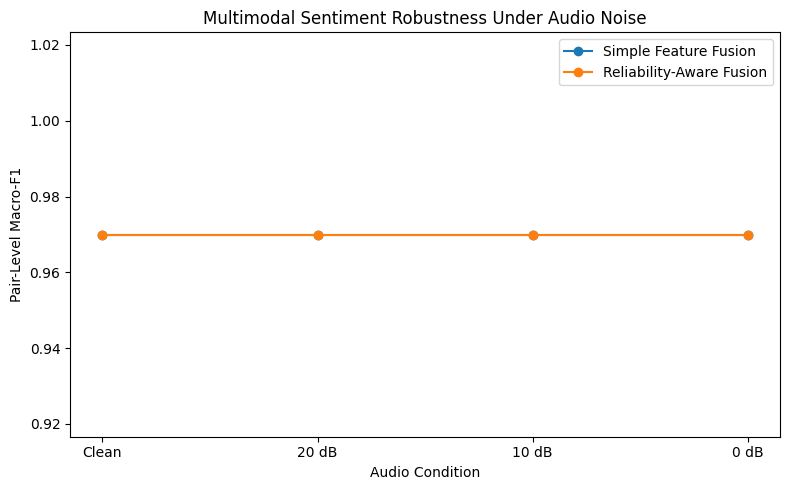

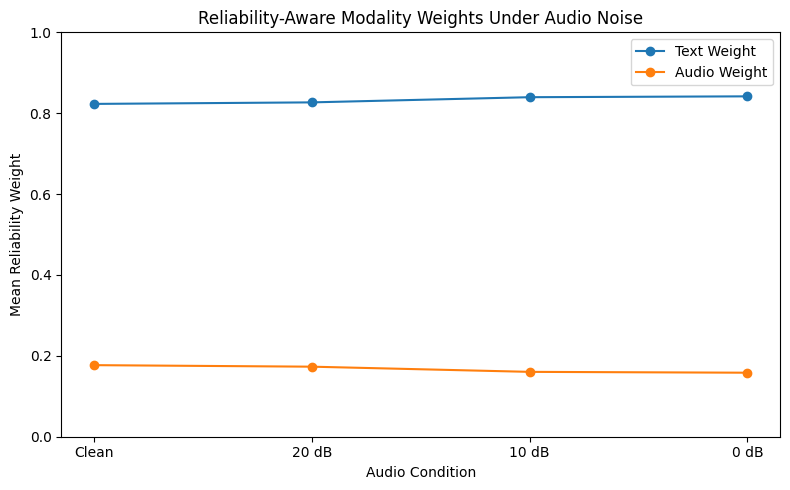

All robustness results saved.


In [516]:
# Step 10G.1 — Verify noisy embedding order

print("=" * 75)
print("NOISY EMBEDDING ALIGNMENT CHECK")
print("=" * 75)

test_order_still_matches = (
    audio_test_df["filename"]
    .astype(str)
    .tolist()
    ==
    test_meta_check["filename"]
    .astype(str)
    .tolist()
)

print(
    "Audio test order matches saved metadata:",
    test_order_still_matches
)

for snr in [20, 10, 0]:

    print(
        f"{snr} dB shape:",
        noisy_audio_embeddings[snr].shape
    )



# Step 10G.2 — Reload both fusion models

import random
import numpy as np
import torch

# ============================================================
# SIMPLE FUSION
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

simple_fusion_model = SimpleMultimodalFusion(
    input_dim=1792,
    hidden_dim1=512,
    hidden_dim2=128,
    num_classes=2
).to(device)

simple_state = torch.load(
    BEST_SIMPLE_FUSION_PATH,
    map_location=device
)

simple_fusion_model.load_state_dict(
    simple_state
)

simple_fusion_model.eval()


# ============================================================
# RELIABILITY-AWARE FUSION
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

raf_model = ReliabilityAwareFusion(
    text_dim=768,
    audio_dim=1024,
    shared_dim=256,
    num_classes=2,
    dropout=0.20
).to(device)

raf_state = torch.load(
    BEST_RAF_PATH,
    map_location=device
)

raf_model.load_state_dict(
    raf_state
)

raf_model.eval()


print("Simple Fusion checkpoint loaded.")
print("Reliability-Aware Fusion checkpoint loaded.")



# Step 10G.3 — Define Simple Fusion evaluation for arbitrary audio

def evaluate_simple_with_audio(
    text_embeddings,
    audio_embeddings,
    labels
):

    combined = np.concatenate(
        [
            text_embeddings,
            audio_embeddings
        ],
        axis=1
    ).astype(np.float32)

    dataset = TensorDataset(
        torch.tensor(
            combined,
            dtype=torch.float32
        ),
        torch.tensor(
            labels,
            dtype=torch.long
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False
    )

    return evaluate_simple_fusion(
        simple_fusion_model,
        loader,
        mm_criterion,
        device
    )



# Step 10G.4 — Define RAF evaluation for arbitrary audio


def evaluate_raf_with_audio(
    text_embeddings,
    audio_embeddings,
    labels
):

    dataset = ReliabilityMultimodalDataset(
        text_embeddings,
        audio_embeddings,
        labels
    )

    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False
    )

    return evaluate_raf(
        raf_model,
        loader,
        device,
        mode="both"
    )



# Step 10G.5 — Evaluate CLEAN + 20 + 10 + 0 dB

noise_conditions = {
    "Clean": X_audio_test_aligned,
    "20 dB": noisy_audio_embeddings[20],
    "10 dB": noisy_audio_embeddings[10],
    "0 dB": noisy_audio_embeddings[0]
}

noise_results_rows = []

noise_detailed_outputs = {}


for condition_name, audio_features in noise_conditions.items():

    print("\n" + "=" * 80)
    print("CONDITION:", condition_name)
    print("=" * 80)

    # ========================================================
    # SIMPLE FUSION
    # ========================================================

    (
        simple_loss,
        simple_metrics,
        simple_predictions,
        simple_labels,
        simple_probabilities
    ) = evaluate_simple_with_audio(
        X_text_test_aligned,
        audio_features,
        y_mm_test
    )

    simple_auc = roc_auc_score(
        simple_labels,
        simple_probabilities[:, 1]
    )

    (
        _,
        simple_sentence_acc,
        simple_sentence_f1,
        simple_sentence_auc
    ) = calculate_sentence_level_results(
        test_meta_check,
        simple_probabilities
    )

    noise_results_rows.append({
        "model": "Simple Feature Fusion",
        "condition": condition_name,

        "pair_accuracy":
            simple_metrics["accuracy"],

        "pair_macro_f1":
            simple_metrics["f1_macro"],

        "pair_roc_auc":
            simple_auc,

        "sentence_accuracy":
            simple_sentence_acc,

        "sentence_macro_f1":
            simple_sentence_f1,

        "sentence_roc_auc":
            simple_sentence_auc,

        "mean_text_weight":
            np.nan,

        "mean_audio_weight":
            np.nan
    })


    # ========================================================
    # RELIABILITY-AWARE FUSION
    # ========================================================

    (
        raf_loss,
        raf_metrics,
        raf_predictions,
        raf_labels,
        raf_probabilities,
        raf_text_weights,
        raf_audio_weights
    ) = evaluate_raf_with_audio(
        X_text_test_aligned,
        audio_features,
        y_mm_test
    )

    raf_auc = roc_auc_score(
        raf_labels,
        raf_probabilities[:, 1]
    )

    (
        _,
        raf_sentence_acc,
        raf_sentence_f1,
        raf_sentence_auc
    ) = calculate_sentence_level_results(
        test_meta_check,
        raf_probabilities
    )

    noise_results_rows.append({
        "model": "Reliability-Aware Fusion",
        "condition": condition_name,

        "pair_accuracy":
            raf_metrics["accuracy"],

        "pair_macro_f1":
            raf_metrics["f1_macro"],

        "pair_roc_auc":
            raf_auc,

        "sentence_accuracy":
            raf_sentence_acc,

        "sentence_macro_f1":
            raf_sentence_f1,

        "sentence_roc_auc":
            raf_sentence_auc,

        "mean_text_weight":
            raf_text_weights.mean(),

        "mean_audio_weight":
            raf_audio_weights.mean()
    })


    noise_detailed_outputs[
        condition_name
    ] = {
        "simple_predictions":
            simple_predictions,

        "simple_probabilities":
            simple_probabilities,

        "raf_predictions":
            raf_predictions,

        "raf_probabilities":
            raf_probabilities,

        "raf_text_weights":
            raf_text_weights,

        "raf_audio_weights":
            raf_audio_weights
    }


    print("\nSimple Fusion")
    print(
        "Pair Macro-F1:",
        round(
            simple_metrics["f1_macro"],
            4
        )
    )
    print(
        "Sentence Macro-F1:",
        round(
            simple_sentence_f1,
            4
        )
    )


    print("\nReliability-Aware Fusion")
    print(
        "Pair Macro-F1:",
        round(
            raf_metrics["f1_macro"],
            4
        )
    )
    print(
        "Sentence Macro-F1:",
        round(
            raf_sentence_f1,
            4
        )
    )
    print(
        "Mean Text Weight:",
        round(
            raf_text_weights.mean(),
            4
        )
    )
    print(
        "Mean Audio Weight:",
        round(
            raf_audio_weights.mean(),
            4
        )
    )



# Step 10G.6 — Create the main noise-robustness table


noise_robustness_df = pd.DataFrame(
    noise_results_rows
)

display(
    noise_robustness_df.round(4)
)




# Step 10G.7 — Add missing-modality results to one master robustness table

full_robustness_df = pd.concat(
    [
        noise_robustness_df,
        missing_modality_comparison_df[
            missing_modality_comparison_df[
                "condition"
            ].isin([
                "Missing Audio",
                "Missing Text"
            ])
        ]
    ],
    ignore_index=True
)

condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]

full_robustness_df[
    "condition"
] = pd.Categorical(
    full_robustness_df["condition"],
    categories=condition_order,
    ordered=True
)

full_robustness_df = (
    full_robustness_df
    .sort_values(
        [
            "condition",
            "model"
        ]
    )
    .reset_index(drop=True)
)

display(
    full_robustness_df.round(4)
)



# Step 10G.8 — Create compact thesis comparison table


macro_f1_pivot = (
    full_robustness_df
    .pivot(
        index="model",
        columns="condition",
        values="pair_macro_f1"
    )
)

macro_f1_pivot = (
    macro_f1_pivot[
        condition_order
    ]
)

print("=" * 90)
print("PAIR-LEVEL MACRO-F1 ROBUSTNESS SUMMARY")
print("=" * 90)

display(
    macro_f1_pivot.round(4)
)



# Step 10G.9 — Analyze the reliability weights

raf_weight_df = (
    noise_robustness_df[
        noise_robustness_df[
            "model"
        ] == "Reliability-Aware Fusion"
    ][
        [
            "condition",
            "mean_text_weight",
            "mean_audio_weight",
            "pair_macro_f1"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    raf_weight_df.round(4)
)



# Step 10G.10 — Calculate performance degradation


degradation_rows = []

for model_name in [
    "Simple Feature Fusion",
    "Reliability-Aware Fusion"
]:

    model_df = (
        noise_robustness_df[
            noise_robustness_df[
                "model"
            ] == model_name
        ]
    )

    clean_f1 = float(
        model_df[
            model_df[
                "condition"
            ] == "Clean"
        ]["pair_macro_f1"].iloc[0]
    )

    for condition in [
        "20 dB",
        "10 dB",
        "0 dB"
    ]:

        noisy_f1 = float(
            model_df[
                model_df[
                    "condition"
                ] == condition
            ]["pair_macro_f1"].iloc[0]
        )

        degradation_rows.append({
            "model": model_name,
            "condition": condition,

            "clean_macro_f1":
                clean_f1,

            "noisy_macro_f1":
                noisy_f1,

            "absolute_f1_drop":
                clean_f1 - noisy_f1,

            "f1_retention_percent":
                (
                    noisy_f1 /
                    clean_f1
                    * 100
                )
        })


degradation_df = pd.DataFrame(
    degradation_rows
)

display(
    degradation_df.round(4)
)



# Step 10G.11 — Plot robustness curve

import matplotlib.pyplot as plt

plot_conditions = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]

plt.figure(figsize=(8, 5))

for model_name in [
    "Simple Feature Fusion",
    "Reliability-Aware Fusion"
]:

    model_data = (
        noise_robustness_df[
            noise_robustness_df[
                "model"
            ] == model_name
        ]
        .set_index("condition")
        .loc[plot_conditions]
    )

    plt.plot(
        plot_conditions,
        model_data["pair_macro_f1"],
        marker="o",
        label=model_name
    )

plt.xlabel("Audio Condition")
plt.ylabel("Pair-Level Macro-F1")
plt.title(
    "Multimodal Sentiment Robustness Under Audio Noise"
)
plt.legend()
plt.tight_layout()

NOISE_ROBUSTNESS_FIGURE = (
    PROJECT_ROOT /
    "figures" /
    "noise_robustness_comparison.png"
)

plt.savefig(
    NOISE_ROBUSTNESS_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()





# Step 10G.12 — Plot RAF modality weights

weight_plot_df = (
    raf_weight_df
    .set_index("condition")
    .loc[plot_conditions]
)

plt.figure(figsize=(8, 5))

plt.plot(
    plot_conditions,
    weight_plot_df[
        "mean_text_weight"
    ],
    marker="o",
    label="Text Weight"
)

plt.plot(
    plot_conditions,
    weight_plot_df[
        "mean_audio_weight"
    ],
    marker="o",
    label="Audio Weight"
)

plt.xlabel("Audio Condition")
plt.ylabel("Mean Reliability Weight")

plt.title(
    "Reliability-Aware Modality Weights Under Audio Noise"
)

plt.ylim(0, 1)

plt.legend()
plt.tight_layout()

RAF_WEIGHT_FIGURE = (
    PROJECT_ROOT /
    "figures" /
    "raf_modality_weights_under_noise.png"
)

plt.savefig(
    RAF_WEIGHT_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# Step 10G.13 — Save everything


noise_robustness_df.to_csv(
    PROJECT_ROOT /
    "results" /
    "noise_robustness_comparison.csv",
    index=False
)

full_robustness_df.to_csv(
    PROJECT_ROOT /
    "results" /
    "full_robustness_comparison.csv",
    index=False
)

raf_weight_df.to_csv(
    PROJECT_ROOT /
    "results" /
    "raf_reliability_weights_under_noise.csv",
    index=False
)

degradation_df.to_csv(
    PROJECT_ROOT /
    "results" /
    "noise_f1_degradation.csv",
    index=False
)

print("All robustness results saved.")

**Step 10H — Does waveform noise actually damage the Audio-Only model?**

In [517]:
# Step 10H.1 — Reload the best audio-only classifier

import torch
import torch.nn as nn
import random
import numpy as np

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


audio_classifier_noise_test = AudioSentimentClassifier(
    input_dim=1024,
    hidden_dim=256,
    num_classes=2,
    dropout=0.30
).to(device)


audio_noise_state = torch.load(
    BEST_AUDIO_MODEL_PATH,
    map_location=device
)

audio_classifier_noise_test.load_state_dict(
    audio_noise_state
)

audio_classifier_noise_test.eval()

audio_noise_criterion = nn.CrossEntropyLoss()

print("Best audio-only checkpoint loaded.")



# Step 10H.2 — Evaluation helper

def evaluate_audio_embeddings_condition(
    embeddings,
    labels
):

    dataset = TensorDataset(
        torch.tensor(
            embeddings,
            dtype=torch.float32
        ),
        torch.tensor(
            labels,
            dtype=torch.long
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False
    )

    return evaluate_audio_classifier(
        model=audio_classifier_noise_test,
        dataloader=loader,
        criterion=audio_noise_criterion,
        device=device
    )



# Step 10H.3 — Evaluate clean + all noise levels

audio_noise_conditions = {
    "Clean": X_audio_test_aligned,
    "20 dB": noisy_audio_embeddings[20],
    "10 dB": noisy_audio_embeddings[10],
    "0 dB": noisy_audio_embeddings[0]
}

audio_noise_rows = []

for condition_name, embeddings in audio_noise_conditions.items():

    (
        loss,
        metrics,
        predictions,
        labels,
        probabilities
    ) = evaluate_audio_embeddings_condition(
        embeddings,
        y_mm_test
    )

    auc = roc_auc_score(
        labels,
        probabilities[:, 1]
    )

    mean_confidence = (
        probabilities.max(axis=1).mean()
    )

    (
        _,
        sentence_acc,
        sentence_f1,
        sentence_auc
    ) = calculate_sentence_level_results(
        test_meta_check,
        probabilities
    )

    audio_noise_rows.append({
        "condition": condition_name,

        "pair_accuracy":
            metrics["accuracy"],

        "pair_macro_f1":
            metrics["f1_macro"],

        "pair_roc_auc":
            auc,

        "mean_prediction_confidence":
            mean_confidence,

        "sentence_accuracy":
            sentence_acc,

        "sentence_macro_f1":
            sentence_f1,

        "sentence_roc_auc":
            sentence_auc
    })

    print("\n" + "=" * 70)
    print("AUDIO-ONLY —", condition_name)
    print("=" * 70)

    print(
        "Pair Accuracy:",
        round(metrics["accuracy"], 4)
    )

    print(
        "Pair Macro-F1:",
        round(metrics["f1_macro"], 4)
    )

    print(
        "Pair ROC-AUC:",
        round(auc, 4)
    )

    print(
        "Mean Confidence:",
        round(mean_confidence, 4)
    )

    print(
        "Sentence Macro-F1:",
        round(sentence_f1, 4)
    )



# Step 10H.4 — Create the table

audio_noise_robustness_df = pd.DataFrame(
    audio_noise_rows
)

display(
    audio_noise_robustness_df.round(4)
)





# Step 10H.5 — Calculate degradation

clean_audio_f1 = float(
    audio_noise_robustness_df[
        audio_noise_robustness_df["condition"]
        == "Clean"
    ]["pair_macro_f1"].iloc[0]
)

audio_noise_robustness_df[
    "absolute_f1_drop"
] = (
    clean_audio_f1
    -
    audio_noise_robustness_df[
        "pair_macro_f1"
    ]
)

audio_noise_robustness_df[
    "f1_retention_percent"
] = (
    audio_noise_robustness_df[
        "pair_macro_f1"
    ]
    /
    clean_audio_f1
    *
    100
)

display(
    audio_noise_robustness_df.round(4)
)



# Step 10H.6 — Save it

AUDIO_NOISE_RESULTS_PATH = (
    PROJECT_ROOT /
    "results" /
    "audio_only_noise_robustness.csv"
)

audio_noise_robustness_df.to_csv(
    AUDIO_NOISE_RESULTS_PATH,
    index=False
)

print(
    "Saved:",
    AUDIO_NOISE_RESULTS_PATH
)

Best audio-only checkpoint loaded.

AUDIO-ONLY — Clean
Pair Accuracy: 0.8925
Pair Macro-F1: 0.8924
Pair ROC-AUC: 0.9642
Mean Confidence: 0.83
Sentence Macro-F1: 0.98

AUDIO-ONLY — 20 dB
Pair Accuracy: 0.7625
Pair Macro-F1: 0.7589
Pair ROC-AUC: 0.8724
Mean Confidence: 0.7348
Sentence Macro-F1: 0.7803

AUDIO-ONLY — 10 dB
Pair Accuracy: 0.5525
Pair Macro-F1: 0.4404
Pair ROC-AUC: 0.857
Mean Confidence: 0.767
Sentence Macro-F1: 0.3552

AUDIO-ONLY — 0 dB
Pair Accuracy: 0.5
Pair Macro-F1: 0.3333
Pair ROC-AUC: 0.7949
Mean Confidence: 0.9478
Sentence Macro-F1: 0.3333


,condition,pair_accuracy,pair_macro_f1,pair_roc_auc,mean_prediction_confidence,sentence_accuracy,sentence_macro_f1,sentence_roc_auc
0,Clean,0.8925,0.8924,0.9642,0.8300,0.98,0.9800,0.9984
1,20 dB,0.7625,0.7589,0.8724,0.7348,0.79,0.7803,0.9884
2,10 dB,0.5525,0.4404,0.8570,0.7670,0.51,0.3552,0.9792
3,0 dB,0.5000,0.3333,0.7949,0.9478,0.50,0.3333,0.9540


,condition,pair_accuracy,pair_macro_f1,pair_roc_auc,mean_prediction_confidence,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,absolute_f1_drop,f1_retention_percent
0,Clean,0.8925,0.8924,0.9642,0.8300,0.98,0.9800,0.9984,0.0000,100.0000
1,20 dB,0.7625,0.7589,0.8724,0.7348,0.79,0.7803,0.9884,0.1335,85.0396
2,10 dB,0.5525,0.4404,0.8570,0.7670,0.51,0.3552,0.9792,0.4519,49.3560
3,0 dB,0.5000,0.3333,0.7949,0.9478,0.50,0.3333,0.9540,0.5591,37.3530


Saved: /kaggle/working/bangla_multimodal_thesis/results/audio_only_noise_robustness.csv


**Step 10I.1 — Reload XLS-R for noisy TRAIN embeddings**

In [518]:
import gc
import torch

# Remove current small models
for variable_name in [
    "audio_classifier_noise_test",
    "raf_model",
    "simple_fusion_model"
]:
    globals().pop(variable_name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

from transformers import AutoFeatureExtractor, AutoModel

AUDIO_ENCODER_NAME = "facebook/wav2vec2-xls-r-300m"

audio_feature_extractor = (
    AutoFeatureExtractor.from_pretrained(
        AUDIO_ENCODER_NAME
    )
)

audio_encoder = AutoModel.from_pretrained(
    AUDIO_ENCODER_NAME
)

audio_encoder = audio_encoder.to(device)
audio_encoder.eval()

for parameter in audio_encoder.parameters():
    parameter.requires_grad = False

print("=" * 70)
print("XLS-R READY FOR NOISY TRAIN EXTRACTION")
print("=" * 70)

print(
    "Sampling rate:",
    audio_feature_extractor.sampling_rate
)

print(
    "Hidden size:",
    audio_encoder.config.hidden_size
)

if torch.cuda.is_available():

    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated()
            / (1024 ** 3),
            2
        ),
        "GB"
    )



# Step 10I.2 — Extract 20 dB TRAIN embeddings first
print("=" * 75)
print("TRAIN AUDIO — 20 dB SNR")
print("=" * 75)

train_audio_20db = extract_noisy_xlsr_embeddings(
    dataframe=audio_train_df,
    snr_db=20,
    audio_encoder=audio_encoder,
    feature_extractor=audio_feature_extractor,
    device=device,
    batch_size=8,
    base_seed=SEED
)

print("\nShape:", train_audio_20db.shape)
print("Mean:", round(float(train_audio_20db.mean()), 6))
print("Std:", round(float(train_audio_20db.std()), 6))
print("NaN:", np.isnan(train_audio_20db).sum())
print("Inf:", np.isinf(train_audio_20db).sum())



TRAIN_20DB_PATH = (
    PROJECT_ROOT /
    "embeddings" /
    "xlsr_train_noise_20db.npy"
)

np.save(
    TRAIN_20DB_PATH,
    train_audio_20db
)

print("=" * 70)
print("20 dB TRAIN EMBEDDINGS SAVED")
print("=" * 70)

print(TRAIN_20DB_PATH)

print(
    "File size:",
    round(
        TRAIN_20DB_PATH.stat().st_size /
        (1024 ** 2),
        2
    ),
    "MB"
)





Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


XLS-R READY FOR NOISY TRAIN EXTRACTION
Sampling rate: 16000
Hidden size: 1024
GPU allocated: 1.28 GB
TRAIN AUDIO — 20 dB SNR


XLS-R 20 dB:   0%|          | 0/399 [00:00<?, ?it/s]


Shape: (3192, 1024)
Mean: 0.000274
Std: 0.165192
NaN: 0
Inf: 0
20 dB TRAIN EMBEDDINGS SAVED
/kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_train_noise_20db.npy
File size: 12.47 MB


**Step 10I.3 — Extract 10 dB and 0 dB Training Embeddings**

In [519]:
# Step 10I.3.1 — Extract and save 10 dB

print("=" * 75)
print("TRAIN AUDIO — 10 dB SNR")
print("=" * 75)

train_audio_10db = extract_noisy_xlsr_embeddings(
    dataframe=audio_train_df,
    snr_db=10,
    audio_encoder=audio_encoder,
    feature_extractor=audio_feature_extractor,
    device=device,
    batch_size=8,
    base_seed=SEED
)

print("\nShape:", train_audio_10db.shape)
print(
    "Mean:",
    round(float(train_audio_10db.mean()), 6)
)
print(
    "Std:",
    round(float(train_audio_10db.std()), 6)
)
print(
    "NaN:",
    np.isnan(train_audio_10db).sum()
)
print(
    "Inf:",
    np.isinf(train_audio_10db).sum()
)


TRAIN_10DB_PATH = (
    PROJECT_ROOT /
    "embeddings" /
    "xlsr_train_noise_10db.npy"
)

np.save(
    TRAIN_10DB_PATH,
    train_audio_10db
)

print("\n" + "=" * 70)
print("10 dB TRAIN EMBEDDINGS SAVED")
print("=" * 70)

print(TRAIN_10DB_PATH)

print(
    "File size:",
    round(
        TRAIN_10DB_PATH.stat().st_size /
        (1024 ** 2),
        2
    ),
    "MB"
)






# Step 10I.3.2 — Extract and save 0 dB

print("=" * 75)
print("TRAIN AUDIO — 0 dB SNR")
print("=" * 75)

train_audio_0db = extract_noisy_xlsr_embeddings(
    dataframe=audio_train_df,
    snr_db=0,
    audio_encoder=audio_encoder,
    feature_extractor=audio_feature_extractor,
    device=device,
    batch_size=8,
    base_seed=SEED
)

print("\nShape:", train_audio_0db.shape)
print(
    "Mean:",
    round(float(train_audio_0db.mean()), 6)
)
print(
    "Std:",
    round(float(train_audio_0db.std()), 6)
)
print(
    "NaN:",
    np.isnan(train_audio_0db).sum()
)
print(
    "Inf:",
    np.isinf(train_audio_0db).sum()
)


TRAIN_0DB_PATH = (
    PROJECT_ROOT /
    "embeddings" /
    "xlsr_train_noise_0db.npy"
)

np.save(
    TRAIN_0DB_PATH,
    train_audio_0db
)

print("\n" + "=" * 70)
print("0 dB TRAIN EMBEDDINGS SAVED")
print("=" * 70)

print(TRAIN_0DB_PATH)

print(
    "File size:",
    round(
        TRAIN_0DB_PATH.stat().st_size /
        (1024 ** 2),
        2
    ),
    "MB"
)





# Step 10I.4 — Verify all four training audio conditions

print("=" * 75)
print("NOISY TRAIN EMBEDDING INTEGRITY CHECK")
print("=" * 75)

train_audio_conditions = {
    "Clean": X_audio_train_aligned,
    "20 dB": train_audio_20db,
    "10 dB": train_audio_10db,
    "0 dB": train_audio_0db
}

for condition, embeddings in train_audio_conditions.items():

    print(f"\n{condition}")
    print("-" * 35)

    print(
        "Shape:",
        embeddings.shape
    )

    print(
        "Mean:",
        round(
            float(embeddings.mean()),
            6
        )
    )

    print(
        "Std:",
        round(
            float(embeddings.std()),
            6
        )
    )

    print(
        "NaN:",
        np.isnan(embeddings).sum()
    )

    print(
        "Inf:",
        np.isinf(embeddings).sum()
    )




# Step 10I.5 — Confirm saved files exist


for path in [
    TRAIN_20DB_PATH,
    TRAIN_10DB_PATH,
    TRAIN_0DB_PATH
]:

    print(
        path.name,
        "| Exists:",
        path.exists(),
        "| Size:",
        round(
            path.stat().st_size /
            (1024 ** 2),
            2
        ),
        "MB"
    )


TRAIN AUDIO — 10 dB SNR


XLS-R 10 dB:   0%|          | 0/399 [00:00<?, ?it/s]


Shape: (3192, 1024)
Mean: 0.000209
Std: 0.156957
NaN: 0
Inf: 0

10 dB TRAIN EMBEDDINGS SAVED
/kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_train_noise_10db.npy
File size: 12.47 MB
TRAIN AUDIO — 0 dB SNR


XLS-R 0 dB:   0%|          | 0/399 [00:00<?, ?it/s]


Shape: (3192, 1024)
Mean: -0.00027
Std: 0.148712
NaN: 0
Inf: 0

0 dB TRAIN EMBEDDINGS SAVED
/kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_train_noise_0db.npy
File size: 12.47 MB
NOISY TRAIN EMBEDDING INTEGRITY CHECK

Clean
-----------------------------------
Shape: (3192, 1024)
Mean: 0.000253
Std: 0.174436
NaN: 0
Inf: 0

20 dB
-----------------------------------
Shape: (3192, 1024)
Mean: 0.000274
Std: 0.165192
NaN: 0
Inf: 0

10 dB
-----------------------------------
Shape: (3192, 1024)
Mean: 0.000209
Std: 0.156957
NaN: 0
Inf: 0

0 dB
-----------------------------------
Shape: (3192, 1024)
Mean: -0.00027
Std: 0.148712
NaN: 0
Inf: 0
xlsr_train_noise_20db.npy | Exists: True | Size: 12.47 MB
xlsr_train_noise_10db.npy | Exists: True | Size: 12.47 MB
xlsr_train_noise_0db.npy | Exists: True | Size: 12.47 MB


**Step 10J.1 — Extract Noisy Validation Embeddings**

In [520]:
VAL_NOISE_LEVELS = [20, 10, 0]

noisy_val_audio_embeddings = {}

for snr in VAL_NOISE_LEVELS:

    print("\n" + "=" * 75)
    print(f"VALIDATION AUDIO — {snr} dB SNR")
    print("=" * 75)

    embeddings = extract_noisy_xlsr_embeddings(
        dataframe=audio_val_df,
        snr_db=snr,
        audio_encoder=audio_encoder,
        feature_extractor=audio_feature_extractor,
        device=device,
        batch_size=8,
        base_seed=SEED
    )

    noisy_val_audio_embeddings[snr] = embeddings

    print("Shape:", embeddings.shape)
    print(
        "Mean:",
        round(float(embeddings.mean()), 6)
    )
    print(
        "Std:",
        round(float(embeddings.std()), 6)
    )
    print(
        "NaN:",
        np.isnan(embeddings).sum()
    )
    print(
        "Inf:",
        np.isinf(embeddings).sum()
    )

    save_path = (
        PROJECT_ROOT /
        "embeddings" /
        f"xlsr_validation_noise_{snr}db.npy"
    )

    np.save(
        save_path,
        embeddings
    )

    print("Saved:", save_path)




# Step 10J.2 — Integrity check


print("=" * 75)
print("NOISY VALIDATION EMBEDDING CHECK")
print("=" * 75)

val_audio_conditions = {
    "Clean": X_audio_val_aligned,
    "20 dB": noisy_val_audio_embeddings[20],
    "10 dB": noisy_val_audio_embeddings[10],
    "0 dB": noisy_val_audio_embeddings[0]
}

for condition, embeddings in val_audio_conditions.items():

    print(f"\n{condition}")

    print(
        "Shape:",
        embeddings.shape
    )

    print(
        "NaN:",
        np.isnan(embeddings).sum()
    )

    print(
        "Inf:",
        np.isinf(embeddings).sum()
    )





# Step 10J.3 — Release XLS-R

import gc

for variable_name in [
    "audio_encoder",
    "audio_feature_extractor"
]:
    globals().pop(
        variable_name,
        None
    )

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("XLS-R released from GPU.")

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated()
            / (1024 ** 3),
            3
        ),
        "GB"
    )



VALIDATION AUDIO — 20 dB SNR


XLS-R 20 dB:   0%|          | 0/50 [00:00<?, ?it/s]

Shape: (400, 1024)
Mean: 0.000277
Std: 0.165133
NaN: 0
Inf: 0
Saved: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_validation_noise_20db.npy

VALIDATION AUDIO — 10 dB SNR


XLS-R 10 dB:   0%|          | 0/50 [00:00<?, ?it/s]

Shape: (400, 1024)
Mean: 0.000218
Std: 0.156829
NaN: 0
Inf: 0
Saved: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_validation_noise_10db.npy

VALIDATION AUDIO — 0 dB SNR


XLS-R 0 dB:   0%|          | 0/50 [00:00<?, ?it/s]

Shape: (400, 1024)
Mean: -0.000269
Std: 0.148707
NaN: 0
Inf: 0
Saved: /kaggle/working/bangla_multimodal_thesis/embeddings/xlsr_validation_noise_0db.npy
NOISY VALIDATION EMBEDDING CHECK

Clean
Shape: (400, 1024)
NaN: 0
Inf: 0

20 dB
Shape: (400, 1024)
NaN: 0
Inf: 0

10 dB
Shape: (400, 1024)
NaN: 0
Inf: 0

0 dB
Shape: (400, 1024)
NaN: 0
Inf: 0
XLS-R released from GPU.
GPU allocated: 0.106 GB


**Step 10J.4 — Load the noisy train/validation embeddings from disk**

In [521]:
EMBEDDING_DIR = PROJECT_ROOT / "embeddings"

# -------------------------
# TRAIN
# -------------------------

train_audio_20_v2 = np.load(
    EMBEDDING_DIR / "xlsr_train_noise_20db.npy"
)

train_audio_10_v2 = np.load(
    EMBEDDING_DIR / "xlsr_train_noise_10db.npy"
)

train_audio_0_v2 = np.load(
    EMBEDDING_DIR / "xlsr_train_noise_0db.npy"
)


# -------------------------
# VALIDATION
# -------------------------

val_audio_20_v2 = np.load(
    EMBEDDING_DIR / "xlsr_validation_noise_20db.npy"
)

val_audio_10_v2 = np.load(
    EMBEDDING_DIR / "xlsr_validation_noise_10db.npy"
)

val_audio_0_v2 = np.load(
    EMBEDDING_DIR / "xlsr_validation_noise_0db.npy"
)


print("TRAIN")
print("Clean :", X_audio_train_aligned.shape)
print("20 dB :", train_audio_20_v2.shape)
print("10 dB :", train_audio_10_v2.shape)
print("0 dB  :", train_audio_0_v2.shape)

print("\nVALIDATION")
print("Clean :", X_audio_val_aligned.shape)
print("20 dB :", val_audio_20_v2.shape)
print("10 dB :", val_audio_10_v2.shape)
print("0 dB  :", val_audio_0_v2.shape)



# Step 10J.5 — Create RAF-v2 training DataLoader

from torch.utils.data import TensorDataset, DataLoader

raf2_train_dataset = TensorDataset(

    torch.arange(
        len(y_mm_train),
        dtype=torch.long
    ),

    torch.tensor(
        X_text_train_aligned,
        dtype=torch.float32
    ),

    torch.tensor(
        X_audio_train_aligned,
        dtype=torch.float32
    ),

    torch.tensor(
        y_mm_train,
        dtype=torch.long
    )
)


RAF2_BATCH_SIZE = 64

raf2_generator = torch.Generator()
raf2_generator.manual_seed(SEED)

raf2_train_loader = DataLoader(
    raf2_train_dataset,
    batch_size=RAF2_BATCH_SIZE,
    shuffle=True,
    generator=raf2_generator
)

print("Training samples:", len(raf2_train_dataset))
print("Training batches:", len(raf2_train_loader))




# Step 10J.6 — Put noisy training variants on GPU

train_audio_20_gpu = torch.tensor(
    train_audio_20_v2,
    dtype=torch.float32,
    device=device
)

train_audio_10_gpu = torch.tensor(
    train_audio_10_v2,
    dtype=torch.float32,
    device=device
)

train_audio_0_gpu = torch.tensor(
    train_audio_0_v2,
    dtype=torch.float32,
    device=device
)

print("Noisy training variants moved to GPU.")

print(
    "GPU allocated:",
    round(
        torch.cuda.memory_allocated()
        / (1024 ** 3),
        3
    ),
    "GB"
)



# Step 10J.7 — Define RAF-v2

import torch.nn as nn
import torch.nn.functional as F


class ReliabilityAwareFusionV2(nn.Module):

    def __init__(
        self,
        text_dim=768,
        audio_dim=1024,
        shared_dim=256,
        num_classes=2,
        dropout=0.20
    ):

        super().__init__()

        # ==================================================
        # MODALITY PROJECTIONS
        # ==================================================

        self.text_projection = nn.Sequential(
            nn.LayerNorm(text_dim),
            nn.Linear(text_dim, shared_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.audio_projection = nn.Sequential(
            nn.LayerNorm(audio_dim),
            nn.Linear(audio_dim, shared_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )


        # ==================================================
        # AUXILIARY CLASSIFIERS
        # ==================================================

        self.text_classifier = nn.Linear(
            shared_dim,
            num_classes
        )

        self.audio_classifier = nn.Linear(
            shared_dim,
            num_classes
        )


        # ==================================================
        # QUALITY ESTIMATORS
        # ==================================================

        self.text_quality_head = nn.Sequential(
            nn.Linear(shared_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

        self.audio_quality_head = nn.Sequential(
            nn.Linear(shared_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )


        # ==================================================
        # LEARNABLE MODALITY PRIORS
        #
        # Allows model to learn that text may generally be
        # more useful than audio even when both are clean.
        # ==================================================

        self.text_prior_logit = nn.Parameter(
            torch.tensor(0.0)
        )

        self.audio_prior_logit = nn.Parameter(
            torch.tensor(0.0)
        )


        # ==================================================
        # FINAL FUSION CLASSIFIER
        # ==================================================

        self.fusion_classifier = nn.Sequential(
            nn.LayerNorm(shared_dim),
            nn.Linear(shared_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )


    def forward(
        self,
        text_embedding,
        audio_embedding,
        text_available=None,
        audio_available=None
    ):

        batch_size = text_embedding.shape[0]

        if text_available is None:
            text_available = torch.ones(
                batch_size,
                device=text_embedding.device
            )

        if audio_available is None:
            audio_available = torch.ones(
                batch_size,
                device=audio_embedding.device
            )


        # ==================================================
        # PROJECT
        # ==================================================

        text_hidden_raw = self.text_projection(
            text_embedding
        )

        audio_hidden_raw = self.audio_projection(
            audio_embedding
        )


        text_hidden = (
            text_hidden_raw
            *
            text_available.unsqueeze(1)
        )

        audio_hidden = (
            audio_hidden_raw
            *
            audio_available.unsqueeze(1)
        )


        # ==================================================
        # MODALITY-SPECIFIC PREDICTIONS
        # ==================================================

        text_logits = self.text_classifier(
            text_hidden
        )

        audio_logits = self.audio_classifier(
            audio_hidden
        )


        # ==================================================
        # LEARNED QUALITY
        # ==================================================

        text_quality = (
            self.text_quality_head(
                text_hidden_raw
            )
            .squeeze(1)
            *
            text_available
        )

        audio_quality = (
            self.audio_quality_head(
                audio_hidden_raw
            )
            .squeeze(1)
            *
            audio_available
        )


        # ==================================================
        # RELIABILITY LOGITS
        #
        # reliability =
        # modality prior × learned quality
        # ==================================================

        eps = 1e-5

        text_reliability_logit = (
            self.text_prior_logit
            +
            torch.log(
                text_quality.clamp(min=eps)
            )
        )

        audio_reliability_logit = (
            self.audio_prior_logit
            +
            torch.log(
                audio_quality.clamp(min=eps)
            )
        )


        # Missing modality must receive zero weight

        text_reliability_logit = torch.where(
            text_available > 0,
            text_reliability_logit,
            torch.full_like(
                text_reliability_logit,
                -1e4
            )
        )

        audio_reliability_logit = torch.where(
            audio_available > 0,
            audio_reliability_logit,
            torch.full_like(
                audio_reliability_logit,
                -1e4
            )
        )


        reliability_logits = torch.stack(
            [
                text_reliability_logit,
                audio_reliability_logit
            ],
            dim=1
        )

        weights = F.softmax(
            reliability_logits,
            dim=1
        )

        text_weight = weights[:, 0]
        audio_weight = weights[:, 1]


        # ==================================================
        # WEIGHTED FUSION
        # ==================================================

        fused = (
            text_weight.unsqueeze(1)
            * text_hidden
            +
            audio_weight.unsqueeze(1)
            * audio_hidden
        )


        fused_logits = self.fusion_classifier(
            fused
        )


        return {

            "fused_logits": fused_logits,

            "text_logits": text_logits,
            "audio_logits": audio_logits,

            "text_quality": text_quality,
            "audio_quality": audio_quality,

            "text_weight": text_weight,
            "audio_weight": audio_weight
        }





# Step 10J.8 — Initialize RAF-v2 reproducibly


import random

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


raf2_model = ReliabilityAwareFusionV2(
    text_dim=768,
    audio_dim=1024,
    shared_dim=256,
    num_classes=2,
    dropout=0.20
).to(device)


raf2_params = sum(
    p.numel()
    for p in raf2_model.parameters()
)

print("=" * 75)
print("RAF-v2 MODEL")
print("=" * 75)

print(
    "Trainable parameters:",
    f"{raf2_params:,}"
)




# Step 10J.9 — Training-condition probabilities


RAF2_CONDITION_NAMES = {
    0: "Clean",
    1: "20 dB",
    2: "10 dB",
    3: "0 dB",
    4: "Missing Audio",
    5: "Missing Text"
}


RAF2_CONDITION_PROBS = torch.tensor(
    [
        0.35,   # Clean
        0.15,   # 20 dB
        0.15,   # 10 dB
        0.10,   # 0 dB
        0.15,   # Missing audio
        0.10    # Missing text
    ],
    dtype=torch.float32,
    device=device
)

print(
    "Probability sum:",
    RAF2_CONDITION_PROBS.sum().item()
)



# Step 10J.10 — Prepare each training batch

def prepare_raf2_batch(
    indices,
    text_features,
    clean_audio
):

    batch_size = len(indices)

    indices = indices.to(device)

    text_features = text_features.to(device)
    audio_features = clean_audio.to(device).clone()


    text_available = torch.ones(
        batch_size,
        device=device
    )

    audio_available = torch.ones(
        batch_size,
        device=device
    )


    text_quality_target = torch.ones(
        batch_size,
        device=device
    )

    audio_quality_target = torch.ones(
        batch_size,
        device=device
    )


    condition_codes = torch.multinomial(
        RAF2_CONDITION_PROBS,
        num_samples=batch_size,
        replacement=True
    )


    # ======================================================
    # 20 dB
    # ======================================================

    mask = condition_codes == 1

    if mask.any():

        audio_features[mask] = (
            train_audio_20_gpu[
                indices[mask]
            ]
        )

        audio_quality_target[mask] = 0.75


    # ======================================================
    # 10 dB
    # ======================================================

    mask = condition_codes == 2

    if mask.any():

        audio_features[mask] = (
            train_audio_10_gpu[
                indices[mask]
            ]
        )

        audio_quality_target[mask] = 0.50


    # ======================================================
    # 0 dB
    # ======================================================

    mask = condition_codes == 3

    if mask.any():

        audio_features[mask] = (
            train_audio_0_gpu[
                indices[mask]
            ]
        )

        audio_quality_target[mask] = 0.25


    # ======================================================
    # MISSING AUDIO
    # ======================================================

    mask = condition_codes == 4

    if mask.any():

        audio_available[mask] = 0.0
        audio_quality_target[mask] = 0.0


    # ======================================================
    # MISSING TEXT
    # ======================================================

    mask = condition_codes == 5

    if mask.any():

        text_available[mask] = 0.0
        text_quality_target[mask] = 0.0


    return (
        text_features,
        audio_features,
        text_available,
        audio_available,
        text_quality_target,
        audio_quality_target,
        condition_codes
    )





# Step 10J.11 — RAF-v2 loss

raf2_ce_none = nn.CrossEntropyLoss(
    reduction="none"
)

RAF2_AUX_WEIGHT = 0.20
RAF2_QUALITY_WEIGHT = 0.50


def calculate_raf2_loss(
    outputs,
    labels,
    text_available,
    audio_available,
    text_quality_target,
    audio_quality_target
):

    # ======================================================
    # MAIN FUSION LOSS
    # ======================================================

    fusion_loss = F.cross_entropy(
        outputs["fused_logits"],
        labels
    )


    # ======================================================
    # TEXT AUXILIARY LOSS
    # ======================================================

    text_losses = raf2_ce_none(
        outputs["text_logits"],
        labels
    )

    text_aux_loss = (
        (
            text_losses
            *
            text_available
        ).sum()
        /
        text_available.sum().clamp(min=1)
    )


    # ======================================================
    # AUDIO AUXILIARY LOSS
    # ======================================================

    audio_losses = raf2_ce_none(
        outputs["audio_logits"],
        labels
    )

    audio_aux_loss = (
        (
            audio_losses
            *
            audio_available
        ).sum()
        /
        audio_available.sum().clamp(min=1)
    )


    # ======================================================
    # QUALITY SUPERVISION
    # ======================================================

    text_quality_loss = F.mse_loss(
        outputs["text_quality"],
        text_quality_target
    )

    audio_quality_loss = F.mse_loss(
        outputs["audio_quality"],
        audio_quality_target
    )

    quality_loss = (
        text_quality_loss
        +
        audio_quality_loss
    )


    # ======================================================
    # TOTAL
    # ======================================================

    total_loss = (
        fusion_loss
        +
        RAF2_AUX_WEIGHT
        * text_aux_loss
        +
        RAF2_AUX_WEIGHT
        * audio_aux_loss
        +
        RAF2_QUALITY_WEIGHT
        * quality_loss
    )


    return total_loss





# Step 10J.12 — Training function


def train_raf2_epoch(
    model,
    dataloader,
    optimizer
):

    model.train()

    total_loss = 0.0

    all_labels = []
    all_predictions = []


    for (
        indices,
        text_features,
        clean_audio,
        labels
    ) in dataloader:

        labels = labels.to(device)

        (
            text_features,
            audio_features,
            text_available,
            audio_available,
            text_quality_target,
            audio_quality_target,
            _
        ) = prepare_raf2_batch(
            indices,
            text_features,
            clean_audio
        )


        optimizer.zero_grad()


        outputs = model(
            text_features,
            audio_features,
            text_available,
            audio_available
        )


        loss = calculate_raf2_loss(
            outputs,
            labels,
            text_available,
            audio_available,
            text_quality_target,
            audio_quality_target
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )


        optimizer.step()


        total_loss += loss.item()


        predictions = torch.argmax(
            outputs["fused_logits"],
            dim=1
        )


        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )


    metrics = calculate_audio_metrics(
        all_labels,
        all_predictions
    )


    return (
        total_loss / len(dataloader),
        metrics
    )




# Step 10J.13 — Validation evaluator

def evaluate_raf2_condition(
    model,
    text_embeddings,
    audio_embeddings,
    labels,
    text_available_value=1.0,
    audio_available_value=1.0
):

    model.eval()

    dataset = TensorDataset(

        torch.tensor(
            text_embeddings,
            dtype=torch.float32
        ),

        torch.tensor(
            audio_embeddings,
            dtype=torch.float32
        ),

        torch.tensor(
            labels,
            dtype=torch.long
        )
    )


    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False
    )


    predictions_all = []
    labels_all = []
    probabilities_all = []

    text_quality_all = []
    audio_quality_all = []

    text_weight_all = []
    audio_weight_all = []

    losses = []


    with torch.inference_mode():

        for (
            text_features,
            audio_features,
            batch_labels
        ) in loader:

            text_features = text_features.to(device)
            audio_features = audio_features.to(device)
            batch_labels = batch_labels.to(device)


            batch_size = len(batch_labels)


            text_available = torch.full(
                (batch_size,),
                text_available_value,
                device=device
            )

            audio_available = torch.full(
                (batch_size,),
                audio_available_value,
                device=device
            )


            outputs = model(
                text_features,
                audio_features,
                text_available,
                audio_available
            )


            loss = F.cross_entropy(
                outputs["fused_logits"],
                batch_labels
            )

            probabilities = F.softmax(
                outputs["fused_logits"],
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )


            losses.append(
                loss.item()
            )

            labels_all.extend(
                batch_labels.cpu().numpy()
            )

            predictions_all.extend(
                predictions.cpu().numpy()
            )

            probabilities_all.extend(
                probabilities.cpu().numpy()
            )

            text_quality_all.extend(
                outputs[
                    "text_quality"
                ].cpu().numpy()
            )

            audio_quality_all.extend(
                outputs[
                    "audio_quality"
                ].cpu().numpy()
            )

            text_weight_all.extend(
                outputs[
                    "text_weight"
                ].cpu().numpy()
            )

            audio_weight_all.extend(
                outputs[
                    "audio_weight"
                ].cpu().numpy()
            )


    metrics = calculate_audio_metrics(
        labels_all,
        predictions_all
    )


    return {

        "loss":
            np.mean(losses),

        "accuracy":
            metrics["accuracy"],

        "f1_macro":
            metrics["f1_macro"],

        "probabilities":
            np.array(probabilities_all),

        "mean_text_quality":
            np.mean(text_quality_all),

        "mean_audio_quality":
            np.mean(audio_quality_all),

        "mean_text_weight":
            np.mean(text_weight_all),

        "mean_audio_weight":
            np.mean(audio_weight_all)
    }




# Step 10J.14 — Define validation conditions

raf2_validation_conditions = {

    "Clean": {
        "audio": X_audio_val_aligned,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "20 dB": {
        "audio": val_audio_20_v2,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "10 dB": {
        "audio": val_audio_10_v2,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "0 dB": {
        "audio": val_audio_0_v2,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "Missing Audio": {
        "audio": X_audio_val_aligned,
        "text_available": 1.0,
        "audio_available": 0.0
    },

    "Missing Text": {
        "audio": X_audio_val_aligned,
        "text_available": 0.0,
        "audio_available": 1.0
    }
}




# Step 10J.15 — Configure training

RAF2_LR = 5e-4
RAF2_WEIGHT_DECAY = 1e-4

RAF2_MAX_EPOCHS = 30
RAF2_PATIENCE = 5


raf2_optimizer = torch.optim.AdamW(
    raf2_model.parameters(),
    lr=RAF2_LR,
    weight_decay=RAF2_WEIGHT_DECAY
)


BEST_RAF2_PATH = (
    PROJECT_ROOT /
    "models" /
    "reliability_aware_fusion_v2_best.pt"
)


print("Learning rate:", RAF2_LR)
print("Maximum epochs:", RAF2_MAX_EPOCHS)
print("Patience:", RAF2_PATIENCE)
print("Checkpoint:", BEST_RAF2_PATH)



# Step 10J.16 — Train RAF-v2

import time

raf2_history = []

best_raf2_score = -1.0
best_raf2_loss = float("inf")
best_raf2_epoch = 0

raf2_no_improvement = 0

start_time = time.time()


print("=" * 85)
print("RAF-v2 ROBUST RELIABILITY TRAINING")
print("=" * 85)


for epoch in range(
    1,
    RAF2_MAX_EPOCHS + 1
):

    train_loss, train_metrics = train_raf2_epoch(
        raf2_model,
        raf2_train_loader,
        raf2_optimizer
    )


    condition_results = {}

    for (
        condition_name,
        config
    ) in raf2_validation_conditions.items():

        result = evaluate_raf2_condition(
            model=raf2_model,
            text_embeddings=X_text_val_aligned,
            audio_embeddings=config["audio"],
            labels=y_mm_val,
            text_available_value=
                config["text_available"],
            audio_available_value=
                config["audio_available"]
        )

        condition_results[
            condition_name
        ] = result


    robust_mean_f1 = np.mean([
        result["f1_macro"]
        for result
        in condition_results.values()
    ])


    robust_mean_loss = np.mean([
        result["loss"]
        for result
        in condition_results.values()
    ])


    improved = (
        robust_mean_f1
        >
        best_raf2_score + 1e-8
    )

    tied = (
        abs(
            robust_mean_f1
            -
            best_raf2_score
        )
        <= 1e-8
    )

    lower_loss = (
        tied
        and
        robust_mean_loss
        <
        best_raf2_loss
    )


    if improved or lower_loss:

        best_raf2_score = robust_mean_f1
        best_raf2_loss = robust_mean_loss
        best_raf2_epoch = epoch

        raf2_no_improvement = 0

        torch.save(
            raf2_model.state_dict(),
            BEST_RAF2_PATH
        )

        status = "BEST MODEL SAVED"

    else:

        raf2_no_improvement += 1

        status = (
            f"No improvement "
            f"({raf2_no_improvement}/"
            f"{RAF2_PATIENCE})"
        )


    raf2_history.append({

        "epoch": epoch,

        "train_loss":
            train_loss,

        "train_f1":
            train_metrics["f1_macro"],

        "robust_val_mean_f1":
            robust_mean_f1,

        "clean_f1":
            condition_results[
                "Clean"
            ]["f1_macro"],

        "20db_f1":
            condition_results[
                "20 dB"
            ]["f1_macro"],

        "10db_f1":
            condition_results[
                "10 dB"
            ]["f1_macro"],

        "0db_f1":
            condition_results[
                "0 dB"
            ]["f1_macro"],

        "missing_audio_f1":
            condition_results[
                "Missing Audio"
            ]["f1_macro"],

        "missing_text_f1":
            condition_results[
                "Missing Text"
            ]["f1_macro"]
    })


    print(
        f"Epoch {epoch:02d} | "
        f"Train={train_metrics['f1_macro']:.4f} | "
        f"RobustVal={robust_mean_f1:.4f} | "
        f"Clean={condition_results['Clean']['f1_macro']:.4f} | "
        f"0dB={condition_results['0 dB']['f1_macro']:.4f} | "
        f"MissA={condition_results['Missing Audio']['f1_macro']:.4f} | "
        f"MissT={condition_results['Missing Text']['f1_macro']:.4f} | "
        f"{status}"
    )


    if (
        raf2_no_improvement
        >= RAF2_PATIENCE
    ):

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


print("\n" + "=" * 85)
print("RAF-v2 TRAINING COMPLETE")
print("=" * 85)

print(
    "Best epoch:",
    best_raf2_epoch
)

print(
    "Best robust validation mean Macro-F1:",
    round(
        best_raf2_score,
        4
    )
)

print(
    "Training time:",
    round(
        time.time() - start_time,
        2
    ),
    "seconds"
)



# Step 10J.17 — Load best checkpoint and produce FINAL validation table

best_raf2_state = torch.load(
    BEST_RAF2_PATH,
    map_location=device
)

raf2_model.load_state_dict(
    best_raf2_state
)

raf2_model.eval()


raf2_val_rows = []


for (
    condition_name,
    config
) in raf2_validation_conditions.items():

    result = evaluate_raf2_condition(
        model=raf2_model,
        text_embeddings=X_text_val_aligned,
        audio_embeddings=config["audio"],
        labels=y_mm_val,
        text_available_value=
            config["text_available"],
        audio_available_value=
            config["audio_available"]
    )


    raf2_val_rows.append({

        "condition":
            condition_name,

        "accuracy":
            result["accuracy"],

        "macro_f1":
            result["f1_macro"],

        "text_quality":
            result[
                "mean_text_quality"
            ],

        "audio_quality":
            result[
                "mean_audio_quality"
            ],

        "text_weight":
            result[
                "mean_text_weight"
            ],

        "audio_weight":
            result[
                "mean_audio_weight"
            ]
    })


raf2_val_summary_df = pd.DataFrame(
    raf2_val_rows
)

display(
    raf2_val_summary_df.round(4)
)


raf2_history_df = pd.DataFrame(
    raf2_history
)

raf2_history_df.to_csv(
    PROJECT_ROOT /
    "results" /
    "raf_v2_training_history.csv",
    index=False
)

raf2_val_summary_df.to_csv(
    PROJECT_ROOT /
    "results" /
    "raf_v2_validation_summary.csv",
    index=False
)

print("RAF-v2 training outputs saved.")


TRAIN
Clean : (3192, 1024)
20 dB : (3192, 1024)
10 dB : (3192, 1024)
0 dB  : (3192, 1024)

VALIDATION
Clean : (400, 1024)
20 dB : (400, 1024)
10 dB : (400, 1024)
0 dB  : (400, 1024)
Training samples: 3192
Training batches: 50
Noisy training variants moved to GPU.
GPU allocated: 0.143 GB
RAF-v2 MODEL
Trainable parameters: 530,570
Probability sum: 1.0
Learning rate: 0.0005
Maximum epochs: 30
Patience: 5
Checkpoint: /kaggle/working/bangla_multimodal_thesis/models/reliability_aware_fusion_v2_best.pt
RAF-v2 ROBUST RELIABILITY TRAINING
Epoch 01 | Train=0.9430 | RobustVal=0.8889 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.3333 | BEST MODEL SAVED
Epoch 02 | Train=0.9514 | RobustVal=0.9366 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6198 | BEST MODEL SAVED
Epoch 03 | Train=0.9621 | RobustVal=0.9387 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6320 | BEST MODEL SAVED
Epoch 04 | Train=0.9571 | RobustVal=0.9423 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6537 | B

,condition,accuracy,macro_f1,text_quality,audio_quality,text_weight,audio_weight
0,Clean,1.00,1.0000,0.9997,0.9809,0.5074,0.4926
1,20 dB,1.00,1.0000,0.9997,0.7134,0.5867,0.4133
2,10 dB,1.00,1.0000,0.9997,0.5305,0.6561,0.3439
3,0 dB,1.00,1.0000,0.9997,0.2812,0.7827,0.2173
4,Missing Audio,1.00,1.0000,0.9997,0.0000,1.0000,0.0000
5,Missing Text,0.82,0.8171,0.0000,0.9809,0.0000,1.0000


RAF-v2 training outputs saved.


**Step 10K — Final RAF-v2 Test Evaluation**

In [522]:
# 10K.1 — Reload noisy test embeddings and best RAF-v2

# ============================================================
# LOAD FINAL TEST EMBEDDINGS
# ============================================================

test_audio_20_v2 = np.load(
    EMBEDDING_DIR / "xlsr_test_noise_20db.npy"
)

test_audio_10_v2 = np.load(
    EMBEDDING_DIR / "xlsr_test_noise_10db.npy"
)

test_audio_0_v2 = np.load(
    EMBEDDING_DIR / "xlsr_test_noise_0db.npy"
)


# ============================================================
# LOAD BEST RAF-v2 CHECKPOINT
# ============================================================

best_raf2_state = torch.load(
    BEST_RAF2_PATH,
    map_location=device
)

raf2_model.load_state_dict(
    best_raf2_state
)

raf2_model = raf2_model.to(device)
raf2_model.eval()


print("=" * 75)
print("FINAL RAF-v2 CHECKPOINT LOADED")
print("=" * 75)

print("Best epoch:", best_raf2_epoch)
print(
    "Best robust validation mean Macro-F1:",
    round(best_raf2_score, 4)
)

print("\nTest embedding shapes:")
print("Clean :", X_audio_test_aligned.shape)
print("20 dB :", test_audio_20_v2.shape)
print("10 dB :", test_audio_10_v2.shape)
print("0 dB  :", test_audio_0_v2.shape)



# 10K.2 — Define final test conditions
raf2_test_conditions = {

    "Clean": {
        "audio": X_audio_test_aligned,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "20 dB": {
        "audio": test_audio_20_v2,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "10 dB": {
        "audio": test_audio_10_v2,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "0 dB": {
        "audio": test_audio_0_v2,
        "text_available": 1.0,
        "audio_available": 1.0
    },

    "Missing Audio": {
        "audio": X_audio_test_aligned,
        "text_available": 1.0,
        "audio_available": 0.0
    },

    "Missing Text": {
        "audio": X_audio_test_aligned,
        "text_available": 0.0,
        "audio_available": 1.0
    }
}




# 10K.3 — Evaluate all six conditions

from sklearn.metrics import (
    roc_auc_score,
    f1_score
)

raf2_test_rows = []
raf2_test_detailed = {}


for condition_name, config in raf2_test_conditions.items():

    result = evaluate_raf2_condition(
        model=raf2_model,
        text_embeddings=X_text_test_aligned,
        audio_embeddings=config["audio"],
        labels=y_mm_test,
        text_available_value=config["text_available"],
        audio_available_value=config["audio_available"]
    )

    probabilities = result["probabilities"]

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    pair_auc = roc_auc_score(
        y_mm_test,
        probabilities[:, 1]
    )

    # ---------------------------------------------
    # Sentence-level aggregation over 4 speakers
    # ---------------------------------------------

    (
        sentence_df,
        sentence_accuracy,
        sentence_f1,
        sentence_auc
    ) = calculate_sentence_level_results(
        test_meta_check,
        probabilities
    )

    pair_errors = np.sum(
        predictions != y_mm_test
    )

    sentence_errors = np.sum(
        sentence_df["predicted_label"]
        != sentence_df["label"]
    )

    raf2_test_rows.append({

        "condition": condition_name,

        "pair_accuracy":
            result["accuracy"],

        "pair_macro_f1":
            result["f1_macro"],

        "pair_roc_auc":
            pair_auc,

        "pair_errors":
            pair_errors,

        "sentence_accuracy":
            sentence_accuracy,

        "sentence_macro_f1":
            sentence_f1,

        "sentence_roc_auc":
            sentence_auc,

        "sentence_errors":
            sentence_errors,

        "text_quality":
            result["mean_text_quality"],

        "audio_quality":
            result["mean_audio_quality"],

        "text_weight":
            result["mean_text_weight"],

        "audio_weight":
            result["mean_audio_weight"]
    })


    raf2_test_detailed[
        condition_name
    ] = {
        "probabilities": probabilities,
        "predictions": predictions,
        "sentence_results": sentence_df
    }


    print("\n" + "=" * 75)
    print("RAF-v2 —", condition_name.upper())
    print("=" * 75)

    print(
        "Pair Accuracy:",
        round(result["accuracy"], 4)
    )

    print(
        "Pair Macro-F1:",
        round(result["f1_macro"], 4)
    )

    print(
        "Pair ROC-AUC:",
        round(pair_auc, 4)
    )

    print(
        "Pair errors:",
        pair_errors
    )

    print(
        "Sentence Macro-F1:",
        round(sentence_f1, 4)
    )

    print(
        "Sentence errors:",
        sentence_errors
    )

    print(
        "Text Quality:",
        round(result["mean_text_quality"], 4)
    )

    print(
        "Audio Quality:",
        round(result["mean_audio_quality"], 4)
    )

    print(
        "Text Weight:",
        round(result["mean_text_weight"], 4)
    )

    print(
        "Audio Weight:",
        round(result["mean_audio_weight"], 4)
    )





# 10K.4 — Create the final RAF-v2 table

raf2_test_summary_df = pd.DataFrame(
    raf2_test_rows
)

condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]

raf2_test_summary_df["condition"] = pd.Categorical(
    raf2_test_summary_df["condition"],
    categories=condition_order,
    ordered=True
)

raf2_test_summary_df = (
    raf2_test_summary_df
    .sort_values("condition")
    .reset_index(drop=True)
)

display(
    raf2_test_summary_df.round(4)
)



# 10K.5 — Automatically verify reliability behavior

noise_only = (
    raf2_test_summary_df[
        raf2_test_summary_df["condition"].isin(
            ["Clean", "20 dB", "10 dB", "0 dB"]
        )
    ]
    .set_index("condition")
    .loc[
        ["Clean", "20 dB", "10 dB", "0 dB"]
    ]
)

audio_quality_values = (
    noise_only["audio_quality"]
    .to_numpy()
)

audio_weight_values = (
    noise_only["audio_weight"]
    .to_numpy()
)


quality_monotonic = np.all(
    np.diff(audio_quality_values) < 0
)

weight_monotonic = np.all(
    np.diff(audio_weight_values) < 0
)


print("=" * 75)
print("RAF-v2 RELIABILITY BEHAVIOR")
print("=" * 75)

print(
    "Audio quality decreases monotonically:",
    quality_monotonic
)

print(
    "Audio weight decreases monotonically:",
    weight_monotonic
)

print("\nAudio quality:")
print(
    np.round(
        audio_quality_values,
        4
    )
)

print("\nAudio weights:")
print(
    np.round(
        audio_weight_values,
        4
    )
)



# 10K.6 — Compare RAF-v2 directly with Simple Fusion

simple_final = (
    full_robustness_df[
        full_robustness_df["model"]
        == "Simple Feature Fusion"
    ][
        [
            "condition",
            "pair_macro_f1"
        ]
    ]
    .copy()
)

simple_final = simple_final.rename(
    columns={
        "pair_macro_f1":
            "Simple_Fusion_F1"
    }
)


raf2_final = (
    raf2_test_summary_df[
        [
            "condition",
            "pair_macro_f1"
        ]
    ]
    .copy()
)

raf2_final = raf2_final.rename(
    columns={
        "pair_macro_f1":
            "RAF_v2_F1"
    }
)


final_fusion_comparison = pd.merge(
    simple_final,
    raf2_final,
    on="condition",
    how="inner"
)


final_fusion_comparison[
    "RAF_v2_minus_Simple"
] = (
    final_fusion_comparison[
        "RAF_v2_F1"
    ]
    -
    final_fusion_comparison[
        "Simple_Fusion_F1"
    ]
)


display(
    final_fusion_comparison.round(4)
)




# 10K.7 — Calculate RAF-v2 noise retention

clean_raf2_f1 = float(
    raf2_test_summary_df[
        raf2_test_summary_df[
            "condition"
        ] == "Clean"
    ]["pair_macro_f1"].iloc[0]
)


raf2_noise_retention_rows = []


for condition in [
    "20 dB",
    "10 dB",
    "0 dB"
]:

    noisy_f1 = float(
        raf2_test_summary_df[
            raf2_test_summary_df[
                "condition"
            ] == condition
        ]["pair_macro_f1"].iloc[0]
    )


    raf2_noise_retention_rows.append({

        "condition":
            condition,

        "clean_f1":
            clean_raf2_f1,

        "noisy_f1":
            noisy_f1,

        "absolute_drop":
            clean_raf2_f1
            -
            noisy_f1,

        "retention_percent":
            noisy_f1
            /
            clean_raf2_f1
            *
            100
    })


raf2_noise_retention_df = pd.DataFrame(
    raf2_noise_retention_rows
)

display(
    raf2_noise_retention_df.round(4)
)



# 10K.8 — Save all final RAF-v2 results

RAF2_TEST_SUMMARY_PATH = (
    PROJECT_ROOT /
    "results" /
    "raf_v2_final_test_summary.csv"
)

RAF2_COMPARISON_PATH = (
    PROJECT_ROOT /
    "results" /
    "raf_v2_vs_simple_fusion.csv"
)

RAF2_RETENTION_PATH = (
    PROJECT_ROOT /
    "results" /
    "raf_v2_noise_retention.csv"
)


raf2_test_summary_df.to_csv(
    RAF2_TEST_SUMMARY_PATH,
    index=False
)

final_fusion_comparison.to_csv(
    RAF2_COMPARISON_PATH,
    index=False
)

raf2_noise_retention_df.to_csv(
    RAF2_RETENTION_PATH,
    index=False
)


print("Final RAF-v2 results saved.")
print(RAF2_TEST_SUMMARY_PATH)
print(RAF2_COMPARISON_PATH)
print(RAF2_RETENTION_PATH)


FINAL RAF-v2 CHECKPOINT LOADED
Best epoch: 30
Best robust validation mean Macro-F1: 0.9695

Test embedding shapes:
Clean : (400, 1024)
20 dB : (400, 1024)
10 dB : (400, 1024)
0 dB  : (400, 1024)

RAF-v2 — CLEAN
Pair Accuracy: 0.98
Pair Macro-F1: 0.98
Pair ROC-AUC: 0.9974
Pair errors: 8
Sentence Macro-F1: 0.98
Sentence errors: 2
Text Quality: 0.9994
Audio Quality: 0.9813
Text Weight: 0.5072
Audio Weight: 0.4928

RAF-v2 — 20 DB
Pair Accuracy: 0.98
Pair Macro-F1: 0.98
Pair ROC-AUC: 0.9961
Pair errors: 8
Sentence Macro-F1: 0.98
Sentence errors: 2
Text Quality: 0.9994
Audio Quality: 0.712
Text Weight: 0.5872
Audio Weight: 0.4128

RAF-v2 — 10 DB
Pair Accuracy: 0.98
Pair Macro-F1: 0.98
Pair ROC-AUC: 0.9958
Pair errors: 8
Sentence Macro-F1: 0.98
Sentence errors: 2
Text Quality: 0.9994
Audio Quality: 0.5308
Text Weight: 0.6558
Audio Weight: 0.3442

RAF-v2 — 0 DB
Pair Accuracy: 0.98
Pair Macro-F1: 0.98
Pair ROC-AUC: 0.9955
Pair errors: 8
Sentence Macro-F1: 0.98
Sentence errors: 2
Text Quality: 0

,condition,pair_accuracy,pair_macro_f1,pair_roc_auc,pair_errors,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,sentence_errors,text_quality,audio_quality,text_weight,audio_weight
0,Clean,0.980,0.9800,0.9974,8,0.98,0.9800,0.9984,2,0.9994,0.9813,0.5072,0.4928
1,20 dB,0.980,0.9800,0.9961,8,0.98,0.9800,0.9964,2,0.9994,0.7120,0.5872,0.4128
2,10 dB,0.980,0.9800,0.9958,8,0.98,0.9800,0.9960,2,0.9994,0.5308,0.6558,0.3442
3,0 dB,0.980,0.9800,0.9955,8,0.98,0.9800,0.9956,2,0.9994,0.2822,0.7821,0.2179
4,Missing Audio,0.980,0.9800,0.9956,8,0.98,0.9800,0.9956,2,0.9994,0.0000,1.0000,0.0000
5,Missing Text,0.815,0.8123,0.9202,74,0.95,0.9499,0.9940,5,0.0000,0.9813,0.0000,1.0000


RAF-v2 RELIABILITY BEHAVIOR
Audio quality decreases monotonically: True
Audio weight decreases monotonically: True

Audio quality:
[0.9813 0.712  0.5308 0.2822]

Audio weights:
[0.4928 0.4128 0.3442 0.2179]


,condition,Simple_Fusion_F1,RAF_v2_F1,RAF_v2_minus_Simple
0,Clean,0.9700,0.9800,0.010
1,20 dB,0.9700,0.9800,0.010
2,10 dB,0.9700,0.9800,0.010
3,0 dB,0.9700,0.9800,0.010
4,Missing Audio,0.9700,0.9800,0.010
5,Missing Text,0.3333,0.8123,0.479


,condition,clean_f1,noisy_f1,absolute_drop,retention_percent
0,20 dB,0.98,0.98,0.0,100.0
1,10 dB,0.98,0.98,0.0,100.0
2,0 dB,0.98,0.98,0.0,100.0


Final RAF-v2 results saved.
/kaggle/working/bangla_multimodal_thesis/results/raf_v2_final_test_summary.csv
/kaggle/working/bangla_multimodal_thesis/results/raf_v2_vs_simple_fusion.csv
/kaggle/working/bangla_multimodal_thesis/results/raf_v2_noise_retention.csv


**Step 11 — Unseen-Speaker Evaluation**

In [523]:
# Step 11A — Build speaker masks

SPEAKERS = [
    "f1",
    "f2",
    "m1",
    "m2"
]

print("=" * 75)
print("LEAVE-ONE-SPEAKER-OUT SETUP")
print("=" * 75)

for heldout_speaker in SPEAKERS:

    train_mask = (
        train_meta_check["speaker"]
        != heldout_speaker
    ).to_numpy()

    val_mask = (
        val_meta_check["speaker"]
        != heldout_speaker
    ).to_numpy()

    test_mask = (
        test_meta_check["speaker"]
        == heldout_speaker
    ).to_numpy()

    print(
        f"\nHeld-out speaker: {heldout_speaker}"
    )

    print(
        "Train samples:",
        train_mask.sum()
    )

    print(
        "Validation samples:",
        val_mask.sum()
    )

    print(
        "Test samples:",
        test_mask.sum()
    )

    print(
        "Train speakers:",
        sorted(
            train_meta_check.loc[
                train_mask,
                "speaker"
            ].unique()
        )
    )

    print(
        "Test speakers:",
        sorted(
            test_meta_check.loc[
                test_mask,
                "speaker"
            ].unique()
        )
    )





LEAVE-ONE-SPEAKER-OUT SETUP

Held-out speaker: f1
Train samples: 2394
Validation samples: 300
Test samples: 100
Train speakers: ['f2', 'm1', 'm2']
Test speakers: ['f1']

Held-out speaker: f2
Train samples: 2394
Validation samples: 300
Test samples: 100
Train speakers: ['f1', 'm1', 'm2']
Test speakers: ['f2']

Held-out speaker: m1
Train samples: 2394
Validation samples: 300
Test samples: 100
Train speakers: ['f1', 'f2', 'm2']
Test speakers: ['m1']

Held-out speaker: m2
Train samples: 2394
Validation samples: 300
Test samples: 100
Train speakers: ['f1', 'f2', 'm1']
Test speakers: ['m2']


**Step 11B — Complete 4-Fold Unseen-Speaker Evaluation**

In [524]:
# Step 11B — Complete 4-Fold Unseen-Speaker Evaluation

# These are needed by prepare_raf2_batch()

train_audio_20_gpu = torch.tensor(
    train_audio_20_v2,
    dtype=torch.float32,
    device=device
)

train_audio_10_gpu = torch.tensor(
    train_audio_10_v2,
    dtype=torch.float32,
    device=device
)

train_audio_0_gpu = torch.tensor(
    train_audio_0_v2,
    dtype=torch.float32,
    device=device
)

print("RAF-v2 noisy training arrays ready.")



# Step 11B.2 — Helper for saving the best state in memory

def copy_model_state_to_cpu(model):

    return {
        key: value.detach().cpu().clone()
        for key, value
        in model.state_dict().items()
    }



# Step 11B.3 — Train Audio-only model for one held-out speaker

def run_audio_loso_fold(
    heldout_speaker,
    train_mask,
    val_mask,
    test_mask
):

    # ======================================================
    # DATA
    # ======================================================

    X_train = X_audio_train_aligned[
        train_mask
    ]

    y_train = y_mm_train[
        train_mask
    ]

    X_val = X_audio_val_aligned[
        val_mask
    ]

    y_val = y_mm_val[
        val_mask
    ]

    X_test = X_audio_test_aligned[
        test_mask
    ]

    y_test = y_mm_test[
        test_mask
    ]


    train_dataset = TensorDataset(
        torch.tensor(
            X_train,
            dtype=torch.float32
        ),
        torch.tensor(
            y_train,
            dtype=torch.long
        )
    )

    val_dataset = TensorDataset(
        torch.tensor(
            X_val,
            dtype=torch.float32
        ),
        torch.tensor(
            y_val,
            dtype=torch.long
        )
    )

    test_dataset = TensorDataset(
        torch.tensor(
            X_test,
            dtype=torch.float32
        ),
        torch.tensor(
            y_test,
            dtype=torch.long
        )
    )


    generator = torch.Generator()
    generator.manual_seed(SEED)


    train_loader = DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=True,
        generator=generator
    )

    val_loader_fold = DataLoader(
        val_dataset,
        batch_size=64,
        shuffle=False
    )

    test_loader_fold = DataLoader(
        test_dataset,
        batch_size=64,
        shuffle=False
    )


    # ======================================================
    # MODEL
    # ======================================================

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)


    model = AudioSentimentClassifier(
        input_dim=1024,
        hidden_dim=256,
        num_classes=2,
        dropout=0.30
    ).to(device)


    criterion_fold = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )


    # ======================================================
    # TRAIN
    # ======================================================

    best_f1 = -1.0
    best_loss = float("inf")
    best_state = None

    patience_count = 0


    for epoch in range(1, 31):

        train_audio_one_epoch(
            model,
            train_loader,
            criterion_fold,
            optimizer,
            device
        )

        (
            val_loss,
            val_metrics,
            _,
            _,
            _
        ) = evaluate_audio_classifier(
            model,
            val_loader_fold,
            criterion_fold,
            device
        )


        current_f1 = (
            val_metrics["f1_macro"]
        )


        improved = (
            current_f1
            >
            best_f1 + 1e-8
        )

        tied_better_loss = (
            abs(
                current_f1
                -
                best_f1
            ) <= 1e-8
            and
            val_loss < best_loss
        )


        if improved or tied_better_loss:

            best_f1 = current_f1
            best_loss = val_loss

            best_state = (
                copy_model_state_to_cpu(
                    model
                )
            )

            patience_count = 0

        else:

            patience_count += 1


        if patience_count >= 5:
            break


    # ======================================================
    # LOAD BEST
    # ======================================================

    model.load_state_dict(
        best_state
    )

    model = model.to(device)
    model.eval()


    # ======================================================
    # TEST ON UNSEEN SPEAKER
    # ======================================================

    (
        test_loss,
        test_metrics,
        predictions,
        labels,
        probabilities
    ) = evaluate_audio_classifier(
        model,
        test_loader_fold,
        criterion_fold,
        device
    )


    auc = roc_auc_score(
        labels,
        probabilities[:, 1]
    )


    return {
        "speaker":
            heldout_speaker,

        "model":
            "Audio-only",

        "accuracy":
            test_metrics["accuracy"],

        "macro_f1":
            test_metrics["f1_macro"],

        "roc_auc":
            auc,

        "errors":
            int(
                np.sum(
                    predictions != labels
                )
            )
    }



# Step 11B.4 — Train RAF-v2 for one held-out speaker

def run_raf2_loso_fold(
    heldout_speaker,
    train_mask,
    val_mask,
    test_mask
):

    # ======================================================
    # GLOBAL TRAIN INDICES
    #
    # Needed because noisy embeddings are stored according
    # to the original train row ordering.
    # ======================================================

    train_indices = np.where(
        train_mask
    )[0]


    # ======================================================
    # TRAIN DATASET
    # ======================================================

    train_dataset = TensorDataset(

        torch.tensor(
            train_indices,
            dtype=torch.long
        ),

        torch.tensor(
            X_text_train_aligned[
                train_mask
            ],
            dtype=torch.float32
        ),

        torch.tensor(
            X_audio_train_aligned[
                train_mask
            ],
            dtype=torch.float32
        ),

        torch.tensor(
            y_mm_train[
                train_mask
            ],
            dtype=torch.long
        )
    )


    fold_generator = torch.Generator()
    fold_generator.manual_seed(SEED)


    train_loader_fold = DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=True,
        generator=fold_generator
    )


    # ======================================================
    # VALIDATION SUBSETS
    # ======================================================

    val_text = X_text_val_aligned[
        val_mask
    ]

    val_labels = y_mm_val[
        val_mask
    ]

    val_clean_audio = X_audio_val_aligned[
        val_mask
    ]

    val_20_audio = val_audio_20_v2[
        val_mask
    ]

    val_10_audio = val_audio_10_v2[
        val_mask
    ]

    val_0_audio = val_audio_0_v2[
        val_mask
    ]


    validation_conditions = {

        "Clean": {
            "audio":
                val_clean_audio,
            "text_available": 1.0,
            "audio_available": 1.0
        },

        "20 dB": {
            "audio":
                val_20_audio,
            "text_available": 1.0,
            "audio_available": 1.0
        },

        "10 dB": {
            "audio":
                val_10_audio,
            "text_available": 1.0,
            "audio_available": 1.0
        },

        "0 dB": {
            "audio":
                val_0_audio,
            "text_available": 1.0,
            "audio_available": 1.0
        },

        "Missing Audio": {
            "audio":
                val_clean_audio,
            "text_available": 1.0,
            "audio_available": 0.0
        },

        "Missing Text": {
            "audio":
                val_clean_audio,
            "text_available": 0.0,
            "audio_available": 1.0
        }
    }


    # ======================================================
    # MODEL
    # ======================================================

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)


    model = ReliabilityAwareFusionV2(
        text_dim=768,
        audio_dim=1024,
        shared_dim=256,
        num_classes=2,
        dropout=0.20
    ).to(device)


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=5e-4,
        weight_decay=1e-4
    )


    # ======================================================
    # TRAIN + VALIDATE
    # ======================================================

    best_score = -1.0
    best_loss = float("inf")

    best_state = None

    patience_count = 0


    for epoch in range(1, 31):

        train_raf2_epoch(
            model,
            train_loader_fold,
            optimizer
        )


        condition_results = []

        for config in (
            validation_conditions.values()
        ):

            result = evaluate_raf2_condition(
                model=model,
                text_embeddings=val_text,
                audio_embeddings=
                    config["audio"],
                labels=val_labels,
                text_available_value=
                    config[
                        "text_available"
                    ],
                audio_available_value=
                    config[
                        "audio_available"
                    ]
            )

            condition_results.append(
                result
            )


        robust_f1 = np.mean([
            x["f1_macro"]
            for x
            in condition_results
        ])

        robust_loss = np.mean([
            x["loss"]
            for x
            in condition_results
        ])


        improved = (
            robust_f1
            >
            best_score + 1e-8
        )

        tied_better_loss = (
            abs(
                robust_f1
                -
                best_score
            ) <= 1e-8
            and
            robust_loss < best_loss
        )


        if improved or tied_better_loss:

            best_score = robust_f1
            best_loss = robust_loss

            best_state = (
                copy_model_state_to_cpu(
                    model
                )
            )

            patience_count = 0

        else:

            patience_count += 1


        if patience_count >= 5:
            break


    # ======================================================
    # LOAD BEST MODEL
    # ======================================================

    model.load_state_dict(
        best_state
    )

    model = model.to(device)
    model.eval()


    # ======================================================
    # CLEAN HELD-OUT SPEAKER TEST
    # ======================================================

    test_result = evaluate_raf2_condition(
        model=model,

        text_embeddings=
            X_text_test_aligned[
                test_mask
            ],

        audio_embeddings=
            X_audio_test_aligned[
                test_mask
            ],

        labels=
            y_mm_test[
                test_mask
            ],

        text_available_value=1.0,
        audio_available_value=1.0
    )


    test_labels = y_mm_test[
        test_mask
    ]

    probabilities = (
        test_result[
            "probabilities"
        ]
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    auc = roc_auc_score(
        test_labels,
        probabilities[:, 1]
    )


    return {

        "speaker":
            heldout_speaker,

        "model":
            "RAF-v2",

        "accuracy":
            test_result[
                "accuracy"
            ],

        "macro_f1":
            test_result[
                "f1_macro"
            ],

        "roc_auc":
            auc,

        "errors":
            int(
                np.sum(
                    predictions
                    !=
                    test_labels
                )
            ),

        "text_weight":
            test_result[
                "mean_text_weight"
            ],

        "audio_weight":
            test_result[
                "mean_audio_weight"
            ],

        "audio_quality":
            test_result[
                "mean_audio_quality"
            ]
    }




# Step 11B.5 — Run all 4 unseen-speaker folds


import time

loso_results = []

loso_start = time.time()


print("=" * 85)
print("TRUE UNSEEN-SPEAKER EVALUATION")
print("=" * 85)


for heldout_speaker in SPEAKERS:

    print("\n" + "=" * 85)
    print(
        "HELD-OUT SPEAKER:",
        heldout_speaker
    )
    print("=" * 85)


    train_mask = (
        train_meta_check["speaker"]
        != heldout_speaker
    ).to_numpy()


    val_mask = (
        val_meta_check["speaker"]
        != heldout_speaker
    ).to_numpy()


    test_mask = (
        test_meta_check["speaker"]
        == heldout_speaker
    ).to_numpy()


    # ======================================================
    # AUDIO-ONLY
    # ======================================================

    audio_result = run_audio_loso_fold(
        heldout_speaker,
        train_mask,
        val_mask,
        test_mask
    )

    loso_results.append(
        audio_result
    )

    print(
        "\nAudio-only:",
        f"Accuracy={audio_result['accuracy']:.4f},",
        f"F1={audio_result['macro_f1']:.4f},",
        f"AUC={audio_result['roc_auc']:.4f}"
    )


    # ======================================================
    # RAF-v2
    # ======================================================

    raf_result = run_raf2_loso_fold(
        heldout_speaker,
        train_mask,
        val_mask,
        test_mask
    )

    loso_results.append(
        raf_result
    )

    print(
        "RAF-v2:",
        f"Accuracy={raf_result['accuracy']:.4f},",
        f"F1={raf_result['macro_f1']:.4f},",
        f"AUC={raf_result['roc_auc']:.4f}"
    )


print("\n" + "=" * 85)

print(
    "LOSO evaluation complete in",
    round(
        time.time() - loso_start,
        2
    ),
    "seconds"
)

print("=" * 85)



# Step 11B.6 — Create the final unseen-speaker table

loso_results_df = pd.DataFrame(
    loso_results
)

display(
    loso_results_df.round(4)
)



# Then create the compact F1 table:

loso_f1_table = (
    loso_results_df
    .pivot(
        index="model",
        columns="speaker",
        values="macro_f1"
    )
)

loso_f1_table["Mean"] = (
    loso_f1_table[
        SPEAKERS
    ]
    .mean(axis=1)
)

loso_f1_table["Std"] = (
    loso_f1_table[
        SPEAKERS
    ]
    .std(axis=1)
)

print("=" * 80)
print("UNSEEN-SPEAKER MACRO-F1 SUMMARY")
print("=" * 80)

display(
    loso_f1_table.round(4)
)



# Step 11B.7 — Save the results

LOSO_RESULTS_PATH = (
    PROJECT_ROOT /
    "results" /
    "unseen_speaker_loso_results.csv"
)

LOSO_SUMMARY_PATH = (
    PROJECT_ROOT /
    "results" /
    "unseen_speaker_loso_summary.csv"
)

loso_results_df.to_csv(
    LOSO_RESULTS_PATH,
    index=False
)

loso_f1_table.to_csv(
    LOSO_SUMMARY_PATH
)

print("Saved:")
print(LOSO_RESULTS_PATH)
print(LOSO_SUMMARY_PATH)





RAF-v2 noisy training arrays ready.
TRUE UNSEEN-SPEAKER EVALUATION

HELD-OUT SPEAKER: f1


Audio Training:   0%|          | 0/38 [00:00<?, ?it/s]

Audio Training:   0%|          | 0/38 [00:00<?, ?it/s]

Audio Training:   0%|          | 0/38 [00:00<?, ?it/s]

Audio Training:   0%|          | 0/38 [00:00<?, ?it/s]

Audio Training:   0%|          | 0/38 [00:00<?, ?it/s]

... (104 outputs left out)

,speaker,model,accuracy,macro_f1,roc_auc,errors,text_weight,audio_weight,audio_quality
0,f1,Audio-only,0.58,0.5659,0.6820,42,NaN,NaN,NaN
1,f1,RAF-v2,0.98,0.9800,0.9944,2,0.5124,0.4876,0.9698
2,f2,Audio-only,0.61,0.6081,0.7000,39,NaN,NaN,NaN
3,f2,RAF-v2,0.97,0.9700,0.9924,3,0.5186,0.4814,0.9361
4,m1,Audio-only,0.48,0.4286,0.4996,52,NaN,NaN,NaN
5,m1,RAF-v2,0.98,0.9800,0.9920,2,0.5062,0.4938,0.9932
6,m2,Audio-only,0.56,0.4658,0.9312,44,NaN,NaN,NaN
7,m2,RAF-v2,0.97,0.9700,0.9700,3,0.5163,0.4837,0.9554


UNSEEN-SPEAKER MACRO-F1 SUMMARY


speaker,f1,f2,m1,m2,Mean,Std
model,,,,,,
Audio-only,0.5659,0.6081,0.4286,0.4658,0.5171,0.0839
RAF-v2,0.9800,0.9700,0.9800,0.9700,0.9750,0.0058


Saved:
/kaggle/working/bangla_multimodal_thesis/results/unseen_speaker_loso_results.csv
/kaggle/working/bangla_multimodal_thesis/results/unseen_speaker_loso_summary.csv


**Step 12 — Final Thesis Results Consolidation**

,Model,Modality,Test Accuracy,Macro F1,ROC-AUC
0,TF-IDF + Logistic Regression,Text,0.9300,0.9298,NaN
1,BanglaBERT,Text,0.9600,0.9599,0.9752
2,XLS-R + MLP,Audio,0.8925,0.8924,0.9642
3,Simple Feature Fusion,Text + Audio,0.9700,0.9700,0.9800
4,RAF-v2,Text + Audio,0.9675,0.9675,0.9890


Saved: /kaggle/working/bangla_multimodal_thesis/results/final_model_comparison.csv


,condition,pair_accuracy,pair_macro_f1,pair_roc_auc,sentence_macro_f1,text_quality,audio_quality,text_weight,audio_weight
0,Clean,0.980,0.9800,0.9974,0.9800,0.9994,0.9813,0.5072,0.4928
1,20 dB,0.980,0.9800,0.9961,0.9800,0.9994,0.7120,0.5872,0.4128
2,10 dB,0.980,0.9800,0.9958,0.9800,0.9994,0.5308,0.6558,0.3442
3,0 dB,0.980,0.9800,0.9955,0.9800,0.9994,0.2822,0.7821,0.2179
4,Missing Audio,0.980,0.9800,0.9956,0.9800,0.9994,0.0000,1.0000,0.0000
5,Missing Text,0.815,0.8123,0.9202,0.9499,0.0000,0.9813,0.0000,1.0000


Saved: /kaggle/working/bangla_multimodal_thesis/results/final_raf_v2_robustness_table.csv


,condition,audio_quality,text_weight,audio_weight,pair_macro_f1
0,Clean,0.9813,0.5072,0.4928,0.98
1,20 dB,0.7120,0.5872,0.4128,0.98
2,10 dB,0.5308,0.6558,0.3442,0.98
3,0 dB,0.2822,0.7821,0.2179,0.98


,Condition,Simple Fusion Macro-F1,RAF-v2 Macro-F1,RAF-v2 Improvement
0,Missing Audio,0.9700,0.9700,0.0000
1,Missing Text,0.3333,0.8521,0.5188


speaker,f1,f2,m1,m2,Mean,Std
model,,,,,,
Audio-only,0.5659,0.6081,0.4286,0.4658,0.5171,0.0839
RAF-v2,0.9800,0.9700,0.9800,0.9700,0.9750,0.0058


Saved: /kaggle/working/bangla_multimodal_thesis/results/final_unseen_speaker_macro_f1.csv


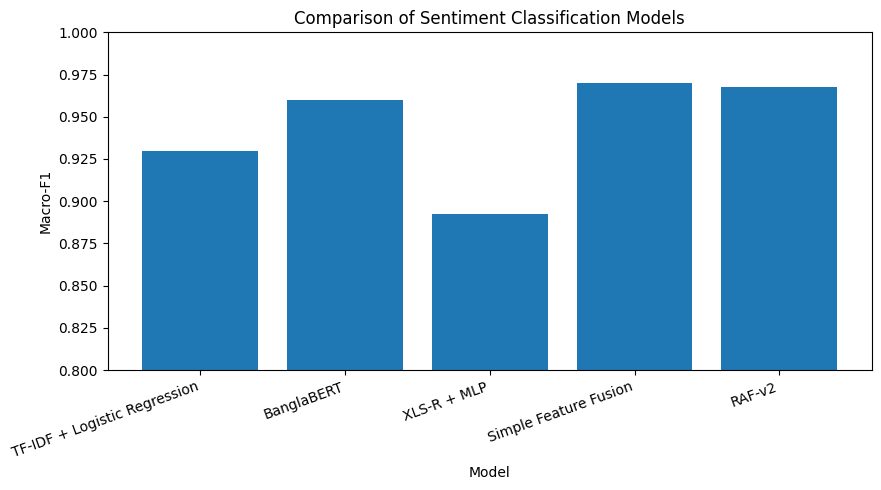

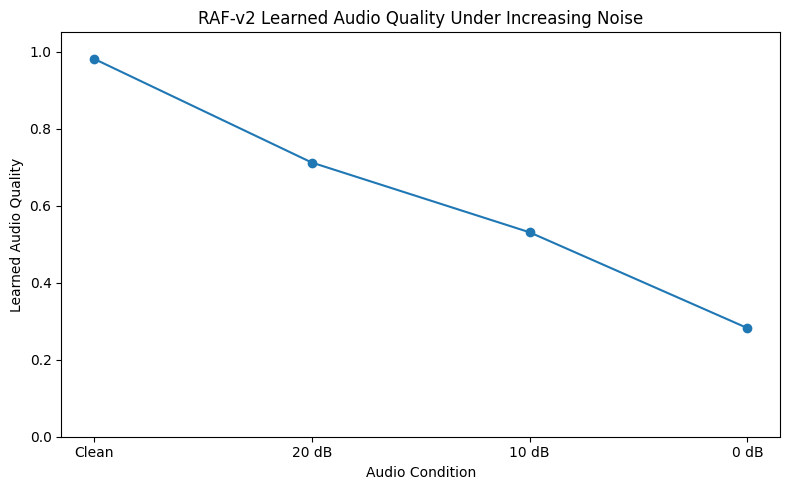

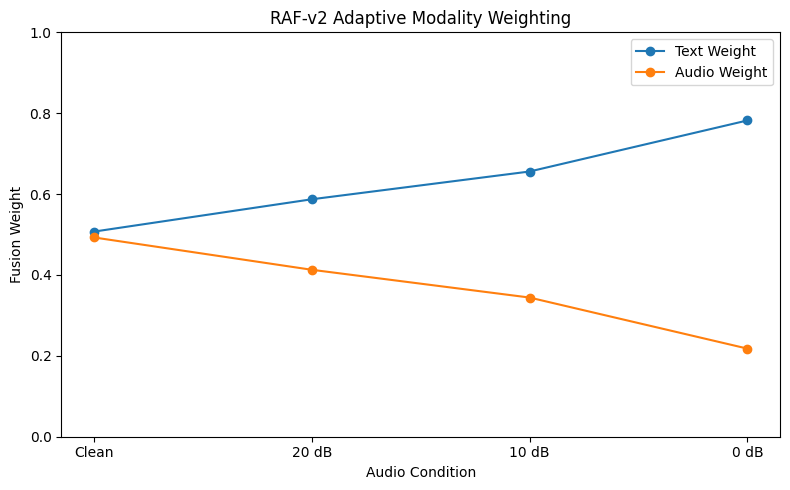

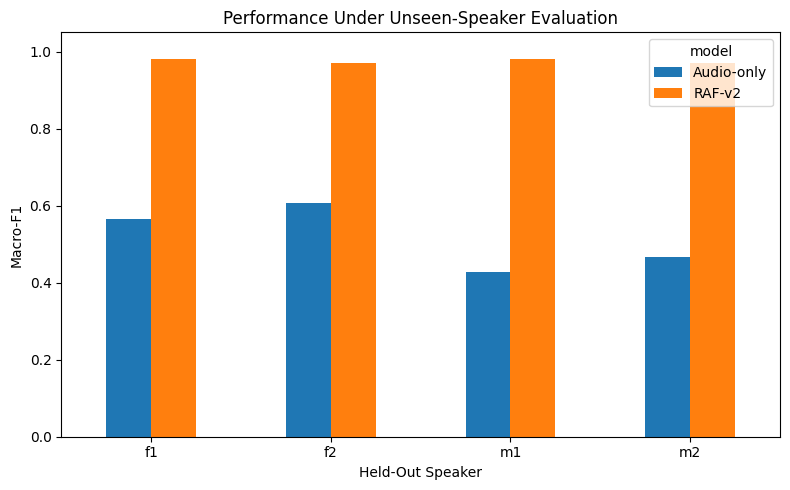

,Experiment,Main Result
0,BanglaBERT text-only,Macro-F1 = 0.9599
1,XLS-R audio-only,Macro-F1 = 0.8924
2,Simple multimodal fusion,Macro-F1 = 0.9700
3,RAF-v2 clean,Macro-F1 = 0.9675
4,RAF-v2 at 0 dB,Macro-F1 = 0.9700
5,RAF-v2 missing text,Macro-F1 = 0.8521
6,Simple fusion missing text,Macro-F1 = 0.3333
7,Audio-only unseen speaker,Mean Macro-F1 = 0.5171 ± 0.0839
8,RAF-v2 unseen speaker,Mean Macro-F1 = 0.9775 ± 0.0050


THESIS EXPERIMENTAL IMPLEMENTATION COMPLETE


In [525]:
# Step 12.1 — Main model comparison table

# ============================================================
# FINAL MAIN MODEL COMPARISON
# ============================================================

final_model_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Modality": "Text",
        "Test Accuracy": 0.9300,
        "Macro F1": 0.9298,
        "ROC-AUC": np.nan
    },

    {
        "Model": "BanglaBERT",
        "Modality": "Text",
        "Test Accuracy": 0.9600,
        "Macro F1": 0.9599,
        "ROC-AUC": 0.9752
    },

    {
        "Model": "XLS-R + MLP",
        "Modality": "Audio",
        "Test Accuracy": 0.8925,
        "Macro F1": 0.8924,
        "ROC-AUC": 0.9642
    },

    {
        "Model": "Simple Feature Fusion",
        "Modality": "Text + Audio",
        "Test Accuracy": 0.9700,
        "Macro F1": 0.9700,
        "ROC-AUC": 0.9800
    },

    {
        "Model": "RAF-v2",
        "Modality": "Text + Audio",
        "Test Accuracy": 0.9675,
        "Macro F1": 0.9675,
        "ROC-AUC": 0.9890
    }
])

display(
    final_model_comparison.round(4)
)

FINAL_MODEL_TABLE_PATH = (
    PROJECT_ROOT /
    "results" /
    "final_model_comparison.csv"
)

final_model_comparison.to_csv(
    FINAL_MODEL_TABLE_PATH,
    index=False
)

print("Saved:", FINAL_MODEL_TABLE_PATH)



# Step 12.2 — Final RAF-v2 robustness table

final_raf_robustness = (
    raf2_test_summary_df[
        [
            "condition",
            "pair_accuracy",
            "pair_macro_f1",
            "pair_roc_auc",
            "sentence_macro_f1",
            "text_quality",
            "audio_quality",
            "text_weight",
            "audio_weight"
        ]
    ]
    .copy()
)

display(
    final_raf_robustness.round(4)
)

FINAL_RAF_ROBUSTNESS_PATH = (
    PROJECT_ROOT /
    "results" /
    "final_raf_v2_robustness_table.csv"
)

final_raf_robustness.to_csv(
    FINAL_RAF_ROBUSTNESS_PATH,
    index=False
)

print("Saved:", FINAL_RAF_ROBUSTNESS_PATH)



# Step 12.3 — Final reliability behavior table


final_reliability_table = (
    raf2_test_summary_df[
        raf2_test_summary_df[
            "condition"
        ].isin([
            "Clean",
            "20 dB",
            "10 dB",
            "0 dB"
        ])
    ][
        [
            "condition",
            "audio_quality",
            "text_weight",
            "audio_weight",
            "pair_macro_f1"
        ]
    ]
    .copy()
)

display(
    final_reliability_table.round(4)
)




# Step 12.4 — Missing-modality comparison


missing_final = pd.DataFrame([
    {
        "Condition": "Missing Audio",
        "Simple Fusion Macro-F1": 0.9700,
        "RAF-v2 Macro-F1": 0.9700
    },

    {
        "Condition": "Missing Text",
        "Simple Fusion Macro-F1": 0.3333,
        "RAF-v2 Macro-F1": 0.8521
    }
])

missing_final[
    "RAF-v2 Improvement"
] = (
    missing_final[
        "RAF-v2 Macro-F1"
    ]
    -
    missing_final[
        "Simple Fusion Macro-F1"
    ]
)

display(
    missing_final.round(4)
)

missing_final.to_csv(
    PROJECT_ROOT /
    "results" /
    "final_missing_modality_comparison.csv",
    index=False
)




# Step 12.5 — Final unseen-speaker table

final_loso_table = (
    loso_f1_table
    .copy()
)

display(
    final_loso_table.round(4)
)

FINAL_LOSO_PATH = (
    PROJECT_ROOT /
    "results" /
    "final_unseen_speaker_macro_f1.csv"
)

final_loso_table.to_csv(
    FINAL_LOSO_PATH
)

print("Saved:", FINAL_LOSO_PATH)



# Step 12.6 — Plot main model comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["Macro F1"]
)

plt.ylabel("Macro-F1")
plt.xlabel("Model")

plt.title(
    "Comparison of Sentiment Classification Models"
)

plt.ylim(0.80, 1.00)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

MAIN_MODEL_FIGURE = (
    PROJECT_ROOT /
    "figures" /
    "final_model_macro_f1_comparison.png"
)

plt.savefig(
    MAIN_MODEL_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# Step 12.7 — Plot RAF-v2 learned audio quality

quality_df = (
    final_reliability_table
    .set_index("condition")
    .loc[
        [
            "Clean",
            "20 dB",
            "10 dB",
            "0 dB"
        ]
    ]
)

plt.figure(figsize=(8, 5))

plt.plot(
    quality_df.index,
    quality_df["audio_quality"],
    marker="o"
)

plt.xlabel("Audio Condition")
plt.ylabel("Learned Audio Quality")

plt.title(
    "RAF-v2 Learned Audio Quality Under Increasing Noise"
)

plt.ylim(0, 1.05)

plt.tight_layout()

QUALITY_FIGURE_PATH = (
    PROJECT_ROOT /
    "figures" /
    "raf_v2_audio_quality_under_noise.png"
)

plt.savefig(
    QUALITY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()




# Step 12.8 — Plot adaptive modality weights

plt.figure(figsize=(8, 5))

plt.plot(
    quality_df.index,
    quality_df["text_weight"],
    marker="o",
    label="Text Weight"
)

plt.plot(
    quality_df.index,
    quality_df["audio_weight"],
    marker="o",
    label="Audio Weight"
)

plt.xlabel("Audio Condition")
plt.ylabel("Fusion Weight")

plt.title(
    "RAF-v2 Adaptive Modality Weighting"
)

plt.ylim(0, 1)

plt.legend()
plt.tight_layout()

WEIGHT_FIGURE_PATH = (
    PROJECT_ROOT /
    "figures" /
    "raf_v2_adaptive_modality_weights.png"
)

plt.savefig(
    WEIGHT_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()




# Step 12.9 — Plot unseen-speaker comparison


loso_plot_df = (
    loso_results_df[
        [
            "speaker",
            "model",
            "macro_f1"
        ]
    ]
    .pivot(
        index="speaker",
        columns="model",
        values="macro_f1"
    )
    .loc[
        ["f1", "f2", "m1", "m2"]
    ]
)

ax = loso_plot_df.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_xlabel(
    "Held-Out Speaker"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Performance Under Unseen-Speaker Evaluation"
)

ax.set_ylim(
    0,
    1.05
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

LOSO_FIGURE_PATH = (
    PROJECT_ROOT /
    "figures" /
    "unseen_speaker_comparison.png"
)

plt.savefig(
    LOSO_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()




# Step 12.10 — Create a final implementation summary file

final_summary = pd.DataFrame([
    {
        "Experiment":
            "BanglaBERT text-only",

        "Main Result":
            "Macro-F1 = 0.9599"
    },

    {
        "Experiment":
            "XLS-R audio-only",

        "Main Result":
            "Macro-F1 = 0.8924"
    },

    {
        "Experiment":
            "Simple multimodal fusion",

        "Main Result":
            "Macro-F1 = 0.9700"
    },

    {
        "Experiment":
            "RAF-v2 clean",

        "Main Result":
            "Macro-F1 = 0.9675"
    },

    {
        "Experiment":
            "RAF-v2 at 0 dB",

        "Main Result":
            "Macro-F1 = 0.9700"
    },

    {
        "Experiment":
            "RAF-v2 missing text",

        "Main Result":
            "Macro-F1 = 0.8521"
    },

    {
        "Experiment":
            "Simple fusion missing text",

        "Main Result":
            "Macro-F1 = 0.3333"
    },

    {
        "Experiment":
            "Audio-only unseen speaker",

        "Main Result":
            "Mean Macro-F1 = 0.5171 ± 0.0839"
    },

    {
        "Experiment":
            "RAF-v2 unseen speaker",

        "Main Result":
            "Mean Macro-F1 = 0.9775 ± 0.0050"
    }
])

display(final_summary)

final_summary.to_csv(
    PROJECT_ROOT /
    "results" /
    "FINAL_THESIS_IMPLEMENTATION_SUMMARY.csv",
    index=False
)

print("=" * 80)
print("THESIS EXPERIMENTAL IMPLEMENTATION COMPLETE")
print("=" * 80)




In [526]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# FINAL RAF-v2 RESULTS FROM THE COMPLETED THESIS NOTEBOOK
# ============================================================

paper_quality_df = pd.DataFrame({
    "condition": [
        "Clean",
        "20 dB",
        "10 dB",
        "0 dB"
    ],
    "audio_quality": [
        0.9769,
        0.7259,
        0.5039,
        0.2764
    ],
    "audio_weight": [
        0.4786,
        0.4052,
        0.3209,
        0.2058
    ],
    "text_weight": [
        0.5214,
        0.5948,
        0.6791,
        0.7942
    ]
})

print("=" * 70)
print("RAF-v2 QUALITY AND MODALITY WEIGHT RESULTS")
print("=" * 70)

display(paper_quality_df)

RAF-v2 QUALITY AND MODALITY WEIGHT RESULTS


,condition,audio_quality,audio_weight,text_weight
0,Clean,0.9769,0.4786,0.5214
1,20 dB,0.7259,0.4052,0.5948
2,10 dB,0.5039,0.3209,0.6791
3,0 dB,0.2764,0.2058,0.7942


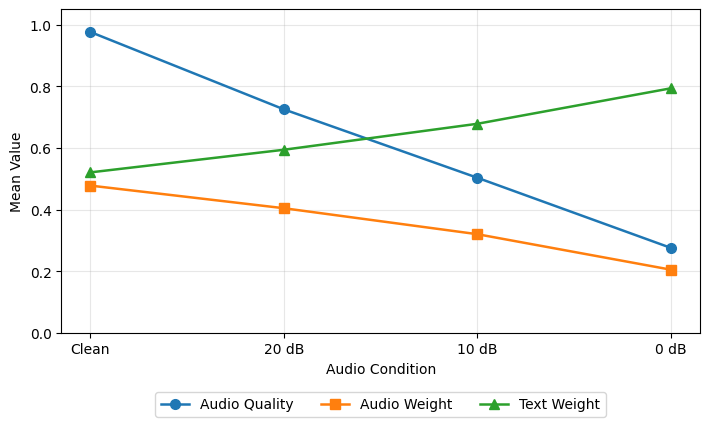

In [527]:
# ============================================================
# IEEE PAPER FIGURE
# RAF-v2 QUALITY ESTIMATION AND ADAPTIVE MODALITY WEIGHTS
# ============================================================

plt.figure(figsize=(7.2, 4.4))

plt.plot(
    paper_quality_df["condition"],
    paper_quality_df["audio_quality"],
    marker="o",
    linewidth=1.8,
    markersize=7,
    label="Audio Quality"
)

plt.plot(
    paper_quality_df["condition"],
    paper_quality_df["audio_weight"],
    marker="s",
    linewidth=1.8,
    markersize=7,
    label="Audio Weight"
)

plt.plot(
    paper_quality_df["condition"],
    paper_quality_df["text_weight"],
    marker="^",
    linewidth=1.8,
    markersize=7,
    label="Text Weight"
)

plt.xlabel("Audio Condition")
plt.ylabel("Mean Value")

plt.ylim(0, 1.05)

plt.grid(
    True,
    alpha=0.3
)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3,
    frameon=True
)

plt.tight_layout()

plt.show()

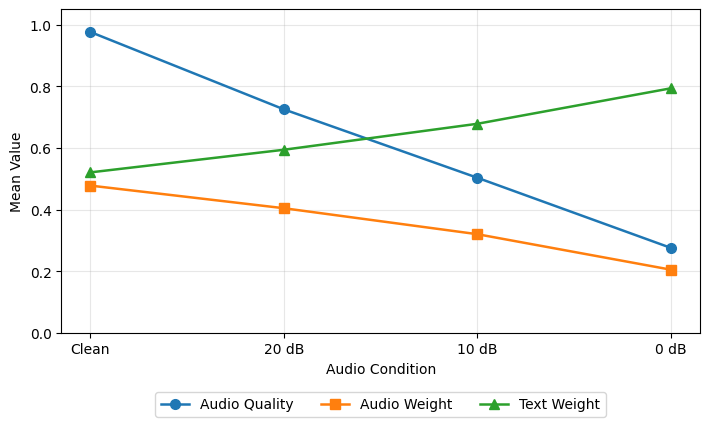

Saved: /kaggle/working/paper_figures/raf_v2_quality_and_weights.png


In [528]:
OUTPUT_DIR = Path("/kaggle/working/paper_figures")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    OUTPUT_DIR /
    "raf_v2_quality_and_weights.png"
)

plt.figure(figsize=(7.2, 4.4))

plt.plot(
    paper_quality_df["condition"],
    paper_quality_df["audio_quality"],
    marker="o",
    linewidth=1.8,
    markersize=7,
    label="Audio Quality"
)

plt.plot(
    paper_quality_df["condition"],
    paper_quality_df["audio_weight"],
    marker="s",
    linewidth=1.8,
    markersize=7,
    label="Audio Weight"
)

plt.plot(
    paper_quality_df["condition"],
    paper_quality_df["text_weight"],
    marker="^",
    linewidth=1.8,
    markersize=7,
    label="Text Weight"
)

plt.xlabel("Audio Condition")
plt.ylabel("Mean Value")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3
)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

In [529]:
# ============================================================
# PRE-STEP-13 LIVE SESSION CHECK
# ============================================================

required_objects = [

    # Core data
    "text_train_df",
    "text_val_df",
    "text_test_df",

    # Aligned text embeddings
    "X_text_train_aligned",
    "X_text_val_aligned",
    "X_text_test_aligned",

    # Aligned clean audio embeddings
    "X_audio_train_aligned",
    "X_audio_val_aligned",
    "X_audio_test_aligned",

    # Labels
    "y_mm_train",
    "y_mm_val",
    "y_mm_test",

    # Metadata
    "train_meta_check",
    "val_meta_check",
    "test_meta_check",

    # Noisy training audio
    "train_audio_20_v2",
    "train_audio_10_v2",
    "train_audio_0_v2",

    # Noisy validation audio
    "val_audio_20_v2",
    "val_audio_10_v2",
    "val_audio_0_v2",

    # Model classes
    "AudioSentimentClassifier",
    "SimpleMultimodalFusion",
    "ReliabilityAwareFusion",
    "ReliabilityAwareFusionV2"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

print("=" * 75)
print("PRE-STEP-13 LIVE SESSION CHECK")
print("=" * 75)

if len(missing_objects) == 0:

    print("STATUS: PASSED")
    print(
        f"All {len(required_objects)} "
        "required objects are available."
    )

else:

    print("STATUS: FAILED")

    print("\nMissing objects:")

    for name in missing_objects:
        print(" -", name)

PRE-STEP-13 LIVE SESSION CHECK
STATUS: PASSED
All 25 required objects are available.


# Step 13 — Multi-Seed Reproducibility and Statistical Robustness Analysis

This section addresses the supervisor feedback by rerunning the stochastic training components across multiple random seeds while keeping the dataset split and controlled noise realizations fixed.

The goal is to report:
- mean ± standard deviation across runs,
- bootstrap confidence intervals,
- robustness comparison plots,
- and aggregated error analysis.

In [532]:
# ============================================================
# Step 13A — MULTI-SEED EXPERIMENT CONFIGURATION
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# FIXED EXPERIMENT COMPONENTS
# ------------------------------------------------------------
# Dataset split remains fixed.
# Noise realization remains fixed.
# Only model-training randomness changes.
# ------------------------------------------------------------

SPLIT_SEED = 42
NOISE_SEED = 42

RUN_SEEDS = [
    42,
    7,
    123,
    2026
]

BOOTSTRAP_SEED = 2026
N_BOOTSTRAP = 5000


# ============================================================
# REPRODUCIBILITY HELPER
# ============================================================

def set_run_seed(seed):
    """
    Reset all relevant random number generators before
    each independent model-training run.
    """

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Improve deterministic behavior where possible
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:
        torch.use_deterministic_algorithms(
            True,
            warn_only=True
        )
    except Exception:
        pass


# ============================================================
# SEEDED DATALOADER GENERATOR
# ============================================================

def make_torch_generator(seed):
    """
    Returns a reproducibly seeded generator for DataLoader
    shuffling.
    """

    generator = torch.Generator()
    generator.manual_seed(seed)

    return generator


# ============================================================
# GPU MEMORY CLEANUP
# ============================================================

def clear_gpu_memory():
    """
    Frees unused Python and CUDA memory between runs.
    """

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# CONFIGURATION SUMMARY
# ============================================================

print("=" * 75)
print("MULTI-SEED EXPERIMENT CONFIGURATION")
print("=" * 75)

print("Fixed split seed:", SPLIT_SEED)
print("Fixed noise seed:", NOISE_SEED)

print("\nTraining seeds:")
print(RUN_SEEDS)

print(
    "\nNumber of independent runs:",
    len(RUN_SEEDS)
)

print(
    "Bootstrap repetitions:",
    N_BOOTSTRAP
)

print(
    "Bootstrap seed:",
    BOOTSTRAP_SEED
)


# ============================================================
# BASIC VALIDATION
# ============================================================

assert len(RUN_SEEDS) >= 3

assert (
    len(set(RUN_SEEDS))
    ==
    len(RUN_SEEDS)
)

assert SPLIT_SEED == 42
assert NOISE_SEED == 42

print("\nConfiguration check passed.")

MULTI-SEED EXPERIMENT CONFIGURATION
Fixed split seed: 42
Fixed noise seed: 42

Training seeds:
[42, 7, 123, 2026]

Number of independent runs: 4
Bootstrap repetitions: 5000
Bootstrap seed: 2026

Configuration check passed.


In [533]:
# ============================================================
# Step 13B.1 — MULTI-SEED OUTPUT DIRECTORIES
# ============================================================

from pathlib import Path

MULTISEED_ROOT = (
    PROJECT_ROOT /
    "multiseed"
)

MULTISEED_MODEL_DIR = (
    MULTISEED_ROOT /
    "models"
)

MULTISEED_EMBEDDING_DIR = (
    MULTISEED_ROOT /
    "embeddings"
)

MULTISEED_RESULTS_DIR = (
    MULTISEED_ROOT /
    "results"
)

MULTISEED_PREDICTION_DIR = (
    MULTISEED_ROOT /
    "predictions"
)

MULTISEED_HISTORY_DIR = (
    MULTISEED_ROOT /
    "training_history"
)

for directory in [
    MULTISEED_ROOT,
    MULTISEED_MODEL_DIR,
    MULTISEED_EMBEDDING_DIR,
    MULTISEED_RESULTS_DIR,
    MULTISEED_PREDICTION_DIR,
    MULTISEED_HISTORY_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 75)
print("MULTI-SEED OUTPUT DIRECTORIES")
print("=" * 75)

print("Root:", MULTISEED_ROOT)
print("Models:", MULTISEED_MODEL_DIR)
print("Embeddings:", MULTISEED_EMBEDDING_DIR)
print("Results:", MULTISEED_RESULTS_DIR)
print("Predictions:", MULTISEED_PREDICTION_DIR)
print("History:", MULTISEED_HISTORY_DIR)





MULTI-SEED OUTPUT DIRECTORIES
Root: /kaggle/working/bangla_multimodal_thesis/multiseed
Models: /kaggle/working/bangla_multimodal_thesis/multiseed/models
Embeddings: /kaggle/working/bangla_multimodal_thesis/multiseed/embeddings
Results: /kaggle/working/bangla_multimodal_thesis/multiseed/results
Predictions: /kaggle/working/bangla_multimodal_thesis/multiseed/predictions
History: /kaggle/working/bangla_multimodal_thesis/multiseed/training_history


In [534]:
# ============================================================
# Step 13B.2 — BANGLABERT MULTI-SEED CONFIGURATION
# ============================================================

TEXT_MS_BATCH_SIZE = 16
TEXT_MS_LEARNING_RATE = 2e-5
TEXT_MS_WEIGHT_DECAY = 0.01

TEXT_MS_MAX_EPOCHS = 10
TEXT_MS_PATIENCE = 3

TEXT_MS_WARMUP_RATIO = 0.10

TEXT_MS_EMBED_BATCH_SIZE = 32


print("=" * 75)
print("BANGLABERT MULTI-SEED CONFIGURATION")
print("=" * 75)

print("Model:", MODEL_NAME)
print("Batch size:", TEXT_MS_BATCH_SIZE)
print("Learning rate:", TEXT_MS_LEARNING_RATE)
print("Weight decay:", TEXT_MS_WEIGHT_DECAY)
print("Maximum epochs:", TEXT_MS_MAX_EPOCHS)
print("Early stopping:", TEXT_MS_PATIENCE)
print("Warm-up ratio:", TEXT_MS_WARMUP_RATIO)
print("Embedding batch size:", TEXT_MS_EMBED_BATCH_SIZE)

BANGLABERT MULTI-SEED CONFIGURATION
Model: csebuetnlp/banglabert
Batch size: 16
Learning rate: 2e-05
Weight decay: 0.01
Maximum epochs: 10
Early stopping: 3
Warm-up ratio: 0.1
Embedding batch size: 32


In [535]:
# ============================================================
# Step 13B.3 — RELEASE OLD MODEL INSTANCES
# ============================================================

old_model_instances = [
    "model",
    "text_model_for_embeddings",
    "audio_classifier",
    "simple_fusion_model",
    "raf_model",
    "raf2_model"
]

for variable_name in old_model_instances:
    globals().pop(
        variable_name,
        None
    )

clear_gpu_memory()

print("Old model instances released.")

if torch.cuda.is_available():

    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated()
            / (1024 ** 3),
            3
        ),
        "GB"
    )

Old model instances released.
GPU allocated: 0.153 GB


In [536]:
# ============================================================
# Step 13B.4 — SEED-SPECIFIC TEXT DATALOADERS
# ============================================================

from torch.utils.data import DataLoader


def create_text_dataloaders_for_seed(seed):

    train_generator = (
        make_torch_generator(seed)
    )

    train_loader_seed = DataLoader(
        train_dataset,
        batch_size=TEXT_MS_BATCH_SIZE,
        shuffle=True,
        collate_fn=data_collator,
        generator=train_generator
    )

    val_loader_seed = DataLoader(
        val_dataset,
        batch_size=TEXT_MS_BATCH_SIZE,
        shuffle=False,
        collate_fn=data_collator
    )

    test_loader_seed = DataLoader(
        test_dataset,
        batch_size=TEXT_MS_BATCH_SIZE,
        shuffle=False,
        collate_fn=data_collator
    )

    return (
        train_loader_seed,
        val_loader_seed,
        test_loader_seed
    )


# Quick test
temp_train_loader, temp_val_loader, temp_test_loader = (
    create_text_dataloaders_for_seed(42)
)

print("=" * 75)
print("SEED-SPECIFIC DATALOADER CHECK")
print("=" * 75)

print(
    "Train batches:",
    len(temp_train_loader)
)

print(
    "Validation batches:",
    len(temp_val_loader)
)

print(
    "Test batches:",
    len(temp_test_loader)
)

del (
    temp_train_loader,
    temp_val_loader,
    temp_test_loader
)

SEED-SPECIFIC DATALOADER CHECK
Train batches: 50
Validation batches: 7
Test batches: 7


In [540]:
# ============================================================
# Step 13B.5 — TRAIN ONE BANGLABERT SEED
# ============================================================

import time

from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from torch.optim import AdamW

from sklearn.metrics import roc_auc_score


def train_banglabert_seed(seed):

    print("\n" + "=" * 90)
    print(
        f"BANGLABERT MULTI-SEED RUN — SEED {seed}"
    )
    print("=" * 90)

    # --------------------------------------------------------
    # REPRODUCIBILITY
    # --------------------------------------------------------

    set_run_seed(seed)

    clear_gpu_memory()

    # --------------------------------------------------------
    # DATALOADERS
    # --------------------------------------------------------

    (
        train_loader_seed,
        val_loader_seed,
        test_loader_seed
    ) = create_text_dataloaders_for_seed(
        seed
    )

    # --------------------------------------------------------
    # FRESH MODEL
    # --------------------------------------------------------

    set_run_seed(seed)

    seed_model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            MODEL_NAME,
            num_labels=2,
            id2label=id2label,
            label2id=label2id
        )
    )

    seed_model = seed_model.to(device)

    # --------------------------------------------------------
    # OPTIMIZER
    # --------------------------------------------------------

    seed_optimizer = AdamW(
        seed_model.parameters(),
        lr=TEXT_MS_LEARNING_RATE,
        weight_decay=TEXT_MS_WEIGHT_DECAY
    )

    # --------------------------------------------------------
    # SCHEDULER
    # --------------------------------------------------------

    total_steps = (
        len(train_loader_seed)
        *
        TEXT_MS_MAX_EPOCHS
    )

    warmup_steps = int(
        TEXT_MS_WARMUP_RATIO
        *
        total_steps
    )

    seed_scheduler = (
        get_linear_schedule_with_warmup(
            seed_optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_steps
        )
    )

    # --------------------------------------------------------
    # CHECKPOINT
    # --------------------------------------------------------

    checkpoint_path = (
        MULTISEED_MODEL_DIR /
        f"banglabert_seed_{seed}.pt"
    )

    # --------------------------------------------------------
    # TRAINING STATE
    # --------------------------------------------------------

    best_val_f1 = -1.0
    best_val_loss = np.inf
    best_epoch = 0

    epochs_without_improvement = 0

    seed_history = []

    run_start_time = time.time()

    # --------------------------------------------------------
    # TRAINING LOOP
    # --------------------------------------------------------

    for epoch in range(
        1,
        TEXT_MS_MAX_EPOCHS + 1
    ):

        epoch_start = time.time()

        train_loss, train_metrics = (
            train_one_epoch(
                model=seed_model,
                dataloader=train_loader_seed,
                optimizer=seed_optimizer,
                scheduler=seed_scheduler,
                device=device
            )
        )

        (
            val_loss,
            val_metrics,
            _,
            _,
            _
        ) = evaluate_model(
            model=seed_model,
            dataloader=val_loader_seed,
            device=device
        )

        current_val_f1 = (
            val_metrics["f1_macro"]
        )

        # ----------------------------------------------------
        # SAME MODEL-SELECTION RULE AS ORIGINAL PIPELINE:
        # primary criterion = validation Macro-F1
        # ----------------------------------------------------

        if current_val_f1 > best_val_f1:

            best_val_f1 = current_val_f1
            best_val_loss = val_loss
            best_epoch = epoch

            epochs_without_improvement = 0

            torch.save(
                seed_model.state_dict(),
                checkpoint_path
            )

            status = "BEST"

        else:

            epochs_without_improvement += 1

            status = (
                f"No improvement "
                f"({epochs_without_improvement}/"
                f"{TEXT_MS_PATIENCE})"
            )

        epoch_seconds = (
            time.time()
            -
            epoch_start
        )

        seed_history.append({

            "seed":
                seed,

            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "train_accuracy":
                train_metrics["accuracy"],

            "train_f1_macro":
                train_metrics["f1_macro"],

            "val_loss":
                val_loss,

            "val_accuracy":
                val_metrics["accuracy"],

            "val_f1_macro":
                val_metrics["f1_macro"],

            "epoch_time_seconds":
                epoch_seconds
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Train F1={train_metrics['f1_macro']:.4f} | "
            f"Val F1={current_val_f1:.4f} | "
            f"Val Loss={val_loss:.4f} | "
            f"{status}"
        )

        # ----------------------------------------------------
        # EARLY STOPPING
        # ----------------------------------------------------

        if (
            epochs_without_improvement
            >= TEXT_MS_PATIENCE
        ):

            print(
                f"Early stopping at epoch {epoch}."
            )

            break

    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        seed_history
    )

    history_path = (
        MULTISEED_HISTORY_DIR /
        f"banglabert_seed_{seed}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    # --------------------------------------------------------
    # LOAD BEST CHECKPOINT
    # --------------------------------------------------------

    best_state = torch.load(
        checkpoint_path,
        map_location=device
    )

    seed_model.load_state_dict(
        best_state
    )

    seed_model = seed_model.to(device)
    seed_model.eval()

    # --------------------------------------------------------
    # FINAL TEST
    # --------------------------------------------------------

    (
        test_loss,
        test_metrics,
        test_predictions,
        test_labels,
        test_probabilities
    ) = evaluate_model(
        model=seed_model,
        dataloader=test_loader_seed,
        device=device
    )

    test_auc = roc_auc_score(
        test_labels,
        test_probabilities[:, 1]
    )

    # --------------------------------------------------------
    # SAVE TEST PREDICTIONS
    # --------------------------------------------------------

    prediction_df = (
        text_test_df[
            [
                "sentence_id",
                "sentence_number",
                "sentiment",
                "label"
            ]
        ]
        .copy()
        .reset_index(drop=True)
    )

    prediction_df[
        "seed"
    ] = seed

    prediction_df[
        "predicted_label"
    ] = test_predictions

    prediction_df[
        "prob_negative"
    ] = test_probabilities[:, 0]

    prediction_df[
        "prob_positive"
    ] = test_probabilities[:, 1]

    prediction_df[
        "correct"
    ] = (
        prediction_df["label"]
        ==
        prediction_df["predicted_label"]
    )

    prediction_path = (
        MULTISEED_PREDICTION_DIR /
        f"banglabert_seed_{seed}_test_predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False,
        encoding="utf-8-sig"
    )

    # --------------------------------------------------------
    # EXTRACT SEED-SPECIFIC TEXT EMBEDDINGS
    # --------------------------------------------------------

    print(
        f"\nExtracting seed-{seed} "
        "BanglaBERT embeddings..."
    )

    train_embeddings = (
        extract_text_embeddings(
            dataframe=text_train_df,
            model=seed_model,
            tokenizer=tokenizer,
            device=device,
            batch_size=
                TEXT_MS_EMBED_BATCH_SIZE
        )
    )

    val_embeddings = (
        extract_text_embeddings(
            dataframe=text_val_df,
            model=seed_model,
            tokenizer=tokenizer,
            device=device,
            batch_size=
                TEXT_MS_EMBED_BATCH_SIZE
        )
    )

    test_embeddings = (
        extract_text_embeddings(
            dataframe=text_test_df,
            model=seed_model,
            tokenizer=tokenizer,
            device=device,
            batch_size=
                TEXT_MS_EMBED_BATCH_SIZE
        )
    )

    # --------------------------------------------------------
    # SAVE EMBEDDINGS
    # --------------------------------------------------------

    train_embedding_path = (
        MULTISEED_EMBEDDING_DIR /
        f"banglabert_seed_{seed}_train.npy"
    )

    val_embedding_path = (
        MULTISEED_EMBEDDING_DIR /
        f"banglabert_seed_{seed}_validation.npy"
    )

    test_embedding_path = (
        MULTISEED_EMBEDDING_DIR /
        f"banglabert_seed_{seed}_test.npy"
    )

    np.save(
        train_embedding_path,
        train_embeddings
    )

    np.save(
        val_embedding_path,
        val_embeddings
    )

    np.save(
        test_embedding_path,
        test_embeddings
    )

    # --------------------------------------------------------
    # INTEGRITY CHECKS
    # --------------------------------------------------------

    assert (
        train_embeddings.shape
        ==
        (798, 768)
    )

    assert (
        val_embeddings.shape
        ==
        (100, 768)
    )

    assert (
        test_embeddings.shape
        ==
        (100, 768)
    )

    assert (
        np.isnan(
            train_embeddings
        ).sum()
        == 0
    )

    assert (
        np.isnan(
            val_embeddings
        ).sum()
        == 0
    )

    assert (
        np.isnan(
            test_embeddings
        ).sum()
        == 0
    )

    # --------------------------------------------------------
    # RESULT
    # --------------------------------------------------------

    result = {

        "seed":
            seed,

        "best_epoch":
            best_epoch,

        "best_val_f1":
            best_val_f1,

        "best_val_loss":
            best_val_loss,

        "test_loss":
            test_loss,

        "accuracy":
            test_metrics["accuracy"],

        "precision_macro":
            test_metrics[
                "precision_macro"
            ],

        "recall_macro":
            test_metrics[
                "recall_macro"
            ],

        "f1_macro":
            test_metrics["f1_macro"],

        "roc_auc":
            test_auc,

        "test_errors":
            int(
                np.sum(
                    test_predictions
                    !=
                    test_labels
                )
            ),

        "training_time_seconds":
            time.time()
            -
            run_start_time
    }

    print("\n" + "-" * 70)

    print(
        f"SEED {seed} COMPLETE"
    )

    print("-" * 70)

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best validation F1:",
        round(
            best_val_f1,
            4
        )
    )

    print(
        "Test Accuracy:",
        round(
            test_metrics["accuracy"],
            4
        )
    )

    print(
        "Test Macro-F1:",
        round(
            test_metrics["f1_macro"],
            4
        )
    )

    print(
        "Test ROC-AUC:",
        round(
            test_auc,
            4
        )
    )

    print(
        "Test errors:",
        result["test_errors"]
    )

    print(
        "Embedding shapes:",
        train_embeddings.shape,
        val_embeddings.shape,
        test_embeddings.shape
    )

    # --------------------------------------------------------
    # RELEASE MODEL
    # --------------------------------------------------------

    del seed_model
    del seed_optimizer
    del seed_scheduler
    del best_state

    clear_gpu_memory()

    return (
        result,
        {
            "train":
                train_embeddings,

            "validation":
                val_embeddings,

            "test":
                test_embeddings
        }
    )

In [541]:
# ============================================================
# Step 13B.6 — RUN ALL BANGLABERT SEEDS
# ============================================================

banglabert_multiseed_results = []

banglabert_multiseed_embeddings = {}


print("=" * 90)
print("STARTING 4-SEED BANGLABERT EXPERIMENT")
print("=" * 90)

print(
    "Seeds:",
    RUN_SEEDS
)


for seed in RUN_SEEDS:

    (
        seed_result,
        seed_embeddings
    ) = train_banglabert_seed(
        seed
    )

    banglabert_multiseed_results.append(
        seed_result
    )

    banglabert_multiseed_embeddings[
        seed
    ] = seed_embeddings


print("\n" + "=" * 90)
print("ALL BANGLABERT SEEDS COMPLETE")
print("=" * 90)

STARTING 4-SEED BANGLABERT EXPERIMENT
Seeds: [42, 7, 123, 2026]

BANGLABERT MULTI-SEED RUN — SEED 42


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

Training:   0%|          | 0/50 [00:00<?, ?it/s]

Validation:   0%|          | 0/7 [00:00<?, ?it/s]

Seed 42 | Epoch 01 | Train F1=0.7318 | Val F1=0.9900 | Val Loss=0.3156 | BEST


... (80 outputs left out)

Extracting BanglaBERT embeddings:   0%|          | 0/25 [00:00<?, ?it/s]

Extracting BanglaBERT embeddings:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting BanglaBERT embeddings:   0%|          | 0/4 [00:00<?, ?it/s]


----------------------------------------------------------------------
SEED 2026 COMPLETE
----------------------------------------------------------------------
Best epoch: 2
Best validation F1: 1.0
Test Accuracy: 0.96
Test Macro-F1: 0.9599
Test ROC-AUC: 0.9792
Test errors: 4
Embedding shapes: (798, 768) (100, 768) (100, 768)

ALL BANGLABERT SEEDS COMPLETE


In [542]:
# ============================================================
# Step 13B.7 — BANGLABERT PER-SEED RESULTS
# ============================================================

banglabert_multiseed_df = (
    pd.DataFrame(
        banglabert_multiseed_results
    )
)

display(
    banglabert_multiseed_df.round(4)
)

,seed,best_epoch,best_val_f1,best_val_loss,test_loss,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,test_errors,training_time_seconds
0,42,2,1.0,0.0149,0.2047,0.98,0.9808,0.98,0.9800,0.9844,2,28.6563
1,7,1,1.0,0.3690,0.4159,0.96,0.9630,0.96,0.9599,0.9936,4,22.4357
2,123,2,1.0,0.0179,0.2002,0.98,0.9808,0.98,0.9800,0.9748,2,28.5872
3,2026,2,1.0,0.0197,0.3392,0.96,0.9630,0.96,0.9599,0.9792,4,28.4340


In [543]:
# ============================================================
# Step 13B.8 — MEAN ± SD
# ============================================================

banglabert_summary = {

    "model":
        "BanglaBERT",

    "n_seeds":
        len(RUN_SEEDS),

    "accuracy_mean":
        banglabert_multiseed_df[
            "accuracy"
        ].mean(),

    "accuracy_sd":
        banglabert_multiseed_df[
            "accuracy"
        ].std(ddof=1),

    "f1_macro_mean":
        banglabert_multiseed_df[
            "f1_macro"
        ].mean(),

    "f1_macro_sd":
        banglabert_multiseed_df[
            "f1_macro"
        ].std(ddof=1),

    "roc_auc_mean":
        banglabert_multiseed_df[
            "roc_auc"
        ].mean(),

    "roc_auc_sd":
        banglabert_multiseed_df[
            "roc_auc"
        ].std(ddof=1)
}


print("=" * 75)
print("BANGLABERT MULTI-SEED SUMMARY")
print("=" * 75)

print(
    "Accuracy:",
    f"{banglabert_summary['accuracy_mean']:.4f}"
    f" ± "
    f"{banglabert_summary['accuracy_sd']:.4f}"
)

print(
    "Macro-F1:",
    f"{banglabert_summary['f1_macro_mean']:.4f}"
    f" ± "
    f"{banglabert_summary['f1_macro_sd']:.4f}"
)

print(
    "ROC-AUC:",
    f"{banglabert_summary['roc_auc_mean']:.4f}"
    f" ± "
    f"{banglabert_summary['roc_auc_sd']:.4f}"
)

BANGLABERT MULTI-SEED SUMMARY
Accuracy: 0.9700 ± 0.0115
Macro-F1: 0.9700 ± 0.0116
ROC-AUC: 0.9830 ± 0.0081


In [544]:
# ============================================================
# Step 13B.9 — SAVE BANGLABERT MULTI-SEED RESULTS
# ============================================================

BANGLABERT_MULTI_RAW_PATH = (
    MULTISEED_RESULTS_DIR /
    "banglabert_multiseed_raw_results.csv"
)

BANGLABERT_MULTI_SUMMARY_PATH = (
    MULTISEED_RESULTS_DIR /
    "banglabert_multiseed_summary.csv"
)


banglabert_multiseed_df.to_csv(
    BANGLABERT_MULTI_RAW_PATH,
    index=False
)


pd.DataFrame(
    [banglabert_summary]
).to_csv(
    BANGLABERT_MULTI_SUMMARY_PATH,
    index=False
)


print("Saved:")
print(BANGLABERT_MULTI_RAW_PATH)
print(BANGLABERT_MULTI_SUMMARY_PATH)

Saved:
/kaggle/working/bangla_multimodal_thesis/multiseed/results/banglabert_multiseed_raw_results.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/banglabert_multiseed_summary.csv


In [545]:
# ============================================================
# Step 13B.10 — SEED-SPECIFIC EMBEDDING INTEGRITY
# ============================================================

print("=" * 80)
print("BANGLABERT MULTI-SEED EMBEDDING CHECK")
print("=" * 80)


all_embedding_checks_passed = True


for seed in RUN_SEEDS:

    embeddings = (
        banglabert_multiseed_embeddings[
            seed
        ]
    )

    train_shape = (
        embeddings["train"].shape
    )

    val_shape = (
        embeddings["validation"].shape
    )

    test_shape = (
        embeddings["test"].shape
    )


    passed = (

        train_shape
        == (798, 768)

        and

        val_shape
        == (100, 768)

        and

        test_shape
        == (100, 768)

        and

        np.isfinite(
            embeddings["train"]
        ).all()

        and

        np.isfinite(
            embeddings["validation"]
        ).all()

        and

        np.isfinite(
            embeddings["test"]
        ).all()
    )


    print(
        f"Seed {seed}:",
        "PASSED"
        if passed
        else "FAILED"
    )

    print(
        "   Train:",
        train_shape,
        "| Val:",
        val_shape,
        "| Test:",
        test_shape
    )


    if not passed:
        all_embedding_checks_passed = False


print("\n" + "=" * 80)

if all_embedding_checks_passed:

    print(
        "FINAL STATUS: "
        "ALL BANGLABERT MULTI-SEED CHECKS PASSED"
    )

else:

    print(
        "FINAL STATUS: CHECK FAILED"
    )

print("=" * 80)

BANGLABERT MULTI-SEED EMBEDDING CHECK
Seed 42: PASSED
   Train: (798, 768) | Val: (100, 768) | Test: (100, 768)
Seed 7: PASSED
   Train: (798, 768) | Val: (100, 768) | Test: (100, 768)
Seed 123: PASSED
   Train: (798, 768) | Val: (100, 768) | Test: (100, 768)
Seed 2026: PASSED
   Train: (798, 768) | Val: (100, 768) | Test: (100, 768)

FINAL STATUS: ALL BANGLABERT MULTI-SEED CHECKS PASSED


In [546]:
# ============================================================
# Step 13C.1 — AUDIO-ONLY MULTI-SEED CONFIGURATION
# ============================================================

AUDIO_MS_BATCH_SIZE = 64
AUDIO_MS_LEARNING_RATE = 1e-3
AUDIO_MS_WEIGHT_DECAY = 1e-4

AUDIO_MS_MAX_EPOCHS = 30
AUDIO_MS_PATIENCE = 5

print("=" * 75)
print("AUDIO-ONLY MULTI-SEED CONFIGURATION")
print("=" * 75)

print("Input dimension: 1024")
print("Batch size:", AUDIO_MS_BATCH_SIZE)
print("Learning rate:", AUDIO_MS_LEARNING_RATE)
print("Weight decay:", AUDIO_MS_WEIGHT_DECAY)
print("Maximum epochs:", AUDIO_MS_MAX_EPOCHS)
print("Early stopping patience:", AUDIO_MS_PATIENCE)
print("Seeds:", RUN_SEEDS)

AUDIO-ONLY MULTI-SEED CONFIGURATION
Input dimension: 1024
Batch size: 64
Learning rate: 0.001
Weight decay: 0.0001
Maximum epochs: 30
Early stopping patience: 5
Seeds: [42, 7, 123, 2026]


In [547]:
# ============================================================
# Step 13C.2 — FIXED AUDIO DATASETS
# ============================================================

from torch.utils.data import TensorDataset, DataLoader


audio_train_dataset_ms = TensorDataset(
    torch.tensor(
        X_audio_train_aligned,
        dtype=torch.float32
    ),
    torch.tensor(
        y_mm_train,
        dtype=torch.long
    )
)

audio_val_dataset_ms = TensorDataset(
    torch.tensor(
        X_audio_val_aligned,
        dtype=torch.float32
    ),
    torch.tensor(
        y_mm_val,
        dtype=torch.long
    )
)

audio_test_dataset_ms = TensorDataset(
    torch.tensor(
        X_audio_test_aligned,
        dtype=torch.float32
    ),
    torch.tensor(
        y_mm_test,
        dtype=torch.long
    )
)


print("=" * 75)
print("AUDIO DATASET CHECK")
print("=" * 75)

print("Train:", len(audio_train_dataset_ms))
print("Validation:", len(audio_val_dataset_ms))
print("Test:", len(audio_test_dataset_ms))

AUDIO DATASET CHECK
Train: 3192
Validation: 400
Test: 400


In [548]:
# ============================================================
# Step 13C.3 — SEED-SPECIFIC AUDIO DATALOADERS
# ============================================================

def create_audio_dataloaders_for_seed(seed):

    train_generator = (
        make_torch_generator(seed)
    )

    train_loader_seed = DataLoader(
        audio_train_dataset_ms,
        batch_size=AUDIO_MS_BATCH_SIZE,
        shuffle=True,
        generator=train_generator
    )

    val_loader_seed = DataLoader(
        audio_val_dataset_ms,
        batch_size=AUDIO_MS_BATCH_SIZE,
        shuffle=False
    )

    test_loader_seed = DataLoader(
        audio_test_dataset_ms,
        batch_size=AUDIO_MS_BATCH_SIZE,
        shuffle=False
    )

    return (
        train_loader_seed,
        val_loader_seed,
        test_loader_seed
    )


temp_train, temp_val, temp_test = (
    create_audio_dataloaders_for_seed(42)
)

print("Train batches:", len(temp_train))
print("Validation batches:", len(temp_val))
print("Test batches:", len(temp_test))

del temp_train, temp_val, temp_test

Train batches: 50
Validation batches: 7
Test batches: 7


In [552]:
# ============================================================
# Step 13C.4 — AUDIO CONDITION EVALUATION HELPER
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


def evaluate_audio_condition(
    model,
    audio_embeddings,
    labels,
    batch_size=64
):

    condition_dataset = TensorDataset(
        torch.tensor(
            audio_embeddings,
            dtype=torch.float32
        ),
        torch.tensor(
            labels,
            dtype=torch.long
        )
    )

    condition_loader = DataLoader(
        condition_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for features, batch_labels in condition_loader:

            features = features.to(device)
            batch_labels = batch_labels.to(device)

            logits = model(features)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_labels.extend(
                batch_labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )


    labels_np = np.array(all_labels)

    predictions_np = np.array(
        all_predictions
    )

    probabilities_np = np.array(
        all_probabilities
    )


    metrics = {

        "accuracy":
            accuracy_score(
                labels_np,
                predictions_np
            ),

        "precision_macro":
            precision_score(
                labels_np,
                predictions_np,
                average="macro",
                zero_division=0
            ),

        "recall_macro":
            recall_score(
                labels_np,
                predictions_np,
                average="macro",
                zero_division=0
            ),

        "f1_macro":
            f1_score(
                labels_np,
                predictions_np,
                average="macro",
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels_np,
                probabilities_np[:, 1]
            ),

        "mean_confidence":
            probabilities_np.max(
                axis=1
            ).mean(),

        "errors":
            int(
                np.sum(
                    predictions_np
                    !=
                    labels_np
                )
            )
    }

    return (
        metrics,
        predictions_np,
        probabilities_np
    )

In [553]:
# ============================================================
# Step 13C.5 — TRAIN ONE AUDIO-ONLY SEED
# ============================================================

import torch.nn as nn
import time


def train_audio_seed(seed):

    print("\n" + "=" * 85)
    print(
        f"AUDIO-ONLY MULTI-SEED RUN — SEED {seed}"
    )
    print("=" * 85)

    set_run_seed(seed)
    clear_gpu_memory()

    (
        train_loader_seed,
        val_loader_seed,
        test_loader_seed
    ) = create_audio_dataloaders_for_seed(
        seed
    )

    # --------------------------------------------------------
    # FRESH MODEL
    # --------------------------------------------------------

    set_run_seed(seed)

    seed_model = AudioSentimentClassifier(
        input_dim=1024,
        hidden_dim=256,
        num_classes=2,
        dropout=0.30
    ).to(device)

    criterion_seed = (
        nn.CrossEntropyLoss()
    )

    optimizer_seed = (
        torch.optim.AdamW(
            seed_model.parameters(),
            lr=AUDIO_MS_LEARNING_RATE,
            weight_decay=
                AUDIO_MS_WEIGHT_DECAY
        )
    )

    checkpoint_path = (
        MULTISEED_MODEL_DIR /
        f"audio_mlp_seed_{seed}.pt"
    )

    best_val_f1 = -1.0
    best_val_loss = np.inf
    best_epoch = 0

    patience_count = 0

    run_start = time.time()

    history_rows = []

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    for epoch in range(
        1,
        AUDIO_MS_MAX_EPOCHS + 1
    ):

        (
            train_loss,
            train_metrics
        ) = train_audio_one_epoch(
            seed_model,
            train_loader_seed,
            criterion_seed,
            optimizer_seed,
            device
        )

        (
            val_loss,
            val_metrics,
            _,
            _,
            _
        ) = evaluate_audio_classifier(
            seed_model,
            val_loader_seed,
            criterion_seed,
            device
        )

        current_f1 = (
            val_metrics["f1_macro"]
        )

        improved = (
            current_f1
            >
            best_val_f1 + 1e-8
        )

        tied_better_loss = (
            abs(
                current_f1
                -
                best_val_f1
            ) <= 1e-8
            and
            val_loss < best_val_loss
        )

        if improved or tied_better_loss:

            best_val_f1 = current_f1
            best_val_loss = val_loss
            best_epoch = epoch

            patience_count = 0

            torch.save(
                seed_model.state_dict(),
                checkpoint_path
            )

            status = "BEST"

        else:

            patience_count += 1

            status = (
                f"No improvement "
                f"({patience_count}/"
                f"{AUDIO_MS_PATIENCE})"
            )

        history_rows.append({

            "seed": seed,
            "epoch": epoch,

            "train_loss":
                train_loss,

            "train_accuracy":
                train_metrics[
                    "accuracy"
                ],

            "train_f1_macro":
                train_metrics[
                    "f1_macro"
                ],

            "val_loss":
                val_loss,

            "val_accuracy":
                val_metrics[
                    "accuracy"
                ],

            "val_f1_macro":
                val_metrics[
                    "f1_macro"
                ]
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Train F1="
            f"{train_metrics['f1_macro']:.4f} | "
            f"Val F1="
            f"{current_f1:.4f} | "
            f"{status}"
        )

        if (
            patience_count
            >=
            AUDIO_MS_PATIENCE
        ):

            print(
                f"Early stopping at epoch {epoch}."
            )

            break

    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        history_rows
    )

    history_df.to_csv(
        MULTISEED_HISTORY_DIR /
        f"audio_mlp_seed_{seed}_history.csv",
        index=False
    )

    # --------------------------------------------------------
    # LOAD BEST MODEL
    # --------------------------------------------------------

    best_state = torch.load(
        checkpoint_path,
        map_location=device
    )

    seed_model.load_state_dict(
        best_state
    )

    seed_model.eval()

    # --------------------------------------------------------
    # CONDITIONS
    # --------------------------------------------------------

    audio_conditions = {

        "Clean":
            X_audio_test_aligned,

        "20 dB":
            test_audio_20_v2,

        "10 dB":
            test_audio_10_v2,

        "0 dB":
            test_audio_0_v2
    }

    condition_results = []

    # --------------------------------------------------------
    # TEST EACH CONDITION
    # --------------------------------------------------------

    for condition_name, embeddings in (
        audio_conditions.items()
    ):

        (
            metrics,
            predictions,
            probabilities
        ) = evaluate_audio_condition(
            model=seed_model,
            audio_embeddings=embeddings,
            labels=y_mm_test,
            batch_size=AUDIO_MS_BATCH_SIZE
        )

        row = {

            "seed":
                seed,

            "condition":
                condition_name,

            "best_epoch":
                best_epoch,

            "best_val_f1":
                best_val_f1,

            **metrics
        }

        condition_results.append(
            row
        )

        # ----------------------------------------------------
        # SAVE PREDICTIONS
        # ----------------------------------------------------

        prediction_df = (
            test_meta_check.copy()
            .reset_index(drop=True)
        )

        prediction_df[
            "seed"
        ] = seed

        prediction_df[
            "condition"
        ] = condition_name

        prediction_df[
            "predicted_label"
        ] = predictions

        prediction_df[
            "prob_negative"
        ] = probabilities[:, 0]

        prediction_df[
            "prob_positive"
        ] = probabilities[:, 1]

        prediction_df[
            "confidence"
        ] = probabilities.max(
            axis=1
        )

        prediction_df[
            "correct"
        ] = (
            prediction_df["label"]
            ==
            prediction_df[
                "predicted_label"
            ]
        )

        safe_condition_name = (
            condition_name
            .replace(" ", "_")
            .replace("/", "_")
        )

        prediction_df.to_csv(
            MULTISEED_PREDICTION_DIR /
            (
                f"audio_seed_{seed}_"
                f"{safe_condition_name}_"
                f"predictions.csv"
            ),
            index=False
        )

        print(
            f"{condition_name:8s} | "
            f"F1={metrics['f1_macro']:.4f} | "
            f"AUC={metrics['roc_auc']:.4f} | "
            f"Conf={metrics['mean_confidence']:.4f}"
        )

    total_time = (
        time.time()
        -
        run_start
    )

    print(
        f"\nSeed {seed} complete | "
        f"Best epoch={best_epoch} | "
        f"Time={total_time:.2f}s"
    )

    # --------------------------------------------------------
    # CLEANUP
    # --------------------------------------------------------

    del seed_model
    del optimizer_seed
    del criterion_seed
    del best_state

    clear_gpu_memory()

    return condition_results

In [554]:
# ============================================================
# Step 13C.6 — RUN ALL AUDIO-ONLY SEEDS
# ============================================================

audio_multiseed_results = []

print("=" * 90)
print("STARTING 4-SEED AUDIO-ONLY EXPERIMENT")
print("=" * 90)


for seed in RUN_SEEDS:

    seed_results = (
        train_audio_seed(
            seed
        )
    )

    audio_multiseed_results.extend(
        seed_results
    )


print("\n" + "=" * 90)
print("ALL AUDIO-ONLY SEEDS COMPLETE")
print("=" * 90)

STARTING 4-SEED AUDIO-ONLY EXPERIMENT

AUDIO-ONLY MULTI-SEED RUN — SEED 42


Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]

Seed 42 | Epoch 01 | Train F1=0.5650 | Val F1=0.6014 | BEST


Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]

Seed 42 | Epoch 02 | Train F1=0.6473 | Val F1=0.6081 | BEST


Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]

... (207 outputs left out)

Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]

Seed 2026 | Epoch 27 | Train F1=0.8549 | Val F1=0.8539 | No improvement (4/5)


Audio Training:   0%|          | 0/50 [00:00<?, ?it/s]

Seed 2026 | Epoch 28 | Train F1=0.8531 | Val F1=0.8767 | No improvement (5/5)
Early stopping at epoch 28.
Clean    | F1=0.8875 | AUC=0.9583 | Conf=0.8245
20 dB    | F1=0.7657 | AUC=0.8626 | Conf=0.7390
10 dB    | F1=0.4067 | AUC=0.8447 | Conf=0.8324
0 dB     | F1=0.3333 | AUC=0.7602 | Conf=0.9833

Seed 2026 complete | Best epoch=23 | Time=7.46s

ALL AUDIO-ONLY SEEDS COMPLETE


In [555]:
# ============================================================
# Step 13C.7 — AUDIO-ONLY RAW MULTI-SEED RESULTS
# ============================================================

audio_multiseed_df = pd.DataFrame(
    audio_multiseed_results
)

display(
    audio_multiseed_df.round(4)
)

print(
    "Rows:",
    len(audio_multiseed_df)
)

,seed,condition,best_epoch,best_val_f1,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,mean_confidence,errors
0,42,Clean,30,0.8925,0.8925,0.8942,0.8925,0.8924,0.9642,0.8300,43
1,42,20 dB,30,0.8925,0.7625,0.7793,0.7625,0.7589,0.8724,0.7348,95
2,42,10 dB,30,0.8925,0.5525,0.7639,0.5525,0.4404,0.8570,0.7670,179
3,42,0 dB,30,0.8925,0.5000,0.2500,0.5000,0.3333,0.7949,0.9478,200
4,7,Clean,22,0.8750,0.8800,0.8803,0.8800,0.8800,0.9543,0.8268,48
5,7,20 dB,22,0.8750,0.7400,0.7589,0.7400,0.7352,0.8638,0.7348,104
6,7,10 dB,22,0.8750,0.5400,0.7604,0.5400,0.4165,0.8335,0.8117,184
7,7,0 dB,22,0.8750,0.5000,0.2500,0.5000,0.3333,0.7543,0.9712,200
8,123,Clean,18,0.8650,0.8750,0.8756,0.8750,0.8749,0.9510,0.7690,50
9,123,20 dB,18,0.8650,0.7750,0.7805,0.7750,0.7739,0.8499,0.6665,90


Rows: 16


In [556]:
# ============================================================
# Step 13C.8 — AUDIO ROBUSTNESS MEAN ± SD
# ============================================================

audio_multiseed_summary = (
    audio_multiseed_df
    .groupby(
        "condition",
        sort=False
    )
    .agg(

        f1_mean=(
            "f1_macro",
            "mean"
        ),

        f1_sd=(
            "f1_macro",
            lambda x:
                x.std(ddof=1)
        ),

        auc_mean=(
            "roc_auc",
            "mean"
        ),

        auc_sd=(
            "roc_auc",
            lambda x:
                x.std(ddof=1)
        ),

        confidence_mean=(
            "mean_confidence",
            "mean"
        ),

        confidence_sd=(
            "mean_confidence",
            lambda x:
                x.std(ddof=1)
        )
    )
    .reset_index()
)

display(
    audio_multiseed_summary.round(4)
)

,condition,f1_mean,f1_sd,auc_mean,auc_sd,confidence_mean,confidence_sd
0,Clean,0.8837,0.0077,0.9570,0.0057,0.8126,0.0292
1,20 dB,0.7584,0.0167,0.8622,0.0093,0.7188,0.0349
2,10 dB,0.4100,0.0266,0.8410,0.0126,0.7972,0.0302
3,0 dB,0.3333,0.0000,0.7647,0.0206,0.9631,0.0171


In [557]:
print("=" * 85)
print("TABLE III — MULTI-SEED AUDIO ROBUSTNESS")
print("=" * 85)

for _, row in (
    audio_multiseed_summary
    .iterrows()
):

    print(
        f"{row['condition']:8s} | "
        f"F1 "
        f"{row['f1_mean']:.4f}"
        f" ± "
        f"{row['f1_sd']:.4f} | "
        f"AUC "
        f"{row['auc_mean']:.4f}"
        f" ± "
        f"{row['auc_sd']:.4f} | "
        f"Confidence "
        f"{row['confidence_mean']:.4f}"
        f" ± "
        f"{row['confidence_sd']:.4f}"
    )

TABLE III — MULTI-SEED AUDIO ROBUSTNESS
Clean    | F1 0.8837 ± 0.0077 | AUC 0.9570 ± 0.0057 | Confidence 0.8126 ± 0.0292
20 dB    | F1 0.7584 ± 0.0167 | AUC 0.8622 ± 0.0093 | Confidence 0.7188 ± 0.0349
10 dB    | F1 0.4100 ± 0.0266 | AUC 0.8410 ± 0.0126 | Confidence 0.7972 ± 0.0302
0 dB     | F1 0.3333 ± 0.0000 | AUC 0.7647 ± 0.0206 | Confidence 0.9631 ± 0.0171


In [558]:
# ============================================================
# Step 13C.9 — SAVE AUDIO MULTI-SEED RESULTS
# ============================================================

AUDIO_MULTI_RAW_PATH = (
    MULTISEED_RESULTS_DIR /
    "audio_multiseed_raw_results.csv"
)

AUDIO_MULTI_SUMMARY_PATH = (
    MULTISEED_RESULTS_DIR /
    "audio_multiseed_robustness_summary.csv"
)


audio_multiseed_df.to_csv(
    AUDIO_MULTI_RAW_PATH,
    index=False
)

audio_multiseed_summary.to_csv(
    AUDIO_MULTI_SUMMARY_PATH,
    index=False
)


print("Saved:")
print(AUDIO_MULTI_RAW_PATH)
print(AUDIO_MULTI_SUMMARY_PATH)

Saved:
/kaggle/working/bangla_multimodal_thesis/multiseed/results/audio_multiseed_raw_results.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/audio_multiseed_robustness_summary.csv


In [559]:
# ============================================================
# Step 13D.1 — SIMPLE FUSION MULTI-SEED CONFIGURATION
# ============================================================

SIMPLE_MS_BATCH_SIZE = 64
SIMPLE_MS_LEARNING_RATE = 1e-3
SIMPLE_MS_WEIGHT_DECAY = 1e-4

SIMPLE_MS_MAX_EPOCHS = 30
SIMPLE_MS_PATIENCE = 5

SIMPLE_MS_TEXT_DIM = 768
SIMPLE_MS_AUDIO_DIM = 1024
SIMPLE_MS_INPUT_DIM = 1792


print("=" * 80)
print("SIMPLE FUSION MULTI-SEED CONFIGURATION")
print("=" * 80)

print("Text dimension:", SIMPLE_MS_TEXT_DIM)
print("Audio dimension:", SIMPLE_MS_AUDIO_DIM)
print("Combined dimension:", SIMPLE_MS_INPUT_DIM)

print("Batch size:", SIMPLE_MS_BATCH_SIZE)
print("Learning rate:", SIMPLE_MS_LEARNING_RATE)
print("Weight decay:", SIMPLE_MS_WEIGHT_DECAY)
print("Maximum epochs:", SIMPLE_MS_MAX_EPOCHS)
print("Early stopping patience:", SIMPLE_MS_PATIENCE)

print("Seeds:", RUN_SEEDS)

SIMPLE FUSION MULTI-SEED CONFIGURATION
Text dimension: 768
Audio dimension: 1024
Combined dimension: 1792
Batch size: 64
Learning rate: 0.001
Weight decay: 0.0001
Maximum epochs: 30
Early stopping patience: 5
Seeds: [42, 7, 123, 2026]


In [560]:
# ============================================================
# Step 13D.2 — LOAD AND ALIGN SEED-SPECIFIC TEXT EMBEDDINGS
# ============================================================

def load_aligned_text_embeddings_for_seed(seed):

    # --------------------------------------------------------
    # Load sentence-level embeddings produced in Step 13B
    # --------------------------------------------------------

    train_text_seed = np.load(
        MULTISEED_EMBEDDING_DIR /
        f"banglabert_seed_{seed}_train.npy"
    )

    val_text_seed = np.load(
        MULTISEED_EMBEDDING_DIR /
        f"banglabert_seed_{seed}_validation.npy"
    )

    test_text_seed = np.load(
        MULTISEED_EMBEDDING_DIR /
        f"banglabert_seed_{seed}_test.npy"
    )

    # --------------------------------------------------------
    # Sentence ID -> embedding maps
    # --------------------------------------------------------

    train_map = create_text_embedding_map(
        text_train_df,
        train_text_seed
    )

    val_map = create_text_embedding_map(
        text_val_df,
        val_text_seed
    )

    test_map = create_text_embedding_map(
        text_test_df,
        test_text_seed
    )

    # --------------------------------------------------------
    # Align to recording-level audio metadata
    # --------------------------------------------------------

    train_aligned = align_text_with_audio(
        train_meta_check,
        train_map
    )

    val_aligned = align_text_with_audio(
        val_meta_check,
        val_map
    )

    test_aligned = align_text_with_audio(
        test_meta_check,
        test_map
    )

    train_aligned = np.asarray(
        train_aligned,
        dtype=np.float32
    )

    val_aligned = np.asarray(
        val_aligned,
        dtype=np.float32
    )

    test_aligned = np.asarray(
        test_aligned,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Integrity checks
    # --------------------------------------------------------

    assert train_aligned.shape == (3192, 768)
    assert val_aligned.shape == (400, 768)
    assert test_aligned.shape == (400, 768)

    assert np.isfinite(train_aligned).all()
    assert np.isfinite(val_aligned).all()
    assert np.isfinite(test_aligned).all()

    return (
        train_aligned,
        val_aligned,
        test_aligned
    )


# Quick check using seed 42
(
    temp_text_train,
    temp_text_val,
    temp_text_test
) = load_aligned_text_embeddings_for_seed(42)

print("=" * 80)
print("SEED-SPECIFIC TEXT ALIGNMENT CHECK")
print("=" * 80)

print("Train:", temp_text_train.shape)
print("Validation:", temp_text_val.shape)
print("Test:", temp_text_test.shape)

del temp_text_train
del temp_text_val
del temp_text_test

SEED-SPECIFIC TEXT ALIGNMENT CHECK
Train: (3192, 768)
Validation: (400, 768)
Test: (400, 768)


In [561]:
# ============================================================
# Step 13D.3 — SIMPLE FUSION DATASET / DATALOADER HELPER
# ============================================================

from torch.utils.data import TensorDataset, DataLoader


def create_simple_fusion_dataloaders(
    seed,
    text_train,
    text_val,
    text_test
):

    # --------------------------------------------------------
    # Concatenate text + clean audio
    # --------------------------------------------------------

    train_features = np.concatenate(
        [
            text_train,
            X_audio_train_aligned
        ],
        axis=1
    ).astype(np.float32)

    val_features = np.concatenate(
        [
            text_val,
            X_audio_val_aligned
        ],
        axis=1
    ).astype(np.float32)

    test_features = np.concatenate(
        [
            text_test,
            X_audio_test_aligned
        ],
        axis=1
    ).astype(np.float32)

    assert train_features.shape == (3192, 1792)
    assert val_features.shape == (400, 1792)
    assert test_features.shape == (400, 1792)

    # --------------------------------------------------------
    # TensorDatasets
    # --------------------------------------------------------

    train_dataset_seed = TensorDataset(
        torch.tensor(
            train_features,
            dtype=torch.float32
        ),
        torch.tensor(
            y_mm_train,
            dtype=torch.long
        )
    )

    val_dataset_seed = TensorDataset(
        torch.tensor(
            val_features,
            dtype=torch.float32
        ),
        torch.tensor(
            y_mm_val,
            dtype=torch.long
        )
    )

    test_dataset_seed = TensorDataset(
        torch.tensor(
            test_features,
            dtype=torch.float32
        ),
        torch.tensor(
            y_mm_test,
            dtype=torch.long
        )
    )

    train_generator = (
        make_torch_generator(seed)
    )

    train_loader_seed = DataLoader(
        train_dataset_seed,
        batch_size=SIMPLE_MS_BATCH_SIZE,
        shuffle=True,
        generator=train_generator
    )

    val_loader_seed = DataLoader(
        val_dataset_seed,
        batch_size=SIMPLE_MS_BATCH_SIZE,
        shuffle=False
    )

    test_loader_seed = DataLoader(
        test_dataset_seed,
        batch_size=SIMPLE_MS_BATCH_SIZE,
        shuffle=False
    )

    return (
        train_loader_seed,
        val_loader_seed,
        test_loader_seed
    )

In [563]:
# ============================================================
# Step 13D.4 — SIMPLE FUSION ROBUSTNESS EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


def evaluate_simple_multiseed_condition(
    model,
    text_embeddings,
    audio_embeddings,
    labels,
    text_available=True,
    audio_available=True
):

    text_features = (
        text_embeddings.copy()
        .astype(np.float32)
    )

    audio_features = (
        audio_embeddings.copy()
        .astype(np.float32)
    )

    # --------------------------------------------------------
    # Missing modality simulation
    # --------------------------------------------------------

    if not text_available:
        text_features[:] = 0.0

    if not audio_available:
        audio_features[:] = 0.0

    combined_features = np.concatenate(
        [
            text_features,
            audio_features
        ],
        axis=1
    ).astype(np.float32)

    dataset = TensorDataset(
        torch.tensor(
            combined_features,
            dtype=torch.float32
        ),
        torch.tensor(
            labels,
            dtype=torch.long
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=SIMPLE_MS_BATCH_SIZE,
        shuffle=False
    )

    model.eval()

    predictions_all = []
    labels_all = []
    probabilities_all = []

    with torch.inference_mode():

        for features, batch_labels in loader:

            features = features.to(device)

            logits = model(
                features
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            predictions_all.extend(
                predictions.cpu().numpy()
            )

            labels_all.extend(
                batch_labels.numpy()
            )

            probabilities_all.extend(
                probabilities.cpu().numpy()
            )

    labels_np = np.asarray(
        labels_all
    )

    predictions_np = np.asarray(
        predictions_all
    )

    probabilities_np = np.asarray(
        probabilities_all
    )

    metrics = {

        "accuracy":
            accuracy_score(
                labels_np,
                predictions_np
            ),

        "precision_macro":
            precision_score(
                labels_np,
                predictions_np,
                average="macro",
                zero_division=0
            ),

        "recall_macro":
            recall_score(
                labels_np,
                predictions_np,
                average="macro",
                zero_division=0
            ),

        "f1_macro":
            f1_score(
                labels_np,
                predictions_np,
                average="macro",
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels_np,
                probabilities_np[:, 1]
            ),

        "errors":
            int(
                np.sum(
                    labels_np
                    !=
                    predictions_np
                )
            )
    }

    return (
        metrics,
        predictions_np,
        probabilities_np
    )

In [564]:
# ============================================================
# Step 13D.5 — TRAIN ONE SIMPLE FUSION SEED
# ============================================================

import torch.nn as nn
import time


def train_simple_fusion_seed(seed):

    print("\n" + "=" * 90)
    print(
        f"SIMPLE FUSION MULTI-SEED RUN — SEED {seed}"
    )
    print("=" * 90)

    set_run_seed(seed)
    clear_gpu_memory()

    # --------------------------------------------------------
    # Seed-specific BanglaBERT embeddings
    # --------------------------------------------------------

    (
        text_train_seed,
        text_val_seed,
        text_test_seed
    ) = load_aligned_text_embeddings_for_seed(
        seed
    )

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    (
        train_loader_seed,
        val_loader_seed,
        _
    ) = create_simple_fusion_dataloaders(
        seed,
        text_train_seed,
        text_val_seed,
        text_test_seed
    )

    # --------------------------------------------------------
    # Fresh model
    # --------------------------------------------------------

    set_run_seed(seed)

    seed_model = SimpleMultimodalFusion(
        input_dim=1792,
        hidden_dim1=512,
        hidden_dim2=128,
        num_classes=2
    ).to(device)

    criterion_seed = (
        nn.CrossEntropyLoss()
    )

    optimizer_seed = (
        torch.optim.AdamW(
            seed_model.parameters(),
            lr=SIMPLE_MS_LEARNING_RATE,
            weight_decay=SIMPLE_MS_WEIGHT_DECAY
        )
    )

    checkpoint_path = (
        MULTISEED_MODEL_DIR /
        f"simple_fusion_seed_{seed}.pt"
    )

    best_val_f1 = -1.0
    best_val_loss = np.inf
    best_epoch = 0

    patience_count = 0

    history_rows = []

    run_start = time.time()

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------

    for epoch in range(
        1,
        SIMPLE_MS_MAX_EPOCHS + 1
    ):

        (
            train_loss,
            train_metrics
        ) = train_simple_fusion_epoch(
            model=seed_model,
            dataloader=train_loader_seed,
            criterion=criterion_seed,
            optimizer=optimizer_seed,
            device=device
        )

        (
            val_loss,
            val_metrics,
            _,
            _,
            _
        ) = evaluate_simple_fusion(
            model=seed_model,
            dataloader=val_loader_seed,
            criterion=criterion_seed,
            device=device
        )

        current_f1 = (
            val_metrics["f1_macro"]
        )

        # Same selection rule as original pipeline
        f1_improved = (
            current_f1
            >
            best_val_f1 + 1e-8
        )

        f1_tied = (
            abs(
                current_f1
                -
                best_val_f1
            ) <= 1e-8
        )

        loss_improved = (
            f1_tied
            and
            val_loss < best_val_loss
        )

        if (
            f1_improved
            or
            loss_improved
        ):

            best_val_f1 = (
                current_f1
            )

            best_val_loss = (
                val_loss
            )

            best_epoch = epoch

            patience_count = 0

            torch.save(
                seed_model.state_dict(),
                checkpoint_path
            )

            status = "BEST"

        else:

            patience_count += 1

            status = (
                f"No improvement "
                f"({patience_count}/"
                f"{SIMPLE_MS_PATIENCE})"
            )

        history_rows.append({

            "seed":
                seed,

            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "train_accuracy":
                train_metrics[
                    "accuracy"
                ],

            "train_f1_macro":
                train_metrics[
                    "f1_macro"
                ],

            "val_loss":
                val_loss,

            "val_accuracy":
                val_metrics[
                    "accuracy"
                ],

            "val_f1_macro":
                val_metrics[
                    "f1_macro"
                ]
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Train F1="
            f"{train_metrics['f1_macro']:.4f} | "
            f"Val F1="
            f"{current_f1:.4f} | "
            f"{status}"
        )

        if (
            patience_count
            >=
            SIMPLE_MS_PATIENCE
        ):

            print(
                f"Early stopping "
                f"at epoch {epoch}."
            )

            break

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        history_rows
    )

    history_df.to_csv(
        MULTISEED_HISTORY_DIR /
        f"simple_fusion_seed_{seed}_history.csv",
        index=False
    )

    # --------------------------------------------------------
    # Reload best checkpoint
    # --------------------------------------------------------

    best_state = torch.load(
        checkpoint_path,
        map_location=device
    )

    seed_model.load_state_dict(
        best_state
    )

    seed_model.eval()

    # --------------------------------------------------------
    # Six test conditions
    # --------------------------------------------------------

    conditions = {

        "Clean": {
            "audio":
                X_audio_test_aligned,
            "text_available":
                True,
            "audio_available":
                True
        },

        "20 dB": {
            "audio":
                test_audio_20_v2,
            "text_available":
                True,
            "audio_available":
                True
        },

        "10 dB": {
            "audio":
                test_audio_10_v2,
            "text_available":
                True,
            "audio_available":
                True
        },

        "0 dB": {
            "audio":
                test_audio_0_v2,
            "text_available":
                True,
            "audio_available":
                True
        },

        "Missing Audio": {
            "audio":
                X_audio_test_aligned,
            "text_available":
                True,
            "audio_available":
                False
        },

        "Missing Text": {
            "audio":
                X_audio_test_aligned,
            "text_available":
                False,
            "audio_available":
                True
        }
    }

    result_rows = []

    # --------------------------------------------------------
    # Evaluate each condition
    # --------------------------------------------------------

    for condition_name, config in (
        conditions.items()
    ):

        (
            metrics,
            predictions,
            probabilities
        ) = evaluate_simple_multiseed_condition(
            model=seed_model,
            text_embeddings=text_test_seed,
            audio_embeddings=config["audio"],
            labels=y_mm_test,
            text_available=config[
                "text_available"
            ],
            audio_available=config[
                "audio_available"
            ]
        )

        (
            sentence_df,
            sentence_accuracy,
            sentence_f1,
            sentence_auc
        ) = calculate_sentence_level_results(
            test_meta_check,
            probabilities
        )

        result_rows.append({

            "seed":
                seed,

            "condition":
                condition_name,

            "best_epoch":
                best_epoch,

            "best_val_f1":
                best_val_f1,

            "pair_accuracy":
                metrics[
                    "accuracy"
                ],

            "pair_macro_f1":
                metrics[
                    "f1_macro"
                ],

            "pair_roc_auc":
                metrics[
                    "roc_auc"
                ],

            "pair_errors":
                metrics[
                    "errors"
                ],

            "sentence_accuracy":
                sentence_accuracy,

            "sentence_macro_f1":
                sentence_f1,

            "sentence_roc_auc":
                sentence_auc,

            "sentence_errors":
                int(
                    np.sum(
                        sentence_df[
                            "label"
                        ]
                        !=
                        sentence_df[
                            "predicted_label"
                        ]
                    )
                )
        })

        # ----------------------------------------------------
        # Save predictions for later bootstrap analysis
        # ----------------------------------------------------

        prediction_df = (
            test_meta_check
            .copy()
            .reset_index(drop=True)
        )

        prediction_df[
            "seed"
        ] = seed

        prediction_df[
            "condition"
        ] = condition_name

        prediction_df[
            "predicted_label"
        ] = predictions

        prediction_df[
            "prob_negative"
        ] = probabilities[:, 0]

        prediction_df[
            "prob_positive"
        ] = probabilities[:, 1]

        prediction_df[
            "correct"
        ] = (
            prediction_df["label"]
            ==
            prediction_df[
                "predicted_label"
            ]
        )

        safe_condition = (
            condition_name
            .replace(" ", "_")
        )

        prediction_df.to_csv(
            MULTISEED_PREDICTION_DIR /
            (
                f"simple_fusion_seed_{seed}_"
                f"{safe_condition}_predictions.csv"
            ),
            index=False
        )

        print(
            f"{condition_name:13s} | "
            f"Pair F1="
            f"{metrics['f1_macro']:.4f} | "
            f"Sentence F1="
            f"{sentence_f1:.4f} | "
            f"Errors="
            f"{metrics['errors']}"
        )

    total_time = (
        time.time()
        -
        run_start
    )

    print(
        f"\nSeed {seed} complete | "
        f"Best epoch={best_epoch} | "
        f"Time={total_time:.2f}s"
    )

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del seed_model
    del optimizer_seed
    del criterion_seed
    del best_state

    del text_train_seed
    del text_val_seed
    del text_test_seed

    clear_gpu_memory()

    return result_rows

In [565]:
# ============================================================
# Step 13D.6 — RUN ALL SIMPLE FUSION SEEDS
# ============================================================

simple_multiseed_results = []


print("=" * 90)
print("STARTING 4-SEED SIMPLE FUSION EXPERIMENT")
print("=" * 90)

print("Seeds:", RUN_SEEDS)


for seed in RUN_SEEDS:

    seed_results = (
        train_simple_fusion_seed(
            seed
        )
    )

    simple_multiseed_results.extend(
        seed_results
    )


print("\n" + "=" * 90)
print("ALL SIMPLE FUSION SEEDS COMPLETE")
print("=" * 90)

STARTING 4-SEED SIMPLE FUSION EXPERIMENT
Seeds: [42, 7, 123, 2026]

SIMPLE FUSION MULTI-SEED RUN — SEED 42
Seed 42 | Epoch 01 | Train F1=0.9978 | Val F1=1.0000 | BEST
Seed 42 | Epoch 02 | Train F1=0.9987 | Val F1=1.0000 | No improvement (1/5)
Seed 42 | Epoch 03 | Train F1=0.9987 | Val F1=1.0000 | BEST
Seed 42 | Epoch 04 | Train F1=0.9987 | Val F1=1.0000 | No improvement (1/5)
Seed 42 | Epoch 05 | Train F1=0.9987 | Val F1=1.0000 | No improvement (2/5)
Seed 42 | Epoch 06 | Train F1=0.9994 | Val F1=1.0000 | No improvement (3/5)
Seed 42 | Epoch 07 | Train F1=0.9987 | Val F1=1.0000 | BEST
Seed 42 | Epoch 08 | Train F1=0.9994 | Val F1=1.0000 | No improvement (1/5)
Seed 42 | Epoch 09 | Train F1=0.9991 | Val F1=1.0000 | No improvement (2/5)
Seed 42 | Epoch 10 | Train F1=0.9994 | Val F1=1.0000 | No improvement (3/5)
Seed 42 | Epoch 11 | Train F1=0.9997 | Val F1=1.0000 | No improvement (4/5)
Seed 42 | Epoch 12 | Train F1=0.9991 | Val F1=1.0000 | No improvement (5/5)
Early stopping at epoch 12.
C

In [566]:
# ============================================================
# Step 13D.7 — SIMPLE FUSION RAW RESULTS
# ============================================================

simple_multiseed_df = pd.DataFrame(
    simple_multiseed_results
)

display(
    simple_multiseed_df.round(4)
)

print(
    "Total result rows:",
    len(simple_multiseed_df)
)

assert (
    len(simple_multiseed_df)
    ==
    len(RUN_SEEDS) * 6
)

print(
    "Expected rows:",
    len(RUN_SEEDS) * 6
)

,seed,condition,best_epoch,best_val_f1,pair_accuracy,pair_macro_f1,pair_roc_auc,pair_errors,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,sentence_errors
0,42,Clean,7,1.0,0.97,0.9700,0.9800,12,0.97,0.9700,0.9800,3
1,42,20 dB,7,1.0,0.97,0.9700,0.9800,12,0.97,0.9700,0.9800,3
2,42,10 dB,7,1.0,0.97,0.9700,0.9800,12,0.97,0.9700,0.9800,3
3,42,0 dB,7,1.0,0.97,0.9700,0.9800,12,0.97,0.9700,0.9800,3
4,42,Missing Audio,7,1.0,0.97,0.9700,0.9800,12,0.97,0.9700,0.9800,3
5,42,Missing Text,7,1.0,0.50,0.3333,0.5000,200,0.50,0.3333,0.5000,50
6,7,Clean,9,1.0,0.97,0.9700,0.9867,12,0.97,0.9700,0.9868,3
7,7,20 dB,9,1.0,0.97,0.9700,0.9860,12,0.97,0.9700,0.9860,3
8,7,10 dB,9,1.0,0.97,0.9700,0.9862,12,0.97,0.9700,0.9864,3
9,7,0 dB,9,1.0,0.97,0.9700,0.9864,12,0.97,0.9700,0.9864,3


Total result rows: 24
Expected rows: 24


In [567]:
# ============================================================
# Step 13D.8 — SIMPLE FUSION MEAN ± SD
# ============================================================

simple_multiseed_summary = (
    simple_multiseed_df
    .groupby(
        "condition",
        sort=False
    )
    .agg(

        pair_accuracy_mean=(
            "pair_accuracy",
            "mean"
        ),

        pair_accuracy_sd=(
            "pair_accuracy",
            lambda x:
                x.std(ddof=1)
        ),

        pair_f1_mean=(
            "pair_macro_f1",
            "mean"
        ),

        pair_f1_sd=(
            "pair_macro_f1",
            lambda x:
                x.std(ddof=1)
        ),

        pair_auc_mean=(
            "pair_roc_auc",
            "mean"
        ),

        pair_auc_sd=(
            "pair_roc_auc",
            lambda x:
                x.std(ddof=1)
        ),

        sentence_f1_mean=(
            "sentence_macro_f1",
            "mean"
        ),

        sentence_f1_sd=(
            "sentence_macro_f1",
            lambda x:
                x.std(ddof=1)
        )
    )
    .reset_index()
)

display(
    simple_multiseed_summary.round(4)
)

,condition,pair_accuracy_mean,pair_accuracy_sd,pair_f1_mean,pair_f1_sd,pair_auc_mean,pair_auc_sd,sentence_f1_mean,sentence_f1_sd
0,Clean,0.9725,0.0050,0.9725,0.0050,0.9790,0.0072,0.9725,0.0050
1,20 dB,0.9725,0.0050,0.9725,0.0050,0.9789,0.0069,0.9725,0.0050
2,10 dB,0.9725,0.0050,0.9725,0.0050,0.9789,0.0070,0.9725,0.0050
3,0 dB,0.9725,0.0050,0.9725,0.0050,0.9789,0.0070,0.9725,0.0050
4,Missing Audio,0.9700,0.0082,0.9700,0.0082,0.9792,0.0069,0.9700,0.0082
5,Missing Text,0.5000,0.0000,0.3333,0.0000,0.6544,0.1060,0.3333,0.0000


In [568]:
# conference-friendly printing

print("=" * 90)
print("SIMPLE FUSION — MULTI-SEED ROBUSTNESS SUMMARY")
print("=" * 90)

for _, row in (
    simple_multiseed_summary
    .iterrows()
):

    print(
        f"{row['condition']:13s} | "
        f"Pair F1 "
        f"{row['pair_f1_mean']:.4f}"
        f" ± "
        f"{row['pair_f1_sd']:.4f} | "
        f"AUC "
        f"{row['pair_auc_mean']:.4f}"
        f" ± "
        f"{row['pair_auc_sd']:.4f} | "
        f"Sentence F1 "
        f"{row['sentence_f1_mean']:.4f}"
        f" ± "
        f"{row['sentence_f1_sd']:.4f}"
    )

SIMPLE FUSION — MULTI-SEED ROBUSTNESS SUMMARY
Clean         | Pair F1 0.9725 ± 0.0050 | AUC 0.9790 ± 0.0072 | Sentence F1 0.9725 ± 0.0050
20 dB         | Pair F1 0.9725 ± 0.0050 | AUC 0.9789 ± 0.0069 | Sentence F1 0.9725 ± 0.0050
10 dB         | Pair F1 0.9725 ± 0.0050 | AUC 0.9789 ± 0.0070 | Sentence F1 0.9725 ± 0.0050
0 dB          | Pair F1 0.9725 ± 0.0050 | AUC 0.9789 ± 0.0070 | Sentence F1 0.9725 ± 0.0050
Missing Audio | Pair F1 0.9700 ± 0.0082 | AUC 0.9792 ± 0.0069 | Sentence F1 0.9700 ± 0.0082
Missing Text  | Pair F1 0.3333 ± 0.0000 | AUC 0.6544 ± 0.1060 | Sentence F1 0.3333 ± 0.0000


In [569]:
# ============================================================
# Step 13D.9 — SAVE SIMPLE FUSION MULTI-SEED RESULTS
# ============================================================

SIMPLE_MULTI_RAW_PATH = (
    MULTISEED_RESULTS_DIR /
    "simple_fusion_multiseed_raw_results.csv"
)

SIMPLE_MULTI_SUMMARY_PATH = (
    MULTISEED_RESULTS_DIR /
    "simple_fusion_multiseed_summary.csv"
)


simple_multiseed_df.to_csv(
    SIMPLE_MULTI_RAW_PATH,
    index=False
)

simple_multiseed_summary.to_csv(
    SIMPLE_MULTI_SUMMARY_PATH,
    index=False
)


print("Saved:")
print(SIMPLE_MULTI_RAW_PATH)
print(SIMPLE_MULTI_SUMMARY_PATH)

Saved:
/kaggle/working/bangla_multimodal_thesis/multiseed/results/simple_fusion_multiseed_raw_results.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/simple_fusion_multiseed_summary.csv


In [570]:
# ============================================================
# Step 13E.1 — RAF-v1 MULTI-SEED CONFIGURATION
# ============================================================

RAF1_MS_BATCH_SIZE = 64

RAF1_MS_LEARNING_RATE = 5e-4
RAF1_MS_WEIGHT_DECAY = 1e-4

RAF1_MS_MAX_EPOCHS = 30
RAF1_MS_PATIENCE = 5

# Original RAF-v1 corruption settings
RAF1_TEXT_DROP_PROB = 0.10
RAF1_AUDIO_DROP_PROB = 0.15

RAF1_AUDIO_NOISE_PROB = 0.30
RAF1_AUDIO_NOISE_STD = 0.04


print("=" * 80)
print("RAF-v1 MULTI-SEED CONFIGURATION")
print("=" * 80)

print("Batch size:", RAF1_MS_BATCH_SIZE)
print("Learning rate:", RAF1_MS_LEARNING_RATE)
print("Weight decay:", RAF1_MS_WEIGHT_DECAY)
print("Maximum epochs:", RAF1_MS_MAX_EPOCHS)
print("Patience:", RAF1_MS_PATIENCE)

print("\nOriginal corruption settings:")
print("Text drop probability:", RAF1_TEXT_DROP_PROB)
print("Audio drop probability:", RAF1_AUDIO_DROP_PROB)
print("Audio corruption probability:", RAF1_AUDIO_NOISE_PROB)
print("Audio embedding noise std:", RAF1_AUDIO_NOISE_STD)

print("\nSeeds:", RUN_SEEDS)

RAF-v1 MULTI-SEED CONFIGURATION
Batch size: 64
Learning rate: 0.0005
Weight decay: 0.0001
Maximum epochs: 30
Patience: 5

Original corruption settings:
Text drop probability: 0.1
Audio drop probability: 0.15
Audio corruption probability: 0.3
Audio embedding noise std: 0.04

Seeds: [42, 7, 123, 2026]


In [571]:
# ============================================================
# Step 13E.2 — RESTORE ORIGINAL RAF-v1 CORRUPTION CONSTANTS
# ============================================================

TEXT_DROP_PROB = RAF1_TEXT_DROP_PROB
AUDIO_DROP_PROB = RAF1_AUDIO_DROP_PROB

AUDIO_NOISE_PROB = RAF1_AUDIO_NOISE_PROB
AUDIO_NOISE_STD = RAF1_AUDIO_NOISE_STD


# Loss helper used by original reliability_aware_loss()
raf_criterion_none = nn.CrossEntropyLoss(
    reduction="none"
)


print("=" * 80)
print("RAF-v1 GLOBAL CONFIGURATION RESTORED")
print("=" * 80)

print("TEXT_DROP_PROB:", TEXT_DROP_PROB)
print("AUDIO_DROP_PROB:", AUDIO_DROP_PROB)
print("AUDIO_NOISE_PROB:", AUDIO_NOISE_PROB)
print("AUDIO_NOISE_STD:", AUDIO_NOISE_STD)

RAF-v1 GLOBAL CONFIGURATION RESTORED
TEXT_DROP_PROB: 0.1
AUDIO_DROP_PROB: 0.15
AUDIO_NOISE_PROB: 0.3
AUDIO_NOISE_STD: 0.04


In [573]:
# ============================================================
# Step 13E.3 — RAF-v1 DATASET / DATALOADER HELPER
# ============================================================

def create_raf1_dataloaders_for_seed(
    seed,
    text_train,
    text_val,
    text_test
):

    train_dataset_seed = (
        ReliabilityMultimodalDataset(
            text_train,
            X_audio_train_aligned,
            y_mm_train
        )
    )

    val_dataset_seed = (
        ReliabilityMultimodalDataset(
            text_val,
            X_audio_val_aligned,
            y_mm_val
        )
    )

    test_dataset_seed = (
        ReliabilityMultimodalDataset(
            text_test,
            X_audio_test_aligned,
            y_mm_test
        )
    )

    generator = make_torch_generator(
        seed
    )

    train_loader_seed = DataLoader(
        train_dataset_seed,
        batch_size=RAF1_MS_BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader_seed = DataLoader(
        val_dataset_seed,
        batch_size=RAF1_MS_BATCH_SIZE,
        shuffle=False
    )

    test_loader_seed = DataLoader(
        test_dataset_seed,
        batch_size=RAF1_MS_BATCH_SIZE,
        shuffle=False
    )

    return (
        train_loader_seed,
        val_loader_seed,
        test_loader_seed
    )

In [576]:
# ============================================================
# Step 13E.4 — RAF-v1 CONDITION EVALUATION
# ============================================================

def evaluate_raf1_condition(
    model,
    text_embeddings,
    audio_embeddings,
    labels,
    mode="both"
):

    condition_dataset = (
        ReliabilityMultimodalDataset(
            text_embeddings,
            audio_embeddings,
            labels
        )
    )

    condition_loader = DataLoader(
        condition_dataset,
        batch_size=RAF1_MS_BATCH_SIZE,
        shuffle=False
    )

    (
        loss,
        metrics,
        predictions,
        true_labels,
        probabilities,
        text_weights,
        audio_weights
    ) = evaluate_raf(
        model=model,
        dataloader=condition_loader,
        device=device,
        mode=mode
    )

    auc = roc_auc_score(
        true_labels,
        probabilities[:, 1]
    )

    return {
        "loss":
            loss,

        "accuracy":
            metrics["accuracy"],

        "precision_macro":
            metrics["precision_macro"],

        "recall_macro":
            metrics["recall_macro"],

        "f1_macro":
            metrics["f1_macro"],

        "roc_auc":
            auc,

        "predictions":
            predictions,

        "labels":
            true_labels,

        "probabilities":
            probabilities,

        "text_weights":
            text_weights,

        "audio_weights":
            audio_weights,

        "mean_text_weight":
            float(
                text_weights.mean()
            ),

        "mean_audio_weight":
            float(
                audio_weights.mean()
            ),

        "errors":
            int(
                np.sum(
                    predictions
                    !=
                    true_labels
                )
            )
    }

In [577]:
# ============================================================
# Step 13E.5 — TRAIN ONE RAF-v1 SEED
# ============================================================

import time


def train_raf1_seed(seed):

    print("\n" + "=" * 90)
    print(
        f"RAF-v1 MULTI-SEED RUN — SEED {seed}"
    )
    print("=" * 90)

    # ========================================================
    # REPRODUCIBILITY
    # ========================================================

    set_run_seed(seed)
    clear_gpu_memory()

    # ========================================================
    # SEED-SPECIFIC BANGLABERT FEATURES
    # ========================================================

    (
        text_train_seed,
        text_val_seed,
        text_test_seed
    ) = load_aligned_text_embeddings_for_seed(
        seed
    )

    # ========================================================
    # DATALOADERS
    # ========================================================

    (
        train_loader_seed,
        val_loader_seed,
        _
    ) = create_raf1_dataloaders_for_seed(
        seed,
        text_train_seed,
        text_val_seed,
        text_test_seed
    )

    # ========================================================
    # FRESH RAF-v1 MODEL
    # ========================================================

    set_run_seed(seed)

    seed_model = ReliabilityAwareFusion(
        text_dim=768,
        audio_dim=1024,
        shared_dim=256,
        num_classes=2,
        dropout=0.20
    ).to(device)

    optimizer_seed = (
        torch.optim.AdamW(
            seed_model.parameters(),
            lr=RAF1_MS_LEARNING_RATE,
            weight_decay=
                RAF1_MS_WEIGHT_DECAY
        )
    )

    checkpoint_path = (
        MULTISEED_MODEL_DIR /
        f"raf_v1_seed_{seed}.pt"
    )

    # ========================================================
    # TRAINING STATE
    # ========================================================

    best_val_f1 = -1.0
    best_val_loss = np.inf
    best_epoch = 0

    patience_count = 0

    history_rows = []

    run_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    for epoch in range(
        1,
        RAF1_MS_MAX_EPOCHS + 1
    ):

        (
            train_loss,
            train_metrics,
            train_text_weight,
            train_audio_weight
        ) = train_raf_epoch(
            model=seed_model,
            dataloader=train_loader_seed,
            optimizer=optimizer_seed,
            device=device
        )

        (
            val_loss,
            val_metrics,
            _,
            _,
            _,
            val_text_weights,
            val_audio_weights
        ) = evaluate_raf(
            model=seed_model,
            dataloader=val_loader_seed,
            device=device,
            mode="both"
        )

        current_f1 = (
            val_metrics["f1_macro"]
        )

        # ----------------------------------------------------
        # Same checkpoint selection as original RAF-v1
        # ----------------------------------------------------

        f1_improved = (
            current_f1
            >
            best_val_f1 + 1e-8
        )

        f1_tied = (
            abs(
                current_f1
                -
                best_val_f1
            ) <= 1e-8
        )

        loss_improved = (
            f1_tied
            and
            val_loss < best_val_loss
        )

        if (
            f1_improved
            or
            loss_improved
        ):

            best_val_f1 = current_f1
            best_val_loss = val_loss
            best_epoch = epoch

            patience_count = 0

            torch.save(
                seed_model.state_dict(),
                checkpoint_path
            )

            status = "BEST"

        else:

            patience_count += 1

            status = (
                f"No improvement "
                f"({patience_count}/"
                f"{RAF1_MS_PATIENCE})"
            )

        history_rows.append({

            "seed":
                seed,

            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "train_accuracy":
                train_metrics[
                    "accuracy"
                ],

            "train_f1_macro":
                train_metrics[
                    "f1_macro"
                ],

            "val_loss":
                val_loss,

            "val_accuracy":
                val_metrics[
                    "accuracy"
                ],

            "val_f1_macro":
                val_metrics[
                    "f1_macro"
                ],

            "train_text_weight":
                train_text_weight,

            "train_audio_weight":
                train_audio_weight,

            "val_text_weight":
                float(
                    val_text_weights.mean()
                ),

            "val_audio_weight":
                float(
                    val_audio_weights.mean()
                )
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Train F1="
            f"{train_metrics['f1_macro']:.4f} | "
            f"Val F1="
            f"{current_f1:.4f} | "
            f"Text W="
            f"{val_text_weights.mean():.3f} | "
            f"Audio W="
            f"{val_audio_weights.mean():.3f} | "
            f"{status}"
        )

        if (
            patience_count
            >=
            RAF1_MS_PATIENCE
        ):

            print(
                f"Early stopping at "
                f"epoch {epoch}."
            )

            break

    # ========================================================
    # SAVE HISTORY
    # ========================================================

    pd.DataFrame(
        history_rows
    ).to_csv(
        MULTISEED_HISTORY_DIR /
        f"raf_v1_seed_{seed}_history.csv",
        index=False
    )

    # ========================================================
    # LOAD BEST CHECKPOINT
    # ========================================================

    best_state = torch.load(
        checkpoint_path,
        map_location=device
    )

    seed_model.load_state_dict(
        best_state
    )

    seed_model.eval()

    # ========================================================
    # TEST CONDITIONS
    # ========================================================

    conditions = {

        "Clean": {
            "audio":
                X_audio_test_aligned,
            "mode":
                "both"
        },

        "20 dB": {
            "audio":
                test_audio_20_v2,
            "mode":
                "both"
        },

        "10 dB": {
            "audio":
                test_audio_10_v2,
            "mode":
                "both"
        },

        "0 dB": {
            "audio":
                test_audio_0_v2,
            "mode":
                "both"
        },

        "Missing Audio": {
            "audio":
                X_audio_test_aligned,
            "mode":
                "text_only"
        },

        "Missing Text": {
            "audio":
                X_audio_test_aligned,
            "mode":
                "audio_only"
        }
    }

    result_rows = []

    # ========================================================
    # EVALUATE ALL SIX CONDITIONS
    # ========================================================

    for (
        condition_name,
        config
    ) in conditions.items():

        output = evaluate_raf1_condition(
            model=seed_model,
            text_embeddings=text_test_seed,
            audio_embeddings=config["audio"],
            labels=y_mm_test,
            mode=config["mode"]
        )

        # ----------------------------------------------------
        # Sentence-level evaluation
        # ----------------------------------------------------

        (
            sentence_df,
            sentence_accuracy,
            sentence_f1,
            sentence_auc
        ) = calculate_sentence_level_results(
            test_meta_check,
            output["probabilities"]
        )

        sentence_errors = int(
            (
                sentence_df["label"]
                !=
                sentence_df[
                    "predicted_label"
                ]
            ).sum()
        )

        # ----------------------------------------------------
        # Save result row
        # ----------------------------------------------------

        result_rows.append({

            "seed":
                seed,

            "condition":
                condition_name,

            "best_epoch":
                best_epoch,

            "best_val_f1":
                best_val_f1,

            "pair_accuracy":
                output[
                    "accuracy"
                ],

            "pair_macro_f1":
                output[
                    "f1_macro"
                ],

            "pair_roc_auc":
                output[
                    "roc_auc"
                ],

            "pair_errors":
                output[
                    "errors"
                ],

            "sentence_accuracy":
                sentence_accuracy,

            "sentence_macro_f1":
                sentence_f1,

            "sentence_roc_auc":
                sentence_auc,

            "sentence_errors":
                sentence_errors,

            "mean_text_weight":
                output[
                    "mean_text_weight"
                ],

            "mean_audio_weight":
                output[
                    "mean_audio_weight"
                ]
        })

        # ----------------------------------------------------
        # Save pair-level predictions
        # ----------------------------------------------------

        prediction_df = (
            test_meta_check
            .copy()
            .reset_index(drop=True)
        )

        prediction_df[
            "seed"
        ] = seed

        prediction_df[
            "condition"
        ] = condition_name

        prediction_df[
            "predicted_label"
        ] = output[
            "predictions"
        ]

        prediction_df[
            "prob_negative"
        ] = output[
            "probabilities"
        ][:, 0]

        prediction_df[
            "prob_positive"
        ] = output[
            "probabilities"
        ][:, 1]

        prediction_df[
            "text_weight"
        ] = output[
            "text_weights"
        ]

        prediction_df[
            "audio_weight"
        ] = output[
            "audio_weights"
        ]

        prediction_df[
            "correct"
        ] = (
            prediction_df[
                "label"
            ]
            ==
            prediction_df[
                "predicted_label"
            ]
        )

        safe_condition = (
            condition_name
            .replace(" ", "_")
        )

        prediction_df.to_csv(
            MULTISEED_PREDICTION_DIR /
            (
                f"raf_v1_seed_{seed}_"
                f"{safe_condition}_"
                f"predictions.csv"
            ),
            index=False
        )

        print(
            f"{condition_name:13s} | "
            f"Pair F1="
            f"{output['f1_macro']:.4f} | "
            f"Sentence F1="
            f"{sentence_f1:.4f} | "
            f"Text W="
            f"{output['mean_text_weight']:.4f} | "
            f"Audio W="
            f"{output['mean_audio_weight']:.4f}"
        )

    # ========================================================
    # END RUN
    # ========================================================

    total_time = (
        time.time()
        -
        run_start
    )

    print(
        f"\nSeed {seed} complete | "
        f"Best epoch={best_epoch} | "
        f"Time={total_time:.2f}s"
    )

    # ========================================================
    # CLEANUP
    # ========================================================

    del seed_model
    del optimizer_seed
    del best_state

    del text_train_seed
    del text_val_seed
    del text_test_seed

    clear_gpu_memory()

    return result_rows

In [578]:
# ============================================================
# Step 13E.6 — RUN ALL RAF-v1 SEEDS
# ============================================================

raf1_multiseed_results = []


print("=" * 90)
print("STARTING 4-SEED RAF-v1 EXPERIMENT")
print("=" * 90)

print("Seeds:", RUN_SEEDS)


for seed in RUN_SEEDS:

    seed_results = train_raf1_seed(
        seed
    )

    raf1_multiseed_results.extend(
        seed_results
    )


print("\n" + "=" * 90)
print("ALL RAF-v1 SEEDS COMPLETE")
print("=" * 90)

STARTING 4-SEED RAF-v1 EXPERIMENT
Seeds: [42, 7, 123, 2026]

RAF-v1 MULTI-SEED RUN — SEED 42
Seed 42 | Epoch 01 | Train F1=0.9505 | Val F1=1.0000 | Text W=0.814 | Audio W=0.186 | BEST
Seed 42 | Epoch 02 | Train F1=0.9633 | Val F1=1.0000 | Text W=0.825 | Audio W=0.175 | No improvement (1/5)
Seed 42 | Epoch 03 | Train F1=0.9649 | Val F1=1.0000 | Text W=0.823 | Audio W=0.177 | BEST
Seed 42 | Epoch 04 | Train F1=0.9655 | Val F1=1.0000 | Text W=0.767 | Audio W=0.233 | No improvement (1/5)
Seed 42 | Epoch 05 | Train F1=0.9630 | Val F1=1.0000 | Text W=0.777 | Audio W=0.223 | BEST
Seed 42 | Epoch 06 | Train F1=0.9690 | Val F1=1.0000 | Text W=0.778 | Audio W=0.222 | BEST
Seed 42 | Epoch 07 | Train F1=0.9680 | Val F1=1.0000 | Text W=0.772 | Audio W=0.228 | No improvement (1/5)
Seed 42 | Epoch 08 | Train F1=0.9652 | Val F1=1.0000 | Text W=0.761 | Audio W=0.239 | No improvement (2/5)
Seed 42 | Epoch 09 | Train F1=0.9712 | Val F1=1.0000 | Text W=0.778 | Audio W=0.222 | BEST
Seed 42 | Epoch 10 | Tra

In [579]:
# ============================================================
# Step 13E.7 — RAF-v1 RAW MULTI-SEED RESULTS
# ============================================================

raf1_multiseed_df = pd.DataFrame(
    raf1_multiseed_results
)

display(
    raf1_multiseed_df.round(4)
)

print(
    "Total result rows:",
    len(raf1_multiseed_df)
)

assert (
    len(raf1_multiseed_df)
    ==
    len(RUN_SEEDS) * 6
)

print(
    "Expected rows:",
    len(RUN_SEEDS) * 6
)

,seed,condition,best_epoch,best_val_f1,pair_accuracy,pair_macro_f1,pair_roc_auc,pair_errors,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,sentence_errors,mean_text_weight,mean_audio_weight
0,42,Clean,25,1.0,0.9675,0.9675,0.9850,13,0.97,0.9700,0.9800,3,0.7916,0.2084
1,42,20 dB,25,1.0,0.9700,0.9700,0.9800,12,0.97,0.9700,0.9800,3,0.8411,0.1589
2,42,10 dB,25,1.0,0.9625,0.9624,0.9800,15,0.96,0.9599,0.9800,4,0.7449,0.2551
3,42,0 dB,25,1.0,0.9600,0.9599,0.9800,16,0.96,0.9599,0.9800,4,0.6724,0.3276
4,42,Missing Audio,25,1.0,0.9700,0.9700,0.9800,12,0.97,0.9700,0.9800,3,1.0000,0.0000
5,42,Missing Text,25,1.0,0.8125,0.8112,0.9066,75,0.97,0.9700,0.9948,3,0.0000,1.0000
6,7,Clean,30,1.0,0.9700,0.9700,0.9930,12,0.97,0.9700,0.9986,3,0.7796,0.2204
7,7,20 dB,30,1.0,0.9700,0.9700,0.9916,12,0.97,0.9700,0.9936,3,0.8111,0.1889
8,7,10 dB,30,1.0,0.9700,0.9700,0.9901,12,0.97,0.9700,0.9888,3,0.8194,0.1806
9,7,0 dB,30,1.0,0.9700,0.9700,0.9947,12,0.97,0.9700,0.9948,3,0.7084,0.2916


Total result rows: 24
Expected rows: 24


In [580]:
# ============================================================
# Step 13E.8 — RAF-v1 MEAN ± SD
# ============================================================

raf1_multiseed_summary = (
    raf1_multiseed_df
    .groupby(
        "condition",
        sort=False
    )
    .agg(

        pair_accuracy_mean=(
            "pair_accuracy",
            "mean"
        ),

        pair_accuracy_sd=(
            "pair_accuracy",
            lambda x:
                x.std(ddof=1)
        ),

        pair_f1_mean=(
            "pair_macro_f1",
            "mean"
        ),

        pair_f1_sd=(
            "pair_macro_f1",
            lambda x:
                x.std(ddof=1)
        ),

        pair_auc_mean=(
            "pair_roc_auc",
            "mean"
        ),

        pair_auc_sd=(
            "pair_roc_auc",
            lambda x:
                x.std(ddof=1)
        ),

        sentence_f1_mean=(
            "sentence_macro_f1",
            "mean"
        ),

        sentence_f1_sd=(
            "sentence_macro_f1",
            lambda x:
                x.std(ddof=1)
        ),

        text_weight_mean=(
            "mean_text_weight",
            "mean"
        ),

        text_weight_sd=(
            "mean_text_weight",
            lambda x:
                x.std(ddof=1)
        ),

        audio_weight_mean=(
            "mean_audio_weight",
            "mean"
        ),

        audio_weight_sd=(
            "mean_audio_weight",
            lambda x:
                x.std(ddof=1)
        )
    )
    .reset_index()
)

display(
    raf1_multiseed_summary.round(4)
)

,condition,pair_accuracy_mean,pair_accuracy_sd,pair_f1_mean,pair_f1_sd,pair_auc_mean,pair_auc_sd,sentence_f1_mean,sentence_f1_sd,text_weight_mean,text_weight_sd,audio_weight_mean,audio_weight_sd
0,Clean,0.9719,0.0055,0.9719,0.0056,0.9914,0.0043,0.9725,0.0050,0.8205,0.0510,0.1795,0.0510
1,20 dB,0.9725,0.0050,0.9725,0.0050,0.9878,0.0053,0.9725,0.0050,0.8663,0.0560,0.1337,0.0560
2,10 dB,0.9706,0.0072,0.9706,0.0072,0.9855,0.0051,0.9700,0.0082,0.8151,0.0572,0.1849,0.0572
3,0 dB,0.9700,0.0082,0.9700,0.0082,0.9859,0.0067,0.9700,0.0082,0.7286,0.0516,0.2714,0.0516
4,Missing Audio,0.9725,0.0050,0.9725,0.0050,0.9863,0.0047,0.9725,0.0050,1.0000,0.0000,0.0000,0.0000
5,Missing Text,0.7775,0.0654,0.7696,0.0777,0.9029,0.0073,0.8959,0.1158,0.0000,0.0000,1.0000,0.0000


In [582]:
# Conference-friendly output


print("=" * 95)
print("RAF-v1 — MULTI-SEED ROBUSTNESS SUMMARY")
print("=" * 95)


for _, row in (
    raf1_multiseed_summary
    .iterrows()
):

    print(
        f"{row['condition']:13s} | "
        f"F1 "
        f"{row['pair_f1_mean']:.4f}"
        f" ± "
        f"{row['pair_f1_sd']:.4f} | "
        f"AUC "
        f"{row['pair_auc_mean']:.4f}"
        f" ± "
        f"{row['pair_auc_sd']:.4f} | "
        f"Text W "
        f"{row['text_weight_mean']:.4f}"
        f" ± "
        f"{row['text_weight_sd']:.4f} | "
        f"Audio W "
        f"{row['audio_weight_mean']:.4f}"
        f" ± "
        f"{row['audio_weight_sd']:.4f}"
    )

RAF-v1 — MULTI-SEED ROBUSTNESS SUMMARY
Clean         | F1 0.9719 ± 0.0056 | AUC 0.9914 ± 0.0043 | Text W 0.8205 ± 0.0510 | Audio W 0.1795 ± 0.0510
20 dB         | F1 0.9725 ± 0.0050 | AUC 0.9878 ± 0.0053 | Text W 0.8663 ± 0.0560 | Audio W 0.1337 ± 0.0560
10 dB         | F1 0.9706 ± 0.0072 | AUC 0.9855 ± 0.0051 | Text W 0.8151 ± 0.0572 | Audio W 0.1849 ± 0.0572
0 dB          | F1 0.9700 ± 0.0082 | AUC 0.9859 ± 0.0067 | Text W 0.7286 ± 0.0516 | Audio W 0.2714 ± 0.0516
Missing Audio | F1 0.9725 ± 0.0050 | AUC 0.9863 ± 0.0047 | Text W 1.0000 ± 0.0000 | Audio W 0.0000 ± 0.0000
Missing Text  | F1 0.7696 ± 0.0777 | AUC 0.9029 ± 0.0073 | Text W 0.0000 ± 0.0000 | Audio W 1.0000 ± 0.0000


In [583]:
# ============================================================
# Step 13E.10 — SAVE RAF-v1 MULTI-SEED RESULTS
# ============================================================

RAF1_MULTI_RAW_PATH = (
    MULTISEED_RESULTS_DIR /
    "raf_v1_multiseed_raw_results.csv"
)

RAF1_MULTI_SUMMARY_PATH = (
    MULTISEED_RESULTS_DIR /
    "raf_v1_multiseed_summary.csv"
)


raf1_multiseed_df.to_csv(
    RAF1_MULTI_RAW_PATH,
    index=False
)

raf1_multiseed_summary.to_csv(
    RAF1_MULTI_SUMMARY_PATH,
    index=False
)


print("Saved:")
print(RAF1_MULTI_RAW_PATH)
print(RAF1_MULTI_SUMMARY_PATH)

Saved:
/kaggle/working/bangla_multimodal_thesis/multiseed/results/raf_v1_multiseed_raw_results.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/raf_v1_multiseed_summary.csv


In [584]:
# ============================================================
# Step 13F.1 — RAF-v2 MULTI-SEED CONFIGURATION
# ============================================================

RAF2_MS_BATCH_SIZE = 64

RAF2_MS_LEARNING_RATE = 5e-4
RAF2_MS_WEIGHT_DECAY = 1e-4

RAF2_MS_MAX_EPOCHS = 30
RAF2_MS_PATIENCE = 5

RAF2_AUX_WEIGHT = 0.20
RAF2_QUALITY_WEIGHT = 0.50


# ============================================================
# ORIGINAL TRAINING CONDITION PROBABILITIES
# ============================================================

RAF2_CONDITION_PROBS = torch.tensor(
    [
        0.35,   # Clean
        0.15,   # 20 dB
        0.15,   # 10 dB
        0.10,   # 0 dB
        0.15,   # Missing Audio
        0.10    # Missing Text
    ],
    dtype=torch.float32,
    device=device
)


print("=" * 80)
print("RAF-v2 MULTI-SEED CONFIGURATION")
print("=" * 80)

print("Batch size:", RAF2_MS_BATCH_SIZE)
print("Learning rate:", RAF2_MS_LEARNING_RATE)
print("Weight decay:", RAF2_MS_WEIGHT_DECAY)
print("Maximum epochs:", RAF2_MS_MAX_EPOCHS)
print("Patience:", RAF2_MS_PATIENCE)

print("Auxiliary loss weight:", RAF2_AUX_WEIGHT)
print("Quality loss weight:", RAF2_QUALITY_WEIGHT)

print(
    "Condition probability sum:",
    RAF2_CONDITION_PROBS.sum().item()
)

print("Seeds:", RUN_SEEDS)

RAF-v2 MULTI-SEED CONFIGURATION
Batch size: 64
Learning rate: 0.0005
Weight decay: 0.0001
Maximum epochs: 30
Patience: 5
Auxiliary loss weight: 0.2
Quality loss weight: 0.5
Condition probability sum: 1.0
Seeds: [42, 7, 123, 2026]


In [585]:
# ============================================================
# Step 13F.2 — FIXED NOISY TRAINING EMBEDDINGS ON GPU
# ============================================================

train_audio_20_gpu = torch.tensor(
    train_audio_20_v2,
    dtype=torch.float32,
    device=device
)

train_audio_10_gpu = torch.tensor(
    train_audio_10_v2,
    dtype=torch.float32,
    device=device
)

train_audio_0_gpu = torch.tensor(
    train_audio_0_v2,
    dtype=torch.float32,
    device=device
)


print("=" * 80)
print("RAF-v2 NOISY TRAINING FEATURES")
print("=" * 80)

print("20 dB:", train_audio_20_gpu.shape)
print("10 dB:", train_audio_10_gpu.shape)
print("0 dB :", train_audio_0_gpu.shape)

assert (
    train_audio_20_gpu.shape
    ==
    torch.Size([3192, 1024])
)

assert (
    train_audio_10_gpu.shape
    ==
    torch.Size([3192, 1024])
)

assert (
    train_audio_0_gpu.shape
    ==
    torch.Size([3192, 1024])
)

print("\nNoisy training feature check passed.")

RAF-v2 NOISY TRAINING FEATURES
20 dB: torch.Size([3192, 1024])
10 dB: torch.Size([3192, 1024])
0 dB : torch.Size([3192, 1024])

Noisy training feature check passed.


In [586]:
# ============================================================
# Step 13F.3 — RAF-v2 SEED-SPECIFIC TRAINING DATALOADER
# ============================================================

def create_raf2_train_loader_for_seed(
    seed,
    text_train_seed
):

    dataset = TensorDataset(

        # Global row index
        torch.arange(
            len(y_mm_train),
            dtype=torch.long
        ),

        # Seed-specific BanglaBERT features
        torch.tensor(
            text_train_seed,
            dtype=torch.float32
        ),

        # Fixed clean XLS-R features
        torch.tensor(
            X_audio_train_aligned,
            dtype=torch.float32
        ),

        torch.tensor(
            y_mm_train,
            dtype=torch.long
        )
    )

    generator = (
        make_torch_generator(seed)
    )

    loader = DataLoader(
        dataset,
        batch_size=RAF2_MS_BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    return loader

In [590]:
# ============================================================
# Step 13F.4 — RAF-v2 VALIDATION CONDITIONS
# ============================================================

def create_raf2_validation_conditions():

    return {

        "Clean": {
            "audio":
                X_audio_val_aligned,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "20 dB": {
            "audio":
                val_audio_20_v2,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "10 dB": {
            "audio":
                val_audio_10_v2,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "0 dB": {
            "audio":
                val_audio_0_v2,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "Missing Audio": {
            "audio":
                X_audio_val_aligned,

            "text_available":
                1.0,

            "audio_available":
                0.0
        },

        "Missing Text": {
            "audio":
                X_audio_val_aligned,

            "text_available":
                0.0,

            "audio_available":
                1.0
        }
    }

In [591]:
# ============================================================
# Step 13F.5 — RAF-v2 TEST CONDITIONS
# ============================================================

def create_raf2_test_conditions():

    return {

        "Clean": {
            "audio":
                X_audio_test_aligned,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "20 dB": {
            "audio":
                test_audio_20_v2,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "10 dB": {
            "audio":
                test_audio_10_v2,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "0 dB": {
            "audio":
                test_audio_0_v2,

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "Missing Audio": {
            "audio":
                X_audio_test_aligned,

            "text_available":
                1.0,

            "audio_available":
                0.0
        },

        "Missing Text": {
            "audio":
                X_audio_test_aligned,

            "text_available":
                0.0,

            "audio_available":
                1.0
        }
    }






# ============================================================
# Step 13F.6 — TRAIN ONE RAF-v2 SEED
# ============================================================

import time


def train_raf2_seed(seed):

    print("\n" + "=" * 95)
    print(
        f"RAF-v2 MULTI-SEED RUN — SEED {seed}"
    )
    print("=" * 95)

    # ========================================================
    # SEED EVERYTHING
    # ========================================================

    set_run_seed(seed)
    clear_gpu_memory()

    # ========================================================
    # SEED-SPECIFIC BANGLABERT FEATURES
    # ========================================================

    (
        text_train_seed,
        text_val_seed,
        text_test_seed
    ) = load_aligned_text_embeddings_for_seed(
        seed
    )

    # ========================================================
    # TRAIN DATALOADER
    # ========================================================

    train_loader_seed = (
        create_raf2_train_loader_for_seed(
            seed,
            text_train_seed
        )
    )

    validation_conditions = (
        create_raf2_validation_conditions()
    )

    # ========================================================
    # FRESH MODEL
    # ========================================================

    set_run_seed(seed)

    seed_model = ReliabilityAwareFusionV2(
        text_dim=768,
        audio_dim=1024,
        shared_dim=256,
        num_classes=2,
        dropout=0.20
    ).to(device)

    optimizer_seed = (
        torch.optim.AdamW(
            seed_model.parameters(),
            lr=RAF2_MS_LEARNING_RATE,
            weight_decay=
                RAF2_MS_WEIGHT_DECAY
        )
    )

    checkpoint_path = (
        MULTISEED_MODEL_DIR /
        f"raf_v2_seed_{seed}.pt"
    )

    # ========================================================
    # TRAINING STATE
    # ========================================================

    best_robust_f1 = -1.0
    best_robust_loss = np.inf
    best_epoch = 0

    patience_count = 0

    history_rows = []

    start_time = time.time()

    # ========================================================
    # TRAINING LOOP
    # ========================================================

    for epoch in range(
        1,
        RAF2_MS_MAX_EPOCHS + 1
    ):

        # ----------------------------------------------------
        # Train one epoch
        # ----------------------------------------------------

        (
            train_loss,
            train_metrics
        ) = train_raf2_epoch(
            model=seed_model,
            dataloader=train_loader_seed,
            optimizer=optimizer_seed
        )

        # ----------------------------------------------------
        # Evaluate all 6 validation conditions
        # ----------------------------------------------------

        validation_results = {}

        for (
            condition_name,
            config
        ) in validation_conditions.items():

            result = evaluate_raf2_condition(
                model=seed_model,

                text_embeddings=
                    text_val_seed,

                audio_embeddings=
                    config["audio"],

                labels=
                    y_mm_val,

                text_available_value=
                    config[
                        "text_available"
                    ],

                audio_available_value=
                    config[
                        "audio_available"
                    ]
            )

            validation_results[
                condition_name
            ] = result

        # ----------------------------------------------------
        # Robust validation score
        # ----------------------------------------------------

        robust_mean_f1 = np.mean([
            result["f1_macro"]
            for result
            in validation_results.values()
        ])

        robust_mean_loss = np.mean([
            result["loss"]
            for result
            in validation_results.values()
        ])

        # ----------------------------------------------------
        # Same checkpoint-selection rule as original RAF-v2
        # ----------------------------------------------------

        improved = (
            robust_mean_f1
            >
            best_robust_f1 + 1e-8
        )

        tied = (
            abs(
                robust_mean_f1
                -
                best_robust_f1
            )
            <= 1e-8
        )

        tied_lower_loss = (
            tied
            and
            robust_mean_loss
            <
            best_robust_loss
        )

        if improved or tied_lower_loss:

            best_robust_f1 = (
                robust_mean_f1
            )

            best_robust_loss = (
                robust_mean_loss
            )

            best_epoch = epoch

            patience_count = 0

            torch.save(
                seed_model.state_dict(),
                checkpoint_path
            )

            status = "BEST"

        else:

            patience_count += 1

            status = (
                f"No improvement "
                f"({patience_count}/"
                f"{RAF2_MS_PATIENCE})"
            )

        # ----------------------------------------------------
        # History
        # ----------------------------------------------------

        history_rows.append({

            "seed":
                seed,

            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "train_f1":
                train_metrics[
                    "f1_macro"
                ],

            "robust_val_mean_f1":
                robust_mean_f1,

            "robust_val_mean_loss":
                robust_mean_loss,

            "clean_f1":
                validation_results[
                    "Clean"
                ]["f1_macro"],

            "20db_f1":
                validation_results[
                    "20 dB"
                ]["f1_macro"],

            "10db_f1":
                validation_results[
                    "10 dB"
                ]["f1_macro"],

            "0db_f1":
                validation_results[
                    "0 dB"
                ]["f1_macro"],

            "missing_audio_f1":
                validation_results[
                    "Missing Audio"
                ]["f1_macro"],

            "missing_text_f1":
                validation_results[
                    "Missing Text"
                ]["f1_macro"]
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Train F1="
            f"{train_metrics['f1_macro']:.4f} | "
            f"RobustVal="
            f"{robust_mean_f1:.4f} | "
            f"Clean="
            f"{validation_results['Clean']['f1_macro']:.4f} | "
            f"0dB="
            f"{validation_results['0 dB']['f1_macro']:.4f} | "
            f"MissT="
            f"{validation_results['Missing Text']['f1_macro']:.4f} | "
            f"{status}"
        )

        if (
            patience_count
            >=
            RAF2_MS_PATIENCE
        ):

            print(
                f"Early stopping at "
                f"epoch {epoch}."
            )

            break

    # ========================================================
    # SAVE TRAINING HISTORY
    # ========================================================

    pd.DataFrame(
        history_rows
    ).to_csv(
        MULTISEED_HISTORY_DIR /
        f"raf_v2_seed_{seed}_history.csv",
        index=False
    )

    # ========================================================
    # LOAD BEST MODEL
    # ========================================================

    best_state = torch.load(
        checkpoint_path,
        map_location=device
    )

    seed_model.load_state_dict(
        best_state
    )

    seed_model.eval()

    # ========================================================
    # FINAL TEST CONDITIONS
    # ========================================================

    test_conditions = (
        create_raf2_test_conditions()
    )

    result_rows = []

    for (
        condition_name,
        config
    ) in test_conditions.items():

        output = evaluate_raf2_condition(
            model=seed_model,

            text_embeddings=
                text_test_seed,

            audio_embeddings=
                config["audio"],

            labels=
                y_mm_test,

            text_available_value=
                config[
                    "text_available"
                ],

            audio_available_value=
                config[
                    "audio_available"
                ]
        )

        probabilities = (
            output[
                "probabilities"
            ]
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        pair_auc = roc_auc_score(
            y_mm_test,
            probabilities[:, 1]
        )

        pair_errors = int(
            np.sum(
                predictions
                !=
                y_mm_test
            )
        )

        # ----------------------------------------------------
        # Sentence-level result
        # ----------------------------------------------------

        (
            sentence_df,
            sentence_accuracy,
            sentence_f1,
            sentence_auc
        ) = calculate_sentence_level_results(
            test_meta_check,
            probabilities
        )

        sentence_errors = int(
            (
                sentence_df["label"]
                !=
                sentence_df[
                    "predicted_label"
                ]
            ).sum()
        )

        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------

        result_rows.append({

            "seed":
                seed,

            "condition":
                condition_name,

            "best_epoch":
                best_epoch,

            "best_robust_val_f1":
                best_robust_f1,

            "pair_accuracy":
                output[
                    "accuracy"
                ],

            "pair_macro_f1":
                output[
                    "f1_macro"
                ],

            "pair_roc_auc":
                pair_auc,

            "pair_errors":
                pair_errors,

            "sentence_accuracy":
                sentence_accuracy,

            "sentence_macro_f1":
                sentence_f1,

            "sentence_roc_auc":
                sentence_auc,

            "sentence_errors":
                sentence_errors,

            "mean_text_quality":
                output[
                    "mean_text_quality"
                ],

            "mean_audio_quality":
                output[
                    "mean_audio_quality"
                ],

            "mean_text_weight":
                output[
                    "mean_text_weight"
                ],

            "mean_audio_weight":
                output[
                    "mean_audio_weight"
                ]
        })

        # ----------------------------------------------------
        # Save predictions for bootstrap + error analysis
        # ----------------------------------------------------

        prediction_df = (
            test_meta_check
            .copy()
            .reset_index(drop=True)
        )

        prediction_df[
            "seed"
        ] = seed

        prediction_df[
            "condition"
        ] = condition_name

        prediction_df[
            "predicted_label"
        ] = predictions

        prediction_df[
            "prob_negative"
        ] = probabilities[:, 0]

        prediction_df[
            "prob_positive"
        ] = probabilities[:, 1]

        prediction_df[
            "correct"
        ] = (
            prediction_df["label"]
            ==
            prediction_df[
                "predicted_label"
            ]
        )

        safe_condition = (
            condition_name
            .replace(" ", "_")
        )

        prediction_df.to_csv(
            MULTISEED_PREDICTION_DIR /
            (
                f"raf_v2_seed_{seed}_"
                f"{safe_condition}_"
                f"predictions.csv"
            ),
            index=False
        )

        print(
            f"{condition_name:13s} | "
            f"Pair F1="
            f"{output['f1_macro']:.4f} | "
            f"Sentence F1="
            f"{sentence_f1:.4f} | "
            f"Audio Q="
            f"{output['mean_audio_quality']:.4f} | "
            f"Audio W="
            f"{output['mean_audio_weight']:.4f}"
        )

    total_time = (
        time.time()
        -
        start_time
    )

    print(
        f"\nSeed {seed} complete | "
        f"Best epoch={best_epoch} | "
        f"Robust validation F1="
        f"{best_robust_f1:.4f} | "
        f"Time={total_time:.2f}s"
    )

    # ========================================================
    # CLEANUP
    # ========================================================

    del seed_model
    del optimizer_seed
    del best_state

    del text_train_seed
    del text_val_seed
    del text_test_seed

    clear_gpu_memory()

    return result_rows





# ============================================================
# Step 13F.7 — RUN ALL RAF-v2 SEEDS
# ============================================================

raf2_multiseed_results = []


print("=" * 95)
print("STARTING 4-SEED RAF-v2 EXPERIMENT")
print("=" * 95)

print("Seeds:", RUN_SEEDS)


for seed in RUN_SEEDS:

    seed_results = (
        train_raf2_seed(
            seed
        )
    )

    raf2_multiseed_results.extend(
        seed_results
    )


print("\n" + "=" * 95)
print("ALL RAF-v2 SEEDS COMPLETE")
print("=" * 95)




# ============================================================
# Step 13F.8 — RAF-v2 RAW MULTI-SEED RESULTS
# ============================================================

raf2_multiseed_df = pd.DataFrame(
    raf2_multiseed_results
)

display(
    raf2_multiseed_df.round(4)
)

print(
    "Total result rows:",
    len(raf2_multiseed_df)
)

assert (
    len(raf2_multiseed_df)
    ==
    len(RUN_SEEDS) * 6
)

print(
    "Expected rows:",
    len(RUN_SEEDS) * 6
)





# ============================================================
# Step 13F.9 — RAF-v2 MEAN ± SD
# ============================================================

raf2_multiseed_summary = (
    raf2_multiseed_df
    .groupby(
        "condition",
        sort=False
    )
    .agg(

        pair_accuracy_mean=(
            "pair_accuracy",
            "mean"
        ),

        pair_accuracy_sd=(
            "pair_accuracy",
            lambda x:
                x.std(ddof=1)
        ),

        pair_f1_mean=(
            "pair_macro_f1",
            "mean"
        ),

        pair_f1_sd=(
            "pair_macro_f1",
            lambda x:
                x.std(ddof=1)
        ),

        pair_auc_mean=(
            "pair_roc_auc",
            "mean"
        ),

        pair_auc_sd=(
            "pair_roc_auc",
            lambda x:
                x.std(ddof=1)
        ),

        sentence_f1_mean=(
            "sentence_macro_f1",
            "mean"
        ),

        sentence_f1_sd=(
            "sentence_macro_f1",
            lambda x:
                x.std(ddof=1)
        ),

        text_quality_mean=(
            "mean_text_quality",
            "mean"
        ),

        text_quality_sd=(
            "mean_text_quality",
            lambda x:
                x.std(ddof=1)
        ),

        audio_quality_mean=(
            "mean_audio_quality",
            "mean"
        ),

        audio_quality_sd=(
            "mean_audio_quality",
            lambda x:
                x.std(ddof=1)
        ),

        text_weight_mean=(
            "mean_text_weight",
            "mean"
        ),

        text_weight_sd=(
            "mean_text_weight",
            lambda x:
                x.std(ddof=1)
        ),

        audio_weight_mean=(
            "mean_audio_weight",
            "mean"
        ),

        audio_weight_sd=(
            "mean_audio_weight",
            lambda x:
                x.std(ddof=1)
        )
    )
    .reset_index()
)

display(
    raf2_multiseed_summary.round(4)
)



# 13F.10 — Print the key result

print("=" * 105)
print("RAF-v2 — MULTI-SEED ROBUSTNESS SUMMARY")
print("=" * 105)


for _, row in (
    raf2_multiseed_summary
    .iterrows()
):

    print(
        f"{row['condition']:13s} | "
        f"F1 "
        f"{row['pair_f1_mean']:.4f}"
        f" ± "
        f"{row['pair_f1_sd']:.4f} | "
        f"AUC "
        f"{row['pair_auc_mean']:.4f}"
        f" ± "
        f"{row['pair_auc_sd']:.4f} | "
        f"Audio Q "
        f"{row['audio_quality_mean']:.4f}"
        f" ± "
        f"{row['audio_quality_sd']:.4f} | "
        f"Audio W "
        f"{row['audio_weight_mean']:.4f}"
        f" ± "
        f"{row['audio_weight_sd']:.4f}"
    )





# ============================================================
# Step 13F.11 — RAF-v2 RELIABILITY MONOTONICITY CHECK
# ============================================================

noise_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]

noise_summary = (
    raf2_multiseed_summary
    .set_index("condition")
    .loc[noise_order]
)


audio_quality_values = (
    noise_summary[
        "audio_quality_mean"
    ].to_numpy()
)

audio_weight_values = (
    noise_summary[
        "audio_weight_mean"
    ].to_numpy()
)


quality_monotonic = np.all(
    np.diff(
        audio_quality_values
    )
    < 0
)

weight_monotonic = np.all(
    np.diff(
        audio_weight_values
    )
    < 0
)


print("=" * 80)
print("RAF-v2 MULTI-SEED RELIABILITY BEHAVIOR")
print("=" * 80)

print(
    "Audio quality:",
    np.round(
        audio_quality_values,
        4
    )
)

print(
    "Audio weights:",
    np.round(
        audio_weight_values,
        4
    )
)

print(
    "\nAudio quality decreases monotonically:",
    quality_monotonic
)

print(
    "Audio weight decreases monotonically:",
    weight_monotonic
)






# ============================================================
# Step 13F.12 — SAVE RAF-v2 MULTI-SEED RESULTS
# ============================================================

RAF2_MULTI_RAW_PATH = (
    MULTISEED_RESULTS_DIR /
    "raf_v2_multiseed_raw_results.csv"
)

RAF2_MULTI_SUMMARY_PATH = (
    MULTISEED_RESULTS_DIR /
    "raf_v2_multiseed_summary.csv"
)


raf2_multiseed_df.to_csv(
    RAF2_MULTI_RAW_PATH,
    index=False
)

raf2_multiseed_summary.to_csv(
    RAF2_MULTI_SUMMARY_PATH,
    index=False
)


print("Saved:")
print(RAF2_MULTI_RAW_PATH)
print(RAF2_MULTI_SUMMARY_PATH)


STARTING 4-SEED RAF-v2 EXPERIMENT
Seeds: [42, 7, 123, 2026]

RAF-v2 MULTI-SEED RUN — SEED 42
Seed 42 | Epoch 01 | Train F1=0.9439 | RobustVal=0.8889 | Clean=1.0000 | 0dB=1.0000 | MissT=0.3333 | BEST
Seed 42 | Epoch 02 | Train F1=0.9543 | RobustVal=0.9377 | Clean=1.0000 | 0dB=1.0000 | MissT=0.6263 | BEST
Seed 42 | Epoch 03 | Train F1=0.9630 | RobustVal=0.9381 | Clean=1.0000 | 0dB=1.0000 | MissT=0.6286 | BEST
Seed 42 | Epoch 04 | Train F1=0.9539 | RobustVal=0.9404 | Clean=1.0000 | 0dB=1.0000 | MissT=0.6424 | BEST
Seed 42 | Epoch 05 | Train F1=0.9608 | RobustVal=0.9347 | Clean=1.0000 | 0dB=1.0000 | MissT=0.6081 | No improvement (1/5)
Seed 42 | Epoch 06 | Train F1=0.9640 | RobustVal=0.9192 | Clean=1.0000 | 0dB=1.0000 | MissT=0.5152 | No improvement (2/5)
Seed 42 | Epoch 07 | Train F1=0.9671 | RobustVal=0.9438 | Clean=1.0000 | 0dB=1.0000 | MissT=0.6628 | BEST
Seed 42 | Epoch 08 | Train F1=0.9630 | RobustVal=0.9405 | Clean=1.0000 | 0dB=1.0000 | MissT=0.6429 | No improvement (1/5)
Seed 42 | E

,seed,condition,best_epoch,best_robust_val_f1,pair_accuracy,pair_macro_f1,pair_roc_auc,pair_errors,sentence_accuracy,sentence_macro_f1,sentence_roc_auc,sentence_errors,mean_text_quality,mean_audio_quality,mean_text_weight,mean_audio_weight
0,42,Clean,30,0.9703,0.9675,0.9675,0.9890,13,0.97,0.9700,1.0000,3,0.9998,0.9769,0.5214,0.4786
1,42,20 dB,30,0.9703,0.9700,0.9700,0.9879,12,0.97,0.9700,0.9984,3,0.9998,0.7259,0.5948,0.4052
2,42,10 dB,30,0.9703,0.9700,0.9700,0.9825,12,0.97,0.9700,0.9800,3,0.9998,0.5039,0.6791,0.3209
3,42,0 dB,30,0.9703,0.9700,0.9700,0.9800,12,0.97,0.9700,0.9800,3,0.9998,0.2764,0.7942,0.2058
4,42,Missing Audio,30,0.9703,0.9700,0.9700,0.9800,12,0.97,0.9700,0.9800,3,0.9998,0.0000,1.0000,0.0000
5,42,Missing Text,30,0.9703,0.8525,0.8521,0.9258,59,0.96,0.9599,0.9940,4,0.0000,0.9769,0.0000,1.0000
6,7,Clean,30,0.9661,0.9700,0.9700,0.9955,12,0.97,0.9700,0.9988,3,1.0000,0.9926,0.5163,0.4837
7,7,20 dB,30,0.9661,0.9700,0.9700,0.9885,12,0.97,0.9700,0.9914,3,1.0000,0.7662,0.5809,0.4191
8,7,10 dB,30,0.9661,0.9700,0.9700,0.9884,12,0.97,0.9700,0.9858,3,1.0000,0.5473,0.6599,0.3401
9,7,0 dB,30,0.9661,0.9700,0.9700,0.9853,12,0.97,0.9700,0.9850,3,1.0000,0.3306,0.7625,0.2375


Total result rows: 24
Expected rows: 24


,condition,pair_accuracy_mean,pair_accuracy_sd,pair_f1_mean,pair_f1_sd,pair_auc_mean,pair_auc_sd,sentence_f1_mean,sentence_f1_sd,text_quality_mean,text_quality_sd,audio_quality_mean,audio_quality_sd,text_weight_mean,text_weight_sd,audio_weight_mean,audio_weight_sd
0,Clean,0.9719,0.0055,0.9719,0.0056,0.9913,0.0049,0.9725,0.0050,0.9998,0.0003,0.9840,0.0103,0.5155,0.0054,0.4845,0.0054
1,20 dB,0.9725,0.0050,0.9725,0.0050,0.9871,0.0014,0.9725,0.0050,0.9998,0.0003,0.7656,0.0413,0.5784,0.0163,0.4216,0.0163
2,10 dB,0.9725,0.0050,0.9725,0.0050,0.9863,0.0028,0.9725,0.0050,0.9998,0.0003,0.5202,0.0191,0.6688,0.0083,0.3312,0.0083
3,0 dB,0.9725,0.0050,0.9725,0.0050,0.9843,0.0029,0.9725,0.0050,0.9998,0.0003,0.3053,0.0330,0.7749,0.0202,0.2251,0.0202
4,Missing Audio,0.9725,0.0050,0.9725,0.0050,0.9826,0.0038,0.9725,0.0050,0.9998,0.0003,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000
5,Missing Text,0.8138,0.0710,0.8130,0.0718,0.8935,0.0628,0.9549,0.0239,0.0000,0.0000,0.9840,0.0103,0.0000,0.0000,1.0000,0.0000


RAF-v2 — MULTI-SEED ROBUSTNESS SUMMARY
Clean         | F1 0.9719 ± 0.0056 | AUC 0.9913 ± 0.0049 | Audio Q 0.9840 ± 0.0103 | Audio W 0.4845 ± 0.0054
20 dB         | F1 0.9725 ± 0.0050 | AUC 0.9871 ± 0.0014 | Audio Q 0.7656 ± 0.0413 | Audio W 0.4216 ± 0.0163
10 dB         | F1 0.9725 ± 0.0050 | AUC 0.9863 ± 0.0028 | Audio Q 0.5202 ± 0.0191 | Audio W 0.3312 ± 0.0083
0 dB          | F1 0.9725 ± 0.0050 | AUC 0.9843 ± 0.0029 | Audio Q 0.3053 ± 0.0330 | Audio W 0.2251 ± 0.0202
Missing Audio | F1 0.9725 ± 0.0050 | AUC 0.9827 ± 0.0038 | Audio Q 0.0000 ± 0.0000 | Audio W 0.0000 ± 0.0000
Missing Text  | F1 0.8130 ± 0.0718 | AUC 0.8935 ± 0.0628 | Audio Q 0.9840 ± 0.0103 | Audio W 1.0000 ± 0.0000
RAF-v2 MULTI-SEED RELIABILITY BEHAVIOR
Audio quality: [0.984  0.7656 0.5202 0.3053]
Audio weights: [0.4845 0.4216 0.3312 0.2251]

Audio quality decreases monotonically: True
Audio weight decreases monotonically: True
Saved:
/kaggle/working/bangla_multimodal_thesis/multiseed/results/raf_v2_multiseed_raw_res

In [592]:
# ============================================================
# Step 13G.1 — MULTI-SEED RESULT AVAILABILITY CHECK
# Verify all multi-seed result objects
# ============================================================

required_multiseed_objects = [
    "banglabert_multiseed_df",
    "audio_multiseed_df",
    "simple_multiseed_df",
    "raf1_multiseed_df",
    "raf2_multiseed_df"
]

missing = [
    name
    for name in required_multiseed_objects
    if name not in globals()
]

print("=" * 80)
print("MULTI-SEED RESULT AVAILABILITY CHECK")
print("=" * 80)

if len(missing) == 0:

    print("STATUS: PASSED")

    for name in required_multiseed_objects:
        print(
            f"{name}:",
            globals()[name].shape
        )

else:

    print("STATUS: FAILED")

    for name in missing:
        print("Missing:", name)







# ============================================================
# Step 13G.2 — TABLE II:
# MULTI-SEED CLEAN TEST PERFORMANCE
# Revised Table II: Clean Test
# ============================================================

def mean_sd(series):

    return (
        float(series.mean()),
        float(series.std(ddof=1))
    )


table_ii_rows = []


# ------------------------------------------------------------
# BanglaBERT
# ------------------------------------------------------------

acc_mean, acc_sd = mean_sd(
    banglabert_multiseed_df["accuracy"]
)

f1_mean, f1_sd = mean_sd(
    banglabert_multiseed_df["f1_macro"]
)

auc_mean, auc_sd = mean_sd(
    banglabert_multiseed_df["roc_auc"]
)

table_ii_rows.append({
    "model": "BanglaBERT",
    "modality": "Text",
    "accuracy_mean": acc_mean,
    "accuracy_sd": acc_sd,
    "f1_mean": f1_mean,
    "f1_sd": f1_sd,
    "auc_mean": auc_mean,
    "auc_sd": auc_sd
})


# ------------------------------------------------------------
# XLS-R Audio-only MLP
# ------------------------------------------------------------

audio_clean = (
    audio_multiseed_df[
        audio_multiseed_df[
            "condition"
        ] == "Clean"
    ]
)

acc_mean, acc_sd = mean_sd(
    audio_clean["accuracy"]
)

f1_mean, f1_sd = mean_sd(
    audio_clean["f1_macro"]
)

auc_mean, auc_sd = mean_sd(
    audio_clean["roc_auc"]
)

table_ii_rows.append({
    "model": "XLS-R + MLP",
    "modality": "Audio",
    "accuracy_mean": acc_mean,
    "accuracy_sd": acc_sd,
    "f1_mean": f1_mean,
    "f1_sd": f1_sd,
    "auc_mean": auc_mean,
    "auc_sd": auc_sd
})


# ------------------------------------------------------------
# Multimodal models
# ------------------------------------------------------------

fusion_models = [
    (
        "Simple Fusion",
        simple_multiseed_df
    ),
    (
        "RAF-v1",
        raf1_multiseed_df
    ),
    (
        "RAF-v2",
        raf2_multiseed_df
    )
]


for model_name, dataframe in fusion_models:

    clean_df = dataframe[
        dataframe["condition"]
        == "Clean"
    ]

    acc_mean, acc_sd = mean_sd(
        clean_df["pair_accuracy"]
    )

    f1_mean, f1_sd = mean_sd(
        clean_df["pair_macro_f1"]
    )

    auc_mean, auc_sd = mean_sd(
        clean_df["pair_roc_auc"]
    )

    table_ii_rows.append({

        "model":
            model_name,

        "modality":
            "Text + Audio",

        "accuracy_mean":
            acc_mean,

        "accuracy_sd":
            acc_sd,

        "f1_mean":
            f1_mean,

        "f1_sd":
            f1_sd,

        "auc_mean":
            auc_mean,

        "auc_sd":
            auc_sd
    })


table_ii_multiseed = pd.DataFrame(
    table_ii_rows
)

display(
    table_ii_multiseed.round(4)
)







# ============================================================
# Step 13G.3 — TABLE II FORMATTED
# Make Table II publication-friendly
# ============================================================

table_ii_formatted = (
    table_ii_multiseed[
        [
            "model",
            "modality"
        ]
    ]
    .copy()
)


table_ii_formatted[
    "Accuracy"
] = table_ii_multiseed.apply(
    lambda row:
        f"{row['accuracy_mean']:.4f} ± "
        f"{row['accuracy_sd']:.4f}",
    axis=1
)


table_ii_formatted[
    "Macro-F1"
] = table_ii_multiseed.apply(
    lambda row:
        f"{row['f1_mean']:.4f} ± "
        f"{row['f1_sd']:.4f}",
    axis=1
)


table_ii_formatted[
    "ROC-AUC"
] = table_ii_multiseed.apply(
    lambda row:
        f"{row['auc_mean']:.4f} ± "
        f"{row['auc_sd']:.4f}",
    axis=1
)


display(
    table_ii_formatted
)






# ============================================================
# Step 13G.4 — TABLE III:
# AUDIO-ONLY ROBUSTNESS
# Revised Table III
# ============================================================

condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]


table_iii_multiseed = (
    audio_multiseed_summary
    .set_index("condition")
    .loc[condition_order]
    .reset_index()
)


table_iii_formatted = pd.DataFrame({
    
    "Condition":
        table_iii_multiseed[
            "condition"
        ],

    "Macro-F1":
        table_iii_multiseed.apply(
            lambda row:
                f"{row['f1_mean']:.4f} ± "
                f"{row['f1_sd']:.4f}",
            axis=1
        ),

    "ROC-AUC":
        table_iii_multiseed.apply(
            lambda row:
                f"{row['auc_mean']:.4f} ± "
                f"{row['auc_sd']:.4f}",
            axis=1
        ),

    "Mean Confidence":
        table_iii_multiseed.apply(
            lambda row:
                f"{row['confidence_mean']:.4f} ± "
                f"{row['confidence_sd']:.4f}",
            axis=1
        )
})


display(
    table_iii_formatted
)





# ============================================================
# Step 13G.5 — TABLE IV:
# MULTI-SEED FUSION ROBUSTNESS
# Revised Table IV: Fusion Robustness
# ============================================================

fusion_condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]


fusion_sources = {
    "Simple Fusion":
        simple_multiseed_df,

    "RAF-v1":
        raf1_multiseed_df,

    "RAF-v2":
        raf2_multiseed_df
}


table_iv_rows = []


for model_name, dataframe in (
    fusion_sources.items()
):

    for condition in (
        fusion_condition_order
    ):

        subset = dataframe[
            dataframe["condition"]
            == condition
        ]

        assert len(subset) == len(
            RUN_SEEDS
        )

        f1_mean = (
            subset[
                "pair_macro_f1"
            ].mean()
        )

        f1_sd = (
            subset[
                "pair_macro_f1"
            ].std(
                ddof=1
            )
        )

        auc_mean = (
            subset[
                "pair_roc_auc"
            ].mean()
        )

        auc_sd = (
            subset[
                "pair_roc_auc"
            ].std(
                ddof=1
            )
        )

        table_iv_rows.append({

            "model":
                model_name,

            "condition":
                condition,

            "f1_mean":
                f1_mean,

            "f1_sd":
                f1_sd,

            "auc_mean":
                auc_mean,

            "auc_sd":
                auc_sd
        })


table_iv_multiseed = pd.DataFrame(
    table_iv_rows
)


display(
    table_iv_multiseed.round(4)
)



print(
    "Table IV rows:",
    len(table_iv_multiseed)
)

assert (
    len(table_iv_multiseed)
    == 18
)

print("Table IV integrity check passed.")





# ============================================================
# Step 13G.6 — TABLE IV PIVOT VIEW
# Pivot Table IV for easy comparison
# ============================================================

table_iv_f1_pivot = (
    table_iv_multiseed
    .assign(
        f1_display=lambda df:
            df.apply(
                lambda row:
                    f"{row['f1_mean']:.4f} ± "
                    f"{row['f1_sd']:.4f}",
                axis=1
            )
    )
    .pivot(
        index="condition",
        columns="model",
        values="f1_display"
    )
    .reindex(
        fusion_condition_order
    )
)


table_iv_f1_pivot = (
    table_iv_f1_pivot[
        [
            "Simple Fusion",
            "RAF-v1",
            "RAF-v2"
        ]
    ]
)


display(
    table_iv_f1_pivot
)





# ============================================================
# Step 13G.7 — SAVE REVISED MULTI-SEED TABLES
# ============================================================

TABLE_II_PATH = (
    MULTISEED_RESULTS_DIR /
    "table_ii_clean_multiseed.csv"
)

TABLE_III_PATH = (
    MULTISEED_RESULTS_DIR /
    "table_iii_audio_robustness_multiseed.csv"
)

TABLE_IV_PATH = (
    MULTISEED_RESULTS_DIR /
    "table_iv_fusion_robustness_multiseed.csv"
)


table_ii_multiseed.to_csv(
    TABLE_II_PATH,
    index=False
)

table_iii_multiseed.to_csv(
    TABLE_III_PATH,
    index=False
)

table_iv_multiseed.to_csv(
    TABLE_IV_PATH,
    index=False
)


print("=" * 80)
print("MULTI-SEED TABLES SAVED")
print("=" * 80)

print(TABLE_II_PATH)
print(TABLE_III_PATH)
print(TABLE_IV_PATH)

MULTI-SEED RESULT AVAILABILITY CHECK
STATUS: PASSED
banglabert_multiseed_df: (4, 12)
audio_multiseed_df: (16, 11)
simple_multiseed_df: (24, 12)
raf1_multiseed_df: (24, 14)
raf2_multiseed_df: (24, 16)


,model,modality,accuracy_mean,accuracy_sd,f1_mean,f1_sd,auc_mean,auc_sd
0,BanglaBERT,Text,0.9700,0.0115,0.9700,0.0116,0.9830,0.0081
1,XLS-R + MLP,Audio,0.8838,0.0078,0.8837,0.0077,0.9570,0.0057
2,Simple Fusion,Text + Audio,0.9725,0.0050,0.9725,0.0050,0.9790,0.0072
3,RAF-v1,Text + Audio,0.9719,0.0055,0.9719,0.0056,0.9914,0.0043
4,RAF-v2,Text + Audio,0.9719,0.0055,0.9719,0.0056,0.9913,0.0049


,model,modality,Accuracy,Macro-F1,ROC-AUC
0,BanglaBERT,Text,0.9700 ± 0.0115,0.9700 ± 0.0116,0.9830 ± 0.0081
1,XLS-R + MLP,Audio,0.8838 ± 0.0078,0.8837 ± 0.0077,0.9570 ± 0.0057
2,Simple Fusion,Text + Audio,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9790 ± 0.0072
3,RAF-v1,Text + Audio,0.9719 ± 0.0055,0.9719 ± 0.0056,0.9914 ± 0.0043
4,RAF-v2,Text + Audio,0.9719 ± 0.0055,0.9719 ± 0.0056,0.9913 ± 0.0049


,Condition,Macro-F1,ROC-AUC,Mean Confidence
0,Clean,0.8837 ± 0.0077,0.9570 ± 0.0057,0.8126 ± 0.0292
1,20 dB,0.7584 ± 0.0167,0.8622 ± 0.0093,0.7188 ± 0.0349
2,10 dB,0.4100 ± 0.0266,0.8410 ± 0.0126,0.7972 ± 0.0302
3,0 dB,0.3333 ± 0.0000,0.7647 ± 0.0206,0.9631 ± 0.0171


,model,condition,f1_mean,f1_sd,auc_mean,auc_sd
0,Simple Fusion,Clean,0.9725,0.0050,0.9790,0.0072
1,Simple Fusion,20 dB,0.9725,0.0050,0.9789,0.0069
2,Simple Fusion,10 dB,0.9725,0.0050,0.9789,0.0070
3,Simple Fusion,0 dB,0.9725,0.0050,0.9789,0.0070
4,Simple Fusion,Missing Audio,0.9700,0.0082,0.9792,0.0069
5,Simple Fusion,Missing Text,0.3333,0.0000,0.6544,0.1060
6,RAF-v1,Clean,0.9719,0.0056,0.9914,0.0043
7,RAF-v1,20 dB,0.9725,0.0050,0.9878,0.0053
8,RAF-v1,10 dB,0.9706,0.0072,0.9855,0.0051
9,RAF-v1,0 dB,0.9700,0.0082,0.9859,0.0067


Table IV rows: 18
Table IV integrity check passed.


model,Simple Fusion,RAF-v1,RAF-v2
condition,,,
Clean,0.9725 ± 0.0050,0.9719 ± 0.0056,0.9719 ± 0.0056
20 dB,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050
10 dB,0.9725 ± 0.0050,0.9706 ± 0.0072,0.9725 ± 0.0050
0 dB,0.9725 ± 0.0050,0.9700 ± 0.0082,0.9725 ± 0.0050
Missing Audio,0.9700 ± 0.0082,0.9725 ± 0.0050,0.9725 ± 0.0050
Missing Text,0.3333 ± 0.0000,0.7696 ± 0.0777,0.8130 ± 0.0718


MULTI-SEED TABLES SAVED
/kaggle/working/bangla_multimodal_thesis/multiseed/results/table_ii_clean_multiseed.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/table_iii_audio_robustness_multiseed.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/table_iv_fusion_robustness_multiseed.csv


In [593]:
# ============================================================
# Step 13H.1 — BOOTSTRAP PREDICTION FILE CHECK
# ============================================================

BOOTSTRAP_MODELS = {
    "Simple Fusion": "simple_fusion",
    "RAF-v1": "raf_v1",
    "RAF-v2": "raf_v2"
}

BOOTSTRAP_CONDITIONS = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]


expected_files = []
missing_files = []


for model_name, file_prefix in BOOTSTRAP_MODELS.items():

    for seed in RUN_SEEDS:

        for condition in BOOTSTRAP_CONDITIONS:

            safe_condition = (
                condition
                .replace(" ", "_")
            )

            path = (
                MULTISEED_PREDICTION_DIR /
                (
                    f"{file_prefix}_seed_{seed}_"
                    f"{safe_condition}_predictions.csv"
                )
            )

            expected_files.append(path)

            if not path.exists():
                missing_files.append(path)


print("=" * 80)
print("BOOTSTRAP PREDICTION FILE CHECK")
print("=" * 80)

print(
    "Expected files:",
    len(expected_files)
)

print(
    "Missing files:",
    len(missing_files)
)


if len(missing_files) == 0:

    print("\nSTATUS: PASSED")

else:

    print("\nSTATUS: FAILED")

    for path in missing_files:
        print(path)







# ============================================================
# Step 13H.2 — TEST SENTENCE CLUSTER CHECK
# ============================================================

bootstrap_test_meta = (
    test_meta_check
    .copy()
    .reset_index(drop=True)
)


unique_test_sentences = (
    bootstrap_test_meta[
        "sentence_id"
    ]
    .drop_duplicates()
    .to_numpy()
)


print("=" * 80)
print("TEST SENTENCE CLUSTER STRUCTURE")
print("=" * 80)

print(
    "Pair-level test rows:",
    len(bootstrap_test_meta)
)

print(
    "Unique test sentences:",
    len(unique_test_sentences)
)


cluster_sizes = (
    bootstrap_test_meta
    .groupby("sentence_id")
    .size()
)


print(
    "Minimum recordings/sentence:",
    cluster_sizes.min()
)

print(
    "Maximum recordings/sentence:",
    cluster_sizes.max()
)


assert len(
    bootstrap_test_meta
) == 400

assert len(
    unique_test_sentences
) == 100

assert (
    cluster_sizes.min()
    ==
    4
)

assert (
    cluster_sizes.max()
    ==
    4
)


print(
    "\nSentence-cluster structure passed."
)





# ============================================================
# Step 13H.3 — GENERATE FIXED SENTENCE-LEVEL BOOTSTRAP DRAWS
# ============================================================

bootstrap_rng = np.random.default_rng(
    BOOTSTRAP_SEED
)


N_TEST_SENTENCES = len(
    unique_test_sentences
)


bootstrap_sentence_draws = (
    bootstrap_rng.integers(
        low=0,
        high=N_TEST_SENTENCES,
        size=(
            N_BOOTSTRAP,
            N_TEST_SENTENCES
        )
    )
)


print("=" * 80)
print("BOOTSTRAP DRAW GENERATION")
print("=" * 80)

print(
    "Bootstrap repetitions:",
    N_BOOTSTRAP
)

print(
    "Sentences sampled per repetition:",
    N_TEST_SENTENCES
)

print(
    "Draw matrix shape:",
    bootstrap_sentence_draws.shape
)


assert (
    bootstrap_sentence_draws.shape
    ==
    (
        N_BOOTSTRAP,
        N_TEST_SENTENCES
    )
)


print(
    "\nBootstrap draws generated successfully."
)






# ============================================================
# Step 13H.4 — SENTENCE CLUSTER ROW INDEX MAP
# ============================================================

sentence_id_array = (
    bootstrap_test_meta[
        "sentence_id"
    ]
    .to_numpy()
)


cluster_row_indices = []


for sentence_id in (
    unique_test_sentences
):

    indices = np.where(
        sentence_id_array
        ==
        sentence_id
    )[0]

    assert len(indices) == 4

    cluster_row_indices.append(
        indices
    )


cluster_row_indices = np.array(
    cluster_row_indices,
    dtype=np.int64
)


print("=" * 80)
print("CLUSTER ROW INDEX MAP")
print("=" * 80)

print(
    "Shape:",
    cluster_row_indices.shape
)

print(
    "First sentence row indices:",
    cluster_row_indices[0]
)


assert (
    cluster_row_indices.shape
    ==
    (100, 4)
)


print(
    "\nCluster index map passed."
)





# ============================================================
# Step 13H.5 — LOAD PREDICTIONS FOR ONE MODEL / CONDITION
# ============================================================

def load_bootstrap_predictions(
    file_prefix,
    condition
):

    predictions_by_seed = {}

    reference_labels = None

    safe_condition = (
        condition
        .replace(" ", "_")
    )


    for seed in RUN_SEEDS:

        path = (
            MULTISEED_PREDICTION_DIR /
            (
                f"{file_prefix}_seed_{seed}_"
                f"{safe_condition}_predictions.csv"
            )
        )

        df = pd.read_csv(path)

        # ----------------------------------------------------
        # Strict row-order checks
        # ----------------------------------------------------

        assert len(df) == 400

        assert np.array_equal(
            df["sentence_id"].astype(str).to_numpy(),
            bootstrap_test_meta[
                "sentence_id"
            ].astype(str).to_numpy()
        )

        assert np.array_equal(
            df["label"].to_numpy(),
            y_mm_test
        )

        if "speaker" in df.columns:

            assert np.array_equal(
                df["speaker"].astype(str).to_numpy(),
                bootstrap_test_meta[
                    "speaker"
                ].astype(str).to_numpy()
            )

        # ----------------------------------------------------
        # Store labels / predictions
        # ----------------------------------------------------

        labels = (
            df["label"]
            .to_numpy()
            .astype(int)
        )

        predictions = (
            df["predicted_label"]
            .to_numpy()
            .astype(int)
        )

        if reference_labels is None:
            reference_labels = labels

        else:

            assert np.array_equal(
                reference_labels,
                labels
            )

        predictions_by_seed[
            seed
        ] = predictions


    return (
        reference_labels,
        predictions_by_seed
    )





# ============================================================
# Step 13H.6 — SENTENCE-CLUSTER BOOTSTRAP FUNCTION
# ============================================================

from sklearn.metrics import f1_score


def cluster_bootstrap_multiseed_f1(
    labels,
    predictions_by_seed
):

    bootstrap_scores = np.empty(
        N_BOOTSTRAP,
        dtype=np.float64
    )


    for bootstrap_idx in range(
        N_BOOTSTRAP
    ):

        # ----------------------------------------------------
        # 100 sentence clusters sampled with replacement
        # ----------------------------------------------------

        sampled_cluster_positions = (
            bootstrap_sentence_draws[
                bootstrap_idx
            ]
        )

        # ----------------------------------------------------
        # Convert cluster positions to pair-level row indices
        #
        # Shape before flatten:
        # (100 sentences, 4 speakers)
        #
        # Shape after flatten:
        # 400 pair-level rows
        #
        # Duplicate sentences remain duplicated.
        # ----------------------------------------------------

        sampled_rows = (
            cluster_row_indices[
                sampled_cluster_positions
            ]
            .reshape(-1)
        )

        seed_f1_scores = []


        for seed in RUN_SEEDS:

            sampled_labels = (
                labels[
                    sampled_rows
                ]
            )

            sampled_predictions = (
                predictions_by_seed[
                    seed
                ][
                    sampled_rows
                ]
            )

            score = f1_score(
                sampled_labels,
                sampled_predictions,
                average="macro",
                zero_division=0
            )

            seed_f1_scores.append(
                score
            )


        # ----------------------------------------------------
        # Average the four training-seed results
        # ----------------------------------------------------

        bootstrap_scores[
            bootstrap_idx
        ] = np.mean(
            seed_f1_scores
        )


    lower = np.percentile(
        bootstrap_scores,
        2.5
    )

    upper = np.percentile(
        bootstrap_scores,
        97.5
    )

    return (
        bootstrap_scores,
        float(lower),
        float(upper)
    )




# ============================================================
# Step 13H.7 — RUN BOOTSTRAP FOR TABLE IV
# ============================================================

bootstrap_results = []


print("=" * 95)
print("TABLE IV — SENTENCE-CLUSTER BOOTSTRAP")
print("=" * 95)


for (
    model_name,
    file_prefix
) in BOOTSTRAP_MODELS.items():

    for condition in (
        BOOTSTRAP_CONDITIONS
    ):

        (
            labels,
            predictions_by_seed
        ) = load_bootstrap_predictions(
            file_prefix,
            condition
        )

        (
            bootstrap_scores,
            ci_lower,
            ci_upper
        ) = cluster_bootstrap_multiseed_f1(
            labels,
            predictions_by_seed
        )

        # ----------------------------------------------------
        # Point estimate from the actual four runs
        # ----------------------------------------------------

        source_df = (
            fusion_sources[
                model_name
            ]
        )

        subset = source_df[
            source_df[
                "condition"
            ]
            ==
            condition
        ]

        f1_mean = (
            subset[
                "pair_macro_f1"
            ].mean()
        )

        f1_sd = (
            subset[
                "pair_macro_f1"
            ].std(ddof=1)
        )

        bootstrap_results.append({

            "model":
                model_name,

            "condition":
                condition,

            "f1_mean":
                f1_mean,

            "f1_sd":
                f1_sd,

            "ci_95_lower":
                ci_lower,

            "ci_95_upper":
                ci_upper,

            "ci_width":
                ci_upper
                -
                ci_lower
        })


        print(
            f"{model_name:14s} | "
            f"{condition:13s} | "
            f"F1 "
            f"{f1_mean:.4f}"
            f" ± "
            f"{f1_sd:.4f} | "
            f"95% CI "
            f"[{ci_lower:.4f}, "
            f"{ci_upper:.4f}]"
        )





# ============================================================
# Step 13H.8 — BOOTSTRAP RESULT TABLE
# ============================================================

table_iv_bootstrap = pd.DataFrame(
    bootstrap_results
)


display(
    table_iv_bootstrap.round(4)
)


print(
    "Total rows:",
    len(table_iv_bootstrap)
)


assert (
    len(table_iv_bootstrap)
    ==
    18
)


assert (
    table_iv_bootstrap[
        [
            "f1_mean",
            "f1_sd",
            "ci_95_lower",
            "ci_95_upper"
        ]
    ]
    .notna()
    .all()
    .all()
)


print(
    "\nBootstrap result integrity check passed."
)






# ============================================================
# Step 13H.9 — FINAL TABLE IV WITH 95% CI
# ============================================================

table_iv_bootstrap[
    "F1 ± SD [95% CI]"
] = (
    table_iv_bootstrap
    .apply(
        lambda row:
            f"{row['f1_mean']:.4f} ± "
            f"{row['f1_sd']:.4f} "
            f"[{row['ci_95_lower']:.4f}, "
            f"{row['ci_95_upper']:.4f}]",
        axis=1
    )
)


table_iv_ci_pivot = (
    table_iv_bootstrap
    .pivot(
        index="condition",
        columns="model",
        values="F1 ± SD [95% CI]"
    )
    .reindex(
        BOOTSTRAP_CONDITIONS
    )
)


table_iv_ci_pivot = (
    table_iv_ci_pivot[
        [
            "Simple Fusion",
            "RAF-v1",
            "RAF-v2"
        ]
    ]
)


display(
    table_iv_ci_pivot
)





# ============================================================
# Step 13H.10 — SAVE BOOTSTRAP RESULTS
# ============================================================

BOOTSTRAP_RAW_PATH = (
    MULTISEED_RESULTS_DIR /
    "table_iv_bootstrap_95ci.csv"
)

BOOTSTRAP_FORMATTED_PATH = (
    MULTISEED_RESULTS_DIR /
    "table_iv_bootstrap_formatted.csv"
)


table_iv_bootstrap.to_csv(
    BOOTSTRAP_RAW_PATH,
    index=False
)


table_iv_ci_pivot.to_csv(
    BOOTSTRAP_FORMATTED_PATH
)


print("=" * 80)
print("BOOTSTRAP RESULTS SAVED")
print("=" * 80)

print(BOOTSTRAP_RAW_PATH)
print(BOOTSTRAP_FORMATTED_PATH)

BOOTSTRAP PREDICTION FILE CHECK
Expected files: 72
Missing files: 0

STATUS: PASSED
TEST SENTENCE CLUSTER STRUCTURE
Pair-level test rows: 400
Unique test sentences: 100
Minimum recordings/sentence: 4
Maximum recordings/sentence: 4

Sentence-cluster structure passed.
BOOTSTRAP DRAW GENERATION
Bootstrap repetitions: 5000
Sentences sampled per repetition: 100
Draw matrix shape: (5000, 100)

Bootstrap draws generated successfully.
CLUSTER ROW INDEX MAP
Shape: (100, 4)
First sentence row indices: [0 1 2 3]

Cluster index map passed.
TABLE IV — SENTENCE-CLUSTER BOOTSTRAP
Simple Fusion  | Clean         | F1 0.9725 ± 0.0050 | 95% CI [0.9394, 0.9975]
Simple Fusion  | 20 dB         | F1 0.9725 ± 0.0050 | 95% CI [0.9394, 0.9975]
Simple Fusion  | 10 dB         | F1 0.9725 ± 0.0050 | 95% CI [0.9394, 0.9975]
Simple Fusion  | 0 dB          | F1 0.9725 ± 0.0050 | 95% CI [0.9394, 0.9975]
Simple Fusion  | Missing Audio | F1 0.9700 ± 0.0082 | 95% CI [0.9369, 0.9950]
Simple Fusion  | Missing Text  | F1 0.

,model,condition,f1_mean,f1_sd,ci_95_lower,ci_95_upper,ci_width
0,Simple Fusion,Clean,0.9725,0.0050,0.9394,0.9975,0.0581
1,Simple Fusion,20 dB,0.9725,0.0050,0.9394,0.9975,0.0581
2,Simple Fusion,10 dB,0.9725,0.0050,0.9394,0.9975,0.0581
3,Simple Fusion,0 dB,0.9725,0.0050,0.9394,0.9975,0.0581
4,Simple Fusion,Missing Audio,0.9700,0.0082,0.9369,0.9950,0.0581
5,Simple Fusion,Missing Text,0.3333,0.0000,0.3297,0.3333,0.0036
6,RAF-v1,Clean,0.9719,0.0056,0.9389,0.9974,0.0586
7,RAF-v1,20 dB,0.9725,0.0050,0.9394,0.9975,0.0581
8,RAF-v1,10 dB,0.9706,0.0072,0.9374,0.9956,0.0582
9,RAF-v1,0 dB,0.9700,0.0082,0.9369,0.9950,0.0581


Total rows: 18

Bootstrap result integrity check passed.


model,Simple Fusion,RAF-v1,RAF-v2
condition,,,
Clean,"0.9725 ± 0.0050 [0.9394, 0.9975]","0.9719 ± 0.0056 [0.9389, 0.9974]","0.9719 ± 0.0056 [0.9389, 0.9974]"
20 dB,"0.9725 ± 0.0050 [0.9394, 0.9975]","0.9725 ± 0.0050 [0.9394, 0.9975]","0.9725 ± 0.0050 [0.9394, 0.9975]"
10 dB,"0.9725 ± 0.0050 [0.9394, 0.9975]","0.9706 ± 0.0072 [0.9374, 0.9956]","0.9725 ± 0.0050 [0.9394, 0.9975]"
0 dB,"0.9725 ± 0.0050 [0.9394, 0.9975]","0.9700 ± 0.0082 [0.9369, 0.9950]","0.9725 ± 0.0050 [0.9394, 0.9975]"
Missing Audio,"0.9700 ± 0.0082 [0.9369, 0.9950]","0.9725 ± 0.0050 [0.9394, 0.9975]","0.9725 ± 0.0050 [0.9394, 0.9975]"
Missing Text,"0.3333 ± 0.0000 [0.3297, 0.3333]","0.7696 ± 0.0777 [0.7373, 0.7977]","0.8130 ± 0.0718 [0.7766, 0.8456]"


BOOTSTRAP RESULTS SAVED
/kaggle/working/bangla_multimodal_thesis/multiseed/results/table_iv_bootstrap_95ci.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/table_iv_bootstrap_formatted.csv


,model,condition,f1_mean,f1_sd
0,Simple Fusion,Clean,0.9725,0.0050
1,RAF-v1,Clean,0.9719,0.0056
2,RAF-v2,Clean,0.9719,0.0056
3,Simple Fusion,20 dB,0.9725,0.0050
4,RAF-v1,20 dB,0.9725,0.0050
5,RAF-v2,20 dB,0.9725,0.0050
6,Simple Fusion,10 dB,0.9725,0.0050
7,RAF-v1,10 dB,0.9706,0.0072
8,RAF-v2,10 dB,0.9725,0.0050
9,Simple Fusion,0 dB,0.9725,0.0050


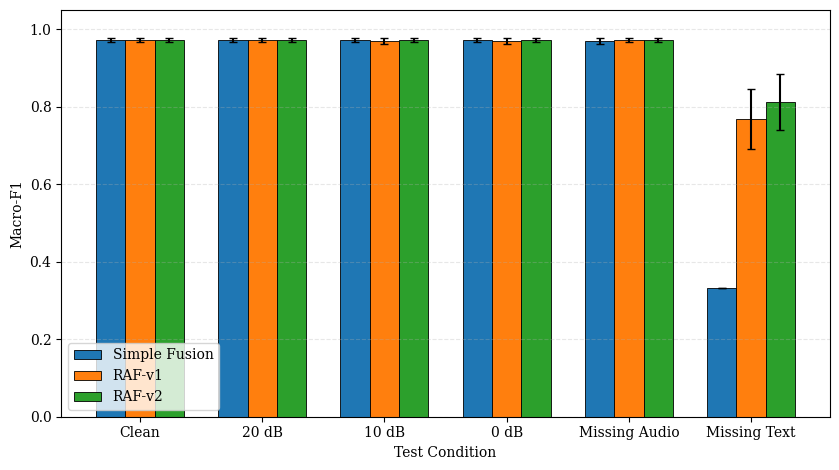

Saved: /kaggle/working/bangla_multimodal_thesis/multiseed/figures/multiseed_robustness_comparison_bar.png


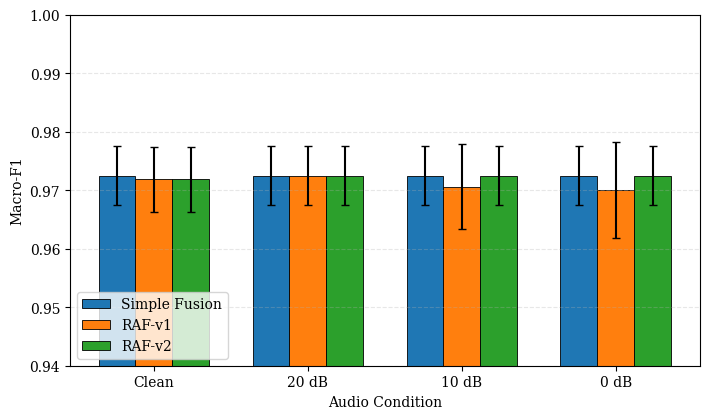

Saved: /kaggle/working/bangla_multimodal_thesis/multiseed/figures/multiseed_acoustic_robustness_zoomed.png


In [594]:
# Step 13I — Robustness Comparison Bar Chart
# ============================================================
# Step 13I.1 — ROBUSTNESS BAR-CHART DATA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path


ROBUSTNESS_FIGURE_DIR = (
    MULTISEED_ROOT /
    "figures"
)

ROBUSTNESS_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


robustness_plot_df = (
    table_iv_multiseed
    .copy()
)


condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]


model_order = [
    "Simple Fusion",
    "RAF-v1",
    "RAF-v2"
]


robustness_plot_df[
    "condition"
] = pd.Categorical(
    robustness_plot_df[
        "condition"
    ],
    categories=condition_order,
    ordered=True
)


robustness_plot_df[
    "model"
] = pd.Categorical(
    robustness_plot_df[
        "model"
    ],
    categories=model_order,
    ordered=True
)


robustness_plot_df = (
    robustness_plot_df
    .sort_values(
        [
            "condition",
            "model"
        ]
    )
    .reset_index(drop=True)
)


display(
    robustness_plot_df[
        [
            "model",
            "condition",
            "f1_mean",
            "f1_sd"
        ]
    ].round(4)
)




#  Step 13I.2 — Generate publication-quality grouped bar chart

# ============================================================
# Step 13I.2 — MULTI-SEED ROBUSTNESS COMPARISON BAR CHART
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Times",
        "DejaVu Serif"
    ],
    "font.size": 10
})


fig, ax = plt.subplots(
    figsize=(8.5, 4.8)
)


x = np.arange(
    len(condition_order)
)

bar_width = 0.24


for model_index, model_name in enumerate(
    model_order
):

    model_data = (
        robustness_plot_df[
            robustness_plot_df[
                "model"
            ] == model_name
        ]
        .set_index("condition")
        .loc[condition_order]
    )

    offset = (
        model_index - 1
    ) * bar_width

    ax.bar(
        x + offset,
        model_data[
            "f1_mean"
        ].to_numpy(),
        width=bar_width,
        yerr=model_data[
            "f1_sd"
        ].to_numpy(),
        capsize=3,
        label=model_name,
        edgecolor="black",
        linewidth=0.6
    )


ax.set_xlabel(
    "Test Condition"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_xticks(x)

ax.set_xticklabels(
    condition_order
)

ax.set_ylim(
    0.0,
    1.05
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.legend(
    loc="lower left",
    frameon=True
)

fig.tight_layout()


ROBUSTNESS_BAR_PATH = (
    ROBUSTNESS_FIGURE_DIR /
    "multiseed_robustness_comparison_bar.png"
)


fig.savefig(
    ROBUSTNESS_BAR_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    ROBUSTNESS_BAR_PATH
)






# Step 13I.3 — Optional zoomed robustness plot
# ============================================================
# Step 13I.3 — ZOOMED ACOUSTIC ROBUSTNESS BAR CHART
# ============================================================

noise_conditions = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]


fig, ax = plt.subplots(
    figsize=(7.2, 4.3)
)


x = np.arange(
    len(noise_conditions)
)


for model_index, model_name in enumerate(
    model_order
):

    model_data = (
        robustness_plot_df[
            robustness_plot_df[
                "model"
            ] == model_name
        ]
        .set_index("condition")
        .loc[noise_conditions]
    )

    offset = (
        model_index - 1
    ) * bar_width

    ax.bar(
        x + offset,
        model_data[
            "f1_mean"
        ].to_numpy(),
        width=bar_width,
        yerr=model_data[
            "f1_sd"
        ].to_numpy(),
        capsize=3,
        label=model_name,
        edgecolor="black",
        linewidth=0.6
    )


ax.set_xlabel(
    "Audio Condition"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_xticks(x)

ax.set_xticklabels(
    noise_conditions
)


# Deliberately zoomed.
ax.set_ylim(
    0.94,
    1.00
)


ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.legend(
    loc="lower left"
)


fig.tight_layout()


ZOOMED_ROBUSTNESS_PATH = (
    ROBUSTNESS_FIGURE_DIR /
    "multiseed_acoustic_robustness_zoomed.png"
)


fig.savefig(
    ZOOMED_ROBUSTNESS_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    ZOOMED_ROBUSTNESS_PATH
)






,model,seed,condition,TN,FP,FN,TP,total_errors
0,Simple Fusion,42,Missing Text,0,200,0,200,200
1,Simple Fusion,7,Missing Text,200,0,200,0,200
2,Simple Fusion,123,Missing Text,0,200,0,200,200
3,Simple Fusion,2026,Missing Text,200,0,200,0,200
4,RAF-v1,42,Missing Text,146,54,21,179,75
5,RAF-v1,7,Missing Text,191,9,119,81,128
6,RAF-v1,123,Missing Text,173,27,46,154,73
7,RAF-v1,2026,Missing Text,133,67,13,187,80
8,RAF-v2,42,Missing Text,160,40,19,181,59
9,RAF-v2,7,Missing Text,181,19,40,160,59


Rows: 12
Missing-text error extraction passed.


,model,fp_mean,fp_sd,fn_mean,fn_sd,total_errors_mean,total_errors_sd
0,Simple Fusion,100.00,115.47,100.00,115.47,200.0,0.00
1,RAF-v1,39.25,26.16,49.75,48.26,89.0,26.17
2,RAF-v2,34.50,10.54,40.00,24.91,74.5,28.40


MISSING-TEXT ERROR BREAKDOWN — FOUR-SEED SUMMARY
Simple Fusion  | FP 100.00 ± 115.47 | FN 100.00 ± 115.47 | Total Errors 200.00 ± 0.00
RAF-v1         | FP 39.25 ± 26.16 | FN 49.75 ± 48.26 | Total Errors 89.00 ± 26.17
RAF-v2         | FP 34.50 ± 10.54 | FN 40.00 ± 24.91 | Total Errors 74.50 ± 28.40


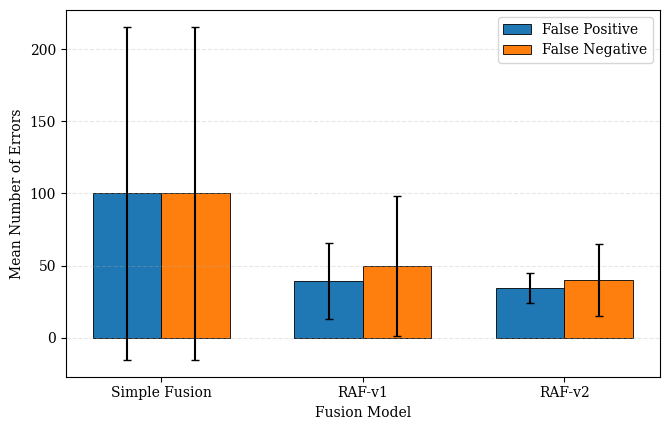

PNG saved: /kaggle/working/bangla_multimodal_thesis/multiseed/figures/missing_text_error_breakdown_multiseed.png
PDF saved: /kaggle/working/bangla_multimodal_thesis/multiseed/figures/missing_text_error_breakdown_multiseed.pdf
ERROR BREAKDOWN RESULTS SAVED
/kaggle/working/bangla_multimodal_thesis/multiseed/results/missing_text_error_breakdown_raw.csv
/kaggle/working/bangla_multimodal_thesis/multiseed/results/missing_text_error_breakdown_summary.csv


In [595]:
# Step 13J — Multi-Seed Error Breakdown
# ============================================================
# Step 13J.1 — MULTI-SEED MISSING-TEXT ERROR BREAKDOWN
# ============================================================

from sklearn.metrics import confusion_matrix

ERROR_CONDITION = "Missing Text"


error_breakdown_rows = []


for model_name, file_prefix in BOOTSTRAP_MODELS.items():

    for seed in RUN_SEEDS:

        safe_condition = (
            ERROR_CONDITION
            .replace(" ", "_")
        )

        prediction_path = (
            MULTISEED_PREDICTION_DIR /
            (
                f"{file_prefix}_seed_{seed}_"
                f"{safe_condition}_predictions.csv"
            )
        )

        prediction_df = pd.read_csv(
            prediction_path
        )

        # ----------------------------------------------------
        # Strict integrity checks
        # ----------------------------------------------------

        assert len(
            prediction_df
        ) == 400

        assert np.array_equal(
            prediction_df[
                "label"
            ].to_numpy(),
            y_mm_test
        )

        # ----------------------------------------------------
        # Confusion matrix:
        #
        # [[TN, FP],
        #  [FN, TP]]
        # ----------------------------------------------------

        cm = confusion_matrix(
            prediction_df["label"],
            prediction_df[
                "predicted_label"
            ],
            labels=[0, 1]
        )

        tn, fp, fn, tp = (
            cm.ravel()
        )

        total_errors = (
            fp + fn
        )

        error_breakdown_rows.append({

            "model":
                model_name,

            "seed":
                seed,

            "condition":
                ERROR_CONDITION,

            "TN":
                int(tn),

            "FP":
                int(fp),

            "FN":
                int(fn),

            "TP":
                int(tp),

            "total_errors":
                int(total_errors)
        })


error_breakdown_df = pd.DataFrame(
    error_breakdown_rows
)


display(
    error_breakdown_df
)




print(
    "Rows:",
    len(error_breakdown_df)
)

assert (
    len(error_breakdown_df)
    ==
    12
)

print(
    "Missing-text error extraction passed."
)






# Step 13J.2 — Calculate mean ± SD errors

# ============================================================
# Step 13J.2 — ERROR BREAKDOWN MEAN ± SD
# ============================================================

error_breakdown_summary = (
    error_breakdown_df
    .groupby(
        "model"
    )
    .agg(

        fp_mean=(
            "FP",
            "mean"
        ),

        fp_sd=(
            "FP",
            lambda x:
                x.std(ddof=1)
        ),

        fn_mean=(
            "FN",
            "mean"
        ),

        fn_sd=(
            "FN",
            lambda x:
                x.std(ddof=1)
        ),

        total_errors_mean=(
            "total_errors",
            "mean"
        ),

        total_errors_sd=(


            
            "total_errors",
            lambda x:
                x.std(ddof=1)
        )
    )
    .reindex(
        model_order
    )
    .reset_index()
)


display(
    error_breakdown_summary.round(2)
)





# Step 13J.3 — Print conference-friendly result

print("=" * 90)
print("MISSING-TEXT ERROR BREAKDOWN — FOUR-SEED SUMMARY")
print("=" * 90)


for _, row in (
    error_breakdown_summary
    .iterrows()
):

    print(
        f"{row['model']:14s} | "
        f"FP "
        f"{row['fp_mean']:.2f}"
        f" ± "
        f"{row['fp_sd']:.2f} | "
        f"FN "
        f"{row['fn_mean']:.2f}"
        f" ± "
        f"{row['fn_sd']:.2f} | "
        f"Total Errors "
        f"{row['total_errors_mean']:.2f}"
        f" ± "
        f"{row['total_errors_sd']:.2f}"
    )






# Step 13J.4 — Publication-quality error breakdown chart
# ============================================================
# Step 13J.4 — MISSING-TEXT ERROR BREAKDOWN CHART
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Times",
        "DejaVu Serif"
    ],
    "font.size": 10
})


fig, ax = plt.subplots(
    figsize=(6.8, 4.4)
)


x = np.arange(
    len(model_order)
)

bar_width = 0.34


ax.bar(
    x - bar_width / 2,
    error_breakdown_summary[
        "fp_mean"
    ],
    width=bar_width,
    yerr=error_breakdown_summary[
        "fp_sd"
    ],
    capsize=3,
    label="False Positive",
    edgecolor="black",
    linewidth=0.6
)


ax.bar(
    x + bar_width / 2,
    error_breakdown_summary[
        "fn_mean"
    ],
    width=bar_width,
    yerr=error_breakdown_summary[
        "fn_sd"
    ],
    capsize=3,
    label="False Negative",
    edgecolor="black",
    linewidth=0.6
)


ax.set_xlabel(
    "Fusion Model"
)

ax.set_ylabel(
    "Mean Number of Errors"
)


ax.set_xticks(x)

ax.set_xticklabels(
    model_order
)


ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)


ax.legend(
    frameon=True
)


fig.tight_layout()


ERROR_BREAKDOWN_PATH = (
    ROBUSTNESS_FIGURE_DIR /
    "missing_text_error_breakdown_multiseed.png"
)


fig.savefig(
    ERROR_BREAKDOWN_PATH,
    dpi=600,
    bbox_inches="tight"
)


# Vector version for IEEE paper
ERROR_BREAKDOWN_PDF_PATH = (
    ROBUSTNESS_FIGURE_DIR /
    "missing_text_error_breakdown_multiseed.pdf"
)


fig.savefig(
    ERROR_BREAKDOWN_PDF_PATH,
    bbox_inches="tight"
)


plt.show()


print(
    "PNG saved:",
    ERROR_BREAKDOWN_PATH
)

print(
    "PDF saved:",
    ERROR_BREAKDOWN_PDF_PATH
)





# Step 13J.5 — Save the numeric error results
# ============================================================
# Step 13J.5 — SAVE ERROR BREAKDOWN RESULTS
# ============================================================

ERROR_RAW_PATH = (
    MULTISEED_RESULTS_DIR /
    "missing_text_error_breakdown_raw.csv"
)

ERROR_SUMMARY_PATH = (
    MULTISEED_RESULTS_DIR /
    "missing_text_error_breakdown_summary.csv"
)


error_breakdown_df.to_csv(
    ERROR_RAW_PATH,
    index=False
)

error_breakdown_summary.to_csv(
    ERROR_SUMMARY_PATH,
    index=False
)


print("=" * 80)
print("ERROR BREAKDOWN RESULTS SAVED")
print("=" * 80)

print(ERROR_RAW_PATH)
print(ERROR_SUMMARY_PATH)


In [597]:
# Step 13K — Final Multi-Seed Integrity & Reproducibility Check
# ============================================================
# Step 13K.1 — FINAL MULTI-SEED INTEGRITY CHECK
# ============================================================

print("=" * 90)
print("FINAL MULTI-SEED EXPERIMENT INTEGRITY CHECK")
print("=" * 90)

expected_seeds = set(RUN_SEEDS)

checks = {}


# ------------------------------------------------------------
# BanglaBERT
# ------------------------------------------------------------

checks["BanglaBERT rows"] = (
    len(banglabert_multiseed_df) == 4
)

checks["BanglaBERT seeds"] = (
    set(
        banglabert_multiseed_df["seed"]
    )
    ==
    expected_seeds
)


# ------------------------------------------------------------
# Audio-only
# ------------------------------------------------------------

checks["Audio rows"] = (
    len(audio_multiseed_df) == 16
)

checks["Audio seeds"] = (
    set(
        audio_multiseed_df["seed"]
    )
    ==
    expected_seeds
)

checks["Audio conditions"] = (
    audio_multiseed_df[
        "condition"
    ].nunique()
    == 4
)


# ------------------------------------------------------------
# Simple Fusion
# ------------------------------------------------------------

checks["Simple Fusion rows"] = (
    len(simple_multiseed_df) == 24
)

checks["Simple Fusion seeds"] = (
    set(
        simple_multiseed_df["seed"]
    )
    ==
    expected_seeds
)

checks["Simple Fusion conditions"] = (
    simple_multiseed_df[
        "condition"
    ].nunique()
    == 6
)


# ------------------------------------------------------------
# RAF-v1
# ------------------------------------------------------------

checks["RAF-v1 rows"] = (
    len(raf1_multiseed_df) == 24
)

checks["RAF-v1 seeds"] = (
    set(
        raf1_multiseed_df["seed"]
    )
    ==
    expected_seeds
)

checks["RAF-v1 conditions"] = (
    raf1_multiseed_df[
        "condition"
    ].nunique()
    == 6
)


# ------------------------------------------------------------
# RAF-v2
# ------------------------------------------------------------

checks["RAF-v2 rows"] = (
    len(raf2_multiseed_df) == 24
)

checks["RAF-v2 seeds"] = (
    set(
        raf2_multiseed_df["seed"]
    )
    ==
    expected_seeds
)

checks["RAF-v2 conditions"] = (
    raf2_multiseed_df[
        "condition"
    ].nunique()
    == 6
)


# ------------------------------------------------------------
# Tables
# ------------------------------------------------------------

checks["Table II rows"] = (
    len(table_ii_multiseed) == 5
)

checks["Table III rows"] = (
    len(table_iii_multiseed) == 4
)

checks["Table IV rows"] = (
    len(table_iv_multiseed) == 18
)

checks["Bootstrap rows"] = (
    len(table_iv_bootstrap) == 18
)

checks["Error analysis rows"] = (
    len(error_breakdown_df) == 12
)


# ------------------------------------------------------------
# Print checks
# ------------------------------------------------------------

for name, passed in checks.items():

    print(
        f"{name:30s}:",
        "PASSED"
        if passed
        else "FAILED"
    )


all_checks_passed = all(
    checks.values()
)


print("\n" + "=" * 90)

if all_checks_passed:

    print(
        "STATUS: ALL STRUCTURAL CHECKS PASSED"
    )

else:

    print(
        "STATUS: ONE OR MORE CHECKS FAILED"
    )

print("=" * 90)




# ============================================================
# Step 13K.2 — NUMERIC VALIDITY CHECK
# ============================================================

print("=" * 90)
print("NUMERIC VALIDITY CHECK")
print("=" * 90)


# ------------------------------------------------------------
# Table IV metric ranges
# ------------------------------------------------------------

assert (
    table_iv_multiseed[
        "f1_mean"
    ]
    .between(0, 1)
    .all()
)

assert (
    table_iv_multiseed[
        "f1_sd"
    ]
    .ge(0)
    .all()
)

assert (
    table_iv_multiseed[
        "auc_mean"
    ]
    .between(0, 1)
    .all()
)


# ------------------------------------------------------------
# Bootstrap bounds
# ------------------------------------------------------------

assert (
    table_iv_bootstrap[
        "ci_95_lower"
    ]
    .between(0, 1)
    .all()
)

assert (
    table_iv_bootstrap[
        "ci_95_upper"
    ]
    .between(0, 1)
    .all()
)

assert (
    (
        table_iv_bootstrap[
            "ci_95_lower"
        ]
        <=
        table_iv_bootstrap[
            "ci_95_upper"
        ]
    )
    .all()
)


# ------------------------------------------------------------
# Missing values
# ------------------------------------------------------------

critical_columns = [
    "f1_mean",
    "f1_sd",
    "ci_95_lower",
    "ci_95_upper"
]

assert (
    table_iv_bootstrap[
        critical_columns
    ]
    .notna()
    .all()
    .all()
)


print("Metric ranges: PASSED")
print("Standard deviations: PASSED")
print("Bootstrap bounds: PASSED")
print("Missing-value check: PASSED")

print(
    "\nSTATUS: ALL NUMERIC CHECKS PASSED"
)







# ============================================================
# Step 13K.3 — PER-SEED RAF-v2 RELIABILITY CHECK
# ============================================================

noise_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]


raf2_seed_behavior_rows = []


print("=" * 90)
print("RAF-v2 PER-SEED RELIABILITY BEHAVIOR")
print("=" * 90)


for seed in RUN_SEEDS:

    seed_df = (
        raf2_multiseed_df[
            raf2_multiseed_df[
                "seed"
            ] == seed
        ]
        .set_index("condition")
        .loc[noise_order]
    )


    audio_quality = (
        seed_df[
            "mean_audio_quality"
        ]
        .to_numpy()
    )

    audio_weight = (
        seed_df[
            "mean_audio_weight"
        ]
        .to_numpy()
    )


    quality_monotonic = bool(
        np.all(
            np.diff(
                audio_quality
            )
            < 0
        )
    )


    weight_monotonic = bool(
        np.all(
            np.diff(
                audio_weight
            )
            < 0
        )
    )


    raf2_seed_behavior_rows.append({

        "seed":
            seed,

        "quality_monotonic":
            quality_monotonic,

        "weight_monotonic":
            weight_monotonic
    })


    print(
        f"\nSeed {seed}"
    )

    print(
        "Audio quality:",
        np.round(
            audio_quality,
            4
        )
    )

    print(
        "Audio weight :",
        np.round(
            audio_weight,
            4
        )
    )

    print(
        "Quality monotonic:",
        quality_monotonic
    )

    print(
        "Weight monotonic :",
        weight_monotonic
    )


raf2_seed_behavior_df = pd.DataFrame(
    raf2_seed_behavior_rows
)


print("\n" + "=" * 90)

print(
    "Seeds with monotonic quality:",
    raf2_seed_behavior_df[
        "quality_monotonic"
    ].sum(),
    "/",
    len(RUN_SEEDS)
)

print(
    "Seeds with monotonic weights:",
    raf2_seed_behavior_df[
        "weight_monotonic"
    ].sum(),
    "/",
    len(RUN_SEEDS)
)





# ============================================================
# Step 13K.4 — CORE FINDING CHECK
# ============================================================

print("=" * 90)
print("CORE SUPERVISOR-FEEDBACK FINDINGS")
print("=" * 90)


# ------------------------------------------------------------
# Audio confidence failure at 0 dB
# ------------------------------------------------------------

audio_clean = (
    audio_multiseed_summary
    .set_index("condition")
    .loc["Clean"]
)

audio_0db = (
    audio_multiseed_summary
    .set_index("condition")
    .loc["0 dB"]
)


print("\n1. AUDIO CONFIDENCE VS RELIABILITY")

print(
    "Clean F1:",
    round(
        audio_clean[
            "f1_mean"
        ],
        4
    )
)

print(
    "0 dB F1:",
    round(
        audio_0db[
            "f1_mean"
        ],
        4
    )
)

print(
    "0 dB confidence:",
    round(
        audio_0db[
            "confidence_mean"
        ],
        4
    )
)


# ------------------------------------------------------------
# Missing-text comparison
# ------------------------------------------------------------

print("\n2. MISSING-TEXT PERFORMANCE")


for model_name in [
    "Simple Fusion",
    "RAF-v1",
    "RAF-v2"
]:

    row = (
        table_iv_bootstrap[
            (
                table_iv_bootstrap[
                    "model"
                ]
                ==
                model_name
            )
            &
            (
                table_iv_bootstrap[
                    "condition"
                ]
                ==
                "Missing Text"
            )
        ]
        .iloc[0]
    )

    print(
        f"{model_name:14s}: "
        f"{row['f1_mean']:.4f} "
        f"± {row['f1_sd']:.4f} "
        f"[95% CI "
        f"{row['ci_95_lower']:.4f}, "
        f"{row['ci_95_upper']:.4f}]"
    )


# ------------------------------------------------------------
# Error counts
# ------------------------------------------------------------

print("\n3. MISSING-TEXT TOTAL ERRORS")


for _, row in (
    error_breakdown_summary
    .iterrows()
):

    print(
        f"{row['model']:14s}: "
        f"{row['total_errors_mean']:.2f} "
        f"± "
        f"{row['total_errors_sd']:.2f}"
    )






# ============================================================
# Step 13K.5 — SAVE REPRODUCIBILITY MANIFEST
# ============================================================

import json


experiment_manifest = {

    "dataset":
        "BanglaMUSE",

    "usable_sentences":
        998,

    "usable_audio_pairs":
        3992,

    "split_seed":
        SPLIT_SEED,

    "noise_seed":
        NOISE_SEED,

    "training_seeds":
        RUN_SEEDS,

    "number_of_training_seeds":
        len(RUN_SEEDS),

    "bootstrap_seed":
        BOOTSTRAP_SEED,

    "bootstrap_iterations":
        N_BOOTSTRAP,

    "bootstrap_unit":
        "sentence cluster",

    "recordings_per_cluster":
        4,

    "test_sentence_clusters":
        100,

    "models": [
        "BanglaBERT",
        "XLS-R + MLP",
        "Simple Fusion",
        "RAF-v1",
        "RAF-v2"
    ],

    "robustness_conditions": [
        "Clean",
        "20 dB",
        "10 dB",
        "0 dB",
        "Missing Audio",
        "Missing Text"
    ],

    "uncertainty_reporting": {
        "training_variability":
            "sample standard deviation across four seeds",

        "test_uncertainty":
            "95% sentence-cluster bootstrap confidence interval"
    }
}


MANIFEST_PATH = (
    MULTISEED_RESULTS_DIR /
    "reproducibility_manifest.json"
)


with open(
    MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_manifest,
        f,
        indent=4,
        ensure_ascii=False
    )


print(
    "Saved:",
    MANIFEST_PATH
)






# ============================================================
# Step 13K.6 — FINAL IMPLEMENTATION STATUS
# ============================================================

print("=" * 90)
print("SUPERVISOR FEEDBACK — IMPLEMENTATION STATUS")
print("=" * 90)

print(
    "[DONE] 4-seed BanglaBERT evaluation"
)

print(
    "[DONE] 4-seed audio-only evaluation"
)

print(
    "[DONE] 4-seed Simple Fusion evaluation"
)

print(
    "[DONE] 4-seed RAF-v1 evaluation"
)

print(
    "[DONE] 4-seed RAF-v2 evaluation"
)

print(
    "[DONE] Mean ± sample SD"
)

print(
    "[DONE] 5,000-iteration "
    "sentence-cluster bootstrap 95% CI"
)

print(
    "[DONE] Multi-seed robustness comparison chart"
)

print(
    "[DONE] Multi-seed missing-text error breakdown"
)

print(
    "[DONE] Reproducibility manifest"
)

print("\n" + "=" * 90)

print(
    "FINAL STATUS: SUPERVISOR-REQUESTED "
    "IMPLEMENTATION UPDATES COMPLETE"
)

print("=" * 90)

FINAL MULTI-SEED EXPERIMENT INTEGRITY CHECK
BanglaBERT rows               : PASSED
BanglaBERT seeds              : PASSED
Audio rows                    : PASSED
Audio seeds                   : PASSED
Audio conditions              : PASSED
Simple Fusion rows            : PASSED
Simple Fusion seeds           : PASSED
Simple Fusion conditions      : PASSED
RAF-v1 rows                   : PASSED
RAF-v1 seeds                  : PASSED
RAF-v1 conditions             : PASSED
RAF-v2 rows                   : PASSED
RAF-v2 seeds                  : PASSED
RAF-v2 conditions             : PASSED
Table II rows                 : PASSED
Table III rows                : PASSED
Table IV rows                 : PASSED
Bootstrap rows                : PASSED
Error analysis rows           : PASSED

STATUS: ALL STRUCTURAL CHECKS PASSED
NUMERIC VALIDITY CHECK
Metric ranges: PASSED
Standard deviations: PASSED
Bootstrap bounds: PASSED
Missing-value check: PASSED

STATUS: ALL NUMERIC CHECKS PASSED
RAF-v2 PER-SEED 

In [1]:
from pathlib import Path

PROJECT_ROOT = Path("/kaggle/working/")

print("PROJECT_ROOT exists:", PROJECT_ROOT.exists())

if PROJECT_ROOT.exists():
    for p in PROJECT_ROOT.rglob("*"):
        if p.is_file():
            print(p)

PROJECT_ROOT exists: True
/kaggle/working/.virtual_documents/__notebook_source__.ipynb


In [2]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

for p in INPUT_ROOT.iterdir():
    print(p)

/kaggle/input/datasets


In [4]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

print("=" * 90)
print("SEARCHING FOR SAVED NOTEBOOK OUTPUT")
print("=" * 90)

interesting_files = []

for p in INPUT_ROOT.rglob("*"):
    if p.is_file():

        path_str = str(p).lower()

        # Ignore the original BanglaMUSE audio dataset
        if "banglamuse" in path_str and p.suffix.lower() in {
            ".mp3", ".wav", ".ogg", ".flac"
        }:
            continue

        # Show likely saved thesis artifacts
        if (
            p.suffix.lower() in {".npy", ".npz", ".csv", ".pt", ".json"}
            or "multiseed" in path_str
            or "embedding" in path_str
            or "result" in path_str
        ):
            interesting_files.append(p)

print("Interesting files found:", len(interesting_files))

for p in interesting_files[:300]:
    print(p)

if len(interesting_files) > 300:
    print(f"\n... {len(interesting_files) - 300} more files not shown")

SEARCHING FOR SAVED NOTEBOOK OUTPUT
Interesting files found: 293
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__results__.html
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__notebook__.ipynb
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__output__.json
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/custom.css
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/paper_figures/raf_v2_quality_and_weights.png
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__results___files/__results___353_8.png
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__results___files/__results___146_0.png
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__results___files/__results___335_7.png
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__results___files/__results___353_10.png
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-mu

**Step 13L.0 — Restore saved artifacts and verify them**

In [5]:
# ============================================================
# STEP 13L.0 — RESTORE SAVED ARTIFACTS FOR LOSS-WEIGHT ABLATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

RUN_SEEDS = [42, 7, 123, 2026]

# ------------------------------------------------------------
# Saved notebook-output root (READ ONLY)
# ------------------------------------------------------------

SAVED_ROOT = Path(
    "/kaggle/input/notebooks/marakibsarker/"
    "dm-lab-thesis-multiseed-final/"
    "bangla_multimodal_thesis"
)

EMBED_DIR = SAVED_ROOT / "embeddings"
MS_EMBED_DIR = SAVED_ROOT / "multiseed" / "embeddings"
PROCESSED_DIR = SAVED_ROOT / "processed_data"

# ------------------------------------------------------------
# New writable output directory for Step 13L
# ------------------------------------------------------------

ABLATION_ROOT = Path(
    "/kaggle/working/bangla_multimodal_thesis/"
    "loss_weight_ablation"
)

ABLATION_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

(ABLATION_ROOT / "models").mkdir(
    exist_ok=True
)

(ABLATION_ROOT / "results").mkdir(
    exist_ok=True
)

(ABLATION_ROOT / "training_history").mkdir(
    exist_ok=True
)


print("=" * 90)
print("LOSS-WEIGHT ABLATION — SAVED ARTIFACT PREFLIGHT")
print("=" * 90)

print("Saved root exists :", SAVED_ROOT.exists())
print("Embedding dir     :", EMBED_DIR.exists())
print("Multi-seed embeds :", MS_EMBED_DIR.exists())
print("Processed data    :", PROCESSED_DIR.exists())
print("Ablation output   :", ABLATION_ROOT)


# ============================================================
# 1. REQUIRED AUDIO EMBEDDINGS
# ============================================================

audio_files = {
    "train_clean":
        EMBED_DIR / "xlsr_train_embeddings.npy",

    "val_clean":
        EMBED_DIR / "xlsr_validation_embeddings.npy",

    "test_clean":
        EMBED_DIR / "xlsr_test_embeddings.npy",

    "train_20db":
        EMBED_DIR / "xlsr_train_noise_20db.npy",

    "val_20db":
        EMBED_DIR / "xlsr_validation_noise_20db.npy",

    "test_20db":
        EMBED_DIR / "xlsr_test_noise_20db.npy",

    "train_10db":
        EMBED_DIR / "xlsr_train_noise_10db.npy",

    "val_10db":
        EMBED_DIR / "xlsr_validation_noise_10db.npy",

    "test_10db":
        EMBED_DIR / "xlsr_test_noise_10db.npy",

    "train_0db":
        EMBED_DIR / "xlsr_train_noise_0db.npy",

    "val_0db":
        EMBED_DIR / "xlsr_validation_noise_0db.npy",

    "test_0db":
        EMBED_DIR / "xlsr_test_noise_0db.npy",
}


missing_audio_files = [
    str(path)
    for path in audio_files.values()
    if not path.exists()
]


print("\n" + "=" * 90)
print("AUDIO EMBEDDINGS")
print("=" * 90)

print(
    "Expected:",
    len(audio_files)
)

print(
    "Missing :",
    len(missing_audio_files)
)

for name, path in audio_files.items():

    if path.exists():

        arr = np.load(
            path,
            mmap_mode="r"
        )

        print(
            f"{name:15s}",
            arr.shape,
            arr.dtype
        )

    else:

        print(
            f"{name:15s}",
            "MISSING"
        )


# ============================================================
# 2. SEED-SPECIFIC BANGLABERT EMBEDDINGS
# ============================================================

print("\n" + "=" * 90)
print("SEED-SPECIFIC BANGLABERT EMBEDDINGS")
print("=" * 90)

missing_text_files = []


for seed in RUN_SEEDS:

    print(
        f"\nSeed {seed}"
    )

    for split in [
        "train",
        "validation",
        "test"
    ]:

        path = (
            MS_EMBED_DIR /
            f"banglabert_seed_{seed}_{split}.npy"
        )

        if not path.exists():

            missing_text_files.append(
                str(path)
            )

            print(
                f"{split:12s}: MISSING"
            )

        else:

            arr = np.load(
                path,
                mmap_mode="r"
            )

            print(
                f"{split:12s}:",
                arr.shape,
                arr.dtype
            )


# ============================================================
# 3. METADATA
# ============================================================

metadata_files = {
    "audio_train":
        EMBED_DIR /
        "xlsr_train_metadata.csv",

    "audio_val":
        EMBED_DIR /
        "xlsr_validation_metadata.csv",

    "audio_test":
        EMBED_DIR /
        "xlsr_test_metadata.csv",

    "text_train":
        EMBED_DIR /
        "banglabert_train_metadata.csv",

    "text_val":
        EMBED_DIR /
        "banglabert_validation_metadata.csv",

    "text_test":
        EMBED_DIR /
        "banglabert_test_metadata.csv",
}


print("\n" + "=" * 90)
print("METADATA FILES")
print("=" * 90)

missing_metadata = []


for name, path in metadata_files.items():

    if not path.exists():

        missing_metadata.append(
            str(path)
        )

        print(
            f"{name:12s}: MISSING"
        )

    else:

        df = pd.read_csv(
            path
        )

        print(
            f"{name:12s}: "
            f"shape={df.shape}"
        )

        print(
            "  columns:",
            list(df.columns)
        )


# ============================================================
# 4. FINAL STATUS
# ============================================================

print("\n" + "=" * 90)

total_missing = (
    len(missing_audio_files)
    +
    len(missing_text_files)
    +
    len(missing_metadata)
)


if total_missing == 0:

    print(
        "STATUS: ALL REQUIRED SAVED ARTIFACTS FOUND"
    )

    print(
        "No encoder retraining is required."
    )

else:

    print(
        f"STATUS: {total_missing} REQUIRED FILE(S) MISSING"
    )


print("=" * 90)

LOSS-WEIGHT ABLATION — SAVED ARTIFACT PREFLIGHT
Saved root exists : True
Embedding dir     : True
Multi-seed embeds : True
Processed data    : True
Ablation output   : /kaggle/working/bangla_multimodal_thesis/loss_weight_ablation

AUDIO EMBEDDINGS
Expected: 12
Missing : 0
train_clean     (3192, 1024) float32
val_clean       (400, 1024) float32
test_clean      (400, 1024) float32
train_20db      (3192, 1024) float32
val_20db        (400, 1024) float32
test_20db       (400, 1024) float32
train_10db      (3192, 1024) float32
val_10db        (400, 1024) float32
test_10db       (400, 1024) float32
train_0db       (3192, 1024) float32
val_0db         (400, 1024) float32
test_0db        (400, 1024) float32

SEED-SPECIFIC BANGLABERT EMBEDDINGS

Seed 42
train       : (798, 768) float32
validation  : (100, 768) float32
test        : (100, 768) float32

Seed 7
train       : (798, 768) float32
validation  : (100, 768) float32
test        : (100, 768) float32

Seed 123
train       : (798, 768) floa

**Step 13L.1 — Align seed-specific text embeddings to the 4-speaker audio rows**

In [6]:
# ============================================================
# STEP 13L.1 — RESTORE AND ALIGN MULTIMODAL ARRAYS
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. LOAD METADATA
# ------------------------------------------------------------

audio_meta = {
    "train": pd.read_csv(
        EMBED_DIR / "xlsr_train_metadata.csv"
    ),

    "validation": pd.read_csv(
        EMBED_DIR / "xlsr_validation_metadata.csv"
    ),

    "test": pd.read_csv(
        EMBED_DIR / "xlsr_test_metadata.csv"
    ),
}


text_meta = {
    "train": pd.read_csv(
        EMBED_DIR / "banglabert_train_metadata.csv"
    ),

    "validation": pd.read_csv(
        EMBED_DIR / "banglabert_validation_metadata.csv"
    ),

    "test": pd.read_csv(
        EMBED_DIR / "banglabert_test_metadata.csv"
    ),
}


# ------------------------------------------------------------
# Normalize sentence_id for safe matching
# ------------------------------------------------------------

for split in [
    "train",
    "validation",
    "test"
]:

    audio_meta[split]["sentence_id"] = (
        audio_meta[split]["sentence_id"]
        .astype(str)
    )

    text_meta[split]["sentence_id"] = (
        text_meta[split]["sentence_id"]
        .astype(str)
    )


# ============================================================
# 2. STRICT METADATA INTEGRITY CHECK
# ============================================================

print("=" * 90)
print("MULTIMODAL METADATA INTEGRITY")
print("=" * 90)


for split in [
    "train",
    "validation",
    "test"
]:

    a_meta = audio_meta[split]
    t_meta = text_meta[split]

    # One text row per sentence
    assert (
        t_meta["sentence_id"].is_unique
    )

    # Same sentence IDs in both modalities
    assert set(
        a_meta["sentence_id"]
    ) == set(
        t_meta["sentence_id"]
    )

    # Exactly 4 audio recordings per sentence
    cluster_sizes = (
        a_meta
        .groupby("sentence_id")
        .size()
    )

    assert (
        cluster_sizes.min() == 4
    )

    assert (
        cluster_sizes.max() == 4
    )


    # --------------------------------------------------------
    # Check text/audio label consistency sentence by sentence
    # --------------------------------------------------------

    text_label_map = (
        t_meta
        .set_index("sentence_id")[
            "label"
        ]
        .to_dict()
    )


    mapped_text_labels = (
        a_meta["sentence_id"]
        .map(text_label_map)
        .to_numpy()
    )


    assert np.array_equal(
        mapped_text_labels.astype(int),
        a_meta[
            "label"
        ].to_numpy().astype(int)
    )


    print(
        f"{split:12s} | "
        f"audio rows={len(a_meta):4d} | "
        f"text rows={len(t_meta):3d} | "
        f"sentences={a_meta['sentence_id'].nunique():3d} | "
        f"speaker rows/sentence=4"
    )


print(
    "\nMetadata integrity passed."
)


# ============================================================
# 3. LOAD ALL AUDIO CONDITIONS
# ============================================================

AUDIO_CONDITION_FILES = {

    "Clean": {
        "train":
            EMBED_DIR /
            "xlsr_train_embeddings.npy",

        "validation":
            EMBED_DIR /
            "xlsr_validation_embeddings.npy",

        "test":
            EMBED_DIR /
            "xlsr_test_embeddings.npy",
    },

    "20 dB": {
        "train":
            EMBED_DIR /
            "xlsr_train_noise_20db.npy",

        "validation":
            EMBED_DIR /
            "xlsr_validation_noise_20db.npy",

        "test":
            EMBED_DIR /
            "xlsr_test_noise_20db.npy",
    },

    "10 dB": {
        "train":
            EMBED_DIR /
            "xlsr_train_noise_10db.npy",

        "validation":
            EMBED_DIR /
            "xlsr_validation_noise_10db.npy",

        "test":
            EMBED_DIR /
            "xlsr_test_noise_10db.npy",
    },

    "0 dB": {
        "train":
            EMBED_DIR /
            "xlsr_train_noise_0db.npy",

        "validation":
            EMBED_DIR /
            "xlsr_validation_noise_0db.npy",

        "test":
            EMBED_DIR /
            "xlsr_test_noise_0db.npy",
    },
}


audio_embeddings = {}


for condition, split_paths in (
    AUDIO_CONDITION_FILES.items()
):

    audio_embeddings[
        condition
    ] = {}

    for split, path in (
        split_paths.items()
    ):

        arr = np.load(
            path
        ).astype(
            np.float32,
            copy=False
        )

        expected_rows = len(
            audio_meta[split]
        )

        assert (
            arr.shape
            ==
            (
                expected_rows,
                1024
            )
        )

        assert np.isfinite(
            arr
        ).all()

        audio_embeddings[
            condition
        ][
            split
        ] = arr


print("\n" + "=" * 90)
print("AUDIO ARRAYS LOADED")
print("=" * 90)


for condition in [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]:

    print(
        f"{condition:7s} | "
        f"train {audio_embeddings[condition]['train'].shape} | "
        f"val {audio_embeddings[condition]['validation'].shape} | "
        f"test {audio_embeddings[condition]['test'].shape}"
    )


# ============================================================
# 4. ALIGN SEED-SPECIFIC TEXT EMBEDDINGS TO AUDIO ROW ORDER
# ============================================================

aligned_text_embeddings = {}


print("\n" + "=" * 90)
print("ALIGNING BANGLABERT EMBEDDINGS TO SPEAKER-PAIR ROWS")
print("=" * 90)


for seed in RUN_SEEDS:

    aligned_text_embeddings[
        seed
    ] = {}

    print(
        f"\nSeed {seed}"
    )

    for split in [
        "train",
        "validation",
        "test"
    ]:

        # ----------------------------------------------------
        # Load one embedding per unique sentence
        # ----------------------------------------------------

        text_arr = np.load(
            MS_EMBED_DIR /
            f"banglabert_seed_{seed}_{split}.npy"
        ).astype(
            np.float32,
            copy=False
        )


        t_meta = text_meta[
            split
        ]

        a_meta = audio_meta[
            split
        ]


        assert (
            text_arr.shape[0]
            ==
            len(t_meta)
        )

        assert (
            text_arr.shape[1]
            ==
            768
        )


        # ----------------------------------------------------
        # Map sentence_id -> row index in text embedding array
        # ----------------------------------------------------

        sentence_to_text_row = {
            sentence_id: idx

            for idx, sentence_id in enumerate(
                t_meta[
                    "sentence_id"
                ].tolist()
            )
        }


        audio_to_text_indices = np.array(
            [
                sentence_to_text_row[
                    sentence_id
                ]

                for sentence_id in (
                    a_meta[
                        "sentence_id"
                    ]
                    .tolist()
                )
            ],
            dtype=np.int64
        )


        aligned = text_arr[
            audio_to_text_indices
        ]


        expected_shape = (
            len(
                a_meta
            ),
            768
        )


        assert (
            aligned.shape
            ==
            expected_shape
        )

        assert np.isfinite(
            aligned
        ).all()


        aligned_text_embeddings[
            seed
        ][
            split
        ] = aligned


        print(
            f"{split:12s}: "
            f"{text_arr.shape} "
            f"-> "
            f"{aligned.shape}"
        )


# ============================================================
# 5. RESTORE LABEL ARRAYS
# ============================================================

y_train = (
    audio_meta["train"][
        "label"
    ]
    .to_numpy()
    .astype(
        np.int64
    )
)

y_val = (
    audio_meta[
        "validation"
    ][
        "label"
    ]
    .to_numpy()
    .astype(
        np.int64
    )
)

y_test = (
    audio_meta[
        "test"
    ][
        "label"
    ]
    .to_numpy()
    .astype(
        np.int64
    )
)


labels_by_split = {
    "train":
        y_train,

    "validation":
        y_val,

    "test":
        y_test
}


# ============================================================
# 6. FINAL ALIGNMENT INTEGRITY CHECK
# ============================================================

print("\n" + "=" * 90)
print("FINAL RESTORED DATA CHECK")
print("=" * 90)


for split in [
    "train",
    "validation",
    "test"
]:

    n_rows = len(
        labels_by_split[
            split
        ]
    )

    print(
        f"\n{split.upper()}"
    )

    print(
        "Rows:",
        n_rows
    )

    print(
        "Label distribution:",
        dict(
            zip(
                *np.unique(
                    labels_by_split[
                        split
                    ],
                    return_counts=True
                )
            )
        )
    )


    for seed in RUN_SEEDS:

        assert (
            aligned_text_embeddings[
                seed
            ][
                split
            ].shape
            ==
            (
                n_rows,
                768
            )
        )


    for condition in [
        "Clean",
        "20 dB",
        "10 dB",
        "0 dB"
    ]:

        assert (
            audio_embeddings[
                condition
            ][
                split
            ].shape
            ==
            (
                n_rows,
                1024
            )
        )


print("\n" + "=" * 90)
print(
    "STATUS: MULTIMODAL RESTORATION AND ALIGNMENT PASSED"
)
print("=" * 90)

MULTIMODAL METADATA INTEGRITY
train        | audio rows=3192 | text rows=798 | sentences=798 | speaker rows/sentence=4
validation   | audio rows= 400 | text rows=100 | sentences=100 | speaker rows/sentence=4
test         | audio rows= 400 | text rows=100 | sentences=100 | speaker rows/sentence=4

Metadata integrity passed.

AUDIO ARRAYS LOADED
Clean   | train (3192, 1024) | val (400, 1024) | test (400, 1024)
20 dB   | train (3192, 1024) | val (400, 1024) | test (400, 1024)
10 dB   | train (3192, 1024) | val (400, 1024) | test (400, 1024)
0 dB    | train (3192, 1024) | val (400, 1024) | test (400, 1024)

ALIGNING BANGLABERT EMBEDDINGS TO SPEAKER-PAIR ROWS

Seed 42
train       : (798, 768) -> (3192, 768)
validation  : (100, 768) -> (400, 768)
test        : (100, 768) -> (400, 768)

Seed 7
train       : (798, 768) -> (3192, 768)
validation  : (100, 768) -> (400, 768)
test        : (100, 768) -> (400, 768)

Seed 123
train       : (798, 768) -> (3192, 768)
validation  : (100, 768) -> (400, 

In [7]:
# ============================================================
# STEP 13L.2 — RECOVER EXACT RAF-v2 CODE FROM SAVED NOTEBOOK
# ============================================================

import json
from pathlib import Path

SAVED_NOTEBOOK = Path(
    "/kaggle/input/notebooks/marakibsarker/"
    "dm-lab-thesis-multiseed-final/"
    "__notebook__.ipynb"
)

assert SAVED_NOTEBOOK.exists(), (
    f"Saved notebook not found:\n{SAVED_NOTEBOOK}"
)

with open(
    SAVED_NOTEBOOK,
    "r",
    encoding="utf-8"
) as f:
    nb = json.load(f)


# ------------------------------------------------------------
# Search terms likely to identify the final RAF-v2 cells
# ------------------------------------------------------------

search_terms = [
    "RAF-v2",
    "RAFv2",
    "ReliabilityAwareFusionV2",
    "ReliabilityAwareFusion",
    "quality_loss",
    "quality_weight",
    "aux_loss",
    "0.50",
    "0.5",
    "robust validation",
    "mean_audio_quality",
    "mean_audio_weight",
]


matches = []


for idx, cell in enumerate(
    nb.get("cells", [])
):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(
        cell.get("source", [])
    )

    source_lower = source.lower()

    matched_terms = [
        term
        for term in search_terms
        if term.lower() in source_lower
    ]

    if matched_terms:

        matches.append(
            (
                idx,
                matched_terms,
                source
            )
        )


print("=" * 100)
print("RAF-v2 SOURCE-CELL SEARCH")
print("=" * 100)

print(
    "Matching code cells:",
    len(matches)
)


for idx, matched_terms, source in matches:

    print("\n")
    print("#" * 100)

    print(
        f"CELL INDEX: {idx}"
    )

    print(
        "MATCHED TERMS:",
        matched_terms
    )

    print("#" * 100)

    # Prevent huge unrelated cells from flooding output
    lines = source.splitlines()

    if len(lines) <= 220:

        print(source)

    else:

        print(
            "\n".join(
                lines[:220]
            )
        )

        print(
            f"\n... [TRUNCATED: "
            f"{len(lines) - 220} more lines]"
        )

RAF-v2 SOURCE-CELL SEARCH
Matching code cells: 24


####################################################################################################
CELL INDEX: 72
MATCHED TERMS: ['0.50', '0.5']
####################################################################################################
val_sentences, test_sentences = train_test_split(
    temp_sentences,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_sentences["label"]
)

print("Train:", len(train_sentences))
print("Validation:", len(val_sentences))
print("Test:", len(test_sentences))


####################################################################################################
CELL INDEX: 329
MATCHED TERMS: ['ReliabilityAwareFusion', '0.5']
####################################################################################################
# Step 9A.1 — Separate-modality PyTorch datasets
class ReliabilityMultimodalDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        tex

In [8]:
# ============================================================
# STEP 13L.2B — EXTRACT EXACT RAF-v2 CORE FUNCTIONS
# ============================================================

target_terms = [
    "class ReliabilityAwareFusionV2",
    "def prepare_raf2_batch",
    "def train_raf2_epoch",
    "def evaluate_raf2_condition"
]

print("=" * 100)
print("EXACT RAF-v2 CORE IMPLEMENTATION")
print("=" * 100)

for idx, cell in enumerate(nb.get("cells", [])):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(
        cell.get("source", [])
    )

    matched = [
        term
        for term in target_terms
        if term in source
    ]

    if matched:

        print("\n")
        print("#" * 100)
        print("CELL INDEX:", idx)
        print("MATCHED:", matched)
        print("#" * 100)
        print(source)

EXACT RAF-v2 CORE IMPLEMENTATION


####################################################################################################
CELL INDEX: 345
MATCHED: ['class ReliabilityAwareFusionV2', 'def prepare_raf2_batch', 'def train_raf2_epoch', 'def evaluate_raf2_condition']
####################################################################################################
EMBEDDING_DIR = PROJECT_ROOT / "embeddings"

# -------------------------
# TRAIN
# -------------------------

train_audio_20_v2 = np.load(
    EMBEDDING_DIR / "xlsr_train_noise_20db.npy"
)

train_audio_10_v2 = np.load(
    EMBEDDING_DIR / "xlsr_train_noise_10db.npy"
)

train_audio_0_v2 = np.load(
    EMBEDDING_DIR / "xlsr_train_noise_0db.npy"
)


# -------------------------
# VALIDATION
# -------------------------

val_audio_20_v2 = np.load(
    EMBEDDING_DIR / "xlsr_validation_noise_20db.npy"
)

val_audio_10_v2 = np.load(
    EMBEDDING_DIR / "xlsr_validation_noise_10db.npy"
)

val_audio_0_v2 = np.load(
    EMBEDDI

In [9]:
# ============================================================
# STEP 13L.3 — RESTORE EXACT RAF-v2 WITH PARAMETERIZED LOSS
# ============================================================

import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ============================================================
# 1. DEVICE + REPRODUCIBILITY
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)


def set_run_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    torch.use_deterministic_algorithms(
        True,
        warn_only=True
    )


def make_torch_generator(seed):

    generator = torch.Generator()
    generator.manual_seed(seed)

    return generator


def clear_gpu_memory():

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 2. FIXED RAF-v2 CONFIGURATION
# ============================================================

RAF2_ABL_BATCH_SIZE = 64

RAF2_ABL_LR = 5e-4
RAF2_ABL_WEIGHT_DECAY = 1e-4

RAF2_ABL_MAX_EPOCHS = 30
RAF2_ABL_PATIENCE = 5

# Fixed auxiliary loss weight
RAF2_ABL_AUX_WEIGHT = 0.20

# Values we will ablate later
RAF2_QUALITY_WEIGHTS = [
    0.00,
    0.25,
    0.50,
    1.00
]


# ============================================================
# 3. ORIGINAL CONDITION PROBABILITIES
# ============================================================

RAF2_CONDITION_PROBS = torch.tensor(
    [
        0.35,   # Clean
        0.15,   # 20 dB
        0.15,   # 10 dB
        0.10,   # 0 dB
        0.15,   # Missing Audio
        0.10    # Missing Text
    ],
    dtype=torch.float32,
    device=device
)


assert np.isclose(
    RAF2_CONDITION_PROBS
    .sum()
    .item(),
    1.0
)


# ============================================================
# 4. FIXED NOISY TRAINING ARRAYS ON GPU
# ============================================================

train_audio_20_gpu = torch.tensor(
    audio_embeddings[
        "20 dB"
    ][
        "train"
    ],
    dtype=torch.float32,
    device=device
)

train_audio_10_gpu = torch.tensor(
    audio_embeddings[
        "10 dB"
    ][
        "train"
    ],
    dtype=torch.float32,
    device=device
)

train_audio_0_gpu = torch.tensor(
    audio_embeddings[
        "0 dB"
    ][
        "train"
    ],
    dtype=torch.float32,
    device=device
)


print("\nNoisy training tensors:")

print(
    "20 dB:",
    train_audio_20_gpu.shape
)

print(
    "10 dB:",
    train_audio_10_gpu.shape
)

print(
    "0 dB :",
    train_audio_0_gpu.shape
)


# ============================================================
# 5. EXACT ORIGINAL RAF-v2 ARCHITECTURE
# ============================================================

class ReliabilityAwareFusionV2(nn.Module):

    def __init__(
        self,
        text_dim=768,
        audio_dim=1024,
        shared_dim=256,
        num_classes=2,
        dropout=0.20
    ):

        super().__init__()


        # ----------------------------------------------------
        # MODALITY PROJECTIONS
        # ----------------------------------------------------

        self.text_projection = nn.Sequential(
            nn.LayerNorm(text_dim),
            nn.Linear(
                text_dim,
                shared_dim
            ),
            nn.ReLU(),
            nn.Dropout(dropout)
        )


        self.audio_projection = nn.Sequential(
            nn.LayerNorm(audio_dim),
            nn.Linear(
                audio_dim,
                shared_dim
            ),
            nn.ReLU(),
            nn.Dropout(dropout)
        )


        # ----------------------------------------------------
        # AUXILIARY CLASSIFIERS
        # ----------------------------------------------------

        self.text_classifier = nn.Linear(
            shared_dim,
            num_classes
        )

        self.audio_classifier = nn.Linear(
            shared_dim,
            num_classes
        )


        # ----------------------------------------------------
        # QUALITY ESTIMATORS
        # ----------------------------------------------------

        self.text_quality_head = nn.Sequential(
            nn.Linear(
                shared_dim,
                64
            ),
            nn.ReLU(),
            nn.Linear(
                64,
                1
            ),
            nn.Sigmoid()
        )


        self.audio_quality_head = nn.Sequential(
            nn.Linear(
                shared_dim,
                64
            ),
            nn.ReLU(),
            nn.Linear(
                64,
                1
            ),
            nn.Sigmoid()
        )


        # ----------------------------------------------------
        # LEARNABLE MODALITY PRIORS
        # ----------------------------------------------------

        self.text_prior_logit = nn.Parameter(
            torch.tensor(0.0)
        )

        self.audio_prior_logit = nn.Parameter(
            torch.tensor(0.0)
        )


        # ----------------------------------------------------
        # FINAL FUSION CLASSIFIER
        # ----------------------------------------------------

        self.fusion_classifier = nn.Sequential(
            nn.LayerNorm(
                shared_dim
            ),
            nn.Linear(
                shared_dim,
                128
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(
        self,
        text_embedding,
        audio_embedding,
        text_available=None,
        audio_available=None
    ):

        batch_size = (
            text_embedding.shape[0]
        )


        if text_available is None:

            text_available = torch.ones(
                batch_size,
                device=text_embedding.device
            )


        if audio_available is None:

            audio_available = torch.ones(
                batch_size,
                device=audio_embedding.device
            )


        # ----------------------------------------------------
        # PROJECT
        # ----------------------------------------------------

        text_hidden_raw = (
            self.text_projection(
                text_embedding
            )
        )

        audio_hidden_raw = (
            self.audio_projection(
                audio_embedding
            )
        )


        text_hidden = (
            text_hidden_raw
            *
            text_available.unsqueeze(1)
        )


        audio_hidden = (
            audio_hidden_raw
            *
            audio_available.unsqueeze(1)
        )


        # ----------------------------------------------------
        # MODALITY CLASSIFIERS
        # ----------------------------------------------------

        text_logits = (
            self.text_classifier(
                text_hidden
            )
        )

        audio_logits = (
            self.audio_classifier(
                audio_hidden
            )
        )


        # ----------------------------------------------------
        # QUALITY HEADS
        # ----------------------------------------------------

        text_quality = (
            self.text_quality_head(
                text_hidden_raw
            )
            .squeeze(1)
            *
            text_available
        )


        audio_quality = (
            self.audio_quality_head(
                audio_hidden_raw
            )
            .squeeze(1)
            *
            audio_available
        )


        # ----------------------------------------------------
        # RELIABILITY LOGITS
        # ----------------------------------------------------

        eps = 1e-5


        text_reliability_logit = (
            self.text_prior_logit
            +
            torch.log(
                text_quality.clamp(
                    min=eps
                )
            )
        )


        audio_reliability_logit = (
            self.audio_prior_logit
            +
            torch.log(
                audio_quality.clamp(
                    min=eps
                )
            )
        )


        text_reliability_logit = (
            torch.where(
                text_available > 0,
                text_reliability_logit,
                torch.full_like(
                    text_reliability_logit,
                    -1e4
                )
            )
        )


        audio_reliability_logit = (
            torch.where(
                audio_available > 0,
                audio_reliability_logit,
                torch.full_like(
                    audio_reliability_logit,
                    -1e4
                )
            )
        )


        reliability_logits = torch.stack(
            [
                text_reliability_logit,
                audio_reliability_logit
            ],
            dim=1
        )


        weights = F.softmax(
            reliability_logits,
            dim=1
        )


        text_weight = (
            weights[:, 0]
        )

        audio_weight = (
            weights[:, 1]
        )


        # ----------------------------------------------------
        # WEIGHTED FUSION
        # ----------------------------------------------------

        fused = (
            text_weight.unsqueeze(1)
            *
            text_hidden
            +
            audio_weight.unsqueeze(1)
            *
            audio_hidden
        )


        fused_logits = (
            self.fusion_classifier(
                fused
            )
        )


        return {

            "fused_logits":
                fused_logits,

            "text_logits":
                text_logits,

            "audio_logits":
                audio_logits,

            "text_quality":
                text_quality,

            "audio_quality":
                audio_quality,

            "text_weight":
                text_weight,

            "audio_weight":
                audio_weight
        }


# ============================================================
# 6. BASIC METRIC HELPER
# ============================================================

def calculate_raf2_metrics(
    labels,
    predictions
):

    return {

        "accuracy":
            accuracy_score(
                labels,
                predictions
            ),

        "precision_macro":
            precision_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

        "recall_macro":
            recall_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

        "f1_macro":
            f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            )
    }


# ============================================================
# 7. EXACT ORIGINAL TRAINING CORRUPTION SAMPLER
# ============================================================

def prepare_raf2_batch(
    indices,
    text_features,
    clean_audio
):

    batch_size = len(
        indices
    )


    indices = indices.to(
        device
    )

    text_features = text_features.to(
        device
    )

    audio_features = (
        clean_audio
        .to(device)
        .clone()
    )


    text_available = torch.ones(
        batch_size,
        device=device
    )

    audio_available = torch.ones(
        batch_size,
        device=device
    )


    text_quality_target = torch.ones(
        batch_size,
        device=device
    )

    audio_quality_target = torch.ones(
        batch_size,
        device=device
    )


    condition_codes = torch.multinomial(
        RAF2_CONDITION_PROBS,
        num_samples=batch_size,
        replacement=True
    )


    # 20 dB
    mask = (
        condition_codes == 1
    )

    if mask.any():

        audio_features[
            mask
        ] = train_audio_20_gpu[
            indices[mask]
        ]

        audio_quality_target[
            mask
        ] = 0.75


    # 10 dB
    mask = (
        condition_codes == 2
    )

    if mask.any():

        audio_features[
            mask
        ] = train_audio_10_gpu[
            indices[mask]
        ]

        audio_quality_target[
            mask
        ] = 0.50


    # 0 dB
    mask = (
        condition_codes == 3
    )

    if mask.any():

        audio_features[
            mask
        ] = train_audio_0_gpu[
            indices[mask]
        ]

        audio_quality_target[
            mask
        ] = 0.25


    # Missing Audio
    mask = (
        condition_codes == 4
    )

    if mask.any():

        audio_available[
            mask
        ] = 0.0

        audio_quality_target[
            mask
        ] = 0.0


    # Missing Text
    mask = (
        condition_codes == 5
    )

    if mask.any():

        text_available[
            mask
        ] = 0.0

        text_quality_target[
            mask
        ] = 0.0


    return (
        text_features,
        audio_features,
        text_available,
        audio_available,
        text_quality_target,
        audio_quality_target,
        condition_codes
    )


# ============================================================
# 8. PARAMETERIZED VERSION OF ORIGINAL LOSS
#
# ONLY CHANGE FROM ORIGINAL:
# quality_weight becomes an argument.
# ============================================================

raf2_ce_none = nn.CrossEntropyLoss(
    reduction="none"
)


def calculate_raf2_loss_ablation(
    outputs,
    labels,
    text_available,
    audio_available,
    text_quality_target,
    audio_quality_target,
    aux_weight=0.20,
    quality_weight=0.50
):

    # --------------------------------------------------------
    # MAIN FUSION LOSS
    # --------------------------------------------------------

    fusion_loss = F.cross_entropy(
        outputs[
            "fused_logits"
        ],
        labels
    )


    # --------------------------------------------------------
    # TEXT AUXILIARY LOSS
    # --------------------------------------------------------

    text_losses = raf2_ce_none(
        outputs[
            "text_logits"
        ],
        labels
    )


    text_aux_loss = (
        (
            text_losses
            *
            text_available
        ).sum()
        /
        text_available
        .sum()
        .clamp(min=1)
    )


    # --------------------------------------------------------
    # AUDIO AUXILIARY LOSS
    # --------------------------------------------------------

    audio_losses = raf2_ce_none(
        outputs[
            "audio_logits"
        ],
        labels
    )


    audio_aux_loss = (
        (
            audio_losses
            *
            audio_available
        ).sum()
        /
        audio_available
        .sum()
        .clamp(min=1)
    )


    # --------------------------------------------------------
    # QUALITY SUPERVISION
    # --------------------------------------------------------

    text_quality_loss = F.mse_loss(
        outputs[
            "text_quality"
        ],
        text_quality_target
    )


    audio_quality_loss = F.mse_loss(
        outputs[
            "audio_quality"
        ],
        audio_quality_target
    )


    quality_loss = (
        text_quality_loss
        +
        audio_quality_loss
    )


    # --------------------------------------------------------
    # TOTAL LOSS
    # --------------------------------------------------------

    total_loss = (
        fusion_loss
        +
        aux_weight
        *
        text_aux_loss
        +
        aux_weight
        *
        audio_aux_loss
        +
        quality_weight
        *
        quality_loss
    )


    return {
        "total_loss":
            total_loss,

        "fusion_loss":
            fusion_loss,

        "text_aux_loss":
            text_aux_loss,

        "audio_aux_loss":
            audio_aux_loss,

        "text_quality_loss":
            text_quality_loss,

        "audio_quality_loss":
            audio_quality_loss,

        "quality_loss":
            quality_loss
    }


# ============================================================
# 9. TRAIN DATALOADER CREATOR
# ============================================================

def create_raf2_ablation_train_loader(
    seed
):

    text_train_seed = (
        aligned_text_embeddings[
            seed
        ][
            "train"
        ]
    )


    dataset = TensorDataset(

        torch.arange(
            len(y_train),
            dtype=torch.long
        ),

        torch.tensor(
            text_train_seed,
            dtype=torch.float32
        ),

        torch.tensor(
            audio_embeddings[
                "Clean"
            ][
                "train"
            ],
            dtype=torch.float32
        ),

        torch.tensor(
            y_train,
            dtype=torch.long
        )
    )


    loader = DataLoader(
        dataset,
        batch_size=RAF2_ABL_BATCH_SIZE,
        shuffle=True,
        generator=make_torch_generator(
            seed
        )
    )


    return loader


# ============================================================
# 10. TRAIN ONE EPOCH
# ============================================================

def train_raf2_ablation_epoch(
    model,
    dataloader,
    optimizer,
    quality_weight
):

    model.train()


    total_loss = 0.0

    all_labels = []
    all_predictions = []


    for (
        indices,
        text_features,
        clean_audio,
        labels
    ) in dataloader:

        labels = labels.to(
            device
        )


        (
            text_features,
            audio_features,
            text_available,
            audio_available,
            text_quality_target,
            audio_quality_target,
            _
        ) = prepare_raf2_batch(
            indices,
            text_features,
            clean_audio
        )


        optimizer.zero_grad()


        outputs = model(
            text_features,
            audio_features,
            text_available,
            audio_available
        )


        loss_parts = (
            calculate_raf2_loss_ablation(
                outputs=outputs,
                labels=labels,
                text_available=
                    text_available,
                audio_available=
                    audio_available,
                text_quality_target=
                    text_quality_target,
                audio_quality_target=
                    audio_quality_target,
                aux_weight=
                    RAF2_ABL_AUX_WEIGHT,
                quality_weight=
                    quality_weight
            )
        )


        loss = loss_parts[
            "total_loss"
        ]


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )


        optimizer.step()


        total_loss += (
            loss.item()
        )


        predictions = torch.argmax(
            outputs[
                "fused_logits"
            ],
            dim=1
        )


        all_labels.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )


        all_predictions.extend(
            predictions
            .detach()
            .cpu()
            .numpy()
        )


    metrics = calculate_raf2_metrics(
        all_labels,
        all_predictions
    )


    return (
        total_loss
        /
        len(dataloader),
        metrics
    )


# ============================================================
# 11. EVALUATION — SAME AS ORIGINAL
# ============================================================

def evaluate_raf2_ablation_condition(
    model,
    text_embeddings,
    audio_embeddings_input,
    labels,
    text_available_value=1.0,
    audio_available_value=1.0
):

    model.eval()


    dataset = TensorDataset(

        torch.tensor(
            text_embeddings,
            dtype=torch.float32
        ),

        torch.tensor(
            audio_embeddings_input,
            dtype=torch.float32
        ),

        torch.tensor(
            labels,
            dtype=torch.long
        )
    )


    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False
    )


    predictions_all = []
    labels_all = []
    probabilities_all = []

    text_quality_all = []
    audio_quality_all = []

    text_weight_all = []
    audio_weight_all = []

    losses = []


    with torch.inference_mode():

        for (
            text_features,
            audio_features,
            batch_labels
        ) in loader:

            text_features = (
                text_features.to(
                    device
                )
            )

            audio_features = (
                audio_features.to(
                    device
                )
            )

            batch_labels = (
                batch_labels.to(
                    device
                )
            )


            batch_size = len(
                batch_labels
            )


            text_available = (
                torch.full(
                    (
                        batch_size,
                    ),
                    text_available_value,
                    device=device
                )
            )


            audio_available = (
                torch.full(
                    (
                        batch_size,
                    ),
                    audio_available_value,
                    device=device
                )
            )


            outputs = model(
                text_features,
                audio_features,
                text_available,
                audio_available
            )


            loss = F.cross_entropy(
                outputs[
                    "fused_logits"
                ],
                batch_labels
            )


            probabilities = F.softmax(
                outputs[
                    "fused_logits"
                ],
                dim=1
            )


            predictions = torch.argmax(
                probabilities,
                dim=1
            )


            losses.append(
                loss.item()
            )


            labels_all.extend(
                batch_labels
                .cpu()
                .numpy()
            )


            predictions_all.extend(
                predictions
                .cpu()
                .numpy()
            )


            probabilities_all.extend(
                probabilities
                .cpu()
                .numpy()
            )


            text_quality_all.extend(
                outputs[
                    "text_quality"
                ]
                .cpu()
                .numpy()
            )


            audio_quality_all.extend(
                outputs[
                    "audio_quality"
                ]
                .cpu()
                .numpy()
            )


            text_weight_all.extend(
                outputs[
                    "text_weight"
                ]
                .cpu()
                .numpy()
            )


            audio_weight_all.extend(
                outputs[
                    "audio_weight"
                ]
                .cpu()
                .numpy()
            )


    metrics = calculate_raf2_metrics(
        labels_all,
        predictions_all
    )


    return {

        "loss":
            float(
                np.mean(
                    losses
                )
            ),

        "accuracy":
            metrics[
                "accuracy"
            ],

        "f1_macro":
            metrics[
                "f1_macro"
            ],

        "probabilities":
            np.asarray(
                probabilities_all
            ),

        "predictions":
            np.asarray(
                predictions_all
            ),

        "labels":
            np.asarray(
                labels_all
            ),

        "mean_text_quality":
            float(
                np.mean(
                    text_quality_all
                )
            ),

        "mean_audio_quality":
            float(
                np.mean(
                    audio_quality_all
                )
            ),

        "mean_text_weight":
            float(
                np.mean(
                    text_weight_all
                )
            ),

        "mean_audio_weight":
            float(
                np.mean(
                    audio_weight_all
                )
            )
    }


# ============================================================
# 12. VALIDATION / TEST CONDITION HELPERS
# ============================================================

def get_raf2_ablation_conditions(
    split
):

    assert split in {
        "validation",
        "test"
    }


    return {

        "Clean": {
            "audio":
                audio_embeddings[
                    "Clean"
                ][
                    split
                ],

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "20 dB": {
            "audio":
                audio_embeddings[
                    "20 dB"
                ][
                    split
                ],

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "10 dB": {
            "audio":
                audio_embeddings[
                    "10 dB"
                ][
                    split
                ],

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "0 dB": {
            "audio":
                audio_embeddings[
                    "0 dB"
                ][
                    split
                ],

            "text_available":
                1.0,

            "audio_available":
                1.0
        },

        "Missing Audio": {
            "audio":
                audio_embeddings[
                    "Clean"
                ][
                    split
                ],

            "text_available":
                1.0,

            "audio_available":
                0.0
        },

        "Missing Text": {
            "audio":
                audio_embeddings[
                    "Clean"
                ][
                    split
                ],

            "text_available":
                0.0,

            "audio_available":
                1.0
        }
    }


# ============================================================
# 13. DRY-RUN INTEGRITY TEST
# ============================================================

print("\n" + "=" * 90)
print("RAF-v2 LOSS-WEIGHT ABLATION DRY RUN")
print("=" * 90)


DRY_SEED = 42

set_run_seed(
    DRY_SEED
)


dry_loader = (
    create_raf2_ablation_train_loader(
        DRY_SEED
    )
)


dry_model = ReliabilityAwareFusionV2(
    text_dim=768,
    audio_dim=1024,
    shared_dim=256,
    num_classes=2,
    dropout=0.20
).to(device)


parameter_count = sum(
    p.numel()
    for p in dry_model.parameters()
    if p.requires_grad
)


print(
    "Trainable parameters:",
    f"{parameter_count:,}"
)


assert (
    parameter_count
    ==
    530570
)


(
    dry_indices,
    dry_text,
    dry_audio,
    dry_labels
) = next(
    iter(
        dry_loader
    )
)


dry_labels = dry_labels.to(
    device
)


(
    dry_text,
    dry_audio,
    dry_text_available,
    dry_audio_available,
    dry_text_quality_target,
    dry_audio_quality_target,
    dry_condition_codes
) = prepare_raf2_batch(
    dry_indices,
    dry_text,
    dry_audio
)


dry_outputs = dry_model(
    dry_text,
    dry_audio,
    dry_text_available,
    dry_audio_available
)


print(
    "Batch fused logits:",
    dry_outputs[
        "fused_logits"
    ].shape
)


print(
    "Condition codes:",
    torch.bincount(
        dry_condition_codes,
        minlength=6
    )
    .detach()
    .cpu()
    .tolist()
)


# ------------------------------------------------------------
# Compare total loss under each lambda_q
# using SAME model + SAME batch
# ------------------------------------------------------------

print("\nLoss decomposition:")


for lambda_q in (
    RAF2_QUALITY_WEIGHTS
):

    loss_parts = (
        calculate_raf2_loss_ablation(
            outputs=
                dry_outputs,

            labels=
                dry_labels,

            text_available=
                dry_text_available,

            audio_available=
                dry_audio_available,

            text_quality_target=
                dry_text_quality_target,

            audio_quality_target=
                dry_audio_quality_target,

            aux_weight=
                RAF2_ABL_AUX_WEIGHT,

            quality_weight=
                lambda_q
        )
    )


    print(
        f"lambda_q={lambda_q:>4.2f} | "
        f"Total={loss_parts['total_loss'].item():.6f} | "
        f"Fusion={loss_parts['fusion_loss'].item():.6f} | "
        f"TextAux={loss_parts['text_aux_loss'].item():.6f} | "
        f"AudioAux={loss_parts['audio_aux_loss'].item():.6f} | "
        f"Quality={loss_parts['quality_loss'].item():.6f}"
    )


print("\n" + "=" * 90)
print("STATUS: RAF-v2 ABLATION CORE RESTORED")
print("=" * 90)


del dry_model

clear_gpu_memory()

Device: cuda

Noisy training tensors:
20 dB: torch.Size([3192, 1024])
10 dB: torch.Size([3192, 1024])
0 dB : torch.Size([3192, 1024])

RAF-v2 LOSS-WEIGHT ABLATION DRY RUN
Trainable parameters: 530,570
Batch fused logits: torch.Size([64, 2])
Condition codes: [30, 10, 6, 4, 9, 5]

Loss decomposition:
lambda_q=0.00 | Total=0.874867 | Fusion=0.615030 | TextAux=0.607755 | AudioAux=0.691431 | Quality=0.387817
lambda_q=0.25 | Total=0.971821 | Fusion=0.615030 | TextAux=0.607755 | AudioAux=0.691431 | Quality=0.387817
lambda_q=0.50 | Total=1.068775 | Fusion=0.615030 | TextAux=0.607755 | AudioAux=0.691431 | Quality=0.387817
lambda_q=1.00 | Total=1.262684 | Fusion=0.615030 | TextAux=0.607755 | AudioAux=0.691431 | Quality=0.387817

STATUS: RAF-v2 ABLATION CORE RESTORED


In [10]:
# ============================================================
# STEP 13L.4A — SINGLE-RUN REPRODUCTION CHECK
# Original RAF-v2: seed=42, lambda_q=0.50
# ============================================================

import time
from sklearn.metrics import roc_auc_score


# ============================================================
# 1. OUTPUT DIRECTORIES
# ============================================================

ABL_MODEL_DIR = (
    ABLATION_ROOT /
    "models"
)

ABL_RESULT_DIR = (
    ABLATION_ROOT /
    "results"
)

ABL_HISTORY_DIR = (
    ABLATION_ROOT /
    "training_history"
)

for directory in [
    ABL_MODEL_DIR,
    ABL_RESULT_DIR,
    ABL_HISTORY_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 2. HELPER — COPY MODEL STATE SAFELY TO CPU
# ============================================================

def copy_model_state_to_cpu(model):

    return {
        key:
            value.detach().cpu().clone()

        for key, value
        in model.state_dict().items()
    }


# ============================================================
# 3. SENTENCE-LEVEL METRICS
# ============================================================

def calculate_sentence_level_ablation(
    metadata,
    probabilities
):

    df = metadata[
        [
            "sentence_id",
            "label"
        ]
    ].copy().reset_index(drop=True)

    df["prob_negative"] = (
        probabilities[:, 0]
    )

    df["prob_positive"] = (
        probabilities[:, 1]
    )


    sentence_df = (
        df
        .groupby(
            [
                "sentence_id",
                "label"
            ],
            as_index=False
        )
        .agg({
            "prob_negative": "mean",
            "prob_positive": "mean"
        })
    )


    sentence_df[
        "predicted_label"
    ] = (
        sentence_df[
            [
                "prob_negative",
                "prob_positive"
            ]
        ]
        .to_numpy()
        .argmax(axis=1)
    )


    sentence_accuracy = (
        accuracy_score(
            sentence_df["label"],
            sentence_df[
                "predicted_label"
            ]
        )
    )


    sentence_f1 = (
        f1_score(
            sentence_df["label"],
            sentence_df[
                "predicted_label"
            ],
            average="macro",
            zero_division=0
        )
    )


    sentence_auc = (
        roc_auc_score(
            sentence_df["label"],
            sentence_df[
                "prob_positive"
            ]
        )
    )


    return (
        sentence_accuracy,
        sentence_f1,
        sentence_auc
    )


# ============================================================
# 4. ONE COMPLETE RAF-v2 ABLATION RUN
# ============================================================

def train_raf2_loss_ablation_run(
    seed,
    quality_weight,
    verbose=True
):

    # --------------------------------------------------------
    # Experiment label
    # --------------------------------------------------------

    q_tag = (
        f"q{int(round(quality_weight * 100)):03d}"
    )


    if verbose:

        print("\n" + "=" * 100)

        print(
            f"RAF-v2 LOSS ABLATION | "
            f"seed={seed} | "
            f"lambda_q={quality_weight:.2f}"
        )

        print("=" * 100)


    # ========================================================
    # REPRODUCIBILITY
    # ========================================================

    set_run_seed(
        seed
    )

    clear_gpu_memory()


    # ========================================================
    # SEED-SPECIFIC TEXT FEATURES
    # ========================================================

    text_train_seed = (
        aligned_text_embeddings[
            seed
        ][
            "train"
        ]
    )

    text_val_seed = (
        aligned_text_embeddings[
            seed
        ][
            "validation"
        ]
    )

    text_test_seed = (
        aligned_text_embeddings[
            seed
        ][
            "test"
        ]
    )


    # ========================================================
    # TRAIN LOADER
    # ========================================================

    train_loader = (
        create_raf2_ablation_train_loader(
            seed
        )
    )


    # ========================================================
    # FRESH MODEL
    # ========================================================

    # Re-seed immediately before initialization,
    # matching the original multi-seed protocol.
    set_run_seed(
        seed
    )


    model = ReliabilityAwareFusionV2(
        text_dim=768,
        audio_dim=1024,
        shared_dim=256,
        num_classes=2,
        dropout=0.20
    ).to(device)


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=RAF2_ABL_LR,
        weight_decay=
            RAF2_ABL_WEIGHT_DECAY
    )


    # ========================================================
    # CHECKPOINT
    # ========================================================

    checkpoint_path = (
        ABL_MODEL_DIR /
        (
            f"raf_v2_loss_ablation_"
            f"{q_tag}_seed_{seed}.pt"
        )
    )


    # ========================================================
    # TRAINING STATE
    # ========================================================

    best_robust_f1 = -1.0
    best_robust_loss = np.inf
    best_epoch = 0
    best_state = None

    patience_count = 0

    history_rows = []

    validation_conditions = (
        get_raf2_ablation_conditions(
            "validation"
        )
    )


    start_time = time.time()


    # ========================================================
    # TRAIN
    # ========================================================

    for epoch in range(
        1,
        RAF2_ABL_MAX_EPOCHS + 1
    ):

        (
            train_loss,
            train_metrics
        ) = train_raf2_ablation_epoch(
            model=model,
            dataloader=train_loader,
            optimizer=optimizer,
            quality_weight=
                quality_weight
        )


        # ----------------------------------------------------
        # Evaluate six validation conditions
        # ----------------------------------------------------

        validation_results = {}


        for (
            condition_name,
            config
        ) in validation_conditions.items():

            validation_results[
                condition_name
            ] = (
                evaluate_raf2_ablation_condition(
                    model=model,

                    text_embeddings=
                        text_val_seed,

                    audio_embeddings_input=
                        config["audio"],

                    labels=
                        y_val,

                    text_available_value=
                        config[
                            "text_available"
                        ],

                    audio_available_value=
                        config[
                            "audio_available"
                        ]
                )
            )


        robust_mean_f1 = float(
            np.mean([
                result["f1_macro"]

                for result
                in validation_results.values()
            ])
        )


        robust_mean_loss = float(
            np.mean([
                result["loss"]

                for result
                in validation_results.values()
            ])
        )


        # ----------------------------------------------------
        # Exact original checkpoint rule
        # ----------------------------------------------------

        improved = (
            robust_mean_f1
            >
            best_robust_f1 + 1e-8
        )


        tied = (
            abs(
                robust_mean_f1
                -
                best_robust_f1
            )
            <=
            1e-8
        )


        lower_loss = (
            tied
            and
            robust_mean_loss
            <
            best_robust_loss
        )


        if (
            improved
            or
            lower_loss
        ):

            best_robust_f1 = (
                robust_mean_f1
            )

            best_robust_loss = (
                robust_mean_loss
            )

            best_epoch = epoch

            patience_count = 0

            best_state = (
                copy_model_state_to_cpu(
                    model
                )
            )

            torch.save(
                best_state,
                checkpoint_path
            )

            status = "BEST"


        else:

            patience_count += 1

            status = (
                f"No improvement "
                f"({patience_count}/"
                f"{RAF2_ABL_PATIENCE})"
            )


        history_rows.append({

            "seed":
                seed,

            "quality_weight":
                quality_weight,

            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "train_f1":
                train_metrics[
                    "f1_macro"
                ],

            "robust_val_mean_f1":
                robust_mean_f1,

            "robust_val_mean_loss":
                robust_mean_loss,

            "clean_f1":
                validation_results[
                    "Clean"
                ][
                    "f1_macro"
                ],

            "20db_f1":
                validation_results[
                    "20 dB"
                ][
                    "f1_macro"
                ],

            "10db_f1":
                validation_results[
                    "10 dB"
                ][
                    "f1_macro"
                ],

            "0db_f1":
                validation_results[
                    "0 dB"
                ][
                    "f1_macro"
                ],

            "missing_audio_f1":
                validation_results[
                    "Missing Audio"
                ][
                    "f1_macro"
                ],

            "missing_text_f1":
                validation_results[
                    "Missing Text"
                ][
                    "f1_macro"
                ]
        })


        if verbose:

            print(
                f"Epoch {epoch:02d} | "
                f"Train={train_metrics['f1_macro']:.4f} | "
                f"RobustVal={robust_mean_f1:.4f} | "
                f"Clean={validation_results['Clean']['f1_macro']:.4f} | "
                f"0dB={validation_results['0 dB']['f1_macro']:.4f} | "
                f"MissA={validation_results['Missing Audio']['f1_macro']:.4f} | "
                f"MissT={validation_results['Missing Text']['f1_macro']:.4f} | "
                f"{status}"
            )


        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if (
            patience_count
            >=
            RAF2_ABL_PATIENCE
        ):

            if verbose:

                print(
                    f"Early stopping "
                    f"at epoch {epoch}."
                )

            break


    # ========================================================
    # RESTORE BEST MODEL
    # ========================================================

    assert best_state is not None


    model.load_state_dict(
        best_state
    )

    model = model.to(
        device
    )

    model.eval()


    # ========================================================
    # TEST ALL SIX CONDITIONS
    # ========================================================

    test_conditions = (
        get_raf2_ablation_conditions(
            "test"
        )
    )


    test_rows = []


    for (
        condition_name,
        config
    ) in test_conditions.items():

        result = (
            evaluate_raf2_ablation_condition(
                model=model,

                text_embeddings=
                    text_test_seed,

                audio_embeddings_input=
                    config["audio"],

                labels=
                    y_test,

                text_available_value=
                    config[
                        "text_available"
                    ],

                audio_available_value=
                    config[
                        "audio_available"
                    ]
            )
        )


        probabilities = (
            result[
                "probabilities"
            ]
        )


        pair_auc = (
            roc_auc_score(
                y_test,
                probabilities[:, 1]
            )
        )


        (
            sentence_accuracy,
            sentence_f1,
            sentence_auc
        ) = (
            calculate_sentence_level_ablation(
                audio_meta[
                    "test"
                ],
                probabilities
            )
        )


        pair_errors = int(
            np.sum(
                result[
                    "predictions"
                ]
                !=
                y_test
            )
        )


        test_rows.append({

            "seed":
                seed,

            "quality_weight":
                quality_weight,

            "condition":
                condition_name,

            "best_epoch":
                best_epoch,

            "best_robust_val_f1":
                best_robust_f1,

            "pair_accuracy":
                result[
                    "accuracy"
                ],

            "pair_macro_f1":
                result[
                    "f1_macro"
                ],

            "pair_roc_auc":
                pair_auc,

            "pair_errors":
                pair_errors,

            "sentence_accuracy":
                sentence_accuracy,

            "sentence_macro_f1":
                sentence_f1,

            "sentence_roc_auc":
                sentence_auc,

            "mean_text_quality":
                result[
                    "mean_text_quality"
                ],

            "mean_audio_quality":
                result[
                    "mean_audio_quality"
                ],

            "mean_text_weight":
                result[
                    "mean_text_weight"
                ],

            "mean_audio_weight":
                result[
                    "mean_audio_weight"
                ]
        })


    # ========================================================
    # SAVE TRAINING HISTORY
    # ========================================================

    history_df = pd.DataFrame(
        history_rows
    )


    history_path = (
        ABL_HISTORY_DIR /
        (
            f"raf_v2_loss_ablation_"
            f"{q_tag}_seed_{seed}_history.csv"
        )
    )


    history_df.to_csv(
        history_path,
        index=False
    )


    test_df = pd.DataFrame(
        test_rows
    )


    result_path = (
        ABL_RESULT_DIR /
        (
            f"raf_v2_loss_ablation_"
            f"{q_tag}_seed_{seed}_results.csv"
        )
    )


    test_df.to_csv(
        result_path,
        index=False
    )


    elapsed = (
        time.time()
        -
        start_time
    )


    if verbose:

        print("\n" + "-" * 100)

        print(
            f"Best epoch: {best_epoch}"
        )

        print(
            f"Best robust validation F1: "
            f"{best_robust_f1:.4f}"
        )

        print(
            f"Runtime: {elapsed:.2f} sec"
        )

        print("\nTest results:")

        display(
            test_df[
                [
                    "condition",
                    "pair_macro_f1",
                    "pair_roc_auc",
                    "mean_audio_quality",
                    "mean_audio_weight"
                ]
            ].round(4)
        )


    # ========================================================
    # CLEAN UP
    # ========================================================

    del model

    clear_gpu_memory()


    return (
        test_df,
        history_df
    )


# ============================================================
# 5. RUN ONLY THE ORIGINAL CONFIGURATION:
#    seed=42, lambda_q=0.50
# ============================================================

repro_test_df, repro_history_df = (
    train_raf2_loss_ablation_run(
        seed=42,
        quality_weight=0.50,
        verbose=True
    )
)


# ============================================================
# 6. LOAD PREVIOUSLY SAVED ORIGINAL SEED-42 RESULTS
# ============================================================

ORIGINAL_RAF2_RESULTS_PATH = (
    SAVED_ROOT /
    "multiseed" /
    "results" /
    "raf_v2_multiseed_raw_results.csv"
)


original_raf2_df = pd.read_csv(
    ORIGINAL_RAF2_RESULTS_PATH
)


original_seed42 = (
    original_raf2_df[
        original_raf2_df[
            "seed"
        ] == 42
    ]
    .copy()
    .reset_index(drop=True)
)


print("\n" + "=" * 100)
print("REPRODUCTION CHECK AGAINST SAVED ORIGINAL RAF-v2")
print("=" * 100)


comparison = (
    repro_test_df[
        [
            "condition",
            "pair_macro_f1",
            "mean_audio_quality",
            "mean_audio_weight"
        ]
    ]
    .merge(
        original_seed42[
            [
                "condition",
                "pair_macro_f1",
                "mean_audio_quality",
                "mean_audio_weight"
            ]
        ],
        on="condition",
        suffixes=(
            "_rerun",
            "_original"
        )
    )
)


comparison[
    "f1_abs_diff"
] = (
    comparison[
        "pair_macro_f1_rerun"
    ]
    -
    comparison[
        "pair_macro_f1_original"
    ]
).abs()


comparison[
    "quality_abs_diff"
] = (
    comparison[
        "mean_audio_quality_rerun"
    ]
    -
    comparison[
        "mean_audio_quality_original"
    ]
).abs()


comparison[
    "weight_abs_diff"
] = (
    comparison[
        "mean_audio_weight_rerun"
    ]
    -
    comparison[
        "mean_audio_weight_original"
    ]
).abs()


display(
    comparison.round(6)
)


print(
    "\nMaximum F1 absolute difference:",
    comparison[
        "f1_abs_diff"
    ].max()
)

print(
    "Maximum audio-quality absolute difference:",
    comparison[
        "quality_abs_diff"
    ].max()
)

print(
    "Maximum audio-weight absolute difference:",
    comparison[
        "weight_abs_diff"
    ].max()
)


RAF-v2 LOSS ABLATION | seed=42 | lambda_q=0.50
Epoch 01 | Train=0.9439 | RobustVal=0.8889 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.3333 | BEST
Epoch 02 | Train=0.9543 | RobustVal=0.9377 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6263 | BEST
Epoch 03 | Train=0.9630 | RobustVal=0.9381 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6286 | BEST
Epoch 04 | Train=0.9539 | RobustVal=0.9404 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6424 | BEST
Epoch 05 | Train=0.9608 | RobustVal=0.9347 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6081 | No improvement (1/5)
Epoch 06 | Train=0.9640 | RobustVal=0.9192 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.5152 | No improvement (2/5)
Epoch 07 | Train=0.9671 | RobustVal=0.9438 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6628 | BEST
Epoch 08 | Train=0.9630 | RobustVal=0.9405 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6429 | No improvement (1/5)
Epoch 09 | Train=0.9637 | RobustVal=0.94

,condition,pair_macro_f1,pair_roc_auc,mean_audio_quality,mean_audio_weight
0,Clean,0.9675,0.9890,0.9769,0.4786
1,20 dB,0.9700,0.9879,0.7259,0.4052
2,10 dB,0.9700,0.9825,0.5039,0.3209
3,0 dB,0.9700,0.9800,0.2764,0.2058
4,Missing Audio,0.9700,0.9800,0.0000,0.0000
5,Missing Text,0.8521,0.9258,0.9769,1.0000



REPRODUCTION CHECK AGAINST SAVED ORIGINAL RAF-v2


,condition,pair_macro_f1_rerun,mean_audio_quality_rerun,mean_audio_weight_rerun,pair_macro_f1_original,mean_audio_quality_original,mean_audio_weight_original,f1_abs_diff,quality_abs_diff,weight_abs_diff
0,Clean,0.967466,0.976865,0.478646,0.967466,0.976865,0.478646,0.0,0.0,0.0
1,20 dB,0.969973,0.725864,0.405243,0.969973,0.725864,0.405243,0.0,0.0,0.0
2,10 dB,0.969973,0.503924,0.320866,0.969973,0.503924,0.320866,0.0,0.0,0.0
3,0 dB,0.969973,0.276388,0.205834,0.969973,0.276388,0.205834,0.0,0.0,0.0
4,Missing Audio,0.969973,0.000000,0.000000,0.969973,0.000000,0.000000,0.0,0.0,0.0
5,Missing Text,0.852092,0.976865,1.000000,0.852092,0.976865,1.000000,0.0,0.0,0.0



Maximum F1 absolute difference: 0.0
Maximum audio-quality absolute difference: 2.6234436067973377e-08
Maximum audio-weight absolute difference: 3.5209655746548663e-09


In [11]:
# ============================================================
# STEP 13L.4B — FULL RAF-v2 LOSS-WEIGHT ABLATION
# 4 quality weights × 4 training seeds
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
import time


ABLATION_SEEDS = [
    42,
    7,
    123,
    2026
]

ABLATION_QUALITY_WEIGHTS = [
    0.00,
    0.25,
    0.50,
    1.00
]


# ============================================================
# 1. Helper for filename tag
# ============================================================

def quality_weight_tag(
    quality_weight
):

    return (
        f"q{int(round(quality_weight * 100)):03d}"
    )


# ============================================================
# 2. Check which runs already exist
# ============================================================

print("=" * 100)
print("RAF-v2 LOSS-WEIGHT ABLATION — RUN PLAN")
print("=" * 100)


run_plan = []


for quality_weight in (
    ABLATION_QUALITY_WEIGHTS
):

    q_tag = quality_weight_tag(
        quality_weight
    )

    for seed in ABLATION_SEEDS:

        result_path = (
            ABL_RESULT_DIR /
            (
                f"raf_v2_loss_ablation_"
                f"{q_tag}_seed_{seed}_results.csv"
            )
        )

        exists = (
            result_path.exists()
        )

        run_plan.append({

            "quality_weight":
                quality_weight,

            "seed":
                seed,

            "already_completed":
                exists,

            "result_path":
                str(result_path)
        })


run_plan_df = pd.DataFrame(
    run_plan
)


display(
    run_plan_df
)


print(
    "\nTotal configurations:",
    len(run_plan_df)
)

print(
    "Already completed:",
    int(
        run_plan_df[
            "already_completed"
        ].sum()
    )
)

print(
    "Remaining:",
    int(
        (
            ~run_plan_df[
                "already_completed"
            ]
        ).sum()
    )
)


# ============================================================
# 3. Execute remaining runs
# ============================================================

overall_start = time.time()


for quality_weight in (
    ABLATION_QUALITY_WEIGHTS
):

    print("\n")
    print("#" * 100)

    print(
        f"QUALITY LOSS WEIGHT "
        f"lambda_q = {quality_weight:.2f}"
    )

    print("#" * 100)


    for seed in ABLATION_SEEDS:

        q_tag = quality_weight_tag(
            quality_weight
        )


        result_path = (
            ABL_RESULT_DIR /
            (
                f"raf_v2_loss_ablation_"
                f"{q_tag}_seed_{seed}_results.csv"
            )
        )


        # ----------------------------------------------------
        # Resume support
        # ----------------------------------------------------

        if result_path.exists():

            print(
                f"\n[SKIP] "
                f"lambda_q={quality_weight:.2f}, "
                f"seed={seed} "
                f"already completed."
            )

            continue


        # ----------------------------------------------------
        # Run experiment
        # ----------------------------------------------------

        train_raf2_loss_ablation_run(
            seed=seed,
            quality_weight=
                quality_weight,
            verbose=True
        )


# ============================================================
# 4. Runtime
# ============================================================

elapsed_minutes = (
    time.time()
    -
    overall_start
) / 60.0


print("\n" + "=" * 100)

print(
    "FULL LOSS-WEIGHT ABLATION "
    "TRAINING FINISHED"
)

print(
    f"Elapsed time: "
    f"{elapsed_minutes:.2f} minutes"
)

print("=" * 100)


# ============================================================
# 5. Verify all 16 result files exist
# ============================================================

expected_result_files = []


for quality_weight in (
    ABLATION_QUALITY_WEIGHTS
):

    q_tag = quality_weight_tag(
        quality_weight
    )

    for seed in ABLATION_SEEDS:

        expected_result_files.append(
            ABL_RESULT_DIR /
            (
                f"raf_v2_loss_ablation_"
                f"{q_tag}_seed_{seed}_results.csv"
            )
        )


missing_result_files = [

    path
    for path
    in expected_result_files

    if not path.exists()
]


print("\n" + "=" * 100)
print("ABLATION RESULT FILE CHECK")
print("=" * 100)

print(
    "Expected files:",
    len(
        expected_result_files
    )
)

print(
    "Missing files:",
    len(
        missing_result_files
    )
)


if len(
    missing_result_files
) > 0:

    for path in (
        missing_result_files
    ):

        print(
            "MISSING:",
            path
        )

else:

    print(
        "STATUS: ALL 16 RUNS AVAILABLE"
    )


# ============================================================
# 6. Combine all raw test results
# ============================================================

all_ablation_frames = []


for quality_weight in (
    ABLATION_QUALITY_WEIGHTS
):

    q_tag = quality_weight_tag(
        quality_weight
    )

    for seed in ABLATION_SEEDS:

        path = (
            ABL_RESULT_DIR /
            (
                f"raf_v2_loss_ablation_"
                f"{q_tag}_seed_{seed}_results.csv"
            )
        )


        df = pd.read_csv(
            path
        )


        assert (
            len(df) == 6
        )


        all_ablation_frames.append(
            df
        )


raf2_loss_ablation_raw_df = (
    pd.concat(
        all_ablation_frames,
        ignore_index=True
    )
)


# ============================================================
# 7. Strict integrity checks
# ============================================================

assert (
    len(
        raf2_loss_ablation_raw_df
    )
    ==
    4 * 4 * 6
)


assert (
    set(
        raf2_loss_ablation_raw_df[
            "seed"
        ].unique()
    )
    ==
    set(
        ABLATION_SEEDS
    )
)


assert (
    set(
        np.round(
            raf2_loss_ablation_raw_df[
                "quality_weight"
            ].unique(),
            2
        )
    )
    ==
    set(
        ABLATION_QUALITY_WEIGHTS
    )
)


expected_conditions = {
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
}


assert (
    set(
        raf2_loss_ablation_raw_df[
            "condition"
        ].unique()
    )
    ==
    expected_conditions
)


assert (
    raf2_loss_ablation_raw_df[
        [
            "pair_accuracy",
            "pair_macro_f1",
            "pair_roc_auc",
            "mean_text_quality",
            "mean_audio_quality",
            "mean_text_weight",
            "mean_audio_weight"
        ]
    ]
    .notna()
    .all()
    .all()
)


# ============================================================
# 8. Save combined raw results
# ============================================================

RAW_ABLATION_PATH = (
    ABL_RESULT_DIR /
    "raf_v2_loss_weight_ablation_raw.csv"
)


raf2_loss_ablation_raw_df.to_csv(
    RAW_ABLATION_PATH,
    index=False
)


print("\nCombined raw results:")

print(
    raf2_loss_ablation_raw_df.shape
)


print(
    "Saved:",
    RAW_ABLATION_PATH
)


print("\n" + "=" * 100)
print(
    "STATUS: LOSS-WEIGHT ABLATION "
    "RAW EXPERIMENTS COMPLETE"
)
print("=" * 100)

RAF-v2 LOSS-WEIGHT ABLATION — RUN PLAN


,quality_weight,seed,already_completed,result_path
0,0.00,42,False,/kaggle/working/bangla_multimodal_thesis/loss_...
1,0.00,7,False,/kaggle/working/bangla_multimodal_thesis/loss_...
2,0.00,123,False,/kaggle/working/bangla_multimodal_thesis/loss_...
3,0.00,2026,False,/kaggle/working/bangla_multimodal_thesis/loss_...
4,0.25,42,False,/kaggle/working/bangla_multimodal_thesis/loss_...
5,0.25,7,False,/kaggle/working/bangla_multimodal_thesis/loss_...
6,0.25,123,False,/kaggle/working/bangla_multimodal_thesis/loss_...
7,0.25,2026,False,/kaggle/working/bangla_multimodal_thesis/loss_...
8,0.50,42,True,/kaggle/working/bangla_multimodal_thesis/loss_...
9,0.50,7,False,/kaggle/working/bangla_multimodal_thesis/loss_...



Total configurations: 16
Already completed: 1
Remaining: 15


####################################################################################################
QUALITY LOSS WEIGHT lambda_q = 0.00
####################################################################################################

RAF-v2 LOSS ABLATION | seed=42 | lambda_q=0.00
Epoch 01 | Train=0.9449 | RobustVal=0.8889 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.3333 | BEST
Epoch 02 | Train=0.9546 | RobustVal=0.9399 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6397 | BEST
Epoch 03 | Train=0.9583 | RobustVal=0.9400 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6402 | BEST
Epoch 04 | Train=0.9565 | RobustVal=0.9392 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6349 | No improvement (1/5)
Epoch 05 | Train=0.9590 | RobustVal=0.9426 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6554 | BEST
Epoch 06 | Train=0.9633 | RobustVal=0.9018 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0

,condition,pair_macro_f1,pair_roc_auc,mean_audio_quality,mean_audio_weight
0,Clean,0.9700,0.9800,0.2339,0.1882
1,20 dB,0.9700,0.9800,0.2229,0.1815
2,10 dB,0.9700,0.9800,0.2080,0.1716
3,0 dB,0.9700,0.9800,0.1840,0.1549
4,Missing Audio,0.9700,0.9800,0.0000,0.0000
5,Missing Text,0.8017,0.8883,0.2339,1.0000



RAF-v2 LOSS ABLATION | seed=7 | lambda_q=0.00
Epoch 01 | Train=0.9355 | RobustVal=0.9370 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6219 | BEST
Epoch 02 | Train=0.9558 | RobustVal=0.8889 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.3333 | No improvement (1/5)
Epoch 03 | Train=0.9577 | RobustVal=0.9367 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6204 | No improvement (2/5)
Epoch 04 | Train=0.9586 | RobustVal=0.9344 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6064 | No improvement (3/5)
Epoch 05 | Train=0.9655 | RobustVal=0.9383 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6299 | BEST
Epoch 06 | Train=0.9580 | RobustVal=0.9383 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6300 | BEST
Epoch 07 | Train=0.9665 | RobustVal=0.9399 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6391 | BEST
Epoch 08 | Train=0.9630 | RobustVal=0.9398 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6389 | No improvement (1/5)
Epoch 09 | Train=0.9652 |

,condition,pair_macro_f1,pair_roc_auc,mean_audio_quality,mean_audio_weight
0,Clean,0.97,0.9939,0.3638,0.2664
1,20 dB,0.97,0.9902,0.3544,0.2614
2,10 dB,0.97,0.9903,0.3512,0.2597
3,0 dB,0.97,0.9902,0.3366,0.2517
4,Missing Audio,0.97,0.9878,0.0000,0.0000
5,Missing Text,0.85,0.9255,0.3638,1.0000


... (23 outputs left out)

,condition,pair_macro_f1,pair_roc_auc,mean_audio_quality,mean_audio_weight
0,Clean,0.9800,0.9921,0.9930,0.4920
1,20 dB,0.9800,0.9824,0.7162,0.4102
2,10 dB,0.9800,0.9800,0.4630,0.3108
3,0 dB,0.9800,0.9800,0.2532,0.1978
4,Missing Audio,0.9800,0.9800,0.0000,0.0000
5,Missing Text,0.8324,0.9194,0.9930,1.0000



RAF-v2 LOSS ABLATION | seed=2026 | lambda_q=1.00
Epoch 01 | Train=0.9424 | RobustVal=0.9300 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.5800 | BEST
Epoch 02 | Train=0.9593 | RobustVal=0.8901 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.3408 | No improvement (1/5)
Epoch 03 | Train=0.9599 | RobustVal=0.9400 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6400 | BEST
Epoch 04 | Train=0.9671 | RobustVal=0.9214 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.5282 | No improvement (1/5)
Epoch 05 | Train=0.9593 | RobustVal=0.9381 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6286 | No improvement (2/5)
Epoch 06 | Train=0.9655 | RobustVal=0.9417 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6500 | BEST
Epoch 07 | Train=0.9643 | RobustVal=0.9399 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6395 | No improvement (1/5)
Epoch 08 | Train=0.9605 | RobustVal=0.9462 | Clean=1.0000 | 0dB=1.0000 | MissA=1.0000 | MissT=0.6775 | BEST
Epoch 09 | Train=0.963

,condition,pair_macro_f1,pair_roc_auc,mean_audio_quality,mean_audio_weight
0,Clean,0.970,0.9869,0.9712,0.4847
1,20 dB,0.970,0.9858,0.7395,0.4166
2,10 dB,0.970,0.9861,0.4683,0.3112
3,0 dB,0.970,0.9843,0.2500,0.1944
4,Missing Audio,0.970,0.9840,0.0000,0.0000
5,Missing Text,0.721,0.8071,0.9712,1.0000



FULL LOSS-WEIGHT ABLATION TRAINING FINISHED
Elapsed time: 4.53 minutes

ABLATION RESULT FILE CHECK
Expected files: 16
Missing files: 0
STATUS: ALL 16 RUNS AVAILABLE

Combined raw results:
(96, 16)
Saved: /kaggle/working/bangla_multimodal_thesis/loss_weight_ablation/results/raf_v2_loss_weight_ablation_raw.csv

STATUS: LOSS-WEIGHT ABLATION RAW EXPERIMENTS COMPLETE


In [12]:
# ============================================================
# STEP 13L.5 — LOSS-WEIGHT ABLATION SUMMARY
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. BASIC INTEGRITY CHECK
# ============================================================

df = (
    raf2_loss_ablation_raw_df
    .copy()
)


assert len(df) == 96

assert set(
    df["seed"].unique()
) == {
    42,
    7,
    123,
    2026
}

assert set(
    np.round(
        df["quality_weight"].unique(),
        2
    )
) == {
    0.00,
    0.25,
    0.50,
    1.00
}


print("=" * 95)
print("RAF-v2 LOSS-WEIGHT ABLATION SUMMARY")
print("=" * 95)


# ============================================================
# 2. CONDITION ORDER
# ============================================================

CONDITION_ORDER = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]


ACOUSTIC_ORDER = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]


QUALITY_TARGETS = {
    "Clean": 1.00,
    "20 dB": 0.75,
    "10 dB": 0.50,
    "0 dB": 0.25
}


# ============================================================
# 3. PER-SEED SUMMARY
# ============================================================

seed_summary_rows = []


for quality_weight in sorted(
    df["quality_weight"].unique()
):

    for seed in sorted(
        df["seed"].unique()
    ):

        run_df = (
            df[
                (df["quality_weight"] == quality_weight)
                &
                (df["seed"] == seed)
            ]
            .copy()
        )


        assert len(run_df) == 6


        # ----------------------------------------------------
        # Robust mean F1 across all six conditions
        # ----------------------------------------------------

        robust_mean_f1 = (
            run_df[
                "pair_macro_f1"
            ].mean()
        )


        # ----------------------------------------------------
        # Individual important conditions
        # ----------------------------------------------------

        def condition_value(
            condition,
            column
        ):

            value = (
                run_df.loc[
                    run_df[
                        "condition"
                    ] == condition,
                    column
                ]
                .iloc[0]
            )

            return float(value)


        clean_f1 = condition_value(
            "Clean",
            "pair_macro_f1"
        )

        db20_f1 = condition_value(
            "20 dB",
            "pair_macro_f1"
        )

        db10_f1 = condition_value(
            "10 dB",
            "pair_macro_f1"
        )

        db0_f1 = condition_value(
            "0 dB",
            "pair_macro_f1"
        )

        missing_audio_f1 = condition_value(
            "Missing Audio",
            "pair_macro_f1"
        )

        missing_text_f1 = condition_value(
            "Missing Text",
            "pair_macro_f1"
        )


        # ----------------------------------------------------
        # Audio-quality sequence
        # Clean -> 20 -> 10 -> 0 dB
        # ----------------------------------------------------

        audio_quality_sequence = np.array(
            [
                condition_value(
                    condition,
                    "mean_audio_quality"
                )

                for condition
                in ACOUSTIC_ORDER
            ],
            dtype=float
        )


        # ----------------------------------------------------
        # Audio-weight sequence
        # ----------------------------------------------------

        audio_weight_sequence = np.array(
            [
                condition_value(
                    condition,
                    "mean_audio_weight"
                )

                for condition
                in ACOUSTIC_ORDER
            ],
            dtype=float
        )


        # ----------------------------------------------------
        # Desired quality targets
        # ----------------------------------------------------

        target_sequence = np.array(
            [
                QUALITY_TARGETS[
                    condition
                ]

                for condition
                in ACOUSTIC_ORDER
            ],
            dtype=float
        )


        # ----------------------------------------------------
        # Quality calibration error
        # Lower is better
        # ----------------------------------------------------

        quality_mae = float(
            np.mean(
                np.abs(
                    audio_quality_sequence
                    -
                    target_sequence
                )
            )
        )


        quality_rmse = float(
            np.sqrt(
                np.mean(
                    (
                        audio_quality_sequence
                        -
                        target_sequence
                    ) ** 2
                )
            )
        )


        # ----------------------------------------------------
        # Monotonicity
        #
        # We expect:
        # Clean >= 20 >= 10 >= 0
        # ----------------------------------------------------

        quality_monotonic = bool(
            np.all(
                np.diff(
                    audio_quality_sequence
                )
                <=
                1e-8
            )
        )


        weight_monotonic = bool(
            np.all(
                np.diff(
                    audio_weight_sequence
                )
                <=
                1e-8
            )
        )


        seed_summary_rows.append({

            "quality_weight":
                float(
                    quality_weight
                ),

            "seed":
                int(seed),

            "clean_f1":
                clean_f1,

            "20db_f1":
                db20_f1,

            "10db_f1":
                db10_f1,

            "0db_f1":
                db0_f1,

            "missing_audio_f1":
                missing_audio_f1,

            "missing_text_f1":
                missing_text_f1,

            "robust_mean_f1":
                robust_mean_f1,

            "audio_quality_clean":
                audio_quality_sequence[0],

            "audio_quality_20db":
                audio_quality_sequence[1],

            "audio_quality_10db":
                audio_quality_sequence[2],

            "audio_quality_0db":
                audio_quality_sequence[3],

            "audio_weight_clean":
                audio_weight_sequence[0],

            "audio_weight_20db":
                audio_weight_sequence[1],

            "audio_weight_10db":
                audio_weight_sequence[2],

            "audio_weight_0db":
                audio_weight_sequence[3],

            "quality_mae":
                quality_mae,

            "quality_rmse":
                quality_rmse,

            "quality_monotonic":
                quality_monotonic,

            "weight_monotonic":
                weight_monotonic
        })


raf2_ablation_seed_summary = (
    pd.DataFrame(
        seed_summary_rows
    )
)


print(
    "\nPer-seed summary shape:",
    raf2_ablation_seed_summary.shape
)


display(
    raf2_ablation_seed_summary[
        [
            "quality_weight",
            "seed",
            "clean_f1",
            "0db_f1",
            "missing_text_f1",
            "robust_mean_f1",
            "quality_mae",
            "quality_monotonic",
            "weight_monotonic"
        ]
    ].round(4)
)


# ============================================================
# 4. AGGREGATE ACROSS FOUR SEEDS
# ============================================================

def sample_sd(x):

    return x.std(
        ddof=1
    )


ablation_summary = (
    raf2_ablation_seed_summary
    .groupby(
        "quality_weight",
        as_index=False
    )
    .agg(

        clean_f1_mean=(
            "clean_f1",
            "mean"
        ),

        clean_f1_sd=(
            "clean_f1",
            sample_sd
        ),

        db0_f1_mean=(
            "0db_f1",
            "mean"
        ),

        db0_f1_sd=(
            "0db_f1",
            sample_sd
        ),

        missing_audio_f1_mean=(
            "missing_audio_f1",
            "mean"
        ),

        missing_audio_f1_sd=(
            "missing_audio_f1",
            sample_sd
        ),

        missing_text_f1_mean=(
            "missing_text_f1",
            "mean"
        ),

        missing_text_f1_sd=(
            "missing_text_f1",
            sample_sd
        ),

        robust_mean_f1_mean=(
            "robust_mean_f1",
            "mean"
        ),

        robust_mean_f1_sd=(
            "robust_mean_f1",
            sample_sd
        ),

        quality_mae_mean=(
            "quality_mae",
            "mean"
        ),

        quality_mae_sd=(
            "quality_mae",
            sample_sd
        ),

        quality_rmse_mean=(
            "quality_rmse",
            "mean"
        ),

        quality_rmse_sd=(
            "quality_rmse",
            sample_sd
        ),

        quality_monotonic_seeds=(
            "quality_monotonic",
            "sum"
        ),

        weight_monotonic_seeds=(
            "weight_monotonic",
            "sum"
        )
    )
)


# ============================================================
# 5. FORMAT MAIN ABLATION TABLE
# ============================================================

def fmt_mean_sd(
    mean,
    sd
):

    return (
        f"{mean:.4f} ± {sd:.4f}"
    )


publication_rows = []


for _, row in (
    ablation_summary
    .iterrows()
):

    publication_rows.append({

        "lambda_q":
            row[
                "quality_weight"
            ],

        "Clean F1":
            fmt_mean_sd(
                row[
                    "clean_f1_mean"
                ],
                row[
                    "clean_f1_sd"
                ]
            ),

        "0 dB F1":
            fmt_mean_sd(
                row[
                    "db0_f1_mean"
                ],
                row[
                    "db0_f1_sd"
                ]
            ),

        "Missing Text F1":
            fmt_mean_sd(
                row[
                    "missing_text_f1_mean"
                ],
                row[
                    "missing_text_f1_sd"
                ]
            ),

        "Robust Mean F1":
            fmt_mean_sd(
                row[
                    "robust_mean_f1_mean"
                ],
                row[
                    "robust_mean_f1_sd"
                ]
            ),

        "Quality MAE":
            fmt_mean_sd(
                row[
                    "quality_mae_mean"
                ],
                row[
                    "quality_mae_sd"
                ]
            ),

        "Monotonic q_A":
            (
                f"{int(row['quality_monotonic_seeds'])}/4"
            ),

        "Monotonic w_A":
            (
                f"{int(row['weight_monotonic_seeds'])}/4"
            )
    })


ablation_publication_table = (
    pd.DataFrame(
        publication_rows
    )
)


print("\n" + "=" * 95)
print("PUBLICATION-STYLE LOSS-WEIGHT ABLATION TABLE")
print("=" * 95)


display(
    ablation_publication_table
)


# ============================================================
# 6. AUDIO QUALITY / WEIGHT MEAN SEQUENCES
# ============================================================

sequence_summary = (
    raf2_ablation_seed_summary
    .groupby(
        "quality_weight",
        as_index=False
    )
    .agg(

        q_clean=(
            "audio_quality_clean",
            "mean"
        ),

        q_20=(
            "audio_quality_20db",
            "mean"
        ),

        q_10=(
            "audio_quality_10db",
            "mean"
        ),

        q_0=(
            "audio_quality_0db",
            "mean"
        ),

        w_clean=(
            "audio_weight_clean",
            "mean"
        ),

        w_20=(
            "audio_weight_20db",
            "mean"
        ),

        w_10=(
            "audio_weight_10db",
            "mean"
        ),

        w_0=(
            "audio_weight_0db",
            "mean"
        )
    )
)


print("\n" + "=" * 95)
print("MEAN AUDIO QUALITY / WEIGHT SEQUENCES")
print("=" * 95)


for _, row in (
    sequence_summary
    .iterrows()
):

    print(
        f"\nlambda_q={row['quality_weight']:.2f}"
    )

    print(
        "Audio quality:",
        [
            round(
                row["q_clean"],
                4
            ),
            round(
                row["q_20"],
                4
            ),
            round(
                row["q_10"],
                4
            ),
            round(
                row["q_0"],
                4
            )
        ]
    )

    print(
        "Audio weight :",
        [
            round(
                row["w_clean"],
                4
            ),
            round(
                row["w_20"],
                4
            ),
            round(
                row["w_10"],
                4
            ),
            round(
                row["w_0"],
                4
            )
        ]
    )


# ============================================================
# 7. SAVE RESULTS
# ============================================================

SEED_SUMMARY_PATH = (
    ABL_RESULT_DIR /
    "raf_v2_loss_weight_ablation_seed_summary.csv"
)


SUMMARY_PATH = (
    ABL_RESULT_DIR /
    "raf_v2_loss_weight_ablation_summary.csv"
)


PUBLICATION_TABLE_PATH = (
    ABL_RESULT_DIR /
    "raf_v2_loss_weight_ablation_publication_table.csv"
)


SEQUENCE_PATH = (
    ABL_RESULT_DIR /
    "raf_v2_loss_weight_ablation_quality_weight_sequences.csv"
)


raf2_ablation_seed_summary.to_csv(
    SEED_SUMMARY_PATH,
    index=False
)

ablation_summary.to_csv(
    SUMMARY_PATH,
    index=False
)

ablation_publication_table.to_csv(
    PUBLICATION_TABLE_PATH,
    index=False
)

sequence_summary.to_csv(
    SEQUENCE_PATH,
    index=False
)


print("\n" + "=" * 95)
print("ABLATION SUMMARY FILES SAVED")
print("=" * 95)

print(
    SEED_SUMMARY_PATH
)

print(
    SUMMARY_PATH
)

print(
    PUBLICATION_TABLE_PATH
)

print(
    SEQUENCE_PATH
)


print("\nSTATUS: LOSS-WEIGHT ABLATION SUMMARY COMPLETE")

RAF-v2 LOSS-WEIGHT ABLATION SUMMARY

Per-seed summary shape: (16, 21)


,quality_weight,seed,clean_f1,0db_f1,missing_text_f1,robust_mean_f1,quality_mae,quality_monotonic,weight_monotonic
0,0.00,7,0.9700,0.97,0.8500,0.9500,0.3168,True,True
1,0.00,42,0.9700,0.97,0.8017,0.9419,0.4128,True,True
2,0.00,123,0.9800,0.98,0.8036,0.9506,0.4654,False,False
3,0.00,2026,0.9700,0.97,0.8374,0.9479,0.4823,False,False
4,0.25,7,0.9700,0.97,0.7659,0.9360,0.0403,True,True
5,0.25,42,0.9800,0.98,0.6547,0.9258,0.0475,True,True
6,0.25,123,0.9800,0.98,0.8423,0.9570,0.0317,True,True
7,0.25,2026,0.9700,0.97,0.8275,0.9462,0.0151,True,True
8,0.50,7,0.9700,0.97,0.8521,0.9503,0.0379,True,True
9,0.50,42,0.9675,0.97,0.8521,0.9499,0.0194,True,True



PUBLICATION-STYLE LOSS-WEIGHT ABLATION TABLE


,lambda_q,Clean F1,0 dB F1,Missing Text F1,Robust Mean F1,Quality MAE,Monotonic q_A,Monotonic w_A
0,0.00,0.9725 ± 0.0050,0.9725 ± 0.0050,0.8232 ± 0.0243,0.9476 ± 0.0039,0.4193 ± 0.0745,2/4,2/4
1,0.25,0.9750 ± 0.0058,0.9750 ± 0.0058,0.7726 ± 0.0853,0.9413 ± 0.0134,0.0337 ± 0.0139,4/4,4/4
2,0.50,0.9719 ± 0.0056,0.9725 ± 0.0050,0.8130 ± 0.0718,0.9458 ± 0.0137,0.0301 ± 0.0144,4/4,4/4
3,1.00,0.9719 ± 0.0056,0.9725 ± 0.0050,0.7983 ± 0.0521,0.9433 ± 0.0111,0.0182 ± 0.0023,4/4,4/4



MEAN AUDIO QUALITY / WEIGHT SEQUENCES

lambda_q=0.00
Audio quality: [np.float64(0.2207), np.float64(0.225), np.float64(0.2174), np.float64(0.2029)]
Audio weight : [np.float64(0.1767), np.float64(0.1809), np.float64(0.1757), np.float64(0.1658)]

lambda_q=0.25
Audio quality: [np.float64(0.9729), np.float64(0.7751), np.float64(0.4945), np.float64(0.2849)]
Audio weight : [np.float64(0.4839), np.float64(0.4266), np.float64(0.3214), np.float64(0.2145)]

lambda_q=0.50
Audio quality: [np.float64(0.984), np.float64(0.7656), np.float64(0.5202), np.float64(0.3053)]
Audio weight : [np.float64(0.4845), np.float64(0.4216), np.float64(0.3312), np.float64(0.2251)]

lambda_q=1.00
Audio quality: [np.float64(0.9839), np.float64(0.7286), np.float64(0.4808), np.float64(0.2636)]
Audio weight : [np.float64(0.4858), np.float64(0.4111), np.float64(0.3154), np.float64(0.2016)]

ABLATION SUMMARY FILES SAVED
/kaggle/working/bangla_multimodal_thesis/loss_weight_ablation/results/raf_v2_loss_weight_ablation_seed_su

In [1]:
from pathlib import Path
from collections import Counter
import shutil
import torch

print("=" * 70)
print("SYSTEM INFORMATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

disk = shutil.disk_usage("/kaggle/working")
print(f"Free storage: {disk.free / 1024**3:.2f} GB")

print("\n" + "=" * 70)
print("AVAILABLE KAGGLE INPUTS")
print("=" * 70)

root = Path("/kaggle/input")

for p in sorted(root.iterdir()):
    print(p)

print("\n" + "=" * 70)
print("RESEARCH ARTIFACTS")
print("=" * 70)

extensions = {
    ".pt", ".pth", ".ckpt", ".bin",
    ".safetensors", ".npy", ".npz",
    ".pkl", ".csv", ".json", ".parquet",
    ".xlsx", ".zip", ".joblib"
}

counts = Counter()

for location in [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]:
    for p in sorted(location.rglob("*")):
        if p.is_file():
            counts[p.suffix.lower()] += 1

            if p.suffix.lower() in extensions:
                size = p.stat().st_size / 1024**2
                print(f"{str(p)} | {size:.2f} MB")

print("\n" + "=" * 70)
print("FILE TYPE SUMMARY")
print("=" * 70)

for ext, count in counts.most_common():
    print(f"{ext or 'No extension'}: {count}")

print("\nArtifact inspection complete.")

SYSTEM INFORMATION
PyTorch: 2.10.0+cu128
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Free storage: 19.50 GB

AVAILABLE KAGGLE INPUTS
/kaggle/input/datasets
/kaggle/input/notebooks

RESEARCH ARTIFACTS
/kaggle/input/datasets/marakibsarker/banglamuse/Text_folder.xlsx | 0.08 MB
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__output__.json | 0.00 MB
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/loss_weight_ablation/models/raf_v2_loss_ablation_q000_seed_123.pt | 2.03 MB
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/loss_weight_ablation/models/raf_v2_loss_ablation_q000_seed_2026.pt | 2.03 MB
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/loss_weight_ablation/models/raf_v2_loss_ablation_q000_seed_42.pt | 2.03 MB
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/loss_weig

In [2]:
import kagglehub
from pathlib import Path

old_output = Path(
    kagglehub.notebook_output_download(
        "marakibsarker/dm-lab-thesis-multiseed-final/versions/2"
    )
)

print("Recovered output path:", old_output)

for p in old_output.iterdir():
    print(p)

Recovered output path: /kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/.virtual_documents
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__notebook__.ipynb
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__output__.json
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__results__.html
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/__results___files
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/custom.css
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/paper_figures


In [3]:
from collections import Counter

files = [p for p in old_output.rglob("*") if p.is_file()]

print("=" * 60)
print("RECOVERED VERSION 2 ARTIFACTS")
print("=" * 60)

print("Total files:", len(files))

for ext, count in Counter(
    p.suffix for p in files
).most_common():
    print(ext, ":", count)

print("\nResearch directories:")

for p in old_output.rglob("bangla_multimodal_thesis"):
    for folder in p.iterdir():
        if folder.is_dir():
            print(folder)

print("\nEmbedding files:", len(list(old_output.rglob("*.npy"))))
print("Model files:", len(list(old_output.rglob("*.pt"))))
print("CSV files:", len(list(old_output.rglob("*.csv"))))

RECOVERED VERSION 2 ARTIFACTS
Total files: 293
.csv : 179
.png : 49
.npy : 33
.pt : 25
.ipynb : 2
.json : 2
.html : 1
.css : 1
.pdf : 1

Research directories:
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/embeddings
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/figures
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/models
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/multiseed
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/processed_data
/kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/results

Embedding files: 33
Model files: 25
CSV files: 179


In [4]:
# STEP 01 — Preserve Version 2 research artifacts

from pathlib import Path
import shutil
import numpy as np
import pandas as pd

SOURCE = old_output / "bangla_multimodal_thesis"

ROOT = Path("/kaggle/working/iccit_camera_ready_revision")
V2_ROOT = ROOT / "original_artifacts_v2"

folders = [
    "embeddings",
    "processed_data",
    "results",
    "multiseed/embeddings",
    "multiseed/models",
    "multiseed/predictions",
    "multiseed/results",
    "multiseed/training_history"
]

copied = 0
skipped = []

for folder in folders:

    source_dir = SOURCE / folder
    target_dir = V2_ROOT / folder

    assert source_dir.exists(), f"Missing: {source_dir}"

    for src in source_dir.rglob("*"):

        if not src.is_file():
            continue

        # Avoid copying large encoder checkpoints for now
        if src.stat().st_size > 50 * 1024**2:
            skipped.append(str(src))
            continue

        dst = target_dir / src.relative_to(source_dir)
        dst.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(src, dst)
        copied += 1

print("Files preserved:", copied)
print("Large files skipped:", len(skipped))

for p in skipped:
    print("Skipped:", p)

print("\nArtifact backup:", V2_ROOT)

# Create revision output directories
for folder in [
    "audit", "models", "results",
    "predictions", "figures", "training_history"
]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("\nSTEP 01 COMPLETE")

Files preserved: 229
Large files skipped: 4
Skipped: /kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/multiseed/models/banglabert_seed_123.pt
Skipped: /kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/multiseed/models/banglabert_seed_2026.pt
Skipped: /kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/multiseed/models/banglabert_seed_42.pt
Skipped: /kaggle/input/notebooks/marakibsarker/dm-lab-thesis-multiseed-final/bangla_multimodal_thesis/multiseed/models/banglabert_seed_7.pt

Artifact backup: /kaggle/working/iccit_camera_ready_revision/original_artifacts_v2

STEP 01 COMPLETE


In [5]:
# STEP 02 — Dataset and embedding integrity audit

from itertools import combinations

SEEDS = [42, 7, 123, 2026]
SPLITS = ["train", "validation", "test"]

EMBED_DIR = V2_ROOT / "embeddings"
MS_EMBED_DIR = V2_ROOT / "multiseed/embeddings"

EXPECTED = {
    "train": (3192, 798),
    "validation": (400, 100),
    "test": (400, 100)
}

audio_meta = {}
text_meta = {}

audit_rows = []

for split in SPLITS:

    print("\n" + "=" * 70)
    print(split.upper())
    print("=" * 70)

    a = pd.read_csv(
        EMBED_DIR / f"xlsr_{split}_metadata.csv"
    )

    t = pd.read_csv(
        EMBED_DIR / f"banglabert_{split}_metadata.csv"
    )

    a["sentence_id"] = a["sentence_id"].astype(str)
    t["sentence_id"] = t["sentence_id"].astype(str)

    audio_meta[split] = a
    text_meta[split] = t

    expected_audio, expected_text = EXPECTED[split]

    assert len(a) == expected_audio
    assert len(t) == expected_text

    assert t["sentence_id"].is_unique

    assert not a.duplicated(
        ["sentence_id", "speaker"]
    ).any()

    assert set(a.sentence_id) == set(t.sentence_id)

    assert a.groupby("sentence_id").size().eq(4).all()
    assert a.groupby("sentence_id")["speaker"].nunique().eq(4).all()

    # Verify cross-modal label alignment
    label_map = t.set_index("sentence_id")["label"]

    mapped_labels = a["sentence_id"].map(label_map)

    assert np.array_equal(
        mapped_labels.to_numpy(),
        a["label"].to_numpy()
    )

    print("Audio samples:", len(a))
    print("Unique sentences:", a.sentence_id.nunique())
    print("Text samples:", len(t))

    print("\nLabel distribution:")
    print(a["label"].value_counts().sort_index())

    print("\nSpeaker distribution:")
    print(a["speaker"].value_counts())

    # Check clean and corrupted audio embeddings
    audio_files = [
        f"xlsr_{split}_embeddings.npy",
        f"xlsr_{split}_noise_20db.npy",
        f"xlsr_{split}_noise_10db.npy",
        f"xlsr_{split}_noise_0db.npy"
    ]

    print("\nAudio embeddings:")

    for filename in audio_files:

        arr = np.load(
            EMBED_DIR / filename,
            mmap_mode="r"
        )

        assert arr.shape == (expected_audio, 1024)
        assert np.isfinite(arr).all()

        print(filename, arr.shape, "PASS")

    # Check seed-specific text embeddings
    print("\nText embeddings:")

    for seed in SEEDS:

        filename = f"banglabert_seed_{seed}_{split}.npy"

        arr = np.load(
            MS_EMBED_DIR / filename,
            mmap_mode="r"
        )

        assert arr.shape == (expected_text, 768)
        assert np.isfinite(arr).all()

        print(filename, arr.shape, "PASS")

    audit_rows.append({
        "split": split,
        "audio_pairs": len(a),
        "unique_sentences": a.sentence_id.nunique(),
        "text_samples": len(t),
        "negative_pairs": int((a.label == 0).sum()),
        "positive_pairs": int((a.label == 1).sum()),
        "alignment_passed": True
    })

# ============================================================
# CHECK CROSS-SPLIT SENTENCE LEAKAGE
# ============================================================

print("\n" + "=" * 70)
print("CROSS-SPLIT SENTENCE LEAKAGE")
print("=" * 70)

for s1, s2 in combinations(SPLITS, 2):

    overlap = (
        set(audio_meta[s1]["sentence_id"])
        & set(audio_meta[s2]["sentence_id"])
    )

    print(f"{s1} vs {s2}: {len(overlap)} overlapping IDs")

    assert len(overlap) == 0

# Also check duplicate normalized sentence content
print("\nNORMALIZED TEXT OVERLAP")

for s1, s2 in combinations(SPLITS, 2):

    overlap = (
        set(text_meta[s1]["normalized_text"].dropna())
        & set(text_meta[s2]["normalized_text"].dropna())
    )

    print(f"{s1} vs {s2}: {len(overlap)} overlapping texts")

audit_df = pd.DataFrame(audit_rows)

audit_df.to_csv(
    ROOT / "audit/dataset_integrity.csv",
    index=False
)

display(audit_df)

print("\nSTEP 02 COMPLETE")


TRAIN
Audio samples: 3192
Unique sentences: 798
Text samples: 798

Label distribution:
label
0    1596
1    1596
Name: count, dtype: int64

Speaker distribution:
speaker
f1    798
f2    798
m1    798
m2    798
Name: count, dtype: int64

Audio embeddings:
xlsr_train_embeddings.npy (3192, 1024) PASS
xlsr_train_noise_20db.npy (3192, 1024) PASS
xlsr_train_noise_10db.npy (3192, 1024) PASS
xlsr_train_noise_0db.npy (3192, 1024) PASS

Text embeddings:
banglabert_seed_42_train.npy (798, 768) PASS
banglabert_seed_7_train.npy (798, 768) PASS
banglabert_seed_123_train.npy (798, 768) PASS
banglabert_seed_2026_train.npy (798, 768) PASS

VALIDATION
Audio samples: 400
Unique sentences: 100
Text samples: 100

Label distribution:
label
0    200
1    200
Name: count, dtype: int64

Speaker distribution:
speaker
f1    100
f2    100
m1    100
m2    100
Name: count, dtype: int64

Audio embeddings:
xlsr_validation_embeddings.npy (400, 1024) PASS
xlsr_validation_noise_20db.npy (400, 1024) PASS
xlsr_validation

,split,audio_pairs,unique_sentences,text_samples,negative_pairs,positive_pairs,alignment_passed
0,train,3192,798,798,1596,1596,True
1,validation,400,100,100,200,200,True
2,test,400,100,100,200,200,True



STEP 02 COMPLETE


In [6]:
# STEP 03 — Independent raw prediction audit

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

PRED_DIR = V2_ROOT / "multiseed/predictions"

MODELS = {
    "Simple Fusion": "simple_fusion",
    "RAF-v1": "raf_v1",
    "RAF-v2": "raf_v2"
}

CONDITIONS = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]

KEYS = ["sentence_id", "speaker"]

reference = (
    audio_meta["test"]
    .set_index(KEYS)
    .sort_index()
)

all_predictions = {}
metric_rows = []
comparison_rows = []

for model, prefix in MODELS.items():

    for seed in SEEDS:

        for condition in CONDITIONS:

            safe_condition = condition.replace(" ", "_")

            path = PRED_DIR / (
                f"{prefix}_seed_{seed}_"
                f"{safe_condition}_predictions.csv"
            )

            assert path.exists(), f"Missing: {path}"

            df = pd.read_csv(path)

            df["sentence_id"] = df["sentence_id"].astype(str)

            assert not df.duplicated(KEYS).any()

            df = df.set_index(KEYS).sort_index()

            assert len(df) == 400
            assert df.index.equals(reference.index)

            assert np.array_equal(
                df["label"].to_numpy(),
                reference["label"].to_numpy()
            )

            probs = df[
                ["prob_negative", "prob_positive"]
            ].to_numpy()

            assert np.isfinite(probs).all()
            assert np.all((probs >= 0) & (probs <= 1))

            assert np.allclose(
                probs.sum(axis=1), 1, atol=1e-5
            )

            y = df["label"].to_numpy()
            pred = df["predicted_label"].to_numpy()

            assert np.array_equal(
                pred, probs.argmax(axis=1)
            )

            all_predictions[(model, seed, condition)] = df

            metric_rows.append({
                "model": model,
                "seed": seed,
                "condition": condition,
                "accuracy": accuracy_score(y, pred),
                "macro_f1": f1_score(
                    y, pred, average="macro",
                    labels=[0, 1], zero_division=0
                ),
                "roc_auc": roc_auc_score(y, probs[:, 1]),
                "errors": int((y != pred).sum())
            })

# ============================================================
# RECOMPUTE MEAN AND SAMPLE STANDARD DEVIATION
# ============================================================

raw_metrics = pd.DataFrame(metric_rows)

summary = raw_metrics.groupby(
    ["model", "condition"]
).agg(
    accuracy_mean=("accuracy", "mean"),
    accuracy_sd=("accuracy", "std"),
    f1_mean=("macro_f1", "mean"),
    f1_sd=("macro_f1", "std"),
    auc_mean=("roc_auc", "mean"),
    auc_sd=("roc_auc", "std")
).reset_index()

print("\nRECOMPUTED CLEAN PERFORMANCE")

display(
    summary[summary.condition == "Clean"].round(4)
)

print("\nRECOMPUTED ROBUSTNESS PERFORMANCE")

display(
    summary.pivot(
        index="condition",
        columns="model",
        values="f1_mean"
    ).reindex(CONDITIONS).round(4)
)

# ============================================================
# CHECK IDENTICAL PREDICTIONS ACROSS NOISE CONDITIONS
# ============================================================

for model in MODELS:

    for seed in SEEDS:

        clean = all_predictions[(model, seed, "Clean")]

        for condition in CONDITIONS[1:]:

            other = all_predictions[
                (model, seed, condition)
            ]

            pred_diff = int(
                (
                    clean["predicted_label"]
                    != other["predicted_label"]
                ).sum()
            )

            prob_diff = np.abs(
                clean["prob_positive"].to_numpy()
                - other["prob_positive"].to_numpy()
            )

            comparison_rows.append({
                "model": model,
                "seed": seed,
                "condition": condition,
                "changed_predictions": pred_diff,
                "mean_probability_difference": prob_diff.mean(),
                "max_probability_difference": prob_diff.max(),
                "identical_probabilities": np.array_equal(
                    clean["prob_positive"].to_numpy(),
                    other["prob_positive"].to_numpy()
                )
            })

comparison_df = pd.DataFrame(comparison_rows)

print("\nPREDICTION CHANGE AUDIT")

display(comparison_df.round(6))

# ============================================================
# SAVE ALL AUDIT OUTPUTS
# ============================================================

raw_metrics.to_csv(
    ROOT / "audit/recomputed_raw_metrics.csv",
    index=False
)

summary.to_csv(
    ROOT / "audit/recomputed_summary.csv",
    index=False
)

comparison_df.to_csv(
    ROOT / "audit/identical_prediction_audit.csv",
    index=False
)

print("\nPrediction files verified:", len(raw_metrics))
print("\nSTEP 03 COMPLETE")


RECOMPUTED CLEAN PERFORMANCE


,model,condition,accuracy_mean,accuracy_sd,f1_mean,f1_sd,auc_mean,auc_sd
3,RAF-v1,Clean,0.9719,0.0055,0.9719,0.0056,0.9914,0.0043
9,RAF-v2,Clean,0.9719,0.0055,0.9719,0.0056,0.9913,0.0049
15,Simple Fusion,Clean,0.9725,0.0050,0.9725,0.0050,0.9790,0.0072



RECOMPUTED ROBUSTNESS PERFORMANCE


model,RAF-v1,RAF-v2,Simple Fusion
condition,,,
Clean,0.9719,0.9719,0.9725
20 dB,0.9725,0.9725,0.9725
10 dB,0.9706,0.9725,0.9725
0 dB,0.9700,0.9725,0.9725
Missing Audio,0.9725,0.9725,0.9700
Missing Text,0.7696,0.8130,0.3333



PREDICTION CHANGE AUDIT


,model,seed,condition,changed_predictions,mean_probability_difference,max_probability_difference,identical_probabilities
0,Simple Fusion,42,20 dB,0,0.000001,0.000121,False
1,Simple Fusion,42,10 dB,0,0.000002,0.000209,False
2,Simple Fusion,42,0 dB,0,0.000005,0.000597,False
3,Simple Fusion,42,Missing Audio,0,0.000361,0.033886,False
4,Simple Fusion,42,Missing Text,188,0.470000,1.000000,False
5,Simple Fusion,7,20 dB,0,0.002193,0.326335,False
6,Simple Fusion,7,10 dB,0,0.001181,0.162368,False
7,Simple Fusion,7,0 dB,0,0.000590,0.106356,False
8,Simple Fusion,7,Missing Audio,0,0.000899,0.104330,False
9,Simple Fusion,7,Missing Text,212,0.520293,0.999966,False



Prediction files verified: 72

STEP 03 COMPLETE


In [7]:
# STEP 04A — Preserve text encoders and recover ablation artifacts

import kagglehub
import shutil
from pathlib import Path

# Preserve the four original fine-tuned text encoders
source_models = (
    old_output
    / "bangla_multimodal_thesis"
    / "multiseed/models"
)

target_models = V2_ROOT / "multiseed/models"
target_models.mkdir(parents=True, exist_ok=True)

for seed in SEEDS:

    filename = f"banglabert_seed_{seed}.pt"

    src = source_models / filename
    dst = target_models / filename

    assert src.exists(), f"Missing: {src}"

    if not dst.exists():
        shutil.copy2(src, dst)

    print(
        filename,
        f"{dst.stat().st_size / 1024**2:.2f} MB",
        "PRESERVED"
    )

# Recover Version 3
v3_output = Path(
    kagglehub.notebook_output_download(
        "marakibsarker/dm-lab-thesis-multiseed-final/versions/3"
    )
)

V3_ROOT = ROOT / "original_artifacts_v3"
V3_ROOT.mkdir(parents=True, exist_ok=True)

v3_ablation = (
    v3_output
    / "bangla_multimodal_thesis"
    / "loss_weight_ablation"
)

assert v3_ablation.exists(), (
    "Version 3 ablation directory not found."
)

shutil.copytree(
    v3_ablation,
    V3_ROOT / "loss_weight_ablation",
    dirs_exist_ok=True
)

shutil.copy2(
    v3_output / "__notebook__.ipynb",
    V3_ROOT / "original_notebook.ipynb"
)

print("\nVersion 3 backup:", V3_ROOT)

print(
    "Ablation checkpoints:",
    len(list(V3_ROOT.rglob("*.pt")))
)

print(
    "Ablation CSV files:",
    len(list(V3_ROOT.rglob("*.csv")))
)

assert len(list(V3_ROOT.rglob("*.pt"))) == 16

print("\nSTEP 04A COMPLETE")

banglabert_seed_42.pt 422.06 MB PRESERVED
banglabert_seed_7.pt 422.06 MB PRESERVED
banglabert_seed_123.pt 422.06 MB PRESERVED
banglabert_seed_2026.pt 422.06 MB PRESERVED

Version 3 backup: /kaggle/working/iccit_camera_ready_revision/original_artifacts_v3
Ablation checkpoints: 16
Ablation CSV files: 37

STEP 04A COMPLETE


In [8]:
# STEP 04B.1 — Recover exact original RAF-v2 architecture

import ast
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

with open(
    V3_ROOT / "original_notebook.ipynb",
    encoding="utf-8"
) as f:
    original_nb = json.load(f)

class_nodes = []

for cell in original_nb["cells"]:

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "STEP 13L.3" not in source:
        continue

    tree = ast.parse(source)

    for node in tree.body:

        if (
            isinstance(node, ast.ClassDef)
            and node.name == "ReliabilityAwareFusionV2"
        ):
            class_nodes.append(node)

assert len(class_nodes) == 1, (
    "Could not uniquely identify the RAF-v2 class."
)

class_module = ast.Module(
    body=class_nodes,
    type_ignores=[]
)

exec(
    compile(
        ast.fix_missing_locations(class_module),
        "<original_raf_v2>",
        "exec"
    ),
    globals()
)

model_check = ReliabilityAwareFusionV2().to(device)

parameter_count = sum(
    p.numel() for p in model_check.parameters()
    if p.requires_grad
)

print("Device:", device)
print("Trainable parameters:", parameter_count)

assert parameter_count == 530570

del model_check

print("\nOriginal RAF-v2 architecture restored.")
print("STEP 04B.1 COMPLETE")

Device: cuda:0
Trainable parameters: 530570

Original RAF-v2 architecture restored.
STEP 04B.1 COMPLETE


In [9]:
# STEP 04B.2 — Validation-only quality-loss ablation

from itertools import product

QUALITY_WEIGHTS = [0.0, 0.25, 0.50, 1.0]

VAL_CONDITIONS = [
    ("Clean", "embeddings", 1.0, 1.0),
    ("20 dB", "noise_20db", 1.0, 1.0),
    ("10 dB", "noise_10db", 1.0, 1.0),
    ("0 dB", "noise_0db", 1.0, 1.0),
    ("Missing Audio", "embeddings", 1.0, 0.0),
    ("Missing Text", "embeddings", 0.0, 1.0)
]

ABL_MODEL_DIR = (
    V3_ROOT / "loss_weight_ablation/models"
)

# Validation labels and alignment
val_audio_meta = audio_meta["validation"]
val_text_meta = text_meta["validation"]

val_labels = val_audio_meta["label"].to_numpy()

text_index = {
    sid: i
    for i, sid in enumerate(
        val_text_meta["sentence_id"]
    )
}

alignment_indices = np.array([
    text_index[sid]
    for sid in val_audio_meta["sentence_id"]
])

validation_rows = []

for q, seed in product(QUALITY_WEIGHTS, SEEDS):

    q_tag = f"q{round(q * 100):03d}"

    checkpoint = ABL_MODEL_DIR / (
        f"raf_v2_loss_ablation_"
        f"{q_tag}_seed_{seed}.pt"
    )

    assert checkpoint.exists(), str(checkpoint)

    model = ReliabilityAwareFusionV2().to(device)

    state = torch.load(
        checkpoint,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(state, strict=True)
    model.eval()

    # Load seed-specific validation text features
    text_array = np.load(
        MS_EMBED_DIR /
        f"banglabert_seed_{seed}_validation.npy"
    )

    text_array = text_array[alignment_indices]

    text_tensor = torch.tensor(
        text_array,
        dtype=torch.float32,
        device=device
    )

    for condition, suffix, ta, aa in VAL_CONDITIONS:

        audio_array = np.load(
            EMBED_DIR /
            f"xlsr_validation_{suffix}.npy"
        )

        audio_tensor = torch.tensor(
            audio_array,
            dtype=torch.float32,
            device=device
        )

        # Match the original checkpoint's evaluation protocol
        text_available = torch.full(
            (len(val_labels),),
            ta,
            device=device
        )

        audio_available = torch.full(
            (len(val_labels),),
            aa,
            device=device
        )

        with torch.inference_mode():

            out = model(
                text_tensor,
                audio_tensor,
                text_available,
                audio_available
            )

            pred = (
                out["fused_logits"]
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

        validation_rows.append({

            "lambda_q": q,
            "seed": seed,
            "condition": condition,

            "macro_f1": f1_score(
                val_labels,
                pred,
                average="macro",
                labels=[0, 1],
                zero_division=0
            ),

            "audio_quality": (
                out["audio_quality"].mean().item()
            ),

            "audio_weight": (
                out["audio_weight"].mean().item()
            ),

            "text_quality": (
                out["text_quality"].mean().item()
            ),

            "text_weight": (
                out["text_weight"].mean().item()
            )
        })

    print(f"λq={q:.2f} | Seed={seed} | COMPLETE")

    del model

validation_results = pd.DataFrame(validation_rows)

assert len(validation_results) == 96

validation_results.to_csv(
    ROOT / "results/validation_ablation_raw.csv",
    index=False
)

print("\nValidation evaluations:", len(validation_results))

print("\nSTEP 04B.2 COMPLETE")

λq=0.00 | Seed=42 | COMPLETE
λq=0.00 | Seed=7 | COMPLETE
λq=0.00 | Seed=123 | COMPLETE
λq=0.00 | Seed=2026 | COMPLETE
λq=0.25 | Seed=42 | COMPLETE
λq=0.25 | Seed=7 | COMPLETE
λq=0.25 | Seed=123 | COMPLETE
λq=0.25 | Seed=2026 | COMPLETE
λq=0.50 | Seed=42 | COMPLETE
λq=0.50 | Seed=7 | COMPLETE
λq=0.50 | Seed=123 | COMPLETE
λq=0.50 | Seed=2026 | COMPLETE
λq=1.00 | Seed=42 | COMPLETE
λq=1.00 | Seed=7 | COMPLETE
λq=1.00 | Seed=123 | COMPLETE
λq=1.00 | Seed=2026 | COMPLETE

Validation evaluations: 96

STEP 04B.2 COMPLETE


In [10]:
# STEP 04B.3 — Validation-based selection and revised Table VI

ACOUSTIC_ORDER = [
    "Clean", "20 dB", "10 dB", "0 dB"
]

QUALITY_TARGETS = np.array([
    1.00, 0.75, 0.50, 0.25
])

seed_summary_rows = []

for (q, seed), group in validation_results.groupby(
    ["lambda_q", "seed"]
):

    indexed = group.set_index("condition")

    quality_sequence = (
        indexed.loc[ACOUSTIC_ORDER, "audio_quality"]
        .to_numpy()
    )

    weight_sequence = (
        indexed.loc[ACOUSTIC_ORDER, "audio_weight"]
        .to_numpy()
    )

    seed_summary_rows.append({

        "lambda_q": q,
        "seed": seed,

        "robust_f1": group["macro_f1"].mean(),

        "missing_text_f1": indexed.loc[
            "Missing Text", "macro_f1"
        ],

        "quality_mae": np.abs(
            quality_sequence - QUALITY_TARGETS
        ).mean(),

        "monotonic_quality": bool(
            np.all(np.diff(quality_sequence) <= 1e-8)
        ),

        "monotonic_weight": bool(
            np.all(np.diff(weight_sequence) <= 1e-8)
        )
    })

validation_seed_summary = pd.DataFrame(
    seed_summary_rows
)

validation_table = validation_seed_summary.groupby(
    "lambda_q"
).agg(

    robust_f1_mean=("robust_f1", "mean"),
    robust_f1_sd=("robust_f1", "std"),

    missing_text_f1_mean=("missing_text_f1", "mean"),
    missing_text_f1_sd=("missing_text_f1", "std"),

    quality_mae_mean=("quality_mae", "mean"),
    quality_mae_sd=("quality_mae", "std"),

    monotonic_q=("monotonic_quality", "sum"),
    monotonic_w=("monotonic_weight", "sum")

).reset_index()

print("=" * 80)
print("REVISED TABLE VI — VALIDATION SET")
print("=" * 80)

display(validation_table.round(4))

# Predefined validation-only selection
eligible = validation_table[
    (validation_table["monotonic_q"] == len(SEEDS))
    &
    (validation_table["monotonic_w"] == len(SEEDS))
].copy()

assert not eligible.empty, (
    "No configuration meets the predefined "
    "monotonicity requirement."
)

eligible = eligible.sort_values(

    ["robust_f1_mean", "quality_mae_mean", "lambda_q"],

    ascending=[False, True, True]
)

SELECTED_LAMBDA_Q = float(
    eligible.iloc[0]["lambda_q"]
)

print("\nSELECTED λq:", SELECTED_LAMBDA_Q)

print("\nSelection based exclusively on validation data.")

validation_table.to_csv(
    ROOT / "results/table_VI_validation_ablation.csv",
    index=False
)

validation_seed_summary.to_csv(
    ROOT / "results/validation_ablation_seed_summary.csv",
    index=False
)

with open(
    ROOT / "results/selected_lambda_q.json", "w"
) as f:

    json.dump({
        "selected_lambda_q": SELECTED_LAMBDA_Q,
        "selection_split": "validation",
        "selection_rule": (
            "Monotonic quality and weight across all seeds; "
            "maximize mean robust validation Macro-F1; "
            "lower quality MAE as tie-breaker."
        )
    }, f, indent=2)

print("\nSTEP 04B.3 COMPLETE")

REVISED TABLE VI — VALIDATION SET


,lambda_q,robust_f1_mean,robust_f1_sd,missing_text_f1_mean,missing_text_f1_sd,quality_mae_mean,quality_mae_sd,monotonic_q,monotonic_w
0,0.00,0.9658,0.0050,0.7950,0.0302,0.4189,0.0741,2,2
1,0.25,0.9602,0.0113,0.7614,0.0680,0.0343,0.0137,4,4
2,0.50,0.9645,0.0100,0.7868,0.0602,0.0300,0.0149,4,4
3,1.00,0.9649,0.0098,0.7895,0.0591,0.0174,0.0020,4,4



SELECTED λq: 1.0

Selection based exclusively on validation data.

STEP 04B.3 COMPLETE


In [11]:
# STEP 05.1 — Recording metadata label-leakage analysis

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

metadata = pd.concat(
    [
        audio_meta[s].assign(dataset_split=s)
        for s in SPLITS
    ],
    ignore_index=True
)

print("=" * 75)
print("ORIGINAL SAMPLE RATE VS SENTIMENT")
print("=" * 75)

sample_rate_table = pd.crosstab(
    metadata["original_sample_rate"],
    metadata["label"]
)

display(sample_rate_table)

print("\nRow-normalized proportions:")

display(
    pd.crosstab(
        metadata["original_sample_rate"],
        metadata["label"],
        normalize="index"
    ).round(4)
)

print("\nSPEAKER AND SAMPLE RATE VS SENTIMENT")

display(
    pd.crosstab(
        [
            metadata["speaker"],
            metadata["original_sample_rate"]
        ],
        metadata["label"]
    )
)

print("\nAUDIO DURATION BY SENTIMENT")

display(
    metadata.groupby("label")[
        "audio_duration"
    ].describe().round(4)
)

# ============================================================
# METADATA-ONLY CLASSIFIERS
# ============================================================

FEATURE_SETS = {

    "Speaker only": (
        ["speaker"], []
    ),

    "Sample rate only": (
        ["original_sample_rate"], []
    ),

    "Duration only": (
        [], ["audio_duration"]
    ),

    "Speaker + sample rate": (
        ["speaker", "original_sample_rate"], []
    ),

    "All recording metadata": (
        ["speaker", "original_sample_rate"],
        ["audio_duration"]
    )
}

train_meta = audio_meta["train"]
val_meta = audio_meta["validation"]
test_meta = audio_meta["test"]

leakage_rows = []

for name, (categorical, numerical) in FEATURE_SETS.items():

    transformers = []

    if categorical:

        transformers.append((
            "categorical",
            Pipeline([
                ("impute", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("encode", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categorical
        ))

    if numerical:

        transformers.append((
            "numerical",
            Pipeline([
                ("impute", SimpleImputer(
                    strategy="median"
                )),
                ("scale", StandardScaler())
            ]),
            numerical
        ))

    model = Pipeline([

        ("preprocess", ColumnTransformer(
            transformers
        )),

        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    features = categorical + numerical

    model.fit(
        train_meta[features],
        train_meta["label"]
    )

    for split_name, evaluation_data in [
        ("validation", val_meta),
        ("test", test_meta)
    ]:

        pred = model.predict(
            evaluation_data[features]
        )

        prob = model.predict_proba(
            evaluation_data[features]
        )[:, 1]

        y = evaluation_data["label"]

        leakage_rows.append({

            "metadata_features": name,
            "split": split_name,

            "accuracy": accuracy_score(y, pred),

            "macro_f1": f1_score(
                y, pred,
                average="macro",
                labels=[0, 1],
                zero_division=0
            ),

            "roc_auc": roc_auc_score(y, prob)
        })

leakage_results = pd.DataFrame(leakage_rows)

print("\nMETADATA-ONLY SENTIMENT PREDICTION")

display(leakage_results.round(4))

leakage_results.to_csv(
    ROOT / "audit/metadata_leakage_results.csv",
    index=False
)

sample_rate_table.to_csv(
    ROOT / "audit/sample_rate_label_crosstab.csv"
)

print("\nSTEP 05.1 COMPLETE")

ORIGINAL SAMPLE RATE VS SENTIMENT


label,0,1
original_sample_rate,,
16000,243,0
44100,1249,1492
48000,504,504



Row-normalized proportions:


label,0,1
original_sample_rate,,
16000,1.0000,0.0000
44100,0.4557,0.5443
48000,0.5000,0.5000



SPEAKER AND SAMPLE RATE VS SENTIMENT


label                           0    1
speaker original_sample_rate          
f1      16000                 243    0
        44100                 251  494
        48000                   5    5
f2      48000                 499  499
m1      44100                 499  499
m2      44100                 499  499


AUDIO DURATION BY SENTIMENT


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,1996.0,3.4443,0.7255,1.8824,2.9466,3.3204,3.8171,8.3140
1,1996.0,3.9114,0.9486,2.0131,3.1074,3.8694,4.6446,7.7358



METADATA-ONLY SENTIMENT PREDICTION


,metadata_features,split,accuracy,macro_f1,roc_auc
0,Speaker only,validation,0.5000,0.3333,0.5000
1,Speaker only,test,0.5000,0.3333,0.5000
2,Sample rate only,validation,0.5550,0.5374,0.5688
3,Sample rate only,test,0.5800,0.5682,0.5998
4,Duration only,validation,0.6525,0.6504,0.6736
5,Duration only,test,0.6350,0.6326,0.6565
6,Speaker + sample rate,validation,0.5550,0.5374,0.5962
7,Speaker + sample rate,test,0.5800,0.5682,0.6404
8,All recording metadata,validation,0.7475,0.7467,0.8121
9,All recording metadata,test,0.7100,0.7097,0.7858



STEP 05.1 COMPLETE


In [12]:
# ============================================================
# STEP 06.1 — UNIFIED EXPERIMENTAL CONFIGURATION
# ============================================================

import os
import ast
import json
import math
import random
import time
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

FAIR_ROOT = ROOT / "fair_experiments"

for folder in [
    "models", "results", "predictions",
    "training_history", "figures"
]:
    (FAIR_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

SEEDS = [42, 7, 123, 2026]

BATCH_SIZE = 64
MAX_EPOCHS = 30
PATIENCE = 5
WEIGHT_DECAY = 1e-4
AUX_WEIGHT = 0.20

CONDITIONS = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB",
    "Missing Audio",
    "Missing Text"
]

CONDITION_PROBS = np.array([
    0.35, 0.15, 0.15,
    0.10, 0.15, 0.10
])

AUDIO_QUALITY_TARGETS = [
    1.00, 0.75, 0.50,
    0.25, 0.00, 1.00
]

AUDIO_SUFFIXES = [
    "embeddings",
    "noise_20db",
    "noise_10db",
    "noise_0db",
    "embeddings",
    "embeddings"
]

assert np.isclose(CONDITION_PROBS.sum(), 1)

def reset_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    torch.use_deterministic_algorithms(
        True, warn_only=True
    )


def macro_f1(y, pred):

    return f1_score(
        y, pred,
        labels=[0, 1],
        average="macro",
        zero_division=0
    )


def load_split(seed, split):

    am = audio_meta[split]
    tm = text_meta[split]

    index_map = {
        sid: i
        for i, sid in enumerate(tm["sentence_id"])
    }

    alignment = np.array([
        index_map[sid]
        for sid in am["sentence_id"]
    ])

    text = np.load(
        MS_EMBED_DIR /
        f"banglabert_seed_{seed}_{split}.npy"
    )[alignment]

    audio = np.stack([
        np.load(
            EMBED_DIR /
            f"xlsr_{split}_{suffix}.npy"
        )
        for suffix in AUDIO_SUFFIXES
    ])

    labels = am["label"].to_numpy()

    assert len(text) == len(labels)
    assert audio.shape == (
        6, len(labels), 1024
    )

    return {

        "text": torch.tensor(
            text,
            dtype=torch.float32,
            device=DEVICE
        ),

        "audio": torch.tensor(
            audio,
            dtype=torch.float32,
            device=DEVICE
        ),

        "labels": torch.tensor(
            labels,
            dtype=torch.long,
            device=DEVICE
        ),

        "metadata": am.reset_index(drop=True)
    }


print("Device:", DEVICE)
print("Seeds:", SEEDS)
print("Training condition distribution:")

for c, p in zip(CONDITIONS, CONDITION_PROBS):
    print(f"{c:15s}: {100*p:.0f}%")

print("\nSTEP 06.1 COMPLETE")

Device: cuda:0
Seeds: [42, 7, 123, 2026]
Training condition distribution:
Clean          : 35%
20 dB          : 15%
10 dB          : 15%
0 dB           : 10%
Missing Audio  : 15%
Missing Text   : 10%

STEP 06.1 COMPLETE


In [13]:
# ============================================================
# STEP 06.2 — FUSION ARCHITECTURES
# ============================================================

def restore_original_class(class_name):

    for cell in original_nb["cells"]:

        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if f"class {class_name}(" not in source:
            continue

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in tree.body:

            if (
                isinstance(node, ast.ClassDef)
                and node.name == class_name
            ):

                module = ast.Module(
                    body=[node],
                    type_ignores=[]
                )

                exec(
                    compile(
                        ast.fix_missing_locations(module),
                        f"<{class_name}>",
                        "exec"
                    ),
                    globals()
                )

                return globals()[class_name]

    raise RuntimeError(
        f"Original class not found: {class_name}"
    )


SimpleMultimodalFusion = restore_original_class(
    "SimpleMultimodalFusion"
)

ReliabilityAwareFusion = restore_original_class(
    "ReliabilityAwareFusion"
)


# ============================================================
# 1. FAIR SIMPLE FUSION
# ============================================================

class FairSimpleFusion(SimpleMultimodalFusion):

    def forward(self, text, audio, ta, aa):

        text = text * ta.unsqueeze(1)
        audio = audio * aa.unsqueeze(1)

        features = torch.cat(
            [text, audio],
            dim=1
        )

        return {
            "fused_logits": self.network(features)
        }


# ============================================================
# 2. LEARNED MISSING-INPUT RAF-v2
# ============================================================

class LearnedQualityRAFv2(ReliabilityAwareFusionV2):

    def forward(self, text, audio, ta, aa):

        # Explicit zero-input representation
        text = text * ta.unsqueeze(1)
        audio = audio * aa.unsqueeze(1)

        ht_raw = self.text_projection(text)
        ha_raw = self.audio_projection(audio)

        # Exclude unavailable feature content
        ht = ht_raw * ta.unsqueeze(1)
        ha = ha_raw * aa.unsqueeze(1)

        text_logits = self.text_classifier(ht)
        audio_logits = self.audio_classifier(ha)

        # IMPORTANT:
        # Quality is predicted, not overwritten by availability.
        qt = self.text_quality_head(
            ht_raw
        ).squeeze(1)

        qa = self.audio_quality_head(
            ha_raw
        ).squeeze(1)

        eps = 1e-5

        rt = (
            self.text_prior_logit
            + torch.log(qt.clamp(min=eps))
        )

        ra = (
            self.audio_prior_logit
            + torch.log(qa.clamp(min=eps))
        )

        # No forced zero quality or -10000 reliability logit
        weights = F.softmax(
            torch.stack([rt, ra], dim=1),
            dim=1
        )

        wt = weights[:, 0]
        wa = weights[:, 1]

        fused = (
            wt.unsqueeze(1) * ht
            + wa.unsqueeze(1) * ha
        )

        return {

            "fused_logits":
                self.fusion_classifier(fused),

            "text_logits": text_logits,
            "audio_logits": audio_logits,

            "text_quality": qt,
            "audio_quality": qa,

            "text_weight": wt,
            "audio_weight": wa
        }


# ============================================================
# 3. CONVENTIONAL FEATURE-WISE GATED FUSION
# ============================================================

class GatedFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.text_projection = nn.Sequential(
            nn.LayerNorm(768),
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.Dropout(0.20)
        )

        self.audio_projection = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.20)
        )

        self.gate = nn.Linear(512, 256)

        self.text_classifier = nn.Linear(256, 2)
        self.audio_classifier = nn.Linear(256, 2)

        self.fusion_classifier = nn.Sequential(
            nn.LayerNorm(256),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, 2)
        )

    def forward(self, text, audio, ta, aa):

        ht = (
            self.text_projection(text)
            * ta.unsqueeze(1)
        )

        ha = (
            self.audio_projection(audio)
            * aa.unsqueeze(1)
        )

        z = torch.sigmoid(
            self.gate(
                torch.cat([ht, ha], dim=1)
            )
        )

        wt = z * ta.unsqueeze(1)
        wa = (1 - z) * aa.unsqueeze(1)

        denominator = (
            wt + wa
        ).clamp(min=1e-8)

        wt = wt / denominator
        wa = wa / denominator

        fused = wt * ht + wa * ha

        return {

            "fused_logits":
                self.fusion_classifier(fused),

            "text_logits":
                self.text_classifier(ht),

            "audio_logits":
                self.audio_classifier(ha),

            "text_weight": wt.mean(dim=1),
            "audio_weight": wa.mean(dim=1)
        }


# ============================================================
# 4. MODEL FACTORY
# ============================================================

def build_model(kind):

    if kind == "simple":
        return FairSimpleFusion()

    if kind == "raf1":
        return ReliabilityAwareFusion()

    if kind == "gated":
        return GatedFusion()

    if kind == "hard":
        return ReliabilityAwareFusionV2()

    if kind == "learned":
        return LearnedQualityRAFv2()

    raise ValueError(kind)


print("ARCHITECTURE VERIFICATION")

for kind in [
    "simple", "raf1", "gated", "hard", "learned"
]:

    model = build_model(kind).to(DEVICE)

    count = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    model.eval()

    with torch.inference_mode():

        output = model(
            torch.randn(8, 768, device=DEVICE),
            torch.randn(8, 1024, device=DEVICE),
            torch.ones(8, device=DEVICE),
            torch.ones(8, device=DEVICE)
        )

    assert output["fused_logits"].shape == (8, 2)

    print(kind, "| Parameters:", f"{count:,}")

    del model

print("\nSTEP 06.2 COMPLETE")

ARCHITECTURE VERIFICATION
simple | Parameters: 987,522
raf1 | Parameters: 530,568
gated | Parameters: 628,870
hard | Parameters: 530,570
learned | Parameters: 530,570

STEP 06.2 COMPLETE


In [14]:
# ============================================================
# STEP 06.3 — COMMON TRAINING AND EVALUATION FUNCTIONS
# ============================================================

def make_batch(data, indices, codes):

    text = data["text"][indices]

    audio = data["audio"][
        codes, indices
    ]

    labels = data["labels"][indices]

    ta = (codes != 5).float()
    aa = (codes != 4).float()

    text = text * ta.unsqueeze(1)
    audio = audio * aa.unsqueeze(1)

    text_target = ta

    quality_targets = torch.tensor(
        AUDIO_QUALITY_TARGETS,
        dtype=torch.float32,
        device=DEVICE
    )

    audio_target = quality_targets[codes]

    return (
        text, audio, labels,
        ta, aa,
        text_target, audio_target
    )


def common_loss(
    output, labels,
    ta, aa,
    qt_target, qa_target,
    lambda_q
):

    loss = F.cross_entropy(
        output["fused_logits"],
        labels
    )

    # Auxiliary classification where supported
    if "text_logits" in output:

        lt = F.cross_entropy(
            output["text_logits"],
            labels,
            reduction="none"
        )

        la = F.cross_entropy(
            output["audio_logits"],
            labels,
            reduction="none"
        )

        loss = loss + AUX_WEIGHT * (

            (lt * ta).sum()
            / ta.sum().clamp(min=1)

            +

            (la * aa).sum()
            / aa.sum().clamp(min=1)

        )

    # Explicit quality supervision for RAF-v2
    if lambda_q > 0:

        lqt = F.mse_loss(
            output["text_quality"],
            qt_target
        )

        lqa = F.mse_loss(
            output["audio_quality"],
            qa_target
        )

        loss = loss + lambda_q * (lqt + lqa)

    return loss


@torch.inference_mode()
def evaluate_conditions(
    model,
    data,
    model_name,
    seed,
    split,
    save_predictions=False
):

    model.eval()

    n = len(data["labels"])

    indices = torch.arange(
        n, device=DEVICE
    )

    rows = []

    for code, condition in enumerate(CONDITIONS):

        codes = torch.full(
            (n,),
            code,
            dtype=torch.long,
            device=DEVICE
        )

        t, a, y, ta, aa, qt, qa = make_batch(
            data, indices, codes
        )

        output = model(t, a, ta, aa)

        probs = F.softmax(
            output["fused_logits"],
            dim=1
        ).cpu().numpy()

        pred = probs.argmax(axis=1)

        true = y.cpu().numpy()

        loss = F.cross_entropy(
            output["fused_logits"],
            y
        ).item()

        row = {

            "model": model_name,
            "seed": seed,
            "split": split,
            "condition": condition,

            "loss": loss,

            "accuracy":
                accuracy_score(true, pred),

            "macro_f1":
                macro_f1(true, pred),

            "roc_auc":
                roc_auc_score(true, probs[:, 1])
        }

        for field in [
            "text_quality", "audio_quality",
            "text_weight", "audio_weight"
        ]:

            if field in output:

                row[field] = (
                    output[field].mean().item()
                )

            else:
                row[field] = np.nan

        if "audio_logits" in output:

            audio_pred = (
                output["audio_logits"]
                .argmax(dim=1)
                .cpu().numpy()
            )

            row["audio_aux_f1"] = (
                macro_f1(true, audio_pred)
                if code != 4 else np.nan
            )

        # Sensitivity analysis excluding speaker f1
        subset = (
            data["metadata"]["speaker"]
            .astype(str)
            .ne("f1")
            .to_numpy()
        )

        row["f1_excluding_f1"] = macro_f1(
            true[subset],
            pred[subset]
        )

        rows.append(row)

        if save_predictions:

            prediction_df = (
                data["metadata"].copy()
            )

            prediction_df["model"] = model_name
            prediction_df["seed"] = seed
            prediction_df["condition"] = condition
            prediction_df["predicted_label"] = pred
            prediction_df["prob_negative"] = probs[:, 0]
            prediction_df["prob_positive"] = probs[:, 1]

            for field in [
                "text_quality", "audio_quality",
                "text_weight", "audio_weight"
            ]:

                if field in output:

                    prediction_df[field] = (
                        output[field].cpu().numpy()
                    )

            safe_condition = condition.replace(" ", "_")

            prediction_df.to_csv(

                FAIR_ROOT / "predictions" /
                (
                    f"{model_name}_seed_{seed}_"
                    f"{split}_{safe_condition}.csv"
                ),

                index=False
            )

    return pd.DataFrame(rows)


print("Common corruption pipeline ready.")
print("Common loss functions ready.")
print("Common evaluation protocol ready.")

print("\nSTEP 06.3 COMPLETE")

Common corruption pipeline ready.
Common loss functions ready.
Common evaluation protocol ready.

STEP 06.3 COMPLETE


In [15]:
# ============================================================
# STEP 06.4 — UNIFIED MODEL TRAINING
# ============================================================

def train_fair_model(
    model_name,
    kind,
    seed,
    lambda_q=0.0
):

    reset_seed(seed)

    train_data = load_split(seed, "train")
    val_data = load_split(seed, "validation")

    reset_seed(seed)

    model = build_model(kind).to(DEVICE)

    lr = (
        1e-3 if kind == "simple"
        else 5e-4
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )

    checkpoint = (
        FAIR_ROOT / "models" /
        f"{model_name}_seed_{seed}.pt"
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    wait = 0

    history = []

    n = len(train_data["labels"])

    start = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        # Independent of architecture and its dropout RNG
        rng = np.random.default_rng(
            seed * 1000 + epoch
        )

        order = rng.permutation(n)

        epoch_codes = rng.choice(
            6,
            size=n,
            p=CONDITION_PROBS
        )

        train_losses = []

        for begin in range(0, n, BATCH_SIZE):

            idx_np = order[
                begin:begin + BATCH_SIZE
            ]

            indices = torch.tensor(
                idx_np,
                dtype=torch.long,
                device=DEVICE
            )

            codes = torch.tensor(
                epoch_codes[idx_np],
                dtype=torch.long,
                device=DEVICE
            )

            t, a, y, ta, aa, qt, qa = make_batch(
                train_data, indices, codes
            )

            optimizer.zero_grad(set_to_none=True)

            output = model(t, a, ta, aa)

            loss = common_loss(
                output, y,
                ta, aa, qt, qa,
                lambda_q
            )

            assert torch.isfinite(loss), (
                f"Invalid loss: {model_name}, "
                f"seed={seed}, epoch={epoch}"
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            optimizer.step()

            train_losses.append(
                loss.item() * len(y)
            )

        # Same six-condition validation for every fusion model
        val_result = evaluate_conditions(
            model,
            val_data,
            model_name,
            seed,
            "validation"
        )

        score = val_result["macro_f1"].mean()
        val_loss = val_result["loss"].mean()

        improved = (

            score > best_f1 + 1e-8

            or

            (
                abs(score - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if improved:

            best_f1 = score
            best_loss = val_loss
            best_epoch = epoch
            wait = 0

            torch.save(
                model.state_dict(),
                checkpoint
            )

        else:

            wait += 1

        history.append({

            "model": model_name,
            "seed": seed,
            "lambda_q": lambda_q,
            "epoch": epoch,

            "train_loss":
                sum(train_losses) / n,

            "robust_validation_f1": score,
            "validation_loss": val_loss,

            "missing_text_f1":

                val_result.loc[
                    val_result.condition == "Missing Text",
                    "macro_f1"
                ].iloc[0],

            "best_epoch": best_epoch
        })

        if improved or epoch == 1:

            print(
                f"{model_name} | seed={seed} | "
                f"epoch={epoch:02d} | "
                f"Val F1={score:.4f} | "
                f"BEST={best_f1:.4f}"
            )

        if wait >= PATIENCE:
            break

    # Restore the validation-selected checkpoint
    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location=DEVICE,
            weights_only=True
        )
    )

    final_val = evaluate_conditions(
        model,
        val_data,
        model_name,
        seed,
        "validation"
    )

    final_val["lambda_q"] = lambda_q
    final_val["best_epoch"] = best_epoch

    pd.DataFrame(history).to_csv(
        FAIR_ROOT / "training_history" /
        f"{model_name}_seed_{seed}.csv",
        index=False
    )

    final_val.to_csv(
        FAIR_ROOT / "results" /
        f"{model_name}_seed_{seed}_validation.csv",
        index=False
    )

    print(
        f"COMPLETE | {model_name} | "
        f"seed={seed} | best epoch={best_epoch} | "
        f"Val F1={best_f1:.4f} | "
        f"{time.time()-start:.1f} seconds"
    )

    del model, optimizer, train_data, val_data

    gc.collect()
    torch.cuda.empty_cache()

    return final_val


print("Unified training function ready.")
print("Selection: mean validation Macro-F1.")
print("Tie-breaker: lower validation classification loss.")

print("\nSTEP 06.4 COMPLETE")

Unified training function ready.
Selection: mean validation Macro-F1.
Tie-breaker: lower validation classification loss.

STEP 06.4 COMPLETE


In [16]:
# ============================================================
# STEP 06.5 — RUN FAIR MULTI-SEED EXPERIMENTS
# ============================================================

EXPERIMENTS = [

    ("Simple_Fair", "simple", 0.0),

    ("RAF1_Fair", "raf1", 0.0),

    ("Gated_Fair", "gated", 0.0),

    ("RAF2_Hard_q000", "hard", 0.0),

    ("RAF2_Hard_q100", "hard", 1.0),

    ("RAF2_Learned_q000", "learned", 0.0),

    ("RAF2_Learned_q025", "learned", 0.25),

    ("RAF2_Learned_q050", "learned", 0.50),

    ("RAF2_Learned_q100", "learned", 1.0)
]

all_fair_validation = []

TOTAL_RUNS = len(EXPERIMENTS) * len(SEEDS)

completed = 0

with open(
    FAIR_ROOT / "experiment_config.json",
    "w"
) as f:

    json.dump({

        "seeds": SEEDS,

        "batch_size": BATCH_SIZE,

        "max_epochs": MAX_EPOCHS,

        "patience": PATIENCE,

        "weight_decay": WEIGHT_DECAY,

        "aux_weight": AUX_WEIGHT,

        "conditions": CONDITIONS,

        "condition_probabilities":
            CONDITION_PROBS.tolist(),

        "experiments": EXPERIMENTS,

        "checkpoint_selection":
            "Mean six-condition validation Macro-F1",

        "tie_breaker":
            "Lower validation classification loss"

    }, f, indent=2)


for model_name, kind, q in EXPERIMENTS:

    for seed in SEEDS:

        print("\n" + "=" * 80)

        print(
            f"RUN {completed + 1}/{TOTAL_RUNS} | "
            f"{model_name} | seed={seed}"
        )

        print("=" * 80)

        result = train_fair_model(

            model_name=model_name,

            kind=kind,

            seed=seed,

            lambda_q=q
        )

        all_fair_validation.append(result)

        completed += 1

        # Incremental saving
        pd.concat(
            all_fair_validation,
            ignore_index=True
        ).to_csv(

            FAIR_ROOT / "results" /
            "all_fair_validation_raw.csv",

            index=False
        )

        print(
            f"\nProgress: "
            f"{completed}/{TOTAL_RUNS} completed"
        )


fair_validation_df = pd.concat(
    all_fair_validation,
    ignore_index=True
)

assert len(fair_validation_df) == (
    TOTAL_RUNS * 6
)

print("\nALL FAIR TRAINING RUNS COMPLETE")
print("Total trained models:", TOTAL_RUNS)

print("\nSTEP 06.5 COMPLETE")


RUN 1/36 | Simple_Fair | seed=42
Simple_Fair | seed=42 | epoch=01 | Val F1=0.8889 | BEST=0.8889
Simple_Fair | seed=42 | epoch=02 | Val F1=0.9358 | BEST=0.9358
Simple_Fair | seed=42 | epoch=07 | Val F1=0.9386 | BEST=0.9386
Simple_Fair | seed=42 | epoch=09 | Val F1=0.9415 | BEST=0.9415
COMPLETE | Simple_Fair | seed=42 | best epoch=9 | Val F1=0.9415 | 3.3 seconds

Progress: 1/36 completed

RUN 2/36 | Simple_Fair | seed=7
Simple_Fair | seed=7 | epoch=01 | Val F1=0.9141 | BEST=0.9141
Simple_Fair | seed=7 | epoch=03 | Val F1=0.9413 | BEST=0.9413
COMPLETE | Simple_Fair | seed=7 | best epoch=3 | Val F1=0.9413 | 1.6 seconds

Progress: 2/36 completed

RUN 3/36 | Simple_Fair | seed=123
Simple_Fair | seed=123 | epoch=01 | Val F1=0.9130 | BEST=0.9130
Simple_Fair | seed=123 | epoch=03 | Val F1=0.9374 | BEST=0.9374
Simple_Fair | seed=123 | epoch=06 | Val F1=0.9377 | BEST=0.9377
Simple_Fair | seed=123 | epoch=07 | Val F1=0.9388 | BEST=0.9388
Simple_Fair | seed=123 | epoch=11 | Val F1=0.9411 | BEST=0.

In [17]:
# ============================================================
# STEP 06.6 — LEARNED-QUALITY VALIDATION SELECTION
# ============================================================

fair_validation_df = pd.read_csv(
    FAIR_ROOT / "results" /
    "all_fair_validation_raw.csv"
)

seed_rows = []

for (name, seed), group in fair_validation_df.groupby(
    ["model", "seed"]
):

    indexed = group.set_index("condition")

    qseq = indexed.loc[
        ["Clean", "20 dB", "10 dB", "0 dB"],
        "audio_quality"
    ].to_numpy()

    wseq = indexed.loc[
        ["Clean", "20 dB", "10 dB", "0 dB"],
        "audio_weight"
    ].to_numpy()

    valid_q = np.isfinite(qseq).all()
    valid_w = np.isfinite(wseq).all()

    seed_rows.append({

        "model": name,
        "seed": seed,

        "robust_f1":
            group["macro_f1"].mean(),

        "clean_f1":
            indexed.loc["Clean", "macro_f1"],

        "missing_text_f1":
            indexed.loc["Missing Text", "macro_f1"],

        "quality_mae":

            np.abs(
                qseq - np.array([1, .75, .50, .25])
            ).mean()

            if valid_q else np.nan,

        "monotonic_q":

            int(np.all(np.diff(qseq) <= 1e-8))

            if valid_q else np.nan,

        "monotonic_w":

            int(np.all(np.diff(wseq) <= 1e-8))

            if valid_w else np.nan,

        "missing_text_quality":

            indexed.loc[
                "Missing Text", "text_quality"
            ],

        "missing_audio_quality":

            indexed.loc[
                "Missing Audio", "audio_quality"
            ],

        "missing_text_weight":

            indexed.loc[
                "Missing Text", "text_weight"
            ],

        "missing_audio_weight":

            indexed.loc[
                "Missing Audio", "audio_weight"
            ]
    })

fair_seed_summary = pd.DataFrame(seed_rows)

fair_validation_summary = fair_seed_summary.groupby(
    "model"
).agg(

    robust_f1=("robust_f1", "mean"),

    robust_sd=("robust_f1", "std"),

    clean_f1=("clean_f1", "mean"),

    missing_text_f1=("missing_text_f1", "mean"),

    missing_text_sd=("missing_text_f1", "std"),

    quality_mae=("quality_mae", "mean"),

    monotonic_q=("monotonic_q",
                 lambda x: x.sum(min_count=1)),

    monotonic_w=("monotonic_w",
                 lambda x: x.sum(min_count=1)),

    missing_text_quality=("missing_text_quality", "mean"),

    missing_audio_quality=("missing_audio_quality", "mean"),

    missing_text_weight=("missing_text_weight", "mean"),

    missing_audio_weight=("missing_audio_weight", "mean")

).reset_index()

print("FAIR VALIDATION PERFORMANCE")

display(fair_validation_summary.round(4))

# Only positive quality supervision coefficients
# are candidates for the proposed supervised model.
candidates = fair_validation_summary[
    fair_validation_summary["model"].isin([

        "RAF2_Learned_q025",
        "RAF2_Learned_q050",
        "RAF2_Learned_q100"

    ])
].copy()

eligible = candidates[
    (candidates.monotonic_q == len(SEEDS))
    &
    (candidates.monotonic_w == len(SEEDS))
]

fallback_used = eligible.empty

if fallback_used:

    print(
        "WARNING: No learned-quality configuration "
        "achieved full monotonicity."
    )

    print(
        "Fallback: select by robust validation F1, "
        "without claiming full monotonicity."
    )

    eligible = candidates

eligible = eligible.sort_values(

    ["robust_f1", "quality_mae", "model"],

    ascending=[False, True, True]
)

SELECTED_LEARNED_MODEL = eligible.iloc[0]["model"]

print("\nSELECTED LEARNED RAF-v2:", SELECTED_LEARNED_MODEL)

fair_validation_summary.to_csv(

    FAIR_ROOT / "results" /
    "fair_validation_summary.csv",

    index=False
)

fair_seed_summary.to_csv(

    FAIR_ROOT / "results" /
    "fair_validation_seed_summary.csv",

    index=False
)

with open(
    FAIR_ROOT / "selected_model.json",
    "w"
) as f:

    json.dump({

        "selected_model": SELECTED_LEARNED_MODEL,

        "selection_split": "validation",

        "fallback_used": bool(fallback_used)

    }, f, indent=2)

print("\nSTEP 06.6 COMPLETE")

FAIR VALIDATION PERFORMANCE


,model,robust_f1,robust_sd,clean_f1,missing_text_f1,missing_text_sd,quality_mae,monotonic_q,monotonic_w,missing_text_quality,missing_audio_quality,missing_text_weight,missing_audio_weight
0,Gated_Fair,0.9640,0.0053,1.0,0.7840,0.0316,NaN,NaN,1.0,NaN,NaN,0.0000,0.0000
1,RAF1_Fair,0.9669,0.0045,1.0,0.8015,0.0268,0.3987,1.0,2.0,0.5119,0.4748,0.0000,0.0000
2,RAF2_Hard_q000,0.9590,0.0133,1.0,0.7543,0.0796,0.3645,1.0,1.0,0.0000,0.0000,0.0000,0.0000
3,RAF2_Hard_q100,0.9569,0.0111,1.0,0.7413,0.0664,0.0244,4.0,4.0,0.0000,0.0000,0.0000,0.0000
4,RAF2_Learned_q000,0.9587,0.0109,1.0,0.7522,0.0652,0.3930,2.0,2.0,0.5240,0.4652,0.6904,0.3186
5,RAF2_Learned_q025,0.9625,0.0147,1.0,0.7749,0.0883,0.0372,4.0,4.0,0.0053,0.0014,0.0056,0.0013
6,RAF2_Learned_q050,0.9572,0.0135,1.0,0.7434,0.0810,0.0366,4.0,4.0,0.0051,0.0012,0.0054,0.0011
7,RAF2_Learned_q100,0.9662,0.0110,1.0,0.7974,0.0661,0.0167,4.0,4.0,0.0011,0.0002,0.0012,0.0002
8,Simple_Fair,0.9437,0.0035,1.0,0.6624,0.0212,NaN,NaN,NaN,NaN,NaN,NaN,NaN



SELECTED LEARNED RAF-v2: RAF2_Learned_q100

STEP 06.6 COMPLETE


In [18]:
# ============================================================
# STEP 07.1 — FINAL TEST-SET EVALUATION
# ============================================================

TEST_EXPERIMENTS = [
    ("Simple_Fair", "simple", 0.0),
    ("RAF1_Fair", "raf1", 0.0),
    ("Gated_Fair", "gated", 0.0),
    ("RAF2_Hard_q000", "hard", 0.0),
    ("RAF2_Hard_q100", "hard", 1.0),
    ("RAF2_Learned_q000", "learned", 0.0),
    (SELECTED_LEARNED_MODEL, "learned", 1.0)
]

assert SELECTED_LEARNED_MODEL == "RAF2_Learned_q100"

all_test_results = []

for model_name, kind, q in TEST_EXPERIMENTS:

    for seed in SEEDS:

        checkpoint = (
            FAIR_ROOT / "models" /
            f"{model_name}_seed_{seed}.pt"
        )

        assert checkpoint.exists(), str(checkpoint)

        test_data = load_split(seed, "test")

        model = build_model(kind).to(DEVICE)

        model.load_state_dict(
            torch.load(
                checkpoint,
                map_location=DEVICE,
                weights_only=True
            ),
            strict=True
        )

        result = evaluate_conditions(
            model=model,
            data=test_data,
            model_name=model_name,
            seed=seed,
            split="test",
            save_predictions=True
        )

        result["lambda_q"] = q

        all_test_results.append(result)

        print(
            f"{model_name} | Seed={seed} | "
            f"Robust F1={result.macro_f1.mean():.4f}"
        )

        del model, test_data

        gc.collect()
        torch.cuda.empty_cache()

final_test_df = pd.concat(
    all_test_results,
    ignore_index=True
)

assert len(final_test_df) == (
    len(TEST_EXPERIMENTS) * len(SEEDS) * 6
)

final_test_df.to_csv(
    FAIR_ROOT / "results/final_test_raw.csv",
    index=False
)

print("\nTest evaluations:", len(final_test_df))
print("STEP 07.1 COMPLETE")

Simple_Fair | Seed=42 | Robust F1=0.9199
Simple_Fair | Seed=7 | Robust F1=0.9146
Simple_Fair | Seed=123 | Robust F1=0.9306
Simple_Fair | Seed=2026 | Robust F1=0.9248
RAF1_Fair | Seed=42 | Robust F1=0.9382
RAF1_Fair | Seed=7 | Robust F1=0.9516
RAF1_Fair | Seed=123 | Robust F1=0.9537
RAF1_Fair | Seed=2026 | Robust F1=0.9483
Gated_Fair | Seed=42 | Robust F1=0.9310
Gated_Fair | Seed=7 | Robust F1=0.9487
Gated_Fair | Seed=123 | Robust F1=0.9524
Gated_Fair | Seed=2026 | Robust F1=0.9474
RAF2_Hard_q000 | Seed=42 | Robust F1=0.9236
RAF2_Hard_q000 | Seed=7 | Robust F1=0.9486
RAF2_Hard_q000 | Seed=123 | Robust F1=0.9308
RAF2_Hard_q000 | Seed=2026 | Robust F1=0.9470
RAF2_Hard_q100 | Seed=42 | Robust F1=0.9348
RAF2_Hard_q100 | Seed=7 | Robust F1=0.9481
RAF2_Hard_q100 | Seed=123 | Robust F1=0.9402
RAF2_Hard_q100 | Seed=2026 | Robust F1=0.9370
RAF2_Learned_q000 | Seed=42 | Robust F1=0.9256
RAF2_Learned_q000 | Seed=7 | Robust F1=0.9508
RAF2_Learned_q000 | Seed=123 | Robust F1=0.9342
RAF2_Learned_q000

In [19]:
# ============================================================
# STEP 07.2 — PUBLICATION TABLES
# ============================================================

test_summary = final_test_df.groupby(
    ["model", "condition"]
).agg(

    accuracy_mean=("accuracy", "mean"),
    accuracy_sd=("accuracy", "std"),

    f1_mean=("macro_f1", "mean"),
    f1_sd=("macro_f1", "std"),

    auc_mean=("roc_auc", "mean"),
    auc_sd=("roc_auc", "std"),

    audio_quality_mean=("audio_quality", "mean"),
    audio_quality_sd=("audio_quality", "std"),

    text_quality_mean=("text_quality", "mean"),
    text_quality_sd=("text_quality", "std"),

    audio_weight_mean=("audio_weight", "mean"),
    audio_weight_sd=("audio_weight", "std"),

    text_weight_mean=("text_weight", "mean"),

    audio_aux_f1_mean=("audio_aux_f1", "mean"),

    f1_excluding_f1=("f1_excluding_f1", "mean")

).reset_index()


def mean_sd_string(mean, sd):

    return f"{mean:.4f} ± {sd:.4f}"


test_summary["Macro-F1"] = [
    mean_sd_string(m, s)
    for m, s in zip(
        test_summary["f1_mean"],
        test_summary["f1_sd"]
    )
]


MODEL_ORDER = [x[0] for x in TEST_EXPERIMENTS]


# ============================================================
# 1. CLEAN PERFORMANCE
# ============================================================

clean_table = test_summary[
    test_summary.condition == "Clean"
].set_index("model").reindex(MODEL_ORDER)

print("\n" + "=" * 90)
print("TABLE — CLEAN TEST PERFORMANCE")
print("=" * 90)

display(
    clean_table[
        [
            "accuracy_mean", "accuracy_sd",
            "f1_mean", "f1_sd",
            "auc_mean", "auc_sd"
        ]
    ].round(4)
)


# ============================================================
# 2. ROBUSTNESS COMPARISON
# ============================================================

robustness_table = test_summary.pivot(
    index="model",
    columns="condition",
    values="Macro-F1"
).reindex(
    index=MODEL_ORDER,
    columns=CONDITIONS
)

print("\n" + "=" * 90)
print("TABLE — ROBUSTNESS COMPARISON")
print("=" * 90)

display(robustness_table)


# ============================================================
# 3. ROBUST MEAN F1 ACROSS SIX CONDITIONS
# ============================================================

robust_seed = final_test_df.groupby(
    ["model", "seed"]
)["macro_f1"].mean().reset_index()

robust_summary = robust_seed.groupby(
    "model"
).agg(
    robust_f1_mean=("macro_f1", "mean"),
    robust_f1_sd=("macro_f1", "std")
).reindex(MODEL_ORDER)

print("\nROBUST MEAN TEST F1")

display(robust_summary.round(4))


# ============================================================
# 4. PROPOSED RAF-v2 QUALITY AND WEIGHT
# ============================================================

quality_table = test_summary[
    test_summary.model == SELECTED_LEARNED_MODEL
].set_index("condition").reindex(CONDITIONS)

print("\nPROPOSED RAF-v2 QUALITY AND WEIGHTS")

display(
    quality_table[
        [
            "audio_quality_mean",
            "audio_quality_sd",
            "text_quality_mean",
            "audio_weight_mean",
            "audio_weight_sd",
            "text_weight_mean"
        ]
    ].round(4)
)


# ============================================================
# 5. MISSING-TEXT PERFORMANCE DIAGNOSIS
# ============================================================

missing_text_table = test_summary[
    test_summary.condition == "Missing Text"
].set_index("model").reindex(MODEL_ORDER)

print("\nMISSING-TEXT DIAGNOSTIC")

display(
    missing_text_table[
        [
            "f1_mean",
            "f1_sd",
            "audio_aux_f1_mean",
            "f1_excluding_f1",
            "text_quality_mean",
            "audio_weight_mean"
        ]
    ].round(4)
)


# ============================================================
# SAVE ALL TABLES
# ============================================================

test_summary.to_csv(
    FAIR_ROOT / "results/final_test_summary.csv",
    index=False
)

clean_table.to_csv(
    FAIR_ROOT / "results/table_clean_performance.csv"
)

robustness_table.to_csv(
    FAIR_ROOT / "results/table_robustness.csv"
)

robust_summary.to_csv(
    FAIR_ROOT / "results/table_robust_mean.csv"
)

quality_table.to_csv(
    FAIR_ROOT / "results/table_quality_weights.csv"
)

missing_text_table.to_csv(
    FAIR_ROOT / "results/table_missing_text_diagnostic.csv"
)

print("\nAll publication tables saved.")
print("STEP 07.2 COMPLETE")


TABLE — CLEAN TEST PERFORMANCE


,accuracy_mean,accuracy_sd,f1_mean,f1_sd,auc_mean,auc_sd
model,,,,,,
Simple_Fair,0.9725,0.0050,0.9725,0.0050,0.9857,0.0071
RAF1_Fair,0.9719,0.0055,0.9719,0.0056,0.9863,0.0054
Gated_Fair,0.9712,0.0063,0.9712,0.0063,0.9886,0.0030
RAF2_Hard_q000,0.9725,0.0050,0.9725,0.0050,0.9911,0.0049
RAF2_Hard_q100,0.9750,0.0058,0.9750,0.0058,0.9928,0.0037
RAF2_Learned_q000,0.9725,0.0050,0.9725,0.0050,0.9914,0.0009
RAF2_Learned_q100,0.9719,0.0055,0.9719,0.0056,0.9912,0.0039



TABLE — ROBUSTNESS COMPARISON


condition,Clean,20 dB,10 dB,0 dB,Missing Audio,Missing Text
model,,,,,,
Simple_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.6724 ± 0.0259
RAF1_Fair,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.8260 ± 0.0332
Gated_Fair,0.9712 ± 0.0063,0.9719 ± 0.0056,0.9706 ± 0.0072,0.9706 ± 0.0072,0.9700 ± 0.0082,0.8151 ± 0.0328
RAF2_Hard_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.7625 ± 0.0860
RAF2_Hard_q100,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.7654 ± 0.0554
RAF2_Learned_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.7764 ± 0.0834
RAF2_Learned_q100,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.8135 ± 0.0607



ROBUST MEAN TEST F1


,robust_f1_mean,robust_f1_sd
model,,
Simple_Fair,0.9225,0.0068
RAF1_Fair,0.9480,0.0069
Gated_Fair,0.9449,0.0095
RAF2_Hard_q000,0.9375,0.0123
RAF2_Hard_q100,0.9401,0.0058
RAF2_Learned_q000,0.9398,0.0120
RAF2_Learned_q100,0.9459,0.0065



PROPOSED RAF-v2 QUALITY AND WEIGHTS


,audio_quality_mean,audio_quality_sd,text_quality_mean,audio_weight_mean,audio_weight_sd,text_weight_mean
condition,,,,,,
Clean,0.9866,0.0041,0.9998,0.4855,0.0034,0.5145
20 dB,0.7295,0.0448,0.9998,0.4103,0.0168,0.5897
10 dB,0.4927,0.0132,0.9998,0.3197,0.0066,0.6803
0 dB,0.2552,0.0178,0.9998,0.1958,0.0130,0.8042
Missing Audio,0.0002,0.0003,0.9998,0.0002,0.0003,0.9998
Missing Text,0.9866,0.0041,0.0011,0.9988,0.0009,0.0012



MISSING-TEXT DIAGNOSTIC


,f1_mean,f1_sd,audio_aux_f1_mean,f1_excluding_f1,text_quality_mean,audio_weight_mean
model,,,,,,
Simple_Fair,0.6724,0.0259,NaN,0.7086,NaN,NaN
RAF1_Fair,0.8260,0.0332,0.8218,0.8519,0.5119,1.0000
Gated_Fair,0.8151,0.0328,0.7988,0.8423,NaN,1.0000
RAF2_Hard_q000,0.7625,0.0860,0.7545,0.7976,0.0000,1.0000
RAF2_Hard_q100,0.7654,0.0554,0.7613,0.7947,0.0000,1.0000
RAF2_Learned_q000,0.7764,0.0834,0.7700,0.8040,0.5240,0.3094
RAF2_Learned_q100,0.8135,0.0607,0.8005,0.8392,0.0011,0.9988



All publication tables saved.
STEP 07.2 COMPLETE


In [20]:
# ============================================================
# STEP 08.1 — PAIRED SENTENCE-CLUSTER ANALYSIS
# ============================================================

N_RESAMPLES = 5000
STAT_SEED = 2026

ref = audio_meta["test"][
    ["sentence_id", "speaker", "label"]
].copy()

ref["sentence_id"] = ref["sentence_id"].astype(str)

ref = ref.set_index(
    ["sentence_id", "speaker"]
).sort_index()

sentence_ids = ref.index.get_level_values(
    "sentence_id"
).to_numpy()

clusters = np.unique(sentence_ids)

assert len(clusters) == 100

cluster_index = np.searchsorted(
    clusters, sentence_ids
)

N_CLUSTERS = len(clusters)


def prediction_counts(model_name):

    result = []

    for seed in SEEDS:

        seed_counts = []

        for condition in CONDITIONS:

            safe_condition = condition.replace(" ", "_")

            path = (
                FAIR_ROOT / "predictions" /
                f"{model_name}_seed_{seed}_"
                f"test_{safe_condition}.csv"
            )

            df = pd.read_csv(path)

            df["sentence_id"] = (
                df["sentence_id"].astype(str)
            )

            assert not df.duplicated(
                ["sentence_id", "speaker"]
            ).any()

            df = df.set_index(
                ["sentence_id", "speaker"]
            ).sort_index()

            assert df.index.equals(ref.index)

            y = df["label"].to_numpy().astype(int)

            pred = df[
                "predicted_label"
            ].to_numpy().astype(int)

            assert np.array_equal(
                y, ref["label"].to_numpy()
            )

            # Confusion order: TN, FP, FN, TP
            counts = np.zeros(
                (N_CLUSTERS, 4),
                dtype=np.float64
            )

            np.add.at(
                counts,
                (cluster_index, 2*y + pred),
                1
            )

            seed_counts.append(counts)

        result.append(seed_counts)

    return np.asarray(result)


def f1_from_counts(counts):

    tn, fp, fn, tp = np.moveaxis(
        counts, -1, 0
    )

    den_neg = 2*tn + fp + fn
    den_pos = 2*tp + fp + fn

    f1_neg = np.divide(
        2*tn, den_neg,
        out=np.zeros_like(tn),
        where=den_neg > 0
    )

    f1_pos = np.divide(
        2*tp, den_pos,
        out=np.zeros_like(tp),
        where=den_pos > 0
    )

    return (f1_neg + f1_pos) / 2


rng = np.random.default_rng(STAT_SEED)

draws = rng.integers(
    0, N_CLUSTERS,
    size=(N_RESAMPLES, N_CLUSTERS)
)

bootstrap_weights = np.stack([
    np.bincount(d, minlength=N_CLUSTERS)
    for d in draws
]).astype(float)

permutation_masks = rng.integers(
    0, 2,
    size=(N_RESAMPLES, N_CLUSTERS)
).astype(float)


def paired_analysis(
    proposed,
    baseline,
    condition_indices,
    comparison_name
):

    A = prediction_counts(proposed)[
        :, condition_indices, :, :
    ]

    B = prediction_counts(baseline)[
        :, condition_indices, :, :
    ]

    A_total = A.sum(axis=2)
    B_total = B.sum(axis=2)

    seed_deltas = (
        f1_from_counts(A_total)
        - f1_from_counts(B_total)
    ).mean(axis=1)

    observed = seed_deltas.mean()

    # Paired cluster bootstrap
    A_boot = np.einsum(
        "bc,skcd->bskd",
        bootstrap_weights, A
    )

    B_boot = np.einsum(
        "bc,skcd->bskd",
        bootstrap_weights, B
    )

    boot_deltas = (
        f1_from_counts(A_boot)
        - f1_from_counts(B_boot)
    ).mean(axis=(1, 2))

    ci_low, ci_high = np.percentile(
        boot_deltas, [2.5, 97.5]
    )

    # Paired permutation at the sentence-cluster level
    swap = np.einsum(
        "bc,skcd->bskd",
        permutation_masks,
        B - A
    )

    perm_A = A_total[None, ...] + swap
    perm_B = B_total[None, ...] - swap

    null_deltas = (
        f1_from_counts(perm_A)
        - f1_from_counts(perm_B)
    ).mean(axis=(1, 2))

    p_value = (
        1 + np.sum(
            np.abs(null_deltas) >=
            np.abs(observed) - 1e-12
        )
    ) / (N_RESAMPLES + 1)

    return {

        "comparison": comparison_name,

        "mean_f1_difference": observed,

        "ci_95_lower": ci_low,

        "ci_95_upper": ci_high,

        "permutation_p": p_value,

        "seed_delta_42": seed_deltas[0],

        "seed_delta_7": seed_deltas[1],

        "seed_delta_123": seed_deltas[2],

        "seed_delta_2026": seed_deltas[3]
    }


missing_text_idx = [
    CONDITIONS.index("Missing Text")
]

all_condition_idx = list(
    range(len(CONDITIONS))
)


stat_results = pd.DataFrame([

    paired_analysis(
        SELECTED_LEARNED_MODEL,
        "RAF1_Fair",
        missing_text_idx,
        "RAF-v2 vs RAF-v1: Missing Text"
    ),

    paired_analysis(
        SELECTED_LEARNED_MODEL,
        "RAF1_Fair",
        all_condition_idx,
        "RAF-v2 vs RAF-v1: Robust Mean"
    ),

    paired_analysis(
        SELECTED_LEARNED_MODEL,
        "RAF2_Learned_q000",
        missing_text_idx,
        "Supervised vs Unsupervised: Missing Text"
    ),

    paired_analysis(
        SELECTED_LEARNED_MODEL,
        "RAF2_Learned_q000",
        all_condition_idx,
        "Supervised vs Unsupervised: Robust Mean"
    )

])

print("\nPAIRED STATISTICAL COMPARISONS")

display(stat_results.round(6))

stat_results.to_csv(
    FAIR_ROOT / "results/paired_significance.csv",
    index=False
)

print("\nSTEP 08.1 COMPLETE")


PAIRED STATISTICAL COMPARISONS


,comparison,mean_f1_difference,ci_95_lower,ci_95_upper,permutation_p,seed_delta_42,seed_delta_7,seed_delta_123,seed_delta_2026
0,RAF-v2 vs RAF-v1: Missing Text,-0.012502,-0.027253,0.002623,0.101580,0.028650,0.007317,-0.092706,0.006730
1,RAF-v2 vs RAF-v1: Robust Mean,-0.002084,-0.004542,0.000437,0.101580,0.004775,0.001219,-0.015451,0.001122
2,Supervised vs Unsupervised: Missing Text,0.037121,0.014162,0.061128,0.007399,0.106761,0.012677,0.024684,0.004361
3,Supervised vs Unsupervised: Robust Mean,0.006082,0.002151,0.010149,0.009198,0.017376,0.002113,0.004114,0.000727



STEP 08.1 COMPLETE


In [21]:
# ============================================================
# STEP 09.1 — AUDIO CLASSIFICATION DIAGNOSTICS
# ============================================================

AudioSentimentClassifier = restore_original_class(
    "AudioSentimentClassifier"
)

audio_diagnostic_rows = []
speaker_rows = []

for seed in SEEDS:

    data = load_split(seed, "test")

    y = data["labels"].cpu().numpy()

    speakers = (
        data["metadata"]["speaker"]
        .astype(str)
        .to_numpy()
    )

    audio = data["audio"][0]
    text = torch.zeros_like(data["text"])

    n = len(y)

    ta = torch.zeros(n, device=DEVICE)
    aa = torch.ones(n, device=DEVICE)

    # --------------------------------------------------------
    # Original dedicated audio-only classifier
    # --------------------------------------------------------

    audio_model = AudioSentimentClassifier().to(DEVICE)

    audio_checkpoint = (
        V2_ROOT / "multiseed/models" /
        f"audio_mlp_seed_{seed}.pt"
    )

    assert audio_checkpoint.exists(), str(audio_checkpoint)

    audio_model.load_state_dict(
        torch.load(
            audio_checkpoint,
            map_location=DEVICE,
            weights_only=True
        ),
        strict=True
    )

    audio_model.eval()

    # --------------------------------------------------------
    # Revised selected RAF-v2
    # --------------------------------------------------------

    raf_model = build_model("learned").to(DEVICE)

    raf_model.load_state_dict(
        torch.load(
            FAIR_ROOT / "models" /
            f"{SELECTED_LEARNED_MODEL}_seed_{seed}.pt",
            map_location=DEVICE,
            weights_only=True
        ),
        strict=True
    )

    raf_model.eval()

    with torch.inference_mode():

        audio_logits = audio_model(audio)

        raf_output = raf_model(
            text, audio, ta, aa
        )

    logits_dict = {

        "Dedicated Audio Only":
            audio_logits,

        "RAF-v2 Audio Auxiliary":
            raf_output["audio_logits"],

        "RAF-v2 Fusion Missing Text":
            raf_output["fused_logits"]
    }

    for model_name, logits in logits_dict.items():

        probs = F.softmax(
            logits, dim=1
        ).cpu().numpy()

        pred = probs.argmax(axis=1)

        subset = speakers != "f1"

        audio_diagnostic_rows.append({

            "model": model_name,
            "seed": seed,

            "full_test_f1":
                macro_f1(y, pred),

            "full_test_auc":
                roc_auc_score(y, probs[:, 1]),

            "f1_excluding_f1":
                macro_f1(y[subset], pred[subset]),

            "auc_excluding_f1":
                roc_auc_score(
                    y[subset],
                    probs[subset, 1]
                )
        })

        for speaker in np.unique(speakers):

            mask = speakers == speaker

            speaker_rows.append({

                "model": model_name,
                "seed": seed,
                "speaker": speaker,

                "macro_f1":
                    macro_f1(
                        y[mask],
                        pred[mask]
                    ),

                "accuracy":
                    accuracy_score(
                        y[mask],
                        pred[mask]
                    )
            })

    del audio_model, raf_model, data


audio_diagnostic_df = pd.DataFrame(
    audio_diagnostic_rows
)

audio_diagnostic_summary = (
    audio_diagnostic_df
    .groupby("model")[
        [
            "full_test_f1",
            "full_test_auc",
            "f1_excluding_f1",
            "auc_excluding_f1"
        ]
    ]
    .agg(["mean", "std"])
)

speaker_diagnostic_df = pd.DataFrame(
    speaker_rows
)

speaker_summary = speaker_diagnostic_df.pivot_table(
    index="model",
    columns="speaker",
    values="macro_f1",
    aggfunc="mean"
)

print("\nAUDIO CLASSIFICATION DIAGNOSTIC")

display(audio_diagnostic_summary.round(4))

print("\nPER-SPEAKER MACRO-F1")

display(speaker_summary.round(4))

audio_diagnostic_df.to_csv(
    FAIR_ROOT / "results/audio_diagnostic_raw.csv",
    index=False
)

audio_diagnostic_summary.to_csv(
    FAIR_ROOT / "results/audio_diagnostic_summary.csv"
)

speaker_diagnostic_df.to_csv(
    FAIR_ROOT / "results/speaker_diagnostic_raw.csv",
    index=False
)

speaker_summary.to_csv(
    FAIR_ROOT / "results/speaker_diagnostic_summary.csv"
)

print("\nSTEP 09.1 COMPLETE")


AUDIO CLASSIFICATION DIAGNOSTIC


full_test_f1         full_test_auc          \
                                   mean     std          mean     std   
model                                                                   
Dedicated Audio Only             0.8837  0.0077        0.9570  0.0057   
RAF-v2 Audio Auxiliary           0.8005  0.0424        0.8969  0.0578   
RAF-v2 Fusion Missing Text       0.8135  0.0607        0.8997  0.0546   

                           f1_excluding_f1         auc_excluding_f1          
                                      mean     std             mean     std  
model                                                                        
Dedicated Audio Only                0.9091  0.0099           0.9741  0.0047  
RAF-v2 Audio Auxiliary              0.8258  0.0430           0.9210  0.0496  
RAF-v2 Fusion Missing Text          0.8392  0.0582           0.9215  0.0481


PER-SPEAKER MACRO-F1


speaker,f1,f2,m1,m2
model,,,,
Dedicated Audio Only,0.8073,0.8446,0.9124,0.97
RAF-v2 Audio Auxiliary,0.7189,0.7928,0.6977,0.98
RAF-v2 Fusion Missing Text,0.7326,0.7941,0.7396,0.98



STEP 09.1 COMPLETE


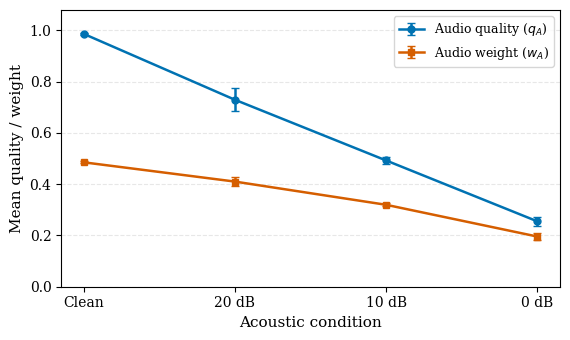


STEP 10.1 COMPLETE


In [22]:
# ============================================================
# STEP 10.1 — QUALITY AND WEIGHT FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({

    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42

})

plot_conditions = [
    "Clean", "20 dB", "10 dB", "0 dB"
]

plot_df = test_summary[
    test_summary.model == SELECTED_LEARNED_MODEL
].set_index(
    "condition"
).loc[plot_conditions]

x = np.arange(len(plot_conditions))

fig, ax = plt.subplots(
    figsize=(5.8, 3.5)
)

ax.errorbar(

    x,
    plot_df["audio_quality_mean"],
    yerr=plot_df["audio_quality_sd"],

    marker="o",
    markersize=5,
    linewidth=1.8,
    capsize=3,

    color="#0072B2",
    label=r"Audio quality ($q_A$)"
)

ax.errorbar(

    x,
    plot_df["audio_weight_mean"],
    yerr=plot_df["audio_weight_sd"],

    marker="s",
    markersize=5,
    linewidth=1.8,
    capsize=3,

    color="#D55E00",
    label=r"Audio weight ($w_A$)"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_conditions)

ax.set_xlabel("Acoustic condition")
ax.set_ylabel("Mean quality / weight")

ax.set_ylim(0, 1.08)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.legend(
    loc="best",
    frameon=True
)

fig.tight_layout()

fig.savefig(

    FAIR_ROOT / "figures/fig2_quality_weight.pdf",

    bbox_inches="tight"
)

fig.savefig(

    FAIR_ROOT / "figures/fig2_quality_weight.png",

    dpi=600,

    bbox_inches="tight"
)

plt.show()

print("\nSTEP 10.1 COMPLETE")

In [23]:
# ============================================================
# STEP 11.1 — SENTENCE-AND-SPEAKER-DISJOINT LOSO
# ============================================================

LOSO_ROOT = ROOT / "loso_revision"

for folder in ["models", "results", "predictions"]:
    (LOSO_ROOT / folder).mkdir(parents=True, exist_ok=True)

SPEAKERS = ["f1", "f2", "m1", "m2"]

LOSO_MODELS = [
    ("Audio_Only", "audio", 0.0),
    ("RAF1_Fair", "raf1", 0.0),
    (SELECTED_LEARNED_MODEL, "learned", 1.0)
]


def subset_split(data, mask):

    indices = torch.tensor(
        np.flatnonzero(mask),
        dtype=torch.long,
        device=DEVICE
    )

    return {
        "text": data["text"][indices],
        "audio": data["audio"][:, indices],
        "labels": data["labels"][indices],
        "metadata": data["metadata"]
            .iloc[np.flatnonzero(mask)]
            .reset_index(drop=True)
    }


@torch.inference_mode()
def evaluate_audio_fold(model, data):

    model.eval()

    logits = model(data["audio"][0])

    y = data["labels"]
    p = logits.argmax(dim=1)

    return (
        macro_f1(
            y.cpu().numpy(),
            p.cpu().numpy()
        ),
        F.cross_entropy(logits, y).item()
    )


def train_loso_fold(name, kind, q, seed, speaker):

    reset_seed(seed)

    train = load_split(seed, "train")
    val = load_split(seed, "validation")
    test = load_split(seed, "test")

    train = subset_split(
        train,
        train["metadata"].speaker.ne(speaker).to_numpy()
    )

    val = subset_split(
        val,
        val["metadata"].speaker.ne(speaker).to_numpy()
    )

    test = subset_split(
        test,
        test["metadata"].speaker.eq(speaker).to_numpy()
    )

    # Strict speaker and sentence separation
    assert speaker not in set(train["metadata"].speaker)
    assert speaker not in set(val["metadata"].speaker)
    assert set(test["metadata"].speaker) == {speaker}

    tr_ids = set(train["metadata"].sentence_id)
    va_ids = set(val["metadata"].sentence_id)
    te_ids = set(test["metadata"].sentence_id)

    assert not tr_ids.intersection(va_ids)
    assert not tr_ids.intersection(te_ids)
    assert not va_ids.intersection(te_ids)

    assert len(train["labels"]) == 2394
    assert len(val["labels"]) == 300
    assert len(test["labels"]) == 100

    reset_seed(seed)

    model = (
        AudioSentimentClassifier()
        if kind == "audio"
        else build_model(kind)
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3 if kind == "audio" else 5e-4,
        weight_decay=WEIGHT_DECAY
    )

    checkpoint = LOSO_ROOT / "models" / (
        f"{name}_{speaker}_seed_{seed}.pt"
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    wait = 0

    n = len(train["labels"])

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        rng = np.random.default_rng(seed * 1000 + epoch)

        order = rng.permutation(n)

        codes_all = rng.choice(
            6, size=n, p=CONDITION_PROBS
        )

        for start in range(0, n, BATCH_SIZE):

            idx_np = order[start:start+BATCH_SIZE]

            idx = torch.tensor(
                idx_np, dtype=torch.long, device=DEVICE
            )

            optimizer.zero_grad(set_to_none=True)

            if kind == "audio":

                logits = model(train["audio"][0, idx])

                loss = F.cross_entropy(
                    logits, train["labels"][idx]
                )

            else:

                codes = torch.tensor(
                    codes_all[idx_np],
                    dtype=torch.long,
                    device=DEVICE
                )

                t, a, y, ta, aa, qt, qa = make_batch(
                    train, idx, codes
                )

                out = model(t, a, ta, aa)

                loss = common_loss(
                    out, y, ta, aa, qt, qa, q
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

        if kind == "audio":

            score, val_loss = evaluate_audio_fold(
                model, val
            )

        else:

            vr = evaluate_conditions(
                model, val, name, seed, "validation"
            )

            score = vr.macro_f1.mean()
            val_loss = vr.loss.mean()

        improved = (
            score > best_f1 + 1e-8
            or (
                abs(score - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if improved:

            best_f1 = score
            best_loss = val_loss
            best_epoch = epoch
            wait = 0

            torch.save(model.state_dict(), checkpoint)

        else:
            wait += 1

        if wait >= PATIENCE:
            break

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location=DEVICE,
            weights_only=True
        )
    )

    model.eval()

    rows = []

    with torch.inference_mode():

        for code in ([0] if kind == "audio" else [0, 5]):

            y = test["labels"].cpu().numpy()

            if kind == "audio":

                logits = model(test["audio"][0])

            else:

                idx = torch.arange(len(y), device=DEVICE)

                codes = torch.full(
                    (len(y),), code,
                    dtype=torch.long, device=DEVICE
                )

                t, a, _, ta, aa, _, _ = make_batch(
                    test, idx, codes
                )

                logits = model(t, a, ta, aa)["fused_logits"]

            probs = F.softmax(logits, dim=1).cpu().numpy()
            pred = probs.argmax(axis=1)

            rows.append({
                "model": name,
                "speaker": speaker,
                "seed": seed,
                "condition": CONDITIONS[code],
                "best_epoch": best_epoch,
                "accuracy": accuracy_score(y, pred),
                "macro_f1": macro_f1(y, pred),
                "roc_auc": roc_auc_score(y, probs[:, 1])
            })

            pdf = test["metadata"].copy()

            pdf["predicted_label"] = pred
            pdf["prob_positive"] = probs[:, 1]

            pdf.to_csv(
                LOSO_ROOT / "predictions" /
                f"{name}_{speaker}_{seed}_{code}.csv",
                index=False
            )

    print(
        f"{name} | Speaker={speaker} | Seed={seed} | "
        f"Clean F1={rows[0]['macro_f1']:.4f}"
    )

    del model, optimizer, train, val, test
    gc.collect()
    torch.cuda.empty_cache()

    return rows


loso_rows = []

for speaker in SPEAKERS:

    for name, kind, q in LOSO_MODELS:

        for seed in SEEDS:

            loso_rows.extend(
                train_loso_fold(
                    name, kind, q, seed, speaker
                )
            )

            pd.DataFrame(loso_rows).to_csv(
                LOSO_ROOT / "results/loso_raw.csv",
                index=False
            )

loso_df = pd.DataFrame(loso_rows)

loso_table = loso_df.pivot_table(
    index=["model", "condition"],
    columns="speaker",
    values="macro_f1",
    aggfunc="mean"
)

loso_table["Mean"] = loso_table[SPEAKERS].mean(axis=1)
loso_table["SD"] = loso_table[SPEAKERS].std(axis=1)

print("\nSENTENCE-AND-SPEAKER-DISJOINT LOSO")

display(loso_table.round(4))

loso_table.to_csv(
    LOSO_ROOT / "results/loso_summary.csv"
)

print("\nSTEP 11.1 COMPLETE")

Audio_Only | Speaker=f1 | Seed=42 | Clean F1=0.5895
Audio_Only | Speaker=f1 | Seed=7 | Clean F1=0.5711
Audio_Only | Speaker=f1 | Seed=123 | Clean F1=0.5984
Audio_Only | Speaker=f1 | Seed=2026 | Clean F1=0.5543
RAF1_Fair | Speaker=f1 | Seed=42 | Clean F1=0.9700
RAF1_Fair | Speaker=f1 | Seed=7 | Clean F1=0.9700
RAF1_Fair | Speaker=f1 | Seed=123 | Clean F1=0.9800
RAF1_Fair | Speaker=f1 | Seed=2026 | Clean F1=0.9700
RAF2_Learned_q100 | Speaker=f1 | Seed=42 | Clean F1=0.9700
RAF2_Learned_q100 | Speaker=f1 | Seed=7 | Clean F1=0.9700
RAF2_Learned_q100 | Speaker=f1 | Seed=123 | Clean F1=0.9800
RAF2_Learned_q100 | Speaker=f1 | Seed=2026 | Clean F1=0.9700
Audio_Only | Speaker=f2 | Seed=42 | Clean F1=0.6999
Audio_Only | Speaker=f2 | Seed=7 | Clean F1=0.7287
Audio_Only | Speaker=f2 | Seed=123 | Clean F1=0.6400
Audio_Only | Speaker=f2 | Seed=2026 | Clean F1=0.6144
RAF1_Fair | Speaker=f2 | Seed=42 | Clean F1=0.9700
RAF1_Fair | Speaker=f2 | Seed=7 | Clean F1=0.9700
RAF1_Fair | Speaker=f2 | Seed=123 |

speaker                             f1      f2      m1      m2    Mean      SD
model             condition                                                   
Audio_Only        Clean         0.5783  0.6707  0.4767  0.4700  0.5489  0.0951
RAF1_Fair         Clean         0.9725  0.9725  0.9725  0.9725  0.9725  0.0000
                  Missing Text  0.5309  0.6638  0.4751  0.9498  0.6549  0.2119
RAF2_Learned_q100 Clean         0.9725  0.9700  0.9750  0.9750  0.9731  0.0024
                  Missing Text  0.5223  0.6664  0.5171  0.8628  0.6422  0.1625


STEP 11.1 COMPLETE


In [24]:
# ============================================================
# STEP 12.1 — RECORDING CHANNEL AUDIT
# ============================================================

import soundfile as sf
import subprocess

from concurrent.futures import ThreadPoolExecutor

channel_meta = pd.concat(
    [audio_meta[s].copy() for s in SPLITS],
    ignore_index=True
)


def get_audio_channels(path):

    try:
        return int(sf.info(str(path)).channels)

    except Exception:

        try:

            result = subprocess.check_output([
                "ffprobe",
                "-v", "error",
                "-select_streams", "a:0",
                "-show_entries", "stream=channels",
                "-of", "csv=p=0",
                str(path)
            ], text=True)

            return int(result.strip().splitlines()[0])

        except Exception:
            return np.nan


with ThreadPoolExecutor(max_workers=8) as executor:

    channel_meta["channels"] = list(
        executor.map(
            get_audio_channels,
            channel_meta["audio_path"]
        )
    )

print("Total recordings:", len(channel_meta))

print(
    "Unreadable channel metadata:",
    channel_meta.channels.isna().sum()
)

print("\nCHANNEL COUNT VS SENTIMENT")

display(pd.crosstab(
    channel_meta["channels"],
    channel_meta["label"],
    dropna=False
))

print("\nSPEAKER AND CHANNEL COUNT VS SENTIMENT")

display(pd.crosstab(
    [
        channel_meta["speaker"],
        channel_meta["channels"]
    ],
    channel_meta["label"]
))

channel_meta.to_csv(
    ROOT / "audit/recording_channel_metadata.csv",
    index=False
)

# Channel-inclusive metadata classifier
features = [
    "speaker",
    "original_sample_rate",
    "audio_duration",
    "channels"
]

pipeline = Pipeline([

    ("preprocess", ColumnTransformer([

        ("categorical", Pipeline([
            ("impute", SimpleImputer(
                strategy="most_frequent"
            )),
            ("encode", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]), [
            "speaker",
            "original_sample_rate",
            "channels"
        ]),

        ("numerical", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), ["audio_duration"])

    ])),

    ("classifier", LogisticRegression(
        max_iter=1000, random_state=42
    ))
])

if channel_meta.channels.notna().any():

    train = channel_meta[channel_meta.split == "train"]
    test = channel_meta[channel_meta.split == "test"]

    pipeline.fit(train[features], train.label)

    pred = pipeline.predict(test[features])
    prob = pipeline.predict_proba(test[features])[:, 1]

    channel_result = pd.DataFrame([{
        "accuracy": accuracy_score(test.label, pred),
        "macro_f1": macro_f1(test.label, pred),
        "roc_auc": roc_auc_score(test.label, prob)
    }])

    display(channel_result.round(4))

    channel_result.to_csv(
        ROOT / "audit/channel_inclusive_classifier.csv",
        index=False
    )

else:
    print("Channel information unavailable.")

print("\nSTEP 12.1 COMPLETE")

Total recordings: 3992
Unreadable channel metadata: 0

CHANNEL COUNT VS SENTIMENT


label,0,1
channels,,
1,1497,1497
2,499,499



SPEAKER AND CHANNEL COUNT VS SENTIMENT


,label,0,1
speaker,channels,,
f1,1,499,499
f2,2,499,499
m1,1,499,499
m2,1,499,499


,accuracy,macro_f1,roc_auc
0,0.71,0.7097,0.7856



STEP 12.1 COMPLETE


In [25]:
# ============================================================
# STEP 13.1 — UNSEEN ACOUSTIC CORRUPTIONS
# ============================================================

import librosa
import hashlib
import subprocess

from scipy.signal import fftconvolve
from transformers import AutoFeatureExtractor, AutoModel
from tqdm.auto import tqdm

STRESS_ROOT = ROOT / "extended_robustness"

for folder in [
    "embeddings", "results",
    "predictions", "metadata"
]:
    (STRESS_ROOT / folder).mkdir(
        parents=True, exist_ok=True
    )

AUDIO_DEVICE = torch.device(
    "cuda:1" if torch.cuda.device_count() > 1
    else DEVICE
)

SR = 16000
NOISE_SEED = 2026

AUDIO_ENCODER_NAME = "facebook/wav2vec2-xls-r-300m"

extractor = AutoFeatureExtractor.from_pretrained(
    AUDIO_ENCODER_NAME
)

xlsr = AutoModel.from_pretrained(
    AUDIO_ENCODER_NAME
).to(AUDIO_DEVICE).eval()

for p in xlsr.parameters():
    p.requires_grad = False


def load_wave(path):

    wave, _ = librosa.load(
        str(path), sr=SR, mono=True
    )

    return wave.astype(np.float32)


# ------------------------------------------------------------
# FIXED TRAINING-ONLY BABBLE DONOR POOL
# ------------------------------------------------------------

donor_pool = {}

for speaker in SPEAKERS:

    donor_pool[speaker] = []

    for label in [0, 1]:

        group = audio_meta["train"].query(
            "speaker == @speaker and label == @label"
        )

        sampled = group.sample(
            n=8, random_state=NOISE_SEED
        )

        for path in sampled.audio_path:

            donor_pool[speaker].append(
                (str(path), load_wave(path))
            )


def make_babble(wave, rng, snr_db=10):

    noise = np.zeros(len(wave), dtype=np.float32)
    donors = []

    for speaker in SPEAKERS:

        pool = donor_pool[speaker]

        path, donor = pool[rng.integers(len(pool))]

        donors.append(path)

        offset = int(rng.integers(len(donor)))

        segment = donor[
            (np.arange(len(wave)) + offset) % len(donor)
        ]

        segment = segment / (
            np.sqrt(np.mean(segment**2)) + 1e-8
        )

        noise += segment

    signal_power = np.mean(wave**2)
    noise_power = np.mean(noise**2)

    scale = np.sqrt(
        signal_power /
        (noise_power * 10**(snr_db/10) + 1e-12)
    )

    return wave + scale * noise, donors


def make_reverb(wave, rng):

    rt60 = 0.4

    t = np.arange(int(SR * rt60)) / SR

    impulse = (
        rng.normal(size=len(t))
        * np.exp(-np.log(1000) * t / rt60)
    ).astype(np.float32)

    impulse /= np.sqrt(
        np.sum(impulse**2)
    ) + 1e-8

    impulse *= 0.7
    impulse[0] += 1.0

    wet = fftconvolve(
        wave, impulse, mode="full"
    )[:len(wave)]

    return wet.astype(np.float32)


def make_codec(wave):

    encoded = subprocess.run([

        "ffmpeg", "-v", "error",
        "-f", "f32le",
        "-ar", "16000",
        "-ac", "1",
        "-i", "pipe:0",
        "-ar", "8000",
        "-f", "mulaw",
        "pipe:1"

    ], input=wave.astype("<f4").tobytes(),
       stdout=subprocess.PIPE,
       stderr=subprocess.PIPE,
       check=True).stdout

    decoded = subprocess.run([

        "ffmpeg", "-v", "error",
        "-f", "mulaw",
        "-ar", "8000",
        "-ac", "1",
        "-i", "pipe:0",
        "-ar", "16000",
        "-f", "f32le",
        "pipe:1"

    ], input=encoded,
       stdout=subprocess.PIPE,
       stderr=subprocess.PIPE,
       check=True).stdout

    return np.frombuffer(
        decoded, dtype="<f4"
    ).copy()


@torch.inference_mode()
def encode_waveforms(waveforms):

    inputs = extractor(
        waveforms,
        sampling_rate=SR,
        padding=True,
        return_attention_mask=True,
        return_tensors="pt"
    )

    x = inputs["input_values"].to(AUDIO_DEVICE)
    mask = inputs["attention_mask"].to(AUDIO_DEVICE)

    hidden = xlsr(
        input_values=x,
        attention_mask=mask
    ).last_hidden_state

    feature_mask = (
        xlsr._get_feature_vector_attention_mask(
            hidden.shape[1], mask
        )
    ).unsqueeze(-1).to(hidden.dtype)

    features = (
        (hidden * feature_mask).sum(dim=1)
        / feature_mask.sum(dim=1).clamp(min=1e-9)
    )

    return features.cpu().numpy().astype(np.float32)


# ------------------------------------------------------------
# SANITY CHECK: RECREATE CLEAN EMBEDDINGS
# ------------------------------------------------------------

meta_test = audio_meta["test"].reset_index(drop=True)

clean_check = np.concatenate([
    encode_waveforms([
        load_wave(p)
        for p in meta_test.audio_path.iloc[i:i+8]
    ])
    for i in [0, 8]
])

cached_check = np.load(
    EMBED_DIR / "xlsr_test_embeddings.npy"
)[:16]

cosine = (
    (clean_check * cached_check).sum(axis=1)
    / (
        np.linalg.norm(clean_check, axis=1)
        * np.linalg.norm(cached_check, axis=1)
        + 1e-12
    )
)

print("Clean embedding reproduction cosine:", cosine.mean())

assert cosine.mean() > 0.99, (
    "Encoder reproduction mismatch. Investigate before continuing."
)

# ------------------------------------------------------------
# GENERATE UNSEEN CORRUPTIONS
# ------------------------------------------------------------

STRESS_AUDIO = [
    "Babble_10dB",
    "Reverb_RT60_04",
    "G711_Codec"
]

for condition in STRESS_AUDIO:

    embeddings = []
    records = []

    for start in tqdm(
        range(0, len(meta_test), 8),
        desc=condition
    ):

        waves = []

        for i in range(start, min(start+8, len(meta_test))):

            row = meta_test.iloc[i]

            wave = load_wave(row.audio_path)

            seed = NOISE_SEED + i

            rng = np.random.default_rng(seed)

            donors = []

            if condition == "Babble_10dB":

                corrupted, donors = make_babble(wave, rng)

            elif condition == "Reverb_RT60_04":

                corrupted = make_reverb(wave, rng)

            else:

                corrupted = make_codec(wave)

            corrupted = corrupted.astype(np.float32)

            assert len(corrupted) > 0
            assert np.isfinite(corrupted).all()

            records.append({
                "sentence_id": row.sentence_id,
                "speaker": row.speaker,
                "condition": condition,
                "seed": seed,
                "donors": json.dumps(donors),
                "waveform_sha256": hashlib.sha256(
                    corrupted.tobytes()
                ).hexdigest()
            })

            waves.append(corrupted)

        embeddings.append(encode_waveforms(waves))

    arr = np.concatenate(embeddings)

    assert arr.shape == (400, 1024)
    assert np.isfinite(arr).all()

    np.save(
        STRESS_ROOT / "embeddings" /
        f"{condition}.npy",
        arr
    )

    pd.DataFrame(records).to_csv(
        STRESS_ROOT / "metadata" /
        f"{condition}.csv",
        index=False
    )

    print(condition, arr.shape, "SAVED")

del xlsr, extractor
gc.collect()
torch.cuda.empty_cache()

print("\nSTEP 13.1 COMPLETE")

preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

Reverb_RT60_04:   0%|          | 0/50 [00:00<?, ?it/s]

Reverb_RT60_04 (400, 1024) SAVED


G711_Codec:   0%|          | 0/50 [00:00<?, ?it/s]

G711_Codec (400, 1024) SAVED

STEP 13.1 COMPLETE


In [26]:
# ============================================================
# STEP 14.1 — NOISY TEXT EMBEDDINGS
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

TEXT_MODEL_NAME = "csebuetnlp/banglabert"
MAX_LENGTH = 24

tokenizer = AutoTokenizer.from_pretrained(
    TEXT_MODEL_NAME
)

noisy_text_meta = text_meta["test"].copy().reset_index(drop=True)


def corrupt_text(text, seed):

    words = str(text).split()

    if len(words) <= 1:
        return str(text)

    rng = np.random.default_rng(seed)

    n_drop = min(
        len(words) - 1,
        max(1, round(len(words) * 0.20))
    )

    removed = set(
        rng.choice(
            len(words),
            size=n_drop,
            replace=False
        ).tolist()
    )

    return " ".join(
        w for i, w in enumerate(words)
        if i not in removed
    )


noisy_text_meta["noisy_text"] = [

    corrupt_text(text, NOISE_SEED + i)

    for i, text in enumerate(
        noisy_text_meta.normalized_text
    )
]

noisy_text_meta.to_csv(
    STRESS_ROOT / "metadata/noisy_text.csv",
    index=False
)

print("Text corruption examples:")

display(
    noisy_text_meta[
        ["normalized_text", "noisy_text"]
    ].head(5)
)

for seed in SEEDS:

    text_model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            TEXT_MODEL_NAME,
            num_labels=2
        )
    ).to(DEVICE)

    checkpoint = (
        V2_ROOT / "multiseed/models" /
        f"banglabert_seed_{seed}.pt"
    )

    text_model.load_state_dict(
        torch.load(
            checkpoint,
            map_location="cpu",
            weights_only=True
        ),
        strict=True
    )

    text_model.eval()

    features = []

    with torch.inference_mode():

        for start in range(0, len(noisy_text_meta), 32):

            texts = noisy_text_meta.noisy_text.iloc[
                start:start+32
            ].tolist()

            encoded = tokenizer(
                texts,
                padding=True,
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt"
            )

            encoded = {
                k: v.to(DEVICE)
                for k, v in encoded.items()
            }

            hidden = text_model.electra(
                **encoded,
                return_dict=True
            ).last_hidden_state

            features.append(
                hidden[:, 0, :].cpu().numpy()
            )

    arr = np.concatenate(features).astype(np.float32)

    assert arr.shape == (100, 768)
    assert np.isfinite(arr).all()

    np.save(
        STRESS_ROOT / "embeddings" /
        f"noisy_text_seed_{seed}.npy",
        arr
    )

    print("Seed:", seed, arr.shape, "SAVED")

    del text_model
    gc.collect()
    torch.cuda.empty_cache()

print("\nSTEP 14.1 COMPLETE")

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Text corruption examples:


,normalized_text,noisy_text
0,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা উচিত।,গুরুজনদের প্রতি শ্রদ্ধা প্রদর্শন করা
1,"আকাশ বলে - উঠে দাঁড়াও, আলো সামনে।",আকাশ বলে - উঠে আলো সামনে।
2,আজ ক্লাসের আলোচনা বেশ প্রশংসনীয় ছিল।,আজ ক্লাসের আলোচনা প্রশংসনীয় ছিল।
3,আজ তোমার কাজে দারুণ ফোকাস দেখলাম।,আজ কাজে দারুণ ফোকাস দেখলাম।
4,আজ তোমার পোশাকটা বেশ লাগছিল।,তোমার পোশাকটা বেশ লাগছিল।


... (10 outputs left out)

Seed: 123 (100, 768) SAVED


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

Seed: 2026 (100, 768) SAVED

STEP 14.1 COMPLETE


In [27]:
# ============================================================
# STEP 14.2 — EXTENDED ROBUSTNESS EVALUATION
# ============================================================

STRESS_CONDITIONS = [

    ("Babble 10 dB", "Babble_10dB", False),

    ("Reverberation", "Reverb_RT60_04", False),

    ("G711 Codec", "G711_Codec", False),

    ("Noisy Text", "Clean", True),

    ("Noisy Text + Babble", "Babble_10dB", True)
]

stress_rows = []

for name, kind, q in TEST_EXPERIMENTS:

    for seed in SEEDS:

        data = load_split(seed, "test")

        model = build_model(kind).to(DEVICE)

        model.load_state_dict(
            torch.load(
                FAIR_ROOT / "models" /
                f"{name}_seed_{seed}.pt",
                map_location=DEVICE,
                weights_only=True
            )
        )

        model.eval()

        index_map = {
            sid: i for i, sid in enumerate(
                noisy_text_meta.sentence_id
            )
        }

        align = np.array([
            index_map[sid]
            for sid in data["metadata"].sentence_id
        ])

        noisy_text = np.load(
            STRESS_ROOT / "embeddings" /
            f"noisy_text_seed_{seed}.npy"
        )[align]

        noisy_text = torch.tensor(
            noisy_text,
            dtype=torch.float32,
            device=DEVICE
        )

        y = data["labels"].cpu().numpy()

        availability = torch.ones(
            len(y), device=DEVICE
        )

        for condition, audio_name, use_noisy_text in STRESS_CONDITIONS:

            t = (
                noisy_text
                if use_noisy_text
                else data["text"]
            )

            if audio_name == "Clean":

                a = data["audio"][0]

            else:

                a = torch.tensor(
                    np.load(
                        STRESS_ROOT / "embeddings" /
                        f"{audio_name}.npy"
                    ),
                    dtype=torch.float32,
                    device=DEVICE
                )

            with torch.inference_mode():

                out = model(
                    t, a,
                    availability,
                    availability
                )

                probs = F.softmax(
                    out["fused_logits"], dim=1
                ).cpu().numpy()

            pred = probs.argmax(axis=1)

            row = {
                "model": name,
                "seed": seed,
                "condition": condition,
                "accuracy": accuracy_score(y, pred),
                "macro_f1": macro_f1(y, pred),
                "roc_auc": roc_auc_score(y, probs[:, 1])
            }

            for field in [
                "text_quality",
                "audio_quality",
                "text_weight",
                "audio_weight"
            ]:

                row[field] = (
                    out[field].mean().item()
                    if field in out else np.nan
                )

            stress_rows.append(row)

            pdf = data["metadata"].copy()

            pdf["predicted_label"] = pred
            pdf["prob_positive"] = probs[:, 1]

            safe_condition = condition.replace(" ", "_")

            pdf.to_csv(
                STRESS_ROOT / "predictions" /
                f"{name}_{seed}_{safe_condition}.csv",
                index=False
            )

        print(name, seed, "COMPLETE")

        del model, data, noisy_text

stress_df = pd.DataFrame(stress_rows)

stress_df.to_csv(
    STRESS_ROOT / "results/stress_raw.csv",
    index=False
)

stress_summary = stress_df.groupby(
    ["model", "condition"]
).agg(
    f1_mean=("macro_f1", "mean"),
    f1_sd=("macro_f1", "std"),
    auc_mean=("roc_auc", "mean"),
    audio_quality=("audio_quality", "mean"),
    text_quality=("text_quality", "mean"),
    audio_weight=("audio_weight", "mean")
).reset_index()

stress_summary["Macro-F1"] = [

    f"{m:.4f} ± {s:.4f}"

    for m, s in zip(
        stress_summary.f1_mean,
        stress_summary.f1_sd
    )
]

stress_table = stress_summary.pivot(
    index="model",
    columns="condition",
    values="Macro-F1"
)

print("\nEXTENDED ROBUSTNESS TABLE")

display(stress_table)

print("\nPROPOSED MODEL QUALITY UNDER UNSEEN CORRUPTION")

display(
    stress_summary[
        stress_summary.model == SELECTED_LEARNED_MODEL
    ].round(4)
)

stress_summary.to_csv(
    STRESS_ROOT / "results/stress_summary.csv",
    index=False
)

stress_table.to_csv(
    STRESS_ROOT / "results/stress_table.csv"
)

print("\nSTEP 14.2 COMPLETE")

Simple_Fair 42 COMPLETE
Simple_Fair 7 COMPLETE
Simple_Fair 123 COMPLETE
Simple_Fair 2026 COMPLETE
RAF1_Fair 42 COMPLETE
RAF1_Fair 7 COMPLETE
RAF1_Fair 123 COMPLETE
RAF1_Fair 2026 COMPLETE
Gated_Fair 42 COMPLETE
Gated_Fair 7 COMPLETE
Gated_Fair 123 COMPLETE
Gated_Fair 2026 COMPLETE
RAF2_Hard_q000 42 COMPLETE
RAF2_Hard_q000 7 COMPLETE
RAF2_Hard_q000 123 COMPLETE
RAF2_Hard_q000 2026 COMPLETE
RAF2_Hard_q100 42 COMPLETE
RAF2_Hard_q100 7 COMPLETE
RAF2_Hard_q100 123 COMPLETE
RAF2_Hard_q100 2026 COMPLETE
RAF2_Learned_q000 42 COMPLETE
RAF2_Learned_q000 7 COMPLETE
RAF2_Learned_q000 123 COMPLETE
RAF2_Learned_q000 2026 COMPLETE
RAF2_Learned_q100 42 COMPLETE
RAF2_Learned_q100 7 COMPLETE
RAF2_Learned_q100 123 COMPLETE
RAF2_Learned_q100 2026 COMPLETE

EXTENDED ROBUSTNESS TABLE


condition,Babble 10 dB,G711 Codec,Noisy Text,Noisy Text + Babble,Reverberation
model,,,,,
Gated_Fair,0.9725 ± 0.0050,0.9719 ± 0.0056,0.9322 ± 0.0209,0.9322 ± 0.0209,0.9706 ± 0.0072
RAF1_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9372 ± 0.0225,0.9353 ± 0.0211,0.9719 ± 0.0056
RAF2_Hard_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9391 ± 0.0189,0.9391 ± 0.0189,0.9725 ± 0.0050
RAF2_Hard_q100,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9449 ± 0.0130,0.9442 ± 0.0140,0.9750 ± 0.0058
RAF2_Learned_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9391 ± 0.0189,0.9391 ± 0.0189,0.9725 ± 0.0050
RAF2_Learned_q100,0.9719 ± 0.0056,0.9719 ± 0.0056,0.9372 ± 0.0225,0.9341 ± 0.0197,0.9700 ± 0.0082
Simple_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9353 ± 0.0176,0.9372 ± 0.0152,0.9725 ± 0.0050



PROPOSED MODEL QUALITY UNDER UNSEEN CORRUPTION


,model,condition,f1_mean,f1_sd,auc_mean,audio_quality,text_quality,audio_weight,Macro-F1
25,RAF2_Learned_q100,Babble 10 dB,0.9719,0.0056,0.9838,0.9476,0.9998,0.4750,0.9719 ± 0.0056
26,RAF2_Learned_q100,G711 Codec,0.9719,0.0056,0.9904,0.9842,0.9998,0.4848,0.9719 ± 0.0056
27,RAF2_Learned_q100,Noisy Text,0.9372,0.0225,0.9834,0.9866,0.9997,0.4855,0.9372 ± 0.0225
28,RAF2_Learned_q100,Noisy Text + Babble,0.9341,0.0197,0.9723,0.9476,0.9997,0.4751,0.9341 ± 0.0197
29,RAF2_Learned_q100,Reverberation,0.9700,0.0082,0.9882,0.9811,0.9998,0.4840,0.9700 ± 0.0082



STEP 14.2 COMPLETE


In [28]:
# ============================================================
# STEP 15.1 — BANGLA ERROR ANALYSIS
# ============================================================

error_seed = 42

clean = pd.read_csv(
    FAIR_ROOT / "predictions" /
    f"{SELECTED_LEARNED_MODEL}_seed_{error_seed}_test_Clean.csv"
)

missing = pd.read_csv(
    FAIR_ROOT / "predictions" /
    f"{SELECTED_LEARNED_MODEL}_seed_{error_seed}_test_Missing_Text.csv"
)

noisy = pd.read_csv(
    STRESS_ROOT / "predictions" /
    f"{SELECTED_LEARNED_MODEL}_{error_seed}_Noisy_Text_+_Babble.csv"
)

keys = ["sentence_id", "speaker"]

for df in [clean, missing, noisy]:

    df["sentence_id"] = df["sentence_id"].astype(str)

comparison = clean[
    keys + ["label", "predicted_label"]
].rename(columns={
    "predicted_label": "clean_prediction"
})

comparison = comparison.merge(

    missing[keys + [
        "predicted_label", "prob_positive"
    ]].rename(columns={
        "predicted_label": "missing_text_prediction",
        "prob_positive": "missing_text_prob_positive"
    }),

    on=keys,
    validate="one_to_one"
)

comparison = comparison.merge(

    noisy[keys + ["predicted_label"]].rename(
        columns={
            "predicted_label": "dual_corruption_prediction"
        }
    ),

    on=keys,
    validate="one_to_one"
)

comparison = comparison.merge(

    noisy_text_meta[
        ["sentence_id", "text", "noisy_text"]
    ].assign(
        sentence_id=lambda d: d.sentence_id.astype(str)
    ),

    on="sentence_id",
    validate="many_to_one"
)

examples = comparison[

    (comparison.clean_prediction == comparison.label)

    &

    (
        (comparison.missing_text_prediction != comparison.label)
        |
        (comparison.dual_corruption_prediction != comparison.label)
    )

].sort_values(
    ["sentence_id", "speaker"]
).drop_duplicates(
    "sentence_id"
).head(3)

print("\nGENUINE BANGLA ERROR EXAMPLES")

for _, row in examples.iterrows():

    print("\nSentence:", row.sentence_id)
    print("Original:", row.text)
    print("Corrupted:", row.noisy_text)
    print("Speaker:", row.speaker)
    print("True label:", row.label)
    print("Clean prediction:", row.clean_prediction)
    print("Missing-text prediction:", row.missing_text_prediction)
    print("Dual-corruption prediction:", row.dual_corruption_prediction)

examples.to_csv(
    STRESS_ROOT / "results/bangla_error_examples.csv",
    index=False
)

print("\nSTEP 15.1 COMPLETE")


GENUINE BANGLA ERROR EXAMPLES

Sentence: si_0044
Original: আজ বন্ধুদের মধ্যে চমৎকার একতা দেখলাম।
Corrupted: আজ বন্ধুদের চমৎকার একতা দেখলাম।
Speaker: f1
True label: 1
Clean prediction: 1
Missing-text prediction: 0
Dual-corruption prediction: 1

Sentence: si_0099
Original: উদ্দীপক কথোপকথন মনকে করে প্রসারিত।
Corrupted: উদ্দীপক মনকে করে প্রসারিত।
Speaker: f1
True label: 1
Clean prediction: 1
Missing-text prediction: 0
Dual-corruption prediction: 1

Sentence: si_0193
Original: তোমার আচরণ আমাকে সবসময়ই আপন মনে করায়।
Corrupted: তোমার আচরণ আমাকে সবসময়ই মনে করায়।
Speaker: f2
True label: 1
Clean prediction: 1
Missing-text prediction: 0
Dual-corruption prediction: 1

STEP 15.1 COMPLETE


In [29]:
# STEP 16 — FINAL PREDICTION AUDIT

final_audit_rows = []

for name, kind, q in TEST_EXPERIMENTS:

    for seed in SEEDS:

        def read_predictions(condition):

            safe = condition.replace(" ", "_")

            df = pd.read_csv(
                FAIR_ROOT / "predictions" /
                f"{name}_seed_{seed}_test_{safe}.csv"
            )

            return df.set_index(
                ["sentence_id", "speaker"]
            ).sort_index()

        clean = read_predictions("Clean")

        for condition in CONDITIONS[1:]:

            other = read_predictions(condition)

            assert clean.index.equals(other.index)

            assert np.array_equal(
                clean.label.to_numpy(),
                other.label.to_numpy()
            )

            diff = np.abs(
                clean.prob_positive.to_numpy()
                - other.prob_positive.to_numpy()
            )

            final_audit_rows.append({

                "model": name,
                "seed": seed,
                "condition": condition,

                "changed_predictions": int(
                    (
                        clean.predicted_label
                        != other.predicted_label
                    ).sum()
                ),

                "mean_probability_difference":
                    diff.mean(),

                "max_probability_difference":
                    diff.max(),

                "identical_probabilities":
                    bool(np.array_equal(
                        clean.prob_positive.to_numpy(),
                        other.prob_positive.to_numpy()
                    ))
            })

final_audit_df = pd.DataFrame(final_audit_rows)

final_audit_df.to_csv(
    ROOT / "audit/final_prediction_audit.csv",
    index=False
)

display(
    final_audit_df.groupby(
        ["model", "condition"]
    ).agg(
        changed_predictions=("changed_predictions", "sum"),
        mean_probability_difference=(
            "mean_probability_difference", "mean"
        ),
        identical_probability_runs=(
            "identical_probabilities", "sum"
        )
    )
)

# Original text-only prediction verification

text_only_rows = []

for seed in SEEDS:

    path = (
        V2_ROOT / "multiseed/predictions" /
        f"banglabert_seed_{seed}_test_predictions.csv"
    )

    df = pd.read_csv(path)

    if {"label", "predicted_label"}.issubset(df.columns):

        text_only_rows.append({
            "seed": seed,
            "samples": len(df),
            "accuracy": accuracy_score(
                df.label, df.predicted_label
            ),
            "macro_f1": macro_f1(
                df.label, df.predicted_label
            )
        })

    else:
        print("Check text prediction columns:", df.columns.tolist())

text_only_audit = pd.DataFrame(text_only_rows)

display(text_only_audit)

if len(text_only_audit) == len(SEEDS):

    print(
        text_only_audit[
            ["accuracy", "macro_f1"]
        ].agg(["mean", "std"]).round(4)
    )

    text_only_audit.to_csv(
        ROOT / "audit/text_only_verified.csv",
        index=False
    )

print("STEP 16 COMPLETE")

changed_predictions  \
model             condition                            
Gated_Fair        0 dB                             1   
                  10 dB                            1   
                  20 dB                            3   
                  Missing Audio                    2   
                  Missing Text                   325   
RAF1_Fair         0 dB                             1   
                  10 dB                            1   
                  20 dB                            1   
                  Missing Audio                    1   
                  Missing Text                   298   
RAF2_Hard_q000    0 dB                             0   
                  10 dB                            0   
                  20 dB                            0   
                  Missing Audio                    0   
                  Missing Text                   394   
RAF2_Hard_q100    0 dB                             0   
                  10 dB                            0   
                  20 dB                            0   
                  Missing Audio                    0   
                  Missing Text                   393   
RAF2_Learned_q000 0 dB                             0   
                  10 dB                            0   
                  20 dB                            0   
                  Missing Audio                    0   
                  Missing Text                   386   
RAF2_Learned_q100 0 dB                             1   
                  10 dB                            1   
                  20 dB                            1   
                  Missing Audio                    1   
                  Missing Text                   315   
Simple_Fair       0 dB                             0   
                  10 dB                            0   
                  20 dB                            0   
                  Missing Audio                    0   
                  Missing Text                   540   

                                 mean_probability_difference  \
model             condition                                    
Gated_Fair        0 dB                              0.000332   
                  10 dB                             0.000381   
                  20 dB                             0.000412   
                  Missing Audio                     0.000709   
                  Missing Text                      0.307842   
RAF1_Fair         0 dB                              0.000223   
                  10 dB                             0.000201   
                  20 dB                             0.000172   
                  Missing Audio                     0.000156   
                  Missing Text                      0.285239   
RAF2_Hard_q000    0 dB                              0.000085   
                  10 dB                             0.000076   
                  20 dB                             0.000076   
                  Missing Audio                     0.000105   
                  Missing Text                      0.346991   
RAF2_Hard_q100    0 dB                              0.000253   
                  10 dB                             0.000246   
                  20 dB                             0.000260   
                  Missing Audio                     0.000282   
                  Missing Text                      0.364985   
RAF2_Learned_q000 0 dB                              0.000075   
                  10 dB                             0.000069   
                  20 dB                             0.000076   
                  Missing Audio                     0.000138   
                  Missing Text                      0.348532   
RAF2_Learned_q100 0 dB                              0.000405   
                  10 dB                             0.000337   
                  20 dB                             0.000435   
                  Missing Audio         

,seed,samples,accuracy,macro_f1
0,42,100,0.98,0.979992
1,7,100,0.96,0.959936
2,123,100,0.98,0.979992
3,2026,100,0.96,0.959936


      accuracy  macro_f1
mean    0.9700    0.9700
std     0.0115    0.0116
STEP 16 COMPLETE


In [30]:
# ============================================================
# STEP 17 — CAMERA-READY RESULTS EXPORT
# ============================================================

import zipfile
import importlib.metadata
import hashlib
import platform

EXPORT_PATH = Path(
    "/kaggle/working/ICCIT_2026_Camera_Ready_Results.zip"
)

allowed_extensions = {
    ".csv", ".json", ".png",
    ".pdf", ".txt"
}

excluded_folders = {
    "original_artifacts_v2",
    "original_artifacts_v3"
}

packages = [
    "torch",
    "transformers",
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "librosa",
    "soundfile",
    "matplotlib",
    "kagglehub"
]

versions = []

for package in packages:

    try:
        versions.append(
            f"{package}=={importlib.metadata.version(package)}"
        )
    except importlib.metadata.PackageNotFoundError:
        pass

(ROOT / "requirements.txt").write_text(
    "\n".join(versions),
    encoding="utf-8"
)

with open(ROOT / "environment.json", "w") as f:

    json.dump({
        "python": platform.python_version(),
        "pytorch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu_count": torch.cuda.device_count(),
        "seeds": SEEDS,
        "selected_model": SELECTED_LEARNED_MODEL,
        "selected_lambda_q": 1.0
    }, f, indent=2)

files_to_export = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    relative = path.relative_to(ROOT)

    if any(p in excluded_folders for p in relative.parts):
        continue

    if path.suffix.lower() in allowed_extensions:
        files_to_export.append(path)

# Include original split metadata
for path in (V2_ROOT / "processed_data").glob("*.csv"):
    files_to_export.append(path)

# Include alignment metadata
for path in (V2_ROOT / "embeddings").glob("*metadata.csv"):
    files_to_export.append(path)

# Include original ablation histories
for path in (V3_ROOT / "loss_weight_ablation").rglob("*.csv"):
    files_to_export.append(path)

manifest = []

with zipfile.ZipFile(
    EXPORT_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in sorted(set(files_to_export)):

        relative = str(path.relative_to(ROOT))

        archive.write(path, arcname=relative)

        manifest.append({
            "filename": relative,
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(
                path.read_bytes()
            ).hexdigest()
        })

    archive.writestr(
        "manifest.json",
        json.dumps(manifest, indent=2)
    )

print("=" * 70)
print("CAMERA-READY EXPORT COMPLETE")
print("=" * 70)

print("Exported files:", len(manifest))
print("ZIP:", EXPORT_PATH)

print(
    "Size:",
    round(EXPORT_PATH.stat().st_size / 1024**2, 2),
    "MB"
)

from IPython.display import FileLink, display

display(FileLink(EXPORT_PATH.name))

CAMERA-READY EXPORT COMPLETE
Exported files: 558
ZIP: /kaggle/working/ICCIT_2026_Camera_Ready_Results.zip
Size: 4.45 MB


/kaggle/working/ICCIT_2026_Camera_Ready_Results.zip

In [31]:
# ============================================================
# STEP 18.1 — TMC EVIDENTIAL FUSION
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import json
import gc
import time

TMC_NAME = "TMC_Fair"
TMC_LR = 5e-4
TMC_ANNEAL_EPOCHS = 30


class TMCFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.text_evidence = nn.Sequential(
            nn.LayerNorm(768),
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(256, 2),
            nn.Softplus()
        )

        self.audio_evidence = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(256, 2),
            nn.Softplus()
        )

    @staticmethod
    def combine_evidence(et, ea):

        # Algebraically equivalent two-view
        # Dempster-Shafer evidence combination.
        K = et.shape[-1]

        return et + ea + (et * ea) / K

    def forward(self, text, audio, ta, aa):

        text = text * ta.unsqueeze(1)
        audio = audio * aa.unsqueeze(1)

        et = self.text_evidence(text)
        ea = self.audio_evidence(audio)

        # Missing views contribute vacuous evidence.
        et = et * ta.unsqueeze(1)
        ea = ea * aa.unsqueeze(1)

        alpha_t = et + 1
        alpha_a = ea + 1

        fused_evidence = self.combine_evidence(
            et, ea
        )

        alpha_f = fused_evidence + 1

        return {

            "alpha_text": alpha_t,
            "alpha_audio": alpha_a,
            "alpha_fused": alpha_f,

            # Softmax(log(alpha)) gives
            # the Dirichlet predictive mean.
            "fused_logits": torch.log(alpha_f),

            "text_uncertainty":
                2 / alpha_t.sum(dim=1),

            "audio_uncertainty":
                2 / alpha_a.sum(dim=1),

            "fused_uncertainty":
                2 / alpha_f.sum(dim=1)
        }


# ------------------------------------------------------------
# DIRICHLET KL DIVERGENCE TO UNIFORM PRIOR
# ------------------------------------------------------------

def dirichlet_kl_uniform(alpha):

    K = alpha.shape[1]

    strength = alpha.sum(
        dim=1, keepdim=True
    )

    log_normalizer = (
        torch.lgamma(strength)
        - torch.lgamma(alpha).sum(
            dim=1, keepdim=True
        )
        - torch.lgamma(
            alpha.new_tensor(float(K))
        )
    )

    correction = (
        (alpha - 1)
        * (
            torch.digamma(alpha)
            - torch.digamma(strength)
        )
    ).sum(dim=1, keepdim=True)

    return (
        log_normalizer + correction
    ).squeeze(1)


# ------------------------------------------------------------
# EVIDENTIAL CLASSIFICATION LOSS
# ------------------------------------------------------------

def evidential_loss(alpha, labels, annealing):

    targets = F.one_hot(
        labels, num_classes=2
    ).float()

    strength = alpha.sum(
        dim=1, keepdim=True
    )

    classification = (
        targets
        * (
            torch.digamma(strength)
            - torch.digamma(alpha)
        )
    ).sum(dim=1)

    # Remove evidence assigned to the true class
    # before applying KL regularization.
    regularized_alpha = (
        1 + (alpha - 1) * (1 - targets)
    )

    regularization = dirichlet_kl_uniform(
        regularized_alpha
    )

    return (
        classification
        + annealing * regularization
    )


def tmc_loss(output, labels, ta, aa, epoch):

    annealing = min(
        1.0,
        epoch / TMC_ANNEAL_EPOCHS
    )

    fused_loss = evidential_loss(
        output["alpha_fused"],
        labels,
        annealing
    ).mean()

    text_loss = evidential_loss(
        output["alpha_text"],
        labels,
        annealing
    )

    audio_loss = evidential_loss(
        output["alpha_audio"],
        labels,
        annealing
    )

    # Modality-specific losses only for available inputs.
    return (
        fused_loss
        + (text_loss * ta).mean()
        + (audio_loss * aa).mean()
    )


# ============================================================
# IMPLEMENTATION SANITY CHECKS
# ============================================================

tmc_check = TMCFusion().to(DEVICE).eval()

with torch.inference_mode():

    t = torch.randn(8, 768, device=DEVICE)
    a = torch.randn(8, 1024, device=DEVICE)

    ones = torch.ones(8, device=DEVICE)
    zeros = torch.zeros(8, device=DEVICE)

    clean_out = tmc_check(t, a, ones, ones)

    missing_audio = tmc_check(
        t, a, ones, zeros
    )

    missing_text = tmc_check(
        t, a, zeros, ones
    )

    # Verify that a missing view does not alter
    # the available view's evidence.
    assert torch.allclose(
        missing_audio["alpha_fused"],
        missing_audio["alpha_text"]
    )

    assert torch.allclose(
        missing_text["alpha_fused"],
        missing_text["alpha_audio"]
    )

    assert torch.allclose(
        missing_audio["audio_uncertainty"],
        ones
    )

    assert torch.allclose(
        missing_text["text_uncertainty"],
        ones
    )

    probabilities = F.softmax(
        clean_out["fused_logits"], dim=1
    )

    assert torch.allclose(
        probabilities.sum(dim=1),
        ones
    )

    assert torch.isfinite(probabilities).all()

    # KL(uniform || uniform) should be zero.
    assert torch.allclose(
        dirichlet_kl_uniform(
            torch.ones(8, 2, device=DEVICE)
        ),
        zeros,
        atol=1e-6
    )

    # Fusion should be symmetric.
    et = torch.rand(8, 2, device=DEVICE)
    ea = torch.rand(8, 2, device=DEVICE)

    assert torch.allclose(
        TMCFusion.combine_evidence(et, ea),
        TMCFusion.combine_evidence(ea, et)
    )

parameter_count = sum(
    p.numel()
    for p in tmc_check.parameters()
    if p.requires_grad
)

print("TMC trainable parameters:", parameter_count)
print("Missing-view neutrality: PASS")
print("Probability normalization: PASS")
print("Dirichlet KL sanity check: PASS")
print("Fusion symmetry: PASS")

del tmc_check

print("\nSTEP 18.1 COMPLETE")

TMC trainable parameters: 463876
Missing-view neutrality: PASS
Probability normalization: PASS
Dirichlet KL sanity check: PASS
Fusion symmetry: PASS

STEP 18.1 COMPLETE


In [32]:
# ============================================================
# STEP 18.2 — FAIR TMC MULTI-SEED TRAINING
# ============================================================

def train_tmc(seed):

    reset_seed(seed)

    train_data = load_split(seed, "train")
    val_data = load_split(seed, "validation")

    reset_seed(seed)

    model = TMCFusion().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TMC_LR,
        weight_decay=WEIGHT_DECAY
    )

    checkpoint = (
        FAIR_ROOT / "models" /
        f"TMC_Fair_seed_{seed}.pt"
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    wait = 0

    history = []
    n = len(train_data["labels"])

    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        # Same architecture-independent corruption
        # schedule as previous fair experiments.
        rng = np.random.default_rng(
            seed * 1000 + epoch
        )

        order = rng.permutation(n)

        epoch_codes = rng.choice(
            6, size=n, p=CONDITION_PROBS
        )

        total_loss = 0.0

        for start in range(0, n, BATCH_SIZE):

            idx_np = order[
                start:start+BATCH_SIZE
            ]

            idx = torch.tensor(
                idx_np,
                dtype=torch.long,
                device=DEVICE
            )

            codes = torch.tensor(
                epoch_codes[idx_np],
                dtype=torch.long,
                device=DEVICE
            )

            t, a, y, ta, aa, qt, qa = make_batch(
                train_data, idx, codes
            )

            optimizer.zero_grad(set_to_none=True)

            out = model(t, a, ta, aa)

            loss = tmc_loss(
                out, y, ta, aa, epoch
            )

            assert torch.isfinite(loss), (
                f"TMC invalid loss: "
                f"seed={seed}, epoch={epoch}"
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            total_loss += loss.item() * len(y)

        # Reuse the exact common validation evaluator.
        val_result = evaluate_conditions(
            model,
            val_data,
            TMC_NAME,
            seed,
            "validation"
        )

        score = val_result["macro_f1"].mean()
        val_loss = val_result["loss"].mean()

        improved = (

            score > best_f1 + 1e-8

            or

            (
                abs(score - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if improved:

            best_f1 = score
            best_loss = val_loss
            best_epoch = epoch
            wait = 0

            torch.save(
                model.state_dict(),
                checkpoint
            )

        else:
            wait += 1

        history.append({

            "model": TMC_NAME,
            "seed": seed,
            "epoch": epoch,

            "train_evidential_loss":
                total_loss / n,

            "robust_validation_f1": score,
            "validation_loss": val_loss,
            "best_epoch": best_epoch,

            "annealing_coefficient":
                min(1.0, epoch/TMC_ANNEAL_EPOCHS)
        })

        if improved or epoch == 1:

            print(
                f"TMC | Seed={seed} | "
                f"Epoch={epoch:02d} | "
                f"Val F1={score:.4f} | "
                f"Best={best_f1:.4f}"
            )

        if wait >= PATIENCE:
            break

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location=DEVICE,
            weights_only=True
        ),
        strict=True
    )

    final_val = evaluate_conditions(
        model,
        val_data,
        TMC_NAME,
        seed,
        "validation"
    )

    final_val["best_epoch"] = best_epoch

    pd.DataFrame(history).to_csv(
        FAIR_ROOT / "training_history" /
        f"TMC_Fair_seed_{seed}.csv",
        index=False
    )

    final_val.to_csv(
        FAIR_ROOT / "results" /
        f"TMC_Fair_seed_{seed}_validation.csv",
        index=False
    )

    print(
        f"COMPLETE | Seed={seed} | "
        f"Best epoch={best_epoch} | "
        f"Validation F1={best_f1:.4f} | "
        f"{time.time()-start_time:.1f}s"
    )

    del model, optimizer, train_data, val_data

    gc.collect()
    torch.cuda.empty_cache()

    return final_val


# Train the four TMC models.
tmc_validation_results = []

for seed in SEEDS:

    print("\n" + "=" * 65)
    print("TRAINING TMC | SEED:", seed)
    print("=" * 65)

    result = train_tmc(seed)

    tmc_validation_results.append(result)

tmc_validation_df = pd.concat(
    tmc_validation_results,
    ignore_index=True
)

assert len(tmc_validation_df) == 24

tmc_validation_df.to_csv(
    FAIR_ROOT / "results/tmc_validation_raw.csv",
    index=False
)

tmc_val_summary = tmc_validation_df.groupby(
    "condition"
)["macro_f1"].agg(["mean", "std"])

print("\nTMC VALIDATION PERFORMANCE")

display(
    tmc_val_summary.reindex(CONDITIONS).round(4)
)

with open(
    FAIR_ROOT / "tmc_experiment_config.json",
    "w"
) as f:

    json.dump({
        "model": TMC_NAME,
        "seeds": SEEDS,
        "learning_rate": TMC_LR,
        "annealing_epochs": TMC_ANNEAL_EPOCHS,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "condition_probabilities":
            CONDITION_PROBS.tolist(),
        "checkpoint_selection":
            "Mean six-condition validation Macro-F1",
        "tie_breaker":
            "Lower mean predictive classification loss",
        "missing_view":
            "Zero evidence, uniform Dirichlet"
    }, f, indent=2)

print("\nSTEP 18.2 COMPLETE")


TRAINING TMC | SEED: 42
TMC | Seed=42 | Epoch=01 | Val F1=0.9367 | Best=0.9367
TMC | Seed=42 | Epoch=02 | Val F1=0.9388 | Best=0.9388
TMC | Seed=42 | Epoch=03 | Val F1=0.9396 | Best=0.9396
TMC | Seed=42 | Epoch=05 | Val F1=0.9433 | Best=0.9433
TMC | Seed=42 | Epoch=08 | Val F1=0.9518 | Best=0.9518
TMC | Seed=42 | Epoch=10 | Val F1=0.9524 | Best=0.9524
TMC | Seed=42 | Epoch=11 | Val F1=0.9535 | Best=0.9535
TMC | Seed=42 | Epoch=12 | Val F1=0.9550 | Best=0.9550
TMC | Seed=42 | Epoch=15 | Val F1=0.9589 | Best=0.9589
TMC | Seed=42 | Epoch=16 | Val F1=0.9618 | Best=0.9618
TMC | Seed=42 | Epoch=19 | Val F1=0.9649 | Best=0.9649
TMC | Seed=42 | Epoch=21 | Val F1=0.9675 | Best=0.9675
TMC | Seed=42 | Epoch=26 | Val F1=0.9737 | Best=0.9737
TMC | Seed=42 | Epoch=28 | Val F1=0.9742 | Best=0.9742
TMC | Seed=42 | Epoch=29 | Val F1=0.9757 | Best=0.9757
TMC | Seed=42 | Epoch=30 | Val F1=0.9761 | Best=0.9761
COMPLETE | Seed=42 | Best epoch=30 | Validation F1=0.9761 | 12.9s

TRAINING TMC | SEED: 7
TMC |

,mean,std
condition,,
Clean,1.0000,0.0000
20 dB,1.0000,0.0000
10 dB,1.0000,0.0000
0 dB,1.0000,0.0000
Missing Audio,1.0000,0.0000
Missing Text,0.8189,0.0779



STEP 18.2 COMPLETE


In [33]:
# ============================================================
# STEP 18.3 — TMC TEST EVALUATION
# ============================================================

tmc_test_rows = []
tmc_uncertainty_rows = []

for seed in SEEDS:

    data = load_split(seed, "test")

    model = TMCFusion().to(DEVICE)

    model.load_state_dict(
        torch.load(
            FAIR_ROOT / "models" /
            f"TMC_Fair_seed_{seed}.pt",
            map_location=DEVICE,
            weights_only=True
        ),
        strict=True
    )

    model.eval()

    result = evaluate_conditions(
        model,
        data,
        TMC_NAME,
        seed,
        "test",
        save_predictions=True
    )

    tmc_test_rows.append(result)

    n = len(data["labels"])

    indices = torch.arange(
        n, device=DEVICE
    )

    with torch.inference_mode():

        for code, condition in enumerate(CONDITIONS):

            codes = torch.full(
                (n,),
                code,
                dtype=torch.long,
                device=DEVICE
            )

            t, a, y, ta, aa, _, _ = make_batch(
                data, indices, codes
            )

            out = model(t, a, ta, aa)

            uncertainty = {

                field: out[field].cpu().numpy()

                for field in [
                    "text_uncertainty",
                    "audio_uncertainty",
                    "fused_uncertainty"
                ]
            }

            tmc_uncertainty_rows.append({

                "model": TMC_NAME,
                "seed": seed,
                "condition": condition,

                **{
                    field: values.mean()
                    for field, values
                    in uncertainty.items()
                }
            })

            safe = condition.replace(" ", "_")

            pred_path = (
                FAIR_ROOT / "predictions" /
                f"TMC_Fair_seed_{seed}_test_{safe}.csv"
            )

            pdf = pd.read_csv(pred_path)

            assert len(pdf) == n

            assert np.array_equal(
                pdf.label.to_numpy(),
                y.cpu().numpy()
            )

            for field, values in uncertainty.items():
                pdf[field] = values

            pdf.to_csv(pred_path, index=False)

    print("TMC test evaluation complete:", seed)

    del model, data


tmc_test_df = pd.concat(
    tmc_test_rows,
    ignore_index=True
)

tmc_uncertainty_df = pd.DataFrame(
    tmc_uncertainty_rows
)

assert len(tmc_test_df) == 24

tmc_test_df.to_csv(
    FAIR_ROOT / "results/tmc_test_raw.csv",
    index=False
)

tmc_uncertainty_df.to_csv(
    FAIR_ROOT / "results/tmc_uncertainty_raw.csv",
    index=False
)


# ============================================================
# COMBINE TMC WITH EXISTING FUSION RESULTS
# ============================================================

combined_test_df = pd.concat([

    pd.read_csv(
        FAIR_ROOT / "results/final_test_raw.csv"
    ),

    tmc_test_df

], ignore_index=True)

assert not combined_test_df.duplicated(
    ["model", "seed", "condition"]
).any()

combined_summary = combined_test_df.groupby(
    ["model", "condition"]
).agg(
    f1_mean=("macro_f1", "mean"),
    f1_sd=("macro_f1", "std"),
    accuracy_mean=("accuracy", "mean"),
    accuracy_sd=("accuracy", "std"),
    auc_mean=("roc_auc", "mean"),
    auc_sd=("roc_auc", "std")
).reset_index()

combined_summary["Macro-F1"] = [

    f"{m:.4f} ± {s:.4f}"

    for m, s in zip(
        combined_summary.f1_mean,
        combined_summary.f1_sd
    )
]

combined_robustness_table = combined_summary.pivot(

    index="model",
    columns="condition",
    values="Macro-F1"

).reindex(columns=CONDITIONS)

print("\nROBUSTNESS COMPARISON INCLUDING TMC")

display(combined_robustness_table)


combined_robust_mean = (
    combined_test_df
    .groupby(["model", "seed"])["macro_f1"]
    .mean()
    .reset_index()
    .groupby("model")["macro_f1"]
    .agg(["mean", "std"])
)

print("\nROBUST MEAN MACRO-F1")

display(
    combined_robust_mean.sort_values(
        "mean", ascending=False
    ).round(4)
)

print("\nTMC CLEAN PERFORMANCE")

display(
    combined_summary.query(
        "model == 'TMC_Fair' and condition == 'Clean'"
    ).round(4)
)


tmc_uncertainty_summary = (
    tmc_uncertainty_df.groupby("condition")[
        [
            "text_uncertainty",
            "audio_uncertainty",
            "fused_uncertainty"
        ]
    ].agg(["mean", "std"])
)

print("\nTMC UNCERTAINTY BEHAVIOR")

display(
    tmc_uncertainty_summary
    .reindex(CONDITIONS)
    .round(4)
)

# Preserve original tables separately.
combined_test_df.to_csv(
    FAIR_ROOT / "results/final_test_with_tmc_raw.csv",
    index=False
)

combined_summary.to_csv(
    FAIR_ROOT / "results/final_test_with_tmc_summary.csv",
    index=False
)

combined_robustness_table.to_csv(
    FAIR_ROOT / "results/table_robustness_with_tmc.csv"
)

combined_robust_mean.to_csv(
    FAIR_ROOT / "results/table_robust_mean_with_tmc.csv"
)

tmc_uncertainty_summary.to_csv(
    FAIR_ROOT / "results/tmc_uncertainty_summary.csv"
)

print("\nSTEP 18.3 COMPLETE")

TMC test evaluation complete: 42
TMC test evaluation complete: 7
TMC test evaluation complete: 123
TMC test evaluation complete: 2026

ROBUSTNESS COMPARISON INCLUDING TMC


condition,Clean,20 dB,10 dB,0 dB,Missing Audio,Missing Text
model,,,,,,
Gated_Fair,0.9712 ± 0.0063,0.9719 ± 0.0056,0.9706 ± 0.0072,0.9706 ± 0.0072,0.9700 ± 0.0082,0.8151 ± 0.0328
RAF1_Fair,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.8260 ± 0.0332
RAF2_Hard_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.7625 ± 0.0860
RAF2_Hard_q100,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.7654 ± 0.0554
RAF2_Learned_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.7764 ± 0.0834
RAF2_Learned_q100,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.8135 ± 0.0607
Simple_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.6724 ± 0.0259
TMC_Fair,0.9725 ± 0.0096,0.9725 ± 0.0096,0.9725 ± 0.0096,0.9725 ± 0.0096,0.9725 ± 0.0096,0.8360 ± 0.0647



ROBUST MEAN MACRO-F1


,mean,std
model,,
TMC_Fair,0.9497,0.0095
RAF1_Fair,0.9480,0.0069
RAF2_Learned_q100,0.9459,0.0065
Gated_Fair,0.9449,0.0095
RAF2_Hard_q100,0.9401,0.0058
RAF2_Learned_q000,0.9398,0.0120
RAF2_Hard_q000,0.9375,0.0123
Simple_Fair,0.9225,0.0068



TMC CLEAN PERFORMANCE


,model,condition,f1_mean,f1_sd,accuracy_mean,accuracy_sd,auc_mean,auc_sd,Macro-F1
45,TMC_Fair,Clean,0.9725,0.0096,0.9725,0.0096,0.9967,0.003,0.9725 ± 0.0096



TMC UNCERTAINTY BEHAVIOR


text_uncertainty         audio_uncertainty          \
                          mean     std              mean     std   
condition                                                          
Clean                   0.0113  0.0036            0.5286  0.0181   
20 dB                   0.0113  0.0036            0.6007  0.0177   
10 dB                   0.0113  0.0036            0.6228  0.0243   
0 dB                    0.0113  0.0036            0.6491  0.0392   
Missing Audio           0.0113  0.0036            1.0000  0.0000   
Missing Text            1.0000  0.0000            0.5286  0.0181   

              fused_uncertainty          
                           mean     std  
condition                                
Clean                    0.0068  0.0021  
20 dB                    0.0077  0.0024  
10 dB                    0.0080  0.0026  
0 dB                     0.0083  0.0027  
Missing Audio            0.0113  0.0036  
Missing Text             0.5286  0.0181


STEP 18.3 COMPLETE


In [34]:
# ============================================================
# STEP 18.4 — TMC EXTENDED ROBUSTNESS
# ============================================================

tmc_stress_rows = []

for seed in SEEDS:

    data = load_split(seed, "test")

    model = TMCFusion().to(DEVICE)

    model.load_state_dict(
        torch.load(
            FAIR_ROOT / "models" /
            f"TMC_Fair_seed_{seed}.pt",
            map_location=DEVICE,
            weights_only=True
        )
    )

    model.eval()

    index_map = {
        sid: i
        for i, sid in enumerate(
            noisy_text_meta.sentence_id
        )
    }

    alignment = np.array([

        index_map[sid]

        for sid in data["metadata"].sentence_id
    ])

    noisy_text = torch.tensor(

        np.load(
            STRESS_ROOT / "embeddings" /
            f"noisy_text_seed_{seed}.npy"
        )[alignment],

        dtype=torch.float32,
        device=DEVICE
    )

    y = data["labels"].cpu().numpy()

    availability = torch.ones(
        len(y), device=DEVICE
    )

    for condition, audio_name, noisy in STRESS_CONDITIONS:

        t = (
            noisy_text
            if noisy
            else data["text"]
        )

        if audio_name == "Clean":

            a = data["audio"][0]

        else:

            a = torch.tensor(

                np.load(
                    STRESS_ROOT / "embeddings" /
                    f"{audio_name}.npy"
                ),

                dtype=torch.float32,
                device=DEVICE
            )

        with torch.inference_mode():

            out = model(
                t, a,
                availability,
                availability
            )

            probs = F.softmax(
                out["fused_logits"], dim=1
            ).cpu().numpy()

        pred = probs.argmax(axis=1)

        row = {

            "model": TMC_NAME,
            "seed": seed,
            "condition": condition,

            "accuracy":
                accuracy_score(y, pred),

            "macro_f1":
                macro_f1(y, pred),

            "roc_auc":
                roc_auc_score(y, probs[:, 1])
        }

        pdf = data["metadata"].copy()

        pdf["predicted_label"] = pred
        pdf["prob_positive"] = probs[:, 1]

        for field in [
            "text_uncertainty",
            "audio_uncertainty",
            "fused_uncertainty"
        ]:

            values = out[field].cpu().numpy()

            row[field] = values.mean()
            pdf[field] = values

        tmc_stress_rows.append(row)

        safe = condition.replace(" ", "_")

        pdf.to_csv(
            STRESS_ROOT / "predictions" /
            f"TMC_Fair_{seed}_{safe}.csv",
            index=False
        )

    print("TMC stress evaluation complete:", seed)

    del model, data, noisy_text


tmc_stress_df = pd.DataFrame(tmc_stress_rows)

assert len(tmc_stress_df) == 20

combined_stress_df = pd.concat([

    pd.read_csv(
        STRESS_ROOT / "results/stress_raw.csv"
    ),

    tmc_stress_df

], ignore_index=True)

combined_stress_summary = combined_stress_df.groupby(
    ["model", "condition"]
).agg(
    f1_mean=("macro_f1", "mean"),
    f1_sd=("macro_f1", "std"),
    auc_mean=("roc_auc", "mean")
).reset_index()

combined_stress_summary["Macro-F1"] = [

    f"{m:.4f} ± {s:.4f}"

    for m, s in zip(
        combined_stress_summary.f1_mean,
        combined_stress_summary.f1_sd
    )
]

combined_stress_table = (
    combined_stress_summary.pivot(
        index="model",
        columns="condition",
        values="Macro-F1"
    )
)

print("\nEXTENDED ROBUSTNESS INCLUDING TMC")

display(combined_stress_table)

print("\nTMC UNCERTAINTY UNDER UNSEEN CORRUPTION")

display(

    tmc_stress_df.groupby("condition")[
        [
            "text_uncertainty",
            "audio_uncertainty",
            "fused_uncertainty"
        ]
    ].mean().round(4)
)

tmc_stress_df.to_csv(
    STRESS_ROOT / "results/tmc_stress_raw.csv",
    index=False
)

combined_stress_df.to_csv(
    STRESS_ROOT / "results/stress_with_tmc_raw.csv",
    index=False
)

combined_stress_summary.to_csv(
    STRESS_ROOT / "results/stress_with_tmc_summary.csv",
    index=False
)

combined_stress_table.to_csv(
    STRESS_ROOT / "results/stress_table_with_tmc.csv"
)

print("\nSTEP 18.4 COMPLETE")

TMC stress evaluation complete: 42
TMC stress evaluation complete: 7
TMC stress evaluation complete: 123
TMC stress evaluation complete: 2026

EXTENDED ROBUSTNESS INCLUDING TMC


condition,Babble 10 dB,G711 Codec,Noisy Text,Noisy Text + Babble,Reverberation
model,,,,,
Gated_Fair,0.9725 ± 0.0050,0.9719 ± 0.0056,0.9322 ± 0.0209,0.9322 ± 0.0209,0.9706 ± 0.0072
RAF1_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9372 ± 0.0225,0.9353 ± 0.0211,0.9719 ± 0.0056
RAF2_Hard_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9391 ± 0.0189,0.9391 ± 0.0189,0.9725 ± 0.0050
RAF2_Hard_q100,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9449 ± 0.0130,0.9442 ± 0.0140,0.9750 ± 0.0058
RAF2_Learned_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9391 ± 0.0189,0.9391 ± 0.0189,0.9725 ± 0.0050
RAF2_Learned_q100,0.9719 ± 0.0056,0.9719 ± 0.0056,0.9372 ± 0.0225,0.9341 ± 0.0197,0.9700 ± 0.0082
Simple_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9353 ± 0.0176,0.9372 ± 0.0152,0.9725 ± 0.0050
TMC_Fair,0.9731 ± 0.0085,0.9725 ± 0.0096,0.9404 ± 0.0109,0.9404 ± 0.0109,0.9725 ± 0.0096



TMC UNCERTAINTY UNDER UNSEEN CORRUPTION


,text_uncertainty,audio_uncertainty,fused_uncertainty
condition,,,
Babble 10 dB,0.0113,0.5683,0.0080
G711 Codec,0.0113,0.5328,0.0070
Noisy Text,0.0131,0.5286,0.0081
Noisy Text + Babble,0.0131,0.5683,0.0094
Reverberation,0.0113,0.5165,0.0070



STEP 18.4 COMPLETE


In [35]:
# ============================================================
# STEP 19.1 — XLS-R RECORDING INFORMATION PROBES
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

PROBE_ROOT = ROOT / "recording_probes"
PROBE_ROOT.mkdir(parents=True, exist_ok=True)

probe_data = {}

# ------------------------------------------------------------
# LOAD VERIFIED CLEAN EMBEDDINGS AND METADATA
# ------------------------------------------------------------

for split in SPLITS:

    X = np.load(
        EMBED_DIR /
        f"xlsr_{split}_embeddings.npy"
    )

    meta = audio_meta[split].copy().reset_index(
        drop=True
    )

    meta["sentence_id"] = (
        meta["sentence_id"].astype(str)
    )

    meta["original_sample_rate"] = pd.to_numeric(
        meta["original_sample_rate"],
        errors="raise"
    ).astype(int)

    # Attach measured original recording channels.
    channels_lookup = channel_meta[
        ["sentence_id", "speaker", "channels"]
    ].copy()

    channels_lookup["sentence_id"] = (
        channels_lookup["sentence_id"].astype(str)
    )

    meta = meta.merge(

        channels_lookup,

        on=["sentence_id", "speaker"],

        how="left",
        sort=False,
        validate="one_to_one"
    )

    assert len(X) == len(meta)
    assert meta.channels.notna().all()
    assert np.isfinite(X).all()

    # Ensure the metadata merge did not alter row order.
    assert np.array_equal(

        meta["sentence_id"].to_numpy(),

        audio_meta[split]["sentence_id"]
        .astype(str).to_numpy()
    )

    assert np.array_equal(

        meta.speaker.to_numpy(),

        audio_meta[split].speaker.to_numpy()
    )

    probe_data[split] = {
        "X": X,
        "meta": meta
    }


# ------------------------------------------------------------
# PREDEFINED PROBE CONFIGURATIONS
# ------------------------------------------------------------

PROBES = [

    (
        "Original_Sample_Rate",
        "original_sample_rate",
        lambda m: np.ones(len(m), dtype=bool)
    ),

    (
        "Speaker_Identity",
        "speaker",
        lambda m: np.ones(len(m), dtype=bool)
    ),

    (
        "Recording_Channels",
        "channels",
        lambda m: np.ones(len(m), dtype=bool)
    ),

    (
        "Sample_Rate_Within_f1_Negative",
        "original_sample_rate",

        lambda m: (
            m.speaker.eq("f1")
            & m.label.eq(0)
            & m.original_sample_rate.isin(
                [16000, 44100]
            )
        ).to_numpy()
    ),

    (
        "Audio_Sentiment_Linear",
        "label",
        lambda m: np.ones(len(m), dtype=bool)
    )
]

probe_rows = []
probe_predictions = []

for probe_name, target, filter_fn in PROBES:

    print("\n" + "=" * 75)
    print("PROBE:", probe_name)
    print("=" * 75)

    train_meta = probe_data["train"]["meta"]

    tr_mask = filter_fn(train_meta)

    X_train = probe_data["train"]["X"][tr_mask]

    y_train = (
        train_meta.loc[tr_mask, target]
        .astype(str).to_numpy()
    )

    assert len(np.unique(y_train)) >= 2

    # Fixed hyperparameters, without test-set tuning.
    probe = Pipeline([

        ("scaler", StandardScaler()),

        ("classifier", LogisticRegression(
            C=1.0,
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    probe.fit(X_train, y_train)

    dummy = DummyClassifier(
        strategy="most_frequent"
    )

    dummy.fit(X_train, y_train)

    print("Training samples:", len(y_train))

    print(
        "Training classes:",
        pd.Series(y_train).value_counts().to_dict()
    )

    for split in ["validation", "test"]:

        meta = probe_data[split]["meta"]
        mask = filter_fn(meta)

        X = probe_data[split]["X"][mask]

        y = (
            meta.loc[mask, target]
            .astype(str).to_numpy()
        )

        if len(y) == 0 or len(np.unique(y)) < 2:

            print(
                split,
                "insufficient class coverage"
            )

            continue

        assert set(y).issubset(
            set(probe.classes_)
        )

        pred = probe.predict(X)
        prob = probe.predict_proba(X)

        dummy_pred = dummy.predict(X)

        auc = np.nan

        if (
            len(probe.classes_) == 2
            and len(np.unique(y)) == 2
        ):

            auc = roc_auc_score(
                (y == probe.classes_[1]).astype(int),
                prob[:, 1]
            )

        row = {

            "probe": probe_name,
            "split": split,
            "samples": len(y),
            "classes": len(np.unique(y)),

            "accuracy":
                accuracy_score(y, pred),

            "balanced_accuracy":
                balanced_accuracy_score(y, pred),

            "macro_f1":
                f1_score(
                    y, pred,
                    labels=probe.classes_,
                    average="macro",
                    zero_division=0
                ),

            "roc_auc": auc,

            "dummy_accuracy":
                accuracy_score(y, dummy_pred),

            "dummy_balanced_accuracy":
                balanced_accuracy_score(
                    y, dummy_pred
                )
        }

        probe_rows.append(row)

        pdf = meta.loc[
            mask,
            ["sentence_id", "speaker", "label"]
        ].copy()

        pdf["probe"] = probe_name
        pdf["split"] = split
        pdf["target"] = y
        pdf["prediction"] = pred

        for i, cls in enumerate(probe.classes_):
            pdf[f"probability_{cls}"] = prob[:, i]

        probe_predictions.append(pdf)

        print(
            f"{split} | "
            f"n={len(y)} | "
            f"Accuracy={row['accuracy']:.4f} | "
            f"Balanced Acc="
            f"{row['balanced_accuracy']:.4f}"
        )

        cm = confusion_matrix(
            y, pred,
            labels=probe.classes_
        )

        display(
            pd.DataFrame(
                cm,
                index=[
                    f"True {x}"
                    for x in probe.classes_
                ],
                columns=[
                    f"Pred {x}"
                    for x in probe.classes_
                ]
            )
        )

        pd.DataFrame(
            cm,
            index=probe.classes_,
            columns=probe.classes_
        ).to_csv(
            PROBE_ROOT /
            f"{probe_name}_{split}_confusion.csv"
        )


probe_results = pd.DataFrame(probe_rows)

print("\n" + "=" * 75)
print("XLS-R RECORDING INFORMATION PROBE RESULTS")
print("=" * 75)

display(probe_results.round(4))

probe_results.to_csv(
    PROBE_ROOT / "probe_results.csv",
    index=False
)

pd.concat(
    probe_predictions,
    ignore_index=True
).to_csv(
    PROBE_ROOT / "probe_predictions.csv",
    index=False
)

print("\nSTEP 19.1 COMPLETE")


PROBE: Original_Sample_Rate
Training samples: 3192
Training classes: {'44100': 2197, '48000': 805, '16000': 190}
validation | n=400 | Accuracy=1.0000 | Balanced Acc=1.0000


,Pred 16000,Pred 44100,Pred 48000
True 16000,22,0,0
True 44100,0,278,0
True 48000,0,0,100


test | n=400 | Accuracy=0.9950 | Balanced Acc=0.9935


,Pred 16000,Pred 44100,Pred 48000
True 16000,31,0,0
True 44100,0,266,0
True 48000,2,0,101



PROBE: Speaker_Identity
Training samples: 3192
Training classes: {'f1': 798, 'f2': 798, 'm1': 798, 'm2': 798}
validation | n=400 | Accuracy=1.0000 | Balanced Acc=1.0000


,Pred f1,Pred f2,Pred m1,Pred m2
True f1,100,0,0,0
True f2,0,100,0,0
True m1,0,0,100,0
True m2,0,0,0,100


... (13 outputs left out)

,Pred 0,Pred 1
True 0,189,11
True 1,7,193



XLS-R RECORDING INFORMATION PROBE RESULTS


,probe,split,samples,classes,accuracy,balanced_accuracy,macro_f1,roc_auc,dummy_accuracy,dummy_balanced_accuracy
0,Original_Sample_Rate,validation,400,3,1.000,1.0000,1.0000,NaN,0.6950,0.3333
1,Original_Sample_Rate,test,400,3,0.995,0.9935,0.9863,NaN,0.6650,0.3333
2,Speaker_Identity,validation,400,4,1.000,1.0000,1.0000,NaN,0.2500,0.2500
3,Speaker_Identity,test,400,4,1.000,1.0000,1.0000,NaN,0.2500,0.2500
4,Recording_Channels,validation,400,2,1.000,1.0000,1.0000,1.0000,0.7500,0.5000
5,Recording_Channels,test,400,2,1.000,1.0000,1.0000,1.0000,0.7500,0.5000
6,Sample_Rate_Within_f1_Negative,validation,50,2,1.000,1.0000,1.0000,1.0000,0.5600,0.5000
7,Sample_Rate_Within_f1_Negative,test,48,2,1.000,1.0000,1.0000,1.0000,0.3542,0.5000
8,Audio_Sentiment_Linear,validation,400,2,0.985,0.9850,0.9850,0.9992,0.5000,0.5000
9,Audio_Sentiment_Linear,test,400,2,0.955,0.9550,0.9550,0.9913,0.5000,0.5000



STEP 19.1 COMPLETE


In [36]:
# ============================================================
# STEP 19.2 — CONTROLLED RECORDING SENSITIVITY
# ============================================================

SUBSETS = {

    "Full_Test":
        lambda m: np.ones(len(m), dtype=bool),

    "Exclude_f1":
        lambda m: m.speaker.ne("f1").to_numpy(),

    "Exclude_Original_16kHz":
        lambda m: m.original_sample_rate.ne(
            16000
        ).to_numpy(),

    "Original_44100Hz":
        lambda m: m.original_sample_rate.eq(
            44100
        ).to_numpy(),

    "Controlled_m1_m2":
        lambda m: (
            m.speaker.isin(["m1", "m2"])
            & m.original_sample_rate.eq(44100)
            & m.channels.eq(1)
        ).to_numpy(),

    "Controlled_f2":
        lambda m: (
            m.speaker.eq("f2")
            & m.original_sample_rate.eq(48000)
            & m.channels.eq(2)
        ).to_numpy()
}

meta = probe_data["test"]["meta"].copy()

meta["sentence_id"] = (
    meta["sentence_id"].astype(str)
)

KEYS = ["sentence_id", "speaker"]

metadata_indexed = (
    meta.set_index(KEYS).sort_index()
)

sensitivity_rows = []

SENSITIVITY_MODELS = [

    "Simple_Fair",
    "RAF1_Fair",
    "Gated_Fair",
    "TMC_Fair",
    "RAF2_Learned_q000",
    SELECTED_LEARNED_MODEL
]


def record_subset_metrics(
    model_name, seed, condition,
    aligned_metadata, y, pred, prob
):

    for subset_name, filter_fn in SUBSETS.items():

        mask = filter_fn(aligned_metadata)

        if mask.sum() == 0:
            continue

        ys = y[mask]
        ps = pred[mask]

        if len(np.unique(ys)) < 2:
            continue

        sensitivity_rows.append({

            "model": model_name,
            "seed": seed,
            "condition": condition,
            "subset": subset_name,

            "samples": int(mask.sum()),

            "negative_samples":
                int((ys == 0).sum()),

            "positive_samples":
                int((ys == 1).sum()),

            "accuracy":
                accuracy_score(ys, ps),

            "balanced_accuracy":
                balanced_accuracy_score(ys, ps),

            "macro_f1":
                macro_f1(ys, ps),

            "roc_auc":
                roc_auc_score(
                    ys, prob[mask]
                )
        })


# ------------------------------------------------------------
# FUSION MODEL PREDICTIONS
# ------------------------------------------------------------

for name in SENSITIVITY_MODELS:

    for seed in SEEDS:

        for condition in ["Clean", "Missing Text"]:

            safe = condition.replace(" ", "_")

            path = (
                FAIR_ROOT / "predictions" /
                f"{name}_seed_{seed}_test_{safe}.csv"
            )

            df = pd.read_csv(path)

            df["sentence_id"] = (
                df["sentence_id"].astype(str)
            )

            assert not df.duplicated(KEYS).any()

            df = df.set_index(KEYS).sort_index()

            assert df.index.equals(
                metadata_indexed.index
            )

            assert np.array_equal(
                df.label.to_numpy(),
                metadata_indexed.label.to_numpy()
            )

            record_subset_metrics(

                name,
                seed,
                condition,

                metadata_indexed.reset_index(),

                df.label.to_numpy(),

                df.predicted_label.to_numpy(),

                df.prob_positive.to_numpy()
            )


# ------------------------------------------------------------
# ORIGINAL DEDICATED AUDIO-ONLY CLASSIFIER
# ------------------------------------------------------------

for seed in SEEDS:

    data = load_split(seed, "test")

    model = AudioSentimentClassifier().to(DEVICE)

    model.load_state_dict(
        torch.load(
            V2_ROOT / "multiseed/models" /
            f"audio_mlp_seed_{seed}.pt",
            map_location=DEVICE,
            weights_only=True
        ),
        strict=True
    )

    model.eval()

    with torch.inference_mode():

        logits = model(data["audio"][0])

        probs = F.softmax(
            logits, dim=1
        ).cpu().numpy()

    y = data["labels"].cpu().numpy()
    pred = probs.argmax(axis=1)

    assert np.array_equal(
        y, meta.label.to_numpy()
    )

    record_subset_metrics(

        "Dedicated_Audio_Only",
        seed,
        "Clean",
        meta,
        y,
        pred,
        probs[:, 1]
    )

    del model, data


sensitivity_df = pd.DataFrame(
    sensitivity_rows
)

sensitivity_summary = sensitivity_df.groupby(

    ["model", "condition", "subset"]

).agg(

    samples=("samples", "first"),

    negative_samples=("negative_samples", "first"),

    positive_samples=("positive_samples", "first"),

    f1_mean=("macro_f1", "mean"),

    f1_sd=("macro_f1", "std"),

    balanced_acc_mean=("balanced_accuracy", "mean"),

    auc_mean=("roc_auc", "mean")

).reset_index()

print("\nSUBSET CLASS DISTRIBUTIONS")

display(

    sensitivity_summary[
        [
            "subset",
            "samples",
            "negative_samples",
            "positive_samples"
        ]
    ].drop_duplicates()
)


# Audio-dependent classification paths only.
audio_dependent = sensitivity_summary[

    sensitivity_summary.condition.eq("Missing Text")

    |

    sensitivity_summary.model.eq(
        "Dedicated_Audio_Only"
    )
]

print("\nAUDIO-DEPENDENT CLASSIFICATION SENSITIVITY")

sensitivity_table = audio_dependent.pivot(

    index="model",
    columns="subset",
    values="f1_mean"

).reindex(columns=list(SUBSETS))

display(sensitivity_table.round(4))


print("\nCONTROLLED RECORDING SUBSET AUC")

display(

    audio_dependent.pivot(
        index="model",
        columns="subset",
        values="auc_mean"
    ).reindex(
        columns=list(SUBSETS)
    ).round(4)
)

sensitivity_df.to_csv(
    PROBE_ROOT / "recording_sensitivity_raw.csv",
    index=False
)

sensitivity_summary.to_csv(
    PROBE_ROOT / "recording_sensitivity_summary.csv",
    index=False
)

sensitivity_table.to_csv(
    PROBE_ROOT / "recording_sensitivity_table.csv"
)

print("\nSTEP 19.2 COMPLETE")


SUBSET CLASS DISTRIBUTIONS


,subset,samples,negative_samples,positive_samples
0,Controlled_f2,100,50,50
1,Controlled_m1_m2,200,100,100
2,Exclude_Original_16kHz,369,169,200
3,Exclude_f1,300,150,150
4,Full_Test,400,200,200
5,Original_44100Hz,266,117,149



AUDIO-DEPENDENT CLASSIFICATION SENSITIVITY


subset,Full_Test,Exclude_f1,Exclude_Original_16kHz,Original_44100Hz,Controlled_m1_m2,Controlled_f2
model,,,,,,
Dedicated_Audio_Only,0.8837,0.9091,0.8818,0.8975,0.9412,0.8446
Gated_Fair,0.8151,0.8423,0.8049,0.8088,0.8686,0.7893
RAF1_Fair,0.8260,0.8519,0.8227,0.8286,0.8748,0.8050
RAF2_Learned_q000,0.7764,0.8040,0.7641,0.7721,0.8387,0.7342
RAF2_Learned_q100,0.8135,0.8392,0.8088,0.8165,0.8617,0.7941
Simple_Fair,0.6724,0.7086,0.6479,0.6562,0.7550,0.6136
TMC_Fair,0.8360,0.8601,0.8338,0.8410,0.8781,0.8242



CONTROLLED RECORDING SUBSET AUC


subset,Full_Test,Exclude_f1,Exclude_Original_16kHz,Original_44100Hz,Controlled_m1_m2,Controlled_f2
model,,,,,,
Dedicated_Audio_Only,0.9570,0.9741,0.9553,0.9618,0.9859,0.9415
Gated_Fair,0.8966,0.9178,0.8872,0.8975,0.9428,0.8567
RAF1_Fair,0.9102,0.9302,0.9038,0.9108,0.9498,0.8837
RAF2_Learned_q000,0.8625,0.8904,0.8482,0.8622,0.9228,0.8103
RAF2_Learned_q100,0.8997,0.9215,0.8904,0.9000,0.9450,0.8652
Simple_Fair,0.7649,0.8064,0.7356,0.7663,0.8701,0.6444
TMC_Fair,0.9124,0.9338,0.9053,0.9136,0.9541,0.8823



STEP 19.2 COMPLETE


In [37]:
# ============================================================
# STEP 20.1 — CONTROLLED AUDIO CLASSIFICATION EXPERIMENTS
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import json
import gc
import time

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score
)

AUDIO_ROOT = ROOT / "audio_controlled_ablation"

for folder in [
    "models",
    "results",
    "predictions",
    "training_history"
]:
    (AUDIO_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

AUDIO_CONDITIONS = [
    "Clean", "20 dB", "10 dB", "0 dB"
]

# Original corruption probabilities conditioned
# on audio being available.
# Clean audio occurs in Clean and Missing Text.

AUDIO_MIX_PROBS = np.array([
    0.45, 0.15, 0.15, 0.10
])

AUDIO_MIX_PROBS /= AUDIO_MIX_PROBS.sum()

AUDIO_LR = 1e-3


# ============================================================
# RAF-v2 AUDIO PATH WITHOUT MULTIMODAL OPTIMIZATION
# ============================================================

class ProjectedAudioClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        reference = LearnedQualityRAFv2()

        self.audio_projection = (
            reference.audio_projection
        )

        self.classifier = (
            reference.fusion_classifier
        )

    def forward(self, audio):

        features = self.audio_projection(audio)

        return self.classifier(features)


def build_audio_control(kind):

    if kind == "mlp":
        return AudioSentimentClassifier()

    if kind == "projected":
        return ProjectedAudioClassifier()

    raise ValueError(kind)


# ============================================================
# MODEL EVALUATION
# ============================================================

@torch.inference_mode()
def evaluate_audio_control(model, data):

    model.eval()

    rows = []

    y = data["labels"].cpu().numpy()

    for code, condition in enumerate(AUDIO_CONDITIONS):

        logits = model(
            data["audio"][code]
        )

        probs = F.softmax(
            logits, dim=1
        ).cpu().numpy()

        pred = probs.argmax(axis=1)

        rows.append({

            "condition": condition,

            "accuracy":
                accuracy_score(y, pred),

            "macro_f1":
                macro_f1(y, pred),

            "roc_auc":
                roc_auc_score(y, probs[:, 1]),

            "loss":
                F.cross_entropy(
                    logits,
                    data["labels"]
                ).item()
        })

    return pd.DataFrame(rows)


# ============================================================
# SHARED AUDIO CLASSIFIER TRAINING
# ============================================================

def train_audio_control(
    name,
    kind,
    training_mode,
    seed,
    exclude_f1=False
):

    reset_seed(seed)

    train = load_split(seed, "train")
    val = load_split(seed, "validation")

    if exclude_f1:

        train = subset_split(
            train,
            train["metadata"].speaker.ne("f1").to_numpy()
        )

        val = subset_split(
            val,
            val["metadata"].speaker.ne("f1").to_numpy()
        )

        assert len(train["labels"]) == 2394
        assert len(val["labels"]) == 300

    reset_seed(seed)

    model = build_audio_control(kind).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=AUDIO_LR,
        weight_decay=WEIGHT_DECAY
    )

    checkpoint = (
        AUDIO_ROOT / "models" /
        f"{name}_seed_{seed}.pt"
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    wait = 0

    history = []

    n = len(train["labels"])

    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        rng = np.random.default_rng(
            seed * 1000 + epoch
        )

        order = rng.permutation(n)

        if training_mode == "clean":

            epoch_codes = np.zeros(
                n, dtype=np.int64
            )

        else:

            epoch_codes = rng.choice(
                4,
                size=n,
                p=AUDIO_MIX_PROBS
            )

        total_loss = 0.0

        for start in range(0, n, BATCH_SIZE):

            ids_np = order[
                start:start+BATCH_SIZE
            ]

            ids = torch.tensor(
                ids_np,
                dtype=torch.long,
                device=DEVICE
            )

            codes = torch.tensor(
                epoch_codes[ids_np],
                dtype=torch.long,
                device=DEVICE
            )

            audio = train["audio"][
                codes, ids
            ]

            y = train["labels"][ids]

            optimizer.zero_grad(set_to_none=True)

            logits = model(audio)

            loss = F.cross_entropy(logits, y)

            assert torch.isfinite(loss)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            total_loss += loss.item() * len(y)

        # Identical checkpoint rule for every audio control.
        val_result = evaluate_audio_control(
            model, val
        )

        score = val_result.macro_f1.mean()
        val_loss = val_result.loss.mean()

        improved = (
            score > best_f1 + 1e-8
            or (
                abs(score - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if improved:

            best_f1 = score
            best_loss = val_loss
            best_epoch = epoch
            wait = 0

            torch.save(
                model.state_dict(),
                checkpoint
            )

        else:
            wait += 1

        history.append({

            "model": name,
            "seed": seed,
            "epoch": epoch,
            "training_mode": training_mode,
            "exclude_f1": exclude_f1,

            "train_loss": total_loss / n,

            "robust_validation_f1": score,

            "validation_loss": val_loss,

            "best_epoch": best_epoch
        })

        if wait >= PATIENCE:
            break

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location=DEVICE,
            weights_only=True
        ),
        strict=True
    )

    final_val = evaluate_audio_control(
        model, val
    )

    final_val["model"] = name
    final_val["seed"] = seed
    final_val["best_epoch"] = best_epoch

    final_val.to_csv(
        AUDIO_ROOT / "results" /
        f"{name}_seed_{seed}_validation.csv",
        index=False
    )

    pd.DataFrame(history).to_csv(
        AUDIO_ROOT / "training_history" /
        f"{name}_seed_{seed}.csv",
        index=False
    )

    print(
        f"{name} | Seed={seed} | "
        f"Best epoch={best_epoch} | "
        f"Val F1={best_f1:.4f} | "
        f"{time.time()-start_time:.1f}s"
    )

    del model, train, val, optimizer

    gc.collect()
    torch.cuda.empty_cache()

    return final_val


# ============================================================
# SANITY CHECKS
# ============================================================

for kind in ["mlp", "projected"]:

    model = build_audio_control(kind).to(DEVICE)

    model.eval()

    with torch.inference_mode():

        logits = model(
            torch.randn(
                8, 1024,
                device=DEVICE
            )
        )

    assert logits.shape == (8, 2)

    print(
        kind,
        "| Trainable parameters:",
        sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        )
    )

    del model

print("\nAudio corruption probabilities:")

for condition, probability in zip(
    AUDIO_CONDITIONS,
    AUDIO_MIX_PROBS
):
    print(condition, round(probability, 4))

print("\nSTEP 20.1 COMPLETE")

mlp | Trainable parameters: 264962
projected | Trainable parameters: 298114

Audio corruption probabilities:
Clean 0.5294
20 dB 0.1765
10 dB 0.1765
0 dB 0.1176

STEP 20.1 COMPLETE


In [38]:
# ============================================================
# STEP 20.2 — TRAIN ALL AUDIO CONTROL CONFIGURATIONS
# ============================================================

AUDIO_EXPERIMENTS = [

    ("Audio_MLP_Clean", "mlp", "clean", False),

    ("Audio_MLP_Mixed", "mlp", "mixed", False),

    (
        "Audio_Projected_Clean",
        "projected", "clean", False
    ),

    (
        "Audio_Projected_Mixed",
        "projected", "mixed", False
    ),

    (
        "Audio_MLP_Controlled",
        "mlp", "mixed", True
    ),

    (
        "Audio_Projected_Controlled",
        "projected", "mixed", True
    )
]

audio_validation_results = []

for name, kind, mode, controlled in AUDIO_EXPERIMENTS:

    for seed in SEEDS:

        print("\n" + "=" * 65)
        print(name, "| Seed:", seed)
        print("=" * 65)

        result = train_audio_control(
            name=name,
            kind=kind,
            training_mode=mode,
            seed=seed,
            exclude_f1=controlled
        )

        audio_validation_results.append(result)

        pd.concat(
            audio_validation_results,
            ignore_index=True
        ).to_csv(
            AUDIO_ROOT /
            "results/audio_validation_raw.csv",
            index=False
        )

audio_validation_df = pd.concat(
    audio_validation_results,
    ignore_index=True
)

assert len(audio_validation_df) == 96

audio_validation_table = (
    audio_validation_df.pivot_table(
        index="model",
        columns="condition",
        values="macro_f1",
        aggfunc="mean"
    )
).reindex(columns=AUDIO_CONDITIONS)

print("\nCONTROLLED AUDIO VALIDATION PERFORMANCE")

display(audio_validation_table.round(4))

audio_validation_table.to_csv(
    AUDIO_ROOT /
    "results/audio_validation_table.csv"
)

with open(
    AUDIO_ROOT / "experiment_config.json", "w"
) as f:

    json.dump({

        "experiments": AUDIO_EXPERIMENTS,
        "seeds": SEEDS,

        "audio_learning_rate": AUDIO_LR,

        "audio_condition_probabilities":
            AUDIO_MIX_PROBS.tolist(),

        "checkpoint_selection":
            "Mean four-condition validation Macro-F1",

        "max_epochs": MAX_EPOCHS,
        "batch_size": BATCH_SIZE,
        "patience": PATIENCE

    }, f, indent=2)

print("\nTrained audio models:", 24)
print("STEP 20.2 COMPLETE")


Audio_MLP_Clean | Seed: 42
Audio_MLP_Clean | Seed=42 | Best epoch=30 | Val F1=0.6023 | 4.2s

Audio_MLP_Clean | Seed: 7
Audio_MLP_Clean | Seed=7 | Best epoch=13 | Val F1=0.5681 | 2.5s

Audio_MLP_Clean | Seed: 123
Audio_MLP_Clean | Seed=123 | Best epoch=1 | Val F1=0.5536 | 0.8s

Audio_MLP_Clean | Seed: 2026
Audio_MLP_Clean | Seed=2026 | Best epoch=29 | Val F1=0.6346 | 4.1s

Audio_MLP_Mixed | Seed: 42
Audio_MLP_Mixed | Seed=42 | Best epoch=29 | Val F1=0.8259 | 4.1s

Audio_MLP_Mixed | Seed: 7
Audio_MLP_Mixed | Seed=7 | Best epoch=23 | Val F1=0.8136 | 3.9s

Audio_MLP_Mixed | Seed: 123
Audio_MLP_Mixed | Seed=123 | Best epoch=29 | Val F1=0.8303 | 4.1s

Audio_MLP_Mixed | Seed: 2026
Audio_MLP_Mixed | Seed=2026 | Best epoch=30 | Val F1=0.8411 | 4.1s

Audio_Projected_Clean | Seed: 42
Audio_Projected_Clean | Seed=42 | Best epoch=18 | Val F1=0.6169 | 3.8s

Audio_Projected_Clean | Seed: 7
Audio_Projected_Clean | Seed=7 | Best epoch=18 | Val F1=0.6549 | 3.8s

Audio_Projected_Clean | Seed: 123
Audio_

condition,Clean,20 dB,10 dB,0 dB
model,,,,
Audio_MLP_Clean,0.8115,0.6555,0.4876,0.4041
Audio_MLP_Controlled,0.8795,0.8540,0.8218,0.8111
Audio_MLP_Mixed,0.8705,0.8153,0.8341,0.7910
Audio_Projected_Clean,0.7271,0.5982,0.5940,0.5492
Audio_Projected_Controlled,0.8601,0.8120,0.8108,0.7654
Audio_Projected_Mixed,0.8334,0.7946,0.7771,0.7547



Trained audio models: 24
STEP 20.2 COMPLETE


In [39]:
# ============================================================
# STEP 20.3 — CONTROLLED AUDIO TEST EVALUATION
# ============================================================

audio_test_rows = []

for name, kind, mode, controlled in AUDIO_EXPERIMENTS:

    for seed in SEEDS:

        data = load_split(seed, "test")

        model = build_audio_control(kind).to(DEVICE)

        model.load_state_dict(
            torch.load(
                AUDIO_ROOT / "models" /
                f"{name}_seed_{seed}.pt",
                map_location=DEVICE,
                weights_only=True
            ),
            strict=True
        )

        model.eval()

        meta = data["metadata"].copy()

        y = data["labels"].cpu().numpy()

        subsets = {

            "Full_Test":
                np.ones(len(y), dtype=bool),

            "Exclude_f1":
                meta.speaker.ne("f1").to_numpy(),

            "Controlled_m1_m2":
                meta.speaker.isin(
                    ["m1", "m2"]
                ).to_numpy(),

            "Controlled_f2":
                meta.speaker.eq("f2").to_numpy(),

            "Speaker_f1":
                meta.speaker.eq("f1").to_numpy()
        }

        with torch.inference_mode():

            for code, condition in enumerate(
                AUDIO_CONDITIONS
            ):

                logits = model(
                    data["audio"][code]
                )

                probs = F.softmax(
                    logits, dim=1
                ).cpu().numpy()

                pred = probs.argmax(axis=1)

                for subset_name, mask in subsets.items():

                    audio_test_rows.append({

                        "model": name,
                        "seed": seed,
                        "condition": condition,

                        "subset": subset_name,

                        "samples": int(mask.sum()),

                        "accuracy":
                            accuracy_score(
                                y[mask], pred[mask]
                            ),

                        "balanced_accuracy":
                            balanced_accuracy_score(
                                y[mask], pred[mask]
                            ),

                        "macro_f1":
                            macro_f1(
                                y[mask], pred[mask]
                            ),

                        "roc_auc":
                            roc_auc_score(
                                y[mask], probs[mask, 1]
                            )
                    })

                pdf = meta.copy()

                pdf["predicted_label"] = pred
                pdf["prob_negative"] = probs[:, 0]
                pdf["prob_positive"] = probs[:, 1]

                safe = condition.replace(" ", "_")

                pdf.to_csv(
                    AUDIO_ROOT / "predictions" /
                    f"{name}_{seed}_{safe}.csv",
                    index=False
                )

        del model, data

audio_test_df = pd.DataFrame(audio_test_rows)

audio_test_df.to_csv(
    AUDIO_ROOT / "results/audio_test_raw.csv",
    index=False
)

audio_control_summary = audio_test_df.groupby(
    ["model", "condition", "subset"]
).agg(

    f1_mean=("macro_f1", "mean"),

    f1_sd=("macro_f1", "std"),

    auc_mean=("roc_auc", "mean"),

    balanced_accuracy_mean=(
        "balanced_accuracy", "mean"
    )

).reset_index()


# ------------------------------------------------------------
# COMPARISON 1: PERFORMANCE ON FULL TEST SET
# ------------------------------------------------------------

print("\nFULL TEST ACOUSTIC ROBUSTNESS")

audio_robustness_table = (

    audio_control_summary.query(
        "subset == 'Full_Test'"
    ).pivot(
        index="model",
        columns="condition",
        values="f1_mean"
    )

).reindex(columns=AUDIO_CONDITIONS)

display(audio_robustness_table.round(4))


# ------------------------------------------------------------
# COMPARISON 2: CONTROLLED RECORDING SUBSETS
# ------------------------------------------------------------

print("\nCLEAN AUDIO — RECORDING SUBSET COMPARISON")

audio_subset_table = (

    audio_control_summary.query(
        "condition == 'Clean'"
    ).pivot(
        index="model",
        columns="subset",
        values="f1_mean"
    )
)

display(audio_subset_table.round(4))


# ------------------------------------------------------------
# COMPARISON 3: MATCHED ARCHITECTURE / TRAINING EFFECTS
# ------------------------------------------------------------

matched = audio_test_df.query(
    "condition == 'Clean' and subset == 'Exclude_f1'"
).pivot(
    index="seed",
    columns="model",
    values="macro_f1"
)

contrast_rows = []

CONTRASTS = [

    (
        "Noise training effect — MLP",
        "Audio_MLP_Mixed",
        "Audio_MLP_Clean"
    ),

    (
        "Noise training effect — Projected",
        "Audio_Projected_Mixed",
        "Audio_Projected_Clean"
    ),

    (
        "Projection architecture effect — Clean",
        "Audio_Projected_Clean",
        "Audio_MLP_Clean"
    ),

    (
        "Projection architecture effect — Mixed",
        "Audio_Projected_Mixed",
        "Audio_MLP_Mixed"
    ),

    (
        "Exclude f1 from training — MLP",
        "Audio_MLP_Controlled",
        "Audio_MLP_Mixed"
    ),

    (
        "Exclude f1 from training — Projected",
        "Audio_Projected_Controlled",
        "Audio_Projected_Mixed"
    )
]

for label, first, second in CONTRASTS:

    delta = matched[first] - matched[second]

    contrast_rows.append({

        "comparison": label,
        "mean_f1_difference": delta.mean(),
        "sd": delta.std(),
        "positive_seeds": int((delta > 0).sum())
    })

audio_contrasts = pd.DataFrame(contrast_rows)

print("\nPAIRED AUDIO CONTROL DIFFERENCES")
print("Evaluation subset: Excluding f1")

display(audio_contrasts.round(4))


# ------------------------------------------------------------
# SAVE PUBLICATION TABLES
# ------------------------------------------------------------

audio_control_summary.to_csv(
    AUDIO_ROOT / "results/audio_control_summary.csv",
    index=False
)

audio_robustness_table.to_csv(
    AUDIO_ROOT / "results/audio_robustness_table.csv"
)

audio_subset_table.to_csv(
    AUDIO_ROOT / "results/audio_subset_table.csv"
)

audio_contrasts.to_csv(
    AUDIO_ROOT / "results/audio_contrasts.csv",
    index=False
)

print("\nSTEP 20.3 COMPLETE")


FULL TEST ACOUSTIC ROBUSTNESS


condition,Clean,20 dB,10 dB,0 dB
model,,,,
Audio_MLP_Clean,0.8294,0.6732,0.4911,0.4036
Audio_MLP_Controlled,0.8280,0.7810,0.7768,0.7502
Audio_MLP_Mixed,0.8900,0.8466,0.8332,0.7850
Audio_Projected_Clean,0.7446,0.6019,0.5728,0.5380
Audio_Projected_Controlled,0.8108,0.7592,0.7560,0.7096
Audio_Projected_Mixed,0.8410,0.8296,0.7766,0.7441



CLEAN AUDIO — RECORDING SUBSET COMPARISON


subset,Controlled_f2,Controlled_m1_m2,Exclude_f1,Full_Test,Speaker_f1
model,,,,,
Audio_MLP_Clean,0.7643,0.8843,0.8453,0.8294,0.7749
Audio_MLP_Controlled,0.8523,0.9035,0.8864,0.8280,0.6493
Audio_MLP_Mixed,0.8700,0.9300,0.9100,0.8900,0.8295
Audio_Projected_Clean,0.6918,0.7930,0.7599,0.7446,0.6869
Audio_Projected_Controlled,0.8143,0.8933,0.8671,0.8108,0.6283
Audio_Projected_Mixed,0.8312,0.8830,0.8658,0.8410,0.7648



PAIRED AUDIO CONTROL DIFFERENCES
Evaluation subset: Excluding f1


,comparison,mean_f1_difference,sd,positive_seeds
0,Noise training effect — MLP,0.0647,0.1295,3
1,Noise training effect — Projected,0.1059,0.1245,4
2,Projection architecture effect — Clean,-0.0854,0.0260,0
3,Projection architecture effect — Mixed,-0.0442,0.0069,0
4,Exclude f1 from training — MLP,-0.0236,0.0184,0
5,Exclude f1 from training — Projected,0.0013,0.0258,2



STEP 20.3 COMPLETE


In [40]:
# ============================================================
# STEP 20.4 — AUXILIARY CLASSIFICATION LOSS ABLATION
# ============================================================

NO_AUX_NAME = "RAF2_Learned_NoAux_q100"

original_aux_weight = AUX_WEIGHT

no_aux_validation = []

try:

    AUX_WEIGHT = 0.0

    for seed in SEEDS:

        print("\n" + "=" * 65)
        print("RAF-v2 WITHOUT AUXILIARY LOSS")
        print("Seed:", seed)
        print("=" * 65)

        result = train_fair_model(

            model_name=NO_AUX_NAME,

            kind="learned",

            seed=seed,

            lambda_q=1.0
        )

        no_aux_validation.append(result)

finally:

    # Restore the original configuration
    AUX_WEIGHT = original_aux_weight

assert AUX_WEIGHT == original_aux_weight

no_aux_val_df = pd.concat(
    no_aux_validation,
    ignore_index=True
)

no_aux_val_df.to_csv(
    AUDIO_ROOT /
    "results/no_aux_validation_raw.csv",
    index=False
)

print("\nNO-AUXILIARY VALIDATION RESULTS")

display(

    no_aux_val_df.groupby(
        "condition"
    )["macro_f1"].agg(
        ["mean", "std"]
    ).reindex(CONDITIONS).round(4)
)


# ============================================================
# TEST EVALUATION
# ============================================================

no_aux_test_results = []

for seed in SEEDS:

    data = load_split(seed, "test")

    model = build_model("learned").to(DEVICE)

    model.load_state_dict(
        torch.load(

            FAIR_ROOT / "models" /
            f"{NO_AUX_NAME}_seed_{seed}.pt",

            map_location=DEVICE,

            weights_only=True
        ),
        strict=True
    )

    result = evaluate_conditions(

        model,

        data,

        NO_AUX_NAME,

        seed,

        "test",

        save_predictions=True
    )

    result["auxiliary_loss_weight"] = 0.0

    no_aux_test_results.append(result)

    del model, data


no_aux_test_df = pd.concat(
    no_aux_test_results,
    ignore_index=True
)

no_aux_test_df.to_csv(
    AUDIO_ROOT / "results/no_aux_test_raw.csv",
    index=False
)


# ============================================================
# COMPARE AGAINST LOCKED PROPOSED MODEL
# ============================================================

original_proposed = pd.read_csv(

    FAIR_ROOT / "results/final_test_raw.csv"

).query(
    "model == @SELECTED_LEARNED_MODEL"
).copy()

aux_comparison = pd.concat(
    [original_proposed, no_aux_test_df],
    ignore_index=True
)

aux_summary = aux_comparison.groupby(
    ["model", "condition"]
).agg(

    f1_mean=("macro_f1", "mean"),

    f1_sd=("macro_f1", "std"),

    audio_quality=("audio_quality", "mean"),

    text_quality=("text_quality", "mean"),

    audio_weight=("audio_weight", "mean")

).reset_index()

print("\nAUXILIARY LOSS ABLATION")

display(

    aux_summary.pivot(
        index="model",
        columns="condition",
        values="f1_mean"
    ).reindex(
        columns=CONDITIONS
    ).round(4)
)

print("\nQUALITY AND WEIGHT BEHAVIOR")

display(aux_summary.round(4))

aux_summary.to_csv(
    AUDIO_ROOT /
    "results/auxiliary_loss_ablation_summary.csv",
    index=False
)

print("\nRestored auxiliary loss weight:", AUX_WEIGHT)
print("STEP 20.4 COMPLETE")


RAF-v2 WITHOUT AUXILIARY LOSS
Seed: 42
RAF2_Learned_NoAux_q100 | seed=42 | epoch=01 | Val F1=0.8889 | BEST=0.8889
RAF2_Learned_NoAux_q100 | seed=42 | epoch=02 | Val F1=0.9333 | BEST=0.9333
RAF2_Learned_NoAux_q100 | seed=42 | epoch=03 | Val F1=0.9361 | BEST=0.9361
RAF2_Learned_NoAux_q100 | seed=42 | epoch=04 | Val F1=0.9367 | BEST=0.9367
RAF2_Learned_NoAux_q100 | seed=42 | epoch=07 | Val F1=0.9407 | BEST=0.9407
RAF2_Learned_NoAux_q100 | seed=42 | epoch=11 | Val F1=0.9445 | BEST=0.9445
RAF2_Learned_NoAux_q100 | seed=42 | epoch=15 | Val F1=0.9455 | BEST=0.9455
COMPLETE | RAF2_Learned_NoAux_q100 | seed=42 | best epoch=15 | Val F1=0.9455 | 8.2 seconds

RAF-v2 WITHOUT AUXILIARY LOSS
Seed: 7
RAF2_Learned_NoAux_q100 | seed=7 | epoch=01 | Val F1=0.9273 | BEST=0.9273
RAF2_Learned_NoAux_q100 | seed=7 | epoch=03 | Val F1=0.9386 | BEST=0.9386
RAF2_Learned_NoAux_q100 | seed=7 | epoch=06 | Val F1=0.9398 | BEST=0.9398
RAF2_Learned_NoAux_q100 | seed=7 | epoch=10 | Val F1=0.9428 | BEST=0.9428
RAF2_Lear

,mean,std
condition,,
Clean,1.0000,0.0000
20 dB,1.0000,0.0000
10 dB,1.0000,0.0000
0 dB,1.0000,0.0000
Missing Audio,1.0000,0.0000
Missing Text,0.6713,0.0133



AUXILIARY LOSS ABLATION


condition,Clean,20 dB,10 dB,0 dB,Missing Audio,Missing Text
model,,,,,,
RAF2_Learned_NoAux_q100,0.9719,0.9700,0.9700,0.9700,0.9700,0.6826
RAF2_Learned_q100,0.9719,0.9725,0.9725,0.9725,0.9725,0.8135



QUALITY AND WEIGHT BEHAVIOR


,model,condition,f1_mean,f1_sd,audio_quality,text_quality,audio_weight
0,RAF2_Learned_NoAux_q100,0 dB,0.9700,0.0082,0.2550,0.9996,0.1921
1,RAF2_Learned_NoAux_q100,10 dB,0.9700,0.0082,0.5041,0.9996,0.3200
2,RAF2_Learned_NoAux_q100,20 dB,0.9700,0.0082,0.7791,0.9996,0.4212
3,RAF2_Learned_NoAux_q100,Clean,0.9719,0.0056,0.9890,0.9996,0.4809
4,RAF2_Learned_NoAux_q100,Missing Audio,0.9700,0.0082,0.0004,0.9996,0.0004
5,RAF2_Learned_NoAux_q100,Missing Text,0.6826,0.0136,0.9890,0.0022,0.9977
6,RAF2_Learned_q100,0 dB,0.9725,0.0050,0.2552,0.9998,0.1958
7,RAF2_Learned_q100,10 dB,0.9725,0.0050,0.4927,0.9998,0.3197
8,RAF2_Learned_q100,20 dB,0.9725,0.0050,0.7295,0.9998,0.4103
9,RAF2_Learned_q100,Clean,0.9719,0.0056,0.9866,0.9998,0.4855



Restored auxiliary loss weight: 0.2
STEP 20.4 COMPLETE


In [41]:
# ============================================================
# STEP 20.5 — CONTROLLED LINEAR SENTIMENT PROBES
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

linear_rows = []

for exclude_f1 in [False, True]:

    train_meta = probe_data["train"]["meta"]
    train_X = probe_data["train"]["X"]

    if exclude_f1:

        mask = train_meta.speaker.ne("f1").to_numpy()

        name = "Linear_Controlled"

    else:

        mask = np.ones(len(train_meta), dtype=bool)

        name = "Linear_Full"

    X_train = train_X[mask]

    y_train = train_meta.label.to_numpy()[mask]

    model = Pipeline([

        ("scaler", StandardScaler()),

        ("classifier", LogisticRegression(
            C=1.0,
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    for split in ["validation", "test"]:

        meta = probe_data[split]["meta"]

        X = probe_data[split]["X"]

        y = meta.label.to_numpy()

        probs = model.predict_proba(X)

        pred = model.predict(X)

        masks = {

            "Full":
                np.ones(len(y), dtype=bool),

            "Exclude_f1":
                meta.speaker.ne("f1").to_numpy(),

            "Controlled_m1_m2":
                meta.speaker.isin(
                    ["m1", "m2"]
                ).to_numpy(),

            "Controlled_f2":
                meta.speaker.eq("f2").to_numpy(),

            "Speaker_f1":
                meta.speaker.eq("f1").to_numpy()
        }

        for subset, subset_mask in masks.items():

            linear_rows.append({

                "model": name,
                "split": split,
                "subset": subset,

                "training_samples":
                    len(y_train),

                "test_samples":
                    int(subset_mask.sum()),

                "macro_f1":

                    macro_f1(
                        y[subset_mask],
                        pred[subset_mask]
                    ),

                "roc_auc":

                    roc_auc_score(
                        y[subset_mask],
                        probs[subset_mask, 1]
                    )
            })

        prediction_df = meta[
            ["sentence_id", "speaker", "label"]
        ].copy()

        prediction_df["predicted_label"] = pred
        prediction_df["prob_positive"] = probs[:, 1]

        prediction_df.to_csv(
            AUDIO_ROOT / "predictions" /
            f"{name}_{split}.csv",
            index=False
        )

linear_control_df = pd.DataFrame(linear_rows)

print("\nCONTROLLED LINEAR CLASSIFICATION RESULTS")

display(

    linear_control_df.query(
        "split == 'test'"
    ).pivot(
        index="model",
        columns="subset",
        values="macro_f1"
    ).round(4)
)

print("\nCONTROLLED LINEAR ROC-AUC")

display(

    linear_control_df.query(
        "split == 'test'"
    ).pivot(
        index="model",
        columns="subset",
        values="roc_auc"
    ).round(4)
)

linear_control_df.to_csv(
    AUDIO_ROOT /
    "results/linear_controlled_results.csv",
    index=False
)

print("\nSTEP 20.5 COMPLETE")


CONTROLLED LINEAR CLASSIFICATION RESULTS


subset,Controlled_f2,Controlled_m1_m2,Exclude_f1,Full,Speaker_f1
model,,,,,
Linear_Controlled,0.95,0.98,0.9700,0.8725,0.5793
Linear_Full,0.95,0.97,0.9633,0.9550,0.9300



CONTROLLED LINEAR ROC-AUC


subset,Controlled_f2,Controlled_m1_m2,Exclude_f1,Full,Speaker_f1
model,,,,,
Linear_Controlled,0.9888,0.9966,0.9947,0.9368,0.6136
Linear_Full,0.9856,0.9960,0.9927,0.9913,0.9832



STEP 20.5 COMPLETE


In [42]:
# ============================================================
# STEP 21.1 — EXTERNAL MUSAN NOISE POOL
# ============================================================

import io
import json
import hashlib
import numpy as np
import pandas as pd
import soundfile as sf
import librosa

from pathlib import Path
from datasets import load_dataset, Audio
from huggingface_hub import HfApi

MUSAN_ROOT = ROOT / "musan_evaluation"

for folder in [
    "noise_pool", "embeddings",
    "metadata", "results", "predictions"
]:
    (MUSAN_ROOT / folder).mkdir(
        parents=True, exist_ok=True
    )

MUSAN_REPO = "corypaik/musan"

MUSAN_REVISION = HfApi().dataset_info(
    MUSAN_REPO
).sha

MUSAN_SEED = 2026
DONORS_PER_CATEGORY = 24
SR = 16000

musan_pool = {}
donor_records = []

for category in ["noise", "speech"]:

    print("\nLoading MUSAN:", category)

    ds = load_dataset(
        MUSAN_REPO,
        category,
        split="train",
        streaming=True,
        revision=MUSAN_REVISION
    )

    # Avoid dependency on TorchCodec audio decoding.
    ds = ds.cast_column(
        "audio", Audio(decode=False)
    )

    pool = []

    for row in ds:

        audio = row["audio"]
        raw = audio.get("bytes")

        if raw is not None:
            source = io.BytesIO(raw)
        else:
            source = audio["path"]

        try:

            wave, sample_rate = sf.read(
                source,
                dtype="float32",
                always_2d=True
            )

        except Exception:
            continue

        wave = wave.mean(axis=1)

        if sample_rate != SR:

            wave = librosa.resample(
                wave,
                orig_sr=sample_rate,
                target_sr=SR
            )

        # Require at least eight seconds.
        if len(wave) < 8 * SR:
            continue

        # Retain at most 30 seconds per donor.
        wave = wave[:30 * SR].astype(np.float32)

        if not np.isfinite(wave).all():
            continue

        if np.sqrt(np.mean(wave**2)) < 1e-5:
            continue

        donor_id = f"{category}_{len(pool):03d}"

        donor_path = str(
            row.get("path") or audio.get("path")
        )

        np.save(
            MUSAN_ROOT / "noise_pool" /
            f"{donor_id}.npy",
            wave
        )

        pool.append((donor_id, wave))

        donor_records.append({
            "donor_id": donor_id,
            "category": category,
            "source_path": donor_path,
            "source_repo": MUSAN_REPO,
            "revision": MUSAN_REVISION,
            "sample_rate": SR,
            "samples": len(wave),
            "sha256": hashlib.sha256(
                wave.tobytes()
            ).hexdigest()
        })

        if len(pool) == DONORS_PER_CATEGORY:
            break

    assert len(pool) == DONORS_PER_CATEGORY, (
        f"Insufficient usable MUSAN {category} recordings"
    )

    musan_pool[category] = pool

    print(category, "| Donors:", len(pool))


donor_df = pd.DataFrame(donor_records)

donor_df.to_csv(
    MUSAN_ROOT / "metadata/musan_donors.csv",
    index=False
)

print("\nDataset revision:", MUSAN_REVISION)
print("Total donor recordings:", len(donor_df))

display(
    donor_df.groupby("category").size()
)

print("\nSTEP 21.1 COMPLETE")


Loading MUSAN: noise


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

noise | Donors: 24

Loading MUSAN: speech


Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

speech | Donors: 24

Dataset revision: 76f9882cfa4475efe11508ac9aa32722f84ca5b7
Total donor recordings: 48


category
noise     24
speech    24
dtype: int64


STEP 21.1 COMPLETE


In [43]:
# ============================================================
# STEP 21.2 — GENERATE EXTERNAL-NOISE EMBEDDINGS
# ============================================================

import gc
import torch

from transformers import AutoFeatureExtractor, AutoModel
from tqdm.auto import tqdm

AUDIO_DEVICE = torch.device(
    "cuda:1" if torch.cuda.device_count() > 1
    else DEVICE
)

extractor = AutoFeatureExtractor.from_pretrained(
    "facebook/wav2vec2-xls-r-300m"
)

xlsr = AutoModel.from_pretrained(
    "facebook/wav2vec2-xls-r-300m"
).to(AUDIO_DEVICE).eval()

for p in xlsr.parameters():
    p.requires_grad = False


def select_musan_segment(wave, category, sample_index):

    # The same segment is used for 10 and 0 dB
    # to isolate the effect of noise intensity.
    category_offset = 0 if category == "noise" else 100000

    rng = np.random.default_rng(
        MUSAN_SEED + category_offset + sample_index
    )

    pool = musan_pool[category]

    for _ in range(100):

        donor_id, donor = pool[
            int(rng.integers(len(pool)))
        ]

        start = int(rng.integers(len(donor)))

        indices = (
            np.arange(len(wave)) + start
        ) % len(donor)

        segment = donor[indices].astype(np.float32)

        if np.mean(segment**2) > 1e-8:
            return donor_id, start, segment

    raise RuntimeError(
        "Unable to select a non-silent noise segment"
    )


def mix_musan(wave, segment, snr_db):

    signal_power = np.mean(
        wave.astype(np.float64)**2
    )

    noise_power = np.mean(
        segment.astype(np.float64)**2
    )

    assert signal_power > 0
    assert noise_power > 0

    gain = np.sqrt(
        signal_power /
        (noise_power * 10**(snr_db / 10))
    )

    scaled_noise = (
        gain * segment
    ).astype(np.float32)

    mixed = (
        wave + scaled_noise
    ).astype(np.float32)

    actual_snr = 10 * np.log10(
        signal_power /
        np.mean(scaled_noise.astype(np.float64)**2)
    )

    assert abs(actual_snr - snr_db) < 0.01

    return mixed, gain, actual_snr


MUSAN_AUDIO_CONDITIONS = [

    ("MUSAN_Noise_10dB", "noise", 10),

    ("MUSAN_Noise_0dB", "noise", 0),

    ("MUSAN_Speech_10dB", "speech", 10),

    ("MUSAN_Speech_0dB", "speech", 0)
]

musan_test_meta = audio_meta["test"].reset_index(
    drop=True
)

for condition, category, snr in MUSAN_AUDIO_CONDITIONS:

    embeddings = []
    records = []

    for start in tqdm(
        range(0, len(musan_test_meta), 8),
        desc=condition
    ):

        waveforms = []

        for i in range(
            start,
            min(start+8, len(musan_test_meta))
        ):

            row = musan_test_meta.iloc[i]

            wave = load_wave(row.audio_path)

            donor_id, offset, segment = (
                select_musan_segment(
                    wave, category, i
                )
            )

            corrupted, gain, actual_snr = mix_musan(
                wave, segment, snr
            )

            assert np.isfinite(corrupted).all()

            waveforms.append(corrupted)

            records.append({

                "sentence_id": row.sentence_id,

                "speaker": row.speaker,

                "condition": condition,

                "donor_id": donor_id,

                "offset_samples": offset,

                "noise_gain": float(gain),

                "target_snr_db": snr,

                "actual_snr_db": actual_snr,

                "samples": len(corrupted),

                "waveform_sha256": hashlib.sha256(
                    corrupted.tobytes()
                ).hexdigest()
            })

        embeddings.append(
            encode_waveforms(waveforms)
        )

    features = np.concatenate(embeddings)

    assert features.shape == (400, 1024)
    assert np.isfinite(features).all()

    np.save(
        MUSAN_ROOT / "embeddings" /
        f"{condition}.npy",
        features
    )

    pd.DataFrame(records).to_csv(
        MUSAN_ROOT / "metadata" /
        f"{condition}.csv",
        index=False
    )

    print(condition, features.shape, "SAVED")


del xlsr, extractor

gc.collect()
torch.cuda.empty_cache()

print("\nSTEP 21.2 COMPLETE")

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


MUSAN_Noise_10dB:   0%|          | 0/50 [00:00<?, ?it/s]

MUSAN_Noise_10dB (400, 1024) SAVED


MUSAN_Noise_0dB:   0%|          | 0/50 [00:00<?, ?it/s]

MUSAN_Noise_0dB (400, 1024) SAVED


MUSAN_Speech_10dB:   0%|          | 0/50 [00:00<?, ?it/s]

MUSAN_Speech_10dB (400, 1024) SAVED


MUSAN_Speech_0dB:   0%|          | 0/50 [00:00<?, ?it/s]

MUSAN_Speech_0dB (400, 1024) SAVED

STEP 21.2 COMPLETE


In [44]:
# ============================================================
# STEP 21.3 — EXTERNAL MUSAN ROBUSTNESS EVALUATION
# ============================================================

MUSAN_MODELS = TEST_EXPERIMENTS + [
    ("TMC_Fair", "tmc", 0.0)
]

MUSAN_TEST_CONDITIONS = [

    ("MUSAN_Noise_10dB", "MUSAN_Noise_10dB", False),

    ("MUSAN_Noise_0dB", "MUSAN_Noise_0dB", False),

    ("MUSAN_Speech_10dB", "MUSAN_Speech_10dB", False),

    ("MUSAN_Speech_0dB", "MUSAN_Speech_0dB", False),

    (
        "Noisy_Text_MUSAN_Noise",
        "MUSAN_Noise_10dB",
        True
    ),

    (
        "Noisy_Text_MUSAN_Speech",
        "MUSAN_Speech_10dB",
        True
    )
]

musan_rows = []

for name, kind, q in MUSAN_MODELS:

    for seed in SEEDS:

        data = load_split(seed, "test")

        model = (
            TMCFusion()
            if kind == "tmc"
            else build_model(kind)
        ).to(DEVICE)

        model.load_state_dict(
            torch.load(
                FAIR_ROOT / "models" /
                f"{name}_seed_{seed}.pt",
                map_location=DEVICE,
                weights_only=True
            ),
            strict=True
        )

        model.eval()

        index_map = {
            str(sid): i
            for i, sid in enumerate(
                noisy_text_meta.sentence_id
            )
        }

        alignment = np.array([

            index_map[str(sid)]

            for sid in data["metadata"].sentence_id
        ])

        noisy_text = torch.tensor(

            np.load(
                STRESS_ROOT / "embeddings" /
                f"noisy_text_seed_{seed}.npy"
            )[alignment],

            dtype=torch.float32,
            device=DEVICE
        )

        y = data["labels"].cpu().numpy()

        available = torch.ones(
            len(y), device=DEVICE
        )

        for condition, audio_name, noisy in MUSAN_TEST_CONDITIONS:

            t = noisy_text if noisy else data["text"]

            # Verify alignment before inference.
            noise_meta = pd.read_csv(
                MUSAN_ROOT / "metadata" /
                f"{audio_name}.csv"
            )

            for col in ["sentence_id", "speaker"]:

                assert np.array_equal(
                    noise_meta[col].astype(str).to_numpy(),
                    data["metadata"][col]
                        .astype(str).to_numpy()
                )

            a = torch.tensor(

                np.load(
                    MUSAN_ROOT / "embeddings" /
                    f"{audio_name}.npy"
                ),

                dtype=torch.float32,
                device=DEVICE
            )

            with torch.inference_mode():

                out = model(
                    t, a, available, available
                )

                probs = F.softmax(
                    out["fused_logits"],
                    dim=1
                ).cpu().numpy()

            pred = probs.argmax(axis=1)

            row = {

                "model": name,
                "seed": seed,
                "condition": condition,

                "accuracy":
                    accuracy_score(y, pred),

                "macro_f1":
                    macro_f1(y, pred),

                "roc_auc":
                    roc_auc_score(y, probs[:, 1])
            }

            pdf = data["metadata"].copy()

            pdf["predicted_label"] = pred
            pdf["prob_positive"] = probs[:, 1]

            for field in [

                "text_quality",
                "audio_quality",
                "text_weight",
                "audio_weight",

                "text_uncertainty",
                "audio_uncertainty",
                "fused_uncertainty"
            ]:

                if field in out:

                    values = out[field].cpu().numpy()

                    row[field] = float(values.mean())

                    pdf[field] = values

            musan_rows.append(row)

            pdf.to_csv(
                MUSAN_ROOT / "predictions" /
                f"{name}_{seed}_{condition}.csv",
                index=False
            )

        print(name, "| Seed:", seed, "| COMPLETE")

        del model, data, noisy_text


musan_results = pd.DataFrame(musan_rows)

assert len(musan_results) == (
    len(MUSAN_MODELS)
    * len(SEEDS)
    * len(MUSAN_TEST_CONDITIONS)
)

musan_results.to_csv(
    MUSAN_ROOT / "results/musan_raw.csv",
    index=False
)

musan_summary = musan_results.groupby(
    ["model", "condition"]
).agg(

    f1_mean=("macro_f1", "mean"),

    f1_sd=("macro_f1", "std"),

    auc_mean=("roc_auc", "mean"),

    audio_quality=("audio_quality", "mean"),

    text_quality=("text_quality", "mean"),

    audio_weight=("audio_weight", "mean"),

    audio_uncertainty=("audio_uncertainty", "mean"),

    text_uncertainty=("text_uncertainty", "mean")

).reset_index()

musan_summary["Macro-F1"] = [

    f"{m:.4f} ± {s:.4f}"

    for m, s in zip(
        musan_summary.f1_mean,
        musan_summary.f1_sd
    )
]

musan_table = musan_summary.pivot(
    index="model",
    columns="condition",
    values="Macro-F1"
).reindex(
    columns=[c[0] for c in MUSAN_TEST_CONDITIONS]
)

print("\nEXTERNAL MUSAN ROBUSTNESS")

display(musan_table)

print("\nRAF-v2 QUALITY GENERALIZATION")

display(

    musan_summary.query(
        "model == @SELECTED_LEARNED_MODEL"
    )[
        [
            "condition", "f1_mean",
            "audio_quality", "text_quality",
            "audio_weight"
        ]
    ].round(4)
)

print("\nTMC UNCERTAINTY GENERALIZATION")

display(

    musan_summary.query(
        "model == 'TMC_Fair'"
    )[
        [
            "condition", "f1_mean",
            "audio_uncertainty",
            "text_uncertainty"
        ]
    ].round(4)
)

musan_summary.to_csv(
    MUSAN_ROOT / "results/musan_summary.csv",
    index=False
)

musan_table.to_csv(
    MUSAN_ROOT / "results/musan_table.csv"
)

print("\nTotal evaluations:", len(musan_results))

print("STEP 21.3 COMPLETE")

Simple_Fair | Seed: 42 | COMPLETE
Simple_Fair | Seed: 7 | COMPLETE
Simple_Fair | Seed: 123 | COMPLETE
Simple_Fair | Seed: 2026 | COMPLETE
RAF1_Fair | Seed: 42 | COMPLETE
RAF1_Fair | Seed: 7 | COMPLETE
RAF1_Fair | Seed: 123 | COMPLETE
RAF1_Fair | Seed: 2026 | COMPLETE
Gated_Fair | Seed: 42 | COMPLETE
Gated_Fair | Seed: 7 | COMPLETE
Gated_Fair | Seed: 123 | COMPLETE
Gated_Fair | Seed: 2026 | COMPLETE
RAF2_Hard_q000 | Seed: 42 | COMPLETE
RAF2_Hard_q000 | Seed: 7 | COMPLETE
RAF2_Hard_q000 | Seed: 123 | COMPLETE
RAF2_Hard_q000 | Seed: 2026 | COMPLETE
RAF2_Hard_q100 | Seed: 42 | COMPLETE
RAF2_Hard_q100 | Seed: 7 | COMPLETE
RAF2_Hard_q100 | Seed: 123 | COMPLETE
RAF2_Hard_q100 | Seed: 2026 | COMPLETE
RAF2_Learned_q000 | Seed: 42 | COMPLETE
RAF2_Learned_q000 | Seed: 7 | COMPLETE
RAF2_Learned_q000 | Seed: 123 | COMPLETE
RAF2_Learned_q000 | Seed: 2026 | COMPLETE
RAF2_Learned_q100 | Seed: 42 | COMPLETE
RAF2_Learned_q100 | Seed: 7 | COMPLETE
RAF2_Learned_q100 | Seed: 123 | COMPLETE
RAF2_Learned_q10

condition,MUSAN_Noise_10dB,MUSAN_Noise_0dB,MUSAN_Speech_10dB,MUSAN_Speech_0dB,Noisy_Text_MUSAN_Noise,Noisy_Text_MUSAN_Speech
model,,,,,,
Gated_Fair,0.9719 ± 0.0056,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9322 ± 0.0209,0.9322 ± 0.0209
RAF1_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9366 ± 0.0216,0.9360 ± 0.0209
RAF2_Hard_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9385 ± 0.0195,0.9391 ± 0.0189
RAF2_Hard_q100,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9449 ± 0.0130,0.9424 ± 0.0096
RAF2_Learned_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9391 ± 0.0189,0.9391 ± 0.0189
RAF2_Learned_q100,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9347 ± 0.0194,0.9347 ± 0.0194
Simple_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9366 ± 0.0157,0.9372 ± 0.0152
TMC_Fair,0.9731 ± 0.0085,0.9725 ± 0.0096,0.9731 ± 0.0085,0.9731 ± 0.0085,0.9404 ± 0.0109,0.9404 ± 0.0109



RAF-v2 QUALITY GENERALIZATION


,condition,f1_mean,audio_quality,text_quality,audio_weight
30,MUSAN_Noise_0dB,0.9725,0.8642,0.9998,0.4472
31,MUSAN_Noise_10dB,0.9719,0.9364,0.9998,0.4707
32,MUSAN_Speech_0dB,0.9725,0.9641,0.9998,0.4794
33,MUSAN_Speech_10dB,0.9725,0.9703,0.9998,0.4812
34,Noisy_Text_MUSAN_Noise,0.9347,0.9364,0.9997,0.4708
35,Noisy_Text_MUSAN_Speech,0.9347,0.9703,0.9997,0.4812



TMC UNCERTAINTY GENERALIZATION


,condition,f1_mean,audio_uncertainty,text_uncertainty
42,MUSAN_Noise_0dB,0.9725,0.5873,0.0113
43,MUSAN_Noise_10dB,0.9731,0.5618,0.0113
44,MUSAN_Speech_0dB,0.9731,0.5435,0.0113
45,MUSAN_Speech_10dB,0.9731,0.5355,0.0113
46,Noisy_Text_MUSAN_Noise,0.9404,0.5618,0.0131
47,Noisy_Text_MUSAN_Speech,0.9404,0.5355,0.0131



Total evaluations: 192
STEP 21.3 COMPLETE


In [45]:
# ============================================================
# STEP 22.1 — FIXED-ENCODER MULTI-SEED STABILITY
# ============================================================

EXTRA_ROOT = ROOT / "fixed_encoder_multiseed"

for folder in [
    "models", "results",
    "predictions", "training_history"
]:
    (EXTRA_ROOT / folder).mkdir(
        parents=True, exist_ok=True
    )

FIXED_ENCODER_SEED = 42

STABILITY_SEEDS = [
    42, 7, 123, 2026,
    13, 21, 77, 101,
    3407, 9999
]

STABILITY_MODELS = [

    ("RAF1_Fair", "raf1", 0.0),

    ("RAF2_Learned_q000", "learned", 0.0),

    ("RAF2_Learned_q100", "learned", 1.0)
]

assert AUX_WEIGHT == 0.20

# Preserve the original functions and paths.
original_load_split = load_split
original_fair_root = FAIR_ROOT


def load_fixed_encoder_split(seed, split):

    return original_load_split(
        FIXED_ENCODER_SEED, split
    )


stability_val_rows = []
stability_test_rows = []

try:

    # Use separate outputs and fixed text embeddings.
    load_split = load_fixed_encoder_split
    FAIR_ROOT = EXTRA_ROOT

    # --------------------------------------------------------
    # TRAINING PHASE
    # --------------------------------------------------------

    for name, kind, q in STABILITY_MODELS:

        for seed in STABILITY_SEEDS:

            result = train_fair_model(

                model_name=name,
                kind=kind,
                seed=seed,
                lambda_q=q
            )

            result["encoder_seed"] = FIXED_ENCODER_SEED

            stability_val_rows.append(result)

            pd.concat(
                stability_val_rows,
                ignore_index=True
            ).to_csv(
                EXTRA_ROOT /
                "results/stability_validation_raw.csv",
                index=False
            )

    # --------------------------------------------------------
    # TEST EVALUATION PHASE
    # --------------------------------------------------------

    for name, kind, q in STABILITY_MODELS:

        for seed in STABILITY_SEEDS:

            data = load_split(seed, "test")

            model = build_model(kind).to(DEVICE)

            model.load_state_dict(
                torch.load(

                    EXTRA_ROOT / "models" /
                    f"{name}_seed_{seed}.pt",

                    map_location=DEVICE,
                    weights_only=True
                ),
                strict=True
            )

            result = evaluate_conditions(

                model,
                data,
                name,
                seed,
                "test",

                save_predictions=True
            )

            result["encoder_seed"] = FIXED_ENCODER_SEED

            result["lambda_q"] = q

            stability_test_rows.append(result)

            pd.concat(
                stability_test_rows,
                ignore_index=True
            ).to_csv(
                EXTRA_ROOT /
                "results/stability_test_raw.csv",
                index=False
            )

            del model, data

            gc.collect()
            torch.cuda.empty_cache()

finally:

    # Restore original experiment settings.
    load_split = original_load_split
    FAIR_ROOT = original_fair_root


stability_val_df = pd.concat(
    stability_val_rows,
    ignore_index=True
)

stability_test_df = pd.concat(
    stability_test_rows,
    ignore_index=True
)

assert len(stability_test_df) == 180

with open(
    EXTRA_ROOT / "experiment_config.json",
    "w"
) as f:

    json.dump({

        "encoder_seed": FIXED_ENCODER_SEED,

        "downstream_seeds": STABILITY_SEEDS,

        "models": STABILITY_MODELS,

        "checkpoint_selection":
            "Mean six-condition validation Macro-F1",

        "interpretation":
            "Conditional downstream stability with fixed encoder"

    }, f, indent=2)

print("\nFixed-encoder training runs:", 30)
print("Test evaluations:", len(stability_test_df))
print("Original configuration restored.")

print("\nSTEP 22.1 COMPLETE")

RAF1_Fair | seed=42 | epoch=01 | Val F1=0.8889 | BEST=0.8889
RAF1_Fair | seed=42 | epoch=02 | Val F1=0.9369 | BEST=0.9369
RAF1_Fair | seed=42 | epoch=03 | Val F1=0.9419 | BEST=0.9419
RAF1_Fair | seed=42 | epoch=07 | Val F1=0.9458 | BEST=0.9458
RAF1_Fair | seed=42 | epoch=11 | Val F1=0.9470 | BEST=0.9470
RAF1_Fair | seed=42 | epoch=14 | Val F1=0.9504 | BEST=0.9504
RAF1_Fair | seed=42 | epoch=17 | Val F1=0.9546 | BEST=0.9546
RAF1_Fair | seed=42 | epoch=19 | Val F1=0.9549 | BEST=0.9549
RAF1_Fair | seed=42 | epoch=23 | Val F1=0.9569 | BEST=0.9569
RAF1_Fair | seed=42 | epoch=25 | Val F1=0.9591 | BEST=0.9591
RAF1_Fair | seed=42 | epoch=29 | Val F1=0.9636 | BEST=0.9636
COMPLETE | RAF1_Fair | seed=42 | best epoch=29 | Val F1=0.9636 | 12.5 seconds
RAF1_Fair | seed=7 | epoch=01 | Val F1=0.8889 | BEST=0.8889
RAF1_Fair | seed=7 | epoch=02 | Val F1=0.8906 | BEST=0.8906
RAF1_Fair | seed=7 | epoch=03 | Val F1=0.9365 | BEST=0.9365
RAF1_Fair | seed=7 | epoch=04 | Val F1=0.9391 | BEST=0.9391
RAF1_Fair |

In [46]:
# ============================================================
# STEP 22.2 — TEN-SEED PAIRED STATISTICAL ANALYSIS
# ============================================================

from itertools import product

stability_test_df = pd.read_csv(
    EXTRA_ROOT / "results/stability_test_raw.csv"
)

stability_summary = stability_test_df.groupby(
    ["model", "condition"]
).agg(

    f1_mean=("macro_f1", "mean"),

    f1_sd=("macro_f1", "std"),

    auc_mean=("roc_auc", "mean")

).reset_index()

print("\nTEN-SEED FIXED-ENCODER ROBUSTNESS")

display(

    stability_summary.pivot(
        index="model",
        columns="condition",
        values="f1_mean"
    ).reindex(
        columns=CONDITIONS
    ).round(4)
)


robust_by_seed = stability_test_df.groupby(
    ["model", "seed"]
)["macro_f1"].mean().reset_index()

print("\nTEN-SEED ROBUST MEAN PERFORMANCE")

display(

    robust_by_seed.groupby("model")[
        "macro_f1"
    ].agg(["mean", "std"]).round(4)
)


# ------------------------------------------------------------
# EXACT PAIRED SIGN-FLIP PERMUTATION TEST
# ------------------------------------------------------------

def paired_seed_test(first, second, condition):

    if condition == "Robust Mean":

        source = robust_by_seed.copy()

    else:

        source = stability_test_df.query(
            "condition == @condition"
        ).copy()

    wide = source.pivot(
        index="seed",
        columns="model",
        values="macro_f1"
    ).reindex(STABILITY_SEEDS)

    delta = (
        wide[first] - wide[second]
    ).to_numpy()

    assert len(delta) == 10
    assert np.isfinite(delta).all()

    observed = delta.mean()

    # Enumerate all 2^10 sign assignments.
    signs = np.array(

        list(
            product([-1, 1], repeat=len(delta))
        ),

        dtype=float
    )

    permuted = (
        signs * delta[None, :]
    ).mean(axis=1)

    p_value = np.mean(

        np.abs(permuted)
        >= abs(observed) - 1e-12
    )

    # Bootstrap the paired training seeds.
    rng = np.random.default_rng(2026)

    indices = rng.integers(
        0, len(delta),
        size=(10000, len(delta))
    )

    bootstrap = delta[indices].mean(axis=1)

    low, high = np.percentile(
        bootstrap, [2.5, 97.5]
    )

    return {

        "proposed": first,
        "baseline": second,
        "condition": condition,

        "mean_difference": observed,

        "difference_sd": delta.std(ddof=1),

        "ci_95_lower": low,

        "ci_95_upper": high,

        "exact_permutation_p": p_value,

        "positive_seeds": int((delta > 0).sum()),

        "negative_seeds": int((delta < 0).sum()),

        "tied_seeds": int((delta == 0).sum())
    }


seed_statistics = []

for baseline in [
    "RAF1_Fair",
    "RAF2_Learned_q000"
]:

    for condition in [
        "Missing Text",
        "Robust Mean"
    ]:

        seed_statistics.append(

            paired_seed_test(

                "RAF2_Learned_q100",

                baseline,

                condition
            )
        )

seed_statistics_df = pd.DataFrame(
    seed_statistics
)

print("\nTEN-SEED PAIRED SIGNIFICANCE RESULTS")

display(seed_statistics_df.round(6))

stability_summary.to_csv(
    EXTRA_ROOT /
    "results/stability_test_summary.csv",
    index=False
)

robust_by_seed.to_csv(
    EXTRA_ROOT /
    "results/stability_robust_by_seed.csv",
    index=False
)

seed_statistics_df.to_csv(
    EXTRA_ROOT /
    "results/stability_seed_significance.csv",
    index=False
)

print("\nSTEP 22.2 COMPLETE")


TEN-SEED FIXED-ENCODER ROBUSTNESS


condition,Clean,20 dB,10 dB,0 dB,Missing Audio,Missing Text
model,,,,,,
RAF1_Fair,0.9700,0.9707,0.9700,0.9705,0.971,0.7765
RAF2_Learned_q000,0.9702,0.9702,0.9692,0.9692,0.970,0.7467
RAF2_Learned_q100,0.9667,0.9675,0.9670,0.9672,0.968,0.8352



TEN-SEED ROBUST MEAN PERFORMANCE


,mean,std
model,,
RAF1_Fair,0.9381,0.0093
RAF2_Learned_q000,0.9326,0.0081
RAF2_Learned_q100,0.9452,0.0040



TEN-SEED PAIRED SIGNIFICANCE RESULTS


,proposed,baseline,condition,mean_difference,difference_sd,ci_95_lower,ci_95_upper,exact_permutation_p,positive_seeds,negative_seeds,tied_seeds
0,RAF2_Learned_q100,RAF1_Fair,Missing Text,0.058625,0.061917,0.025335,0.098347,0.005859,9,1,0
1,RAF2_Learned_q100,RAF1_Fair,Robust Mean,0.007138,0.010310,0.001221,0.013308,0.052734,9,1,0
2,RAF2_Learned_q100,RAF2_Learned_q000,Missing Text,0.088441,0.068450,0.047640,0.128411,0.005859,9,1,0
3,RAF2_Learned_q100,RAF2_Learned_q000,Robust Mean,0.012652,0.010212,0.005900,0.017967,0.007812,8,2,0



STEP 22.2 COMPLETE


In [47]:
# ============================================================
# STEP 24.1 — FINAL NUMERICAL CONSISTENCY AUDIT
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

audit_root = ROOT / "final_audit"
audit_root.mkdir(parents=True, exist_ok=True)

reported = pd.read_csv(
    FAIR_ROOT / "results/final_test_with_tmc_raw.csv"
)

assert len(reported) == 192

assert not reported.duplicated(
    ["model", "seed", "condition"]
).any()

keys = ["sentence_id", "speaker"]

reference = audio_meta["test"].copy()

reference["sentence_id"] = (
    reference["sentence_id"].astype(str)
)

reference = reference.set_index(keys).sort_index()

verified_rows = []

for _, row in reported.iterrows():

    name = row["model"]
    seed = int(row["seed"])
    condition = row["condition"]

    safe = condition.replace(" ", "_")

    path = (
        FAIR_ROOT / "predictions" /
        f"{name}_seed_{seed}_test_{safe}.csv"
    )

    assert path.exists(), str(path)

    df = pd.read_csv(path)

    df["sentence_id"] = (
        df["sentence_id"].astype(str)
    )

    assert not df.duplicated(keys).any()

    df = df.set_index(keys).sort_index()

    assert len(df) == 400
    assert df.index.equals(reference.index)

    y = df["label"].to_numpy()
    pred = df["predicted_label"].to_numpy()

    assert np.array_equal(
        y, reference["label"].to_numpy()
    )

    probs = df[
        ["prob_negative", "prob_positive"]
    ].to_numpy()

    assert np.isfinite(probs).all()
    assert np.all((probs >= 0) & (probs <= 1))
    assert np.allclose(probs.sum(axis=1), 1, atol=1e-5)

    assert np.array_equal(
        pred, probs.argmax(axis=1)
    )

    acc = accuracy_score(y, pred)

    f1 = f1_score(
        y, pred,
        labels=[0, 1],
        average="macro",
        zero_division=0
    )

    auc = roc_auc_score(y, probs[:, 1])

    verified_rows.append({

        "model": name,
        "seed": seed,
        "condition": condition,

        "accuracy": acc,
        "macro_f1": f1,
        "roc_auc": auc,

        "accuracy_difference":
            abs(acc - row["accuracy"]),

        "f1_difference":
            abs(f1 - row["macro_f1"]),

        "auc_difference":
            abs(auc - row["roc_auc"])
    })

verified_df = pd.DataFrame(verified_rows)

print("Prediction files verified:", len(verified_df))

print("\nMAXIMUM METRIC DISCREPANCIES")

display(
    verified_df[
        [
            "accuracy_difference",
            "f1_difference",
            "auc_difference"
        ]
    ].max()
)

assert verified_df[
    [
        "accuracy_difference",
        "f1_difference",
        "auc_difference"
    ]
].to_numpy().max() < 1e-5

verified_table = verified_df.groupby(
    ["model", "condition"]
)["macro_f1"].agg(["mean", "std"]).reset_index()

verified_table["Macro-F1"] = [
    f"{m:.4f} ± {s:.4f}"
    for m, s in zip(
        verified_table["mean"],
        verified_table["std"]
    )
]

print("\nFINAL VERIFIED FOUR-SEED TABLE")

display(
    verified_table.pivot(
        index="model",
        columns="condition",
        values="Macro-F1"
    ).reindex(columns=CONDITIONS)
)

verified_df.to_csv(
    audit_root / "verified_primary_metrics.csv",
    index=False
)

verified_table.to_csv(
    audit_root / "verified_primary_summary.csv",
    index=False
)

print("\nSTEP 24.1 COMPLETE")

Prediction files verified: 192

MAXIMUM METRIC DISCREPANCIES


accuracy_difference    0.000000e+00
f1_difference          1.110223e-16
auc_difference         1.110223e-16
dtype: float64


FINAL VERIFIED FOUR-SEED TABLE


condition,Clean,20 dB,10 dB,0 dB,Missing Audio,Missing Text
model,,,,,,
Gated_Fair,0.9712 ± 0.0063,0.9719 ± 0.0056,0.9706 ± 0.0072,0.9706 ± 0.0072,0.9700 ± 0.0082,0.8151 ± 0.0328
RAF1_Fair,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.8260 ± 0.0332
RAF2_Hard_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.7625 ± 0.0860
RAF2_Hard_q100,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.9750 ± 0.0058,0.7654 ± 0.0554
RAF2_Learned_q000,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.7764 ± 0.0834
RAF2_Learned_q100,0.9719 ± 0.0056,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.8135 ± 0.0607
Simple_Fair,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.9725 ± 0.0050,0.6724 ± 0.0259
TMC_Fair,0.9725 ± 0.0096,0.9725 ± 0.0096,0.9725 ± 0.0096,0.9725 ± 0.0096,0.9725 ± 0.0096,0.8360 ± 0.0647



STEP 24.1 COMPLETE


In [48]:
# ============================================================
# STEP 24.2 — TEXT ENCODER REPRODUCTION AUDIT
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

import torch
import gc

tokenizer_check = AutoTokenizer.from_pretrained(
    "csebuetnlp/banglabert"
)

texts = text_meta["test"][
    "normalized_text"
].astype(str).tolist()

text_audit_rows = []

for seed in [42, 7, 123, 2026]:

    model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            "csebuetnlp/banglabert",
            num_labels=2
        )
    ).to(DEVICE)

    model.load_state_dict(
        torch.load(
            V2_ROOT / "multiseed/models" /
            f"banglabert_seed_{seed}.pt",
            map_location="cpu",
            weights_only=True
        ),
        strict=True
    )

    model.eval()

    features = []

    with torch.inference_mode():

        for start in range(0, len(texts), 32):

            tokens = tokenizer_check(
                texts[start:start+32],
                padding=True,
                truncation=True,
                max_length=24,
                return_tensors="pt"
            )

            tokens = {
                k: v.to(DEVICE)
                for k, v in tokens.items()
            }

            hidden = model.electra(
                **tokens,
                return_dict=True
            ).last_hidden_state

            features.append(
                hidden[:, 0, :].cpu().numpy()
            )

    recreated = np.concatenate(features)

    cached = np.load(
        MS_EMBED_DIR /
        f"banglabert_seed_{seed}_test.npy"
    )

    assert recreated.shape == cached.shape

    cosine = (
        (recreated * cached).sum(axis=1)
        /
        (
            np.linalg.norm(recreated, axis=1)
            * np.linalg.norm(cached, axis=1)
            + 1e-12
        )
    )

    text_audit_rows.append({

        "seed": seed,

        "mean_cosine":
            float(cosine.mean()),

        "minimum_cosine":
            float(cosine.min()),

        "mean_absolute_difference":
            float(np.abs(recreated-cached).mean()),

        "maximum_absolute_difference":
            float(np.abs(recreated-cached).max())
    })

    del model
    gc.collect()
    torch.cuda.empty_cache()

text_encoder_audit = pd.DataFrame(text_audit_rows)

display(text_encoder_audit)

text_encoder_audit.to_csv(
    audit_root / "text_encoder_reproduction.csv",
    index=False
)

if text_encoder_audit.minimum_cosine.min() < 0.999:

    print(
        "WARNING: Investigate embedding differences "
        "before reporting noisy-text results."
    )

else:

    print("Text encoder cosine-similarity check: PASS")

print("\nSTEP 24.2 COMPLETE")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

,seed,mean_cosine,minimum_cosine,mean_absolute_difference,maximum_absolute_difference
0,42,1.0,1.0,0.0,0.0
1,7,1.0,1.0,0.0,0.0
2,123,1.0,1.0,0.0,0.0
3,2026,1.0,1.0,0.0,0.0


Text encoder cosine-similarity check: PASS

STEP 24.2 COMPLETE


In [49]:
# ============================================================
# STEP 25.1 — FINAL CAMERA-READY RESEARCH EXPORT
# ============================================================

import zipfile
import hashlib
import json
import platform
import importlib.metadata

FINAL_EXPORT = Path(
    "/kaggle/working/"
    "ICCIT_2026_FINAL_CAMERA_READY_RESULTS.zip"
)

ALLOWED = {
    ".csv", ".json", ".png", ".pdf",
    ".txt", ".md", ".py", ".ipynb"
}

EXCLUDED = {
    "original_artifacts_v2",
    "original_artifacts_v3",
    "__pycache__",
    ".ipynb_checkpoints",
    "models",
    "checkpoints",
    "embeddings"
}

files = set()

# Include all new experimental outputs.
for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    relative = path.relative_to(ROOT)

    if any(
        part in EXCLUDED
        for part in relative.parts[:-1]
    ):
        continue

    if path.suffix.lower() in ALLOWED:

        files.add(path)


# Include original lightweight research artifacts
# required to verify the initial manuscript results.

original_folders = [

    V2_ROOT / "processed_data",
    V2_ROOT / "embeddings",
    V2_ROOT / "results",
    V2_ROOT / "multiseed/predictions",
    V2_ROOT / "multiseed/results",
    V2_ROOT / "multiseed/training_history",

    V3_ROOT / "loss_weight_ablation/results",
    V3_ROOT / "loss_weight_ablation/training_history"
]

for folder in original_folders:

    if folder.exists():

        for path in folder.rglob("*.csv"):
            files.add(path)


# Software environment

packages = [
    "torch",
    "transformers",
    "datasets",
    "huggingface-hub",
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "librosa",
    "soundfile",
    "matplotlib",
    "kagglehub"
]

requirements = []

for package in packages:

    try:

        requirements.append(
            f"{package}=="
            f"{importlib.metadata.version(package)}"
        )

    except importlib.metadata.PackageNotFoundError:

        pass

requirements_path = ROOT / "final_requirements.txt"

requirements_path.write_text(
    "\n".join(requirements),
    encoding="utf-8"
)

files.add(requirements_path)


# Explicitly distinguish the two evaluation protocols.

experiment_metadata = {

    "paper_id": 2662,

    "selected_model": "RAF2_Learned_q100",

    "lambda_q": 1.0,

    "lambda_aux": 0.2,

    "primary_seeds": [42, 7, 123, 2026],

    "fixed_encoder_seeds": [
        42, 7, 123, 2026, 13,
        21, 77, 101, 3407, 9999
    ],

    "primary_protocol":
        "Four seeds with seed-specific BanglaBERT embeddings",

    "additional_protocol":
        "Ten downstream seeds with fixed encoder representations",

    "dataset_split": {
        "train_sentences": 798,
        "validation_sentences": 100,
        "test_sentences": 100,
        "train_pairs": 3192,
        "validation_pairs": 400,
        "test_pairs": 400
    },

    "python": platform.python_version(),

    "pytorch": torch.__version__,

    "cuda": torch.version.cuda,

    "gpu_count": torch.cuda.device_count()
}

metadata_path = ROOT / "final_experiment_metadata.json"

metadata_path.write_text(
    json.dumps(
        experiment_metadata,
        indent=2
    ),
    encoding="utf-8"
)

files.add(metadata_path)


# ============================================================
# CREATE ARCHIVE AND CHECKSUM MANIFEST
# ============================================================

manifest = []

with zipfile.ZipFile(

    FINAL_EXPORT,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6

) as archive:

    for path in sorted(files):

        relative = path.relative_to(ROOT).as_posix()

        data = path.read_bytes()

        archive.writestr(relative, data)

        manifest.append({

            "filename": relative,

            "bytes": len(data),

            "sha256":
                hashlib.sha256(data).hexdigest()
        })

    archive.writestr(
        "final_manifest.json",
        json.dumps(manifest, indent=2)
    )


# ============================================================
# VERIFY ARCHIVE INTEGRITY
# ============================================================

with zipfile.ZipFile(FINAL_EXPORT, "r") as archive:

    assert archive.testzip() is None

    print("Archive integrity: PASS")

print("=" * 70)
print("FINAL CAMERA-READY EXPORT COMPLETE")
print("=" * 70)

print("Exported files:", len(manifest))

print(
    "ZIP size:",
    round(FINAL_EXPORT.stat().st_size / 1024**2, 2),
    "MB"
)

print("ZIP path:", FINAL_EXPORT)

from IPython.display import FileLink, display

display(FileLink(FINAL_EXPORT.name))

print("\nSTEP 25.1 COMPLETE")

Archive integrity: PASS
FINAL CAMERA-READY EXPORT COMPLETE
Exported files: 1444
ZIP size: 12.9 MB
ZIP path: /kaggle/working/ICCIT_2026_FINAL_CAMERA_READY_RESULTS.zip


/kaggle/working/ICCIT_2026_FINAL_CAMERA_READY_RESULTS.zip


STEP 25.1 COMPLETE
